# 日本BBモデル × FT/PT賃金 × NewsOnly — 月次更新用
原統計の抽出から **集計賃金4方程式版とFT/PT別賃金5方程式版**、
動学寄与、NewsOnly、資産感応度を1本で更新する。FT/PT拡張結果は `ftpt/`、
互換用の集計版は従来と同じファイル名へ保存する。最上位のHTMLはFT/PT比較レポート。

## 文献に沿う部分と今回の拡張
- 日本論文 BOJ WP24-E-1 §2.2、式(1′)（PDF6頁）はFT/PTの**別々の賃金式**と、
  **人数を用いた賃金伸び率の加重平均**を明記。各賃金式には自身の4ラグ、共通の短期期待、
  catch-up、V/U、生産性を入れる。2020Q2/Q3のダミー・各式の同次性制約も維持。
- 国際比較 PIIE WP24-11 **PDF43頁**は、FT/PT別回帰を表A1に示す一方、
  **図のシミュレーションには加重平均賃金の回帰式を用いる**と記載。
  したがってFT/PTを別状態として伝播させる以下の5確率方程式版は、
  日本論文の式を明示的に連立させた今回の拡張であり、PIIEの図の生成コードを再現したものではない。
- 元パッケージ型の集計4方程式も同時実行し、同じ入力・推定期間・期待で比較する。
- **価格式の賃金は集計gwのまま**。FT/PTを自由な2係数で価格式に直接投入しない。
  本比較では生産性・期待・平滑化を同時に変更しない。日本論文同様の価格生産性除外は別比較。
- FT/PTの人数ウェイトは**既存ノートブックの前四半期人数比率**を引き継ぐ。
  文献は人数加重までは明記するが、厳密なラグ・固定/時変設定は未開示。
  歴史分解は観測されたウェイト経路に条件付け、雇用構成の変化を内生的には推定しない。

**依存：numpy pandas scipy statsmodels matplotlib ipykernel。Pythonプログラムは本Notebookで完結。**
inputsは既存月次更新版と同じ構造。追加データ取得は不要。
長期期待は設定した企業5年/10年列。CIEの自動接続・財政/サプライズ追加・価格修復は行わない。

## 追加：インフレ圧力のレジーム表示
BB・FT/PT・NewsOnly・資産感応度の計算を終えた後、同じ長期寄与から
符号付き4期平均圧力、4分類、NewsOnlyによる加速・減速、判定品質を計算します。
主結果は`outputs/latest/regimes/report.html`、全時系列は`regime_quarterly.csv`。
品質が低い場合も暫定4分類は残し、公表用ラベルを判定保留とします。
既存の推定結果・主回帰・元入力は変更しません。


### 追加：圧力への資産感応度・将来リターン研究
最後段の `pressure_assets/` で、符号付き圧力水準の回帰・偏相関、状態別統計、
時点ごとのSTL/BB再推定による将来リターン検証、研究候補表を出力します。
主BB・NewsOnly・レジーム分類は変更しません。感応度を期待alphaへ直結させず、実運用採用ゲートを分離します。


## C案の月次拡張（本版）
観測済み3か月窓を毎月ずらし、四半期BB係数・ラグを維持した商品／労働寄与を更新。
GDP・期待を月次に補完しない。主予測=先1か月、比較=先3か月、両方月次選定。
既存の四半期結果はそのまま残し、追加結果は`outputs/latest/monthly_selection/`。
公表時点未確認の期間は明示的なラグ仮定の疑似時点検証で、実際の売買可能性を保証しない。


## 追加：BB要因別 Economic Trend 月次ローテーション
四半期で固定する感応度の地図と、月次の要因トレンドを分離。4経路の共通係数で翌1か月を予測し、
翌3か月を別モデルとして比較します。EQWを土台に上限20%の衛星配分を設け、正式HOLD・費用・リスク制限を維持します。
追加結果は`outputs/latest/economic_trend/report.html`。既存のBB・FT/PT・NewsOnly・月次C案・Ridge・Top4は残します。


### PAの選定日程更新
22節に「四半期末の2か月後に選定→翌月から3か月保有」を追加。目的変数を再生成し、判断月末に終わるラベルは学習から除外。公表未確認時は主版でEQW、仮定した研究版を別に保存します。

### 追加：BBレジーム品質ゲート除去の研究
23節で、PA2か月版の予測を固定し、品質停止ありTop4／品質停止なしTop4／全正予測の等ウェイトを比較。
公表確認・学習不足・価格欠損は引き続き防止。既存BB・月次C・Economic Trend・PA原版は変更しない。
結果は`outputs/latest/quality_gate_ablation/report.html`。


## この更新版の追加内容

[**追加分析A：インフレ要因別の堅牢配分**](#inflation-robust-allocation) を、第24節の出力確定直前に追加しました。
第15節のNewsOnlyと第20節の再帰BB版へ接続し、常設防御・要因別追加配分・成長リスク・費用控除後の比較を表示します。
マルチアセットの月次収益、基準ウェイト、市場proxy、個別株因子は追加節専用の入力欄で接続できます。

**元の分析出力は添付の実行時点の結果です。新規セルは未実行です。** 元のCSVと実行環境を使用してください。
同じkernelで元分析が実行済みなら、追加分析Aだけを実行できます。既に完了済みの第24節は再実行しないでください。


In [1]:
# ===== 利用者が変更する設定 =====
from pathlib import Path
import os

# 通常はNone。別フォルダから実行する場合のみ、展開先を絶対パスで指定。
PROJECT_PATH = None
INPUT_MODE = os.environ.get("BB_INPUT_MODE", "provider")  # "provider" / "canonical_csv"
AS_OF = os.environ.get("BB_AS_OF") or None               # None = 日本の実行日。再現例 "2026-10-11"
MAX_END_QUARTER = os.environ.get("BB_MAX_END") or None    # 通常None。分析を"2023Q2"等に固定する場合のみ指定。
BB_START = "1996Q2"
NEWS_HISTORY_START = "1997Q1"
NEWS_MEAN_START = "1990Q1"
ASSET_START = None                                      # 通常None。例 "2011Q1"
ASSET_INPUT_KIND = "levels"                             # "returns"なら小数リターン、1%=0.01
ASSET_COLUMNS = None                                   # NoneならTOPIX_TR,CASH_TR以外。変更は明示的に承認。
ALLOW_ASSET_UNIVERSE_CHANGE = False
BENCHMARK_COLUMN = "TOPIX_TR"
CASH_COLUMN = "CASH_TR"
RUN_BOOTSTRAP = os.environ.get("BB_BOOTSTRAP","1") == "1"
BOOTSTRAP_MAIN_REPS = 999
RUN_ROBUSTNESS = True
RUN_GOLDEN_CHECK = True                                 # 提供時と同じ入力・設定にのみ一致検証を適用。
ARCHIVE_INPUTS = True                                   # 使用した原ファイルを各runに保存。
COMPARE_PREVIOUS = True
MAX_ABS_MONTHLY_RETURN = 0.50
MIN_QUARTERS = 40
APPROVED_CPI_BASE = "2025"                               # 基準改定時は定義・接続の再点検が必要。
CFG = {
    "wage_trend":13, "stl_seasonal":13, "other_trend":19,
    "growth":"log", "price_productivity":True, "expectations":"FIRM5",
    "tax_anchor":"2019-12", "google_calibration_start":"2004Q1",
    "google_calibration_end":"2010Q4", "google_earthquake_start":"2011-03",
    "google_earthquake_end":"2011-06", "irf_horizon":20,
}
# ファイルは下の固定名で保存すれば、毎月コード変更不要。中身は配布されたままでよい。
PROVIDER_FILES = {
    "cpi_nsa":"cpi_nsa.csv", "cpi_sa":"cpi_sa.csv", "cpi_tax":"cpi_tax.xlsx",
    "labour_actual":"labour_actual.csv", "labour_index":"labour_index.csv",
    "lfs_main":"labour_force.xlsx", "lfs_nonagri":"labour_force_nonagri.xlsx",
    "job_vacancies":"job_vacancies.xlsx", "job_placements":"job_placements.xlsx",
    "gdp_real_sa":"gdp_real_sa.csv", "gdp_real_nsa":"gdp_real_nsa.csv",
    "gdp_nominal_sa":"gdp_nominal_sa.csv", "gdp_nominal_nsa":"gdp_nominal_nsa.csv",
    "expectations":"einf.csv", "shortage":"shortage.csv",
}

# FT/PT拡張。両モデルを毎回推定し、主レポートはFT/PT版を表示。
FTPT_CFG = {
    "weight_path": "observed_lagged",  # 既存集計と同じ観測人数ウェイト経路（外生として固定）
    "irf_weight_anchor": "2019Q4",     # IRFではこの期の集計用ウェイトを全horizonで固定
}


# ===== レジーム表示層の設定（BB推定・NewsOnly・資産回帰へは入力しない）=====
# 以下の数値は本件の表示ルールの初期設定。原論文の推定値でも、資産収益で最適化した値でもない。
REGIME_CFG = {
    "schema_version":"signed_pressure_regime_v1",
    "pressure_window":4,
    "news_difference":4,
    "pressure_enter_pp":0.25,
    "pressure_exit_pp":0.15,
    "dominance_enter":0.65,
    "dominance_hold":0.55,
    "momentum_band_pp":0.10,
    "sign_band_pp":0.05,
    "intensity_mid_pp":0.50,
    "intensity_high_pp":1.00,
    "coverage_low":0.50,
    "coverage_high":0.70,
    "other_material_pp":0.25,
    "residual_material_pp":0.50,
    "residual_share_warning":0.50,
    "residual_share_hold":0.75,
    "boundary_pressure_pp":0.05,
    "boundary_share":0.05,
    "cancellation_warning":0.50,
    "threshold_agreement_warning":0.75,
    "ftpt_channel_material_pp":0.05,
    "severe_model_opposition_hold":True,
}
REGIME_SENSITIVITY = True


# ===== 追加：圧力感応度と投資候補の検証。元モデルへの入力ではない =====
PRESSURE_ASSET_CFG = {'schema': 'pressure_asset_selection_v1', 'min_full_n': 40, 'min_regime_n': 12, 'min_regime_spells': 3, 'min_state_slope_n': 24, 'run_bootstrap': True, 'bootstrap_reps': 999, 'block_q': 8, 'run_recursive_predictors': True, 'recursive_start': '2011Q1', 'assumed_publication_lag_q': 1, 'forward_horizons_q': [1, 2, 4], 'walkforward_min_train': 32, 'min_oos_n': 16, 'ridge_lambda': 4.0, 'run_paper_strategy': True, 'top_n': 4, 'one_way_cost_bps': 10.0, 'candidate_q': 0.1}


# ===== C案：月次観測窓・先1か月主予測・月次選定 =====
MONTHLY_MACRO_CFG = {'version': 'C_monthly_observed_windows_v1', 'decision_start': '2011-06', 'main_horizon_months': 1, 'comparison_horizon_months': 3, 'monthly_release_lag_months': 2, 'quarterly_release_lag_months': 3, 'release_calendar': 'monthly_release_calendar.csv', 'min_train_months': 96, 'min_train_quarter_versions': 32, 'asset_refit': 'quarterly_model_release', 'ridge_penalty_per_observation': 0.125, 'top_n': 4, 'one_way_cost_bps': 10.0, 'max_additional_stale_months': 0, 'execute_lag_months': 0, 'strict_release_calendar': False, 'run_cost_sensitivity': True, 'cost_grid_bps': [0.0, 10.0, 25.0]}


# ===== 要因感応度 × Economic Trend。初期設定は事前固定で収益最適化なし =====
ECONOMIC_TREND_CFG = {'version': 'factor_economic_trend_rotation_v1', 'main_horizon': 1, 'comparison_horizon': 3, 'factor_weights': {'energy': 0.16666666666666666, 'food': 0.16666666666666666, 'shortage': 0.16666666666666666, 'labor': 0.5}, 'map_min_quarters': 24, 'map_recent_quarters': 24, 'map_shrink_quarters': 24, 'map_hac_quarters': 8, 'trend_scale_months': 120, 'trend_clip': 2.0, 'min_signal_scale_pp': 1e-06, 'calibration_min_months': 36, 'calibration_min_versions': 12, 'calibration_penalty': 0.125, 'satellite_max': 0.2, 'top_n': 4, 'inherit_hold': True, 'risk_lookback_months': 60, 'risk_min_months': 24, 'covariance_diagonal_weight': 0.25, 'max_active_te_annual': 0.03, 'max_growth_loading_12m_1sd_pp': 0.5, 'use_cost_hurdle': True, 'trade_cost_bps': 10.0, 'cost_scenarios_bps': [0.0, 10.0, 25.0], 'fixed_score_switch_gap': 0.005, 'min_eta': 0.002, 'diagnostic_bootstrap_reps': 999, 'diagnostic_block_months': 12, 'seed': 20261013, 'production_eligible': False}


# ===== PA：四半期末+2か月末に選定し、その後3か月保有 =====
PA_SCHEDULE_CFG = {'version': 'PA_quarter_end_plus_two_months_v1', 'selection_lag_months': 2, 'comparison_lag_months': 3, 'holding_months': 3, 'main_release_policy': 'confirmed_only', 'exclude_decision_month_label': True, 'cutoff_hour_jst': 0, 'min_train_quarters': 32, 'ridge_lambda': 4.0, 'top_n': 4, 'one_way_cost_bps': 10.0, 'release_calendar': 'pa_release_calendar.csv', 'trade_calendar': 'pa_trade_calendar.csv', 'required_input_groups': ['cpi', 'wages_hours_headcounts', 'labor_market', 'gdp', 'expectations', 'shortage'], 'missing_internal_return': 'raise', 'production_eligible': False}


## 0．実行環境と履歴管理
原データは読み取り専用。実行成功時だけ `LATEST.json` を更新します。
途中で失敗した場合、前回の `latest` を成功結果として維持し、未完了runは別フォルダに残します。
`as_of`は現行ビンテージに対する暦上の締切です。公表ビンテージがなければ、過去時点の利用可能情報は再現できません。

In [2]:
from __future__ import annotations
from dataclasses import dataclass
from datetime import datetime, timedelta, timezone
from io import BytesIO, StringIO
from contextlib import contextmanager
import io, csv, re, json, zipfile, hashlib, shutil, tempfile, warnings, platform, sys, time, ast
import xml.etree.ElementTree as ET
import posixpath
import numpy as np
import pandas as pd
from scipy import linalg, stats
import scipy
import statsmodels
from statsmodels.tsa.seasonal import STL
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown, Image as DisplayImage

if PROJECT_PATH is not None:
    PROJECT_DIR = Path(PROJECT_PATH).expanduser().resolve()
elif os.environ.get("BB_PROJECT_DIR"):
    PROJECT_DIR = Path(os.environ["BB_PROJECT_DIR"]).expanduser().resolve()
else:
    candidates=[Path.cwd(),Path.cwd()/"BB_PA_QualityGate_Ablation",Path("/mnt/data/BB_PA_QualityGate_Ablation")]
    PROJECT_DIR=next((p for p in candidates if (p/"inputs/static/canonical_schema.json").exists()),None)
if PROJECT_DIR is None or not (PROJECT_DIR/"inputs").is_dir():
    raise FileNotFoundError("展開したBB_PA_QualityGate_Ablationをカレントフォルダにするか、PROJECT_PATHを指定してください。")
INPUT_DIR=PROJECT_DIR/"inputs"
OUT_ROOT=PROJECT_DIR/"outputs"
RUNS=OUT_ROOT/"runs"; RUNS.mkdir(parents=True,exist_ok=True)
AS_OF_DATE=pd.Timestamp(AS_OF or datetime.now(timezone(timedelta(hours=9))).date()).normalize()
LAST_CALENDAR_MONTH=AS_OF_DATE.to_period("M")-1
LAST_CALENDAR_QUARTER=LAST_CALENDAR_MONTH.asfreq("Q")
if LAST_CALENDAR_QUARTER.asfreq("M","end")>LAST_CALENDAR_MONTH: LAST_CALENDAR_QUARTER-=1
RUN_ID=datetime.now(timezone(timedelta(hours=9))).strftime("%Y%m%dT%H%M%S_%f")
RUN_DIR=RUNS/("_inprogress_"+RUN_ID); RUN_DIR.mkdir(exist_ok=False)
RESULT_DIR=RUN_DIR/"results";FIG_DIR=RESULT_DIR/"figures";AUDIT_DIR=RUN_DIR/"audit"
for p in [RESULT_DIR,FIG_DIR,AUDIT_DIR]: p.mkdir(parents=True,exist_ok=True)
START_TIME=time.perf_counter()
CHECKS=[]; ALERTS=[]; READ_MANIFEST={}; SOURCE_MAP={}; PARSER_FLAGS=[]
def check(name,condition,detail=""):
    CHECKS.append({"test":name,"passed":bool(condition),"detail":str(detail)})
    if not condition: raise AssertionError(f"{name}: {detail}")
def alert(code,detail,severity="warning"):
    ALERTS.append({"code":code,"severity":severity,"detail":str(detail)})
def save_csv(df,name,index=False,folder=None):
    dest=(RESULT_DIR if folder is None else folder)/name
    dest.parent.mkdir(parents=True,exist_ok=True)
    df.to_csv(dest,index=index,encoding="utf-8-sig",float_format="%.16g")
def json_save(obj,path):
    path.parent.mkdir(parents=True,exist_ok=True)
    path.write_text(json.dumps(obj,ensure_ascii=False,indent=2,default=str),encoding="utf-8")
def sha256(b):return hashlib.sha256(b).hexdigest()
def read_bytes(path,role):
    p=Path(path)
    if not p.is_file():raise FileNotFoundError(f"{role}: {p} がありません")
    b=p.read_bytes()
    try:relative=str(p.relative_to(PROJECT_DIR))
    except ValueError:relative=str(p)
    READ_MANIFEST[role]={"path":relative,"sha256":sha256(b),"bytes":len(b),"role":role}
    if ARCHIVE_INPUTS:
        dest=RUN_DIR/"input_snapshot"/relative
        if not dest.resolve().is_relative_to((RUN_DIR/"input_snapshot").resolve()):
            dest=RUN_DIR/"input_snapshot"/(role+p.suffix)
        dest.parent.mkdir(parents=True,exist_ok=True);dest.write_bytes(b)
    return b
def qread(path):
    d=pd.read_csv(path,index_col=0)
    d.index=pd.PeriodIndex(d.index.astype(str),freq="Q",name="quarter")
    return d
@contextmanager
def use_end(end):
    global END_QUARTER
    old=END_QUARTER;END_QUARTER=str(end)
    try:yield
    finally:END_QUARTER=old

previous_path=OUT_ROOT/"LATEST.json"
PREVIOUS=None;PREVIOUS_DIR=None
if COMPARE_PREVIOUS and previous_path.exists():
    PREVIOUS=json.loads(previous_path.read_text(encoding="utf-8"))
    PREVIOUS_DIR=(OUT_ROOT/PREVIOUS["relative_run_path"]).resolve()
    if not PREVIOUS_DIR.is_relative_to(OUT_ROOT.resolve()) or not (PREVIOUS_DIR/"SUCCESS.json").is_file():
        raise ValueError("LATEST.jsonの参照先が不正または未完了です。")
    PREVIOUS=json.loads((PREVIOUS_DIR/"SUCCESS.json").read_text(encoding="utf-8"))

ENDOG=["gw","gcpi","cf10","cf1"]
EXOG=["magpty","grpe","grpf","shortage","vu","dummyq2_2020","dummyq3_2020"]
BASE_VARS=["gw","gcpi","cf1","cf10","magpty","grpe","grpf","shortage","vu","diffcpicf"]
PARTS=["initial_conditions","energy","food","shortage","labor","productivity","covid_q2","covid_q3"]+["residual_"+v for v in ENDOG]
FACTORS=["news_total","news_cost_push","news_labor","news_energy","news_food","news_shortage"]
factor_labels={"news_total":"総合","news_cost_push":"Cost push","news_labor":"労働需給",
               "news_energy":"エネルギー","news_food":"食品","news_shortage":"供給不足"}
MAIN_MODEL="monthly_rebuilt_"+CFG["expectations"];HAC_LAGS=(4,8);COMMON_ASSET_SAMPLE=True
RUN_BLOCK_BOOTSTRAP=False;BOOTSTRAP_REPS=499;BLOCK_LENGTH_Q=8;RNG_SEED=20261008
ASSET_RETURN_BASIS="uploaded_index_level_return_dividend_status_unverified"
ASSET_CURRENCY_STATUS="not_recorded_in_uploaded_file"
END_QUARTER=str(LAST_CALENDAR_QUARTER)  # 入力検査後に共通終了期で確定
ENV={"python":platform.python_version(),"numpy":np.__version__,"pandas":pd.__version__,
     "scipy":scipy.__version__,"statsmodels":statsmodels.__version__,"matplotlib":matplotlib.__version__}
available_fonts={f.name for f in font_manager.fontManager.ttflist}
for family in ["Noto Sans CJK JP","Hiragino Sans","Yu Gothic","Meiryo","IPAexGothic"]:
    if family in available_fonts:
        plt.rcParams["font.family"]=family;break
plt.rcParams["axes.unicode_minus"]=False
json_save({"status":"running","run_id":RUN_ID,"as_of":str(AS_OF_DATE.date())},RUN_DIR/"STATUS.json")
print("Project:",PROJECT_DIR,"\nAs of:",AS_OF_DATE.date(),"\nPrevious:",PREVIOUS_DIR)
print("Versions:",ENV)

Project: /mnt/data/BB_PA_QualityGate_Ablation 
As of: 2026-10-14 
Previous: /mnt/data/BB_PA_QualityGate_Ablation/outputs/runs/20261014T211843_959073
Versions: {'python': '3.13.5', 'numpy': '2.3.5', 'pandas': '2.2.3', 'scipy': '1.17.0', 'statsmodels': '0.14.6', 'matplotlib': '3.10.8'}


## 1．元CSV・Excelからの抽出
CSVは配布表の見出しとコードを識別し、月次行だけを読みます。年平均・年度値を混ぜません。
Excelは標準ライブラリで保存値を読み、編集・再計算しません。セル位置と表の見出しを検査します。
表の構造変更、重複月、必要列欠落、欠損途中月はエラーにします。未知の欠損を0で補完しません。
Googleの`<1`のみ0.5を用いる前工程の規則を維持し、出現数を監査表に保存します。

In [3]:
NS = {'m': 'http://schemas.openxmlformats.org/spreadsheetml/2006/main', 'r':'http://schemas.openxmlformats.org/officeDocument/2006/relationships'}

def xlsx_values(blob: bytes, sheet_name: str) -> dict[str, object]:
    def text(si):
        # ふりがな rPh は含めず、本文の t のみを取得します。
        parts = []
        for child in si:
            if child.tag == '{'+NS['m']+'}t':
                parts.append(child.text or '')
            elif child.tag == '{'+NS['m']+'}r':
                parts.extend(t.text or '' for t in child.findall('m:t', NS))
        return ''.join(parts)
    with zipfile.ZipFile(BytesIO(blob)) as z:
        strings = []
        if 'xl/sharedStrings.xml' in z.namelist():
            strings = [text(si) for si in ET.fromstring(z.read('xl/sharedStrings.xml'))]
        book = ET.fromstring(z.read('xl/workbook.xml'))
        rel = {n.attrib['Id']: n.attrib['Target'] for n in
               ET.fromstring(z.read('xl/_rels/workbook.xml.rels'))}
        sheets = {s.attrib['name']: s for s in book.find('m:sheets', NS)}
        if sheet_name not in sheets:
            raise KeyError(f'シートがありません: {sheet_name}; 候補={list(sheets)}')
        s = sheets[sheet_name]
        target = rel[s.attrib['{'+NS['r']+'}id']]
        target = target.lstrip('/') if target.startswith('/') else posixpath.normpath('xl/'+target)
        result = {}
        for c in ET.fromstring(z.read(target)).findall('.//m:sheetData/m:row/m:c', NS):
            node = c.find('m:v', NS)
            raw = node.text if node is not None else None
            kind = c.attrib.get('t')
            if kind == 's':
                value = strings[int(raw)] if raw is not None else ''
            elif kind == 'inlineStr':
                value = text(c.find('m:is', NS))
            elif kind == 'e':
                value = np.nan  # #N/A をゼロ補完しません。
            elif kind == 'b':
                value = raw == '1'
            elif kind == 'str':
                value = raw or ''
            elif raw is None:
                value = None
            else:
                try:
                    value = float(raw)
                except ValueError:
                    value = raw
            result[c.attrib['r']] = value
        return result

In [4]:
def decode_csv(b, preferred="cp932"):
    tried=[]
    for enc in dict.fromkeys([preferred,"utf-8-sig","cp932"]):
        try:return b.decode(enc)
        except UnicodeError:tried.append(enc)
    raise UnicodeError(f"CSV文字コードを解釈できません: {tried}")

def num(v):
    if v is None:return np.nan
    if isinstance(v,(float,int,np.number)):return float(v)
    s=str(v).strip().replace(",","")
    if s in ["","-","--","***","…","...","nan","#N/A"]:return np.nan
    if s=="<1":
        PARSER_FLAGS.append({"type":"google_less_than_1","rule":"0.5; explicit approximation"})
        return .5
    try:return float(s)
    except ValueError:return np.nan

def put(target,name,dates,values,freq,role):
    idx=pd.PeriodIndex(dates,freq=freq)
    if idx.has_duplicates:raise ValueError(f"{role}: {name}の日付が重複しています")
    if len(idx)==0:raise ValueError(f"{role}: {name}を抽出できません。表見出し・形式を確認してください。")
    s=pd.Series(np.asarray(values,dtype=float),index=idx,name=name,dtype=float).sort_index()
    if np.isinf(s.to_numpy()).any():raise ValueError(f"{role}: 無限大があります")
    target[name]=s;SOURCE_MAP[name]=role

def era_year(v):
    if isinstance(v,(float,int)) and 1900<=v<=2100:return int(v)
    s=str(v)
    m=re.search(r"(19\d{2}|20\d{2})",s)
    if m:return int(m[0])
    for era,offset in [("昭和",1925),("平成",1988),("令和",2018)]:
        m=re.search(era+r"(\d+|元)",s)
        if m:return offset+(1 if m[1]=="元" else int(m[1]))
    return None

def excel_col(n):
    out=""
    while n:n,r=divmod(n-1,26);out=chr(65+r)+out
    return out

def provider_blob(role):
    return read_bytes(INPUT_DIR/"provider"/PROVIDER_FILES[role],role)

def load_provider():
    monthly={};quarterly={}
    def cpi(role,codes):
        rows=list(csv.reader(io.StringIO(decode_csv(provider_blob(role)))))
        code_rows=[r for r in rows[:25] if all(v in r for v in codes.values())]
        if len(code_rows)!=1:raise ValueError(f"{role}: CPI項目コードを一意に特定できません")
        hdr=code_rows[0]
        locations={k:hdr.index(c) for k,c in codes.items()}
        dates=[];values={k:[] for k in codes}
        for row in rows:
            if not row or not re.fullmatch(r"\d{6}",row[0].strip()):continue
            y,m=divmod(int(row[0]),100)
            if not 1<=m<=12:continue
            if len(row)<=max(locations.values()):raise ValueError(f"{role}: 行の列数不足 {row[0]}")
            dates.append(pd.Period(year=y,month=m,freq="M"))
            for k,c in locations.items():values[k].append(num(row[c]))
        for k,v in values.items():put(monthly,k,dates,v,"M",role)
    cpi("cpi_nsa",{"cpi_2025_nsa_all":"0001","cpi_2025_nsa_food":"0002","cpi_2025_nsa_energy":"0167"})
    cpi("cpi_sa",{"cpi_2025_sa_all":"0901"})
    tax=xlsx_values(provider_blob("cpi_tax"),"zmi")
    dates=[];values=[]
    for a,v in tax.items():
        if re.fullmatch(r"A\d+",a) and np.isfinite(num(v)) and 190001<=num(v)<=210012:
            y,m=divmod(int(num(v)),100)
            if 1<=m<=12:
                dates.append(pd.Period(year=y,month=m,freq="M"));values.append(num(tax.get("B"+a[1:])))
    put(monthly,"cpi_taxadjusted_2025_all",dates,values,"M","cpi_tax")
    fields={"所定内給与":"scheduled_pay","総実労働時間":"total_hours","所定内労働時間":"scheduled_hours",
            "前月末労働者数":"employees_start","本月末労働者数":"employees_end"}
    index_fields={"所定内給与":"scheduled_pay_index","総実労働時間":"total_hours_index",
                  "所定内労働時間":"scheduled_hours_index","常用雇用":"employment_index",
                  "パートタイム労働者比率":"parttime_ratio_published"}
    for role,kind,cols in [("labour_actual","実数",fields),("labour_index","指数",index_fields)]:
        reader=csv.DictReader(io.StringIO(decode_csv(provider_blob(role))))
        required={"種別","年","月","産業分類","規模","就業形態",*cols}
        if not required.issubset(reader.fieldnames or []):
            raise ValueError(f"{role}: 必須見出し不足 {required-set(reader.fieldnames or [])}")
        store={}
        for row in reader:
            if row["種別"]!=kind or row["産業分類"].strip()!="TL" or row["規模"].strip()!="T":continue
            et=row["就業形態"].strip()
            if et not in ["0","1","2"] or not row["月"].strip().isdigit():continue
            mo=int(row["月"]);yr=int(row["年"])
            if not 1<=mo<=12:continue
            et={"0":"all","1":"ft","2":"pt"}[et]
            for jp,en in cols.items():
                val=num(row[jp])
                if not np.isfinite(val):continue
                key=f"labour_{et}_{en}"
                store.setdefault(key,[]).append((pd.Period(year=yr,month=mo,freq="M"),val))
        for k,v in store.items():put(monthly,k,[x[0] for x in v],[x[1] for x in v],"M",role)
    def lfs(role,mapping):
        b=provider_blob(role)
        for sheet,tag in [("季節調整値","sa"),("原数値","nsa")]:
            cc=xlsx_values(b,sheet);last=max(int(re.search(r"\d+$",a)[0]) for a in cc)
            year=None;store={k:[] for k in mapping}
            # 月ラベルと年の文脈を使い、固定終了行は使わない。
            for r in range(1,last+1):
                y=era_year(cc.get(f"A{r}"))
                if y is not None:year=y
                mat=re.fullmatch(r"(\d{1,2})月",str(cc.get(f"B{r}","")))
                if not mat:continue
                mo=int(mat[1])
                if mo==1:
                    ny=era_year(cc.get(f"A{r+1}"))
                    if ny is not None:year=ny
                if year is None or not 1<=mo<=12:continue
                date=pd.Period(year=year,month=mo,freq="M")
                for k,col in mapping.items():
                    val=num(cc.get(f"{col}{r}"))
                    if np.isfinite(val):store[k].append((date,val))
            for k,v in store.items():
                put(monthly,f"lfs_{tag}_{k}",[x[0] for x in v],[x[1] for x in v],"M",role)
    lfs("lfs_main",{"labor_force":"E","employed":"H","employees":"K","unemployed":"N","unemployment_rate":"T"})
    lfs("lfs_nonagri",{"employed_check":"E","agri_employed":"H","nonagri_employed":"K"})
    for role,sheet,var in [("job_vacancies","第６表ー１（パート含む）","active_vacancies"),
                           ("job_placements","第８表ー１（パート含む）","placements")]:
        cc=xlsx_values(provider_blob(role),sheet);maxr=max(int(re.search(r"\d+$",a)[0]) for a in cc)
        for tag,offset in [("nsa",2),("sa",20)]:
            dates=[];values=[]
            for r in range(1,maxr+1):
                mat=re.fullmatch(r"(\d{4})年",str(cc.get(f"A{r}","")))
                if not mat:continue
                y=int(mat[1])
                for mo in range(1,13):
                    val=num(cc.get(f"{excel_col(offset+mo)}{r}"))
                    if np.isfinite(val):dates.append(pd.Period(year=y,month=mo,freq="M"));values.append(val)
            put(monthly,f"jobs_{tag}_{var}",dates,values,"M",role)
    for role,key in [("gdp_real_sa","gdp_real_sa_annualized"),("gdp_real_nsa","gdp_real_nsa"),
                     ("gdp_nominal_sa","gdp_nominal_sa_annualized"),("gdp_nominal_nsa","gdp_nominal_nsa")]:
        rows=list(csv.reader(io.StringIO(decode_csv(provider_blob(role)))))
        header=" ".join(" ".join(r) for r in rows[:8])
        expected="実質" if "real" in role else "名目"
        if expected not in header or "国内総生産" not in header:
            raise ValueError(f"{role}: 実額GDPの見出しが一致しません")
        if role.endswith("_sa") and "季節調整" not in header:raise ValueError(f"{role}: 季調系列ではありません")
        dates=[];values=[];year=None
        for row in rows:
            if len(row)<2:continue
            mat=re.fullmatch(r"\s*(?:(\d{4})/\s*)?(\d{1,2})-\s*(\d{1,2})\.\s*",row[0])
            if not mat:continue
            if mat[1]:year=int(mat[1])
            if year is None:continue
            mo=int(mat[2]);val=num(row[1])
            if mo not in [1,4,7,10] or int(mat[3])!=mo+2:continue
            if not np.isfinite(val):continue
            dates.append(pd.Period(year=year,quarter=(mo-1)//3+1,freq="Q"));values.append(val)
        put(quarterly,key,dates,values,"Q",role)
    lines=decode_csv(provider_blob("expectations"),"utf-8-sig").splitlines()
    head=next((i for i,l in enumerate(lines) if l.lstrip("\ufeff").startswith("Quarter,")),None)
    if head is None:raise ValueError("einf.csvのQuarterヘッダーがありません")
    fr=list(csv.DictReader(io.StringIO("\n".join(lines[head:]))))
    for h in range(1,11):
        if f"{h}Year" not in fr[0]:raise ValueError(f"einf.csv: {h}Year列なし")
        dates=[];values=[]
        for row in fr:
            label=row["Quarter"].strip()
            if not re.fullmatch(r"\d{6}",label):continue
            y,mo=divmod(int(label),100)
            if mo not in [3,6,9,12]:raise ValueError(f"einf観測日が四半期末月でありません: {label}")
            val=num(row[f"{h}Year"])
            if np.isfinite(val):dates.append(pd.Period(year=y,quarter=mo//3,freq="Q"));values.append(val)
        put(quarterly,f"firm_expectation_{h}y",dates,values,"Q","expectations")
    gt=list(csv.reader(io.StringIO(decode_csv(provider_blob("shortage"),"utf-8-sig"))))
    heading=" ".join(" ".join(r) for r in gt[:8])
    if "供給不足" not in heading:raise ValueError("Google CSVの検索語が供給不足ではありません")
    dates=[];values=[]
    for row in gt:
        if len(row)>=2 and re.fullmatch(r"\d{4}-\d{2}",row[0]):
            dates.append(pd.Period(row[0],freq="M"));values.append(num(row[1]))
    put(monthly,"google_shortage",dates,values,"M","shortage")
    return pd.DataFrame(monthly).sort_index(),pd.DataFrame(quarterly).sort_index()

def load_canonical(schema):
    monthly={};quarterly={}
    for group,entry in schema.items():
        b=read_bytes(INPUT_DIR/"csv"/f"{group}.csv","canonical_"+group)
        df=pd.read_csv(BytesIO(b),encoding="utf-8-sig")
        key=entry["date_column"]
        if key not in df:raise ValueError(f"{group}.csv: {key}列が必要です")
        dates=df.pop(key).astype(str)
        missing=set(entry["columns"])-set(df)
        if missing:raise ValueError(f"{group}.csv: 原系列列が不足 {sorted(missing)}")
        # 中間生成のBB因子ではなく、同じ公表原系列の水準を入力する。
        for c in entry["columns"]:
            values=pd.to_numeric(df[c],errors="raise")
            put(monthly if entry["frequency"]=="M" else quarterly,c,dates,values,entry["frequency"],"canonical_"+group)
    return pd.DataFrame(monthly).sort_index(),pd.DataFrame(quarterly).sort_index()

## 2．元系列の監査と最終共通四半期の自動判定
月次は3か月がすべてある四半期だけを使用します。GDP・期待の四半期値を月次へ補間しません。
`source_metadata.csv` の公表日・取得日は、分かる場合に記入してください。未記入は確認済みと扱いません。
Googleは取得時に未完了だった月が翌月に自動的に「完了」になるのを防ぐため、`complete_through`を必須とします。

分析終期の決定後は、その四半期末月より先の月を**STLの計算にも使わない**前工程の方法を維持します。

In [5]:
metadata_df=pd.read_csv(BytesIO(read_bytes(INPUT_DIR/"source_metadata.csv","source_metadata")),
                        dtype=str,keep_default_na=False)
if metadata_df.role.duplicated().any():raise ValueError("source_metadataのrole重複")
source_meta=metadata_df.set_index("role").to_dict("index")
for role in ["cpi_nsa","cpi_sa","cpi_tax"]:
    if source_meta.get(role,{}).get("base_year")!=APPROVED_CPI_BASE:
        raise ValueError("CPI基準年のメタ情報がAPPROVED_CPI_BASEと異なります。新旧基準を無調整で混在させません。")
for role,r in source_meta.items():
    pub=r.get("publication_date","")
    if pub and pd.Timestamp(pub).normalize()>AS_OF_DATE:
        raise ValueError(f"{role}: 公表日がAS_OFより未来です")
schema=json.loads(read_bytes(INPUT_DIR/"static/canonical_schema.json","canonical_schema").decode("utf-8"))
if INPUT_MODE=="provider":
    M_unfiltered,Q_unfiltered=load_provider()
elif INPUT_MODE=="canonical_csv":
    M_unfiltered,Q_unfiltered=load_canonical(schema)
else:raise ValueError("INPUT_MODE must be provider or canonical_csv")

M_unfiltered=M_unfiltered.reindex(pd.period_range(M_unfiltered.index.min(),M_unfiltered.index.max(),freq="M",name="month"))
Q_unfiltered=Q_unfiltered.reindex(pd.period_range(Q_unfiltered.index.min(),Q_unfiltered.index.max(),freq="Q",name="quarter"))
save_csv(M_unfiltered,"raw_monthly_extracted.csv",index=True)
save_csv(Q_unfiltered,"raw_quarterly_extracted.csv",index=True)
save_csv(pd.DataFrame(PARSER_FLAGS,columns=["type","rule"]),"parser_flags.csv",folder=AUDIT_DIR)

# CSV-only形式への書出しは結果フォルダのみ。既存inputsを自動で上書きしない。
for group,entry in schema.items():
    source=M_unfiltered if entry["frequency"]=="M" else Q_unfiltered
    selected=source[entry["columns"]].dropna(how="all")
    save_csv(selected,f"{group}.csv",index=True,folder=RUN_DIR/"canonical_raw_export")

cutoff=source_meta.get("shortage",{}).get("complete_through","")
if not re.fullmatch(r"\d{4}-\d{2}",cutoff):
    raise ValueError("Googleの最後の完了月をsource_metadata.csv/shortage/complete_throughへYYYY-MMで記入してください。")
google_last=min(pd.Period(cutoff,freq="M"),LAST_CALENDAR_MONTH)
M=M_unfiltered.loc[:LAST_CALENDAR_MONTH].copy()
Q=Q_unfiltered.loc[:LAST_CALENDAR_QUARTER].copy()
M.loc[M.index>google_last,"google_shortage"]=np.nan
ignored_google=M_unfiltered.loc[M_unfiltered.index>google_last,"google_shortage"].dropna()
if len(ignored_google):alert("google_incomplete_months_excluded",list(map(str,ignored_google.index)))
if AS_OF is not None:alert("asof_not_realtime_vintage","暦上の期間を制限しましたが、現行ファイルの過去改定は含まれます。","info")

REQUIRED_MONTHLY=[
"cpi_2025_nsa_all","cpi_2025_nsa_food","cpi_2025_nsa_energy","cpi_2025_sa_all",
"labour_ft_scheduled_pay_index","labour_pt_scheduled_pay_index","labour_pt_scheduled_hours_index",
"labour_all_scheduled_pay_index","labour_all_employment_index","labour_all_total_hours_index",
"labour_ft_employees_start","labour_ft_employees_end","labour_pt_employees_start","labour_pt_employees_end",
"lfs_sa_unemployed","lfs_sa_employees","jobs_sa_active_vacancies","jobs_sa_placements","google_shortage"]
REQUIRED_QUARTERLY=["gdp_real_sa_annualized","firm_expectation_1y",
                   "firm_expectation_5y" if CFG["expectations"]=="FIRM5" else "firm_expectation_10y"]

def complete_quarter_mean(s):
    if s.index.freqstr!="M" or s.index.has_duplicates:
        raise ValueError("重複のない月次PeriodIndexが必要です")
    g=s.groupby(s.index.asfreq("Q"))
    return g.mean().where(g.count()==3)

# 元指数が申告した2025年基準かを数値で確認（12月分までの平均は丸めを除き100）。
base_period=f"{APPROVED_CPI_BASE}-01",f"{APPROVED_CPI_BASE}-12"
for col in ["cpi_2025_nsa_all","cpi_2025_nsa_food","cpi_2025_nsa_energy"]:
    basevalues=M_unfiltered.loc[base_period[0]:base_period[1],col].dropna()
    if len(basevalues)==12:
        check("CPI_base_year_"+col,abs(basevalues.mean()-100)<.15,
              f"{APPROVED_CPI_BASE}年平均={basevalues.mean():.6f}")
    else:
        alert("CPI_base_year_unverified",f"{col}: 基準年12か月がなく水準検査を完了できません")

coverage_rows=[];end_candidates={}
for freq,frame,required in [("M",M,REQUIRED_MONTHLY),("Q",Q,REQUIRED_QUARTERLY)]:
    for col in required:
        if col not in frame:raise ValueError(f"原系列不足: {col}")
        s=frame[col]
        valid=s.dropna()
        if valid.empty:raise ValueError(f"原系列が全欠損: {col}")
        cq=complete_quarter_mean(s) if freq=="M" else s
        last=cq.last_valid_index()
        if last is None:raise ValueError(f"完全な四半期がありません: {col}")
        end_candidates[col]=last
        lag_months=LAST_CALENDAR_MONTH.ordinal-valid.index[-1].asfreq("M","end").ordinal
        coverage_rows.append({"series":col,"frequency":freq,"source_role":SOURCE_MAP[col],
             "first":str(valid.index[0]),"latest_observation":str(valid.index[-1]),
             "latest_complete_quarter":str(last),"n":len(valid),"calendar_lag_months":lag_months})
        if lag_months>6:alert("source_stale",f"{col}: 最新{valid.index[-1]}、実行日から{lag_months}か月差")
BB_END=min([LAST_CALENDAR_QUARTER]+list(end_candidates.values()))
if MAX_END_QUARTER:
    requested=pd.Period(MAX_END_QUARTER,freq="Q")
    if requested>BB_END:raise ValueError(f"指定終期{requested}に必要なデータがありません。利用可能終期={BB_END}")
    BB_END=requested
if BB_END<pd.Period(BB_START)+39:raise ValueError("基本BBを推定する期間が短すぎます")
coverage=pd.DataFrame(coverage_rows)
coverage["limiting_series"]=coverage.latest_complete_quarter.eq(str(min(end_candidates.values())))
coverage["used_end"]=str(BB_END)
save_csv(coverage,"data_coverage.csv")
display(coverage)
print("BB latest complete quarter:",BB_END)

# 完全な分析区間内の途中欠損は、推定器のdropnaに渡す前に停止させる。
for col in REQUIRED_MONTHLY:
    start=max(M[col].first_valid_index(),pd.Period("1993-01",freq="M"))
    s=M.loc[start:BB_END.asfreq("M","end"),col]
    if s.isna().any():raise ValueError(f"{col}: 分析区間内の月が欠損 {s.index[s.isna()].astype(str).tolist()[:12]}")
for col in REQUIRED_QUARTERLY:
    start=max(Q[col].first_valid_index(),pd.Period("1994Q1"))
    if Q.loc[start:BB_END,col].isna().any():raise ValueError(f"{col}: 四半期途中欠損")
for col in [c for c in REQUIRED_MONTHLY if c!="google_shortage"]+["cpi_taxadjusted_2025_all"]:
    check("positive_"+col,(M[col].dropna()>0).all(),"原水準／人数は正値")
check("google_0_100",M.google_shortage.dropna().between(0,100).all())
check("jobs_unfilled_positive",(M.jobs_sa_active_vacancies-M.jobs_sa_placements).dropna().gt(0).all())
for edge in ["start","end"]:
    a=M.get("labour_all_employees_"+edge)
    b=M.get("labour_ft_employees_"+edge)+M.get("labour_pt_employees_"+edge)
    both=pd.concat([a,b],axis=1).dropna()
    check("FT_PT_headcount_"+edge,np.allclose(both.iloc[:,0],both.iloc[:,1],atol=1))

,series,frequency,source_role,first,latest_observation,latest_complete_quarter,n,calendar_lag_months,limiting_series,used_end
0,cpi_2025_nsa_all,M,cpi_nsa,1970-01,2026-08,2026Q2,680,1,True,2026Q2
1,cpi_2025_nsa_food,M,cpi_nsa,1970-01,2026-08,2026Q2,680,1,True,2026Q2
2,cpi_2025_nsa_energy,M,cpi_nsa,1970-01,2026-08,2026Q2,680,1,True,2026Q2
3,cpi_2025_sa_all,M,cpi_sa,2010-01,2026-08,2026Q2,200,1,True,2026Q2
4,labour_ft_scheduled_pay_index,M,labour_index,1993-01,2026-07,2026Q2,403,2,True,2026Q2
5,labour_pt_scheduled_pay_index,M,labour_index,1993-01,2026-07,2026Q2,403,2,True,2026Q2
6,labour_pt_scheduled_hours_index,M,labour_index,1993-01,2026-07,2026Q2,403,2,True,2026Q2
7,labour_all_scheduled_pay_index,M,labour_index,1990-01,2026-07,2026Q2,439,2,True,2026Q2
8,labour_all_employment_index,M,labour_index,1990-01,2026-07,2026Q2,439,2,True,2026Q2
9,labour_all_total_hours_index,M,labour_index,1990-01,2026-07,2026Q2,439,2,True,2026Q2


BB latest complete quarter: 2026Q2


## 3．原系列からBB入力を再構築
前工程の `build_reconstruction` と同じ計算順序・既定パラメータを維持します。
給与指数の基準水準を平均せず、FT/PTの**成長率**を前期人数比で集計します。
相対商品価格の賃金分母は全就業形態の所定内給与指数で、集計賃金TCとは異なることを明示します。

季節調整と平滑化には後年情報が反映されるため、過去の値も毎回再計算します。
Googleの尺度係数は、静的な旧PIIEの2004–2010年参照値に対して原点回帰で推定します。
資産の結果を見て平滑化や係数を最適化しません。

In [6]:
def qmean_complete(series: pd.Series) -> pd.Series:
    if not isinstance(series.index,pd.PeriodIndex) or series.index.freqstr!="M":
        raise TypeError("月次PeriodIndexを指定してください")
    grouped=series.groupby(series.index.asfreq("Q"))
    return grouped.mean().where(grouped.count()==3)


def growth(series: pd.Series,method="log") -> pd.Series:
    ratio=series/series.shift(1)
    if method=="log":return 400*np.log(ratio)
    if method=="simple":return 400*(ratio-1)
    if method=="compound":return 100*(ratio**4-1)
    raise ValueError(method)


def log_stl(series: pd.Series,trend=19,seasonal=13):
    s=series.dropna().astype(float)
    if not (s>0).all():raise ValueError("STL input must be positive")
    if not s.index.equals(pd.period_range(s.index[0],s.index[-1],freq="M",name=s.index.name)):
        raise ValueError("STL input has internal gaps")
    result=STL(np.log(s.to_numpy()),period=12,seasonal=seasonal,trend=trend,robust=True).fit()
    return pd.DataFrame({"raw":s.to_numpy(),"sa":np.exp(np.log(s.to_numpy())-result.seasonal),
                         "tc":np.exp(result.trend),"log_seasonal":result.seasonal},index=s.index)


def build_reconstruction(end_quarter, *, wage_trend=None, wage_component="tc",
                         wage_source="index", pt_hours="scheduled",price_sa="official_hybrid",
                         productivity_source="mls_index", shortage_adjustment="mean",
                         growth_method="log", cpi_base=2025):
    qend=pd.Period(end_quarter,freq="Q"); mend=qend.asfreq("M","end")
    m=M.loc[:"%s"%mend].copy()  # 完全四半期以降の月は平滑化にも使わない
    qi=pd.period_range("1990Q1",qend,freq="Q",name="quarter")
    panel=pd.DataFrame(index=qi)
    details_m=pd.DataFrame(index=m.index)
    details_q=pd.DataFrame(index=qi)
    # CPIの旧基準は感応度用。主計算は2025年基準を全期間一貫して使用。
    if cpi_base==2020:
        if "cpi_2020_nsa_all" not in m:raise ValueError("旧基準CPIは診断用キャッシュでのみ利用")
    p0=m["cpi_2025_nsa_all"]
    tax=m["cpi_taxadjusted_2025_all"].copy()
    anchor=pd.Period(CFG["tax_anchor"],freq="M")
    ratio=float(tax.loc[anchor]/p0.loc[anchor])
    after=m.index>anchor
    tax.loc[after]=p0.loc[after]*ratio
    tax=tax.loc["1990-01":]
    cpistl=log_stl(tax,trend=CFG["other_trend"],seasonal=CFG["stl_seasonal"])
    official_factor=m.cpi_2025_sa_all/p0
    cpisa=cpistl.sa.copy()
    if price_sa=="official_hybrid":
        ix=cpisa.index.intersection(official_factor.dropna().index)
        cpisa.loc[ix]=tax.loc[ix]*official_factor.loc[ix]
    elif price_sa!="stl":raise ValueError(price_sa)
    panel["gcpi"]=growth(qmean_complete(cpisa),growth_method)
    details_m["cpi_adjusted_nsa"]=tax
    details_m["cpi_adjusted_sa"]=cpisa
    # 税調整後の後続比率を自動推測せず、アンカーと定数を保存。
    details_q["cpi_level_sa"]=qmean_complete(cpisa)
    # 賃金：FT/PT指数の基準差は成長率に影響しない。
    suffix="_index" if wage_source=="index" else ""
    ft=m["labour_ft_scheduled_pay"+suffix]
    denom="labour_pt_"+("scheduled_hours" if pt_hours=="scheduled" else "total_hours")+suffix
    pt=m["labour_pt_scheduled_pay"+suffix]/m[denom]
    ftcomp=log_stl(ft,trend=wage_trend or CFG["wage_trend"],seasonal=CFG["stl_seasonal"])
    ptcomp=log_stl(pt,trend=wage_trend or CFG["wage_trend"],seasonal=CFG["stl_seasonal"])
    n_ft=(m.labour_ft_employees_start+m.labour_ft_employees_end)/2
    n_pt=(m.labour_pt_employees_start+m.labour_pt_employees_end)/2
    weights=qmean_complete(n_ft/(n_ft+n_pt)).shift(1)
    gft=growth(qmean_complete(ftcomp[wage_component]),growth_method)
    gpt=growth(qmean_complete(ptcomp[wage_component]),growth_method)
    panel["gw"]=weights*gft+(1-weights)*gpt
    details_q["gw_ft"]=gft;details_q["gw_pt"]=gpt;details_q["weight_ft_lagged"]=weights
    details_m["ft_wage_component"]=ftcomp[wage_component]
    details_m["pt_hourly_component"]=ptcomp[wage_component]
    # 外生相対価格：全就業形態の所定内給与指数を分母とする。
    wage_den=m.labour_all_scheduled_pay_index
    for var,key in [("grpe","energy"),("grpf","food")]:
        rel=m["cpi_2025_nsa_"+key]/wage_den
        relsa=log_stl(rel,trend=CFG["other_trend"],seasonal=CFG["stl_seasonal"]).sa
        panel[var]=growth(qmean_complete(relsa),growth_method)
        details_m[var+"_level_sa"]=relsa
    # V/Uの率比：人数単位を揃える。
    A=m.jobs_sa_active_vacancies;J=m.jobs_sa_placements
    U=m.lfs_sa_unemployed*10000;E=m.lfs_sa_employees*10000
    vu=((A-J)/(E+A-J))/(U/(E+U))
    panel["vu"]=qmean_complete(vu)
    details_m["vu_rate_ratio"]=vu
    # 労働投入と生産性
    if productivity_source=="mls_index":
        labor=m.labour_all_employment_index*m.labour_all_total_hours_index
    elif productivity_source=="lfs_nonagri":
        labor=m.lfs_nsa_nonagri_employed*m.labour_all_total_hours
    elif productivity_source=="mls_level":
        labor=(m.labour_all_employees_start+m.labour_all_employees_end)/2*m.labour_all_total_hours
    else:raise ValueError(productivity_source)
    labor_sa=log_stl(labor,trend=CFG["other_trend"],seasonal=CFG["stl_seasonal"]).sa
    prod=(Q.gdp_real_sa_annualized.loc[:qend]/4)/qmean_complete(labor_sa)
    p_growth=growth(prod,growth_method)
    panel["magpty"]=p_growth.rolling(8,min_periods=8).mean()
    details_q["productivity_level"]=prod;details_q["productivity_growth"]=p_growth
    details_m["labor_input_sa"]=labor_sa
    # 供給不足。原データを消さず、調整後を別列にする。
    g=m.google_shortage.copy()
    if shortage_adjustment=="mean":
        g.loc[CFG["google_earthquake_start"]:CFG["google_earthquake_end"]]=GOOGLE_FILL
    elif shortage_adjustment=="legacy_zero":
        g.loc["2011-01":"2011-06"]=0.
    elif shortage_adjustment!="none":raise ValueError(shortage_adjustment)
    g.loc[(g.index<pd.Period("2004-01"))&(g.index>=pd.Period("1990-01"))]=GOOGLE_FILL
    panel["shortage"]=qmean_complete(g)*GOOGLE_SCALE
    details_m["google_adjusted_legacy_units"]=g*GOOGLE_SCALE
    for q in [2,3]:
        panel[f"dummyq{q}_2020"]=(panel.index==pd.Period(f"2020Q{q}")).astype(float)
    meta={"construction_end":str(qend),"last_month_used":str(mend),
          "wage_trend":wage_trend or CFG["wage_trend"],"wage_component":wage_component,
          "wage_source":wage_source,"pt_hours":pt_hours,"price_sa":price_sa,
          "productivity_source":productivity_source,"shortage_adjustment":shortage_adjustment,
          "growth":growth_method,"tax_extension_anchor":"2019-12","tax_level_ratio":ratio,
          "google_scale":GOOGLE_SCALE,"google_pre2004_fill_raw":GOOGLE_FILL}
    return panel,details_m,details_q,meta

In [7]:
target_b=read_bytes(INPUT_DIR/"static/google_calibration_target.csv","google_calibration_target")
target=pd.read_csv(BytesIO(target_b),index_col=0)
target.index=pd.PeriodIndex(target.index.astype(str),freq="Q")
google_q=qmean_complete(M.google_shortage.loc[:BB_END.asfreq("M","end")])
scale_pair=pd.concat({"new":google_q,"old":target.reference_shortage},axis=1).loc[
    CFG["google_calibration_start"]:CFG["google_calibration_end"]].dropna()
if len(scale_pair)!=28:raise ValueError("Google尺度較正には2004Q1–2010Q4の28期が必要です")
den=float(scale_pair.new@scale_pair.new)
if den<=0:raise ValueError("Google較正期間が全0です")
GOOGLE_SCALE=float((scale_pair.new@scale_pair.old)/den)
GOOGLE_FILL=float(M.google_shortage.loc["2004-01":"2010-12"].mean())
save_csv(scale_pair,"google_scale_calibration.csv",index=True)
construction,constructed_monthly,constructed_quarterly,construction_meta=build_reconstruction(
    str(BB_END),growth_method=CFG["growth"])
if CFG["expectations"] not in ["FIRM5","FIRM10"]:
    raise ValueError("この月次更新版は企業期待FIRM5/FIRM10を明示選択。CIEへの自動接続は行いません。")
long_year=5 if CFG["expectations"]=="FIRM5" else 10
panel=construction.copy()
panel["cf1"]=Q.firm_expectation_1y.reindex(panel.index)
panel["cf10"]=Q[f"firm_expectation_{long_year}y"].reindex(panel.index)
panel["diffcpicf"]=panel.gcpi.rolling(4,min_periods=4).mean()-panel.cf1.shift(4)
panel=panel[BASE_VARS+["dummyq2_2020","dummyq3_2020"]]
if panel.loc[BB_START:str(BB_END)].isna().any().any():
    raise ValueError("BB入力の共通推定期間に欠損があります")
save_csv(panel,"bb_model_input.csv",index=True)
save_csv(constructed_monthly,"constructed_monthly.csv",index=True)
save_csv(constructed_quarterly,"constructed_quarterly.csv",index=True)
json_save(construction_meta,AUDIT_DIR/"construction_settings.json")
check("no_partial_month_in_smoothing",constructed_monthly.index.max()<=BB_END.asfreq("M","end"))
check("catchup_identity",np.allclose(panel.diffcpicf,panel.gcpi.rolling(4,min_periods=4).mean()-panel.cf1.shift(4),equal_nan=True))
eqpair=Q.loc["2014Q1":BB_END,["firm_expectation_5y","firm_expectation_10y"]].dropna()
if np.allclose(eqpair.iloc[:,0],eqpair.iloc[:,1]):
    alert("long_expectations_not_independent_10y",f"2014年以降5年・10年列が同値。主仕様は{long_year}年と表示します。","info")
GDP=Q[["gdp_real_sa_annualized"]].dropna().loc[:BB_END].rename(columns={"gdp_real_sa_annualized":"real_gdp"})
GDP["growth_yoy_pct"]=100*(GDP.real_gdp/GDP.real_gdp.shift(4)-1)
GDP["news_growth"]=GDP.growth_yoy_pct.diff(4)
save_csv(GDP,"gdp_growth_news.csv",index=True)
display(panel.tail(5).round(4))

,gw,gcpi,cf1,cf10,magpty,grpe,grpf,shortage,vu,diffcpicf,dummyq2_2020,dummyq3_2020
quarter,,,,,,,,,,,,
2025Q2,2.4847,2.4113,2.4,2.3,-0.6019,4.6072,-2.2563,4.2811,1.2942,1.0305,0.0,0.0
2025Q3,3.0162,1.4664,2.4,2.4,-0.1462,-12.7448,2.5289,4.2811,1.2595,0.5369,0.0,0.0
2025Q4,3.6159,2.1234,2.4,2.4,0.0765,-3.4493,-0.2182,5.9120,1.1850,0.1471,0.0,0.0
2026Q1,4.2256,-0.3973,2.6,2.5,0.6043,-29.2102,0.9811,8.9699,1.1502,-1.0990,0.0,0.0
2026Q2,4.3571,2.9043,2.7,2.6,1.3071,22.7367,-2.8213,18.9592,1.2255,-0.8758,0.0,0.0


## 4．BB4方程式の推定
配布Stataコードから移植・検証済みの制約付き回帰関数を収録しています。
現在の基本仕様では、全式を同じ開始・終了期で推定します。ラグは全履歴から作り、最後に推定期間を絞ります。
価格式の生産性の符号を見て、主仕様の変数を自動で削除することはしません。

In [8]:
@dataclass(frozen=True)
class EquationSpec:
    name: str
    terms: tuple[tuple[str, int], ...]
    homogeneity_groups: tuple[str, ...]
    constant: bool


def equation_specs(price_productivity: bool = True, covid_dummies: bool = True):
    lag = lambda v, a, b: [(v, j) for j in range(a, b+1)]
    wage = lag('gw',1,4)+lag('cf1',1,4)+[('magpty',1)]+lag('vu',1,4)+lag('diffcpicf',1,4)
    if covid_dummies:
        wage += [('dummyq2_2020',0), ('dummyq3_2020',0)]
    price = ([('magpty',0)] if price_productivity else [])
    price += lag('gcpi',1,4)+lag('gw',0,4)+lag('grpe',0,4)+lag('grpf',0,4)+lag('shortage',0,4)
    return {
        'gw': EquationSpec('gw', tuple(wage), ('gw','cf1'), True),
        'gcpi': EquationSpec('gcpi', tuple(price), ('gcpi','gw'), True),
        'cf10': EquationSpec('cf10', tuple(lag('cf10',1,4)+lag('gcpi',0,4)), ('cf10','gcpi'), False),
        'cf1': EquationSpec('cf1', tuple(lag('cf1',1,4)+lag('cf10',0,4)+lag('gcpi',0,4)), ('cf1','cf10','gcpi'), False),
    }


def term_label(v: str, lag: int) -> str:
    return v if lag == 0 else (f'L.{v}' if lag == 1 else f'L{lag}.{v}')


def design(data: pd.DataFrame, spec: EquationSpec, start='1989Q1', end='2023Q2'):
    X = pd.DataFrame({term_label(v,l): data[v].shift(l) for v,l in spec.terms}, index=data.index)
    if spec.constant:
        X['_cons'] = 1.0
    target = data[spec.name]
    mask = target.notna() & X.notna().all(axis=1)
    mask &= (data.index >= pd.Period(start)) & (data.index <= pd.Period(end))
    X, y = X.loc[mask].astype(float), target.loc[mask].astype(float)
    if not len(y):
        raise ValueError(f'{spec.name}: 利用可能な観測がありません')
    active = []
    for v,l in spec.terms:
        # コロナ前標本ではゼロのダミーを除く（係数0、推定対象外）。
        name = term_label(v,l)
        if v.startswith('dummy') and np.all(X[name].to_numpy() == 0):
            X = X.drop(columns=name)
        else:
            active.append((v,l))
    effective_spec = EquationSpec(spec.name, tuple(active), spec.homogeneity_groups, spec.constant)
    R = np.array([[float(v in spec.homogeneity_groups) for v,l in active]
                  + ([0.0] if spec.constant else [])])
    return y, X, R, np.ones(1), effective_spec


def wald_test(beta, cov, A, value, df_resid):
    A = np.atleast_2d(A)
    delta = A @ beta - np.broadcast_to(value, A.shape[0])
    V = A @ cov @ A.T
    V = (V+V.T)/2
    rank = np.linalg.matrix_rank(V, tol=max(1e-16,np.linalg.norm(V,2)*1e-10))
    if rank == 0:
        return np.nan, np.nan, 0
    W = float(delta @ np.linalg.pinv(V, rcond=1e-10) @ delta)
    F = max(0., W/rank)
    return F, float(stats.f.sf(F, rank, df_resid)), rank


def restricted_fit(y: pd.Series, X: pd.DataFrame, R: np.ndarray, r: np.ndarray,
                   spec: EquationSpec, variance_df: str = 'restricted'):
    a, b = X.to_numpy(), y.to_numpy()
    n, k = a.shape
    if np.linalg.matrix_rank(a) < k:
        raise ValueError(f'{spec.name}: Xがランク落ちしています（{n}x{k}）。黙って擬似逆行列推定しません。')
    Z = linalg.null_space(R)
    b0 = np.linalg.lstsq(R,r,rcond=None)[0]
    A = a @ Z
    theta = np.linalg.lstsq(A, b-a@b0, rcond=None)[0]
    beta = b0+Z@theta
    fitted = a@beta
    resid = b-fitted
    kfree = Z.shape[1]
    df_resid = n-kfree if variance_df == 'restricted' else n-k
    if df_resid <= 0:
        raise ValueError('残差自由度が非正です')
    # SVDによる安定した制約内逆行列。X'Xの直接反転はしません。
    Ap = np.linalg.pinv(A)
    bread = Ap @ Ap.T
    sigma2 = float(resid@resid / df_resid)
    cov = sigma2 * Z@bread@Z.T
    # 追加の頑健性指標：Bartlett/Newey-West HAC(4)、n/(n-k_free)補正。
    scores = A*resid[:,None]
    meat = scores.T@scores
    for lag in range(1, min(4,n-1)+1):
        cross = scores[lag:].T@scores[:-lag]
        meat += (1-lag/5)*(cross+cross.T)
    cov_hac = (n/(n-kfree))*Z@bread@meat@bread@Z.T
    bu = np.linalg.lstsq(a,b,rcond=None)[0]
    eu = b-a@bu
    inv = np.linalg.pinv(a)
    vu = float(eu@eu/(n-k))*inv@inv.T
    Fh, ph, _ = wald_test(bu, vu, R, r, n-k)
    # パッケージのR2はcorr(y,xb)^2。通常の中心化R2も別途保存。
    corr2 = float(np.corrcoef(b,fitted)[0,1]**2)
    ss = float(np.sum((b-b.mean())**2))
    return dict(spec=spec, beta=pd.Series(beta,index=X.columns), cov=cov, cov_hac=cov_hac,
                y=y, X=X, R=R, r=r, fitted=pd.Series(fitted,index=y.index),
                residual=pd.Series(resid,index=y.index), n=n, k=k, k_free=kfree,
                df_resid=df_resid, rss=float(resid@resid), rmse=float(np.sqrt(np.mean(resid**2))),
                r2_corr=corr2, r2_centered=1-float(resid@resid)/ss,
                homogeneity_p=ph, homogeneity_F=Fh, condition_number=float(np.linalg.cond(A)),
                restriction_error=float(np.max(np.abs(R@beta-r))))


def fit_system(data: pd.DataFrame, price_productivity: bool=True, start='1989Q1',
               end='2023Q2', covid_dummies: bool=True, common_sample: bool=False,
               variance_df: str='restricted'):
    specs=equation_specs(price_productivity,covid_dummies)
    blocks={name:design(data,spec,start,end) for name,spec in specs.items()}
    if common_sample:
        idx=None
        for y,_,_,_,_ in blocks.values():
            idx=y.index if idx is None else idx.intersection(y.index)
        blocks={name:(y.loc[idx],X.loc[idx],R,r,sp) for name,(y,X,R,r,sp) in blocks.items()}
    return {name:restricted_fit(*block,variance_df=variance_df) for name,block in blocks.items()}


def coefficient_summaries(model: dict, covariance='iid') -> pd.DataFrame:
    rows=[]
    for eq,f in model.items():
        beta=f['beta'].to_numpy(); cov=f['cov'] if covariance=='iid' else f['cov_hac']
        # spec順の変数群。ラグ係数和と各ラグ同時ゼロは別検定です。
        for group in dict.fromkeys(v for v,l in f['spec'].terms):
            indices=[j for j,(v,l) in enumerate(f['spec'].terms) if v==group]
            Asum=np.zeros((1,len(beta))); Asum[0,indices]=1
            Ajoint=np.eye(len(beta))[indices,:]
            fs,ps,_=wald_test(beta,cov,Asum,0,f['df_resid'])
            fj,pj,qj=wald_test(beta,cov,Ajoint,0,f['df_resid'])
            se=float(np.sqrt(max(0., (Asum@cov@Asum.T).item())))
            rows.append(dict(equation=eq,group=group,coef_sum=float((Asum@beta).item()),
                             se_sum=se,p_sum=ps,p_joint=pj,F_sum=fs,F_joint=fj,
                             covariance=covariance,n=f['n'],start=str(f['y'].index.min()),end=str(f['y'].index.max())))
    return pd.DataFrame(rows)


def fit_metrics(model: dict) -> pd.DataFrame:
    return pd.DataFrame([dict(equation=name,start=str(f['y'].index.min()),end=str(f['y'].index.max()),
        **{k:f[k] for k in ['n','k','k_free','df_resid','r2_corr','r2_centered','rmse','rss',
                            'homogeneity_p','condition_number','restriction_error']})
        for name,f in model.items()])

In [9]:
model=fit_system(panel,price_productivity=CFG["price_productivity"],
                 start=BB_START,end=str(BB_END),common_sample=True)
bb_sums=coefficient_summaries(model)
bb_hac=coefficient_summaries(model,covariance="hac")
bb_metrics=fit_metrics(model)
bb_coefficients=pd.DataFrame([{"equation":eq,"term":term,"coefficient":v}
                   for eq,f in model.items() for term,v in f["beta"].items()])
save_csv(bb_sums,"bb_coefficient_sums.csv")
save_csv(bb_hac,"bb_coefficient_sums_hac4.csv")
save_csv(bb_metrics,"bb_fit_metrics.csv")
save_csv(bb_coefficients,"bb_coefficients.csv")
estimated_model={eq:{"beta":f["beta"].to_dict(),"terms":list(f["spec"].terms),
                  "constant":f["spec"].constant,"homogeneity_groups":list(f["spec"].homogeneity_groups),
                  "cov":f["cov"].tolist(),"cov_hac4":f["cov_hac"].tolist(),"n":f["n"],
                  "start":str(f["y"].index.min()),"end":str(f["y"].index.max())} for eq,f in model.items()}
json_save(estimated_model,RESULT_DIR/"estimated_model.json")
for eq,f in model.items():
    check("homogeneity_"+eq,f["restriction_error"]<1e-9,f["restriction_error"])
    check("complete_BB_sample_"+eq,f["y"].index.equals(pd.period_range(BB_START,str(BB_END),freq="Q")))
    if f["homogeneity_p"]<.05:alert("homogeneity_rejected",f"{eq}: p={f['homogeneity_p']:.5g}")
    if f["condition_number"]>1e5:alert("BB_design_condition",f"{eq}: condition={f['condition_number']:.5g}")
    save_csv(pd.DataFrame({"actual":f["y"],"fitted":f["fitted"],"residual":f["residual"]}),
             f"bb_fit_{eq}.csv",index=True)
display(bb_metrics)
display(bb_sums[["equation","group","coef_sum","p_sum","p_joint"]].round(5))

,equation,start,end,n,k,k_free,df_resid,r2_corr,r2_centered,rmse,rss,homogeneity_p,condition_number,restriction_error
0,gw,1996Q2,2026Q2,121,20,19,102,0.963326,0.963251,0.196269,4.661091,0.255199,181.411581,4.440892e-16
1,gcpi,1996Q2,2026Q2,121,26,25,96,0.837928,0.836640,0.659086,52.561716,0.027058,231.587822,4.440892e-16
2,cf10,1996Q2,2026Q2,121,9,8,113,0.991150,0.991132,0.054816,0.363584,0.706158,68.278937,4.440892e-16
3,cf1,1996Q2,2026Q2,121,14,13,108,0.976750,0.976246,0.138750,2.329449,0.137774,81.171237,0.000000e+00


,equation,group,coef_sum,p_sum,p_joint
0,gw,gw,0.90584,0.00000,0.00000
1,gw,cf1,0.09416,0.02687,0.06280
2,gw,magpty,0.00455,0.81838,0.81838
3,gw,vu,0.03356,0.57876,0.07312
4,gw,diffcpicf,0.02774,0.46884,0.57941
5,gw,dummyq2_2020,0.43632,0.11146,0.11146
6,gw,dummyq3_2020,0.27878,0.40266,0.40266
7,gcpi,magpty,0.05140,0.39899,0.39899
8,gcpi,gcpi,0.02298,0.91833,0.46436
9,gcpi,gw,0.97702,0.00003,0.00000


## 5．全システムの動学分解、NewsOnlyの作成
基本BBは相対食品・エネルギー価格上昇率を外生入力として扱います。財政論文の内生賃金分母仕様へは変更しません。
12項目の寄与と実績の加法性を検算した後、各寄与の4期平均の4期差を作ります。
`news_total`は実際のインフレ率の変換であり、残差を含まない経済要因の合計ではありません。

In [10]:
# --- 論文式に基づく独自実装。配布パッケージにはシミュレーターはありません。 ---
def compile_system(model: dict):
    ny=len(ENDOG);nx=len(EXOG);p=8;q=4
    current=np.zeros((ny,ny)); A=np.zeros((p,ny,ny));B=np.zeros((q+1,ny,nx));c=np.zeros(ny)
    for eq,f in model.items():
        i=ENDOG.index(eq)
        if f['spec'].constant:c[i]=f['beta']['_cons']
        for var,lag in f['spec'].terms:
            coef=float(f['beta'][term_label(var,lag)])
            if var=='diffcpicf':
                if lag<1:raise ValueError('賃金のcatch-upは1期以上のラグを要します')
                for j in range(4):A[lag+j-1,i,ENDOG.index('gcpi')]+=coef/4
                A[lag+4-1,i,ENDOG.index('cf1')]-=coef
            elif var in ENDOG:
                if lag==0:current[i,ENDOG.index(var)]+=coef
                else:A[lag-1,i,ENDOG.index(var)]+=coef
            elif var in EXOG:
                B[lag,i,EXOG.index(var)]+=coef
            else:raise ValueError(f'未実装の変数です: {var}')
    H=np.eye(ny)-current
    if not np.allclose(H,np.tril(H)):
        raise ValueError('当期構造が所定の再帰順序と一致しません')
    inv=linalg.solve(H,np.eye(ny))
    Ar=np.einsum('ij,ljk->lik',inv,A)
    Br=np.einsum('ij,ljk->lik',inv,B)
    companion=np.zeros((ny*p,ny*p));companion[:ny,:]=np.concatenate(list(Ar),axis=1)
    companion[ny:,:-ny]=np.eye(ny*(p-1))
    return dict(H=H,invH=inv,A=Ar,B=Br,c=inv@c,p=p,q=q,
                eigenvalues=np.linalg.eigvals(companion),companion=companion)


def simulate(compiled: dict, history: pd.DataFrame, exog_path: pd.DataFrame,
             start='2020Q1', end='2023Q2', innovations: pd.DataFrame|None=None,
             zero_history: bool=False, constant: bool=True) -> pd.DataFrame:
    dates=pd.period_range(start,end,freq='Q',name='quarter');p,q=compiled['p'],compiled['q']
    all_dates=pd.period_range(dates[0]-p,dates[-1],freq='Q')
    y=np.zeros((len(all_dates),len(ENDOG))); x=exog_path.reindex(all_dates)[EXOG].to_numpy(float)
    if not zero_history:
        initial=history.reindex(all_dates[:p])[ENDOG].to_numpy(float)
        if not np.isfinite(initial).all():raise ValueError('シミュレーションの8期初期履歴が不足しています')
        y[:p]=initial
    # 実際に参照される外生履歴は4期まで。
    if not np.isfinite(x[p-q:]).all():raise ValueError('外生変数の経路またはラグが欠損しています')
    u=np.zeros((len(dates),len(ENDOG)))
    if innovations is not None:
        u=innovations.reindex(dates)[ENDOG].to_numpy(float)
        if not np.isfinite(u).all():raise ValueError('残差系列が欠損しています')
    c=compiled['c'] if constant else np.zeros(len(ENDOG))
    for k in range(p,len(all_dates)):
        result=c.copy()
        for lag in range(1,p+1):result+=compiled['A'][lag-1]@y[k-lag]
        for lag in range(q+1):result+=compiled['B'][lag]@x[k-lag]
        result+=compiled['invH']@u[k-p]
        y[k]=result
        if not np.isfinite(result).all():raise FloatingPointError('シミュレーションが発散しました')
    return pd.DataFrame(y[p:],index=dates,columns=ENDOG)


def equation_innovations(model: dict,data: pd.DataFrame,start: str,end: str):
    dates=pd.period_range(start,end,freq='Q')
    columns={}
    for eq,f in model.items():
        y,X,_,_,_=design(data,f['spec'],start,end)
        X=X.reindex(columns=f['beta'].index)
        columns[eq]=(y-X@f['beta']).reindex(dates)
    out=pd.DataFrame(columns,index=dates)[ENDOG]
    if out.isna().any().any():raise ValueError('指定区間で方程式残差を計算できません')
    return out


def historical_decomposition(model: dict, data: pd.DataFrame, start='2020Q1',end='2023Q2',
                             mean_start='1990Q1'):
    comp=compile_system(model);dates=pd.period_range(start,end,freq='Q');anchor=dates[0]-1
    x=data[EXOG].copy();base=x.copy()
    means=data.loc[(data.index>=pd.Period(mean_start))&(data.index<=anchor),['magpty','shortage']].mean()
    base.loc[dates,['grpe','grpf']]=0.
    base.loc[dates,'vu']=float(data.loc[anchor,'vu'])
    for v in ['magpty','shortage']:base.loc[dates,v]=means[v]
    base.loc[dates,['dummyq2_2020','dummyq3_2020']]=0.
    initial=simulate(comp,data,base,start,end)
    parts={'initial_conditions':initial}
    groups={'energy':['grpe'],'food':['grpf'],'shortage':['shortage'],'labor':['vu'],
            'productivity':['magpty'],'covid_q2':['dummyq2_2020'],'covid_q3':['dummyq3_2020']}
    for name,cols in groups.items():
        scenario=base.copy();scenario.loc[dates,cols]=x.loc[dates,cols]
        parts[name]=simulate(comp,data,scenario,start,end)-initial
    actual=equation_innovations(model,data,start,end)
    for eq in ENDOG:
        innovations=actual*0.;innovations[eq]=actual[eq]
        parts['residual_'+eq]=simulate(comp,data,base,start,end,innovations=innovations)-initial
    structural=simulate(comp,data,x,start,end)
    reconstructed=sum(parts.values())
    observed=data.loc[dates,ENDOG]
    error=float(np.max(np.abs(reconstructed.to_numpy()-observed.to_numpy())))
    direct=simulate(comp,data,x,start,end,innovations=actual)
    direct_error=float(np.max(np.abs(direct.to_numpy()-observed.to_numpy())))
    if max(error,direct_error)>1e-8:raise AssertionError(f'歴史分解の加法検証に失敗: {error}, {direct_error}')
    tables={v:pd.DataFrame({k:t[v] for k,t in parts.items()}) for v in ENDOG}
    for v,t in tables.items():
        t['actual']=observed[v];t['conditional_no_residual']=structural[v];t['reconstructed']=reconstructed[v]
    metadata=dict(start=start,end=end,anchor=str(anchor),mean_start=mean_start,
                  shortage_mean=float(means['shortage']),productivity_mean=float(means['magpty']),
                  vu_anchor=float(data.loc[anchor,'vu']),max_reconstruction_error=error,
                  direct_simulation_error=direct_error,
                  relative_prices='exogenous supplied growth rates; no nominal-price reconstruction',
                  residuals='equation innovations, not orthogonalized structural shocks')
    return tables,metadata

def historical_decomposition_reference(model: dict, data: pd.DataFrame, start='2020Q1',end='2023Q2',
                             mean_start='1990Q1', vu_reference=None):
    comp=compile_system(model);dates=pd.period_range(start,end,freq='Q');anchor=dates[0]-1
    x=data[EXOG].copy();base=x.copy()
    means=data.loc[(data.index>=pd.Period(mean_start))&(data.index<=anchor),['magpty','shortage']].mean()
    base.loc[dates,['grpe','grpf']]=0.
    base.loc[dates,'vu']=float(data.loc[anchor,'vu'] if vu_reference is None else vu_reference)
    for v in ['magpty','shortage']:base.loc[dates,v]=means[v]
    base.loc[dates,['dummyq2_2020','dummyq3_2020']]=0.
    initial=simulate(comp,data,base,start,end)
    parts={'initial_conditions':initial}
    groups={'energy':['grpe'],'food':['grpf'],'shortage':['shortage'],'labor':['vu'],
            'productivity':['magpty'],'covid_q2':['dummyq2_2020'],'covid_q3':['dummyq3_2020']}
    for name,cols in groups.items():
        scenario=base.copy();scenario.loc[dates,cols]=x.loc[dates,cols]
        parts[name]=simulate(comp,data,scenario,start,end)-initial
    actual=equation_innovations(model,data,start,end)
    for eq in ENDOG:
        innovations=actual*0.;innovations[eq]=actual[eq]
        parts['residual_'+eq]=simulate(comp,data,base,start,end,innovations=innovations)-initial
    structural=simulate(comp,data,x,start,end)
    reconstructed=sum(parts.values())
    observed=data.loc[dates,ENDOG]
    error=float(np.max(np.abs(reconstructed.to_numpy()-observed.to_numpy())))
    direct=simulate(comp,data,x,start,end,innovations=actual)
    direct_error=float(np.max(np.abs(direct.to_numpy()-observed.to_numpy())))
    if max(error,direct_error)>1e-8:raise AssertionError(f'歴史分解の加法検証に失敗: {error}, {direct_error}')
    tables={v:pd.DataFrame({k:t[v] for k,t in parts.items()}) for v in ENDOG}
    for v,t in tables.items():
        t['actual']=observed[v];t['conditional_no_residual']=structural[v];t['reconstructed']=reconstructed[v]
    metadata=dict(start=start,end=end,anchor=str(anchor),mean_start=mean_start,
                  shortage_mean=float(means['shortage']),productivity_mean=float(means['magpty']),
                  vu_anchor=float(data.loc[anchor,'vu'] if vu_reference is None else vu_reference),max_reconstruction_error=error,
                  direct_simulation_error=direct_error,
                  relative_prices='exogenous supplied growth rates; no nominal-price reconstruction',
                  residuals='equation innovations, not orthogonalized structural shocks')
    return tables,metadata

def change_only(s):
    return s.rolling(4,min_periods=4).mean().diff(4)

def make_news(hd, growth, expectation_source='CIE_1_10'):
    out=pd.DataFrame(index=hd.index)
    for c in PARTS: out['news_'+c]=change_only(hd[c])
    out['news_total']=change_only(hd['actual'])
    out['news_cost_push']=out[['news_energy','news_food','news_shortage']].sum(axis=1,min_count=3)
    out['news_other']=out[['news_'+c for c in PARTS if c not in ['energy','food','shortage','labor']]].sum(axis=1,min_count=8)
    out['news_reconstructed']=out[['news_'+c for c in PARTS]].sum(axis=1,min_count=len(PARTS))
    out['news_growth']=growth.news_growth.reindex(out.index)
    out['bb_inflation_4q_average']=hd.actual.rolling(4,min_periods=4).mean()
    out['cie_pre2007_reference_period']=(out.index.year<=2006) if expectation_source=='CIE_1_10' else False
    out['expectation_source']=expectation_source
    out['fixed_vintage_ex_post']=True
    return out

In [11]:
def impulse_responses(model: dict,data: pd.DataFrame,horizon=20,sd_start='2020Q1',sd_end='2023Q2'):
    comp=compile_system(model);dates=pd.period_range('2020Q1',periods=horizon+1,freq='Q')
    idx=pd.period_range(dates[0]-8,dates[-1],freq='Q')
    history=pd.DataFrame(0.,index=idx,columns=ENDOG)
    shocks=[('energy_pulse','grpe','pulse'),('food_pulse','grpf','pulse'),
            ('shortage_pulse','shortage','pulse'),('labor_step','vu','step'),
            ('shortage_step','shortage','step')]
    results=[];scales=[]
    for name,var,shape in shocks:
        sd=float(data.loc[sd_start:sd_end,var].std(ddof=1))
        for unit,amplitude in [('one_sd',sd),('one_unit',1.0)]:
            x=pd.DataFrame(0.,index=idx,columns=EXOG)
            x.loc[dates if shape=='step' else dates[:1],var]=amplitude
            y=simulate(comp,history,x,str(dates[0]),str(dates[-1]),zero_history=True,constant=False)
            y.index=pd.Index(range(horizon+1),name='horizon')
            rec=y.reset_index();rec['shock']=name;rec['unit']=unit;rec['amplitude']=amplitude;results.append(rec)
        scales.append(dict(shock=name,variable=var,shape=shape,sd=sd,sd_start=sd_start,sd_end=sd_end))
    return pd.concat(results,ignore_index=True),pd.DataFrame(scales)

In [12]:
history,history_meta=historical_decomposition_reference(
    model,panel,start=NEWS_HISTORY_START,end=str(BB_END),mean_start=NEWS_MEAN_START)
news_all=make_news(history["gcpi"],GDP,"FIRM_1_"+str(long_year))
news=news_all.dropna(subset=FACTORS+["news_growth"]).copy()
for eq,df in history.items():save_csv(df,f"history_long_{eq}.csv",index=True)
save_csv(news_all,"news_all.csv",index=True)
save_csv(news[FACTORS+["news_growth","news_other","bb_inflation_4q_average"]],"investment_news.csv",index=True)
json_save(history_meta,AUDIT_DIR/"history_metadata.json")
check("history_additivity",history_meta["max_reconstruction_error"]<1e-8,history_meta["max_reconstruction_error"])
check("news_additivity",np.allclose(news.news_total,news.news_reconstructed,atol=1e-9))
check("news_groups",np.allclose(news.news_total,news.news_cost_push+news.news_labor+news.news_other,atol=1e-9))
system=compile_system(model);roots=system["eigenvalues"]
stability={"spectral_radius":float(np.max(np.abs(roots))),
           "roots_above_one":int((np.abs(roots)>1+1e-6).sum()),
           "unit_roots":int((np.abs(roots-1)<1e-6).sum())}
json_save(stability,RESULT_DIR/"stability.json")
if stability["roots_above_one"]:alert("unstable_BB_root",stability)
pandemic_hd,pandemic_meta=historical_decomposition_reference(
    model,panel,start="2020Q1",end=str(BB_END),mean_start=BB_START)
for eq,df in pandemic_hd.items():save_csv(df,f"history_2020_{eq}.csv",index=True)
irfs,irf_scales=impulse_responses(model,panel,horizon=CFG["irf_horizon"],sd_end=str(BB_END))
save_csv(irfs,"irfs.csv");save_csv(irf_scales,"irf_shock_scales.csv")
if abs(pandemic_hd["gcpi"].iloc[-1].filter(like="residual_").sum())>1:
    alert("large_dynamic_residual_contribution","最終期の物価寄与で残差合計が1ppを超えます。未導入の財政効果などと断定しないでください。")
display(news[FACTORS+["news_growth"]].tail(5).round(4))

,news_total,news_cost_push,news_labor,news_energy,news_food,news_shortage,news_growth
quarter,,,,,,,
2025Q2,0.7337,1.1920,-0.0298,0.1543,0.9220,0.1157,2.8599
2025Q3,0.1932,1.0780,0.0003,-0.5006,1.4687,0.1098,-0.4526
2025Q4,-0.3108,0.6934,0.0023,-0.2910,0.9479,0.0364,-0.5116
2026Q1,-2.2246,-2.1539,-0.0841,-1.0138,-1.0137,-0.1264,-1.1393
2026Q2,-1.9062,-2.4005,-0.0966,-0.6286,-1.1231,-0.6488,-1.1449


## 6．月次資産CSVを読込み、同時12カ月感応度を推定
`date`列は月を一意に識別し、他列は指数水準（既定）です。欠損月を前方補完しません。
月次変化率の絶対値50％超は元仕様どおりフラグ化し、その月を含む12カ月窓を除きます。
指数水準の10倍補正、外部データによる置換、異常値の0化は行いません。
EQWは指定した全セクターを毎月等ウェイトで持つ収益率。1銘柄でも月次値が欠けるとその月のEQWは欠損です。
TOPIXは検証未完了の参考ベンチマークで、列名だけで配当込み・通貨を確定しません。

In [13]:
def read_asset_monthly(path, kind='levels', benchmark=BENCHMARK_COLUMN, cash=CASH_COLUMN, assets=None):
    raw=pd.read_csv(path, encoding='utf-8-sig')
    if raw.empty: return None
    if 'date' not in raw: raise ValueError('資産ファイルにdate列がありません')
    dates=pd.to_datetime(raw.pop('date'),errors='raise')
    raw.index=pd.PeriodIndex(dates,freq='M',name='month')
    if not raw.index.is_unique: raise ValueError('月が重複しています')
    raw=raw.sort_index().apply(pd.to_numeric,errors='raise')
    if np.isinf(raw.to_numpy()).any(): raise ValueError('無限大があります')
    raw=raw.reindex(pd.period_range(raw.index.min(),raw.index.max(),freq='M',name='month'))
    if benchmark not in raw: raise ValueError(f'{benchmark} がありません')
    selected=[c for c in raw if c not in [benchmark,cash]] if assets is None else list(assets)
    if not selected or len(set(selected))!=len(selected) or any(c not in raw or c in [benchmark,cash,'EQW_TR'] for c in selected):
        raise ValueError('分析対象列が不正です')
    if kind=='levels':
        if ((raw<=0)&raw.notna()).any().any(): raise ValueError('指数水準は正値である必要があります')
        full_monthly=raw/raw.shift(1)-1
    elif kind=='returns':
        if ((raw<=-1)&raw.notna()).any().any(): raise ValueError('リターンが-100%以下です')
        full_monthly=raw.copy()
    else: raise ValueError('kindはlevelsまたはreturns')
    flagged=full_monthly.abs()>MAX_ABS_MONTHLY_RETURN
    alerts=[]
    for month in flagged.index:
        for col in flagged.columns[flagged.loc[month]]:
            alerts.append(dict(month=str(month),series=col,value=float(raw.loc[month,col]),
                previous_value=float(raw[col].shift(1).loc[month]) if kind=='levels' else None,
                monthly_return=float(full_monthly.loc[month,col]),
                used_macro_period=bool(month<=pd.Period(END_QUARTER).asfreq('M',how='end')),
                action='mask monthly return and all overlapping return windows; no level repair',
                reason='absolute monthly return > 50%; cause unverified'))
    end_month=pd.Period(END_QUARTER).asfreq('M',how='end')
    raw_used=raw.loc[:end_month]
    if raw_used.empty: raise ValueError('BB終期までの観測がありません')
    monthly_raw=full_monthly.loc[:end_month]
    monthly=monthly_raw.mask(flagged.loc[monthly_raw.index])
    eqw=monthly[selected].mean(axis=1).where(monthly[selected].notna().all(axis=1))
    annual_raw=100*np.expm1(np.log1p(monthly_raw).rolling(12,min_periods=12).sum())
    annual=100*np.expm1(np.log1p(monthly).rolling(12,min_periods=12).sum())
    annual['EQW_TR']=100*np.expm1(np.log1p(eqw).rolling(12,min_periods=12).sum())
    qmask=annual.index.month.isin([3,6,9,12])
    annual=annual.loc[qmask]; annual.index=annual.index.asfreq('Q'); annual.index.name='quarter'
    annual_raw=annual_raw.loc[qmask]; annual_raw.index=annual_raw.index.asfreq('Q');annual_raw.index.name='quarter'
    annvol=100*monthly.std(ddof=1)*np.sqrt(12);annvol.loc['EQW_TR']=100*eqw.std(ddof=1)*np.sqrt(12)
    qret=100*np.expm1(np.log1p(monthly).rolling(3,min_periods=3).sum()).loc[qmask]
    qret.index=qret.index.asfreq('Q');qret.index.name='quarter'
    return dict(returns12=annual,monthly=monthly,annvol=annvol,quarterly_returns=qret,assets=selected,
                raw_levels=raw,raw_levels_used=raw_used,raw_monthly=monthly_raw,full_monthly=full_monthly,
                flags=flagged,alerts=pd.DataFrame(alerts),returns12_raw=annual_raw,eqw_monthly=eqw)

def bh_adjust(pvals):
    x=np.asarray(pvals,float);result=np.full(x.shape,np.nan);valid=np.isfinite(x)
    p=x[valid];m=len(p)
    if m==0:return result
    order=np.argsort(p);q=np.minimum.accumulate((p[order]*m/np.arange(1,m+1))[::-1])[::-1]
    tmp=np.empty(m);tmp[order]=np.minimum(q,1.0);result[valid]=tmp
    return result

def ols_hac(y,X,lags=4,time_step=1):
    a=np.asarray(X,float);b=np.asarray(y,float);n,k=a.shape
    if n<=k+2: raise ValueError('OLSの残差自由度が不足')
    if np.linalg.matrix_rank(a)<k: raise ValueError('資産回帰の説明変数がランク落ち')
    pinv=np.linalg.pinv(a);beta=pinv@b;resid=b-a@beta;bread=pinv@pinv.T
    score=a*resid[:,None];meat=score.T@score
    # 欠損で四半期間隔が飛んでも隣接行を隣接四半期とみなさない。
    times=y.index.asi8 if isinstance(y,pd.Series) and isinstance(y.index,pd.PeriodIndex) else np.arange(n)*time_step
    pos={int(t):i for i,t in enumerate(times)}
    for j in range(1,min(lags,n-1)+1):
        pairs=[(i,pos[int(t)-j*time_step]) for i,t in enumerate(times) if int(t)-j*time_step in pos]
        if pairs:
            now,prev=map(np.array,zip(*pairs))
            cross=score[now].T@score[prev];meat+=(1-j/(lags+1))*(cross+cross.T)
    cov=(n/(n-k))*bread@meat@bread
    cov=(cov+cov.T)/2;se=np.sqrt(np.maximum(np.diag(cov),0))
    t=np.divide(beta,se,out=np.full_like(beta,np.nan),where=se>0)
    p=2*stats.t.sf(np.abs(t),n-k);crit=stats.t.ppf(.975,n-k)
    return {'beta':beta,'se':se,'p':p,'low':beta-crit*se,'high':beta+crit*se,
            'resid':resid,'n':n,'df':n-k,'cov':cov,'r2':1-(resid@resid)/np.sum((b-b.mean())**2)}

def partial_corr(y,x,Z):
    z=np.asarray(Z,float);yr=np.asarray(y)-z@np.linalg.lstsq(z,np.asarray(y),rcond=None)[0]
    xr=np.asarray(x)-z@np.linalg.lstsq(z,np.asarray(x),rcond=None)[0]
    if np.std(xr)<1e-12 or np.std(yr)<1e-12: return np.nan
    return float(np.corrcoef(xr,yr)[0,1])

def moving_block_pair_ci(df,reps=499,length=8,seed=RNG_SEED):
    # 固定済みBBニュースとリターンのpair再標本化。BB係数は再推定しない。
    rng=np.random.default_rng(seed);n=len(df);b=min(length,n);est=[]
    for _ in range(reps):
        starts=rng.integers(0,n-b+1,size=int(np.ceil(n/b)))
        ids=np.concatenate([np.arange(s,s+b) for s in starts])[:n]
        d=df.iloc[ids];X=np.column_stack([np.ones(n),d.x,d.g])
        if np.linalg.matrix_rank(X)==3:est.append(np.linalg.lstsq(X,d.y,rcond=None)[0][1])
    if len(est)<reps*.9: return np.nan,np.nan,len(est)
    return (*np.quantile(est,[.025,.975]),len(est))

def analyse_assets(asset_data, news, model_name=MAIN_MODEL, sample_name='full', min_n=MIN_QUARTERS):
    ret=asset_data['returns12'];assets=asset_data['assets'];rows=[];joint=[];conditional=[];coverage=[]
    panels={'level_return':ret[assets],
            'active_EQW':ret[assets].sub(ret['EQW_TR'],axis=0),
            'active_TOPIX_screened':ret[assets].sub(ret[BENCHMARK_COLUMN],axis=0)}
    if CASH_COLUMN in ret: panels['excess_cash']=ret[assets].sub(ret[CASH_COLUMN],axis=0)
    required_returns=assets+['EQW_TR']
    common_idx=ret[required_returns].dropna().index.intersection(news[FACTORS+['news_growth']].dropna().index)
    step=4 if sample_name.startswith('nonoverlap') else 1
    for kind,Y in panels.items():
        panel_idx=common_idx.intersection(Y[assets].dropna().index)
        for asset in assets:
            base=pd.concat([Y[asset].rename('y'),news[FACTORS+['news_growth']]],axis=1).dropna()
            base=base.loc[:END_QUARTER]
            if COMMON_ASSET_SAMPLE: base=base.loc[base.index.intersection(panel_idx)]
            coverage.append({'model':model_name,'sample':sample_name,'return_kind':kind,'asset':asset,
                             'n':len(base),'start':str(base.index.min()) if len(base) else None,
                             'end':str(base.index.max()) if len(base) else None,
                             'status':'eligible' if len(base)>=min_n else 'insufficient_sample'})
            if len(base)<min_n: continue
            if base.y.std(ddof=1)<1e-12 or base.news_growth.std(ddof=1)<1e-12:
                coverage[-1]['status']='constant_response_or_growth';continue
            for factor in FACTORS:
                d=base[['y',factor,'news_growth']].rename(columns={factor:'x','news_growth':'g'})
                sd=d.x.std(ddof=1)
                if not np.isfinite(sd) or sd<1e-10: continue
                X=np.column_stack([np.ones(len(d)),d.x,d.g]);Z=X[:,[0,2]]
                pcor=partial_corr(d.y,d.x,Z)
                zr=d.x-Z@np.linalg.lstsq(Z,d.x,rcond=None)[0]
                xst=np.column_stack([np.ones(len(d)),(d.x-d.x.mean())/sd,(d.g-d.g.mean())/d.g.std(ddof=1)])
                rec={'model':model_name,'sample':sample_name,'asset':asset,'return_kind':kind,'factor':factor,
                     'n':len(d),'start':str(d.index.min()),'end':str(d.index.max()),'partial_corr_growth':pcor,
                     'news_sd_pp':sd,'residual_news_sd_pp':zr.std(ddof=1),'condition_standardized_X':np.linalg.cond(xst),
                     'weak_raw_scale_flag':sd<.05,'return_basis':ASSET_RETURN_BASIS,'currency_status':ASSET_CURRENCY_STATUS}
                for lag in HAC_LAGS:
                    actual_lag=max(1,lag//4) if step==4 else lag
                    fit=ols_hac(d.y,X,actual_lag,time_step=step)
                    rec[f'hac{lag}_bandwidth_observations']=actual_lag
                    rec['observation_step_quarters']=step
                    rec.update({f'beta_hac{lag}':fit['beta'][1],f'p_hac{lag}':fit['p'][1],
                                f'ci_low_hac{lag}':fit['low'][1],f'ci_high_hac{lag}':fit['high'][1]})
                rec['beta_per_1pp']=rec['beta_hac4'];rec['beta_per_1sd']=rec['beta_hac4']*sd
                rec['ci_low_1sd_hac8']=rec['ci_low_hac8']*sd;rec['ci_high_1sd_hac8']=rec['ci_high_hac8']*sd
                if RUN_BLOCK_BOOTSTRAP:
                    lo,hi,accepted=moving_block_pair_ci(d,BOOTSTRAP_REPS,BLOCK_LENGTH_Q)
                    rec.update(bootstrap_low=lo,bootstrap_high=hi,bootstrap_accepted=accepted)
                rows.append(rec)
                # 記述統計。AQRの±1 z境界をchange-onlyへ適用した別仕様。
                z=(d.x-d.x.mean())/sd
                for state,mask in [('decrease',z<-1),('stable',z.between(-1,1)),('increase',z>1)]:
                    v=d.y.loc[mask]
                    vol=asset_data['annvol'].get(asset,np.nan)
                    conditional.append({'model':model_name,'sample':sample_name,'asset':asset,'return_kind':kind,
                                        'factor':factor,'state':state,'n':len(v),'mean_12m_pct':v.mean(),
                                        'median_12m_pct':v.median(),'positive_fraction':(v>0).mean() if len(v) else np.nan,
                                        'mean_minus_full_mean':v.mean()-d.y.mean(),
                                        'scaled10_mean_12m_pct':v.mean()*10/vol if vol>0 else np.nan,
                                        'scale_note':'monthly uploaded-index own volatility; not verified TR; descriptive only'})
            specs={'joint_CP_labor':['news_cost_push','news_labor'],
                   'joint_detail':['news_energy','news_food','news_shortage','news_labor']}
            for sp,factors in specs.items():
                d=base[['y']+factors+['news_growth']]
                X=np.column_stack([np.ones(len(d)),d[factors+['news_growth']].to_numpy()])
                if np.linalg.matrix_rank(X)<X.shape[1]: continue
                fit=ols_hac(d.y,X,2 if step==4 else 8,time_step=step)
                zcols=(d[factors+['news_growth']]-d[factors+['news_growth']].mean())/d[factors+['news_growth']].std()
                cond=float(np.linalg.cond(np.column_stack([np.ones(len(d)),zcols])))
                for j,factor in enumerate(factors,1):
                    joint.append({'model':model_name,'sample':sample_name,'spec':sp,'asset':asset,'return_kind':kind,
                                  'factor':factor,'beta':fit['beta'][j],'p_hac8':fit['p'][j],
                                  'ci_low_hac8':fit['low'][j],'ci_high_hac8':fit['high'][j],
                                  'n':len(d),'hac_bandwidth_observations':2 if step==4 else 8,'observation_step_quarters':step,'condition_standardized_X':cond,'high_collinearity_flag':cond>100})
    main=pd.DataFrame(rows);jtab=pd.DataFrame(joint)
    if not main.empty:
        keys=['model','sample','return_kind','factor']
        for lag in HAC_LAGS:
            main[f'q_bh_hac{lag}']=main.groupby(keys)[f'p_hac{lag}'].transform(bh_adjust)
        main['q_bh_global_hac8']=main.groupby(['model','sample','return_kind']).p_hac8.transform(bh_adjust)
        main['q_bh_all_panels_hac8']=main.groupby(['model','sample']).p_hac8.transform(bh_adjust)
        main['positive_HAC_statistical_screen']=(main.ci_low_hac4>0)&(main.ci_low_hac8>0)&(main.q_bh_hac8<.1)
        main['negative_HAC_statistical_screen']=(main.ci_high_hac4<0)&(main.ci_high_hac8<0)&(main.q_bh_hac8<.1)
        main['positive_global_screen']=(main.ci_low_hac4>0)&(main.ci_low_hac8>0)&(main.q_bh_global_hac8<.1)
        main['negative_global_screen']=(main.ci_high_hac4<0)&(main.ci_high_hac8<0)&(main.q_bh_global_hac8<.1)
        main['descriptive_rank']=main.groupby(keys).partial_corr_growth.rank(ascending=False,method='min')
    if not jtab.empty:
        jtab['q_bh_hac8']=jtab.groupby(['model','sample','spec','return_kind','factor']).p_hac8.transform(bh_adjust)
    return main,jtab,pd.DataFrame(conditional),pd.DataFrame(coverage)

In [14]:
assets_blob=read_bytes(INPUT_DIR/"assets_monthly.csv","asset_prices")
asset_df=pd.read_csv(BytesIO(assets_blob),encoding="utf-8-sig")
if "date" not in asset_df:raise ValueError("assets_monthly.csvにdate列が必要です")
asset_months=pd.PeriodIndex(pd.to_datetime(asset_df["date"],errors="raise"),freq="M")
if asset_months.has_duplicates:raise ValueError("資産月が重複しています")
last_asset_month=min(asset_months.max(),LAST_CALENDAR_MONTH)
last_asset_quarter=last_asset_month.asfreq("Q")
if last_asset_quarter.asfreq("M","end")>last_asset_month:last_asset_quarter-=1
ASSET_END=min(BB_END,last_asset_quarter)
END_QUARTER=str(ASSET_END)
assets=read_asset_monthly(BytesIO(assets_blob),kind=ASSET_INPUT_KIND,
                          benchmark=BENCHMARK_COLUMN,cash=CASH_COLUMN,assets=ASSET_COLUMNS)
if assets is None:raise ValueError("資産CSVが空です")
current_assets=assets["assets"]
if PREVIOUS and current_assets!=PREVIOUS.get("assets"):
    if not ALLOW_ASSET_UNIVERSE_CHANGE:
        raise ValueError("資産集合／列順が前回から変わりました。EQW・BH集合も変わるため、意図した変更ならALLOW_ASSET_UNIVERSE_CHANGE=Trueにしてください。")
    alert("asset_universe_changed","前回との厳密な同一パネル比較は行いません")
if ASSET_INPUT_KIND!="levels":alert("return_input_mode","returnsは小数単位です。元の指数水準版と同一意味か、入力仕様を確認してください。","info")
news_assets=news.loc[:ASSET_END].copy()
if ASSET_START:news_assets=news_assets.loc[ASSET_START:]
main,joint,conditional,asset_coverage=analyse_assets(assets,news_assets,model_name=MAIN_MODEL)
if main.empty:
    raise ValueError("最低観測数を満たす資産感応度回帰がありません。asset_coverageを確認してください。")
save_csv(assets["raw_levels"],"asset_input_levels.csv",index=True)
save_csv(assets["monthly"],"asset_monthly_returns_screened.csv",index=True)
save_csv(assets["returns12"],"asset_returns12.csv",index=True)
save_csv(assets["returns12_raw"],"asset_returns12_before_screen.csv",index=True)
save_csv(assets["eqw_monthly"].rename("EQW").to_frame(),"eqw_monthly_returns.csv",index=True)
save_csv(assets["alerts"].reindex(columns=["month","series","value","previous_value","monthly_return","used_macro_period","action","reason"]),
         "asset_alerts.csv")
save_csv(asset_coverage,"asset_coverage.csv")
save_csv(main,"asset_sensitivity_point.csv")
save_csv(joint,"asset_sensitivity_joint.csv")
save_csv(conditional,"asset_conditional_states.csv")
if len(assets["alerts"]):alert("asset_large_monthly_moves",assets["alerts"][["month","series","monthly_return"]].to_dict("records"))
if ASSET_END<BB_END:alert("asset_sample_lags_macro",f"BB={BB_END}, 資産={ASSET_END}")
meta_asset_path=INPUT_DIR/"asset_metadata.csv"
if meta_asset_path.exists():
    asset_metadata=pd.read_csv(BytesIO(read_bytes(meta_asset_path,"asset_metadata")),keep_default_na=False)
    save_csv(asset_metadata,"asset_metadata.csv",folder=AUDIT_DIR)
alert("asset_definition_unverified","配当・分割・通貨などの元CSVの定義は自動検証できません。asset_metadata.csvに管理情報を記録してください。","info")
primary_index=assets["returns12"][current_assets+["EQW_TR"]].dropna().index.intersection(
    news_assets[FACTORS+["news_growth"]].dropna().index)
sample_dates={}
for kind in main.return_kind.unique():
    panels={
        "level_return":assets["returns12"][current_assets],
        "active_EQW":assets["returns12"][current_assets].sub(assets["returns12"]["EQW_TR"],axis=0),
        "active_TOPIX_screened":assets["returns12"][current_assets].sub(assets["returns12"][BENCHMARK_COLUMN],axis=0)}
    if kind=="excess_cash":
        Y=assets["returns12"][current_assets].sub(assets["returns12"][CASH_COLUMN],axis=0)
    else:Y=panels[kind]
    ix=primary_index.intersection(Y.dropna().index)
    sample_dates[kind]=[str(q) for q in ix]
json_save(sample_dates,AUDIT_DIR/"asset_sample_dates.json")
print("BB:",BB_START,"–",BB_END,"; asset:",primary_index.min(),"–",primary_index.max(),"N=",len(primary_index))
display(main.query("return_kind=='active_EQW' and factor=='news_cost_push'")[
    ["asset","n","partial_corr_growth","beta_per_1sd","p_hac8","q_bh_global_hac8"]].round(4))

BB: 1996Q2 – 2026Q2 ; asset: 2011Q1 – 2026Q2 N= 62


,asset,n,partial_corr_growth,beta_per_1sd,p_hac8,q_bh_global_hac8
97,食品,62,-0.0167,-0.1885,0.9463,0.9862
103,エネルギー資源,62,0.0831,1.7187,0.7175,0.9862
109,建設・資材,62,-0.1088,-0.7411,0.4838,0.9862
115,素材・化学,62,-0.1688,-1.6241,0.3034,0.9862
121,医薬品,62,0.0277,0.3934,0.9146,0.9862
127,自動車・輸送機,62,-0.0479,-0.5587,0.8344,0.9862
133,鉄鋼・非鉄,62,-0.0876,-2.1093,0.7693,0.9862
139,機械,62,0.0583,0.5414,0.8358,0.9862
145,電機・精密,62,-0.1633,-2.0805,0.4291,0.9862
151,情報通信・サービス,62,0.1450,1.7421,0.6059,0.9862


## 7．資産回帰の不確実性と頑健性
元NewsOnlyと同じ8四半期の移動ブロックbootstrapを999回実行します。欠損区間を跨ぐブロックは使いません。
固定されたBBニュース・資産価格に条件付けた再標本化で、BBや期待生成の不確実性まで含みません。
主回帰は各ニュース＋GDP成長を別々に推定し、同時投入回帰は別表にします。

追加診断は価格式の生産性除外、コロナ前係数、資産標本の最後2期除外、非重複年末窓です。
これらは主結果を見て選択・置換せず、すべて別ファイルに保存します。

In [15]:
def bootstrap_asset_panels(asset_data, nw, reps=999, length=8):
    out=[];accepted_records=[]
    ret=asset_data['returns12'];selected=asset_data['assets']
    panels={'level_return':ret[selected],
            'active_EQW':ret[selected].sub(ret['EQW_TR'],axis=0),
            'active_TOPIX_screened':ret[selected].sub(ret[BENCHMARK_COLUMN],axis=0)}
    for kind,Y in panels.items():
        idx=Y.dropna().index.intersection(nw[FACTORS+['news_growth']].dropna().index)
        idx=idx[idx<=pd.Period(END_QUARTER)]
        y=Y.loc[idx].to_numpy();n=len(idx)
        starts=[s for s in range(n-length+1) if np.all(np.diff(idx[s:s+length].asi8)==1)]
        if n<MIN_QUARTERS or not starts or reps<=0: continue
        for fnum,factor in enumerate(FACTORS):
            d=nw.loc[idx,[factor,'news_growth']].to_numpy();X=np.column_stack([np.ones(n),d])
            rng=np.random.default_rng(RNG_SEED+fnum)
            estimates=[]
            for _ in range(reps):
                chosen=rng.choice(starts,size=int(np.ceil(n/length)),replace=True)
                sample_idx=np.concatenate([np.arange(st,st+length) for st in chosen])[:n]
                xb=X[sample_idx];yb=y[sample_idx]
                if np.linalg.matrix_rank(xb)!=3:continue
                estimates.append(np.linalg.lstsq(xb,yb,rcond=None)[0][1])
            if len(estimates)<max(10,int(.8*reps)):
                raise ValueError(f'Bootstrap accepted too few draws: {kind}/{factor}: {len(estimates)}')
            est=np.asarray(estimates);sd=float(np.std(d[:,0],ddof=1))
            for j,asset in enumerate(selected):
                lo,hi=np.quantile(est[:,j],[.025,.975])
                out.append(dict(return_kind=kind,factor=factor,asset=asset,n=n,block_quarters=length,
                    reps=reps,accepted=len(est),bootstrap_low=lo,bootstrap_high=hi,
                    bootstrap_low_1sd=lo*sd,bootstrap_high_1sd=hi*sd,
                    positive_fraction=float((est[:,j]>0).mean()),
                    uncertainty='conditional on fixed BB/CIE and uploaded index definitions'))
            accepted_records.append(dict(return_kind=kind,factor=factor,accepted=len(est),reps=reps,available_contiguous_blocks=len(starts)))
    return pd.DataFrame(out),pd.DataFrame(accepted_records)

In [16]:
if RUN_BOOTSTRAP:
    boot,boot_accept=bootstrap_asset_panels(assets,news_assets,reps=BOOTSTRAP_MAIN_REPS,length=BLOCK_LENGTH_Q)
    if not boot.empty:
        main=main.merge(boot,on=["return_kind","factor","asset","n"],how="left",validate="one_to_one")
    save_csv(boot,"asset_bootstrap.csv")
    save_csv(boot_accept,"asset_bootstrap_acceptance.csv")
else:
    boot=pd.DataFrame();boot_accept=pd.DataFrame()
    alert("bootstrap_not_run","HAC区間は計算済み。bootstrapは設定により省略しました。","info")
save_csv(main,"asset_sensitivity_main.csv")
robust_main=[];robust_coverage=[]
if RUN_ROBUSTNESS:
    variants=[
       ("price_no_productivity",False,str(BB_END)),
       ("preCOVID_coefficients",CFG["price_productivity"],min(str(BB_END),"2019Q4"))]
    for name,prod,fitend in variants:
        alt=fit_system(panel,price_productivity=prod,start=BB_START,end=fitend,common_sample=True)
        hd,_=historical_decomposition_reference(alt,panel,start=NEWS_HISTORY_START,end=str(BB_END),mean_start=NEWS_MEAN_START)
        nw=make_news(hd["gcpi"],GDP,"FIRM_1_"+str(long_year)).dropna(subset=FACTORS+["news_growth"])
        nw=nw.loc[news_assets.index.min():ASSET_END]
        am,_,_,ac=analyse_assets(assets,nw,model_name=name)
        robust_main.append(am);robust_coverage.append(ac)
    for name,nw,nmin in [
        ("exclude_latest_two_quarters",news_assets.loc[:ASSET_END-2],MIN_QUARTERS),
        ("nonoverlap_Q4",news_assets.loc[news_assets.index.quarter==4],10)]:
        am,_,_,ac=analyse_assets(assets,nw,model_name=MAIN_MODEL,sample_name=name,min_n=nmin)
        robust_main.append(am);robust_coverage.append(ac)
    save_csv(pd.concat(robust_main,ignore_index=True),"asset_sensitivity_robustness.csv")
    save_csv(pd.concat(robust_coverage,ignore_index=True),"asset_robustness_coverage.csv")
else:alert("robustness_not_run","追加の仕様比較は設定により省略しました。","info")
main_EQW=main.query("return_kind=='active_EQW'").copy()
partial_table=main_EQW.pivot(index="asset",columns="factor",values="partial_corr_growth").reindex(current_assets)
save_csv(partial_table,"partial_correlations_EQW.csv",index=True)
main_bh=main_EQW.groupby("factor").agg(n=("asset","size"),p05=("p_hac8",lambda s:int((s<.05).sum())),
                                     bh10=("q_bh_global_hac8",lambda s:int((s<.1).sum())))
save_csv(main_bh,"multiple_testing_summary_EQW.csv",index=True)
display(main_bh)

,n,p05,bh10
factor,,,
news_cost_push,16,0,0
news_energy,16,3,0
news_food,16,1,0
news_labor,16,4,0
news_shortage,16,3,1
news_total,16,0,0


## 8．前回実行との差
前回成功時の**原系列・BB入力・ニュース・資産価格・係数**と今回を比較します。
生データの改定、同じ旧期間での再推定、BBへの新観測追加、資産回帰への新観測追加を区別します。

前回の資産標本・価格を固定した再推定も別途実行します。したがって、単なる`今回−前回`だけを
「新しい四半期の影響」と読まず、同じ観測窓の比較を参照できます。
期待定義・資産集合・BB開始期が変わった場合は、厳密比較をスキップし、その理由を記録します。

In [17]:
def data_revision_table(previous,current,name):
    cols=previous.columns.intersection(current.columns)
    ix=previous.index.union(current.index)
    rows=[]
    for c in cols:
        a=previous[c].reindex(ix);b=current[c].reindex(ix)
        if not pd.api.types.is_numeric_dtype(a) or not pd.api.types.is_numeric_dtype(b):continue
        an,bn=a.notna(),b.notna()
        changed=an&bn&~np.isclose(a,b,rtol=1e-10,atol=1e-10,equal_nan=True)
        for t in ix[changed|(an^bn)]:
            status="revised" if an.loc[t] and bn.loc[t] else ("added" if bn.loc[t] else "removed")
            rows.append({"dataset":name,"period":str(t),"series":c,"status":status,
                         "previous":a.loc[t],"current":b.loc[t],"difference":b.loc[t]-a.loc[t]})
    return pd.DataFrame(rows,columns=["dataset","period","series","status","previous","current","difference"])

def sensitivity_diff(old,new):
    keys=["return_kind","asset","factor"]
    metrics=["partial_corr_growth","beta_per_1pp","beta_per_1sd","news_sd_pp","n","p_hac8","q_bh_global_hac8"]
    z=old[keys+metrics].merge(new[keys+metrics],on=keys,suffixes=("_previous","_current"),validate="one_to_one")
    for m in metrics:z["change_"+m]=z[m+"_current"]-z[m+"_previous"]
    z["current_beta_at_previous_sd"]=z.beta_per_1pp_current*z.news_sd_pp_previous
    z["change_beta_at_previous_sd"]=z.current_beta_at_previous_sd-z.beta_per_1sd_previous
    return z

def coefficients_frame(fit):
    return pd.DataFrame([{"equation":eq,"term":term,"coefficient":v}
                         for eq,f in fit.items() for term,v in f["beta"].items()])

previous_comparison_status="first_run"
asset_update_attribution=pd.DataFrame()
input_changes=pd.DataFrame()
if PREVIOUS is not None:
    prior=PREVIOUS_DIR/"results"
    revisions=[]
    for filename,now,freq,label in [
        ("raw_monthly_extracted.csv",M_unfiltered,"M","raw_monthly"),
        ("raw_quarterly_extracted.csv",Q_unfiltered,"Q","raw_quarterly"),
        ("bb_model_input.csv",panel,"Q","model_input"),
        ("news_all.csv",news_all,"Q","news"),
        ("asset_input_levels.csv",assets["raw_levels"],"M","asset_levels")]:
        prev=pd.read_csv(prior/filename,index_col=0)
        prev.index=pd.PeriodIndex(prev.index.astype(str),freq=freq)
        revisions.append(data_revision_table(prev,now,label))
    input_changes=pd.concat(revisions,ignore_index=True)
    save_csv(input_changes,"revisions_detail.csv")
    rev_summary=input_changes.groupby(["dataset","series","status"],dropna=False).agg(
        count=("period","size"),max_abs_change=("difference",lambda s:s.abs().max()),
        mean_change=("difference","mean")).reset_index()
    save_csv(rev_summary,"revisions_summary.csv")
    previous_main=pd.read_csv(prior/"asset_sensitivity_main.csv")
    if current_assets==PREVIOUS.get("assets"):
        save_csv(sensitivity_diff(previous_main,main),"sensitivity_change_full_samples.csv")
    # 保存したハッシュによる更新対象の確認。失敗時に前runを上書きしない。
    previous_manifest=PREVIOUS.get("input_manifest",{})
    file_changes=[]
    for role,value in READ_MANIFEST.items():
        oldhash=previous_manifest.get(role,{}).get("sha256")
        file_changes.append({"role":role,"changed":oldhash!=value["sha256"],"previous_sha256":oldhash,
                             "current_sha256":value["sha256"]})
    save_csv(pd.DataFrame(file_changes),"input_file_changes.csv")
    same_method=(PREVIOUS.get("method_config")==CFG and PREVIOUS.get("bb_start")==BB_START
                 and PREVIOUS.get("news_history_start")==NEWS_HISTORY_START
                 and PREVIOUS.get("news_mean_start")==NEWS_MEAN_START
                 and PREVIOUS.get("asset_input_kind")==ASSET_INPUT_KIND
                 and PREVIOUS.get("max_abs_monthly_return")==MAX_ABS_MONTHLY_RETURN
                 and PREVIOUS.get("assets")==current_assets)
    prior_bb_end=pd.Period(PREVIOUS["bb_end"])
    prior_asset_end=pd.Period(PREVIOUS["asset_end"])
    if same_method and prior_bb_end<=BB_END and prior_asset_end<=ASSET_END:
        oldfit_newdata=fit_system(panel,price_productivity=CFG["price_productivity"],start=BB_START,
                                 end=str(prior_bb_end),common_sample=True)
        previous_beta=pd.read_csv(prior/"bb_coefficients.csv")
        coef_rev=coefficients_frame(oldfit_newdata)
        merged=previous_beta.merge(coef_rev,on=["equation","term"],suffixes=("_previous","_newdata_oldfit"))
        merged=merged.merge(bb_coefficients.rename(columns={"coefficient":"coefficient_current"}),on=["equation","term"])
        merged["data_revision_effect"]=merged.coefficient_newdata_oldfit-merged.coefficient_previous
        merged["new_BB_observation_effect"]=merged.coefficient_current-merged.coefficient_newdata_oldfit
        merged["total_change"]=merged.coefficient_current-merged.coefficient_previous
        check("coefficient_change_telescopes",np.allclose(
             merged.data_revision_effect+merged.new_BB_observation_effect,merged.total_change,atol=1e-10))
        save_csv(merged,"bb_coefficient_change_attribution.csv")
        hd_oldfit,_=historical_decomposition_reference(oldfit_newdata,panel,start=NEWS_HISTORY_START,
                                                      end=str(BB_END),mean_start=NEWS_MEAN_START)
        nw_oldfit=make_news(hd_oldfit["gcpi"],GDP,"FIRM_1_"+str(long_year)).dropna(subset=FACTORS+["news_growth"])
        # 資産集合・観測日の違いを残さないため、前回のreturn行列と前回のnews開始を使用。
        old_returns=qread(prior/"asset_returns12.csv")
        previous_asset_data=assets.copy()
        previous_asset_data["returns12"]=old_returns
        first_previous=min(pd.Period(x) for xs in PREVIOUS["asset_sample_dates"].values() for x in xs)
        seq=[]
        with use_end(str(prior_asset_end)):
            oldfit_asset,_,_,_=analyse_assets(previous_asset_data,nw_oldfit.loc[first_previous:prior_asset_end],
                                            model_name="new_data_old_BB_sample",min_n=MIN_QUARTERS)
            newfit_same_assets,_,_,_=analyse_assets(previous_asset_data,news.loc[first_previous:prior_asset_end],
                                                  model_name="new_BB_old_assets",min_n=MIN_QUARTERS)
            newfit_new_prices,_,_,_=analyse_assets(assets,news.loc[first_previous:prior_asset_end],
                                                  model_name="new_BB_revised_assets_old_window",min_n=MIN_QUARTERS)
        seq=[("previous",previous_main),("data_revision_oldfit",oldfit_asset),
             ("BB_sample_extension",newfit_same_assets),("asset_data_revision",newfit_new_prices),
             ("asset_sample_extension",main)]
        attribution=[]
        for (fromname,a),(toname,b) in zip(seq[:-1],seq[1:]):
            change=sensitivity_diff(a,b)
            change.insert(0,"step",f"{fromname} -> {toname}")
            attribution.append(change)
        asset_update_attribution=pd.concat(attribution,ignore_index=True)
        save_csv(asset_update_attribution,"asset_update_attribution.csv")
        save_csv(sensitivity_diff(previous_main,newfit_same_assets),"sensitivity_matched_previous_prices_and_period.csv")
        previous_comparison_status="completed"
        check("newfit_oldfit_design_same_history",all(
            np.array_equal(oldfit_newdata[e]["X"].to_numpy(),model[e]["X"].loc[oldfit_newdata[e]["X"].index].to_numpy())
            for e in ENDOG))
    else:
        previous_comparison_status="skipped_due_to_config_universe_or_shorter_coverage"
        alert("matched_update_comparison_skipped",previous_comparison_status)
    display(rev_summary.head(16))
else:
    alert("first_successful_run","次回からこのrunを基準に改定・係数・感応度の変化を比較します。","info")
json_save({"status":previous_comparison_status,"previous_run":None if PREVIOUS is None else PREVIOUS.get("run_id")},
          AUDIT_DIR/"previous_comparison.json")

,dataset,series,status,count,max_abs_change,mean_change


## 9．回帰テスト・自動検算
同梱の検証用出力は主分析の入力には使いません。
元入力のハッシュ・計算仕様・終期が提供時と一致する場合に限り、
原系列、再構築BB入力、BB係数、NewsOnly、資産感応度を前工程の保存結果と照合します。
月次更新で入力が変わった場合は「適用対象外」と表示し、改定の発生をテスト失敗と混同しません。

完全四半期、ダミー、ニュース変換、BH、多数検定、HACの欠損区間、動学加法性を別に検査します。
単体テストの合成値は実証データや主結果へ混ぜません。

In [18]:
# 4期平均→4期差の定義。
trend_test=pd.Series(np.arange(30,dtype=float))
check("unit_news_filter",np.allclose(change_only(trend_test).dropna(),4.))
# 月次集計は3か月の全観測が必要で、不完全四半期を使わない。
ix=pd.period_range("2020-01","2020-05",freq="M")
qtest=complete_quarter_mean(pd.Series(np.arange(1,6,dtype=float),index=ix))
check("unit_complete_quarter",qtest.loc["2020Q1"]==2. and pd.isna(qtest.loc["2020Q2"]))
stest=pd.Series([1.,np.nan,3.,4.,5.,6.],index=pd.period_range("2020-01",periods=6,freq="M"))
check("unit_missing_month",pd.isna(complete_quarter_mean(stest).loc["2020Q1"]))
check("unit_bh",np.allclose(bh_adjust([.01,.03,.20]),[.03,.045,.20]))
check("lag_before_slice",panel.diffcpicf.first_valid_index()<pd.Period(BB_START))
check("no_future_main_quarter",panel.index.max()==BB_END)
check("monthly_refresh_not_monthly_BB",BB_END<=LAST_CALENDAR_QUARTER)
check("no_survey_surprise",all("surprise" not in x and x not in ["cf1","cf10","diffcpicf"] for x in FACTORS))
check("main_no_synthetic",not main.model.astype(str).str.contains("SYNTHETIC").any())
# 正しいアクティブbeta恒等式：個別beta−同じ共通標本のEQW beta。
for factor in FACTORS:
    d=news_assets.loc[primary_index]
    X=np.column_stack([np.ones(len(d)),d[factor],d.news_growth])
    eqwy=assets["returns12"].loc[primary_index,"EQW_TR"]
    beqw=ols_hac(eqwy,X,8)["beta"][1]
    level=main.query("return_kind=='level_return' and factor==@factor").set_index("asset")
    active=main.query("return_kind=='active_EQW' and factor==@factor").set_index("asset")
    check("active_beta_identity_"+factor,np.allclose(
        level.beta_per_1pp-beqw,active.beta_per_1pp,atol=1e-8))
golden_status="disabled";golden_rows=[]
if RUN_GOLDEN_CHECK and (PROJECT_DIR/"reference/golden_manifest.json").exists():
    gm=json.loads((PROJECT_DIR/"reference/golden_manifest.json").read_text())
    required_hashes=gm[INPUT_MODE]
    valid=(all(READ_MANIFEST.get(k,{}).get("sha256")==v for k,v in required_hashes.items())
           and READ_MANIFEST["asset_prices"]["sha256"]==gm["asset_prices"]
           and str(BB_END)==gm["end"] and CFG==gm["method_config"]
           and BB_START=="1996Q2" and NEWS_HISTORY_START=="1997Q1" and NEWS_MEAN_START=="1990Q1"
           and ASSET_START is None and ASSET_INPUT_KIND=="levels"
           and MAX_ABS_MONTHLY_RETURN==.5 and ASSET_COLUMNS is None)
    if valid:
        golden_status="validated"
        for fn,actual,freq in [
            ("raw_monthly_20261011.csv",M_unfiltered,"M"),
            ("raw_quarterly_20261011.csv",Q_unfiltered,"Q"),
            ("bb_input_2026Q2.csv",panel,"Q")]:
            ref=pd.read_csv(PROJECT_DIR/"reference"/fn,index_col=0)
            ref.index=pd.PeriodIndex(ref.index.astype(str),freq=freq)
            for col in ref.columns.intersection(actual.columns):
                a,b=actual[col].align(ref[col])
                mask_error=int((a.notna()!=b.notna()).sum())
                err=float((a-b).abs().max())
                check("golden_mask_"+fn+"_"+col,mask_error==0,mask_error)
                check("golden_values_"+fn+"_"+col,err<1e-8,err)
                golden_rows.append({"component":fn,"series":col,"max_abs_error":err})
        ref=qread(PROJECT_DIR/"reference/news_2026Q2.csv")
        for col in FACTORS+["news_growth","news_other"]:
            a=news_all[col].reindex(ref.index);b=ref[col]
            check("golden_news_mask_"+col,a.notna().equals(b.notna()))
            err=float((a-b).abs().max());check("golden_news_"+col,err<1e-8,err)
            golden_rows.append({"component":"news","series":col,"max_abs_error":err})
        refc=pd.read_csv(PROJECT_DIR/"reference/bb_coefficients_2026Q2.csv")
        # 前工程の全モデルから延長E(extended_full)のものだけを選ぶ。
        namecol="model" if "model" in refc else "stage"
        candidates=[v for v in refc[namecol].unique() if str(v) in ["E","extended_full","M0_package_full"]]
        chosen="E" if "E" in candidates else ("extended_full" if "extended_full" in candidates else candidates[0])
        rc=refc.loc[refc[namecol]==chosen].copy()
        vcol="coefficient" if "coefficient" in rc else "coef"
        z=bb_coefficients.merge(rc[["equation","term",vcol]].rename(columns={vcol:"reference"}),
                               on=["equation","term"],validate="one_to_one")
        check("golden_coefficient_count",len(z)==len(bb_coefficients))
        err=float((z.coefficient-z.reference).abs().max())
        check("golden_BB_coefficients",err<1e-8,err)
        golden_rows.append({"component":"BB coefficients","series":"all","max_abs_error":err})
        refa=pd.read_csv(PROJECT_DIR/"reference/asset_sensitivity_2026Q2.csv")
        keys=["return_kind","asset","factor"]
        metrics=["partial_corr_growth","beta_per_1pp","beta_per_1sd","p_hac8","q_bh_global_hac8"]
        zz=main[keys+metrics].merge(refa[keys+metrics],on=keys,suffixes=("_new","_ref"),validate="one_to_one")
        check("golden_asset_count",len(zz)==len(refa)==len(main))
        for v in metrics:
            err=float((zz[v+"_new"]-zz[v+"_ref"]).abs().max())
            check("golden_asset_"+v,err<1e-8,err)
            golden_rows.append({"component":"asset","series":v,"max_abs_error":err})
    else:
        golden_status="not_applicable_input_or_config_changed"
        alert("golden_reference_not_applicable","元入力か設定が更新されました。固定ベンチマークへの数値一致は要求せず、前回runとの差を確認します。","info")
save_csv(pd.DataFrame(golden_rows,columns=["component","series","max_abs_error"]),"golden_reference_checks.csv",folder=AUDIT_DIR)
json_save({"status":golden_status},AUDIT_DIR/"golden_status.json")
save_csv(pd.DataFrame(CHECKS),"validation_checks.csv",folder=AUDIT_DIR)
print("Checks:",len(CHECKS),"passed; golden:",golden_status)

Checks: 240 passed; golden: validated


## 10．月次確認用の図表とレポート
図はそれぞれ独立した1パネルです。推定結果から自動生成し、過去レポートの数値を固定で貼り付けません。
ヒートマップの値は成長統制後の偏相関で、投資推奨順位ではありません。

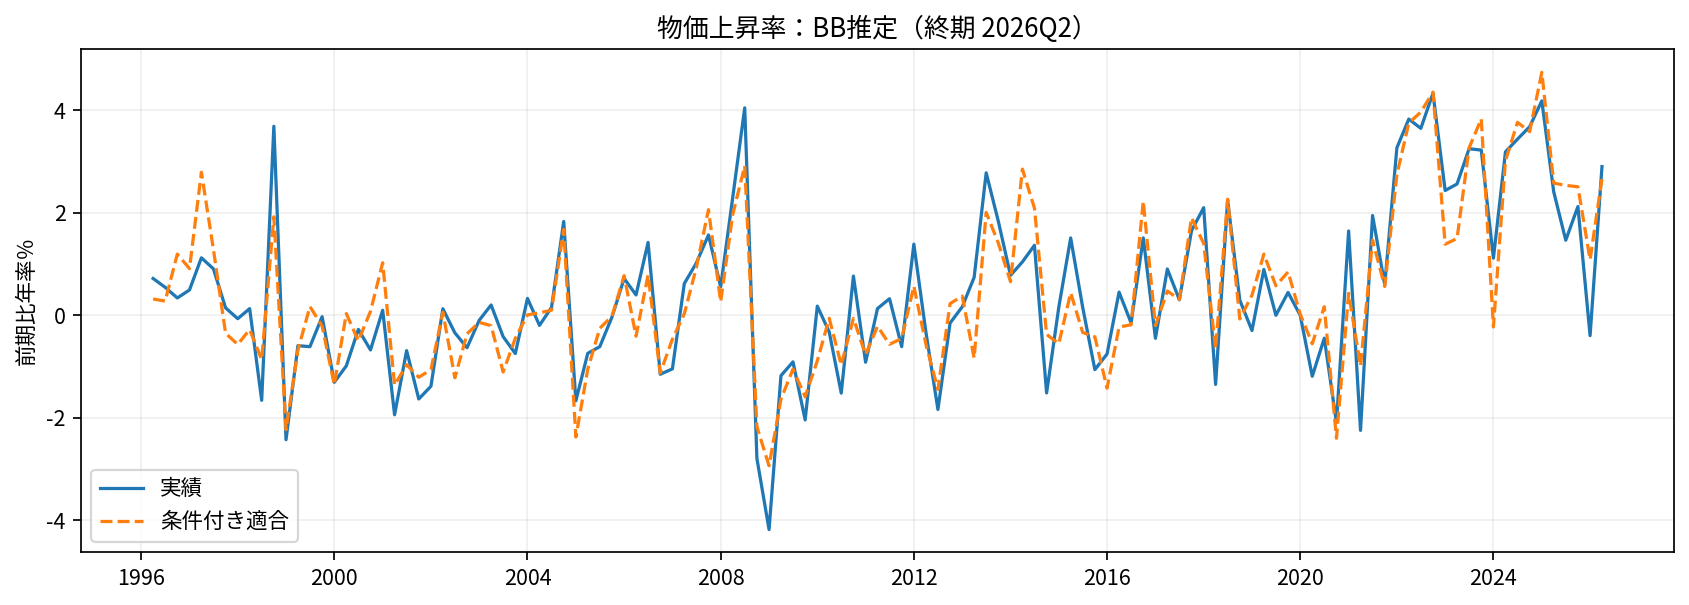

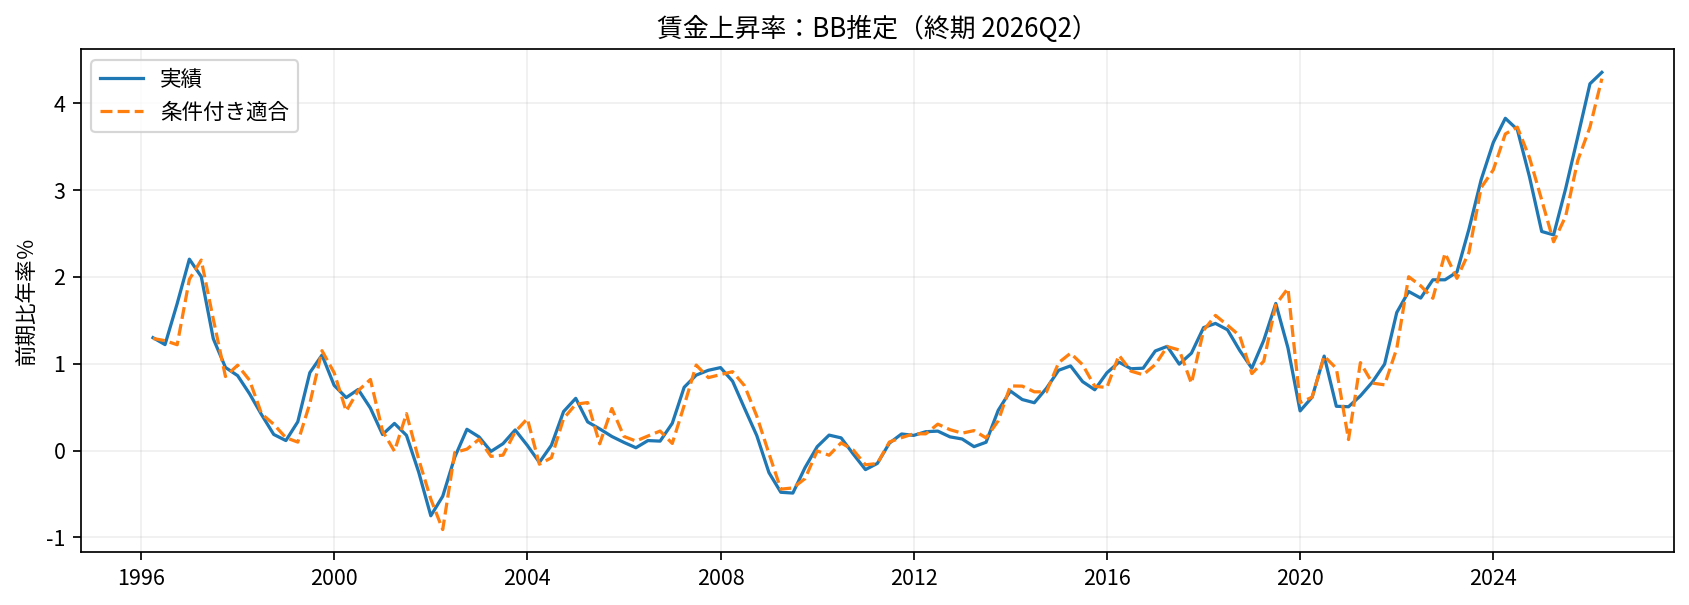

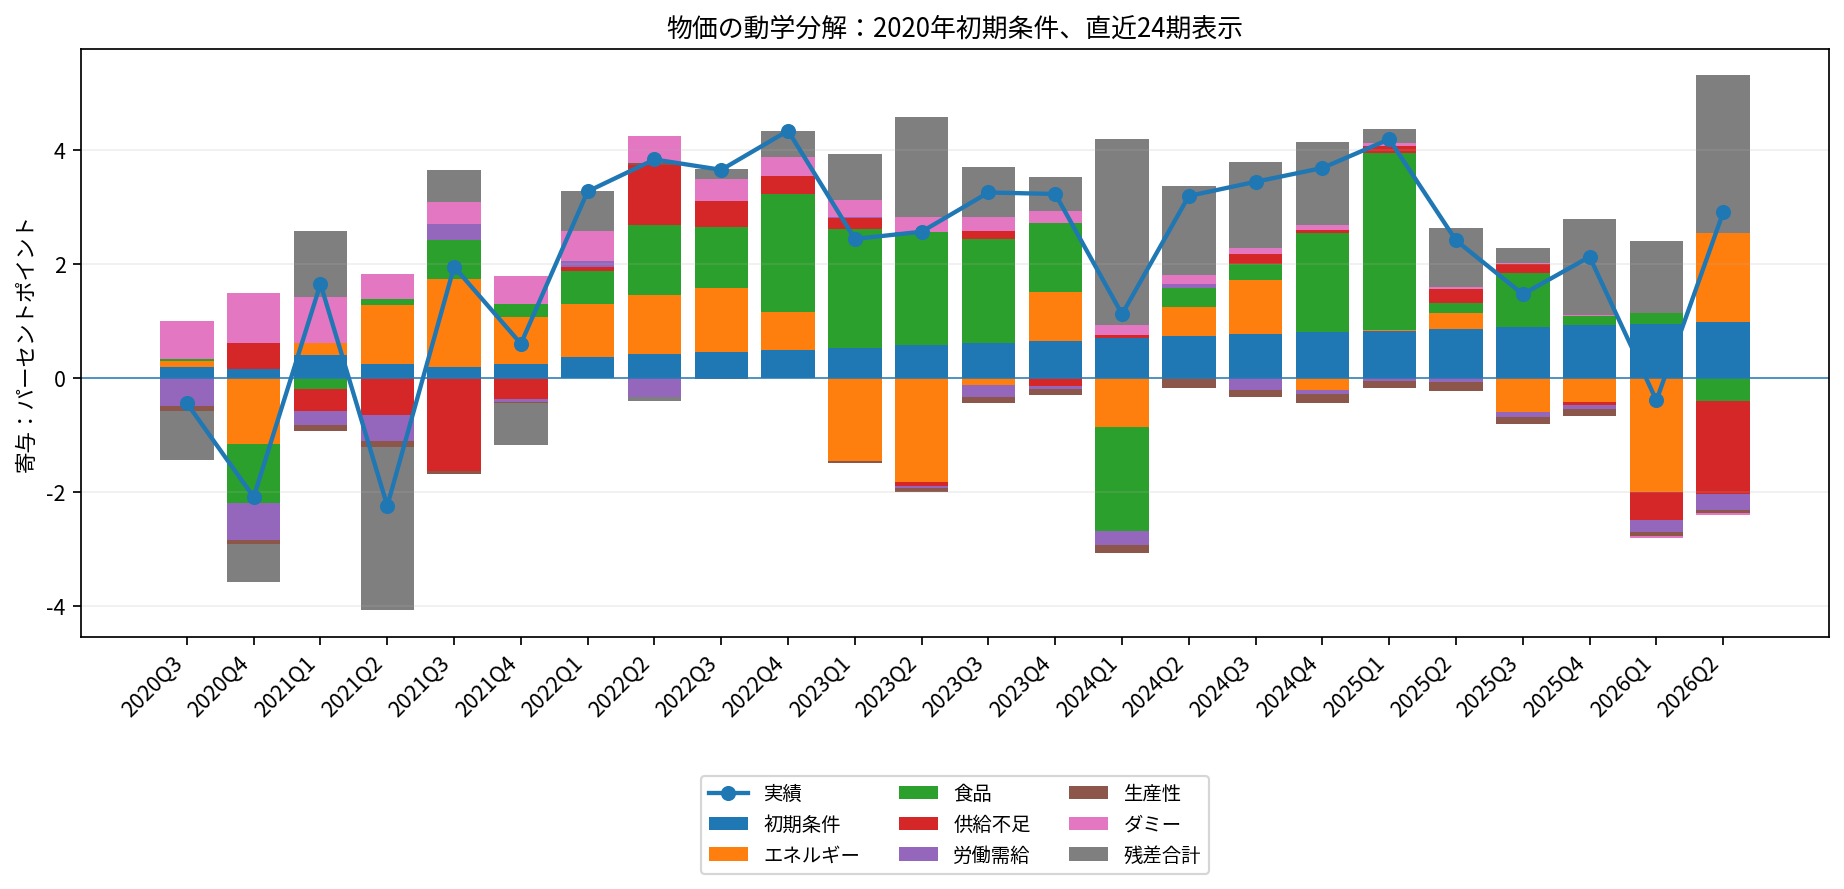

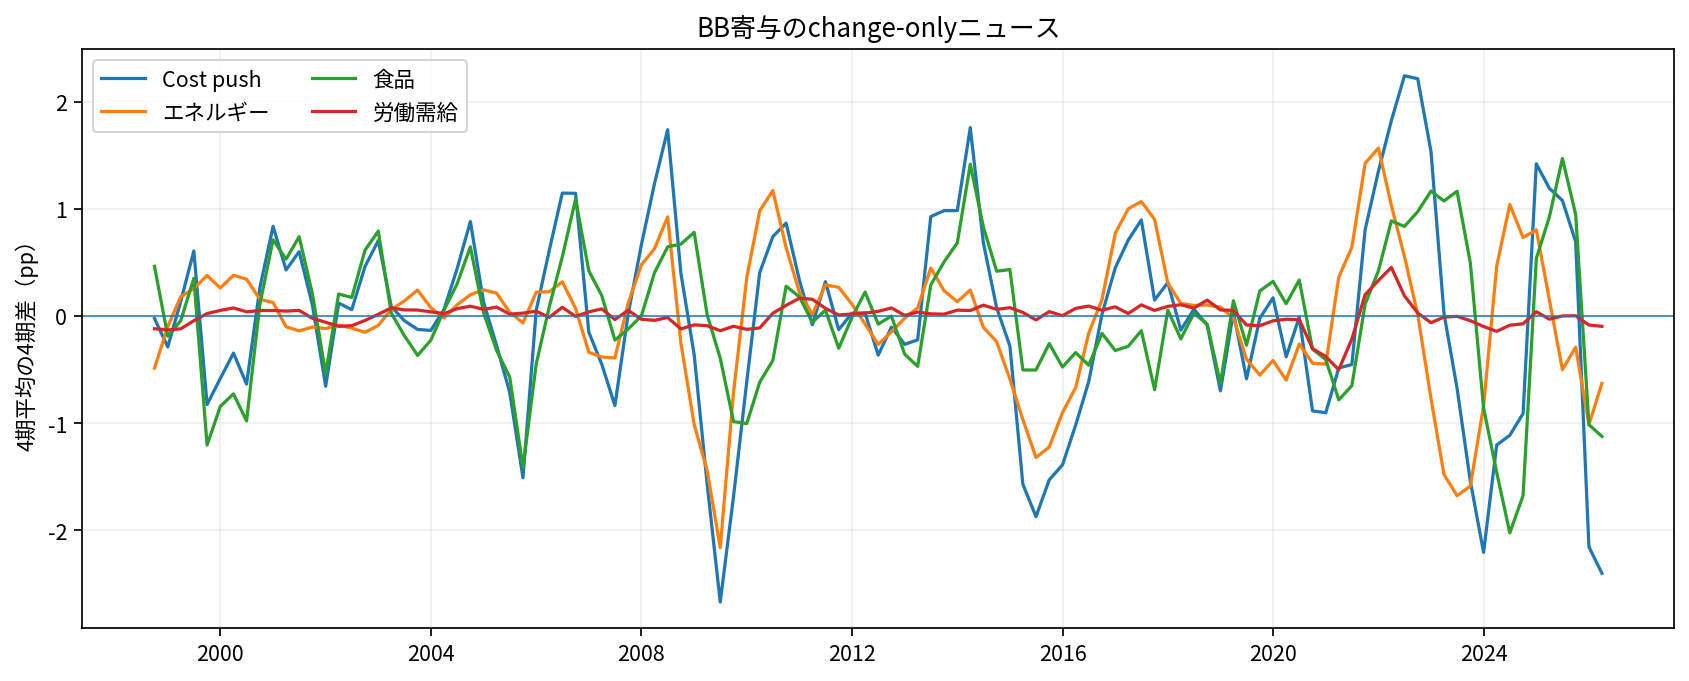

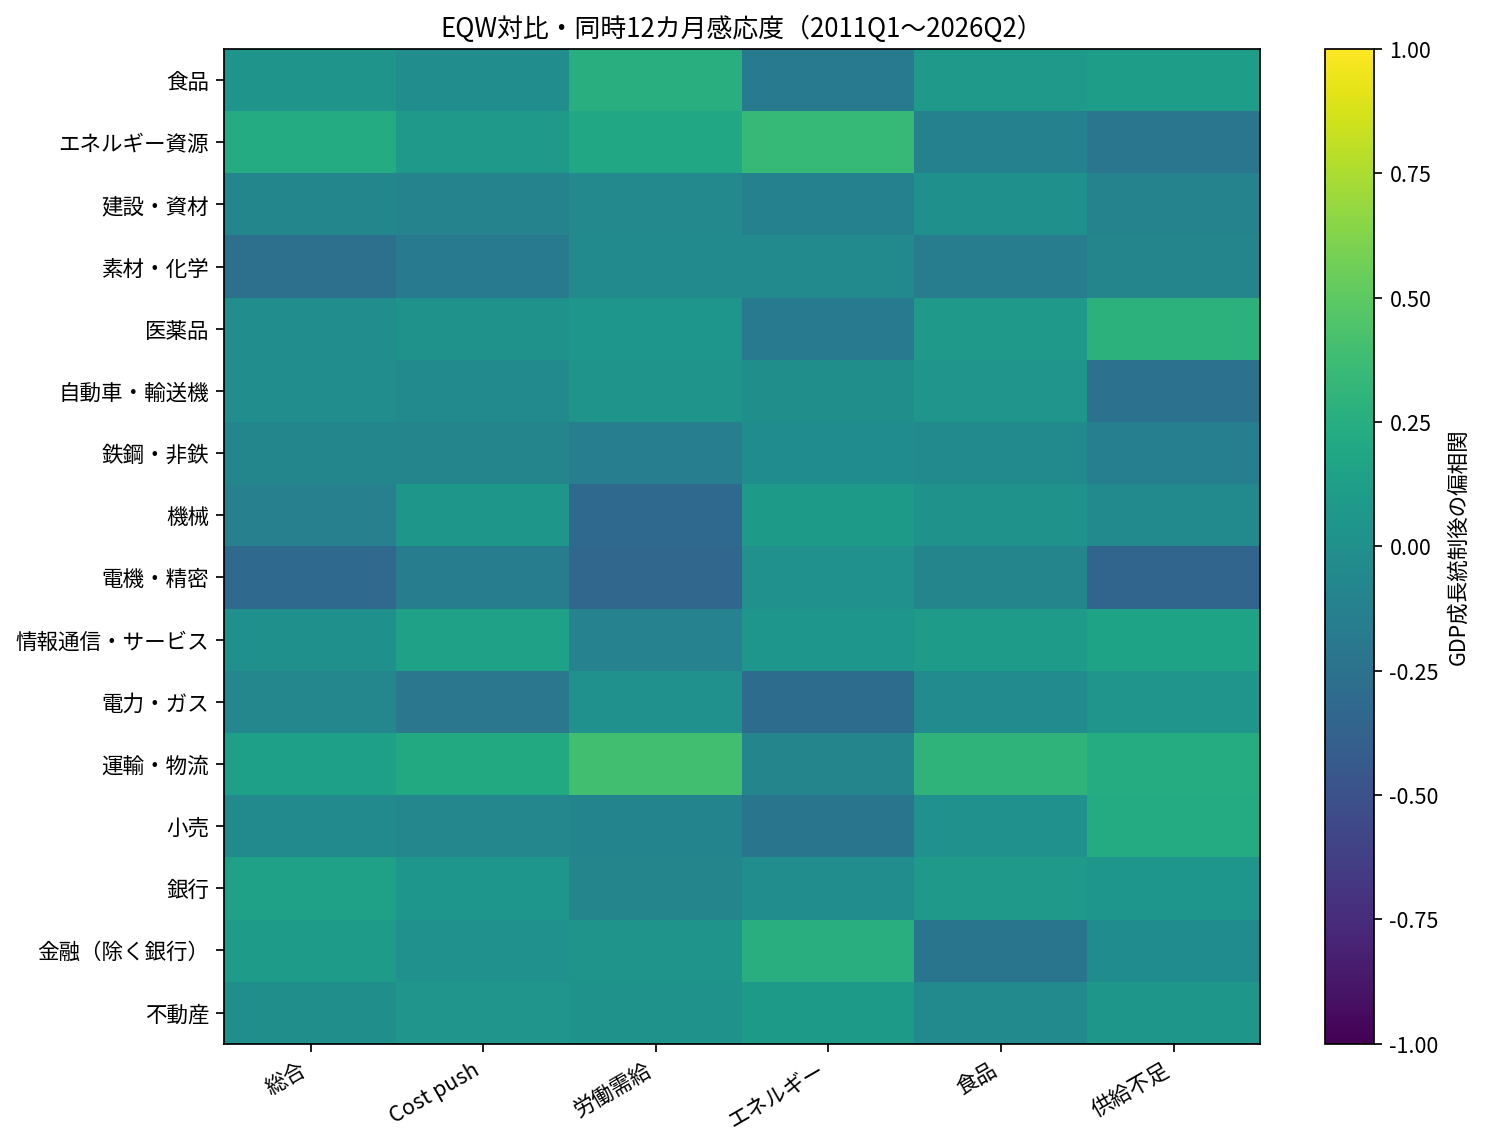

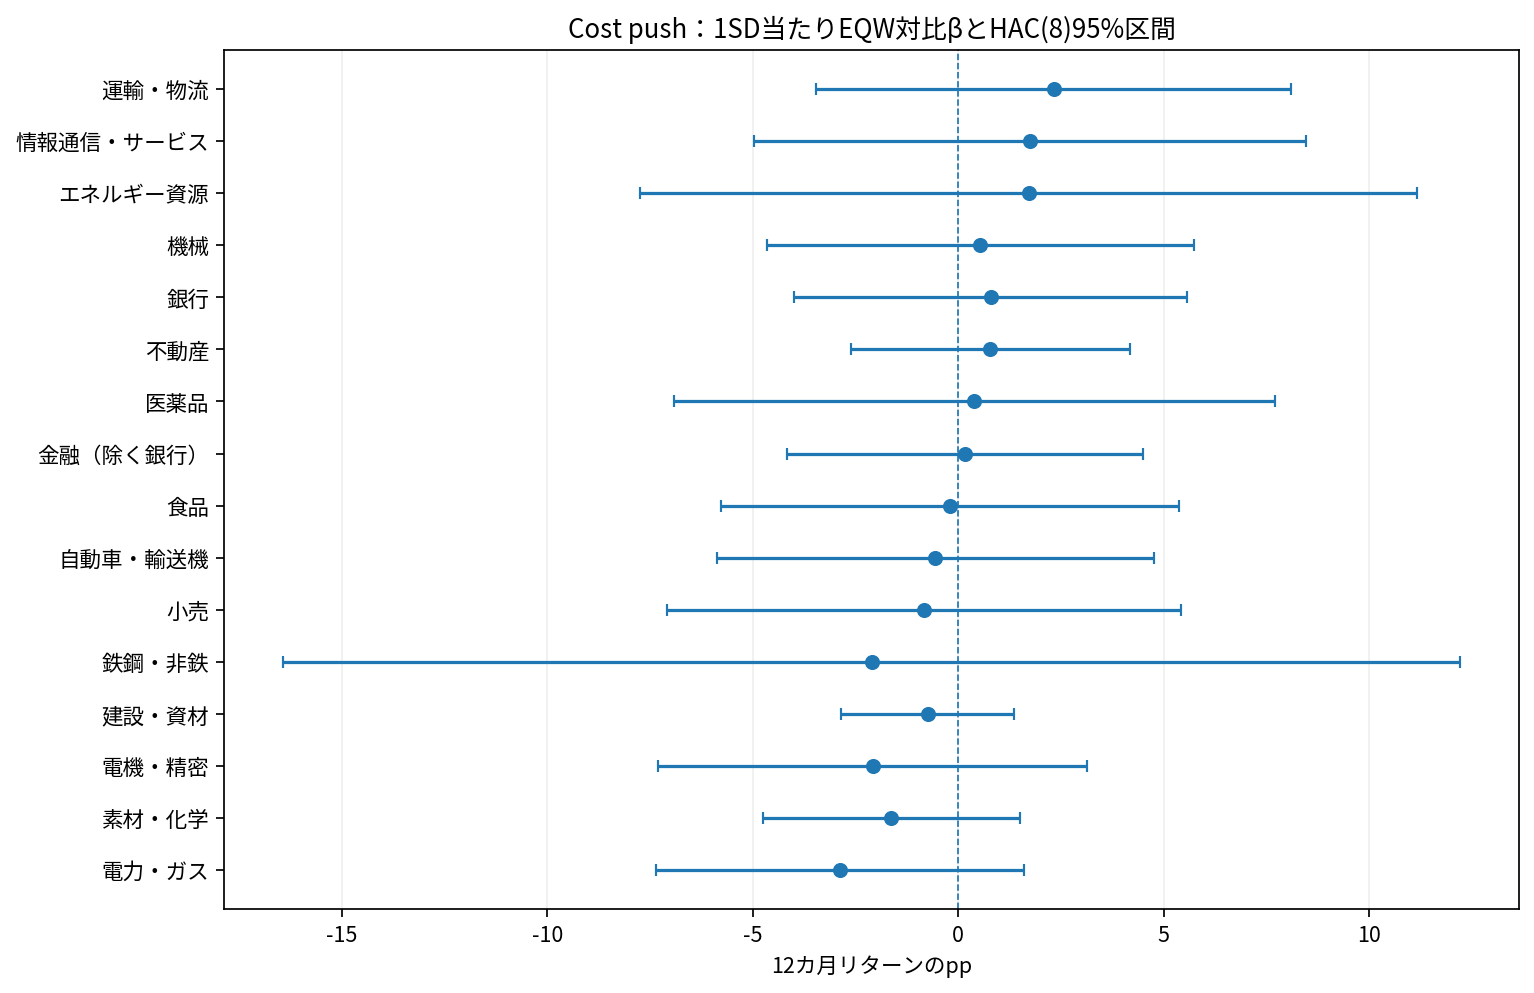

In [19]:
def save_plot(fig,name):
    fig.tight_layout()
    fig.savefig(FIG_DIR/name,dpi=155,bbox_inches="tight")
    plt.close(fig)
    display(DisplayImage(filename=str(FIG_DIR/name)))

labels={"gw":"賃金上昇率","gcpi":"物価上昇率","cf1":"短期期待（1年）","cf10":f"長期期待（{long_year}年）"}
for eq in ["gcpi","gw"]:
    f=model[eq]
    fig,ax=plt.subplots(figsize=(11,4))
    ax.plot(f["y"].index.to_timestamp(),f["y"],label="実績")
    ax.plot(f["fitted"].index.to_timestamp(),f["fitted"],label="条件付き適合",linestyle="--")
    ax.set(title=f"{labels[eq]}：BB推定（終期 {BB_END}）",ylabel="前期比年率％")
    ax.grid(alpha=.2);ax.legend()
    save_plot(fig,f"01_BB_fit_{eq}.png")
d=pandemic_hd["gcpi"].tail(24).copy()
groups={"initial_conditions":"初期条件","energy":"エネルギー","food":"食品",
        "shortage":"供給不足","labor":"労働需給","productivity":"生産性","covid":"ダミー","residuals":"残差合計"}
d["covid"]=d.covid_q2+d.covid_q3
d["residuals"]=d[[f"residual_{x}" for x in ENDOG]].sum(axis=1)
fig,ax=plt.subplots(figsize=(12,6));x=np.arange(len(d));pos=np.zeros(len(d));neg=np.zeros(len(d))
for col,label in groups.items():
    v=d[col].to_numpy()
    ax.bar(x,v,bottom=np.where(v>=0,pos,neg),label=label)
    pos+=np.maximum(v,0);neg+=np.minimum(v,0)
ax.plot(x,d.actual,marker="o",linewidth=2,label="実績")
ax.set_xticks(x,d.index.astype(str),rotation=45,ha="right")
ax.set(title="物価の動学分解：2020年初期条件、直近24期表示",ylabel="寄与：パーセントポイント")
ax.axhline(0,linewidth=.7);ax.grid(axis="y",alpha=.2)
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.22),ncol=3,fontsize=9)
save_plot(fig,"02_inflation_decomposition.png")
fig,ax=plt.subplots(figsize=(11,4.5))
for factor in ["news_cost_push","news_energy","news_food","news_labor"]:
    ax.plot(news.index.to_timestamp(),news[factor],label=factor_labels[factor])
ax.set(title="BB寄与のchange-onlyニュース",ylabel="4期平均の4期差（pp）")
ax.axhline(0,linewidth=.7);ax.grid(alpha=.2);ax.legend(ncol=2)
save_plot(fig,"03_news.png")
fig,ax=plt.subplots(figsize=(10,7.5))
im=ax.imshow(partial_table[FACTORS].to_numpy(),aspect="auto",vmin=-1,vmax=1)
ax.set_xticks(np.arange(len(FACTORS)),[factor_labels[f] for f in FACTORS],rotation=30,ha="right")
ax.set_yticks(np.arange(len(current_assets)),current_assets)
fig.colorbar(im,ax=ax,label="GDP成長統制後の偏相関")
ax.set_title(f"EQW対比・同時12カ月感応度（{primary_index.min()}～{primary_index.max()}）")
save_plot(fig,"04_EQW_partial_correlations.png")
cost=main_EQW.query("factor=='news_cost_push'").sort_values("partial_corr_growth")
fig,ax=plt.subplots(figsize=(10,6.5))
x=cost.beta_per_1sd.to_numpy()
err=np.vstack([np.maximum(0,x-cost.ci_low_1sd_hac8.to_numpy()),np.maximum(0,cost.ci_high_1sd_hac8.to_numpy()-x)])
ax.errorbar(x,np.arange(len(cost)),xerr=err,fmt="o",capsize=3)
ax.set_yticks(np.arange(len(cost)),cost.asset);ax.axvline(0,linestyle="--",linewidth=.8)
ax.set(title="Cost push：1SD当たりEQW対比βとHAC(8)95%区間",xlabel="12カ月リターンのpp")
ax.grid(axis="x",alpha=.2)
save_plot(fig,"05_cost_push_beta.png")
if not input_changes.empty:
    summary=input_changes.query("dataset=='model_input' and status=='revised'").groupby("series").difference.apply(lambda s:s.abs().max())
    if not summary.empty:
        fig,ax=plt.subplots(figsize=(9,4))
        ax.bar(summary.index,summary.values)
        ax.set(title="前回から改定されたBB入力の最大絶対差",ylabel="各系列の単位")
        ax.tick_params(axis="x",rotation=30);ax.grid(axis="y",alpha=.2)
        save_plot(fig,"06_model_revisions.png")

## 11．FT/PTの別方程式：既存の集計入力を保ったまま追加
既存の再構築関数から `gw_ft`、`gw_pt`、`weight_ft_lagged` を取り出す。
月給と時給の水準を直接平均せず、年率の成長率を集計する。

\[
g^L_t=a^L_0+\sum_{i=1}^4 a_i^L g^L_{t-i}
+\sum_{i=1}^4 b_i^L e^S_{t-i}
+\sum_{i=1}^4 c_i^L CU_{t-i}
+\sum_{i=1}^4 d_i^L(V/U)_{t-i}
+f^L prod_{t-1}+\delta^L_2D_{2020Q2,t}+\delta^L_3D_{2020Q3,t}+u^L_t
\]
\[
\sum_i a_i^L+\sum_i b_i^L=1,\quad L=FT,PT;\qquad
g_t=\omega_tg^{FT}_t+(1-\omega_t)g^{PT}_t.
\]

他方の賃金ラグ、別のFT/PT求人指標、部門別生産性は足さない。
FT/PTは毎月勤労の一般/パート区分であり、正社員/非正規雇用に置き換えない。

In [20]:
FTPT_DIR=RESULT_DIR/"ftpt";FTPT_FIG=FTPT_DIR/"figures"
FTPT_DIR.mkdir(exist_ok=True);FTPT_FIG.mkdir(exist_ok=True)
FTPT_EQ=["gw_ft","gw_pt","gcpi","cf10","cf1"]
FTPT_STATE=["gw_ft","gw_pt","gw","gcpi","cf10","cf1"] # gwは確率方程式でなく恒等式
FTPT_PARTS=["initial_conditions","energy","food","shortage","labor","productivity","covid_q2","covid_q3"]+[
    "residual_"+v for v in FTPT_EQ]
def ft_save(df,name,index=False):
    save_csv(df,name,index=index,folder=FTPT_DIR)

if FTPT_CFG["weight_path"]!="observed_lagged":
    raise ValueError("本版は観測された前期人数ウェイトを維持。別のウェイト方式は未実装です。")
dual_panel=panel.join(constructed_quarterly[["gw_ft","gw_pt","weight_ft_lagged"]],how="left")
wage_identity=dual_panel.gw_ft*dual_panel.weight_ft_lagged+dual_panel.gw_pt*(1-dual_panel.weight_ft_lagged)
pair=pd.concat([dual_panel.gw,wage_identity],axis=1).dropna()
check("ftpt_existing_aggregate_identity",np.allclose(pair.iloc[:,0],pair.iloc[:,1],atol=1e-12))
needed=pd.period_range(BB_START,str(BB_END),freq="Q")
check("ftpt_inputs_complete",dual_panel.loc[needed,FTPT_STATE+["weight_ft_lagged"]].notna().all().all())
weights=dual_panel.weight_ft_lagged.dropna()
check("ftpt_weight_bounds",weights.between(0,1,inclusive="neither").all())
ft_save(dual_panel,"bb_model_input.csv",index=True)
ft_save(dual_panel[["gw_ft","gw_pt","gw","weight_ft_lagged"]],"wage_components.csv",index=True)

def ftpt_specs(price_productivity=True,covid_dummies=True):
    base=equation_specs(price_productivity,covid_dummies)
    out={}
    for dep in ["gw_ft","gw_pt"]:
        wage=base["gw"]
        terms=tuple((dep if v=="gw" else v,l) for v,l in wage.terms)
        out[dep]=EquationSpec(dep,terms,(dep,"cf1"),True)
    out.update({k:base[k] for k in ["gcpi","cf10","cf1"]})
    return out

def fit_ftpt_system(data,start=BB_START,end=None,price_productivity=None,covid_dummies=True):
    end=str(BB_END) if end is None else str(end)
    prod=CFG["price_productivity"] if price_productivity is None else price_productivity
    blocks={k:design(data,sp,start,end) for k,sp in ftpt_specs(prod,covid_dummies).items()}
    common=None
    for y,X,R,r,sp in blocks.values():
        common=y.index if common is None else common.intersection(y.index)
    expected=pd.period_range(start,end,freq="Q")
    if not common.equals(expected):
        raise ValueError("FT/PT共通標本に欠損があります。黙って推定開始期や対象行を変えません。")
    return {k:restricted_fit(y.loc[common],X.loc[common],R,r,sp)
            for k,(y,X,R,r,sp) in blocks.items()}

dual_model=fit_ftpt_system(dual_panel)
dual_sums=coefficient_summaries(dual_model)
dual_hac=coefficient_summaries(dual_model,"hac")
dual_metrics=fit_metrics(dual_model)
dual_coefs=coefficients_frame(dual_model)
ft_save(dual_sums,"bb_coefficient_sums.csv")
ft_save(dual_hac,"bb_coefficient_sums_hac4.csv")
ft_save(dual_metrics,"bb_fit_metrics.csv")
ft_save(dual_coefs,"bb_coefficients.csv")
ft_save(pd.concat([bb_sums.assign(wage_system="aggregate_4eq"),dual_sums.assign(wage_system="FTPT_5eq")]),
        "coefficient_sums_with_aggregate.csv")
json_save({eq:{"beta":f["beta"].to_dict(),"terms":list(f["spec"].terms),
    "homogeneity_groups":list(f["spec"].homogeneity_groups),"constant":f["spec"].constant,
    "cov":f["cov"].tolist(),"cov_hac4":f["cov_hac"].tolist(),"n":f["n"]}
    for eq,f in dual_model.items()},FTPT_DIR/"estimated_model.json")
for eq,f in dual_model.items():
    check("ftpt_constraint_"+eq,f["restriction_error"]<1e-10,f["restriction_error"])
    check("ftpt_same_estimation_dates_"+eq,f["y"].index.equals(model["gcpi"]["y"].index))
    if f["homogeneity_p"]<.05:alert("ftpt_homogeneity_rejected",f"{eq}: p={f['homogeneity_p']:.6g}")
    ft_save(pd.DataFrame({"actual":f["y"],"fitted":f["fitted"],"residual":f["residual"]}),
            f"bb_fit_{eq}.csv",index=True)
# 賃金分割だけなら価格・期待式の入力X,yは同じ。係数も同じになることを必須検算。
for eq in ["gcpi","cf10","cf1"]:
    check("ftpt_unchanged_equation_"+eq,
          model[eq]["X"].equals(dual_model[eq]["X"]) and model[eq]["y"].equals(dual_model[eq]["y"])
          and np.allclose(model[eq]["beta"],dual_model[eq]["beta"],atol=1e-12))
w=dual_panel.loc[needed,"weight_ft_lagged"]
agg_fit=w*dual_model["gw_ft"]["fitted"]+(1-w)*dual_model["gw_pt"]["fitted"]
aggregate_fit_comparison=pd.DataFrame({
    "actual":dual_panel.loc[needed,"gw"],"aggregate_model_fitted":model["gw"]["fitted"],
    "FTPT_weighted_fitted":agg_fit})
aggregate_fit_comparison["aggregate_residual"]=aggregate_fit_comparison.actual-aggregate_fit_comparison.aggregate_model_fitted
aggregate_fit_comparison["FTPT_weighted_residual"]=aggregate_fit_comparison.actual-aggregate_fit_comparison.FTPT_weighted_fitted
ft_save(aggregate_fit_comparison,"aggregate_wage_fit_comparison.csv",index=True)
agg_comparison_metrics=pd.DataFrame([{
    "model":label,"n":len(needed),"rmse":float(np.sqrt(np.mean((aggregate_fit_comparison.actual-yhat)**2))),
    "r2_corr":float(np.corrcoef(aggregate_fit_comparison.actual,yhat)[0,1]**2)}
    for label,yhat in [("aggregate_4eq",model["gw"]["fitted"]),("FTPT_weighted_fit",agg_fit)]])
ft_save(agg_comparison_metrics,"aggregate_wage_fit_metrics.csv")
display(dual_sums.query("equation in ['gw_ft','gw_pt']")[["equation","group","coef_sum","p_sum","p_joint"]])
display(agg_comparison_metrics)

,equation,group,coef_sum,p_sum,p_joint
0,gw_ft,gw_ft,0.936948,7.932500e-46,5.799167e-50
1,gw_ft,cf1,0.063052,9.107588e-02,2.141329e-01
2,gw_ft,magpty,-0.017296,4.130322e-01,4.130322e-01
3,gw_ft,vu,-0.033892,5.848052e-01,4.314089e-01
4,gw_ft,diffcpicf,0.032751,3.945006e-01,6.789326e-01
5,gw_ft,dummyq2_2020,0.454973,1.081192e-01,1.081192e-01
6,gw_ft,dummyq3_2020,0.610546,7.278579e-02,7.278579e-02
7,gw_pt,gw_pt,0.567281,3.360633e-10,4.977553e-24
8,gw_pt,cf1,0.432719,6.459801e-07,8.377918e-06
9,gw_pt,magpty,0.054168,1.015517e-01,1.015517e-01


,model,n,rmse,r2_corr
0,aggregate_4eq,121,0.196269,0.963326
1,FTPT_weighted_fit,121,0.188081,0.966410


## 12．FT/PT係数差の検定：両式の残差相関を無視しない
「FTで非有意、PTで有意」だけでは、両者の係数が有意に異なるとはいえない。
同一標本の制約付きOLSの影響関数を2式で積み上げ、同期相関・4四半期までの系列相関を考慮した
HAC共分散から **PT−FTの係数和**を検定する。これは今回追加した漸近Wald検定（正規近似）で、
原論文の表3・4の個別p値とは別である。合成期待やSTLの生成誤差は含まない。

In [21]:
def restricted_influence(f):
    Z=linalg.null_space(f["R"])
    A=f["X"].to_numpy()@Z
    influence=f["residual"].to_numpy()[:,None]*(np.linalg.pinv(A).T@Z.T)
    return influence*np.sqrt(f["n"]/(f["n"]-f["k_free"]))

f_ft,f_pt=dual_model["gw_ft"],dual_model["gw_pt"]
IF_ft,IF_pt=restricted_influence(f_ft),restricted_influence(f_pt)

for label,f,IF in [("FT",f_ft,IF_ft),("PT",f_pt,IF_pt)]:
    implied=IF.T@IF
    for lag in range(1,5):
        cross=IF[lag:].T@IF[:-lag]
        implied+=(1-lag/5)*(cross+cross.T)
    check("ftpt_stacked_HAC_matches_single_equation_"+label,
          np.allclose(implied,f["cov_hac"],atol=1e-10,rtol=1e-8))

difference_rows=[]
for group in ["own_wage","cf1","vu","diffcpicf","magpty","dummyq2_2020","dummyq3_2020"]:
    load={}
    for dep,f in [("FT",f_ft),("PT",f_pt)]:
        variable=("gw_ft" if dep=="FT" else "gw_pt") if group=="own_wage" else group
        c=np.zeros(len(f["beta"]))
        for i,(v,l) in enumerate(f["spec"].terms):
            if v==variable:c[i]=1.
        load[dep]=c
    ft_value=float(load["FT"]@f_ft["beta"].to_numpy())
    pt_value=float(load["PT"]@f_pt["beta"].to_numpy())
    sc=IF_pt@load["PT"]-IF_ft@load["FT"]
    var=float(sc@sc)
    for lag in range(1,5):var+=2*(1-lag/5)*float(sc[lag:]@sc[:-lag])
    se=np.sqrt(max(var,0))
    diff=pt_value-ft_value
    z=diff/se if se>1e-14 else np.nan
    difference_rows.append({"group":group,"FT_coef_sum":ft_value,"PT_coef_sum":pt_value,
         "PT_minus_FT":diff,"difference_se_hac4":se,
         "p_difference_hac4_asymptotic":2*stats.norm.sf(abs(z)),
         "ci95_low":diff-1.959963984540054*se,"ci95_high":diff+1.959963984540054*se,
         "n":f_ft["n"],"covariance":"stacked restricted-OLS influence HAC4 with cross-equation correlation"})
wage_difference=pd.DataFrame(difference_rows)
ft_save(wage_difference,"wage_coefficient_difference_hac4.csv")
residual_corr=float(np.corrcoef(f_ft["residual"],f_pt["residual"])[0,1])
json_save({"FT_PT_residual_correlation":residual_corr,"uncertainty":"conditional on generated input series"},
          FTPT_DIR/"wage_residual_correlation.json")
# 作り直した原系列・期待を使うため、論文の値との同一性は要求しない。
paper_reference=pd.DataFrame([
 {"equation":"FT","own_wage":.778,"vu":-.070,"catchup":-.022,"cf1":.222,"productivity":.060},
 {"equation":"PT","own_wage":.177,"vu":.934,"catchup":-.202,"cf1":.823,"productivity":.061},
])
paper_reference["source"]="Nakamura et al. (2024) BOJ WP24-E-1 PDF10, Tables3-4; original sample to2023Q2, confidential composite expectations"
ft_save(paper_reference,"published_wage_coefficients_reference_only.csv")
period_estimates=[]
for label,end in [("preCOVID","2019Q4"),("old_end","2023Q2"),("current",str(BB_END))]:
    if pd.Period(end)>BB_END:continue
    mf=dual_model if end==str(BB_END) else fit_ftpt_system(dual_panel,end=end)
    st=coefficient_summaries(mf)
    period_estimates.append(st.loc[st.equation.isin(["gw_ft","gw_pt"])].assign(period=label))
ft_save(pd.concat(period_estimates,ignore_index=True),"wage_subsample_estimates.csv")
display(wage_difference[["group","FT_coef_sum","PT_coef_sum","PT_minus_FT","p_difference_hac4_asymptotic"]])

,group,FT_coef_sum,PT_coef_sum,PT_minus_FT,p_difference_hac4_asymptotic
0,own_wage,0.936948,0.567281,-0.369666,0.001543
1,cf1,0.063052,0.432719,0.369666,0.001543
2,vu,-0.033892,0.532334,0.566226,0.000182
3,diffcpicf,0.032751,0.020074,-0.012677,0.867882
4,magpty,-0.017296,0.054168,0.071464,0.025954
5,dummyq2_2020,0.454973,0.240716,-0.214257,0.548969
6,dummyq3_2020,0.610546,-0.517511,-1.128057,0.059042


## 13．5確率方程式＋集計恒等式の連立シミュレーション
状態は \((g^{FT},g^{PT},g,\pi,e^L,e^S)\)。`g`は恒等式であり、第6の確率方程式や
独立した「集計賃金ショック」を推定するわけではない。
各期に \(\omega_t\) が違うため、恒等式を含む当期行列を毎期更新する。
価格式の`gw[t−j]`には **その期t−jに対応するウェイト**で集計した賃金が入る。

歴史分解は実際の人数ウェイト経路を全反実仮想で同一に固定する。
したがって、各要因寄与の和は実績へ一致するが、雇用構成変化自体の因果的寄与は識別しない。
IRFは2019Q4のウェイトを固定した条件付き応答。凍結ウェイトの根を、
時変系全体の安定性の証明とはしない。

In [22]:
def compile_ftpt_system(fits):
    n=len(FTPT_STATE);p=8;q=4
    H=np.eye(n);AL=np.zeros((p,n,n));BL=np.zeros((q+1,n,len(EXOG)));c=np.zeros(n)
    def add_y(row,var,lag,value):
        col=FTPT_STATE.index(var)
        if lag==0:H[row,col]-=value
        else:AL[lag-1,row,col]+=value
    for eq,f in fits.items():
        row=FTPT_STATE.index(eq)
        if f["spec"].constant:c[row]=f["beta"]["_cons"]
        for (v,l) in f["spec"].terms:
            b=float(f["beta"][term_label(v,l)])
            if v=="diffcpicf":
                for j in range(4):add_y(row,"gcpi",l+j,b/4)
                add_y(row,"cf1",l+4,-b)
            elif v in FTPT_STATE:add_y(row,v,l,b)
            elif v in EXOG:BL[l,row,EXOG.index(v)]+=b
            else:raise KeyError(v)
    return {"H":H,"AL":AL,"BL":BL,"c":c,"p":p,"q":q,"_cache":{}}

def ftpt_matrices(comp,weight):
    weight=float(weight)
    if not (0<weight<1):raise ValueError("FT/PT集計ウェイトが(0,1)範囲外です")
    if weight not in comp["_cache"]:
        H=comp["H"].copy()
        g=FTPT_STATE.index("gw")
        H[g,FTPT_STATE.index("gw_ft")]=-weight
        H[g,FTPT_STATE.index("gw_pt")]=-(1-weight)
        invH=np.linalg.inv(H)
        A=np.einsum("ij,ljk->lik",invH,comp["AL"])
        B=np.einsum("ij,ljk->lik",invH,comp["BL"])
        comp["_cache"][weight]=(A,B,invH@comp["c"],invH)
    return comp["_cache"][weight]

def simulate_ftpt(comp,data,x,start,end,innovations=None,zero_history=False,constant=True,
                  weights=None):
    dates=pd.period_range(start,end,freq="Q")
    all_dates=pd.period_range(dates[0]-comp["p"],dates[-1],freq="Q")
    p,q=comp["p"],comp["q"];n=len(FTPT_STATE)
    y=np.zeros((len(all_dates),n))
    if not zero_history:
        y[:p]=data.reindex(all_dates[:p])[FTPT_STATE].to_numpy()
        if not np.isfinite(y[:p]).all():raise ValueError("FT/PT初期8四半期の内生履歴が不足")
    xv=x.reindex(all_dates)[EXOG].to_numpy()
    if not np.isfinite(xv[p-q:]).all():raise ValueError("外生入力/ラグに欠損")
    ww=(data.weight_ft_lagged if weights is None else weights).reindex(dates)
    if ww.isna().any():raise ValueError("FT/PT集計ウェイトが不足")
    u=np.zeros((len(dates),n))
    if innovations is not None:
        uu=innovations.reindex(dates)
        if not set(FTPT_EQ).issubset(uu.columns):raise ValueError("FT/PT残差の5列が必要")
        if uu[FTPT_EQ].isna().any().any():raise ValueError("FT/PT残差に欠損")
        for eq in FTPT_EQ:u[:,FTPT_STATE.index(eq)]=uu[eq]
        if "gw" in uu and not np.allclose(uu.gw,0):
            raise ValueError("集計gwは恒等式。独立した残差は入力できません")
    for j,t in enumerate(range(p,len(all_dates))):
        A,B,c,imp=ftpt_matrices(comp,ww.iloc[j])
        val=c.copy() if constant else np.zeros(n)
        val+=np.einsum("lij,lj->i",A,y[t-np.arange(1,p+1)])
        val+=np.einsum("lij,lj->i",B,xv[t-np.arange(q+1)])
        val+=imp@u[j]
        if not np.isfinite(val).all():raise FloatingPointError("FT/PTシミュレーションが発散")
        y[t]=val
    out=pd.DataFrame(y[p:],index=dates,columns=FTPT_STATE)
    identity=ww*out.gw_ft+(1-ww)*out.gw_pt
    if not np.allclose(out.gw,identity,atol=1e-9,rtol=1e-10):
        raise AssertionError("再帰計算でFT/PT集計恒等式が壊れています")
    return out

def ftpt_innovations(fits,data,start,end):
    dates=pd.period_range(start,end,freq="Q");out={}
    for eq,f in fits.items():
        y,X,*_=design(data,f["spec"],start,end)
        out[eq]=(y-X.reindex(columns=f["beta"].index)@f["beta"]).reindex(dates)
    result=pd.DataFrame(out,index=dates)
    if result.isna().any().any():raise ValueError("FT/PT残差を全期間で計算できません")
    return result

def ftpt_labor_entry(comp,leg):
    if leg not in ["FT","PT"]:raise ValueError(leg)
    cc={k:v for k,v in comp.items() if k!="_cache"}
    cc["BL"]=comp["BL"].copy();cc["_cache"]={}
    other="gw_pt" if leg=="FT" else "gw_ft"
    cc["BL"][:,FTPT_STATE.index(other),EXOG.index("vu")]=0.
    return cc

def ftpt_history(fits,data,start,end,mean_start="1990Q1",vu_reference=None,split_channels=True):
    comp=compile_ftpt_system(fits);dates=pd.period_range(start,end,freq="Q");anchor=dates[0]-1
    x=data[EXOG].copy();base=x.copy()
    means=data.loc[mean_start:str(anchor),["magpty","shortage"]].mean()
    base.loc[dates,["grpe","grpf"]]=0.
    base.loc[dates,"vu"]=float(data.loc[anchor,"vu"] if vu_reference is None else vu_reference)
    for v in ["magpty","shortage"]:base.loc[dates,v]=float(means[v])
    base.loc[dates,["dummyq2_2020","dummyq3_2020"]]=0.
    initial=simulate_ftpt(comp,data,base,start,end)
    parts={"initial_conditions":initial}
    groups={"energy":["grpe"],"food":["grpf"],"shortage":["shortage"],"labor":["vu"],
            "productivity":["magpty"],"covid_q2":["dummyq2_2020"],"covid_q3":["dummyq3_2020"]}
    for name,cols in groups.items():
        sc=base.copy();sc.loc[dates,cols]=x.loc[dates,cols]
        parts[name]=simulate_ftpt(comp,data,sc,start,end)-initial
    U=ftpt_innovations(fits,data,start,end)
    for eq in FTPT_EQ:
        u=U*0.;u[eq]=U[eq]
        parts["residual_"+eq]=simulate_ftpt(comp,data,base,start,end,u)-initial
    reconstructed=sum(parts.values())
    observed=data.loc[dates,FTPT_STATE]
    direct=simulate_ftpt(comp,data,x,start,end,U)
    noresid=simulate_ftpt(comp,data,x,start,end)
    error=float(np.max(np.abs(reconstructed.to_numpy()-observed.to_numpy())))
    direct_error=float(np.max(np.abs(direct.to_numpy()-observed.to_numpy())))
    if max(error,direct_error)>1e-8:
        raise AssertionError(f"FT/PT加法性または実績再現に失敗: {error}, {direct_error}")
    channels={}
    if split_channels:
        dx=pd.DataFrame(0.,index=data.index,columns=EXOG)
        dx.loc[dates,"vu"]=x.loc[dates,"vu"]-base.loc[dates,"vu"]
        for leg in ["FT","PT"]:
            channels[leg]=simulate_ftpt(ftpt_labor_entry(comp,leg),data,dx,start,end,
                          zero_history=True,constant=False)
        if not np.allclose(channels["FT"]+channels["PT"],parts["labor"],atol=1e-8):
            raise AssertionError("FT/PT労働需給伝播寄与の和が全体に一致しません")
    tables={}
    for eq in FTPT_STATE:
        t=pd.DataFrame({k:v[eq] for k,v in parts.items()},index=dates)
        t["actual"]=observed[eq];t["conditional_no_residual"]=noresid[eq];t["reconstructed"]=reconstructed[eq]
        if split_channels:
            t["labor_via_FT"]=channels["FT"][eq];t["labor_via_PT"]=channels["PT"][eq]
        tables[eq]=t
    metadata={"start":start,"end":end,"anchor":str(anchor),"mean_start":mean_start,
        "weight_path":"observed lagged employment weights identical in every counterfactual",
        "weight_exogeneity":"No employment composition equation; not a causal employment-share attribution",
        "additive_components":FTPT_PARTS,
        "auxiliary_nonadditive_columns":["actual","conditional_no_residual","reconstructed","labor_via_FT","labor_via_PT"],
        "max_reconstruction_error":error,"direct_simulation_error":direct_error,
        "relative_prices":"unchanged exogenous supplied relative price growth rates",
        "labor_channels":"artificial split of a common V/U input by wage-equation entry, full feedback retained; not independent shocks",
        "residuals":"5 equation innovations; no aggregate wage residual; not orthogonalized"}
    return tables,metadata

def ftpt_news(hd,gdp,expectation_source):
    # 既存6因子の作成関数を維持。2賃金式の残差は互換用の一時コピーだけで合算。
    compatible=hd.copy()
    compatible["residual_gw"]=hd.residual_gw_ft+hd.residual_gw_pt
    nw=make_news(compatible,gdp,expectation_source)
    if "labor_via_FT" in hd:
        nw["news_labor_ft"]=change_only(hd.labor_via_FT)
        nw["news_labor_pt"]=change_only(hd.labor_via_PT)
    nw["news_residual_gw_ft"]=change_only(hd.residual_gw_ft)
    nw["news_residual_gw_pt"]=change_only(hd.residual_gw_pt)
    nw["wage_system"]="FTPT_5equations_observed_lagged_weights"
    return nw

dual_history,dual_history_meta=ftpt_history(dual_model,dual_panel,NEWS_HISTORY_START,str(BB_END),NEWS_MEAN_START)
dual_pandemic,dual_pandemic_meta=ftpt_history(dual_model,dual_panel,"2020Q1",str(BB_END),BB_START)
dual_news_all=ftpt_news(dual_history["gcpi"],GDP,"FIRM_1_"+str(long_year))
dual_news=dual_news_all.dropna(subset=FACTORS+["news_growth"])
for eq in FTPT_STATE:
    ft_save(dual_history[eq],f"history_long_{eq}.csv",index=True)
    ft_save(dual_pandemic[eq],f"history_2020_{eq}.csv",index=True)
ft_save(dual_news_all,"news_all.csv",index=True)
ft_save(dual_news[FACTORS+["news_growth","news_labor_ft","news_labor_pt"]],"investment_news.csv",index=True)
json_save(dual_history_meta,FTPT_DIR/"history_metadata.json")
json_save(dual_pandemic_meta,FTPT_DIR/"history_2020_metadata.json")
check("ftpt_news_total_identity",np.allclose(dual_news.news_total,dual_news.news_reconstructed,atol=1e-8))
check("ftpt_news_group_identity",np.allclose(
      dual_news.news_total,dual_news.news_cost_push+dual_news.news_labor+dual_news.news_other,atol=1e-8))
check("ftpt_labor_news_channels_add",np.allclose(
      dual_news.news_labor_ft+dual_news.news_labor_pt,dual_news.news_labor,atol=1e-8))
last_dual=dual_pandemic["gcpi"].iloc[-1]
dual_last_residual=float(last_dual[[f"residual_{eq}" for eq in FTPT_EQ]].sum())
if abs(dual_last_residual)>1:
    alert("ftpt_large_dynamic_residual",f"最終期の物価への5式残差合計寄与={dual_last_residual:.4f}pp")
display(pd.DataFrame({"aggregate":pandemic_hd["gcpi"].iloc[-1],
                     "FTPT":dual_pandemic["gcpi"].iloc[-1]}).round(4))

,aggregate,FTPT
actual,2.9043,2.9043
conditional_no_residual,0.1440,0.2052
covid_q2,-0.0265,0.0177
covid_q3,-0.0101,0.0489
energy,1.5698,1.5723
food,-0.4027,-0.3784
initial_conditions,0.9769,0.5933
labor,-0.2837,-0.1906
labor_via_FT,NaN,0.0102
labor_via_PT,NaN,-0.2009


## 14．FT/PT別動学応答と集計版への縮退テスト
各外生ショックの定義・規格化は従来版を維持する。
FT/PTの波及は単なる係数和の加重平均でなく、期待・物価へのフィードバックを含む。
`labor_via_FT`/`labor_via_PT` は共通V/U入力が入る賃金式を1本ずつ切り分けた寄与で、
それぞれ独立に識別した需要ショックではない。

FT/PTに同じ賃金パラメータ・同じ初期値・固定ウェイトを与えたとき、
集計4方程式の応答に戻ることを合成テストで確認する。

In [23]:
def ftpt_frozen_roots(comp,w):
    A,B,c,imp=ftpt_matrices(comp,w);n=len(FTPT_STATE)
    companion=np.zeros((n*8,n*8))
    companion[:n]=np.concatenate(list(A),axis=1)
    companion[n:,:-n]=np.eye(n*7)
    roots=np.linalg.eigvals(companion)
    return {"weight_ft":float(w),"spectral_radius":float(np.abs(roots).max()),
            "roots_above_one":int((np.abs(roots)>1+1e-6).sum()),
            "unit_roots":int((np.abs(roots-1)<1e-6).sum())}

dual_comp=compile_ftpt_system(dual_model)
irf_anchor=pd.Period(FTPT_CFG["irf_weight_anchor"],freq="Q")
if irf_anchor not in dual_panel.index or pd.isna(dual_panel.loc[irf_anchor,"weight_ft_lagged"]):
    raise ValueError("IRF基準期の人数ウェイトが取得できません")
w_anchor=float(dual_panel.loc[irf_anchor,"weight_ft_lagged"])
w_latest=float(dual_panel.loc[BB_END,"weight_ft_lagged"])
frozen_diagnostics=pd.DataFrame([dict(quarter=str(q),**ftpt_frozen_roots(dual_comp,float(w)))
    for q,w in dual_panel.loc[needed,"weight_ft_lagged"].items()])
ft_save(frozen_diagnostics,"frozen_weight_roots.csv")
if frozen_diagnostics.roots_above_one.max()>0:
    alert("ftpt_frozen_weight_unstable_roots","固定ウェイト時の一部の根が1を超えます。時変系の長期外挿に注意。")
json_save({"weight_anchor":str(irf_anchor),"anchor_weight_ft":w_anchor,"latest_weight_ft":w_latest,
           "root_diagnostic":"frozen-coefficient roots only; not a proof of time-varying system stability",
           "max_frozen_spectral_radius":float(frozen_diagnostics.spectral_radius.max())},
          FTPT_DIR/"stability.json")

def ftpt_irfs(fits,data):
    comp=compile_ftpt_system(fits);horizon=CFG["irf_horizon"]
    dates=pd.period_range("2020Q1",periods=horizon+1,freq="Q")
    idx=pd.period_range(dates[0]-8,dates[-1],freq="Q")
    empty=pd.DataFrame(0.,index=idx,columns=FTPT_STATE+["weight_ft_lagged"])
    records=[]
    experiments=[("energy_pulse","grpe","pulse"),("food_pulse","grpf","pulse"),
                 ("shortage_pulse","shortage","pulse"),("labor_step","vu","step"),("shortage_step","shortage","step")]
    for wlabel,w in [("anchor_"+str(irf_anchor),w_anchor),("latest_"+str(BB_END),w_latest)]:
        weightpath=pd.Series(w,index=idx)
        for name,v,shape in experiments:
            sd=float(data.loc["2020Q1":str(BB_END),v].std(ddof=1))
            for unit,amplitude in [("one_sd",sd),("one_unit",1.)]:
                x=pd.DataFrame(0.,index=idx,columns=EXOG)
                x.loc[dates if shape=="step" else dates[:1],v]=amplitude
                entries=[("both",comp)]
                if v=="vu":entries += [(leg,ftpt_labor_entry(comp,leg)) for leg in ["FT","PT"]]
                for entry,cc in entries:
                    yy=simulate_ftpt(cc,empty,x,str(dates[0]),str(dates[-1]),
                                     zero_history=True,constant=False,weights=weightpath)
                    yy.index=pd.Index(range(horizon+1),name="horizon")
                    rec=yy.reset_index().assign(shock=name,unit=unit,amplitude=amplitude,
                          weight_reference=wlabel,weight_ft=w,entry_channel=entry)
                    records.append(rec)
    return pd.concat(records,ignore_index=True)
dual_irfs=ftpt_irfs(dual_model,dual_panel)
ft_save(dual_irfs,"irfs.csv")

# 各式・恒等式・残差合計・FT/PT由来寄与の加法性を全6出力で確認。
for collection,label in [(dual_history,"long"),(dual_pandemic,"pandemic")]:
    for eq,hd in collection.items():
        check(f"ftpt_{label}_additivity_{eq}",np.allclose(hd[FTPT_PARTS].sum(axis=1),hd.actual,atol=1e-8))
        check(f"ftpt_{label}_labor_split_{eq}",np.allclose(hd.labor,hd.labor_via_FT+hd.labor_via_PT,atol=1e-8))
    ww=dual_panel.loc[collection["gw"].index,"weight_ft_lagged"]
    for component in FTPT_PARTS+["actual","conditional_no_residual","labor_via_FT","labor_via_PT"]:
        check(f"ftpt_{label}_weighted_component_{component}",
              np.allclose(collection["gw"][component],
                 ww*collection["gw_ft"][component]+(1-ww)*collection["gw_pt"][component],atol=1e-8))
for ref in dual_irfs.weight_reference.unique():
    for unit in ["one_sd","one_unit"]:
        d=dual_irfs.query("weight_reference==@ref and unit==@unit and shock=='labor_step'")
        a=d.query("entry_channel=='both'").set_index("horizon")
        b=d.query("entry_channel=='FT'").set_index("horizon")
        c=d.query("entry_channel=='PT'").set_index("horizon")
        check(f"ftpt_irf_split_{ref}_{unit}",np.allclose(a[FTPT_STATE],b[FTPT_STATE]+c[FTPT_STATE],atol=1e-10))

# 合成条件で集計モデルへ縮退。実データを合成値へ置き換えない。
identical={k:v for k,v in model.items() if k!="gw"}
for dep in ["gw_ft","gw_pt"]:
    original=model["gw"];f=dict(original)
    terms=tuple((dep if v=="gw" else v,l) for v,l in original["spec"].terms)
    f["spec"]=EquationSpec(dep,terms,(dep,"cf1"),True)
    labels=[term_label(v,l) for v,l in terms]+["_cons"]
    f["beta"]=pd.Series(original["beta"].to_numpy(),index=labels)
    identical[dep]=f
cc=compile_ftpt_system(identical)
legacy_irf=irfs.copy()
horizon=CFG["irf_horizon"];dates=pd.period_range("2020Q1",periods=horizon+1,freq="Q")
idx=pd.period_range(dates[0]-8,dates[-1],freq="Q")
synthetic=pd.DataFrame(0.,index=idx,columns=FTPT_STATE+["weight_ft_lagged"])
for shock,var,shape in [("energy_pulse","grpe","pulse"),("food_pulse","grpf","pulse"),
                        ("shortage_pulse","shortage","pulse"),("labor_step","vu","step")]:
    x=pd.DataFrame(0.,index=idx,columns=EXOG)
    x.loc[dates if shape=="step" else dates[:1],var]=1.
    y=simulate_ftpt(cc,synthetic,x,str(dates[0]),str(dates[-1]),zero_history=True,
                  constant=False,weights=pd.Series(w_anchor,index=idx))
    target=legacy_irf.query("shock==@shock and unit=='one_unit'").sort_values("horizon")
    check("ftpt_collapses_to_aggregate_"+shock,np.allclose(y[ENDOG].to_numpy(),target[ENDOG].to_numpy(),atol=1e-9))
anchor_label="anchor_"+str(irf_anchor)
display(dual_irfs.query("shock=='labor_step' and unit=='one_sd' and entry_channel=='both' and weight_reference==@anchor_label")[["horizon","gw_ft","gw_pt","gw","gcpi"]].iloc[[0,1,4,8,16,20]])

,horizon,gw_ft,gw_pt,gw,gcpi
126,0,0.000000,0.000000,0.000000,0.000000
127,1,0.168510,-0.438664,-0.022235,-0.035216
130,4,-0.000028,-0.071219,-0.022393,0.321507
134,8,0.054323,0.197284,0.099235,0.147983
142,16,-0.009743,0.149068,0.040148,0.041897
146,20,-0.032003,0.146031,0.023927,0.025299


## 15．FT/PT経由のNewsOnlyと資産感応度
既存の6因子は定義を変更しない。集計版とFT/PT版は、同じ資産・GDP統制・観測日で比較する。
**総合ニュースは物価実績から作るため不変**。変わるのは要因別の動学寄与である。
追加のFT/PT経路ニュースは労働需給寄与を入力経路別に分けたもので、賃金式残差やsurvey surpriseではない。
主6因子のBH補正は96仮説/評価パネル、追加2経路は別の32仮説/パネルとして記録する。

In [24]:
dual_news_assets=dual_news.loc[news_assets.index.min():ASSET_END].copy()
check("ftpt_same_news_dates_as_aggregate",dual_news_assets.index.equals(news_assets.index))
dual_main,dual_joint,dual_states,dual_asset_coverage=analyse_assets(
    assets,dual_news_assets,model_name="FTPT_"+CFG["expectations"])
ft_save(dual_joint,"asset_sensitivity_joint.csv")
ft_save(dual_states,"asset_conditional_states.csv")
ft_save(dual_asset_coverage,"asset_coverage.csv")
if RUN_BOOTSTRAP:
    dual_boot,dual_boot_accept=bootstrap_asset_panels(assets,dual_news_assets,reps=BOOTSTRAP_MAIN_REPS,length=8)
    if not dual_boot.empty:
        dual_main=dual_main.merge(dual_boot,on=["return_kind","factor","asset","n"],how="left",validate="one_to_one")
    ft_save(dual_boot,"asset_bootstrap.csv");ft_save(dual_boot_accept,"asset_bootstrap_acceptance.csv")
else:dual_boot=pd.DataFrame()
ft_save(dual_main,"asset_sensitivity_main.csv")
dual_EQW=dual_main.query("return_kind=='active_EQW'").copy()
dual_partial=dual_EQW.pivot(index="asset",columns="factor",values="partial_corr_growth").reindex(current_assets)
ft_save(dual_partial,"partial_correlations_EQW.csv",index=True)
comparison=sensitivity_diff(main,dual_main).rename(columns={
    c:c.replace("_previous","_aggregate").replace("_current","_ftpt").replace("previous_sd","aggregate_sd")
    for c in sensitivity_diff(main,dual_main).columns})
ft_save(comparison,"aggregate_vs_FTPT_asset_sensitivity.csv")
keys=["return_kind","asset","factor"]
z=main[keys+["n","start","end"]].merge(dual_main[keys+["n","start","end"]],on=keys,suffixes=("_agg","_ftpt"),validate="one_to_one")
check("ftpt_same_asset_periods",all((z[c+"_agg"]==z[c+"_ftpt"]).all() for c in ["n","start","end"]))
q1=main.query("factor=='news_total'").set_index(keys)
q2=dual_main.query("factor=='news_total'").set_index(keys)
check("ftpt_total_news_sensitivity_unchanged",np.allclose(q1.beta_per_1pp,q2.beta_per_1pp,atol=1e-9))
news_comparison=[]
for f in FACTORS:
    d=pd.DataFrame({"aggregate":news_assets[f],"FTPT":dual_news_assets[f]}).loc[primary_index].dropna()
    news_comparison.append({"factor":f,"n":len(d),"correlation":d.corr().iloc[0,1],
         "aggregate_sd":d['aggregate'].std(ddof=1),"FTPT_sd":d['FTPT'].std(ddof=1),
         "rmse":np.sqrt(np.mean((d['FTPT']-d['aggregate'])**2))})
ft_save(pd.DataFrame(news_comparison),"aggregate_vs_FTPT_news_comparison.csv")

# FT/PT起点の労働需給寄与による補助分析。成長統制・HACは主回帰と同じ。
def analyse_ftpt_channels(asset_data,nw):
    ret=asset_data["returns12"];rows=[]
    panels={"level_return":ret[current_assets],
            "active_EQW":ret[current_assets].sub(ret.EQW_TR,axis=0),
            "active_TOPIX_screened":ret[current_assets].sub(ret[BENCHMARK_COLUMN],axis=0)}
    factors=["news_labor_ft","news_labor_pt"]
    for kind,Y in panels.items():
        refdates=pd.PeriodIndex(sample_dates[kind],freq="Q")
        for asset in current_assets:
            d=pd.concat([Y[asset].rename("y"),nw[factors+["news_growth"]]],axis=1).reindex(refdates).dropna()
            if len(d)<MIN_QUARTERS:continue
            for factor in factors:
                X=np.column_stack([np.ones(len(d)),d[factor],d.news_growth])
                fit=ols_hac(d.y,X,8);sd=float(d[factor].std(ddof=1))
                rows.append({"return_kind":kind,"asset":asset,"factor":factor,"n":len(d),
                   "partial_corr_growth":partial_corr(d.y,d[factor],X[:,[0,2]]),
                   "beta_per_1pp":fit["beta"][1],"beta_per_1sd":fit["beta"][1]*sd,
                   "news_sd_pp":sd,"p_hac8":fit["p"][1],
                   "ci95_low_1sd_hac8":fit["low"][1]*sd,"ci95_high_1sd_hac8":fit["high"][1]*sd})
    r=pd.DataFrame(rows)
    if not r.empty:
        r["q_bh_32_per_panel"]=r.groupby("return_kind")["p_hac8"].transform(bh_adjust)
        r["q_bh_16_within_factor"]=r.groupby(["return_kind","factor"])["p_hac8"].transform(bh_adjust)
    return r
dual_channels=analyse_ftpt_channels(assets,dual_news_assets)
ft_save(dual_channels,"asset_sensitivity_labor_FT_PT_channels.csv")

# 日本価格仕様への変更とFT/PT分割を混同しないため、両モデルで同じ価格除外仕様も比較。
dual_robust=[]
if RUN_ROBUSTNESS:
    for label,prod,fitend in [
        ("FTPT_price_no_productivity",False,str(BB_END)),
        ("FTPT_preCOVID_coefficients",CFG["price_productivity"],min(str(BB_END),"2019Q4"))]:
        fit=fit_ftpt_system(dual_panel,end=fitend,price_productivity=prod)
        hd,_=ftpt_history(fit,dual_panel,NEWS_HISTORY_START,str(BB_END),NEWS_MEAN_START,split_channels=False)
        nw=ftpt_news(hd["gcpi"],GDP,"FIRM_1_"+str(long_year)).dropna(subset=FACTORS+["news_growth"])
        nw=nw.loc[news_assets.index.min():ASSET_END]
        am,_,_,_=analyse_assets(assets,nw,model_name=label)
        dual_robust.append(am)
        if label=="FTPT_price_no_productivity":
            ft_save(coefficient_summaries(fit),"price_no_productivity_coefficients.csv")
    for label,nw,nmin in [
        ("FTPT_exclude_latest_two",dual_news_assets.loc[:ASSET_END-2],MIN_QUARTERS),
        ("nonoverlap_FTPT_Q4",dual_news_assets.loc[dual_news_assets.index.quarter==4],10)]:
        am,_,_,_=analyse_assets(assets,nw,model_name="FTPT",sample_name=label,min_n=nmin)
        dual_robust.append(am)
    ft_save(pd.concat(dual_robust,ignore_index=True),"asset_sensitivity_robustness.csv")
display(dual_EQW.query("factor=='news_labor'")[["asset","partial_corr_growth","beta_per_1sd","p_hac8","q_bh_global_hac8"]])

,asset,partial_corr_growth,beta_per_1sd,p_hac8,q_bh_global_hac8
98,食品,0.313505,4.038263,0.009833,0.225635
104,エネルギー資源,-0.131670,-3.109121,0.595674,0.992705
110,建設・資材,0.029320,0.228076,0.828154,0.992705
116,素材・化学,0.023671,0.260104,0.892877,0.992705
122,医薬品,0.030017,0.487182,0.843199,0.992705
128,自動車・輸送機,0.096698,1.288054,0.599802,0.992705
134,鉄鋼・非鉄,-0.259245,-7.124433,0.193702,0.992705
140,機械,-0.249088,-2.642141,0.135125,0.987518
146,電機・精密,-0.394692,-5.740721,0.023297,0.319508
152,情報通信・サービス,-0.116192,-1.594024,0.587127,0.992705


## 16．FT/PT版の月次改定管理
集計版の既存の更新比較は保持し、FT/PT版を別に追跡する。
前回のFT/PT版と設定・資産集合が同じ場合だけ、
①原系列・過去値改定、②BB推定標本の追加、③資産価格改定、④資産標本の追加を順に比較する。
設定を変えた場合は「月次データだけの変化」として扱わず、比較をスキップした理由を記録する。

In [25]:
ftpt_previous_status="first_FTPT_run"
ftpt_revision_rows=pd.DataFrame()
if PREVIOUS_DIR is not None and (PREVIOUS_DIR/"results/ftpt/bb_model_input.csv").exists():
    pf=PREVIOUS_DIR/"results/ftpt"
    revs=[data_revision_table(qread(pf/"bb_model_input.csv"),dual_panel,"FTPT_model_input"),
          data_revision_table(qread(pf/"news_all.csv"),dual_news_all,"FTPT_news")]
    ftpt_revision_rows=pd.concat(revs,ignore_index=True)
    ft_save(ftpt_revision_rows,"revisions_detail.csv")
    prev_main=pd.read_csv(pf/"asset_sensitivity_main.csv")
    matched_method=(PREVIOUS.get("ftpt_method_config")==FTPT_CFG
             and PREVIOUS.get("method_config")==CFG and PREVIOUS.get("bb_start")==BB_START
             and PREVIOUS.get("news_history_start")==NEWS_HISTORY_START
             and PREVIOUS.get("news_mean_start")==NEWS_MEAN_START
             and PREVIOUS.get("assets")==current_assets
             and PREVIOUS.get("asset_input_kind")==ASSET_INPUT_KIND
             and PREVIOUS.get("max_abs_monthly_return")==MAX_ABS_MONTHLY_RETURN)
    pe=pd.Period(PREVIOUS["bb_end"]);pae=pd.Period(PREVIOUS["asset_end"])
    if matched_method and pe<=BB_END and pae<=ASSET_END:
        pf_new=fit_ftpt_system(dual_panel,end=str(pe))
        before=pd.read_csv(pf/"bb_coefficients.csv")
        middle=coefficients_frame(pf_new)
        z=before.merge(middle,on=["equation","term"],suffixes=("_previous","_revised_old_sample"))
        z=z.merge(dual_coefs.rename(columns={"coefficient":"coefficient_current"}),on=["equation","term"])
        z["data_revision_effect"]=z.coefficient_revised_old_sample-z.coefficient_previous
        z["new_BB_observation_effect"]=z.coefficient_current-z.coefficient_revised_old_sample
        z["total_change"]=z.coefficient_current-z.coefficient_previous
        check("ftpt_monthly_coef_telescopes",np.allclose(
             z.data_revision_effect+z.new_BB_observation_effect,z.total_change,atol=1e-10))
        ft_save(z,"bb_coefficient_change_attribution.csv")
        ph,_=ftpt_history(pf_new,dual_panel,NEWS_HISTORY_START,str(BB_END),NEWS_MEAN_START)
        pn=ftpt_news(ph["gcpi"],GDP,"FIRM_1_"+str(long_year)).dropna(subset=FACTORS+["news_growth"])
        oldassets=assets.copy();oldassets["returns12"]=qread(PREVIOUS_DIR/"results/asset_returns12.csv")
        first=min(pd.Period(x) for dates in PREVIOUS["asset_sample_dates"].values() for x in dates)
        with use_end(str(pae)):
            r1,*_=analyse_assets(oldassets,pn.loc[first:pae],model_name="FTPT_revised_oldfit")
            r2,*_=analyse_assets(oldassets,dual_news.loc[first:pae],model_name="FTPT_newfit_oldassets")
            r3,*_=analyse_assets(assets,dual_news.loc[first:pae],model_name="FTPT_revised_assets")
        sequence=[("previous",prev_main),("data_revision",r1),("BB_extension",r2),
                  ("asset_revision",r3),("asset_extension",dual_main)]
        pieces=[]
        for (a,x),(b,y) in zip(sequence[:-1],sequence[1:]):
            d=sensitivity_diff(x,y);d.insert(0,"step",a+" -> "+b);pieces.append(d)
        ft_save(pd.concat(pieces,ignore_index=True),"asset_update_attribution.csv")
        ft_save(sensitivity_diff(prev_main,r2),"sensitivity_matched_previous_prices_and_period.csv")
        ft_save(sensitivity_diff(prev_main,dual_main),"sensitivity_change_full_samples.csv")
        check("ftpt_updated_design_same_past",all(
            pf_new[e]["X"].equals(dual_model[e]["X"].loc[pf_new[e]["X"].index])
            and pf_new[e]["y"].equals(dual_model[e]["y"].loc[pf_new[e]["y"].index]) for e in FTPT_EQ))
        ftpt_previous_status="completed"
    else:
        ftpt_previous_status="skipped_method_universe_or_shorter_period"
        alert("ftpt_update_comparison_skipped",ftpt_previous_status)
json_save({"status":ftpt_previous_status,"previous_run":None if PREVIOUS is None else PREVIOUS["run_id"]},
          FTPT_DIR/"previous_comparison.json")
json_save({"ftpt_config":FTPT_CFG,"common_config":CFG,"state_order":FTPT_STATE,
           "stochastic_equations":FTPT_EQ,
           "aggregation":"gw_t=w_t*gw_ft_t+(1-w_t)*gw_pt_t; w_t from original lagged employment shares",
           "weight_endogeneity":"weights are conditioned on, not modeled",
           "source_scope":"Japan paper equation(1') plus explicit dynamic aggregation extension; PIIE simulations use aggregate regression",
           "units":{"gw_ft":"q/q annualized percent, monthly scheduled pay growth",
                    "gw_pt":"q/q annualized percent, hourly scheduled pay growth"},
           "shared_VU":True,"expectations":CFG["expectations"],
           "added_raw_inputs":False},FTPT_DIR/"model_contract.json")

## 17．FT/PT比較図とレポート
両モデルは同じ期待、価格系列、平滑化、同次性制約、資産標本を使用する。
「FT/PT式を加えるだけで価格回帰の係数が変わる」のではなく、別々の賃金の動学を連立させることで
物価の要因寄与と、そのニュースに対する資産感応度が変わり得る。

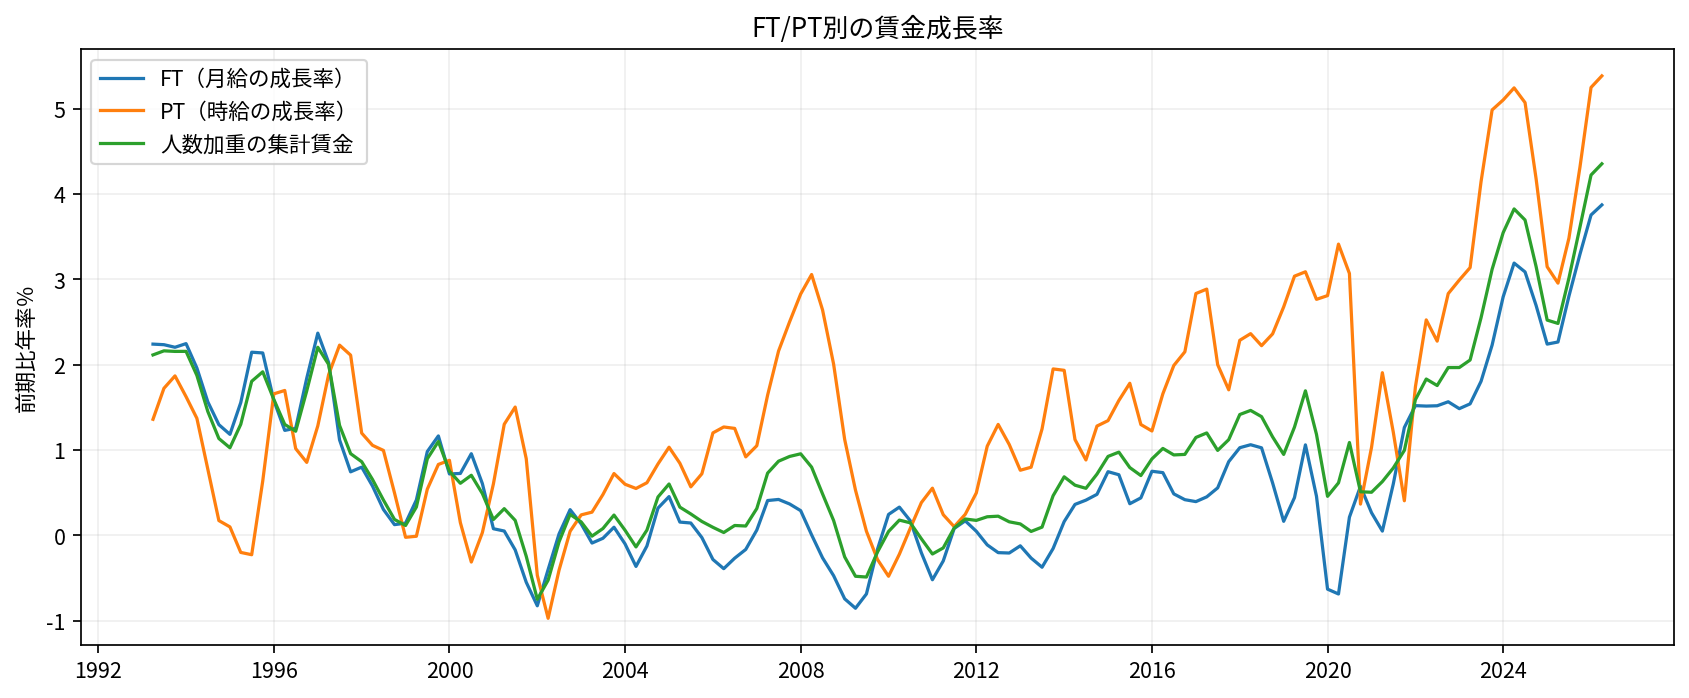

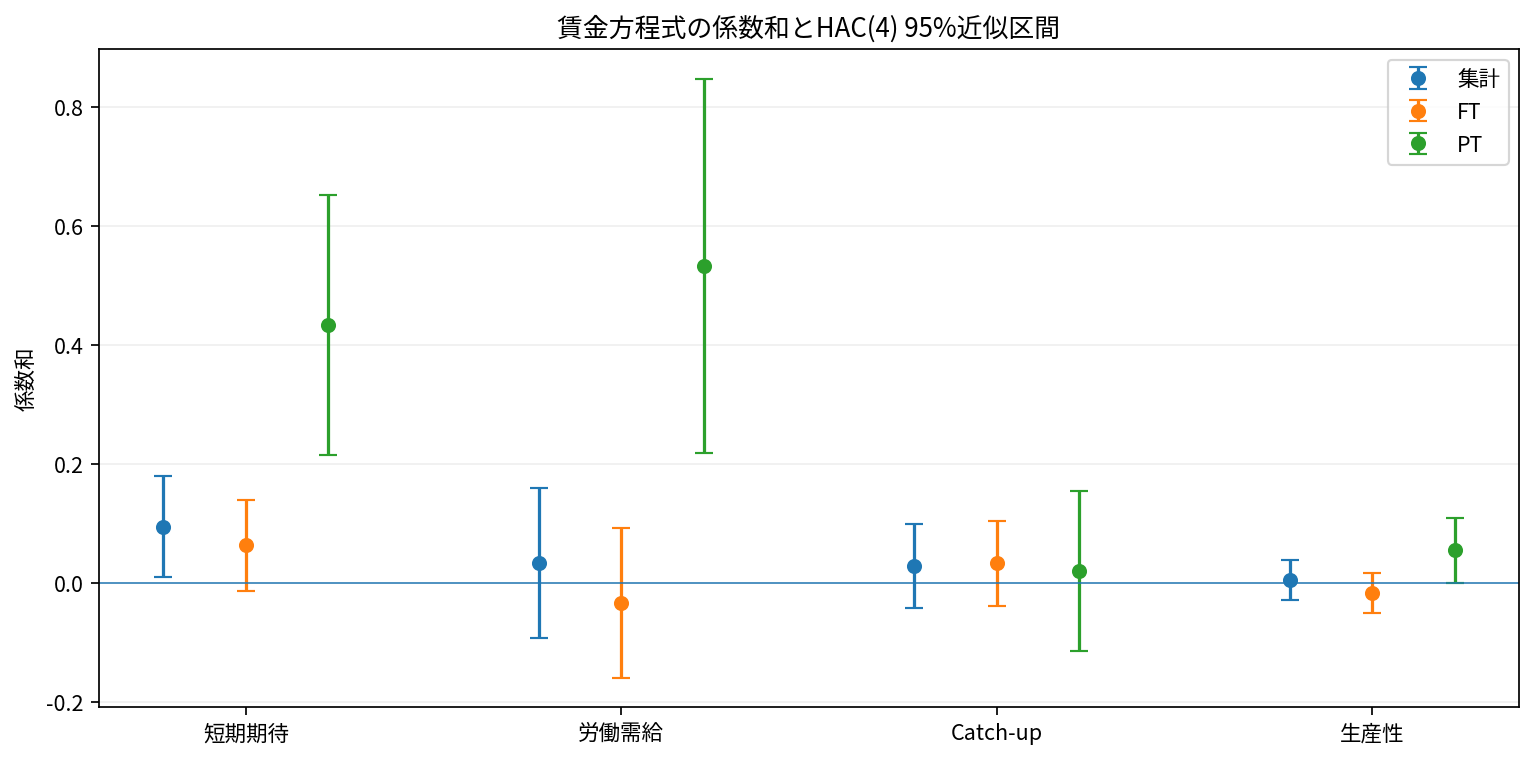

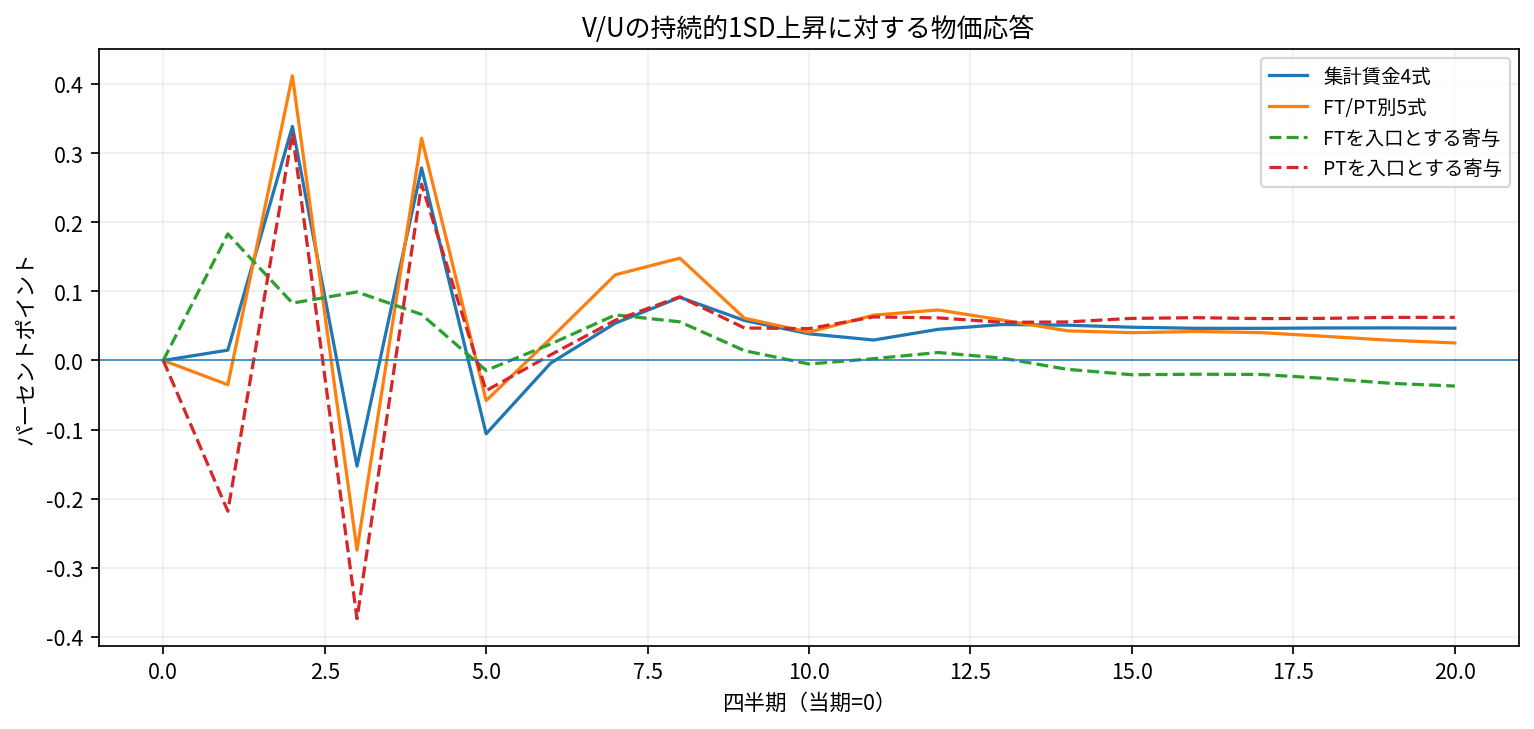

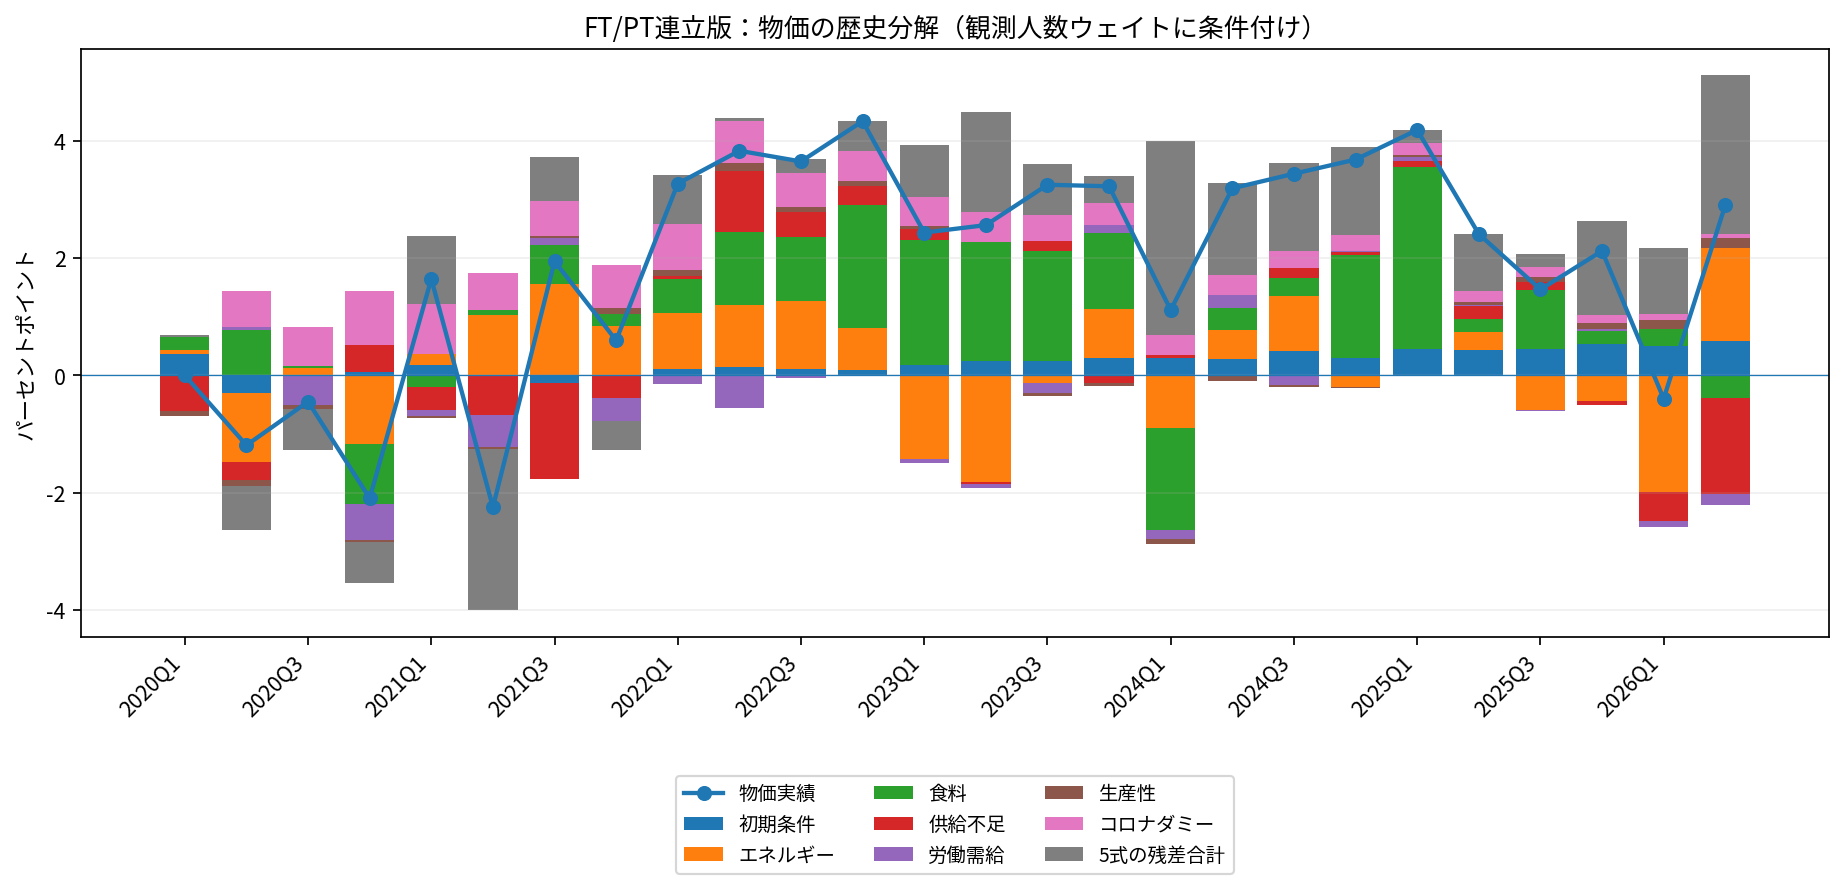

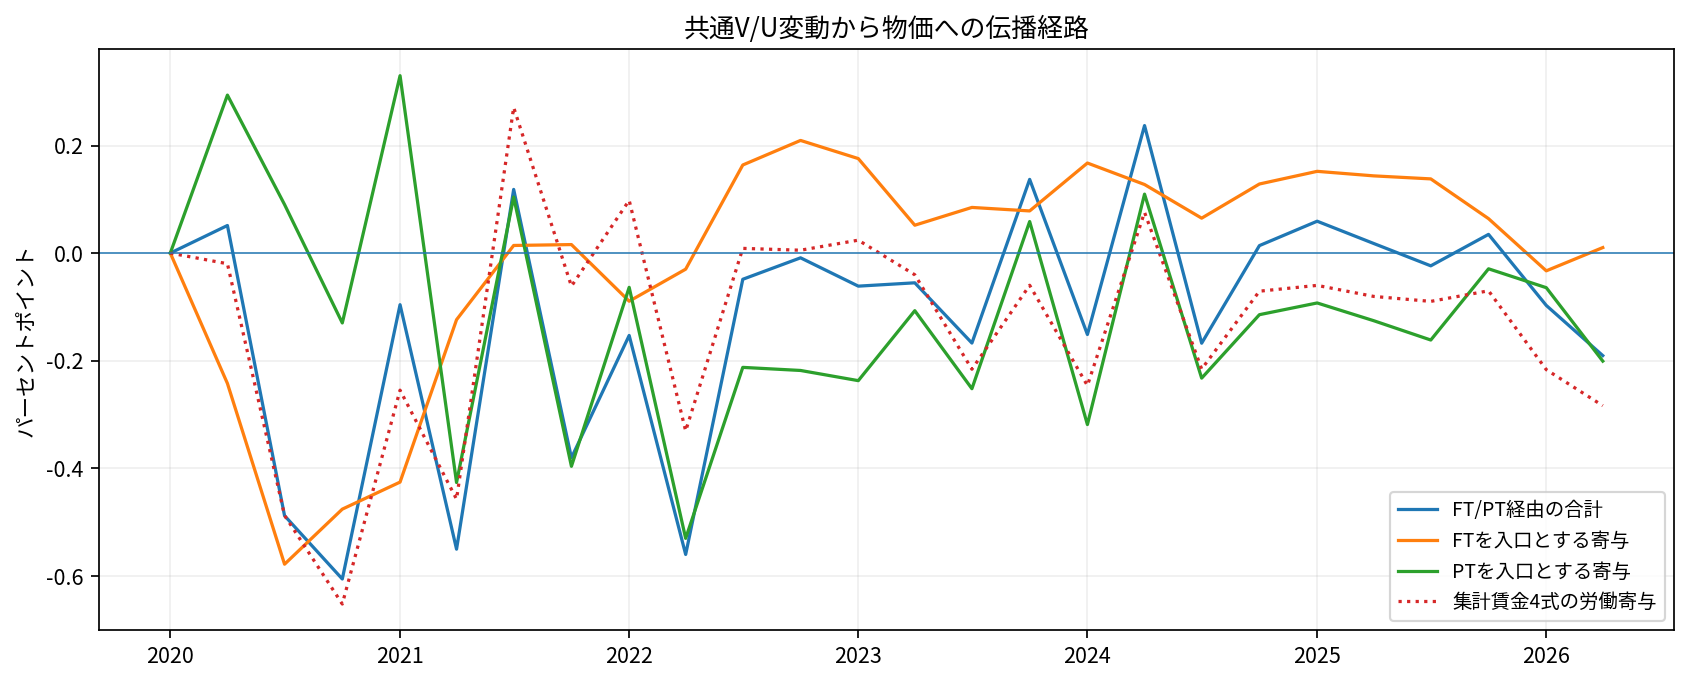

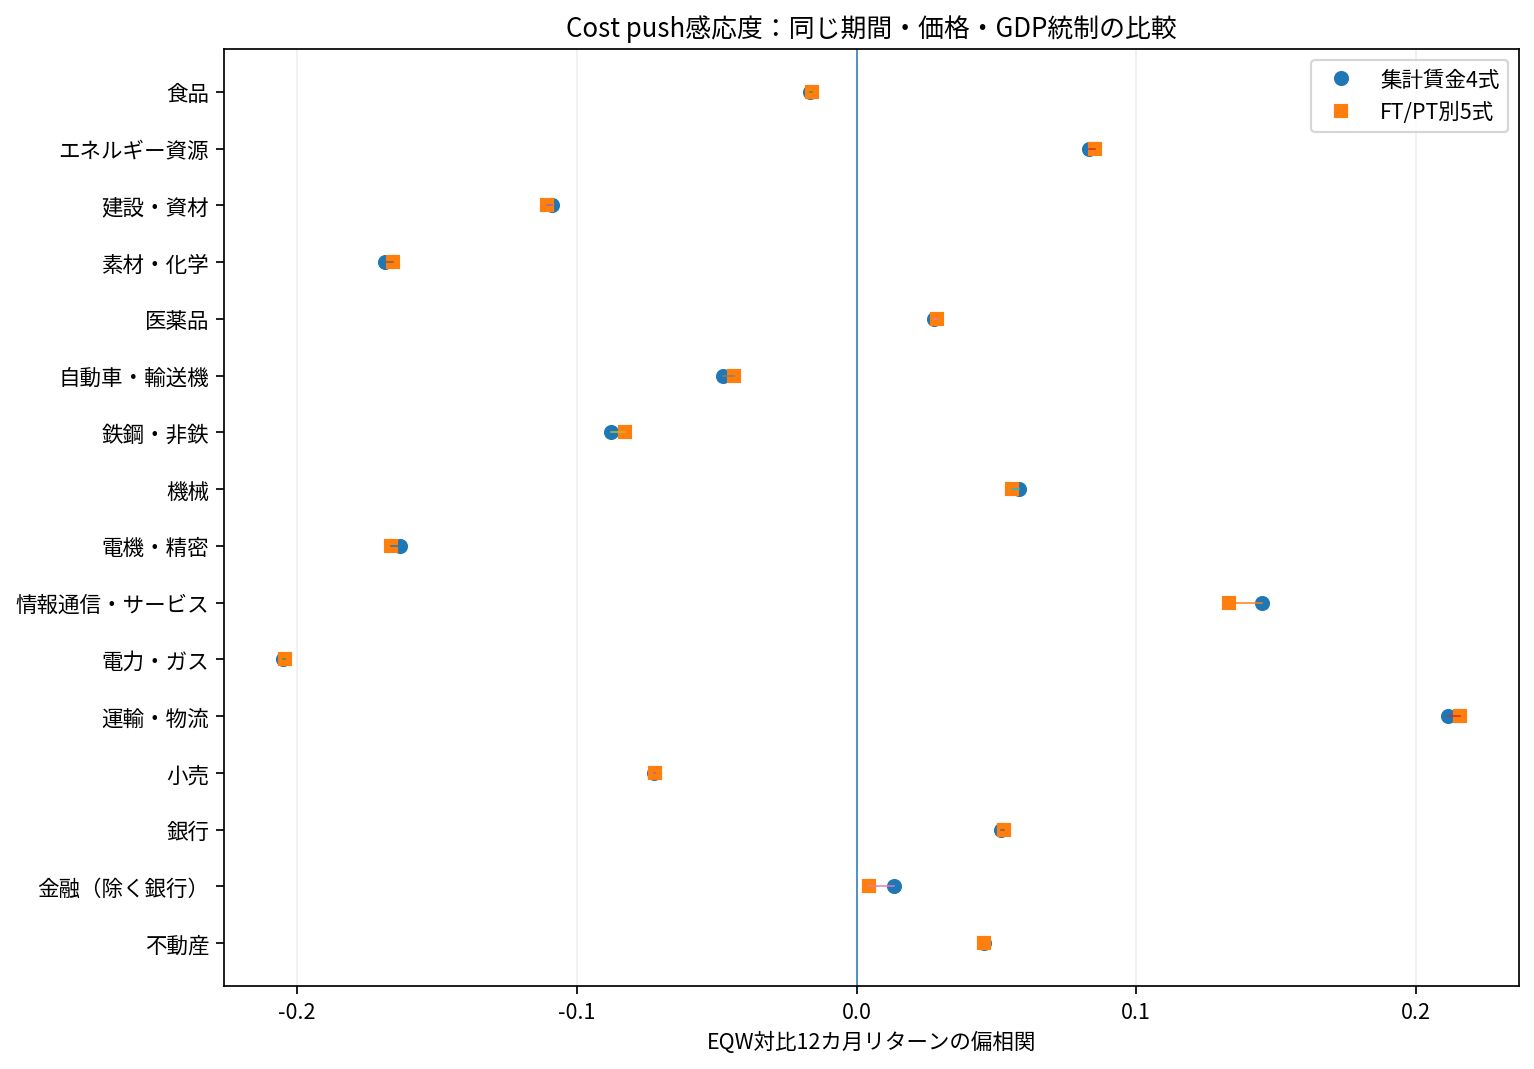

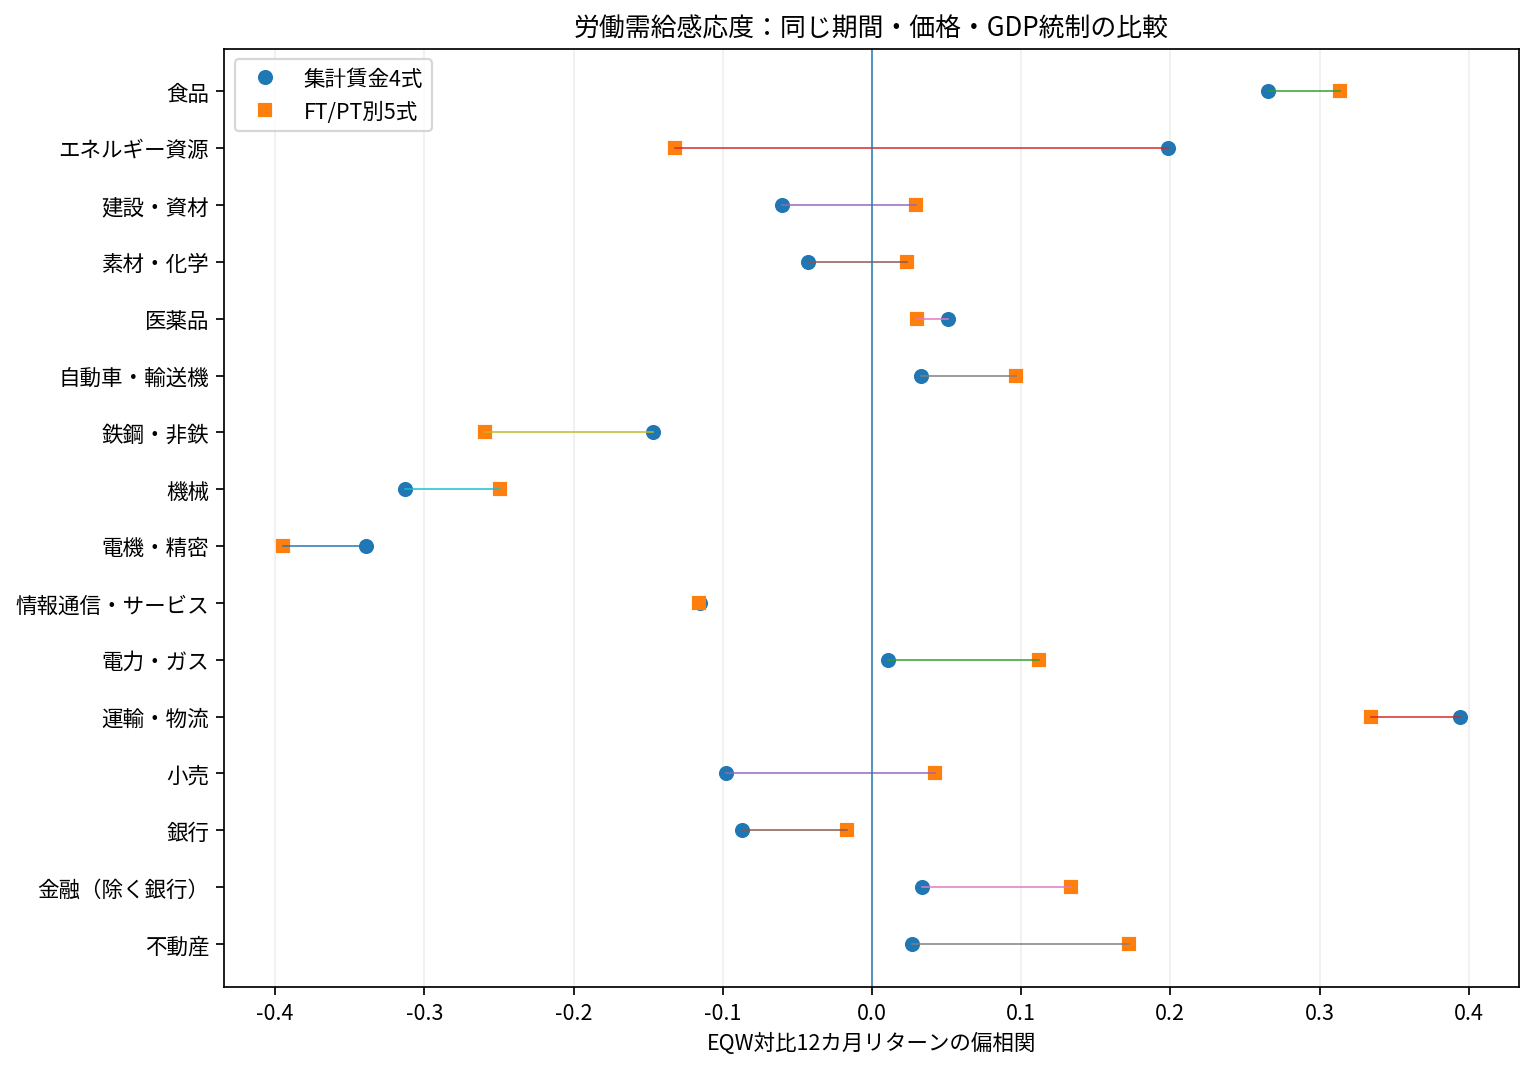

In [26]:
def ftplot(fig,name):
    fig.tight_layout()
    fig.savefig(FTPT_FIG/name,dpi=155,bbox_inches="tight")
    display(DisplayImage(filename=str(FTPT_FIG/name)))
    plt.close(fig)

fig,ax=plt.subplots(figsize=(11,4.6))
for var,label in [("gw_ft","FT（月給の成長率）"),("gw_pt","PT（時給の成長率）"),("gw","人数加重の集計賃金")]:
    ax.plot(dual_panel.index.to_timestamp(),dual_panel[var],label=label)
ax.set(title="FT/PT別の賃金成長率",ylabel="前期比年率％")
ax.grid(alpha=.2);ax.legend()
ftplot(fig,"01_wage_series.png")

# 部門別の係数和（HAC4）と集計賃金式。
groups=["cf1","vu","diffcpicf","magpty"]
names={"cf1":"短期期待","vu":"労働需給","diffcpicf":"Catch-up","magpty":"生産性"}
fig,ax=plt.subplots(figsize=(10,5))
x=np.arange(len(groups))
for off,(eq,label,source) in zip([-.22,0,.22],[("gw","集計",bb_hac),("gw_ft","FT",dual_hac),("gw_pt","PT",dual_hac)]):
    d=source.query("equation==@eq").set_index("group").reindex(groups)
    ax.errorbar(x+off,d.coef_sum,yerr=1.96*d.se_sum,fmt="o",capsize=4,label=label)
ax.axhline(0,linewidth=.7);ax.set_xticks(x,[names[g] for g in groups])
ax.set(title="賃金方程式の係数和とHAC(4) 95%近似区間",ylabel="係数和")
ax.grid(axis="y",alpha=.2);ax.legend()
ftplot(fig,"02_wage_coefficients.png")

# 同じV/Uショックの連立反応。
fig,ax=plt.subplots(figsize=(10,4.8))
d=dual_irfs.query("weight_reference==@anchor_label and entry_channel=='both' and shock=='labor_step' and unit=='one_sd'")
a=irfs.query("shock=='labor_step' and unit=='one_sd'")
ax.plot(a.horizon,a.gcpi,label="集計賃金4式")
ax.plot(d.horizon,d.gcpi,label="FT/PT別5式")
for leg in ["FT","PT"]:
    c=dual_irfs.query("weight_reference==@anchor_label and entry_channel==@leg and shock=='labor_step' and unit=='one_sd'")
    ax.plot(c.horizon,c.gcpi,linestyle="--",label=leg+"を入口とする寄与")
ax.axhline(0,linewidth=.7);ax.set(title="V/Uの持続的1SD上昇に対する物価応答",xlabel="四半期（当期=0）",ylabel="パーセントポイント")
ax.grid(alpha=.2);ax.legend(fontsize=9)
ftplot(fig,"03_labor_irf.png")

# 5式のユニークな寄与だけを足す。補助FT/PT経路列を二重に積まない。
def grouped_ftpt_hd(hd):
    d=hd[["initial_conditions","energy","food","shortage","labor","productivity"]].copy()
    d["covid"]=hd.covid_q2+hd.covid_q3
    d["residuals_total"]=hd[["residual_"+eq for eq in FTPT_EQ]].sum(axis=1)
    d["actual"]=hd.actual
    return d
du_hd=grouped_ftpt_hd(dual_pandemic["gcpi"])
ft_save(du_hd,"inflation_decomposition_grouped.csv",index=True)
fig,ax=plt.subplots(figsize=(12,6))
x=np.arange(len(du_hd));pos=np.zeros(len(x));neg=pos.copy()
names_hd={"initial_conditions":"初期条件","energy":"エネルギー","food":"食料","shortage":"供給不足",
          "labor":"労働需給","productivity":"生産性","covid":"コロナダミー","residuals_total":"5式の残差合計"}
for col,label in names_hd.items():
    val=du_hd[col].to_numpy();ax.bar(x,val,bottom=np.where(val>=0,pos,neg),label=label)
    pos+=np.maximum(val,0);neg+=np.minimum(val,0)
ax.plot(x,du_hd.actual,marker="o",linewidth=2,label="物価実績")
ax.axhline(0,linewidth=.6);ax.set_xticks(x[::2],du_hd.index.astype(str)[::2],rotation=45,ha="right")
ax.set(title="FT/PT連立版：物価の歴史分解（観測人数ウェイトに条件付け）",ylabel="パーセントポイント")
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.22),ncol=3,fontsize=9);ax.grid(axis="y",alpha=.2)
ftplot(fig,"04_inflation_decomposition.png")

fig,ax=plt.subplots(figsize=(11,4.5))
h=dual_pandemic["gcpi"]
for col,label in [("labor","FT/PT経由の合計"),("labor_via_FT","FTを入口とする寄与"),("labor_via_PT","PTを入口とする寄与")]:
    ax.plot(h.index.to_timestamp(),h[col],label=label)
ax.plot(pandemic_hd["gcpi"].index.to_timestamp(),pandemic_hd["gcpi"].labor,linestyle=":",label="集計賃金4式の労働寄与")
ax.axhline(0,linewidth=.7);ax.set(title="共通V/U変動から物価への伝播経路",ylabel="パーセントポイント")
ax.grid(alpha=.2);ax.legend(fontsize=9)
ftplot(fig,"05_labor_history_channels.png")

for factor,slug in [("news_cost_push","cost_push"),("news_labor","labor")]:
    fig,ax=plt.subplots(figsize=(10,7))
    a=main_EQW.query("factor==@factor").set_index("asset").reindex(current_assets)
    b=dual_EQW.query("factor==@factor").set_index("asset").reindex(current_assets)
    y=np.arange(len(current_assets))
    ax.plot(a.partial_corr_growth,y,"o",label="集計賃金4式")
    ax.plot(b.partial_corr_growth,y,"s",label="FT/PT別5式")
    for i in y:ax.plot([a.partial_corr_growth.iloc[i],b.partial_corr_growth.iloc[i]],[i,i],linewidth=.7)
    ax.set_yticks(y,current_assets);ax.invert_yaxis();ax.axvline(0,linewidth=.7)
    ax.set(title=f"{factor_labels[factor]}感応度：同じ期間・価格・GDP統制の比較",xlabel="EQW対比12カ月リターンの偏相関")
    ax.grid(axis="x",alpha=.2);ax.legend()
    ftplot(fig,f"06_sector_{slug}.png")

# source-supported vs added assumptions are stated within delivered result documents.
def write_ftpt_reports():
    import html,base64
    def tbl(d,index=False):
        return d.to_html(index=index,border=0,escape=True,float_format=lambda x:f"{x:.4f}")
    def image(name,caption):
        b=base64.b64encode((FTPT_FIG/name).read_bytes()).decode()
        return f'<figure><figcaption>{html.escape(caption)}</figcaption><img src="data:image/png;base64,{b}" alt="{html.escape(caption)}"></figure>'
    principal=dual_sums.query("equation in ['gw_ft','gw_pt']").loc[:,["equation","group","coef_sum","p_sum","p_joint"]]
    # 原集計版の要約は上書き前に別名で保存。
    for file,newname in [("report.html","report_aggregate.html"),("RESULTS_ja.md","RESULTS_aggregate_ja.md")]:
        src=RESULT_DIR/file
        if src.exists():shutil.copy2(src,RESULT_DIR/newname)
    compw=wage_difference[["group","FT_coef_sum","PT_coef_sum","PT_minus_FT","p_difference_hac4_asymptotic"]]
    last=pd.DataFrame({"aggregate_4eq":pandemic_hd["gcpi"].iloc[-1],
                       "FTPT_5eq":dual_pandemic["gcpi"].iloc[-1]})
    ft_save(last,"latest_inflation_comparison.csv",index=True)
    core=dual_metrics[["equation","start","end","n","r2_corr","rmse","homogeneity_p"]]
    key_asset=main_EQW.query("factor in ['news_cost_push','news_labor']")[["asset","factor","partial_corr_growth"]].merge(
        dual_EQW[["asset","factor","partial_corr_growth"]],on=["asset","factor"],suffixes=("_aggregate","_FTPT"))
    ft_save(key_asset,"key_asset_comparison.csv")
    body=f"""
    <header><p>MONTHLY UPDATE / DUAL WAGE MODEL</p><h1>日本BB：FT/PT別賃金と資産感応度</h1>
    <p>基準日 {AS_OF_DATE.date()} ｜ BB {BB_START}～{BB_END} ｜ 資産 {len(primary_index)}四半期・{len(current_assets)}セクター</p></header>
    <section><h2>今回の変更</h2><p>集計賃金を作るだけでなく、FTとPTに別々の賃金方程式を推定し、
    人数加重の集計恒等式を介して物価・期待と連立させます。5つの確率方程式と1つの恒等式です。
    同じ入力・期間の従来4式モデルも同時実行しています。</p>
    <p><strong>文献上の区別：</strong>日本論文（PDF6頁、式1′）はFT/PT別式と人数加重を示します。
    国際比較論文（PDF43頁）は図のシミュレーションに集計賃金回帰を使うと明記しています。
    本5式の動学伝播は今回明示的に実装した拡張であり、PIIEの図の数値的完全再現ではありません。</p>
    <p>期待は企業1年/{long_year}年、前処理・価格式の生産性・4期ラグは既存設定を維持。
    観測された前期人数ウェイトを全反実仮想で共通に与えています。雇用構成自体の因果効果は識別しません。</p></section>
    <section><h2>要確認事項</h2>{tbl(alerts_df)}</section>
    <section><h2>FT/PT賃金の推定</h2>{tbl(principal)}{image("01_wage_series.png","FTは月給、PTは時給の成長率")}
    <h3>係数差のHAC検定（PT−FT）</h3>{tbl(compw)}
    <p>両賃金式の残差相関は{residual_corr:.4f}。差の検定は同期相関とHAC(4)を考慮した追加分析です。
    FT非有意・PT有意だけから差の有意性を判断しません。</p>
    {image("02_wage_coefficients.png","係数和の比較")}<h3>5方程式の適合度</h3>{tbl(core)}
    <h3>同じ集計賃金への当てはまり</h3>{tbl(agg_comparison_metrics)}
    <p>FT/PT版は賃金ブロックの自由係数が増えます。適合度の上昇だけで予測性能が優れるとは判断しません。</p></section>
    <section><h2>動学応答と要因分解</h2>{image("03_labor_irf.png","同じV/U変動のFT/PT伝播経路")}
    {image("04_inflation_decomposition.png","FT/PT連立版の物価歴史分解")}
    {image("05_labor_history_channels.png","労働需給のFT/PT入口別寄与")}
    <p>最終期の5式残差合計寄与は{dual_last_residual:.4f}pp。各残差は直交化されておらず、
    未導入の財政効果や独立した需要ショックとは呼びません。
    IRFは{irf_anchor}の人数ウェイト({w_anchor:.4f})で固定。時変系は別の安定性問題です。</p></section>
    <section><h2>NewsOnly資産感応度</h2>{image("06_sector_cost_push.png","Cost push：同一標本の比較")}
    {image("06_sector_labor.png","労働需給：同一標本の比較")}{tbl(dual_partial.rename(columns=factor_labels),True)}
    <p>主6因子・HAC・BHは従来定義。Bootstrapは{BOOTSTRAP_MAIN_REPS if RUN_BOOTSTRAP else 0}回で、
    BBと期待生成の不確実性を含まない条件付き区間です。
    FT/PT入口別の追加2因子はasset_sensitivity_labor_FT_PT_channels.csvに別保存しています。</p></section>
    <section><h2>月次運用と監査</h2><p>入力更新方法は従来と同じ。元CSV/XLSX→再構築→両モデル推定→分解→感応度を、
    main.ipynbの上から順に実行します。FT/PT追加の原データ取得は不要です。</p>
    <p>FT/PT前回比較：{ftpt_previous_status}。全検査数は{len(CHECKS)}。
    従来4式のファイルは上位resultsに互換名で残し、FT/PT結果はftpt/に保存。
    FT/PTの変化はftpt/asset_update_attribution.csv等で別管理します。</p>
    <p>文献にない処理上の選択はmodel_contract.jsonとMETHOD_FTPT_ja.mdを参照。
    物価/期待式の回帰係数は両モデルで同じであること、集計恒等式・全寄与の加法性・合成条件での4式への縮退を検算しています。</p></section>
    <footer><h2>出所・限界</h2><p>Nakamura, Nakano, Osada and Yamamoto (2024), BOJ WP24-E-1, §2.2式(1′), 表1/3/4。
    Bernanke and Blanchard (2024), PIIE WP24-11, pp.8,43,44。
    原データはユーザー提供の毎月勤労、CPI、労働力、職業紹介、GDP、企業期待、Google、資産価格。
    非公開の期待・前処理・シミュレーションコードを完全に復元したものではありません。</p>
    <p>財政拡張、surprise追加、売買戦略は未実装。資産感応度は同時12カ月リターンへの事後的関係です。</p></footer>
    """
    css="""body{max-width:1160px;margin:auto;padding:30px;font-family:-apple-system,BlinkMacSystemFont,"Segoe UI","Noto Sans JP",sans-serif;line-height:1.75;color:#223444}
    header{border-bottom:4px solid #264e63;padding-bottom:20px}h1{font-size:31px;line-height:1.4}
    h2{font-size:23px;margin-top:34px}table{border-collapse:collapse;display:block;overflow:auto;font-size:12px}
    td,th{border-bottom:1px solid #d8dfe4;padding:8px 10px;white-space:nowrap;text-align:right}th{background:#edf2f6}
    td:first-child,th:first-child{text-align:left}figure{margin:25px 0}figcaption{font-weight:600}img{max-width:100%;height:auto}footer{border-top:2px solid #264e63;margin-top:30px}
    """
    doc='<!doctype html><html lang="ja"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>日本BB FT/PT更新</title><style>'+css+"</style><body>"+body+"</body></html>"
    (FTPT_DIR/"report.html").write_text(doc,encoding="utf-8")
    (RESULT_DIR/"report.html").write_text(doc,encoding="utf-8")
    mdtext=f"""# 日本BB FT/PT別賃金：月次更新結果
BB標本 {BB_START}–{BB_END}、{dual_model['gw_ft']['n']}観測。資産 {len(primary_index)}四半期。
現在の期待：企業1年/{long_year}年。FT/PT追加のために年限・前処理・価格式を同時に変更していない。
## 文献との関係
日本論文式(1′)は別賃金式＋人数集計。国際比較論文43頁では図のシミュレーションは集計賃金回帰を使用。
本版はFT/PTの動学を価格・期待へ接続した追加拡張。原論文の全データ・図の完全再現ではない。
## FT/PTの係数和
{plain_table(principal)}
## 係数差
{plain_table(compw)}
差のHACは両式の残差相関を考慮。残差相関={residual_corr:.6f}。
## 適合度
{plain_table(core)}
## 集計賃金への適合
{plain_table(agg_comparison_metrics)}
## NewsOnly比較
{plain_table(pd.DataFrame(news_comparison))}
## 最終物価分解（ユニークな集計寄与）
{plain_table(du_hd.tail(1),index=True)}
残差合計={dual_last_residual:.6f}pp。FT/PT入口別労働寄与は合計と重複する補助列であり、二重に足さない。
## 制限
FT/PT月次平滑化と人数ウェイトの厳密な処理は未公開のため、既存の再構築近似を維持。
人数ウェイトは観測された前期比率の経路に条件付けて全反実仮想で固定。雇用構成を内生化していない。
価格式は集計gwを維持し、期待・価格の回帰係数は集計版と同じ（検算済み）。
独立した構造ショック、因果的財政効果、将来リターン予測を識別した結果ではない。
FT/PT比較の改善には追加パラメータ数が関係する。高いR²だけで優劣を判定しない。
HAC・資産bootstrapは固定した生成済みニュースに条件付けている。
## 月次更新
従来のinputs/providerまたはinputs/csvを全履歴で更新してRestart & Run All。
FT/PT出力はftpt/、集計版の互換出力は上位ディレクトリ。成功時のみlatest更新。
今回のFT/PT前回比較={ftpt_previous_status}。原入力は変更していない。
"""
    (FTPT_DIR/"RESULTS_ja.md").write_text(mdtext,encoding="utf-8")
    (RESULT_DIR/"RESULTS_ja.md").write_text(mdtext,encoding="utf-8")

## 18．インフレ圧力のレジーム：既存計算の後段に追加する表示層

**分類＝圧力の水準、加速・減速＝既存NewsOnly、品質＝分類の根拠と不安定さ。**
モデル・入力・残差・係数・資産回帰をこの節で変更しない。

主入力は既存NewsOnlyと同じ **FT/PT版の長期物価歴史分解**。
\[
P_{C,t}=\tfrac14\sum_{j=0}^3(C_{energy,t-j}+C_{food,t-j}+C_{shortage,t-j}),\quad
P_{W,t}=\tfrac14\sum_{j=0}^3 C_{labor,t-j}.
\]
\(N_C=P_C-P_{C,t-4}\)、\(N_W=P_W-P_{W,t-4}\) は既存ニュースと一致することを検査する。

分類は、符号付きの群内合計の後に上押し部分 \(A_C=[P_C]_+, A_W=[P_W]_+\) を取り、
その合計Aと構成比でCost push／労働需給・賃金／混合／弱い追加圧力に分ける。
負寄与・相殺・実際の物価は別列に残す。正の寄与だけを先に足して圧力を水増ししない。

`regime_raw`は当期のルール、`regime_stable`は四半期単位のヒステリシス、
`regime_final`は判定品質を踏まえた公表用のラベル。品質が低い場合は**判定保留**とし、
暫定的な4分類や圧力値そのものは消さない。弱い追加圧力は「物価が低い」「デフレ」と同義ではない。

参照：PIIE WP24-11, pp.23,29（歴史寄与は基準経路からの直接・間接効果を含む）、
pp.8–9（需要・供給の原始的ショックは完全識別しない）。
BOJ WP24-E-1, pp.15–16（式残差の相関・解釈の留保）。
本節の4分類、数値閾値、品質ルールは**本件の表示仕様**であり、文献で推定されたものではない。

In [27]:
# この層の入力をコピーし、元DataFrame・モデル・保存済み数値ファイルの不変性を検査する。
import copy as _reg_copy
import pickle as _reg_pickle
from itertools import product as _reg_product

REG_DIR=RESULT_DIR/"regimes";REG_FIG=REG_DIR/"figures"
REG_DIR.mkdir(exist_ok=True);REG_FIG.mkdir(exist_ok=True)
_reg_upstream_names=[
    "panel","dual_panel","model","dual_model","history","dual_history","pandemic_hd","dual_pandemic",
    "news_all","dual_news_all","main","dual_main","assets","CFG","FTPT_CFG","FACTORS",
]
def reg_fingerprint(obj):
    return hashlib.sha256(_reg_pickle.dumps(obj,protocol=5)).hexdigest()
REG_UPSTREAM_BEFORE={k:reg_fingerprint(globals()[k]) for k in _reg_upstream_names}
REG_FILES_BEFORE={str(p.relative_to(RESULT_DIR)):sha256(p.read_bytes()) for p in RESULT_DIR.rglob("*")
                  if p.is_file() and p.suffix.lower() in [".csv",".json"] and not p.is_relative_to(REG_DIR)}
REGIME_CHECKS=[]
def reg_check(name,condition,detail=""):
    row={"test":name,"passed":bool(condition),"detail":str(detail)}
    REGIME_CHECKS.append(row)
    check("regime_"+name,condition,detail)
def reg_save(df,name,index=False):
    save_csv(df,name,index=index,folder=REG_DIR)


def reg_json_safe(value):
    if isinstance(value,dict):return {str(k):reg_json_safe(v) for k,v in value.items()}
    if isinstance(value,(list,tuple)):return [reg_json_safe(v) for v in value]
    if isinstance(value,(np.integer,np.floating,np.bool_)):return reg_json_safe(value.item())
    if value is None or value is pd.NA:return None
    if isinstance(value,float) and not np.isfinite(value):return None
    if isinstance(value,(pd.Period,pd.Timestamp)):return str(value)
    return value
def reg_json(obj,path):
    path.parent.mkdir(parents=True,exist_ok=True)
    path.write_text(json.dumps(reg_json_safe(obj),ensure_ascii=False,indent=2,allow_nan=False),encoding="utf-8")

REG_LABEL={
    "COST_PUSH":"Cost push型",
    "LABOR_WAGE":"労働需給・賃金型",
    "MIXED":"混合型",
    "WEAK":"弱い追加圧力",
    "HOLD":"判定保留・その他要因優位",
    "UNAVAILABLE":"履歴不足",
}
REG_QUALITY_LABEL={"high":"高（ルール内）","medium":"中・留保付き","low":"低・判定保留","not_available":"履歴不足"}
REG_REASON={
    "insufficient_history":"4四半期の連続履歴が不足",
    "insufficient_news_history":"NewsOnlyの4期差に必要な履歴が不足",
    "other_positive_dominates":"その他の上押しが大きく、主2系統のカバー率が下限未満",
    "coverage_moderate":"主2系統の上押しカバー率が高品質基準未満",
    "residual_dominates":"式残差の絶対寄与が大きく、全追加寄与に占める比率が保留基準以上",
    "residual_material":"式残差の絶対寄与が大きく、全追加寄与に占める比率が注意基準以上",
    "near_pressure_boundary":"圧力の参入・退出閾値に近い",
    "near_dominance_boundary":"構成比の参入・維持閾値に近い",
    "cost_internal_offset":"商品市場の正負の寄与が大きく相殺",
    "cross_factor_offset":"商品市場と労働需給が相殺",
    "aggregate_model_disagreement":"同じ長期基準の集計賃金版と4分類が不一致",
    "aggregate_model_opposite":"集計版とFT/PT版で支配的な上押しの系統が逆",
    "baseline_disagreement":"別の初期条件（2020Q1開始）では4分類が異なる",
    "threshold_sensitive":"閾値グリッドの主4分類一致率が基準未満",
    "homogeneity_rejected":"現行推定ビンテージで同次性制約が棄却される式がある",
    "frozen_root_above_one":"固定ウェイトの根が1を超える（時変系の注意診断）",
    "stale_inputs":"入力統計の実行日からの遅れが大きい",
    "initial_conditions_dominant":"初期条件が物価説明の大部分を占める",
    "no_diagnostic_issues":"この表示ルールの品質検査に大きな問題なし",
}
def reg_validate_config(cfg):
    required=set(REGIME_CFG)
    if set(cfg)!=required:raise ValueError("レジーム設定キーを確認してください")
    for k,v in cfg.items():
        if isinstance(v,(int,float)) and not isinstance(v,bool) and not np.isfinite(v):raise ValueError(f"非有限の設定: {k}")
    if int(cfg["pressure_window"])!=4 or int(cfg["news_difference"])!=4:
        raise ValueError("主仕様は4期平均・4期差固定。短期平均は別の感応度比較として出力します")
    if not 0<cfg["pressure_exit_pp"]<cfg["pressure_enter_pp"]:
        raise ValueError("圧力の退出閾値は参入閾値より小さい正数")
    if not .5<=cfg["dominance_hold"]<cfg["dominance_enter"]<1:
        raise ValueError("構成比は0.5≤維持<参入<1")
    if not 0<cfg["coverage_low"]<cfg["coverage_high"]<1:raise ValueError("coverage閾値")
    if not 0<cfg["residual_share_warning"]<cfg["residual_share_hold"]<1:raise ValueError("残差比閾値")
    if not cfg["pressure_enter_pp"]<cfg["intensity_mid_pp"]<cfg["intensity_high_pp"]:raise ValueError("圧力強度閾値")
    for k in ["momentum_band_pp","sign_band_pp","other_material_pp","residual_material_pp",
              "boundary_pressure_pp","boundary_share","ftpt_channel_material_pp"]:
        if cfg[k]<0:raise ValueError(f"負の閾値: {k}")
    return dict(cfg)
REG_CFG=reg_validate_config(REGIME_CFG)
REG_CFG_HASH=hashlib.sha256(json.dumps(REG_CFG,sort_keys=True).encode()).hexdigest()
reg_json(REG_CFG,REG_DIR/"settings.json")

def reg_baseline_id(wage_system,metadata):
    spec={"wage_system":wage_system,"history_start":metadata["start"],
          "anchor":metadata.get("anchor",str(pd.Period(metadata["start"])-1)),
          "mean_start":metadata.get("mean_start",NEWS_MEAN_START),"method":"existing_full_dynamic_history"}
    return wage_system+"_"+hashlib.sha256(json.dumps(spec,sort_keys=True).encode()).hexdigest()[:12],spec

def reg_validate_history(hd,parts):
    if not isinstance(hd.index,pd.PeriodIndex) or not hd.index.freqstr.startswith("Q"):
        raise TypeError("レジーム入力は四半期PeriodIndex")
    if not hd.index.is_unique or not hd.index.is_monotonic_increasing:
        raise ValueError("重複・未整列の四半期")
    expected=pd.period_range(hd.index.min(),hd.index.max(),freq="Q")
    if not hd.index.equals(expected):raise ValueError("途中の四半期がない。連続4期として扱えません")
    if len(parts)!=len(set(parts)):raise ValueError("加法成分の列が重複")
    needed=set(parts)|{"actual"}
    if not needed.issubset(hd):raise ValueError(f"歴史寄与列不足: {sorted(needed-set(hd))}")
    if any(c.startswith("labor_via_") for c in parts):raise ValueError("FT/PTはlabor内訳のため二重計上不可")
    arr=hd[list(needed)].to_numpy(float)
    if np.isinf(arr).any():raise ValueError("歴史寄与に無限大")
    valid=hd[list(needed)].dropna()
    if len(valid) and not np.allclose(valid[parts].sum(axis=1),valid.actual,atol=1e-8):
        raise ValueError("歴史分解の加法性が不成立")
    return hd.copy(deep=True)

def reg_pressure_frame(hd,parts,cfg,model_name,baseline_id,as_of,window=None):
    h=reg_validate_history(hd,parts)
    w=cfg["pressure_window"] if window is None else int(window)
    if w<1:raise ValueError("平均期間は正整数")
    p=h[parts+["actual"]].rolling(w,min_periods=w).mean()
    r=pd.DataFrame(index=h.index)
    r.index.name="quarter"
    for c in parts:r["component_"+c]=p[c]
    r["pressure_cost"]=p[["energy","food","shortage"]].sum(axis=1,min_count=3)
    r["pressure_labor"]=p["labor"]
    r["pressure_net"]=r.pressure_cost+r.pressure_labor
    r["actual_inflation_4q"]=p.actual
    r["pressure_initial_conditions"]=p.initial_conditions
    r["pressure_cost_up"]=r.pressure_cost.clip(lower=0)
    r["pressure_labor_up"]=r.pressure_labor.clip(lower=0)
    r["pressure_up_total"]=r.pressure_cost_up+r.pressure_labor_up
    r["pressure_down_total"]=(-r.pressure_cost.clip(upper=0)-r.pressure_labor.clip(upper=0))
    denominator=r.pressure_up_total.where(r.pressure_up_total>1e-12)
    r["share_cost"]=r.pressure_cost_up/denominator
    r["share_labor"]=r.pressure_labor_up/denominator
    # 主分類は群内ネット後の正値。以下は解釈・品質用のグロス相殺の診断のみ。
    costgross=p[["energy","food","shortage"]].abs().sum(axis=1,min_count=3)
    r["cost_gross_abs"]=costgross
    r["cost_offset_ratio"]=(1-r.pressure_cost.abs()/costgross.where(costgross>1e-12)).fillna(0).clip(0,1)
    principal_gross=r.pressure_cost.abs()+r.pressure_labor.abs()
    r["cross_factor_offset_ratio"]=(1-r.pressure_net.abs()/principal_gross.where(principal_gross>1e-12)).fillna(0).clip(0,1)
    other=[c for c in parts if c not in ["initial_conditions","energy","food","shortage","labor"]]
    resid=[c for c in parts if c.startswith("residual_")]
    r["other_positive"]=p[other].clip(lower=0).sum(axis=1,min_count=len(other))
    r["other_net"]=p[other].sum(axis=1,min_count=len(other))
    r["other_gross_abs"]=p[other].abs().sum(axis=1,min_count=len(other))
    cover_denom=r.pressure_up_total+r.other_positive
    r["pressure_coverage"]=r.pressure_up_total/cover_denom.where(cover_denom>1e-12)
    r["residual_net"]=p[resid].sum(axis=1,min_count=len(resid))
    r["residual_gross_abs"]=p[resid].abs().sum(axis=1,min_count=len(resid))
    noninitial=[c for c in parts if c!="initial_conditions"]
    totalgross=p[noninitial].abs().sum(axis=1,min_count=len(noninitial))
    r["all_incremental_gross_abs"]=totalgross
    r["residual_gross_share"]=r.residual_gross_abs/totalgross.where(totalgross>1e-12)
    r["initial_abs_share"]=p.initial_conditions.abs()/(p.initial_conditions.abs()+totalgross).where(
        p.initial_conditions.abs()+totalgross>1e-12)
    # 賃金・期待の残差は未識別タグ専用。laborへ加えない。
    unidentified=[c for c in resid if c!="residual_gcpi"]
    r["unidentified_wage_expectations_net"]=p[unidentified].sum(axis=1,min_count=len(unidentified))
    r["unidentified_wage_expectations_gross"]=p[unidentified].abs().sum(axis=1,min_count=len(unidentified))
    r["components_reconstructed"]=p[parts].sum(axis=1,min_count=len(parts))
    r["news_cost_push_calculated"]=r.pressure_cost.diff(cfg["news_difference"])
    r["news_labor_calculated"]=r.pressure_labor.diff(cfg["news_difference"])
    r["news_total_calculated"]=r.actual_inflation_4q.diff(cfg["news_difference"])
    for leg in ["FT","PT"]:
        col="labor_via_"+leg
        r["pressure_labor_"+leg.lower()]=h[col].rolling(w,min_periods=w).mean() if col in h else np.nan
    r["model_name"]=model_name;r["baseline_id"]=baseline_id
    r["economic_quarter"]=h.index.astype(str)
    r["evaluation_as_of"]=str(pd.Timestamp(as_of).date())
    r["retrospective_current_vintage"]=True
    r["pressure_ready"]=p[parts+["actual"]].notna().all(axis=1)
    r["mean_window"]=w
    return r

def reg_classify_path(pressure,cfg,use_hysteresis=True):
    data=pressure.copy(deep=True);prev="WEAK";is_active=False;rows=[]
    for q,row in data.iterrows():
        if not bool(row["pressure_ready"]):
            rows.append({"regime_raw":"UNAVAILABLE","regime_stable":"UNAVAILABLE",
                         "pressure_active":False,"hysteresis_applied":False})
            prev="WEAK";is_active=False;continue
        a=float(row["pressure_up_total"]);s=float(row["share_cost"]) if a>0 else np.nan
        def choose(active,previous=None):
            if not active:return "WEAK"
            if s>=cfg["dominance_enter"]-1e-12:return "COST_PUSH"
            if (1-s)>=cfg["dominance_enter"]-1e-12:return "LABOR_WAGE"
            if previous=="COST_PUSH" and s>=cfg["dominance_hold"]-1e-12:return "COST_PUSH"
            if previous=="LABOR_WAGE" and (1-s)>=cfg["dominance_hold"]-1e-12:return "LABOR_WAGE"
            return "MIXED"
        raw=choose(a>=cfg["pressure_enter_pp"]-1e-12)
        if use_hysteresis:
            active=(a>=cfg["pressure_exit_pp"]-1e-12) if is_active else (a>=cfg["pressure_enter_pp"]-1e-12)
            stable=choose(active,prev if is_active else None)
        else:stable=raw;active=stable!="WEAK"
        rows.append({"regime_raw":raw,"regime_stable":stable,"pressure_active":bool(active),
                     "hysteresis_applied":stable!=raw})
        prev=stable;is_active=active
    return data.join(pd.DataFrame(rows,index=data.index))

### 判定品質とラベル
参入は上押し合計0.25pp、退出は0.15pp。構成比は新規優位65%、既存優位の維持55%。
NewsOnlyは±0.10ppを横ばい帯とする。圧力の強度は上押し合計Aの0.25/0.50/1.00ppで区切る。

品質は確率でもp値でもない。その他の正の追加寄与が0.25pp以上かつ2系統のカバー率50%未満、
または式残差の絶対寄与が0.50pp以上かつ全追加寄与の75%以上なら、主分類は保留。
初期条件は別表示し、残差を賃金型や財政型へ振り分けない。符号不明の需要を作らない。

境界近傍・相殺・モデル差・初期条件差・閾値感応度・既存の制約検定等は品質の留保として記録。
表示上の「高」はこれらのルール内の評価で、因果的識別や投資収益の信頼度を意味しない。

In [28]:
def reg_momentum_code(value,band):
    if pd.isna(value):return "UNAVAILABLE"
    if value>band+1e-12:return "ACCELERATING"
    if value<-band-1e-12:return "DECELERATING"
    return "FLAT"
REG_MOM_LABEL={"ACCELERATING":"加速","DECELERATING":"減速","FLAT":"横ばい","UNAVAILABLE":"履歴不足"}
def reg_pressure_change_text(pressure,news,cfg):
    m=reg_momentum_code(news,cfg["momentum_band_pp"])
    if m=="UNAVAILABLE":return "変化方向の履歴不足"
    if pressure>cfg["sign_band_pp"]:
        return {"ACCELERATING":"上押し拡大","DECELERATING":"上押し縮小","FLAT":"上押し横ばい"}[m]
    if pressure<-cfg["sign_band_pp"]:
        return {"ACCELERATING":"下押し縮小","DECELERATING":"下押し拡大","FLAT":"下押し横ばい"}[m]
    return {"ACCELERATING":"ゼロ近傍から上向き","DECELERATING":"ゼロ近傍から下向き","FLAT":"ゼロ近傍で横ばい"}[m]

def reg_add_labels_and_quality(frame,cfg,diagnostic_context=None):
    r=frame.copy(deep=True);context={} if diagnostic_context is None else dict(diagnostic_context)
    labels=[]
    for q,row in r.iterrows():
        record={}
        if not row.pressure_ready:
            record.update(regime_final="UNAVAILABLE",classification_quality="not_available",
                          reason_codes="insufficient_history",reason=REG_REASON["insufficient_history"],
                          pressure_intensity="履歴不足",momentum_state="UNAVAILABLE",momentum_label="履歴不足",
                          net_state="履歴不足",ftpt_detail="履歴不足",hysteresis_only=False,
                          news_ready=False,unidentified_wage_expectations_tag=False)
            labels.append(record);continue
        reasons=[];severity=0
        def mark(reason,level=1):
            reasons.append((reason,level))
        C=float(row.pressure_cost);W=float(row.pressure_labor);A=float(row.pressure_up_total)
        nc=row.get("news_cost_push",row.news_cost_push_calculated)
        nw=row.get("news_labor",row.news_labor_calculated)
        if row.other_positive>=cfg["other_material_pp"]-1e-12:
            if row.pressure_coverage<cfg["coverage_low"]:mark("other_positive_dominates",2)
            elif row.pressure_coverage<cfg["coverage_high"]:mark("coverage_moderate")
        if row.residual_gross_abs>=cfg["residual_material_pp"]-1e-12:
            if row.residual_gross_share>=cfg["residual_share_hold"]:mark("residual_dominates",2)
            elif row.residual_gross_share>=cfg["residual_share_warning"]:mark("residual_material")
        if min(abs(A-cfg["pressure_enter_pp"]),abs(A-cfg["pressure_exit_pp"]))<=cfg["boundary_pressure_pp"]+1e-12:
            mark("near_pressure_boundary")
        if A>=cfg["pressure_exit_pp"] and np.isfinite(row.share_cost):
            if min(abs(row.share_cost-x) for x in [cfg["dominance_enter"],1-cfg["dominance_enter"],
                    cfg["dominance_hold"],1-cfg["dominance_hold"]])<=cfg["boundary_share"]:
                mark("near_dominance_boundary")
        if row.cost_gross_abs>=cfg["other_material_pp"] and row.cost_offset_ratio>=cfg["cancellation_warning"]:
            mark("cost_internal_offset")
        if abs(C)+abs(W)>=cfg["other_material_pp"] and row.cross_factor_offset_ratio>=cfg["cancellation_warning"]:
            mark("cross_factor_offset")
        alt=row.get("aggregate_regime_stable",None)
        if alt is not None and pd.notna(alt) and alt!="UNAVAILABLE" and alt!=row.regime_stable:
            opposite={alt,row.regime_stable}=={"COST_PUSH","LABOR_WAGE"}
            mark("aggregate_model_opposite" if opposite else "aggregate_model_disagreement",
                 2 if opposite and cfg["severe_model_opposition_hold"] else 1)
        bas=row.get("baseline2020_regime_stable",None)
        if bas is not None and pd.notna(bas) and bas!="UNAVAILABLE" and bas!=row.regime_stable:
            mark("baseline_disagreement")
        agreement=row.get("threshold_agreement",np.nan)
        if pd.notna(agreement) and agreement<cfg["threshold_agreement_warning"]:mark("threshold_sensitive")
        if context.get("homogeneity_rejected",False):mark("homogeneity_rejected")
        if context.get("unstable_root",False):mark("frozen_root_above_one",2)
        if context.get("stale_inputs",False):mark("stale_inputs")
        if abs(row.pressure_initial_conditions)>=.5 and row.initial_abs_share>=.65:
            mark("initial_conditions_dominant")
        n_ready=bool(pd.notna(nc) and pd.notna(nw))
        if not n_ready:mark("insufficient_news_history")
        level=max([lev for reason,lev in reasons],default=0)
        quality={0:"high",1:"medium",2:"low"}[level]
        final="HOLD" if quality=="low" else row.regime_stable
        # 主表示の方向は基礎4分類の対象に対して計算。保留時にも参考値として残す。
        if row.regime_stable=="COST_PUSH":headline_n=nc;headline_p=C
        elif row.regime_stable=="LABOR_WAGE":headline_n=nw;headline_p=W
        else:headline_n=nc+nw;headline_p=C+W
        momentum=reg_momentum_code(headline_n,cfg["momentum_band_pp"])
        if A<cfg["pressure_enter_pp"]:intensity="弱い"
        elif A<cfg["intensity_mid_pp"]:intensity="小"
        elif A<cfg["intensity_high_pp"]:intensity="中"
        else:intensity="大"
        net="ネット上押し" if C+W>cfg["sign_band_pp"] else (
            "ネット下押し" if C+W<-cfg["sign_band_pp"] else "ネットゼロ近傍")
        ft=row.get("pressure_labor_ft",np.nan);pt=row.get("pressure_labor_pt",np.nan);eps=cfg["ftpt_channel_material_pp"]
        if pd.isna(ft) or pd.isna(pt):detail="FT/PT分解なし"
        elif ft>eps and pt>eps:detail="FT/PT双方が上押し"
        elif ft<-eps and pt<-eps:detail="FT/PT双方が下押し"
        elif ft*pt<0 and min(abs(ft),abs(pt))>eps:
            detail="FT上押し・PT下押し（相殺）" if ft>0 else "PT上押し・FT下押し（相殺）"
        elif pt>eps:detail="PT中心の上押し"
        elif ft>eps:detail="FT中心の上押し"
        elif pt<-eps:detail="PT中心の下押し"
        elif ft<-eps:detail="FT中心の下押し"
        else:detail="FT/PT寄与は小さい"
        codes=list(dict.fromkeys(reason for reason,lev in reasons)) or ["no_diagnostic_issues"]
        record.update(regime_final=final,classification_quality=quality,
            reason_codes="|".join(codes),reason="；".join(REG_REASON[x] for x in codes),
            pressure_intensity=intensity,momentum_state=momentum,momentum_label=REG_MOM_LABEL[momentum],
            momentum_cost=reg_momentum_code(nc,cfg["momentum_band_pp"]),
            momentum_labor=reg_momentum_code(nw,cfg["momentum_band_pp"]),
            momentum_reference_news_pp=headline_n,momentum_reference_pressure_pp=headline_p,
            cost_change_context=reg_pressure_change_text(C,nc,cfg),
            labor_change_context=reg_pressure_change_text(W,nw,cfg),
            net_change_context=reg_pressure_change_text(C+W,nc+nw,cfg),
            net_state=net,ftpt_detail=detail,
            hysteresis_only=bool(row.pressure_active and A<cfg["pressure_enter_pp"]),
            news_ready=n_ready,
            unidentified_wage_expectations_tag=bool(row.unidentified_wage_expectations_net>=cfg["other_material_pp"]))
        labels.append(record)
    labelled=r.join(pd.DataFrame(labels,index=r.index))
    for c in ["regime_raw","regime_stable","regime_final"]:
        labelled[c+"_label"]=labelled[c].map(REG_LABEL)
    labelled["classification_quality_label"]=labelled.classification_quality.map(REG_QUALITY_LABEL)
    labelled["quality_is_probability"]=False
    labelled["display_label"]=labelled.regime_final_label+"／追加上押し"+labelled.pressure_intensity+"／"+labelled.momentum_label
    return labelled

def reg_threshold_grid(base_frame,cfg):
    combos=[(a,s) for a,s in _reg_product([.20,.25,.30],[.60,.65,.70])]
    rows=[];labels=[]
    for enter,share in combos:
        c=dict(cfg);c.update(pressure_enter_pp=enter,pressure_exit_pp=.6*enter,
                            dominance_enter=share,dominance_hold=max(.5,share-.10))
        reg_validate_config(c)
        d=reg_classify_path(base_frame,c)
        name=f"A{enter:.2f}_S{share:.2f}"
        labels.append(d.regime_stable.rename(name))
        rows.append({"specification":name,"pressure_enter_pp":enter,"pressure_exit_pp":.6*enter,
                     "dominance_enter":share,"dominance_hold":max(.5,share-.1)})
    wide=pd.concat(labels,axis=1)
    return wide,pd.DataFrame(rows)

### 実データへの適用
主レジームはFT/PT・長期基準。集計賃金版、2020年開始の分解、2期平均は別系列で計算し、
主入力へ混ぜない。閾値の9組合せは経済的ラベルの感応度を点検するだけで、最も収益が高い設定を選ばない。
モデルの同次性検定は当該runの推定ビンテージに関する注意であり、各過去時点で独立に検定した結果ではない。

資産リターンとの結合は**既存の同時12カ月観測にラベルを付けるだけ**。
レジームで標本を選別して既存βを変更せず、後知恵のラベルを将来予測・リアルタイム売買へ用いた結果と表示しない。

In [29]:
reg_id_ftpt,reg_spec_ftpt=reg_baseline_id("FTPT",dual_history_meta)
reg_id_agg,reg_spec_agg=reg_baseline_id("aggregate",history_meta)
reg_id_2020,reg_spec_2020=reg_baseline_id("FTPT_2020",dual_pandemic_meta)
reg_context_ftpt={
    "homogeneity_rejected":bool((dual_metrics.homogeneity_p<.05).any()),
    "unstable_root":bool((frozen_diagnostics.roots_above_one>0).any()),
    "stale_inputs":any(x["code"]=="source_stale" for x in ALERTS),
}
reg_context_aggregate={
    "homogeneity_rejected":bool((bb_metrics.homogeneity_p<.05).any()),
    "unstable_root":bool(stability["roots_above_one"]>0),
    "stale_inputs":reg_context_ftpt["stale_inputs"],
}
reg_p_ftpt=reg_pressure_frame(dual_history["gcpi"],FTPT_PARTS,REG_CFG,"FTPT",reg_id_ftpt,AS_OF_DATE)
reg_p_agg=reg_pressure_frame(history["gcpi"],PARTS,REG_CFG,"aggregate",reg_id_agg,AS_OF_DATE)
reg_p_2020=reg_pressure_frame(dual_pandemic["gcpi"],FTPT_PARTS,REG_CFG,"FTPT_2020",reg_id_2020,AS_OF_DATE)

# 使用するNewsOnlyは既存列をそのままコピー。calculated列との一致は別に検算する。
for frame,existing,name in [(reg_p_ftpt,dual_news_all,"FTPT"),(reg_p_agg,news_all,"aggregate")]:
    for col in ["news_cost_push","news_labor","news_total"]:
        if col not in existing:raise ValueError(f"{name} NewsOnlyに{col}がありません")
        exact=existing[col].reindex(frame.index)
        calculated=frame[col+"_calculated"]
        reg_check("news_mask_"+name+"_"+col,exact.notna().equals(calculated.notna()))
        delta=float((exact-calculated).abs().max())
        reg_check("news_formula_"+name+"_"+col,delta<1e-8,delta)
        frame[col]=exact.copy()
    valid=frame.pressure_ready
    reg_check("pressure_additivity_"+name,np.allclose(
        frame.loc[valid,"actual_inflation_4q"],
        frame.loc[valid,"pressure_initial_conditions"]+frame.loc[valid,"pressure_cost"]+
        frame.loc[valid,"pressure_labor"]+frame.loc[valid,"other_net"],atol=1e-8))
reg_valid=reg_p_ftpt.pressure_ready
reg_check("FTPT_no_extra_weight_or_double_count",np.allclose(
    reg_p_ftpt.loc[reg_valid,"pressure_labor"],
    reg_p_ftpt.loc[reg_valid,"pressure_labor_ft"]+reg_p_ftpt.loc[reg_valid,"pressure_labor_pt"],atol=1e-8))
reg_s_ftpt=reg_classify_path(reg_p_ftpt,REG_CFG)
reg_s_agg=reg_classify_path(reg_p_agg,REG_CFG)
reg_s_2020=reg_classify_path(reg_p_2020,REG_CFG)

reg_s_ftpt["aggregate_regime_stable"]=reg_s_agg.regime_stable.reindex(reg_s_ftpt.index)
reg_s_ftpt["baseline2020_regime_stable"]=reg_s_2020.regime_stable.reindex(reg_s_ftpt.index)
reg_s_agg["aggregate_regime_stable"]=reg_s_ftpt.regime_stable.reindex(reg_s_agg.index)
# baselineタグは2020開始が比較可能な四半期だけ。先頭不足期を前方補完しない。
reg_s_2020["long_baseline_regime_stable"]=reg_s_ftpt.regime_stable.reindex(reg_s_2020.index)
reg_s_ftpt["threshold_agreement"]=np.nan
if REGIME_SENSITIVITY:
    reg_grid,reg_grid_settings=reg_threshold_grid(reg_p_ftpt,REG_CFG)
    reg_s_ftpt["threshold_agreement"]=reg_grid.eq(reg_s_ftpt.regime_stable,axis=0).mean(axis=1).where(reg_s_ftpt.pressure_ready)
    reg_save(reg_grid,"threshold_grid_states.csv",index=True)
    reg_save(reg_grid_settings,"threshold_grid_settings.csv")
reg_main=reg_add_labels_and_quality(reg_s_ftpt,REG_CFG,reg_context_ftpt)
reg_aggregate=reg_add_labels_and_quality(reg_s_agg,REG_CFG,reg_context_aggregate)
reg_2020=reg_add_labels_and_quality(reg_s_2020,REG_CFG,reg_context_ftpt)

# 2期平均は追加感応度表のみ。主NewsOnlyの値を2期平均の差へすり替えない。
reg_alternative_summary=[]
if REGIME_SENSITIVITY:
    p2=reg_pressure_frame(dual_history["gcpi"],FTPT_PARTS,REG_CFG,"FTPT_mean2",reg_id_ftpt+"_mean2",AS_OF_DATE,window=2)
    r2=reg_classify_path(p2,REG_CFG)
    # 2期平均の参考表の列名を、4期の主系列と混同しない名称にする。
    r2_export=r2.rename(columns={"actual_inflation_4q":"actual_inflation_2q",
        "news_total_calculated":"diagnostic_total_2qmean_diff4",
        "news_cost_push_calculated":"diagnostic_cost_2qmean_diff4",
        "news_labor_calculated":"diagnostic_labor_2qmean_diff4"})
    reg_save(r2_export,"alternative_mean2_not_main.csv",index=True)
    alternatives=[("aggregate_same_long_baseline",reg_aggregate),("FTPT_2020_baseline",reg_2020),
                  ("FTPT_mean2_not_main",r2)]
    for name,alternative in alternatives:
        ix=reg_main.index.intersection(alternative.index)
        valid=reg_main.loc[ix].pressure_ready&alternative.loc[ix].pressure_ready
        ix=ix[valid]
        reg_alternative_summary.append({
            "alternative":name,"first":str(ix.min()),"last":str(ix.max()),"n":len(ix),
            "raw_match_fraction":float((reg_main.loc[ix,"regime_raw"]==alternative.loc[ix,"regime_raw"]).mean()),
            "stable_match_fraction":float((reg_main.loc[ix,"regime_stable"]==alternative.loc[ix,"regime_stable"]).mean()),
            "interpretation":"Descriptive sensitivity, not probability or investment optimization"})
    reg_save(pd.DataFrame(reg_alternative_summary),"alternative_classification_summary.csv")

reg_save(reg_main,"regime_quarterly.csv",index=True)
reg_save(reg_aggregate,"regime_aggregate_reference.csv",index=True)
reg_save(reg_2020,"regime_2020_baseline_reference.csv",index=True)
reg_numeric_cols=["pressure_cost","pressure_labor","pressure_labor_ft","pressure_labor_pt","pressure_net",
                  "pressure_up_total","pressure_down_total","pressure_initial_conditions","actual_inflation_4q",
                  "news_cost_push","news_labor","news_total","other_positive","other_net","residual_net",
                  "residual_gross_abs","pressure_coverage","residual_gross_share"]
reg_save(reg_main[reg_numeric_cols],"pressure_and_news.csv",index=True)
reg_latest=reg_main.iloc[[-1]].copy()
reg_save(reg_latest,"latest_regime.csv",index=True)
reg_json(reg_latest.reset_index().astype({"quarter":str}).to_dict("records")[0],REG_DIR/"latest_regime.json")
reg_counts=reg_main.query("pressure_ready").groupby(["regime_final_label","regime_stable_label","classification_quality_label"]).size().rename("quarters").reset_index()
reg_save(reg_counts,"regime_counts.csv")

# 連続期間（spell）の始終、ヒステリシスあり／なしの遷移回数。品質保留と経済レジームは別に表示。
reg_spell_rows=[]
for labelcol in ["regime_raw","regime_stable","regime_final"]:
    tmp=reg_main.loc[reg_main.pressure_ready,[labelcol]]
    groups=(tmp[labelcol]!=tmp[labelcol].shift(1)).cumsum()
    for _,chunk in tmp.groupby(groups):
        state=chunk[labelcol].iloc[0]
        reg_spell_rows.append({"label_column":labelcol,"state":state,"label":REG_LABEL[state],
                              "first":str(chunk.index[0]),"last":str(chunk.index[-1]),"quarters":len(chunk)})
reg_save(pd.DataFrame(reg_spell_rows),"regime_spells.csv")

# 同時12か月の既存観測に説明用タグを結合。売買ラグや将来リターンをここでは作らない。
reg_tag_cols=["regime_raw","regime_stable","regime_final","regime_final_label","classification_quality",
              "classification_quality_label","display_label","momentum_state","net_change_context",
              "pressure_cost","pressure_labor","pressure_net","pressure_up_total","pressure_coverage","reason_codes"]
reg_asset_rows=[]
for kind,qs in sample_dates.items():
    idx=pd.PeriodIndex(qs,freq="Q")
    Y=assets["returns12"].loc[idx,current_assets].copy()
    if kind=="active_EQW":Y=Y.sub(assets["returns12"].loc[idx,"EQW_TR"],axis=0)
    elif kind=="active_TOPIX_screened":Y=Y.sub(assets["returns12"].loc[idx,BENCHMARK_COLUMN],axis=0)
    elif kind=="excess_cash":Y=Y.sub(assets["returns12"].loc[idx,CASH_COLUMN],axis=0)
    elif kind!="level_return":raise ValueError(f"未対応の資産評価基準: {kind}")
    Y.index.name="quarter"
    joined=Y.reset_index().melt(id_vars="quarter",var_name="asset",value_name="return_12m_pp")
    joined=joined.merge(reg_main[reg_tag_cols].reset_index(),on="quarter",validate="many_to_one",how="left")
    joined["return_kind"]=kind
    joined["usage"]="descriptive contemporaneous 12-month observation; current-vintage labels; not tradable backtest"
    reg_asset_rows.append(joined)
reg_tagged_assets=pd.concat(reg_asset_rows,ignore_index=True)
reg_save(reg_tagged_assets,"asset_observations_with_regime_tags.csv")

reg_contract={
    "layer":"read_only_postprocessing_after_BB_NewsOnly_assets",
    "main":"FTPT long-history signed 4-quarter average contribution",
    "baseline_id":reg_id_ftpt,"baselines":{"main":reg_spec_ftpt,"aggregate":reg_spec_agg,"alternative_2020":reg_spec_2020},
    "settings":REG_CFG,"settings_hash":REG_CFG_HASH,
    "momentum":"copies of existing news_cost_push and news_labor; verified against pressure.diff(4)",
    "classification_not_primitive_demand_supply_identification":True,
    "quality_not_probability":True,"input_vintage":"current file vintage; historical availability dates unknown",
    "thresholds_source":"explicit project defaults, not paper estimates, not fitted on asset returns",
    "quality_context":reg_context_ftpt,
    "other_positive":"positive contributions after 4Q mean, per unique productivity/dummy/residual component; excludes initial_conditions",
    "residual_gross_share":"sum absolute smoothed residual components / sum absolute all unique non-initial smoothed components",
    "coverage_scope":"positive incremental pressure captured by two net groups; not actual inflation R-squared",
    "source_references":[
      "Bernanke & Blanchard (2024), PIIE WP24-11, pp.8-9,23,29-30",
      "Nakamura et al. (2024), BOJ WP24-E-1, printed pp.15-16 (PDF pp.16-17)",
      "Preceding agreed proposal: pressure level + NewsOnly direction + quality, no change to core estimator",
    ],
}
reg_json(reg_contract,REG_DIR/"model_contract.json")
display(reg_latest[["regime_stable_label","regime_final_label","pressure_cost","pressure_labor",
                    "momentum_label","net_change_context","classification_quality_label","reason"]])

,regime_stable_label,regime_final_label,pressure_cost,pressure_labor,momentum_label,net_change_context,classification_quality_label,reason
quarter,,,,,,,,
2026Q2,弱い追加圧力,判定保留・その他要因優位,-1.66626,-0.217155,減速,下押し拡大,低・判定保留,その他の上押しが大きく、主2系統のカバー率が下限未満；式残差の絶対寄与が大きく、全追加寄与に...


### 月次更新と改定
ヒステリシスは四半期の経済時系列上で再計算する。同じ対象四半期を月次に再実行しても、連続回数は増やさない。
同じ原入力・設定ならレジームは同じ結果となる。後年データの変更で過去が改定した場合は旧・新のラベルを保存する。
設定変更による差と、同じ設定下のデータ改定による差を区別する。
前回の対象期を「当時の判定」として残すのは保存runであり、今回の過去ラベルで上書きしない。

In [30]:
reg_previous_status="first_regime_run"
reg_revision_rows=[]
reg_previous_last=None
reg_changed_count=0
reg_prev_contract=None
if PREVIOUS_DIR is not None and (PREVIOUS_DIR/"results/regimes/regime_quarterly.csv").is_file():
    reg_prev_path=PREVIOUS_DIR/"results/regimes"
    reg_old=qread(reg_prev_path/"regime_quarterly.csv")
    reg_prev_contract=json.loads((reg_prev_path/"model_contract.json").read_text(encoding="utf-8"))
    same_cfg=reg_prev_contract.get("settings")==REG_CFG
    same_baseline=reg_prev_contract.get("baseline_id")==reg_id_ftpt
    same_core=(PREVIOUS.get("method_config")==CFG and PREVIOUS.get("ftpt_method_config")==FTPT_CFG)
    reg_previous_status="same_settings_data_revision_comparison" if same_cfg and same_baseline and same_core else "settings_or_model_definition_changed"
    reg_previous_last=str(reg_old.index.max())
    numeric_compare=reg_numeric_cols+["share_cost","share_labor","threshold_agreement"]
    label_compare=["regime_raw","regime_stable","regime_final","classification_quality",
                   "momentum_cost","momentum_labor","momentum_state","reason_codes"]
    for q in reg_old.index.union(reg_main.index):
        if q not in reg_old.index:
            reg_revision_rows.append({"quarter":str(q),"field":"__observation__","previous":"","current":"added","change_kind":"added_quarter"})
            continue
        if q not in reg_main.index:
            reg_revision_rows.append({"quarter":str(q),"field":"__observation__","previous":"present","current":"","change_kind":"removed_quarter"})
            continue
        for c in numeric_compare+label_compare:
            if c not in reg_old or c not in reg_main:continue
            a=reg_old.loc[q,c];b=reg_main.loc[q,c]
            if pd.isna(a) and pd.isna(b):continue
            equal=np.isclose(a,b,rtol=1e-9,atol=1e-9,equal_nan=True) if c in numeric_compare else (str(a)==str(b))
            if not equal:
                reg_revision_rows.append({"quarter":str(q),"field":c,"previous":a,"current":b,
                    "change_kind":"numeric_revision" if c in numeric_compare else "classification_revision"})
    sameindex=reg_old.index.intersection(reg_main.index)
    reg_changed_count=int((reg_old.loc[sameindex,"regime_final"].astype(str)!=reg_main.loc[sameindex,"regime_final"].astype(str)).sum())
reg_revisions=pd.DataFrame(reg_revision_rows,columns=["quarter","field","previous","current","change_kind"])
reg_revisions["comparison_status"]=reg_previous_status
reg_save(reg_revisions,"revisions_vs_previous.csv")
reg_json({"status":reg_previous_status,"previous_last_quarter":reg_previous_last,
           "previous_run_id":None if PREVIOUS is None else PREVIOUS["run_id"],
           "changed_final_regime_quarters":reg_changed_count,"changes":len(reg_revisions)},
          REG_DIR/"previous_comparison.json")
print("Regime previous comparison:",reg_previous_status,"changes:",len(reg_revisions))

Regime previous comparison: same_settings_data_revision_comparison changes: 0


### 検算
合成テストは分類関数の仕様確認専用で、元のマクロ・資産標本には混ぜない。
当期までの圧力経路に対するヒステリシスの因果性、再実行の不変性、相殺、残差、履歴不足、
FT/PTの二重加算禁止を点検する。実績データでは既存NewsOnlyとの一致、上流オブジェクト・CSVの不変性を検査する。

In [31]:
REG_TEST_CFG = {'schema_version': 'signed_pressure_regime_v1', 'pressure_window': 4, 'news_difference': 4, 'pressure_enter_pp': 0.25, 'pressure_exit_pp': 0.15, 'dominance_enter': 0.65, 'dominance_hold': 0.55, 'momentum_band_pp': 0.1, 'sign_band_pp': 0.05, 'intensity_mid_pp': 0.5, 'intensity_high_pp': 1.0, 'coverage_low': 0.5, 'coverage_high': 0.7, 'other_material_pp': 0.25, 'residual_material_pp': 0.5, 'residual_share_warning': 0.5, 'residual_share_hold': 0.75, 'boundary_pressure_pp': 0.05, 'boundary_share': 0.05, 'cancellation_warning': 0.5, 'threshold_agreement_warning': 0.75, 'ftpt_channel_material_pp': 0.05, 'severe_model_opposition_hold': True}

def reg_synthetic_history(cost, labor, periods=16, residuals=None, initial=0., energy_food=None):
    ix=pd.period_range("2000Q1",periods=periods,freq="Q")
    cols=["initial_conditions","energy","food","shortage","labor","productivity","covid_q2","covid_q3",
          "residual_gw_ft","residual_gw_pt","residual_gcpi","residual_cf10","residual_cf1"]
    h=pd.DataFrame(0.,index=ix,columns=cols)
    h["initial_conditions"]=initial
    h["energy"]=cost;h["labor"]=labor
    if energy_food is not None:
        h["energy"]=energy_food[0];h["food"]=energy_food[1]
    if residuals:
        for k,v in residuals.items():h[k]=v
    h["actual"]=h[cols].sum(axis=1)
    h["labor_via_FT"]=h.labor*.4;h["labor_via_PT"]=h.labor*.6
    return h,cols
def reg_test_frame(cost,labor,**kwargs):
    h,parts=reg_synthetic_history(cost,labor,**kwargs)
    p=reg_pressure_frame(h,parts,REG_TEST_CFG,"TEST_ONLY","synthetic_test","2004-01-01")
    return reg_classify_path(p,REG_TEST_CFG)
def reg_expect_error(name,fn):
    seen=False
    try:fn()
    except (ValueError,TypeError):seen=True
    reg_check(name,seen)

for c,w,expected in [(1.,.1,"COST_PUSH"),(.1,1.,"LABOR_WAGE"),(.4,.4,"MIXED"),
                      (.05,.05,"WEAK"),(-1.,-.4,"WEAK"),(-1.,.4,"LABOR_WAGE")]:
    r=reg_test_frame(c,w)
    reg_check("synthetic_state_"+str(c)+"_"+str(w),r.regime_raw.iloc[-1]==expected)
r=reg_test_frame(-1.,.4)
reg_check("net_negative_not_discarded",abs(r.pressure_net.iloc[-1]+.6)<1e-12 and r.regime_stable.iloc[-1]=="LABOR_WAGE")
r=reg_test_frame(0.,0.)
reg_check("zero_denominator_is_nan",pd.isna(r.share_cost.iloc[-1]) and not np.isinf(r.select_dtypes("number").to_numpy()).any())
r=reg_test_frame(0.,0.,initial=5.)
reg_check("high_observed_inflation_not_automatically_wage",r.actual_inflation_4q.iloc[-1]==5 and r.regime_raw.iloc[-1]=="WEAK")
r=reg_test_frame(.5,0.,energy_food=(2.,-1.5))
reg_check("clip_after_cost_net",np.isclose(r.pressure_up_total.iloc[-1],.5) and np.isclose(r.cost_gross_abs.iloc[-1],3.5))
reg_check("cost_cancellation_preserved",r.cost_offset_ratio.iloc[-1]>.8)

# 圧力>0でも前年比news<0ならCost型かつ減速。負圧力が上昇しても上押しにはしない。
r=reg_test_frame(np.r_[np.full(8,2.),np.full(8,1.)],0.)
label=reg_add_labels_and_quality(r,REG_TEST_CFG)
i=12
reg_check("positive_pressure_negative_news_still_cost",r.regime_raw.iloc[i]=="COST_PUSH"
          and label.momentum_state.iloc[i]=="DECELERATING" and label.cost_change_context.iloc[i]=="上押し縮小")
r=reg_test_frame(np.r_[np.full(8,-1.),np.full(8,-.3)],0.)
label=reg_add_labels_and_quality(r,REG_TEST_CFG)
reg_check("negative_pressure_improvement_not_cost",r.regime_raw.iloc[i]=="WEAK"
          and label.momentum_cost.iloc[i]=="ACCELERATING" and label.cost_change_context.iloc[i]=="下押し縮小")

# raw/hysteresisは四半期1回のみ。合計A固定、shareを境界の上下へ動かす。
ix=pd.period_range("2000Q1",periods=7,freq="Q")
p=pd.DataFrame({"pressure_ready":True,"pressure_up_total":1.,
                "share_cost":[.7,.64,.60,.56,.54,.40,.35]},index=ix)
r=reg_classify_path(p,REG_TEST_CFG)
reg_check("dominance_hysteresis",r.regime_stable.tolist()==["COST_PUSH"]*4+["MIXED","MIXED","LABOR_WAGE"])
p=pd.DataFrame({"pressure_ready":True,"pressure_up_total":[.30,.24,.20,.15,.149,.20,.249,.25],
                "share_cost":1.},index=pd.period_range("2000Q1",periods=8,freq="Q"))
r=reg_classify_path(p,REG_TEST_CFG)
reg_check("pressure_hysteresis",r.regime_stable.tolist()==["COST_PUSH"]*4+["WEAK"]*3+["COST_PUSH"])
reg_check("same_quarter_reexecution_idempotent",r.equals(reg_classify_path(p,REG_TEST_CFG)))
reg_check("classification_prefix_causal",reg_classify_path(p.iloc[:5],REG_TEST_CFG).equals(r.iloc[:5]))
reg_check("hysteresis_off_matches_raw",reg_classify_path(p,REG_TEST_CFG,False).regime_raw.equals(
    reg_classify_path(p,REG_TEST_CFG,False).regime_stable))

r=reg_test_frame(.3,.0,residuals={"residual_gw_ft":2.})
q=reg_add_labels_and_quality(r,REG_TEST_CFG)
reg_check("other_positive_quality_hold",q.regime_final.iloc[-1]=="HOLD" and q.regime_stable.iloc[-1]=="COST_PUSH")
r=reg_test_frame(.3,.0,residuals={"residual_gw_ft":2.,"residual_gcpi":-2.})
q=reg_add_labels_and_quality(r,REG_TEST_CFG)
reg_check("residual_cancellation_not_hidden",r.residual_net.iloc[-1]==0 and r.residual_gross_abs.iloc[-1]==4.
          and q.classification_quality.iloc[-1]=="low")
r=reg_test_frame(1.,0.)
r["aggregate_regime_stable"]="LABOR_WAGE"
q=reg_add_labels_and_quality(r,REG_TEST_CFG)
reg_check("opposite_model_hold",q.regime_final.iloc[-1]=="HOLD" if REG_TEST_CFG["severe_model_opposition_hold"] else q.regime_final.iloc[-1]=="COST_PUSH")

h,cols=reg_synthetic_history(1.,0.,periods=3)
r=reg_pressure_frame(h,cols,REG_TEST_CFG,"TEST_ONLY","test","2000-12-31")
reg_check("three_quarters_insufficient",not r.pressure_ready.any())
h,cols=reg_synthetic_history(1.,0.)
reg_expect_error("duplicate_quarter_rejected",lambda:reg_pressure_frame(pd.concat([h,h.iloc[[-1]]]),cols,REG_TEST_CFG,"test","test","2004-01-01"))
reg_expect_error("calendar_gap_rejected",lambda:reg_pressure_frame(h.drop(h.index[4]),cols,REG_TEST_CFG,"test","test","2004-01-01"))
reg_expect_error("missing_source_column_rejected",lambda:reg_pressure_frame(h.drop(columns="food"),cols,REG_TEST_CFG,"test","test","2004-01-01"))
reg_expect_error("FTPT_double_count_rejected",lambda:reg_pressure_frame(h,cols+["labor_via_FT"],REG_TEST_CFG,"test","test","2004-01-01"))
h_missing=h.copy();h_missing.loc[h_missing.index[6],"energy"]=np.nan
r=reg_pressure_frame(h_missing,cols,REG_TEST_CFG,"test","test","2004-01-01")
reg_check("missing_quarter_value_not_zero_filled",not r.pressure_ready.iloc[6:10].any() and r.pressure_cost.iloc[6:10].isna().all())
reg_expect_error("invalid_threshold_rejected",lambda:reg_validate_config({**REG_TEST_CFG,"pressure_exit_pp":REG_TEST_CFG["pressure_enter_pp"]+1}))
reg_check("momentum_band_boundaries",reg_momentum_code(.1,.1)=="FLAT" and reg_momentum_code(-.1,.1)=="FLAT")
r=reg_test_frame(0.,0.,initial=2.)
lab=reg_add_labels_and_quality(r,REG_TEST_CFG)
reg_check("quality_not_a_probability",not lab.quality_is_probability.any())

# フィルタ／分類の追加前後で既存の全モデル・DataFrameが不変かを検査。
for k,v in REG_UPSTREAM_BEFORE.items():
    reg_check("upstream_object_unchanged_"+k,reg_fingerprint(globals()[k])==v)
for filename,expected_sha in REG_FILES_BEFORE.items():
    reg_check("upstream_file_unchanged_"+filename,sha256((RESULT_DIR/filename).read_bytes())==expected_sha)

# 提供時の既存FT/PT成果物との外部照合。入力や仕様が変わった月は適用対象外。
reg_reference_status="not_available";reg_external_rows=[]
refdir=PROJECT_DIR/"reference/regime_parent_outputs"
if (refdir/"parent_success.json").exists():
    parent_info=json.loads((refdir/"parent_success.json").read_text(encoding="utf-8"))
    hashes_ok=all(READ_MANIFEST.get(role,{}).get("sha256")==info["sha256"]
                  for role,info in parent_info["input_manifest"].items())
    settings_ok=(parent_info["method_config"]==CFG and parent_info["ftpt_method_config"]==FTPT_CFG
                 and parent_info["bb_end"]==str(BB_END) and parent_info["bb_start"]==BB_START
                 and parent_info["news_history_start"]==NEWS_HISTORY_START and parent_info["news_mean_start"]==NEWS_MEAN_START
                 and parent_info["assets"]==current_assets and parent_info["asset_sample_dates"]==sample_dates
                 and parent_info["asset_input_kind"]==ASSET_INPUT_KIND
                 and parent_info["max_abs_monthly_return"]==MAX_ABS_MONTHLY_RETURN
                 and (parent_info["bootstrap_reps"]>0)==RUN_BOOTSTRAP
                 and (not RUN_BOOTSTRAP or parent_info["bootstrap_reps"]==BOOTSTRAP_MAIN_REPS))
    if hashes_ok and settings_ok:
        reg_reference_status="validated"
        for ref in sorted(refdir.rglob("*.csv")):
            rel=ref.relative_to(refdir)
            actual=RESULT_DIR/rel
            if not actual.exists():raise ValueError(f"既存数値出力が消失: {rel}")
            old=pd.read_csv(ref);now=pd.read_csv(actual)
            reg_check("external_same_shape_"+str(rel),old.shape==now.shape and old.columns.equals(now.columns))
            diffs=[]
            for col in old:
                if (pd.api.types.is_numeric_dtype(old[col]) and pd.api.types.is_numeric_dtype(now[col])
                    and not pd.api.types.is_bool_dtype(old[col]) and not pd.api.types.is_bool_dtype(now[col])):
                    mask_ok=old[col].notna().equals(now[col].notna())
                    err=float((old[col]-now[col]).abs().max()) if old[col].notna().any() else 0.
                    reg_check("external_numeric_"+str(rel)+"_"+col,mask_ok and err<1e-8,err)
                    diffs.append(err)
                else:
                    reg_check("external_text_"+str(rel)+"_"+col,old[col].fillna("__NA__").astype(str).equals(
                              now[col].fillna("__NA__").astype(str)))
            reg_external_rows.append({"file":str(rel),"rows":len(old),"max_abs_numeric_difference":max(diffs,default=0.)})
    else:reg_reference_status="not_applicable_updated_inputs_or_settings"
reg_save(pd.DataFrame(reg_external_rows,columns=["file","rows","max_abs_numeric_difference"]),"existing_output_equality.csv")
reg_json({"status":reg_reference_status,"source":"BB_Monthly_Update_FTPT.zip",
           "note":"Only checked if observed data, model and asset settings match; references never used as model inputs"},
          REG_DIR/"existing_output_equality_status.json")
reg_save(pd.DataFrame(REGIME_CHECKS),"validation_checks.csv")
print("Regime-specific checks:",len(REGIME_CHECKS),"parent numerical reference:",reg_reference_status)

Regime-specific checks: 418 parent numerical reference: validated


### レポート
圧力、変化方向、品質を別々に表示し、判定保留のときも暫定4分類・符号付き寄与を残す。
分類品質はBB再推定を含むbootstrap確率ではない。主レジームは長期分解と同じ基準であり、
2020開始のパンデミック分解の寄与へ置換していない。

追加結果は `outputs/latest/regimes/`。
既存の `ftpt/` や上位の係数・News・資産感応度CSVをそのまま保ち、HTMLに案内を追加する。

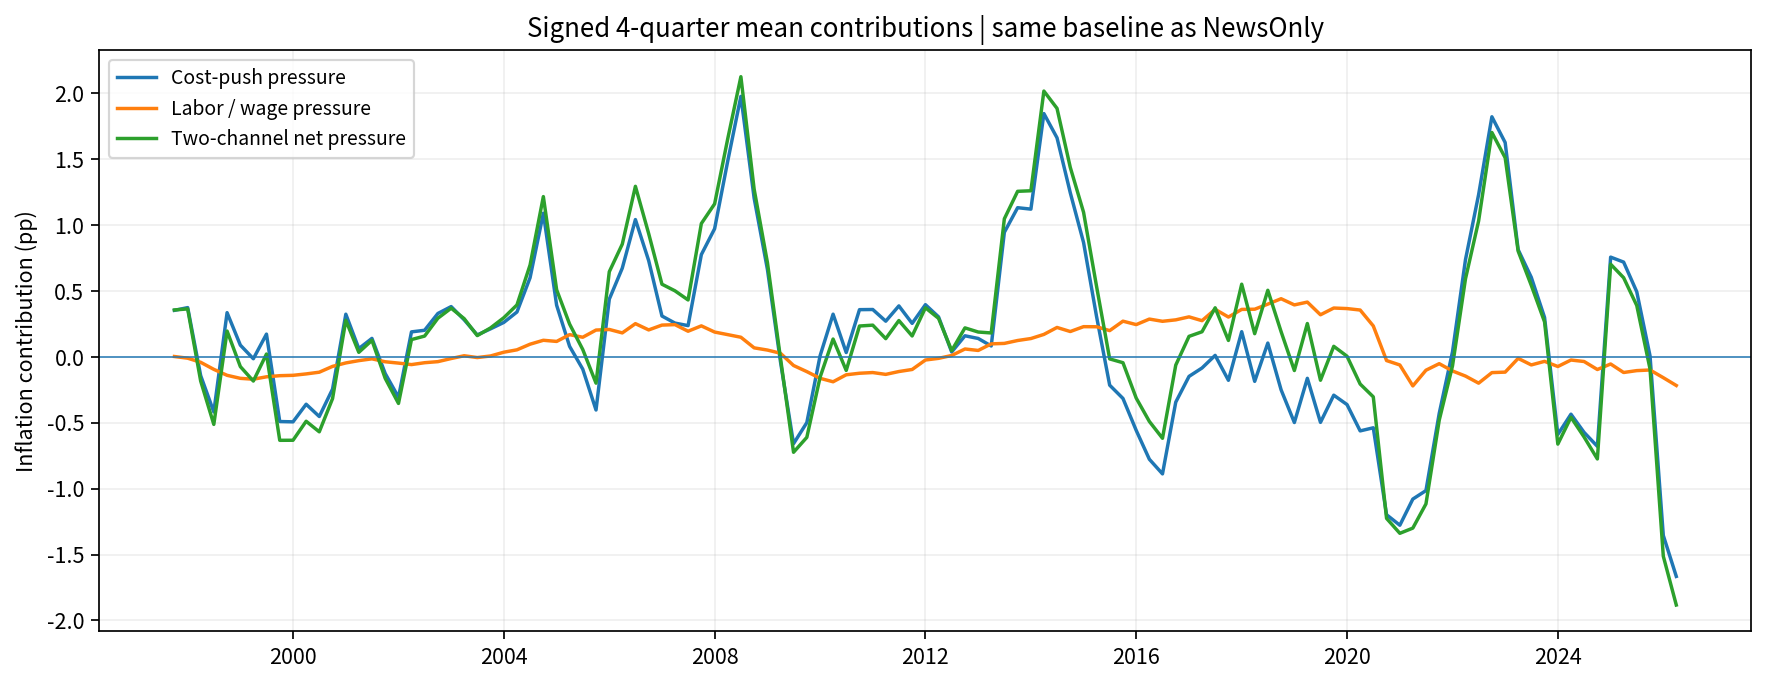

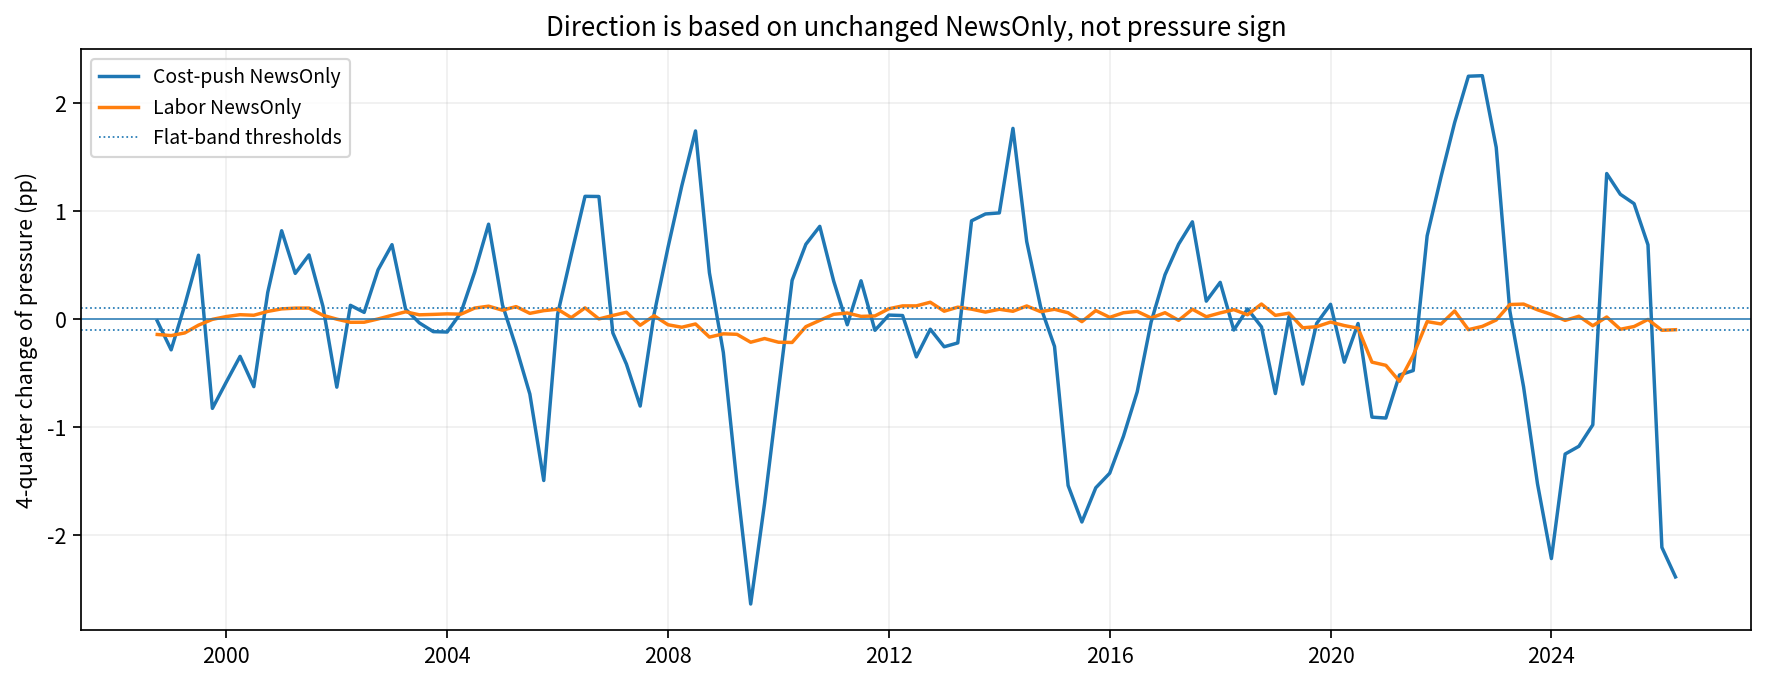

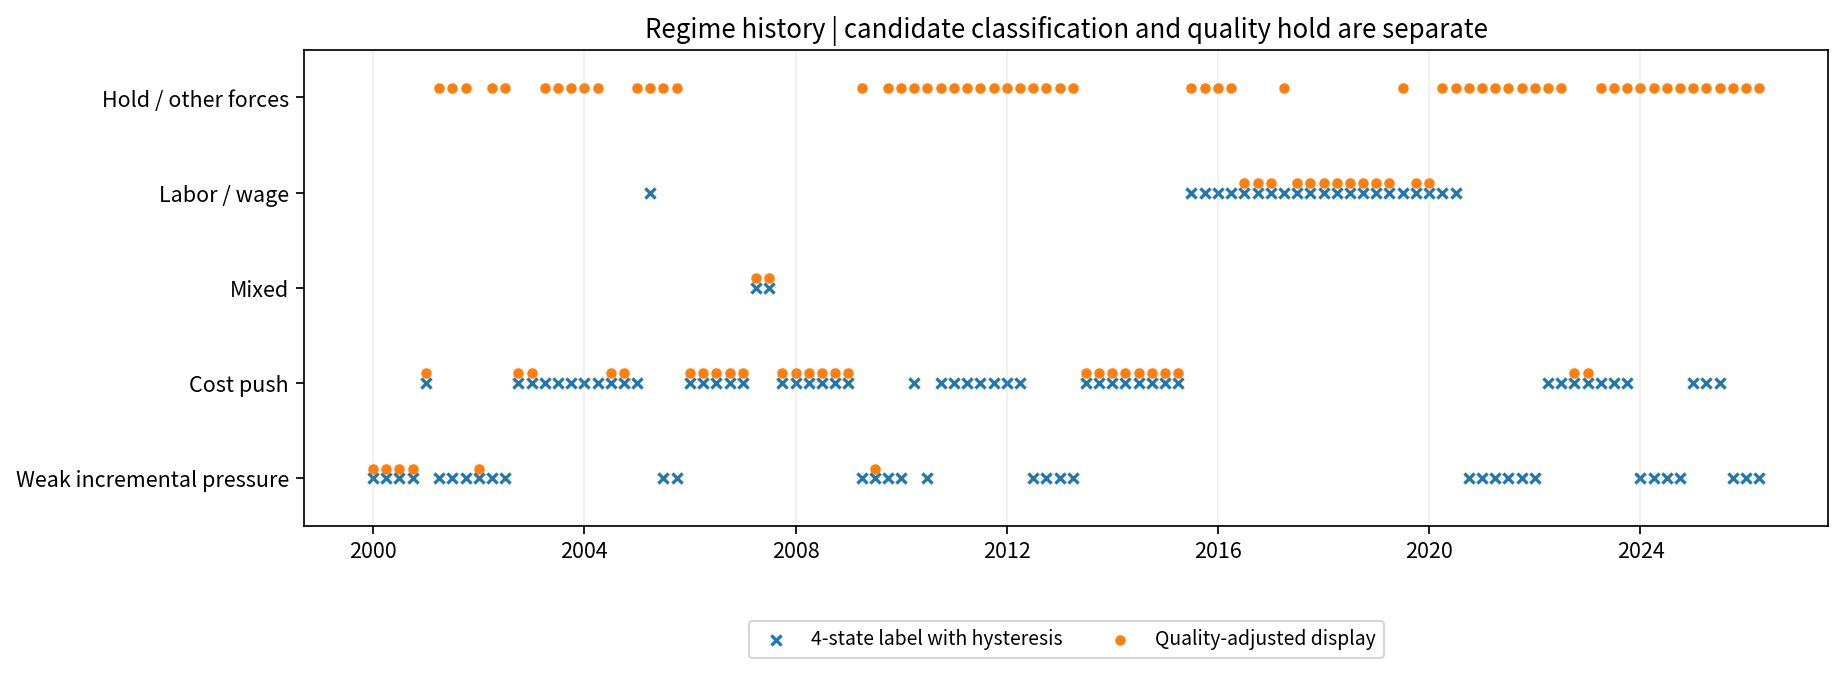

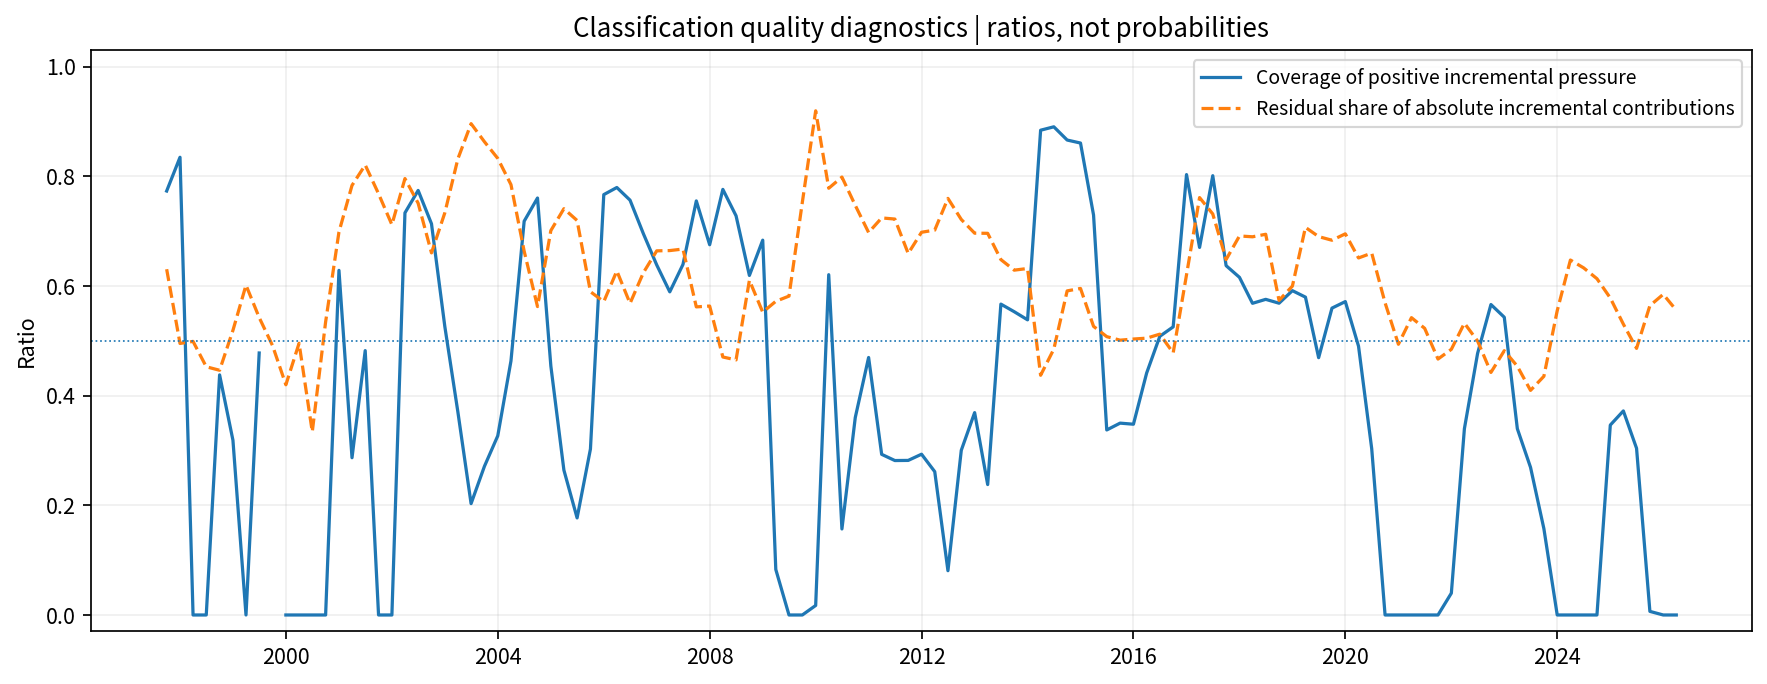

Regime report: /mnt/data/BB_PA_QualityGate_Ablation/outputs/runs/_inprogress_20261014T223551_112148/results/regimes/report.html


In [32]:
import html as _reg_html
import base64 as _reg_base64

def reg_plot(fig,filename):
    fig.tight_layout()
    fig.savefig(REG_FIG/filename,dpi=155,bbox_inches="tight")
    plt.close(fig)
    display(DisplayImage(filename=str(REG_FIG/filename)))

vis=reg_main.loc[reg_main.pressure_ready].copy()
fig,ax=plt.subplots(figsize=(11.5,4.5))
for col,label in [("pressure_cost","Cost-push pressure"),("pressure_labor","Labor / wage pressure"),
                  ("pressure_net","Two-channel net pressure")]:
    ax.plot(vis.index.to_timestamp(),vis[col],label=label,linewidth=1.6)
ax.axhline(0,linewidth=.7)
ax.set(title="Signed 4-quarter mean contributions | same baseline as NewsOnly",
       ylabel="Inflation contribution (pp)")
ax.grid(alpha=.2);ax.legend(fontsize=9)
reg_plot(fig,"01_signed_pressure.png")

fig,ax=plt.subplots(figsize=(11.5,4.5))
for col,label in [("news_cost_push","Cost-push NewsOnly"),("news_labor","Labor NewsOnly")]:
    ax.plot(vis.index.to_timestamp(),vis[col],label=label,linewidth=1.6)
ax.axhline(REG_CFG["momentum_band_pp"],linestyle=":",linewidth=.8,label="Flat-band thresholds")
ax.axhline(-REG_CFG["momentum_band_pp"],linestyle=":",linewidth=.8)
ax.axhline(0,linewidth=.7)
ax.set(title="Direction is based on unchanged NewsOnly, not pressure sign",ylabel="4-quarter change of pressure (pp)")
ax.grid(alpha=.2);ax.legend(fontsize=9)
reg_plot(fig,"02_momentum.png")

categories=["WEAK","COST_PUSH","MIXED","LABOR_WAGE","HOLD"]
catlabel=["Weak incremental pressure","Cost push","Mixed","Labor / wage","Hold / other forces"]
mapping=dict(zip(categories,range(len(categories))))
fig,ax=plt.subplots(figsize=(12,4.5))
recent=vis.loc["2000Q1":]
ax.scatter(recent.index.to_timestamp(),recent.regime_stable.map(mapping),marker="x",s=22,label="4-state label with hysteresis")
ax.scatter(recent.index.to_timestamp(),recent.regime_final.map(mapping)+.10,marker="o",s=15,label="Quality-adjusted display")
ax.set_yticks(range(len(categories)),catlabel)
ax.set_ylim(-.5,4.5);ax.set_title("Regime history | candidate classification and quality hold are separate")
ax.grid(axis="x",alpha=.2);ax.legend(loc="upper center",bbox_to_anchor=(.5,-.18),ncol=2,fontsize=9)
reg_plot(fig,"03_regime_history.png")

fig,ax=plt.subplots(figsize=(11.5,4.5))
ax.plot(vis.index.to_timestamp(),vis.pressure_coverage,label="Coverage of positive incremental pressure")
ax.plot(vis.index.to_timestamp(),vis.residual_gross_share,label="Residual share of absolute incremental contributions",linestyle="--")
ax.axhline(REG_CFG["coverage_low"],linestyle=":",linewidth=.8)
ax.set_ylim(-.03,1.03);ax.set(title="Classification quality diagnostics | ratios, not probabilities",ylabel="Ratio")
ax.grid(alpha=.2);ax.legend(fontsize=9)
reg_plot(fig,"04_quality.png")

def reg_md_table(df,index=False,digits=4):
    d=df.reset_index() if index else df.copy()
    def fmt(v):
        if isinstance(v,(float,np.floating)):return "" if pd.isna(v) else f"{v:.{digits}f}"
        return str(v).replace("|","/")
    return "\n".join(["| "+" | ".join(map(str,d.columns))+" |",
                       "| "+" | ".join(["---"]*len(d.columns))+" |"]+
                     ["| "+" | ".join(fmt(v) for v in row)+" |" for row in d.itertuples(index=False,name=None)])
def reg_h_table(df,index=False):
    return df.to_html(index=index,border=0,escape=True,float_format=lambda x:f"{x:.4f}")
def reg_image(filename,caption):
    b=_reg_base64.b64encode((REG_FIG/filename).read_bytes()).decode()
    return f'<figure><figcaption>{_reg_html.escape(caption)}</figcaption><img alt="{_reg_html.escape(caption)}" src="data:image/png;base64,{b}"></figure>'

reg_last=reg_main.iloc[-1]
reg_small_cols=["pressure_cost","pressure_labor","news_cost_push","news_labor",
                "regime_stable_label","regime_final_label","classification_quality_label","net_change_context"]
reg_recent=reg_main.loc[reg_main.pressure_ready,reg_small_cols].tail(12)
reg_latest_summary=pd.DataFrame([
    ["対象四半期",reg_last.economic_quarter],
    ["品質を反映した表示",reg_last.regime_final_label],
    ["暫定の4分類（ヒステリシス後）",reg_last.regime_stable_label],
    ["Cost push圧力（4期平均、pp）",reg_last.pressure_cost],
    ["労働需給・賃金圧力（4期平均、pp）",reg_last.pressure_labor],
    ["主2系統のネット寄与（pp）",reg_last.pressure_net],
    ["主2系統の正の追加圧力（pp）",reg_last.pressure_up_total],
    ["Cost push NewsOnly（pp）",reg_last.news_cost_push],
    ["労働需給 NewsOnly（pp）",reg_last.news_labor],
    ["Cost pushの変化",reg_last.cost_change_context],
    ["労働需給の変化",reg_last.labor_change_context],
    ["FT/PT内訳",reg_last.ftpt_detail],
    ["初期条件の4期平均（pp）",reg_last.pressure_initial_conditions],
    ["実績インフレ年率の4期平均（％）",reg_last.actual_inflation_4q],
    ["式残差寄与のネット（pp）",reg_last.residual_net],
    ["式残差寄与の絶対値合計（pp）",reg_last.residual_gross_abs],
    ["上押しカバー率",reg_last.pressure_coverage],
    ["分類品質",reg_last.classification_quality_label],
    ["理由",reg_last.reason],
],columns=["項目","値"])
reg_save(reg_latest_summary,"latest_summary_ja.csv")
reg_cases=pd.DataFrame([
    {"example":"正のCost圧力が縮小","pressure_cost":2.0,"pressure_labor":.1,"news_cost":-1.,
     "interpretation":"Cost push型・上押し縮小。newsが負でもCost型を取り消さない"},
    {"example":"負の労働圧力が改善","pressure_cost":0.,"pressure_labor":-.3,"news_cost":np.nan,
     "interpretation":"労働需給の下押し縮小は、正の賃金インフレ圧力と区別"},
    {"example":"賃金上押しが商品価格下押しで相殺","pressure_cost":-1.,"pressure_labor":.4,"news_cost":np.nan,
     "interpretation":"上押しの発生源は賃金でも、主2系統のネット寄与は負"},
])
reg_save(reg_cases,"illustrative_rules_not_observations.csv")
reg_summary_md=f"""# インフレ圧力レジーム：既存FT/PTモデルの後段表示

## 今回の結果
実行ID: {RUN_ID}。評価日: {AS_OF_DATE.date()}。主基準: {reg_id_ftpt}。
BBの係数・歴史分解・NewsOnly・資産感応度を変更せず、圧力水準を分類しました。
{reg_md_table(reg_latest_summary)}
**圧力は基準経路からの寄与です。弱い追加圧力は、低い実際のインフレ率やデフレを意味しません。**
判定保留の場合も暫定4分類と数値は残します。残差をDemand pullや財政へ強制的に割り当てません。

## 判定方法
- P_C = energy, food, shortage の符号付き寄与の合計を4期平均。
- P_W = labor の4期平均。FT/PT内訳は既に物価寄与のため、人数で再加重しない。
- A = max(P_C,0) + max(P_W,0)。群内で先に正の項だけ集めない。
- 参入A≥{REG_CFG['pressure_enter_pp']}pp、退出A<{REG_CFG['pressure_exit_pp']}pp。
- 優位な上押しの参入構成比≥{REG_CFG['dominance_enter']:.0%}、既存優位の維持構成比≥{REG_CFG['dominance_hold']:.0%}。
- 2分類どちらも優位でなければ混合。合計上押しが小さければ弱い追加圧力。
- NewsOnlyをそのまま使用し、±{REG_CFG['momentum_band_pp']}ppを横ばい帯として加速／減速を表示。
  負の圧力が正方向へ動く場合は「下押し縮小」であり、直ちにインフレ上押しとは呼ばない。
- 強度は正の追加圧力Aの{REG_CFG['pressure_enter_pp']}/{REG_CFG['intensity_mid_pp']}/{REG_CFG['intensity_high_pp']}ppで弱い／小／中／大。

## 品質
2系統の正の上押しのカバー率は、A/(A+その他の正寄与)。
その他には生産性・ダミー・各式残差の正の4期平均寄与を含め、初期条件は分離。
その他の上押し≥{REG_CFG['other_material_pp']}ppかつカバー率<{REG_CFG['coverage_low']:.0%}なら保留。
残差絶対寄与≥{REG_CFG['residual_material_pp']}ppかつ非初期条件のグロス寄与に占める比率≥{REG_CFG['residual_share_hold']:.0%}なら保留。
残差の正負相殺をネット合計だけで隠さない。
境界・相殺・モデル不一致・基準変更・閾値感応度・現行BBの制約棄却は理由付きで留保。
品質は確率・p値・将来収益の信頼度ではなく、明示的な表示ルール内の診断です。

## 直近12期
{reg_md_table(reg_recent,index=True)}

## 同一経済期間の改定と、経済状態の転換を区別
前回比較: {reg_previous_status}。既存対象期の最終ラベル変更: {reg_changed_count}期。
月次の再実行回数を四半期の連続確認回数として数えません。履歴を四半期順に毎回決定論的に処理します。
同じデータ・設定なら同じ結果。閾値設定やモデル定義変更時は、データ改定のみの比較とは表示しません。
retrospective_current_vintage=Trueであり、現在の過去ラベルは当時利用可能だったデータの判定ではありません。

## 安定性の診断
{reg_md_table(pd.DataFrame(reg_alternative_summary)) if reg_alternative_summary else '設定により省略'}
集計版・2020年基準・2期平均は別系列です。主寄与へ混ぜません。
閾値グリッドは9種類の一致率を表示し、資産収益が良い閾値を選ばない。
これは閾値感応度でありレジームの確率でも、BB生成過程を再推定した区間でもありません。

## 回帰テスト
レジーム固有検査: {len(REGIME_CHECKS)}件。既存出力との外部比較: {reg_reference_status}。
既存オブジェクトと保存済み数値ファイルの不変性を検査。
資産の同時12か月観測へラベルを結合しただけで、既存主6因子回帰の推定標本・β・BH・bootstrapは変更していません。
合成テストはルール動作の検証専用で、観測マクロ・資産データには混ぜていません。

## ファイル
regime_quarterly.csv: 主FT/PTの全期、raw/stable/final、品質、符号付き圧力、News。
latest_regime.csv/json, latest_summary_ja.csv: 最新。
pressure_and_news.csv: 比較しやすい数値表。
regime_aggregate_reference.csv, regime_2020_baseline_reference.csv: 別モデル／基準。
threshold_grid_states.csv, alternative_classification_summary.csv: 閾値・仕様感応度。
asset_observations_with_regime_tags.csv: 既存同時12か月資産観測への説明タグ。
revisions_vs_previous.csv: 前回runとの差。
validation_checks.csv, existing_output_equality.csv: 追加検査・既存出力照合。

## 出所・実装範囲
Bernanke & Blanchard (2024), An Analysis of Pandemic-Era Inflation in 11 Economies, PIIE WP24-11, pp.8–9,23,29–30。
Nakamura et al. (2024), BOJ WP24-E-1, printed pp.15–16 (PDF pp.16–17)。
歴史寄与の基準・直接間接効果・原始的な需要供給を識別しない限界を参照。
**4分類・数値閾値・ヒステリシス・品質ルールは今回合意した実装案で、文献自身のレジーム分類ではありません。**
財政型は推定していません。供給起源・純粋需要起源を完全識別したラベルではなく、
商品市場経路対労働需給・賃金経路の相対的な追加圧力を表示しています。
"""
(REG_DIR/"RESULTS_ja.md").write_text(reg_summary_md,encoding="utf-8")
reg_body=f"""
<header><p>BB / FT–PT / PRESSURE REGIMES</p><h1>インフレ圧力の類型・変化方向・判定品質</h1>
<p>BB終期 {BB_END} ｜ 評価日 {AS_OF_DATE.date()} ｜ 現行NewsOnlyと同じ長期基準</p></header>
<section class="callout"><h2>{_reg_html.escape(reg_last.regime_final_label)}</h2>
<p><strong>暫定4分類：{_reg_html.escape(reg_last.regime_stable_label)} ／ 正の追加圧力：{reg_last.pressure_intensity} ／ {reg_last.net_change_context}</strong></p>
<p>品質：{reg_last.classification_quality_label}。{_reg_html.escape(reg_last.reason)}</p>
<p>主2系統の弱い追加圧力は「低インフレ」や「デフレ」と同義ではありません。初期条件とその他の寄与を残します。</p></section>
<section><h2>最新の内訳</h2>{reg_h_table(reg_latest_summary)}</section>
<section><h2>圧力水準と変化を分離</h2>
{reg_image("01_signed_pressure.png","符号付き4期平均寄与：商品市場と労働需給")}
{reg_image("02_momentum.png","既存NewsOnly：圧力の4期差")}
<p>Cost push=energy+food+shortageを符号付きで合計。賃金を経由した二次効果は元の発生源の寄与に含まれ、
別途賃金型へ付け替えて二重加算しません。</p></section>
<section><h2>四半期レジーム</h2>{reg_image("03_regime_history.png","ヒステリシス後の4分類と、品質を踏まえた表示は別の列")}
{reg_h_table(reg_recent,True)}</section>
<section><h2>判定品質</h2>{reg_image("04_quality.png","説明範囲と残差の診断。確率ではありません")}
<p>その他の正寄与が{REG_CFG['other_material_pp']}pp以上かつカバー率{REG_CFG['coverage_low']:.0%}未満、
または大きい残差のグロス比率が{REG_CFG['residual_share_hold']:.0%}以上なら保留。
残差同士の相殺を隠さず、FT/PT残差や期待残差を需要ショックへ自動割当しません。</p></section>
<section><h2>設定と頑健性</h2>{reg_h_table(pd.DataFrame([{'setting':k,'value':v} for k,v in REG_CFG.items()]))}
{reg_h_table(pd.DataFrame(reg_alternative_summary))}
<p>2020年開始の分解、2期平均、集計賃金版は参考です。主レジームの寄与値を混ぜ合わせません。
閾値一致率は事後的な仕様感応度であって、隠れた状態の存在確率ではありません。</p></section>
<section><h2>既存分析は変更しない</h2><p>BB推定・歴史分解・NewsOnly・資産βは変更せず、この後段で分類を追加しました。
検算{len(REGIME_CHECKS)}件。保存された旧FT/PT結果との外部照合：{reg_reference_status}。</p>
<p>同時12か月の資産観測に付けたレジームタグは説明用です。未来のリターンを予測するバックテストでも、
当時の公表情報だけで再構築したラベルでもありません。</p>
<p>前回比較：{reg_previous_status}、旧対象四半期の最終ラベル改定{reg_changed_count}期。</p></section>
<footer><h2>参考と位置付け</h2><p>Bernanke &amp; Blanchard (2024), PIIE WP24-11, pp.8–9,23,29–30。
Nakamura et al. (2024), BOJ WP24-E-1, printed pp.15–16。
主2系統は商品市場経路と労働需給・賃金経路であり、純粋な需要供給ショックや財政ショックの識別ではありません。</p>
<p>分類・閾値・ヒステリシス・品質はこのプロジェクトの実装ルール。文献の推定値ではありません。</p></footer>"""
reg_css="""body{max-width:1130px;margin:auto;padding:32px 26px;font-family:-apple-system,BlinkMacSystemFont,"Segoe UI","Noto Sans JP",sans-serif;line-height:1.75;color:#203343}
header{border-bottom:4px solid #264e63;padding-bottom:20px}h1{font-size:30px;line-height:1.45}h2{font-size:23px;margin-top:28px}.callout{background:#f1f4f6;border-left:4px solid #496779;padding:14px 24px}
section{margin:30px 0}table{border-collapse:collapse;display:block;max-width:100%;overflow:auto;font-size:12px}td,th{padding:8px 10px;border-bottom:1px solid #d8dfe4;text-align:right}
th{background:#edf2f6}td:first-child,th:first-child{text-align:left}td{max-width:780px;overflow-wrap:anywhere}figure{margin:25px 0}figcaption{font-weight:600}img{max-width:100%;height:auto}footer{border-top:2px solid #264e63;margin-top:30px;font-size:13px}"""
(REG_DIR/"report.html").write_text('<!doctype html><html lang="ja"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>BBインフレ圧力レジーム</title><style>'+reg_css+"</style><body>"+reg_body+"</body></html>",encoding="utf-8")

def reg_publish_links():
    # 既存レポートの内容は残し、案内だけを追加。係数・News・資産CSVは触らない。
    for relative in ["report.html","ftpt/report.html"]:
        path=RESULT_DIR/relative
        if not path.exists():continue
        href="regimes/report.html" if relative=="report.html" else "../regimes/report.html"
        section=f'<section style="border-left:4px solid #496779;background:#f1f4f6;padding:16px 22px"><h2>追加：インフレ圧力レジーム</h2><p><strong>{_reg_html.escape(reg_last.display_label)}</strong><br>暫定4分類：{_reg_html.escape(reg_last.regime_stable_label)}。{_reg_html.escape(reg_last.net_change_context)}。</p><p>{_reg_html.escape(reg_last.reason)}</p><p><a href="{href}">レジーム詳細レポート</a>。既存のBB・NewsOnly・感応度は変更していません。</p></section>'
        text=path.read_text(encoding="utf-8")
        if "<body>" not in text:raise ValueError("既存レポートのbodyを確認できません")
        path.write_text(text.replace("<body>","<body>"+section,1),encoding="utf-8")
    path=RESULT_DIR/"RESULTS_ja.md"
    if path.exists():
        section=f"# 追加：インフレ圧力レジーム\n{reg_last.economic_quarter}: **{reg_last.display_label}**。\n暫定4分類は{reg_last.regime_stable_label}。{reg_last.net_change_context}。\n{reg_last.reason}。\n詳細はregimes/RESULTS_ja.md。以下の既存分析結果は変更していません。\n\n---\n\n"
        path.write_text(section+path.read_text(encoding="utf-8"),encoding="utf-8")
reg_json({"quarter":str(reg_main.index[-1]),"baseline_id":reg_id_ftpt,"settings_hash":REG_CFG_HASH,
          "raw":reg_last.regime_raw,"stable":reg_last.regime_stable,"final":reg_last.regime_final,
          "quality":reg_last.classification_quality,"previous_status":reg_previous_status,
          "checks":len(REGIME_CHECKS)},REG_DIR/"execution_summary.json")
print("Regime report:",REG_DIR/"report.html")

## 19．インフレ圧力 × 資産選定：同時感応度と将来検証を分ける
この追加部分は既存BB・FT/PT・NewsOnly・レジーム値を変えず、**分析表を別フォルダへ追加**します。

1. **同時感応度**：現在の符号付き4期平均圧力と、従来と同じ同時12か月リターンを回帰／偏相関分析。
2. **状態別実績**：4分類と品質保留を区別し、平均超過リターン、勝率、観測数・連続エピソード数を表示。
3. **将来リターン検証**：圧力・NewsOnlyを時点ごとに作り直し、仮定した公表ラグ後の将来1/2/4四半期を評価。
4. **投資候補表**：感応度の大きさ・頑健性と、将来リターンの検証実績を別列にする。
   **同時感応度が正であることを、期待超過リターンが正であることと同一視しない。**

主比較ベンチマークは既存16セクターの月次リバランスEQW。
「超過」は主にEQW対比のアクティブリターンであり、リスクフリー超過や因子調整alphaとは区別します。
同時回帰の系列・標本・GDP成長統制は従来どおり。圧力は正の部分に切らず符号付き水準を使います。
混合／弱い圧力はCostとLaborの状態名であり、別の独立な圧力変数を捏造しません。

In [33]:
import types as _pa_types
PA_CFG=dict(PRESSURE_ASSET_CFG)
PA_DIR=RESULT_DIR/"pressure_assets";PA_FIG=PA_DIR/"figures"
PA_DIR.mkdir(exist_ok=True);PA_FIG.mkdir(exist_ok=True)
PA_TESTS=[]
PA_UPSTREAM_NAMES=_reg_upstream_names+["reg_main","reg_aggregate","reg_2020","REG_CFG","coverage","asset_coverage"]
PA_BEFORE={k:reg_fingerprint(globals()[k]) for k in PA_UPSTREAM_NAMES}
PA_FILES_BEFORE={str(p.relative_to(RESULT_DIR)):sha256(p.read_bytes()) for p in RESULT_DIR.rglob("*")
                 if p.is_file() and p.suffix.lower() in [".csv",".json"] and not p.is_relative_to(PA_DIR)}
def pa_check(name,condition,detail=""):
    row={"test":name,"passed":bool(condition),"detail":str(detail)}
    PA_TESTS.append(row);check("pressure_assets_"+name,condition,detail)
def pa_save(df,name,index=False):
    save_csv(df,name,index=index,folder=PA_DIR)
def pa_json(obj,name):
    reg_json(obj,PA_DIR/name)
PA_MAP={
    "total":("actual_inflation_4q","news_total","総合"),
    "cost_push":("pressure_cost","news_cost_push","Cost push"),
    "labor":("pressure_labor","news_labor","労働需給・賃金"),
    "energy":("component_energy","news_energy","エネルギー"),
    "food":("component_food","news_food","食品"),
    "shortage":("component_shortage","news_shortage","供給不足"),
}
PA_CHANNELS={
    "labor_ft":("pressure_labor_ft","news_labor_ft","労働需給・FT入口"),
    "labor_pt":("pressure_labor_pt","news_labor_pt","労働需給・PT入口")}
PA_FACTORS=list(PA_MAP)
def pa_features(regimes,news_frame):
    out=pd.DataFrame(index=regimes.index)
    for key,(p,n,label) in {**PA_MAP,**PA_CHANNELS}.items():
        out["p_"+key]=regimes[p]
        out["n_"+key]=news_frame[n].reindex(out.index)
    out["g"]=news_frame.news_growth.reindex(out.index)
    for c in ["regime_raw","regime_stable","regime_final","classification_quality","reason_codes"]:
        out[c]=regimes[c]
    return out
pa_x=pa_features(reg_main,dual_news_all)
pa_ix=primary_index.intersection(pa_x[[f"p_{k}" for k in PA_FACTORS]+["g"]].dropna().index)
pa_check("same_62_or_updated_primary_dates",pa_ix.equals(primary_index))
pa_check("pressure_cost_additivity",np.allclose(pa_x.p_cost_push,pa_x.p_energy+pa_x.p_food+pa_x.p_shortage,equal_nan=True))
pa_check("pressure_labor_FTPT_additivity",np.allclose(pa_x.p_labor,pa_x.p_labor_ft+pa_x.p_labor_pt,equal_nan=True))
pa_panels={
    "level_return":assets["returns12"][current_assets].copy(),
    "active_EQW":assets["returns12"][current_assets].sub(assets["returns12"].EQW_TR,axis=0),
    "active_TOPIX_screened":assets["returns12"][current_assets].sub(assets["returns12"][BENCHMARK_COLUMN],axis=0)
}
if CASH_COLUMN in assets["returns12"]:
    pa_panels["excess_cash"]=assets["returns12"][current_assets].sub(assets["returns12"][CASH_COLUMN],axis=0)
pa_save(pa_x,"pressure_news_features_full_vintage.csv",index=True)
pa_json(PA_CFG,"settings.json")
if PA_CFG["assumed_publication_lag_q"]<1:
    raise ValueError("公表日時が未入力の代理検証では、少なくとも1四半期ラグを設定してください。")
if PA_CFG["ridge_lambda"]<=0 or PA_CFG["walkforward_min_train"]<12:
    raise ValueError("Ridge罰則は正、学習標本は少なくとも12期を指定してください")
if not PA_CFG["forward_horizons_q"] or any(int(h)!=h or h<1 for h in PA_CFG["forward_horizons_q"]):
    raise ValueError("保有期間は正の整数のリストです")
if PA_CFG["run_paper_strategy"] and 1 not in PA_CFG["forward_horizons_q"]:
    raise ValueError("紙上戦略には1四半期保有の予測が必要です")
if pd.Period(PA_CFG["recursive_start"])<pd.Period("2011Q1"):
    raise ValueError("現在の静的Google較正は2010Q4まで使うため、疑似時点計算は2011Q1以降に制限します")


### 19A．同時12か月感応度・偏相関
主式は `R_i - R_EQW = α + β P_k + γ GDP_news + ε`。
比較のため元のNewsOnly式も再計算し、保存されたFT/PT結果との一致を検査します。
`pressure_given_news`はP・同因子NewsOnly・GDPを同時に入れ、PとNの重複を分離する追加表です。
線形トレンド統制、直近2期除外、2023Q2終了を感応度として保存します。
トレンド・小標本に弱い圧力水準の相関を、単独の有意なp値だけで選定しないでください。

各回帰のβは元単位1ppと、各標本1SDの両方。偏相関は従属変数と当該説明変数の両方から統制変数を除いて計算。
BHは同じ仕様・評価基準の6因子×16資産を一つの集合として計算し、既存のBH集合は変更しません。

In [34]:
def pa_fit_asset_panel(features,Y,factors=PA_FACTORS,spec="pressure",min_n=None,idx=None):
    min_n=PA_CFG["min_full_n"] if min_n is None else min_n
    rows=[];covrows=[]
    index=features.index.intersection(Y.dropna().index)
    if idx is not None:index=index.intersection(idx)
    index=index.sort_values()
    for f in factors:
        if spec=="news":
            xkey="n_"+f;control=["g"]
        elif spec=="pressure":
            xkey="p_"+f;control=["g"]
        elif spec=="pressure_given_news":
            xkey="p_"+f;control=["n_"+f,"g"]
        elif spec=="pressure_trend":
            xkey="p_"+f;control=["g","_time_trend"]
        else:raise ValueError(spec)
        d=features.copy()
        d["_time_trend"]=(d.index.asi8-d.index.asi8.min())/4
        ix=index.intersection(d[[xkey]+control].dropna().index)
        a=d.loc[ix,[xkey]+control].to_numpy(float)
        X=np.column_stack([np.ones(len(ix)),a])
        good=(len(ix)>=min_n and np.linalg.matrix_rank(X)==X.shape[1])
        covrows.append({"factor":f,"spec":spec,"n":len(ix),"k":X.shape[1],
                        "status":"estimated" if good else "insufficient_n_or_rank",
                        "first":str(ix.min()),"last":str(ix.max())})
        if not good:continue
        sd=float(d.loc[ix,xkey].std(ddof=1))
        if sd<=1e-10:continue
        Z=np.delete(X,1,axis=1)
        yr=d.loc[ix,xkey].to_numpy()-Z@np.linalg.lstsq(Z,d.loc[ix,xkey].to_numpy(),rcond=None)[0]
        condsd=float(np.std(yr,ddof=1))
        for asset in Y:
            y=Y.loc[ix,asset]
            r4=ols_hac(y,X,4);r8=ols_hac(y,X,8)
            rows.append({"asset":asset,"factor":f,"spec":spec,"n":len(ix),"start":str(ix.min()),"end":str(ix.max()),
               "beta_per_1pp":float(r8["beta"][1]),"beta_per_1sd":float(r8["beta"][1]*sd),
               "pressure_sd":sd,"partial_sd":condsd,"partial_corr_growth":partial_corr(y,d.loc[ix,xkey],Z),
               "p_hac4":r4["p"][1],"p_hac8":r8["p"][1],
               "ci_low_1sd_hac8":r8["low"][1]*sd,"ci_high_1sd_hac8":r8["high"][1]*sd,
               "r2":r8["r2"],"condition_number":np.linalg.cond(X),"xkey":xkey,
               "return_mean":float(y.mean()),
               "interpretation":"contemporaneous association; not expected future alpha"})
    return pd.DataFrame(rows),pd.DataFrame(covrows)

pa_tables=[];pa_cov=[]
for kind,Y in pa_panels.items():
    for spec in ["pressure","news","pressure_given_news","pressure_trend"]:
        df,cover=pa_fit_asset_panel(pa_x,Y,spec=spec,idx=pa_ix)
        df["return_kind"]=kind;cover["return_kind"]=kind
        pa_tables.append(df);pa_cov.append(cover)
pa_sens=pd.concat(pa_tables,ignore_index=True)
pa_sens["q_bh_panel"]=pa_sens.groupby(["return_kind","spec"]).p_hac8.transform(bh_adjust)
pa_sens["rank_partial"]=pa_sens.groupby(["return_kind","spec","factor"]).partial_corr_growth.rank(ascending=False,method="min")
pa_save(pa_sens,"pressure_sensitivity_all.csv")
pa_save(pd.concat(pa_cov,ignore_index=True),"pressure_sensitivity_coverage.csv")

# 元FT/PT NewsOnly出力との数値照合
old=dual_main[["return_kind","asset","factor","partial_corr_growth","beta_per_1pp","p_hac8"]].copy()
old["factor"]=old.factor.map({v[1]:k for k,v in PA_MAP.items()})
test=pa_sens.query("spec=='news'").merge(old,on=["return_kind","asset","factor"],suffixes=("_new","_old"),validate="one_to_one")
pa_check("news_reference_row_count",len(test)==len(dual_main))
for col in ["partial_corr_growth","beta_per_1pp","p_hac8"]:
    err=float((test[col+"_new"]-test[col+"_old"]).abs().max())
    pa_check("news_unchanged_"+col,err<1e-9,err)
pa_save(test,"existing_news_regression_check.csv")

# 既定の期間感応度。平滑化やBB係数の推定終期を変えるテストではない。
robust=[]
for label,cut in [("exclude_last2",ASSET_END-2),("through2023Q2",pd.Period("2023Q2"))]:
    for kind,Y in pa_panels.items():
        df,cover=pa_fit_asset_panel(pa_x,Y,spec="pressure",idx=pa_ix[pa_ix<=cut])
        df["return_kind"]=kind;df["sample"]=label;robust.append(df)
pa_robust=pd.concat(robust,ignore_index=True)
pa_robust["q_bh_panel"]=pa_robust.groupby(["sample","return_kind"]).p_hac8.transform(bh_adjust)
pa_save(pa_robust,"pressure_sensitivity_robustness.csv")

# 2つの独立な主群だけを共同回帰。総合・Cost・部品を同時に入れる恒等的多重共線性は避ける。
joint=[]
for kind,Y in pa_panels.items():
    ix=pa_ix.intersection(Y.dropna().index)
    d=pa_x.loc[ix];X=np.column_stack([np.ones(len(ix)),d.p_cost_push,d.p_labor,d.g])
    if len(ix)>=PA_CFG["min_full_n"] and np.linalg.matrix_rank(X)==4:
        for asset in Y:
            fit=ols_hac(Y.loc[ix,asset],X,8)
            for j,f in enumerate(["cost_push","labor"],1):
                joint.append({"return_kind":kind,"asset":asset,"factor":f,"n":len(ix),
                              "beta_per_1pp":fit["beta"][j],"p_hac8":fit["p"][j],
                              "partial_corr":partial_corr(Y.loc[ix,asset],X[:,j],np.delete(X,j,axis=1))})
pa_joint=pd.DataFrame(joint)
if len(pa_joint):pa_joint["q_bh_panel"]=pa_joint.groupby("return_kind").p_hac8.transform(bh_adjust)
pa_save(pa_joint,"joint_cost_labor_pressure.csv")
channel=[]
for kind,Y in pa_panels.items():
    df,_=pa_fit_asset_panel(pa_x,Y,factors=list(PA_CHANNELS),spec="pressure",idx=pa_ix)
    df["return_kind"]=kind;channel.append(df)
pa_channels=pd.concat(channel,ignore_index=True)
pa_channels["q_bh_channels"]=pa_channels.groupby("return_kind").p_hac8.transform(bh_adjust)
pa_save(pa_channels,"pressure_FT_PT_channels_exploratory.csv")
display(pa_sens.query("return_kind=='active_EQW' and spec=='pressure'")[["asset","factor","partial_corr_growth","beta_per_1sd","q_bh_panel"]])

,asset,factor,partial_corr_growth,beta_per_1sd,q_bh_panel
384,食品,total,-0.254687,-2.876350,0.416392
385,エネルギー資源,total,0.326024,6.749702,0.063840
386,建設・資材,total,0.036878,0.251516,0.960581
387,素材・化学,total,-0.565157,-5.444867,0.002848
388,医薬品,total,-0.377900,-5.377490,0.063840
...,...,...,...,...,...
475,運輸・物流,shortage,0.062642,0.695216,0.830921
476,小売,shortage,0.207415,2.407745,0.410389
477,銀行,shortage,0.107924,1.661300,0.786552
478,金融（除く銀行）,shortage,-0.013412,-0.173651,0.966984


### 19B．不確実性・レジーム別の標本と平均超過リターン
8四半期の連続ブロックを、圧力・成長統制・全資産へ同時に再標本化します。
欠損四半期を繋げて1つのブロックにはしません。区間は固定したBB圧力に条件付きです。

レジーム名を1/2/3/4の連続変数として回帰しません。
当期レジーム別の平均超過リターンは、当該期間に投資して得られた事後的な条件付き平均で、将来の期待値ではありません。
主4分類（stable）と品質付き最終分類（final）を分け、サンプル不足・エピソード不足なら未推定と明示します。

In [35]:
def pa_pressure_bootstrap(features,Y,factors=PA_FACTORS,reps=999,length=8):
    index=pa_ix.intersection(Y.dropna().index).intersection(features[[f"p_{f}" for f in factors]+["g"]].dropna().index)
    n=len(index);cols=list(Y);out=[];accepted=[]
    starts=[i for i in range(n-length+1) if np.all(np.diff(index[i:i+length].asi8)==1)]
    if n<PA_CFG["min_full_n"] or not starts:return pd.DataFrame(),pd.DataFrame()
    for fj,f in enumerate(factors):
        d=features.loc[index];rng=np.random.default_rng(RNG_SEED+600+fj)
        X=np.column_stack([np.ones(n),d["p_"+f],d.g]);yy=Y.loc[index].to_numpy()
        estimates=[]
        for _ in range(reps):
            ss=rng.choice(starts,size=int(np.ceil(n/length)),replace=True)
            ids=np.concatenate([np.arange(s,s+length) for s in ss])[:n]
            x=X[ids]
            if np.linalg.matrix_rank(x)==3:estimates.append(np.linalg.lstsq(x,yy[ids],rcond=None)[0][1])
        b=np.array(estimates);sd=float(d["p_"+f].std(ddof=1))
        if len(b)<.9*reps:raise ValueError("Bootstrap有効反復が不足")
        accepted.append({"factor":f,"n":n,"accepted":len(b),"reps":reps,"block_q":length,"continuous_starts":len(starts)})
        for j,a in enumerate(cols):
            lo,hi=np.quantile(b[:,j]*sd,[.025,.975])
            out.append({"factor":f,"asset":a,"n":n,"bootstrap_low_1sd":lo,"bootstrap_high_1sd":hi,
                        "bootstrap_positive_fraction":float((b[:,j]>0).mean())})
    return pd.DataFrame(out),pd.DataFrame(accepted)
pa_b=[]
if PA_CFG["run_bootstrap"]:
    accept=[]
    for kind,Y in pa_panels.items():
        b,a=pa_pressure_bootstrap(pa_x,Y,reps=PA_CFG["bootstrap_reps"],length=PA_CFG["block_q"])
        if len(b):
            b["return_kind"]=kind;a["return_kind"]=kind;pa_b.append(b);accept.append(a)
    pa_boot=pd.concat(pa_b,ignore_index=True)
    pa_save(pa_boot,"pressure_bootstrap.csv");pa_save(pd.concat(accept),"pressure_bootstrap_counts.csv")
    pa_primary=pa_sens.query("spec=='pressure'").merge(pa_boot,on=["return_kind","asset","factor","n"],validate="one_to_one")
else:pa_primary=pa_sens.query("spec=='pressure'").copy()
pa_save(pa_primary,"pressure_sensitivity_main.csv")

def pa_count_spells(index,mask):
    chosen=index[np.asarray(mask,bool)]
    return 0 if not len(chosen) else 1+int((np.diff(chosen.asi8)!=1).sum())

state_rows=[];state_cover=[];state_slopes=[]
for scheme in ["regime_stable","regime_final"]:
    states=["COST_PUSH","LABOR_WAGE","MIXED","WEAK"]+(["HOLD"] if scheme=="regime_final" else [])
    for kind,Y in pa_panels.items():
        ix=pa_ix.intersection(Y.dropna().index)
        labels=reg_main.loc[ix,scheme];g=pa_x.loc[ix,"g"]
        for state in states:
            inside=(labels==state);n=int(inside.sum());nout=len(ix)-n;spells=pa_count_spells(ix,inside)
            good=n>=PA_CFG["min_regime_n"] and nout>=PA_CFG["min_regime_n"] and spells>=PA_CFG["min_regime_spells"]
            status="exploratory_supported" if good else ("not_observed" if n==0 else "too_few_quarters_or_spells")
            state_cover.append({"scheme":scheme,"return_kind":kind,"state":state,"n":n,"n_outside":nout,"spells":spells,"status":status})
            for a in current_assets:
                y=Y.loc[ix,a];values=y.loc[inside]
                row={"scheme":scheme,"return_kind":kind,"state":state,"asset":a,"n":n,"spells":spells,"status":status,
                     "mean_active_or_level_12m_pp":values.mean(),"median_12m_pp":values.median(),
                     "positive_return_fraction":float((values>0).mean()) if n else np.nan,
                     "adjusted_state_minus_rest":np.nan,"p_difference_hac8":np.nan}
                if good:
                    X=np.column_stack([np.ones(len(ix)),inside.astype(float),g])
                    fit=ols_hac(y,X,8)
                    row.update(adjusted_state_minus_rest=fit["beta"][1],p_difference_hac8=fit["p"][1])
                state_rows.append(row)
            # 条件付き傾きはさらに観測数を要求。データ不足で無理に回帰しない。
            if n>=PA_CFG["min_state_slope_n"] and spells>=PA_CFG["min_regime_spells"]:
                d,_=pa_fit_asset_panel(pa_x,Y,spec="pressure",idx=ix[inside],min_n=PA_CFG["min_state_slope_n"])
                d["state"]=state;d["scheme"]=scheme;d["return_kind"]=kind;state_slopes.append(d)
pa_state=pd.DataFrame(state_rows)
pa_state["q_state_panel"]=pa_state.groupby(["scheme","return_kind"]).p_difference_hac8.transform(bh_adjust)
pa_save(pa_state,"regime_conditional_return_statistics.csv")
pa_save(pd.DataFrame(state_cover),"regime_sample_support.csv")
if state_slopes:
    state_slope=pd.concat(state_slopes,ignore_index=True)
    state_slope["q_bh_panel"]=state_slope.groupby(["scheme","return_kind","state"]).p_hac8.transform(bh_adjust)
else:
    state_slope=pd.DataFrame(columns=["scheme","return_kind","state","asset","factor","n","status"])
pa_save(state_slope,"within_regime_pressure_slopes_exploratory.csv")

# 事後的な感応度マップ：運用候補と断定しない。
sensmap=pa_primary.query("return_kind=='active_EQW'").copy()
aux=pa_sens.query("return_kind=='active_EQW' and spec=='pressure_given_news'")[["asset","factor","partial_corr_growth","p_hac8"]]
sensmap=sensmap.merge(aux,on=["asset","factor"],suffixes=("","_given_news"))
aux=pa_sens.query("return_kind=='active_EQW' and spec=='pressure_trend'")[["asset","factor","partial_corr_growth","p_hac8"]]
sensmap=sensmap.merge(aux,on=["asset","factor"],suffixes=("","_trend"))
endtest=pa_robust.query("return_kind=='active_EQW' and sample=='exclude_last2'")[["asset","factor","partial_corr_growth"]]
sensmap=sensmap.merge(endtest,on=["asset","factor"],suffixes=("","_exlast2"))
sensmap["same_direction_trend"]=np.sign(sensmap.partial_corr_growth)==np.sign(sensmap.partial_corr_growth_trend)
sensmap["same_direction_exlast2"]=np.sign(sensmap.partial_corr_growth)==np.sign(sensmap.partial_corr_growth_exlast2)
if "bootstrap_low_1sd" in sensmap:
    sensmap["bootstrap_excludes0"]=(sensmap.bootstrap_low_1sd>0)|(sensmap.bootstrap_high_1sd<0)
else:sensmap["bootstrap_excludes0"]=False
sensmap["robust_contemporaneous_candidate"]=(sensmap.q_bh_panel<PA_CFG["candidate_q"])&sensmap.same_direction_trend&sensmap.same_direction_exlast2&sensmap.bootstrap_excludes0
sensmap["usage"]="exposure/association shortlist only; not expected excess-return forecast"
pa_save(sensmap,"pressure_exposure_candidate_map.csv")
display(pd.DataFrame(state_cover).query("return_kind=='active_EQW'"))

,scheme,return_kind,state,n,n_outside,spells,status
4,regime_stable,active_EQW,COST_PUSH,24,38,4,exploratory_supported
5,regime_stable,active_EQW,LABOR_WAGE,21,41,1,too_few_quarters_or_spells
6,regime_stable,active_EQW,MIXED,0,62,0,not_observed
7,regime_stable,active_EQW,WEAK,17,45,4,exploratory_supported
17,regime_final,active_EQW,COST_PUSH,10,52,2,too_few_quarters_or_spells
18,regime_final,active_EQW,LABOR_WAGE,13,49,3,exploratory_supported
19,regime_final,active_EQW,MIXED,0,62,0,not_observed
20,regime_final,active_EQW,WEAK,0,62,0,not_observed
21,regime_final,active_EQW,HOLD,39,23,6,exploratory_supported


### 19C．将来超過リターンのための時点別特徴量
最新の全標本BBから作った過去圧力を、そのまま過去の予測変数として扱いません。
各四半期qで原月次をq末まで切り、STL・賃金・BB5式・歴史分解を**別計算**します。
前処理の税接続アンカーがqより後なら、継ぎ足しがまだ発生しないq末へだけ置き換え、未来の値の参照を避けます。
この処理は主BBの関数・データを変更しない独立コピーで実行します。

ただし、**原統計は最新ビンテージ、企業期待・Google照会・公式季調も過去改定を含みます**。
ゆえに名称は `recursive_current_vintage`、真のリアルタイム／純粋OOSとは呼びません。
公表時刻の履歴はないため、既定ではqの圧力をq+1の四半期末に利用できたと仮定し、
q+2以降のリターンを対象にします。この1期ラグは検証上の仮定であり、全系列の公表完了を保証しません。
公開済みスナップショットの蓄積も別に行い、合成した過去のavailable_atは記録しません。

In [36]:
def pa_prefix_reconstruct(cutoff):
    q=pd.Period(cutoff,freq="Q");month=q.asfreq("M","end")
    local_cfg=dict(CFG)
    original_anchor=pd.Period(CFG["tax_anchor"],freq="M")
    # qが税接続開始前なら後続接続はない。既存関数の未来日参照だけをローカルに解消する。
    local_cfg["tax_anchor"]=str(min(original_anchor,month))
    env=dict(build_reconstruction.__globals__)
    env.update(M=M.loc[:month].copy(),Q=Q.loc[:q].copy(),CFG=local_cfg)
    fn=_pa_types.FunctionType(build_reconstruction.__code__,env,"prefix_build",
                              build_reconstruction.__defaults__,build_reconstruction.__closure__)
    fn.__kwdefaults__=dict(build_reconstruction.__kwdefaults__ or {})
    r,dm,dq,meta=fn(str(q),growth_method=CFG["growth"])
    r["cf1"]=Q.loc[:q,"firm_expectation_1y"].reindex(r.index)
    r["cf10"]=Q.loc[:q,f"firm_expectation_{long_year}y"].reindex(r.index)
    r["diffcpicf"]=r.gcpi.rolling(4,min_periods=4).mean()-r.cf1.shift(4)
    data=r[BASE_VARS+["dummyq2_2020","dummyq3_2020"]].join(dq[["gw_ft","gw_pt","weight_ft_lagged"]])
    if data.loc[BB_START:q].isna().any().any():raise ValueError("prefix BB input gap")
    fits=fit_ftpt_system(data,start=BB_START,end=str(q),price_productivity=CFG["price_productivity"])
    h,hm=ftpt_history(fits,data,NEWS_HISTORY_START,str(q),NEWS_MEAN_START)
    gg=Q.loc[:q,["gdp_real_sa_annualized"]].rename(columns={"gdp_real_sa_annualized":"real_gdp"})
    gg["growth_yoy_pct"]=100*(gg.real_gdp/gg.real_gdp.shift(4)-1)
    gg["news_growth"]=gg.growth_yoy_pct.diff(4)
    nw=ftpt_news(h["gcpi"],gg,"FIRM_1_"+str(long_year))
    rp=reg_pressure_frame(h["gcpi"],FTPT_PARTS,REG_CFG,"FTPT_recursive",reg_id_ftpt,
                          (q+PA_CFG["assumed_publication_lag_q"]).end_time)
    for col in ["news_cost_push","news_labor","news_total"]:rp[col]=nw[col]
    state=reg_classify_path(rp,REG_CFG)
    # 当該ビンテージ内の閾値頑健性。全標本の品質列は使わない。
    grid,_=reg_threshold_grid(rp,REG_CFG)
    state["threshold_agreement"]=grid.eq(state.regime_stable,axis=0).mean(axis=1)
    comp=compile_ftpt_system(fits)
    roots=ftpt_frozen_roots(comp,float(data.loc[q,"weight_ft_lagged"]))
    # 元関数の返値は列辞書または複数値か、定義に合わせて下で検査。
    radius=float(roots["spectral_radius"]) if isinstance(roots,dict) else float(np.max(abs(roots)))
    context={"homogeneity_rejected":any(f["homogeneity_p"]<.05 for f in fits.values()),
             "unstable_root":radius>1+1e-6,"stale_inputs":False}
    state=reg_add_labels_and_quality(state,REG_CFG,context)
    feat=pa_features(state,nw)
    row=feat.loc[q].copy()
    row["source_quarter"]=str(q);row["assumed_decision_quarter"]=str(q+PA_CFG["assumed_publication_lag_q"])
    row["fit_end"]=str(q);row["last_month_used"]=meta["last_month_used"]
    row["actual_historical_release_verified"]=False
    row["input_vintage"]="recursive_current_vintage_not_real_time"
    row["frozen_root_radius"]=radius
    row["quality_scope"]="prefix fit, residuals, threshold; no full-vintage aggregate/2020 comparator"
    for f in PA_FACTORS:
        if not np.isfinite(row["p_"+f]) or not np.isfinite(row["n_"+f]):raise ValueError("recursive feature missing")
    if q==BB_END:
        common_cols=dual_panel.columns.intersection(data.columns)
        pa_check("recursive_latest_equals_main_inputs",np.allclose(data[common_cols].to_numpy(),
                  dual_panel[common_cols].to_numpy(),equal_nan=True,atol=1e-8))
        for f in PA_FACTORS:
            pa_check("recursive_latest_pressure_equal_"+f,abs(row["p_"+f]-pa_x.loc[q,"p_"+f])<1e-8)
    return row,{"quarter":str(q),"status":"success","fit_n":fits["gw_ft"]["n"],
                "last_month_used":meta["last_month_used"],"radius":radius,
                "tax_anchor_before_extension":local_cfg["tax_anchor"],"inference":"latest vintage prefix only"}

pa_recursive_rows=[];pa_recursive_log=[]
pa_recursive_periods=pd.period_range(max(pd.Period(PA_CFG["recursive_start"]),pa_ix.min()),BB_END,freq="Q")
if PA_CFG["run_recursive_predictors"]:
    for q in pa_recursive_periods:
        try:
            row,log=pa_prefix_reconstruct(q)
            pa_recursive_rows.append(row);pa_recursive_log.append(log)
        except (ValueError,AssertionError,np.linalg.LinAlgError) as e:
            pa_recursive_log.append({"quarter":str(q),"status":"failed_not_imputed","reason":str(e)})
    if not pa_recursive_rows:raise ValueError("Recursive特徴量を作成できません")
    pa_recursive=pd.DataFrame(pa_recursive_rows)
    pa_recursive.index=pd.PeriodIndex(pa_recursive.source_quarter,freq="Q",name="quarter")
    pa_recursive=pa_recursive.reindex(pa_recursive_periods)
    pa_recursive.index.name="quarter"
    pa_save(pa_recursive,"recursive_current_vintage_features.csv",index=True)
    pa_save(pd.DataFrame(pa_recursive_log),"recursive_feature_audit.csv")
else:
    pa_recursive=pd.DataFrame()
    pa_json({"status":"disabled","reason":"forward investment inference not executed"},"recursive_disabled.json")

### 19D．将来リターン・予測回帰・拡大型検証
将来リターンは「仮定した利用可能四半期末」の**次の月以降**で複利計算します。
例：qの圧力をq+1末に知る仮定、1四半期先のリターンはq+2の3か月です。
GDPは同じqの既知と仮定した値を統制し、将来の実績GDPを予測式に投入しません。

既定予測モデルは全レジームでプールし、連続圧力とNewsOnlyを用います。レジームごとの短い標本へ無理に分割しません。
各予測時点の学習には、保有期間が既に終了したリターンのみを使用。
平均・標準偏差は学習区間だけから計算します。Ridge強度は事前固定で、全期間の収益でチューニングしません。
評価対象は1/2/4四半期。主な運用比較は非重複1四半期です。
比較基準は、その時点までの平均超過リターンと、NewsOnly予測です。

In [37]:
def pa_forward_returns(monthly,eqw,origins,lag,h):
    if lag<1 or h<1:raise ValueError("公表ラグ・保有期間の設定")
    rows={};bounds=[]
    for q in origins:
        decision=q+lag
        months=pd.period_range(decision.asfreq("M","end")+1,(decision+h).asfreq("M","end"),freq="M")
        sample=monthly.reindex(months)
        r=100*np.expm1(np.log1p(sample).sum(axis=0,min_count=3*h))
        e=eqw.reindex(months)
        eq=100*np.expm1(np.log1p(e).sum(min_count=3*h))
        r["EQW_TR"]=eq;rows[q]=r
        bounds.append({"source_quarter":str(q),"decision_quarter_assumed":str(decision),
                       "return_start_month":str(months.min()),"return_end_quarter":str(decision+h),
                       "horizon_q":h,"lag_q":lag,"months_required":3*h})
    out=pd.DataFrame(rows).T;out.index.name="quarter"
    return out,pd.DataFrame(bounds)

pa_monthly=assets["full_monthly"].loc[:LAST_CALENDAR_MONTH].copy()
pa_monthly=pa_monthly.mask(assets["flags"].reindex(pa_monthly.index).fillna(False))
pa_eqw_m=pa_monthly[current_assets].mean(axis=1).where(pa_monthly[current_assets].notna().all(axis=1))
pa_forward_panels={};pa_forward_tables=[];pa_forward_bounds=[]
if len(pa_recursive):
    for h in PA_CFG["forward_horizons_q"]:
        r,b=pa_forward_returns(pa_monthly,pa_eqw_m,pa_recursive.index,PA_CFG["assumed_publication_lag_q"],h)
        pa_forward_panels[h]={"active_EQW":r[current_assets].sub(r.EQW_TR,axis=0),
                              "level_return":r[current_assets],"active_TOPIX_screened":r[current_assets].sub(r[BENCHMARK_COLUMN],axis=0)}
        if CASH_COLUMN in r:
            pa_forward_panels[h]["excess_cash"]=r[current_assets].sub(r[CASH_COLUMN],axis=0)
        pa_forward_bounds.append(b)
        rr=r.reset_index().melt(id_vars="quarter",var_name="asset",value_name="forward_return_pp")
        rr["horizon_q"]=h;pa_forward_tables.append(rr)
    pa_save(pd.concat(pa_forward_tables),"forward_return_panel.csv")
    pa_save(pd.concat(pa_forward_bounds),"forward_return_date_audit.csv")
    rows=[];pa_forward_coverage=[]
    for h,panels in pa_forward_panels.items():
        for kind,Y in panels.items():
            for spec in ["pressure","news","pressure_given_news"]:
                d,c=pa_fit_asset_panel(pa_recursive,Y,spec=spec,min_n=PA_CFG["min_full_n"])
                if len(d):
                    d["return_kind"]=kind;d["horizon_q"]=h;rows.append(d)
                c["return_kind"]=kind;c["horizon_q"]=h;pa_forward_coverage.append(c)
    pa_forward_sens=pd.concat(rows,ignore_index=True)
    pa_forward_sens["q_bh_panel"]=pa_forward_sens.groupby(["return_kind","horizon_q","spec"]).p_hac8.transform(bh_adjust)
    pa_forward_sens["scope"]="lead-return association with prefix-estimated latest-vintage factors; not real-time alpha evidence"
    pa_save(pa_forward_sens,"forward_sensitivity_pseudo_realtime.csv")
    pa_save(pd.concat(pa_forward_coverage),"forward_sensitivity_coverage.csv")
else:pa_forward_sens=pd.DataFrame()

def pa_ridge_train_predict(X,y,xnow,penalty):
    xa=np.asarray(X,float);yv=np.asarray(y,float);xn=np.asarray(xnow,float)
    means=xa.mean(axis=0);sd=xa.std(axis=0,ddof=1)
    valid=np.isfinite(sd)&(sd>1e-10)
    z=(xa[:,valid]-means[valid])/sd[valid]
    znow=(xn[valid]-means[valid])/sd[valid]
    ym=yv.mean(axis=0)
    b=np.linalg.solve(z.T@z+penalty*np.eye(z.shape[1]),z.T@(yv-ym))
    return ym+znow@b,ym,valid

PA_PREDICTORS={
    "pressure_only":["p_cost_push","p_labor","g"],
    "news_only":["n_cost_push","n_labor","g"],
    "pressure_and_news":["p_cost_push","p_labor","n_cost_push","n_labor","g"],
}
for key in PA_FACTORS:PA_PREDICTORS["factor_"+key]=["p_"+key,"n_"+key,"g"]
pa_wf_rows=[];pa_trainlog=[]
if len(pa_recursive):
    for h,panels in pa_forward_panels.items():
        yall=panels["active_EQW"]
        for model_name,fields in PA_PREDICTORS.items():
            d=pa_recursive[fields]
            for q in d.index:
                if d.loc[q].isna().any():continue
                # 学習ラベルの終期 u+lag+h <= 現在の仮定意思決定日 q+lag
                train=d.index[(d.index+h<=q)]
                train=train.intersection(d.dropna().index).intersection(yall.dropna().index)
                if len(train)<PA_CFG["walkforward_min_train"]:continue
                pred,base,valid=pa_ridge_train_predict(d.loc[train],yall.loc[train],d.loc[q],PA_CFG["ridge_lambda"])
                pa_check("label_matured_"+model_name+"_"+str(h)+"_"+str(q),
                         all(t+PA_CFG["assumed_publication_lag_q"]+h<=q+PA_CFG["assumed_publication_lag_q"] for t in train))
                pa_trainlog.append({"model":model_name,"horizon_q":h,"source_quarter":str(q),
                                    "train_first":str(train.min()),"train_last":str(train.max()),"train_n":len(train),
                                    "latest_label_end":str(train.max()+PA_CFG["assumed_publication_lag_q"]+h),
                                    "assumed_decision":str(q+PA_CFG["assumed_publication_lag_q"]),
                                    "features_used":int(valid.sum())})
                for j,a in enumerate(current_assets):
                    pa_wf_rows.append({"model":model_name,"horizon_q":h,"source_quarter":q,
                        "decision_quarter_assumed":q+PA_CFG["assumed_publication_lag_q"],"return_end":q+PA_CFG["assumed_publication_lag_q"]+h,
                        "asset":a,"prediction_active_pp":pred[j],"historical_mean_pp":base[j],
                        "increment_vs_mean_pp":pred[j]-base[j],"actual_active_pp":yall.loc[q,a],
                        "train_n":len(train),"regime_stable":pa_recursive.loc[q,"regime_stable"],
                        "regime_final":pa_recursive.loc[q,"regime_final"],"prefix_quality":pa_recursive.loc[q,"classification_quality"],
                        "scope":"recursive_current_vintage_pseudo_OOS; assumed publication lag; not live tradable proof"})
pa_wf=pd.DataFrame(pa_wf_rows)
pa_save(pa_wf,"walkforward_predictions_research.csv")
pa_save(pd.DataFrame(pa_trainlog),"walkforward_training_audit.csv")

pa_eval=[];pa_rank=[]
if len(pa_wf):
    evalrows=pa_wf.dropna(subset=["actual_active_pp"])
    for (model_name,h,a),d in evalrows.groupby(["model","horizon_q","asset"]):
        e=(d.actual_active_pp-d.prediction_active_pp).to_numpy()
        e0=(d.actual_active_pp-d.historical_mean_pp).to_numpy()
        mse=np.mean(e**2);mse0=np.mean(e0**2)
        pa_eval.append({"model":model_name,"horizon_q":h,"asset":a,"n_oos":len(d),
          "pseudo_oos_r2_vs_mean":1-mse/mse0 if mse0>0 else np.nan,"rmse":np.sqrt(mse),"baseline_rmse":np.sqrt(mse0),
          "forecast_realized_corr":d.prediction_active_pp.corr(d.actual_active_pp),
          "directional_hit":float((np.sign(d.prediction_active_pp)==np.sign(d.actual_active_pp)).mean()),
          "interpretation":"No statistical guarantee; latest-vintage raw data remain"})
    for (name,h,q),d in evalrows.groupby(["model","horizon_q","source_quarter"]):
        if len(d)==len(current_assets):
            pa_rank.append({"model":name,"horizon_q":h,"source_quarter":q,
                            "rank_ic":d.prediction_active_pp.corr(d.actual_active_pp,method="spearman"),
                            "mean_baseline_rank_ic":d.historical_mean_pp.corr(d.actual_active_pp,method="spearman")})
pa_eval=pd.DataFrame(pa_eval);pa_rank=pd.DataFrame(pa_rank)
pa_save(pa_eval,"walkforward_forecast_metrics.csv")
pa_save(pa_rank,"walkforward_rank_ic_by_quarter.csv")
if len(pa_rank):
    summ=pa_rank.groupby(["model","horizon_q"]).agg(n=("rank_ic","size"),mean_rank_ic=("rank_ic","mean"),
                sd_rank_ic=("rank_ic","std"),mean_baseline_rank_ic=("mean_baseline_rank_ic","mean")).reset_index()
    summ["scope"]="unadjusted descriptive IC moments, not independent observations or return Sharpe"
    pa_save(summ,"walkforward_rank_ic_summary.csv")
    display(summ)

,model,horizon_q,n,mean_rank_ic,sd_rank_ic,mean_baseline_rank_ic,scope
0,factor_cost_push,1,29,0.040467,0.419092,0.034787,"unadjusted descriptive IC moments, not indepen..."
1,factor_cost_push,2,27,0.062527,0.334586,0.049237,"unadjusted descriptive IC moments, not indepen..."
2,factor_cost_push,4,23,-0.179156,0.245736,-0.054604,"unadjusted descriptive IC moments, not indepen..."
3,factor_energy,1,29,0.062373,0.367014,0.034787,"unadjusted descriptive IC moments, not indepen..."
4,factor_energy,2,27,0.080283,0.344349,0.049237,"unadjusted descriptive IC moments, not indepen..."
5,factor_energy,4,23,-0.026471,0.366966,-0.054604,"unadjusted descriptive IC moments, not indepen..."
6,factor_food,1,29,0.065720,0.330705,0.034787,"unadjusted descriptive IC moments, not indepen..."
7,factor_food,2,27,0.033224,0.284276,0.049237,"unadjusted descriptive IC moments, not indepen..."
8,factor_food,4,23,-0.146419,0.313568,-0.054604,"unadjusted descriptive IC moments, not indepen..."
9,factor_labor,1,29,0.063185,0.391488,0.034787,"unadjusted descriptive IC moments, not indepen..."


### 19E．投資選定の診断：紙上配分と候補の条件
予測値の最大化結果を売買推奨にしません。次の紙上テストは、
1四半期ごとに最大4資産を等ウェイト、残りの月もその目標比率へ月次リバランスする固定ルールです。
予測超過リターンが正の資産が4つ未満、または当該prefixレジーム品質がlow/HOLDならEQWへ戻します。
取引コストは片道売買金額×10bp（売買額合計、one-way定義）を控除。EQWにも同じ月次リバランスコストを適用します。
リスク予算最適化や実ETFの流動性・約定検証は未実装です。参考ベンチマークは銘柄ユニバース内EQWで、指数の配当定義は未確認です。

**実運用採用ゲートは現時点では閉じます。**
過去公表ビンテージ・利用可能日時・指数定義・実投資手段が未検証だからです。
現在の研究候補と、その妥当性を確認するために残る条件を別々に保存します。

**このセルは旧3か月待ちの比較用です。新しい主日程（2か月待ち）は22節で、`schedule=`を渡して同じ関数を呼び出します。月次C案・Economic Trendの比較結果を壊さないため、旧出力を維持します。**

In [38]:
def pa_paper_backtest(predictions, *, schedule=None, monthly_returns=None, config=None):
    if schedule is not None:
        return pa2_paper_backtest(predictions, schedule,
            pa_monthly[current_assets] if monthly_returns is None else monthly_returns,
            PA2_CFG if config is None else config)
    ledgers=[];targets=[]
    y=pa_monthly[current_assets];names=["pressure_only","news_only","pressure_and_news","historical_mean","EQW"]
    for name in names:
        predname="pressure_and_news" if name in ["historical_mean","EQW"] else name
        d=predictions.query("horizon_q==1 and model==@predname")
        pre=np.repeat(1/len(current_assets),len(current_assets))
        for q,block in d.groupby("source_quarter",sort=True):
            block=block.set_index("asset").reindex(current_assets)
            decision=pd.Period(block.decision_quarter_assumed.iloc[0],freq="Q")
            months=pd.period_range(decision.asfreq("M","end")+1,(decision+1).asfreq("M","end"),freq="M")
            if y.reindex(months).isna().any().any():continue
            signal=block.historical_mean_pp if name=="historical_mean" else block.prediction_active_pp
            quality_ok=block.prefix_quality.iloc[0] not in ["low","not_available"]
            action="EQW_default"
            if name!="EQW" and (quality_ok or name=="historical_mean") and (signal>0).sum()>=PA_CFG["top_n"]:
                selected=signal.sort_values(ascending=False).iloc[:PA_CFG["top_n"]].index
                target=np.array([1/PA_CFG["top_n"] if a in selected else 0. for a in current_assets])
                action="research_top4"
            else:target=np.repeat(1/len(current_assets),len(current_assets))
            if name!="EQW" and not quality_ok and name!="historical_mean":action="EQW_quality_gate"
            for a,w in zip(current_assets,target):
                targets.append({"strategy":name,"source_quarter":str(q),"assumed_decision":str(decision),
                                "asset":a,"weight":w,"action":action,"research_only":True})
            for month in months:
                rr=y.loc[month].to_numpy()
                trade=float(np.sum(np.abs(target-pre)))
                cost=trade*PA_CFG["one_way_cost_bps"]/10000
                gross=float(target@rr)
                net=(1-cost)*(1+gross)-1
                ledgers.append({"strategy":name,"month":month,"source_quarter":q,
                   "gross_return":gross,"net_return":net,"trade_notional":trade,
                   "turnover_half_l1":trade/2,"transaction_cost_fraction":cost,"action":action})
                pre=target*(1+rr)/(1+gross)
    return pd.DataFrame(ledgers),pd.DataFrame(targets)

pa_ledger=pd.DataFrame();pa_weights=pd.DataFrame();pa_perf=pd.DataFrame()
if PA_CFG["run_paper_strategy"] and len(pa_wf):
    pa_ledger,pa_weights=pa_paper_backtest(pa_wf)
    pa_save(pa_ledger,"paper_strategy_monthly_ledger.csv")
    pa_save(pa_weights,"paper_strategy_quarterly_targets.csv")
    benchmark=pa_ledger.query("strategy=='EQW'").set_index("month").net_return
    perf=[]
    for name,d in pa_ledger.groupby("strategy"):
        r=d.set_index("month").net_return;b=benchmark.reindex(r.index);a=r-b
        wealth=(1+r).cumprod()
        # 初期資産1を含むhigh-water markでDDを計算
        peak=np.maximum.accumulate(np.r_[1.,wealth.values])[1:]
        dd=wealth.values/peak-1
        bm=(1+b).prod()
        perf.append({"strategy":name,"n_months":len(r),"first":str(r.index.min()),"last":str(r.index.max()),
            "CAGR":float(wealth.iloc[-1]**(12/len(r))-1),
            "benchmark_CAGR":float(bm**(12/len(r))-1),
            "geometric_relative_ann":float((wealth.iloc[-1]/bm)**(12/len(r))-1),
            "ann_vol":float(r.std(ddof=1)*np.sqrt(12)),
            "ann_active_mean":float(a.mean()*12),"tracking_error":float(a.std(ddof=1)*np.sqrt(12)),
            "IR":float(a.mean()/a.std(ddof=1)*np.sqrt(12)) if a.std(ddof=1)>1e-12 else np.nan,
            "max_drawdown":float(dd.min()),"skew_monthly":float(r.skew()),"kurtosis_excess":float(r.kurt()),
            "VaR95_loss_monthly":float(-r.quantile(.05)),
            "CVaR95_loss_monthly":float(-r[r<=r.quantile(.05)].mean()),
            "annual_turnover_half_l1":float(d.turnover_half_l1.mean()*12),
            "non_EQW_target_months":int((d.action=="research_top4").sum()),
            "evaluation_scope":"latest-vintage prefix, assumed quarterly release; NOT proven tradable performance"})
    pa_perf=pd.DataFrame(perf);pa_save(pa_perf,"paper_strategy_performance.csv")
    pa_check("paper_weights_long_only",pa_weights.weight.ge(0).all())
    pa_check("paper_weights_sum1",np.allclose(pa_weights.groupby(["strategy","source_quarter"]).weight.sum(),1))
    pa_check("paper_max_25pct",pa_weights.weight.max()<=1/PA_CFG["top_n"]+1e-10)
    pa_check("net_return_cost_identity",np.allclose(pa_ledger.net_return,
        (1-pa_ledger.transaction_cost_fraction)*(1+pa_ledger.gross_return)-1))
    pa_check("paper_quality_gate_no_concentration",not (
        pa_weights.query("action=='EQW_quality_gate'").groupby(["strategy","source_quarter"]).weight.max()>1/len(current_assets)+1e-10).any())

# 最新特徴は実際の今回実行日をavailable_atとする。過去qの公表日に偽ってバックフィルしない。
actual_snapshot=pa_x.loc[[BB_END]].copy()
actual_snapshot["available_at"]=datetime.now(timezone(timedelta(hours=9))).isoformat()
actual_snapshot["analysis_as_of"]=str(AS_OF_DATE.date());actual_snapshot["run_id"]=RUN_ID
actual_snapshot["baseline_id"]=reg_id_ftpt
actual_snapshot["source_quarter"]=str(BB_END);actual_snapshot["actual_snapshot"]=True
actual_snapshot=actual_snapshot.reset_index(drop=True)
archive=actual_snapshot.copy()
if PREVIOUS is not None and (PREVIOUS_DIR/"results/pressure_assets/observed_feature_archive.csv").exists():
    prior_archive=pd.read_csv(PREVIOUS_DIR/"results/pressure_assets/observed_feature_archive.csv")
    archive=pd.concat([prior_archive,archive],ignore_index=True)
archive=archive.drop_duplicates(["run_id","source_quarter"],keep="last")
pa_save(archive,"observed_feature_archive.csv")
# 現在の候補スコアは、疑似OOS検証用モデルによる診断推定。運用採用フラグとは分ける。
selection=[]
if len(pa_wf):
    for model_name in ["pressure_and_news"]+["factor_"+x for x in PA_FACTORS]:
        cur=pa_wf.query("horizon_q==1 and model==@model_name and source_quarter==@BB_END").copy()
        metric=pa_eval.query("horizon_q==1 and model==@model_name")
        cur=cur.merge(metric[["asset","n_oos","pseudo_oos_r2_vs_mean","forecast_realized_corr"]],on="asset",how="left")
        if cur.empty:continue
        cur["research_rank"]=cur.prediction_active_pp.rank(ascending=False,method="min")
        # 予測p値による全標本事後選択ではなく、研究用診断の定義を明示する。
        cur["research_forward_support"]=(cur.prediction_active_pp>0)&(cur.n_oos>=PA_CFG["min_oos_n"])&(cur.pseudo_oos_r2_vs_mean>0)
        cur["current_authoritative_regime"]=reg_main.loc[BB_END,"regime_final"]
        cur["current_quality"]=reg_main.loc[BB_END,"classification_quality"]
        cur["production_eligible"]=False
        cur["production_block_reason"]="Historical publication vintages/timestamps and tradable total-return series unverified"
        if reg_main.loc[BB_END,"regime_final"] in ["HOLD","UNAVAILABLE"]:
            cur["production_block_reason"]+="; current regime quality gate closed"
        cur["interpretation"]="forecast is conditional research estimate, not assured expected excess return"
        selection.append(cur)
pa_selection=pd.concat(selection,ignore_index=True) if selection else pd.DataFrame()
pa_save(pa_selection,"latest_research_candidates.csv")
pa_json({"production_eligible":False,"current_regime":reg_main.loc[BB_END,"regime_final"],
         "data_vintage_verified":False,"historical_release_dates_verified":False,
         "tradable_total_return_series_verified":False,"source_quarter":str(BB_END),
         "actual_run_date":str(AS_OF_DATE.date()),
         "actions_before_live":["Validate price dividends/currency and tradable instruments",
          "Accumulate or retrieve real as-of feature/data vintages and release times",
          "Evaluate forward returns at actual implementation dates",
          "Confirm independent holdout net excess returns before setting active risk limits"]},"production_gate.json")
display(pa_perf)
display(pa_selection.query("model=='pressure_and_news'")[["asset","prediction_active_pp","research_rank","pseudo_oos_r2_vs_mean","research_forward_support","production_eligible"]])

,strategy,n_months,first,last,CAGR,benchmark_CAGR,geometric_relative_ann,ann_vol,ann_active_mean,tracking_error,IR,max_drawdown,skew_monthly,kurtosis_excess,VaR95_loss_monthly,CVaR95_loss_monthly,annual_turnover_half_l1,non_EQW_target_months,evaluation_scope
0,EQW,87,2019-07,2026-09,0.161967,0.161967,0.000000,0.136039,0.000000,0.000000,NaN,-0.187592,-0.216404,1.316602,0.049809,0.073664,0.170929,0,"latest-vintage prefix, assumed quarterly relea..."
1,historical_mean,87,2019-07,2026-09,0.165598,0.161967,0.003125,0.139165,0.003612,0.067241,0.053711,-0.143236,-0.340855,1.015247,0.040175,0.075259,0.898089,87,"latest-vintage prefix, assumed quarterly relea..."
2,news_only,87,2019-07,2026-09,0.158441,0.161967,-0.003034,0.127503,-0.004155,0.036801,-0.112904,-0.188802,-0.369242,1.669039,0.043971,0.071304,1.049248,24,"latest-vintage prefix, assumed quarterly relea..."
3,pressure_and_news,87,2019-07,2026-09,0.168546,0.161967,0.005662,0.130568,0.004997,0.031820,0.157051,-0.188802,-0.220720,1.777619,0.043971,0.071304,0.979134,24,"latest-vintage prefix, assumed quarterly relea..."
4,pressure_only,87,2019-07,2026-09,0.168463,0.161967,0.005591,0.133359,0.005279,0.034823,0.151609,-0.188802,-0.181143,1.517202,0.043971,0.071304,0.978119,24,"latest-vintage prefix, assumed quarterly relea..."


,asset,prediction_active_pp,research_rank,pseudo_oos_r2_vs_mean,research_forward_support,production_eligible
0,食品,1.044401,4.0,-0.199159,False,False
1,エネルギー資源,-2.143756,13.0,-0.061780,False,False
2,建設・資材,-0.557289,11.0,-0.231731,False,False
3,素材・化学,-0.203210,10.0,-0.197520,False,False
4,医薬品,1.044377,5.0,-0.147207,False,False
5,自動車・輸送機,-3.447686,15.0,-0.124819,False,False
6,鉄鋼・非鉄,-2.430473,14.0,-0.049280,False,False
7,機械,1.493885,3.0,-0.201849,False,False
8,電機・精密,0.580359,8.0,-0.033335,False,False
9,情報通信・サービス,7.152824,1.0,0.284984,True,False


### 19F．検算・過去ファイル不変性・月次更新監査
既存オブジェクトと数値CSV/JSONをハッシュ比較し、追加分析が主BB・NewsOnly・レジームに影響しないことを確認します。
同じ入力の繰り返しでは追加結果も同一になります（実行日時・記録IDを除く）。
未来行への依存、保有リターンの終了前学習、標準化の全標本使用を単体テストで点検します。

In [39]:
# 将来リターンの窓は3hか月。意思決定四半期の月を含めず、未完了をNaNで残す。
_test_months=pd.period_range("2019-01","2021-12",freq="M")
_test_r=pd.DataFrame({"A":.01,"B":.02},index=_test_months)
_test_eq=_test_r.mean(axis=1)
_testq=pd.period_range("2019Q1","2021Q4",freq="Q")
_ft,_audit=pa_forward_returns(_test_r,_test_eq,_testq,1,1)
pa_check("forward_correct_compounding",abs(_ft.loc["2019Q1","A"]-100*((1.01)**3-1))<1e-10)
pa_check("forward_correct_start",_audit.iloc[0].return_start_month=="2019-07")
pa_check("forward_no_unobserved_fill",pd.isna(_ft.loc["2021Q4","A"]))
_changed=_test_r.copy();_changed.loc["2019-06","A"]=.40
_new,_=pa_forward_returns(_changed,_test_eq,_testq,1,1)
pa_check("forward_excludes_decision_period",abs(_new.loc["2019Q1","A"]-_ft.loc["2019Q1","A"])<1e-10)

# 既存のFWL恒等式。PとNの同時投入の偏相関計算にも適用。
tmp=pa_x.loc[pa_ix]
Z=np.column_stack([np.ones(len(tmp)),tmp.n_cost_push,tmp.g])
x=tmp.p_cost_push.to_numpy()
y=pa_panels["active_EQW"].loc[pa_ix,current_assets[0]].to_numpy()
xr=x-Z@np.linalg.lstsq(Z,x,rcond=None)[0]
yr=y-Z@np.linalg.lstsq(Z,y,rcond=None)[0]
b=float(xr@yr/(xr@xr))
bb=np.linalg.lstsq(np.column_stack([Z,x]),y,rcond=None)[0][-1]
pa_check("FWL_pressure_given_news",abs(b-bb)<1e-10)

if len(pa_recursive):
    # 将来の原データだけを大きく変更しても過去prefixの計算が不変。
    qtest=pd.Period("2014Q4")
    alt_env=dict(pa_prefix_reconstruct.__globals__)
    mtest=M.copy();qtestdata=Q.copy()
    mtest.loc[mtest.index>qtest.asfreq("M","end")]*=1.5
    qtestdata.loc[qtestdata.index>qtest]*=1.5
    alt_env.update(M=mtest,Q=qtestdata)
    fn=_pa_types.FunctionType(pa_prefix_reconstruct.__code__,alt_env,"future_perturbation",
                              pa_prefix_reconstruct.__defaults__,pa_prefix_reconstruct.__closure__)
    altrow,_=fn(qtest)
    for c in [f"p_{f}" for f in PA_FACTORS]+[f"n_{f}" for f in PA_FACTORS]:
        pa_check("prefix_does_not_use_future_"+c,abs(altrow[c]-pa_recursive.loc[qtest,c])<1e-8)
    # 最新での失敗を黙って隠さない。
    pa_check("latest_recursive_features_present",pa_recursive.loc[BB_END,[f"p_{f}" for f in PA_FACTORS]].notna().all())

# 予測正規化は学習行しか使わず、未来ラベル変更は過去予測に影響しない。
if len(pa_wf):
    e=pa_wf.query("model=='pressure_and_news' and horizon_q==1").source_quarter.min()
    fields=PA_PREDICTORS["pressure_and_news"]
    yy=pa_forward_panels[1]["active_EQW"]
    tr=pa_recursive.index[pa_recursive.index+1<=e]
    tr=tr.intersection(pa_recursive[fields].dropna().index).intersection(yy.dropna().index)
    a,_,_=pa_ridge_train_predict(pa_recursive.loc[tr,fields],yy.loc[tr],pa_recursive.loc[e,fields],PA_CFG["ridge_lambda"])
    yt=yy.copy();yt.loc[yt.index+1>e]=10000.
    b,_,_=pa_ridge_train_predict(pa_recursive.loc[tr,fields],yt.loc[tr],pa_recursive.loc[e,fields],PA_CFG["ridge_lambda"])
    pa_check("unmatured_future_targets_not_used",np.allclose(a,b,atol=1e-12,rtol=1e-12),float(np.max(abs(a-b))))

# 非観測レジームを0%リターン扱いしない。
missing_states=pd.DataFrame(state_cover).query("n==0")
if len(missing_states):
    for r in missing_states.itertuples():
        vals=pa_state.query("scheme==@r.scheme and return_kind==@r.return_kind and state==@r.state")
        pa_check("missing_state_mean_NA_"+r.scheme+r.return_kind+r.state,vals.mean_active_or_level_12m_pp.isna().all())
# 選定済みと表示するのは十分な外部条件が揃った後。現版は研究候補。
if len(pa_selection):pa_check("no_unverified_live_recommendations",not pa_selection.production_eligible.any())

pa_existing_equality=[]
for name,before in PA_BEFORE.items():
    after=reg_fingerprint(globals()[name])
    pa_check("upstream_object_unchanged_"+name,before==after)
for filename,before in PA_FILES_BEFORE.items():
    file=RESULT_DIR/filename
    after=sha256(file.read_bytes())
    pa_check("upstream_file_unchanged_"+filename,before==after)
    pa_existing_equality.append({"file":filename,"unchanged":before==after})
pa_save(pd.DataFrame(pa_existing_equality),"existing_output_equality.csv")
pa_save(pd.DataFrame(PA_TESTS),"validation_checks.csv")

# 前回追加モジュールの主要数値だけを比較（日時・スナップショットは別管理）。
pa_prev_status="first_pressure_asset_run"
if PREVIOUS is not None and (PREVIOUS_DIR/"results/pressure_assets/pressure_sensitivity_main.csv").exists():
    prevfile=PREVIOUS_DIR/"results/pressure_assets/pressure_sensitivity_main.csv"
    prev=pd.read_csv(prevfile)
    keys=["return_kind","asset","factor"]
    common_metrics=["partial_corr_growth","beta_per_1pp","beta_per_1sd","n","q_bh_panel"]
    c=prev[keys+common_metrics].merge(pa_primary[keys+common_metrics],on=keys,suffixes=("_previous","_current"))
    for k in common_metrics:c["change_"+k]=c[k+"_current"]-c[k+"_previous"]
    pa_save(c,"sensitivity_change_vs_previous.csv")
    pa_prev_status="comparison_saved"
pa_json({"status":pa_prev_status},"previous_comparison.json")
print("Pressure-asset checks passed:",len(PA_TESTS))

Pressure-asset checks passed: 979


### 19G．投資研究用レポート
全ての数値を実行結果から生成します。現在の判定保留を「買い」のシグナルへ変換しません。
研究候補は、(a)圧力が高いとき相対的に強かった資産、(b)圧力・Newsを使った将来検証が残った資産、を別々に示します。
後者も公表ビンテージ・コスト・実投資商品・独立検証が未確認なら本番採用不可と表示します。

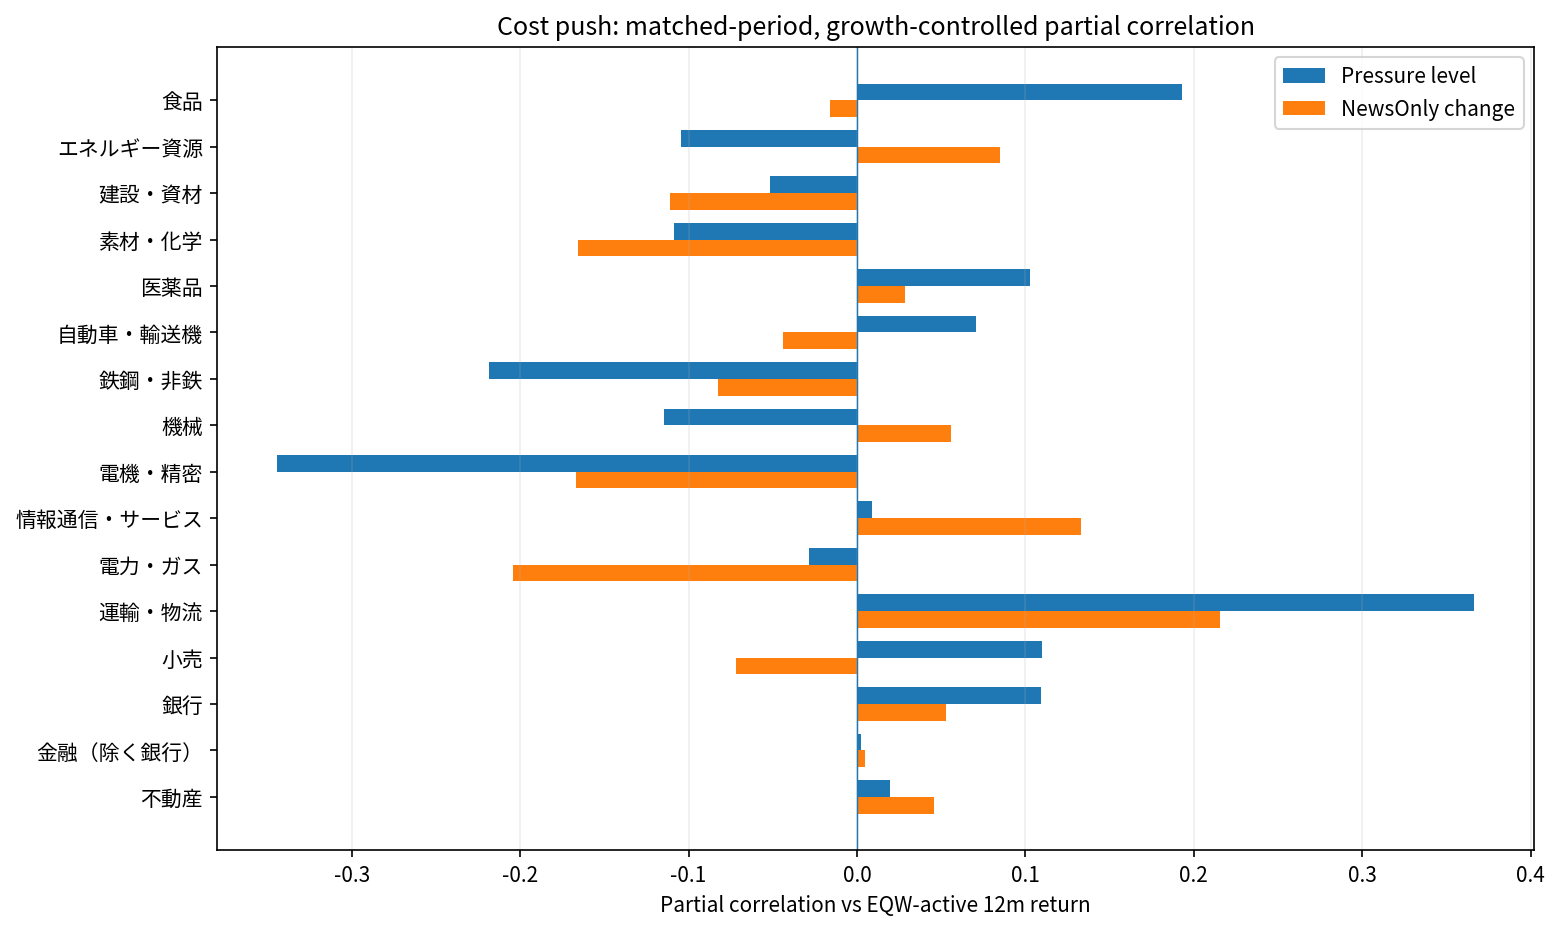

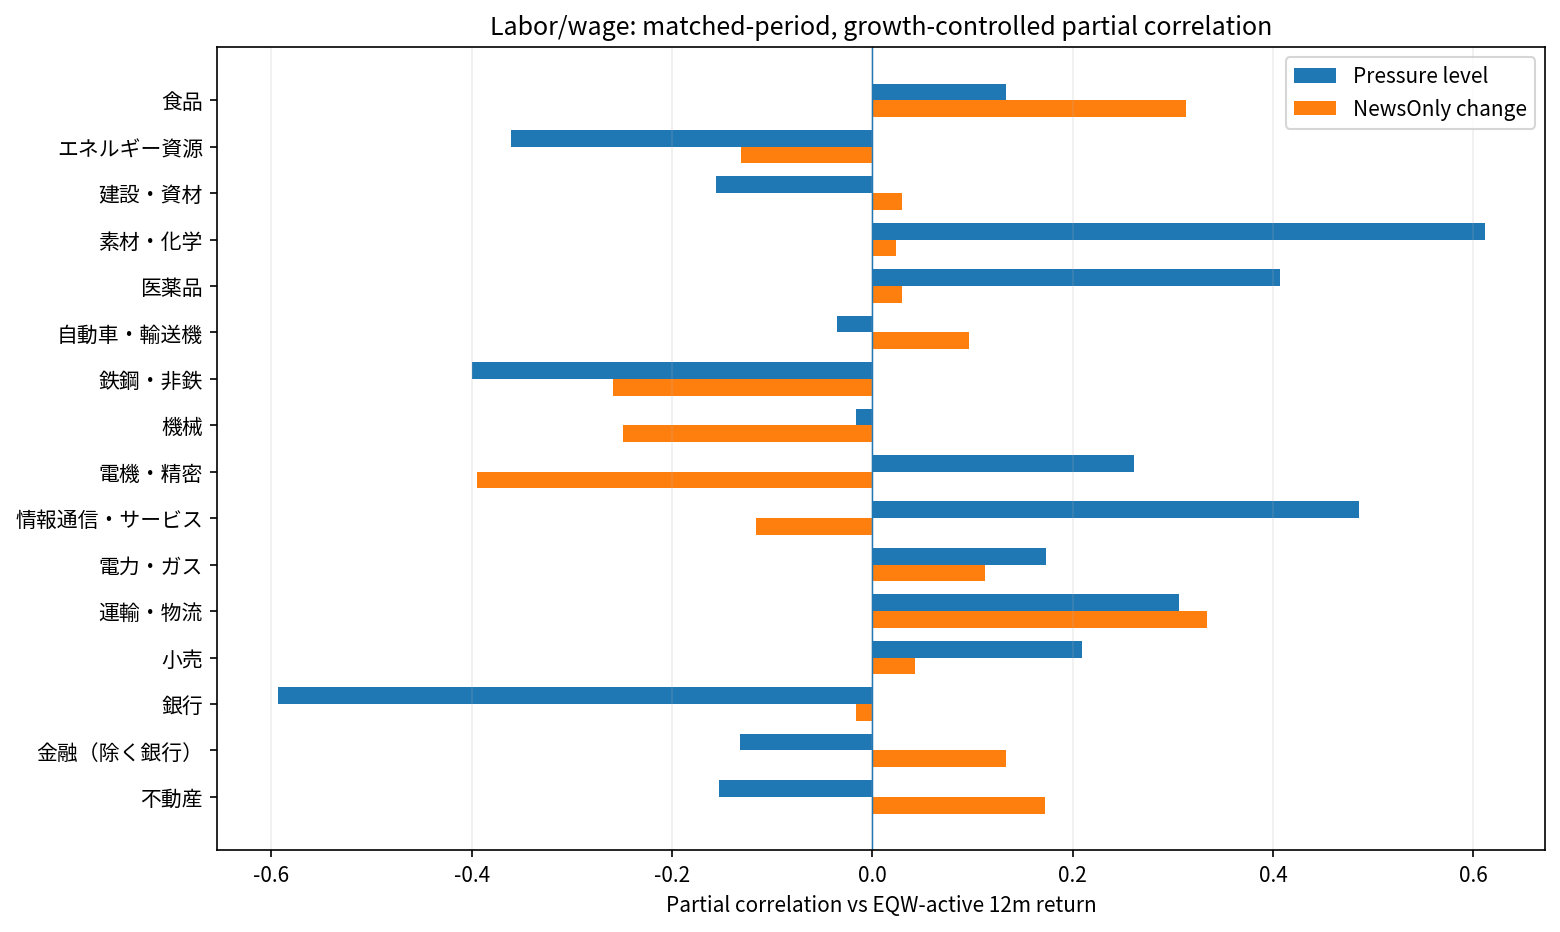

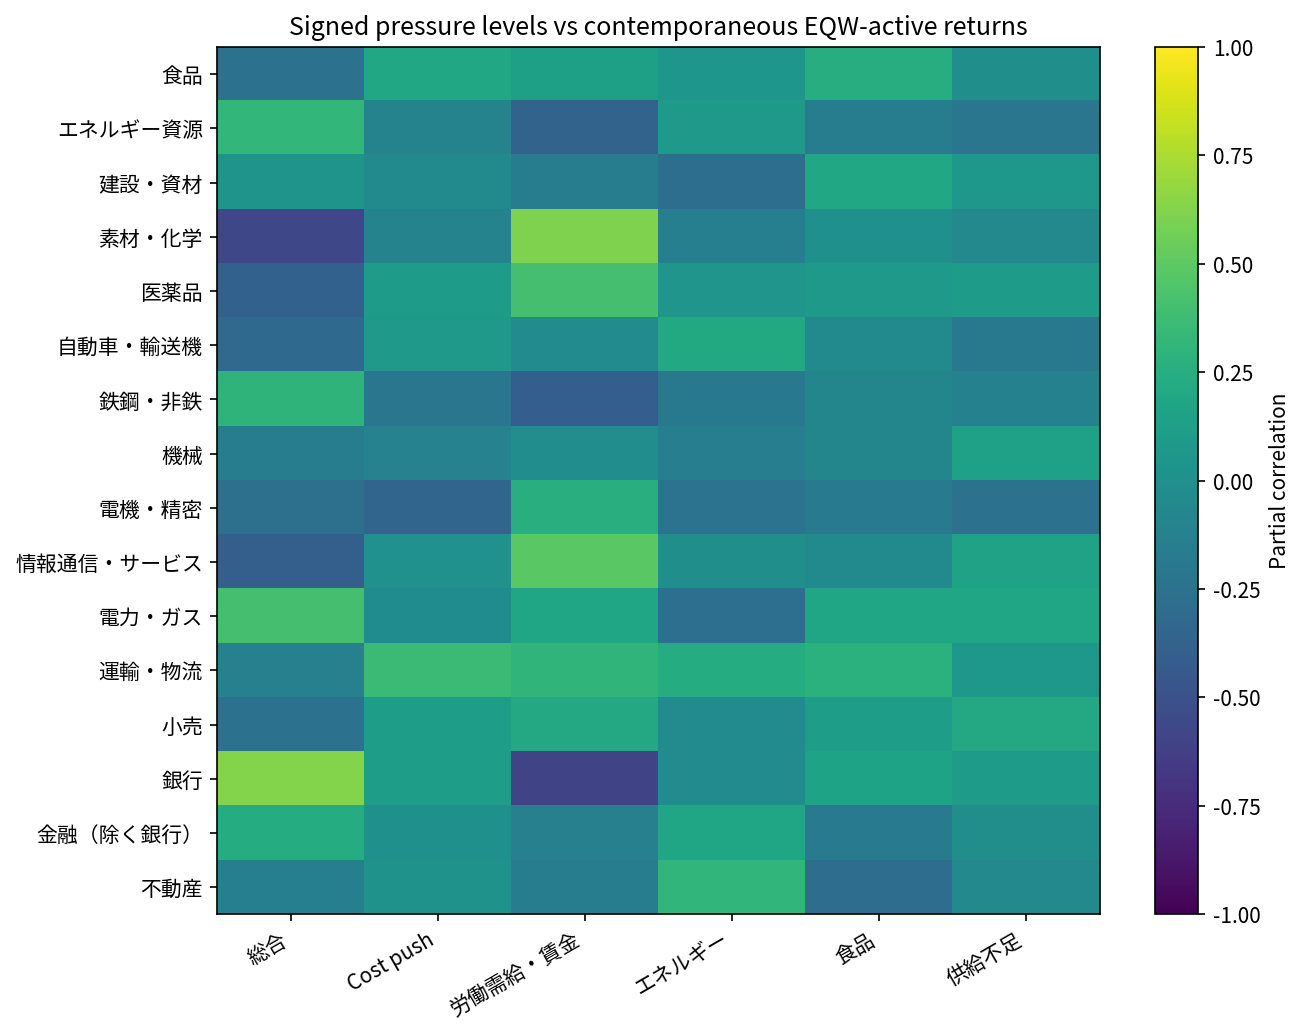

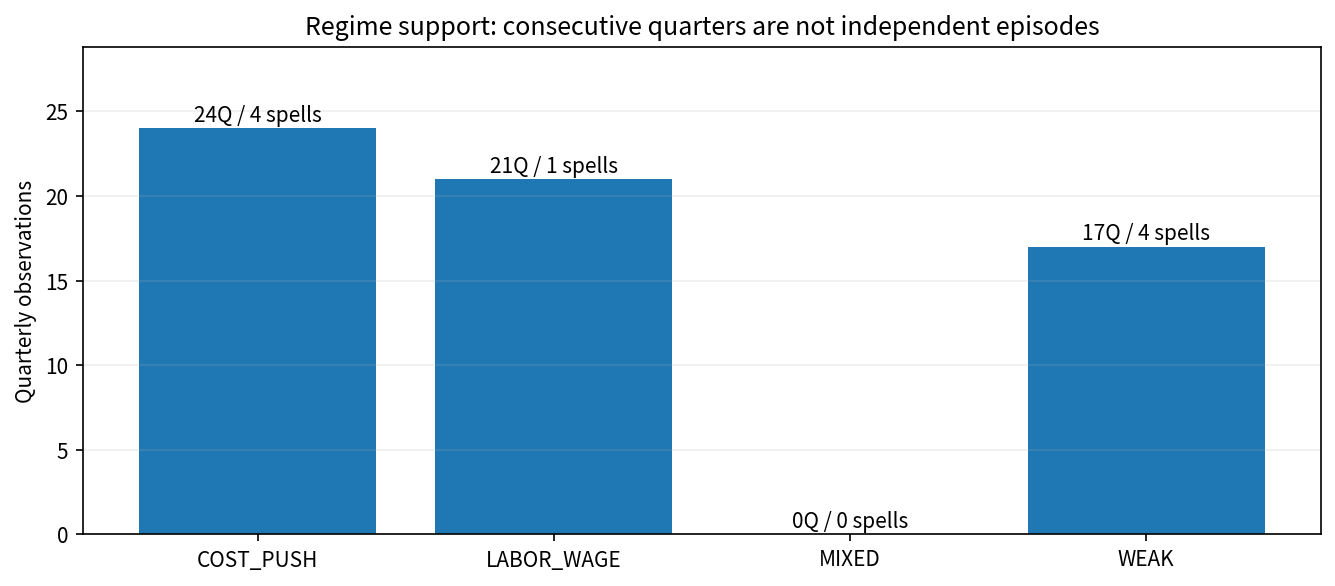

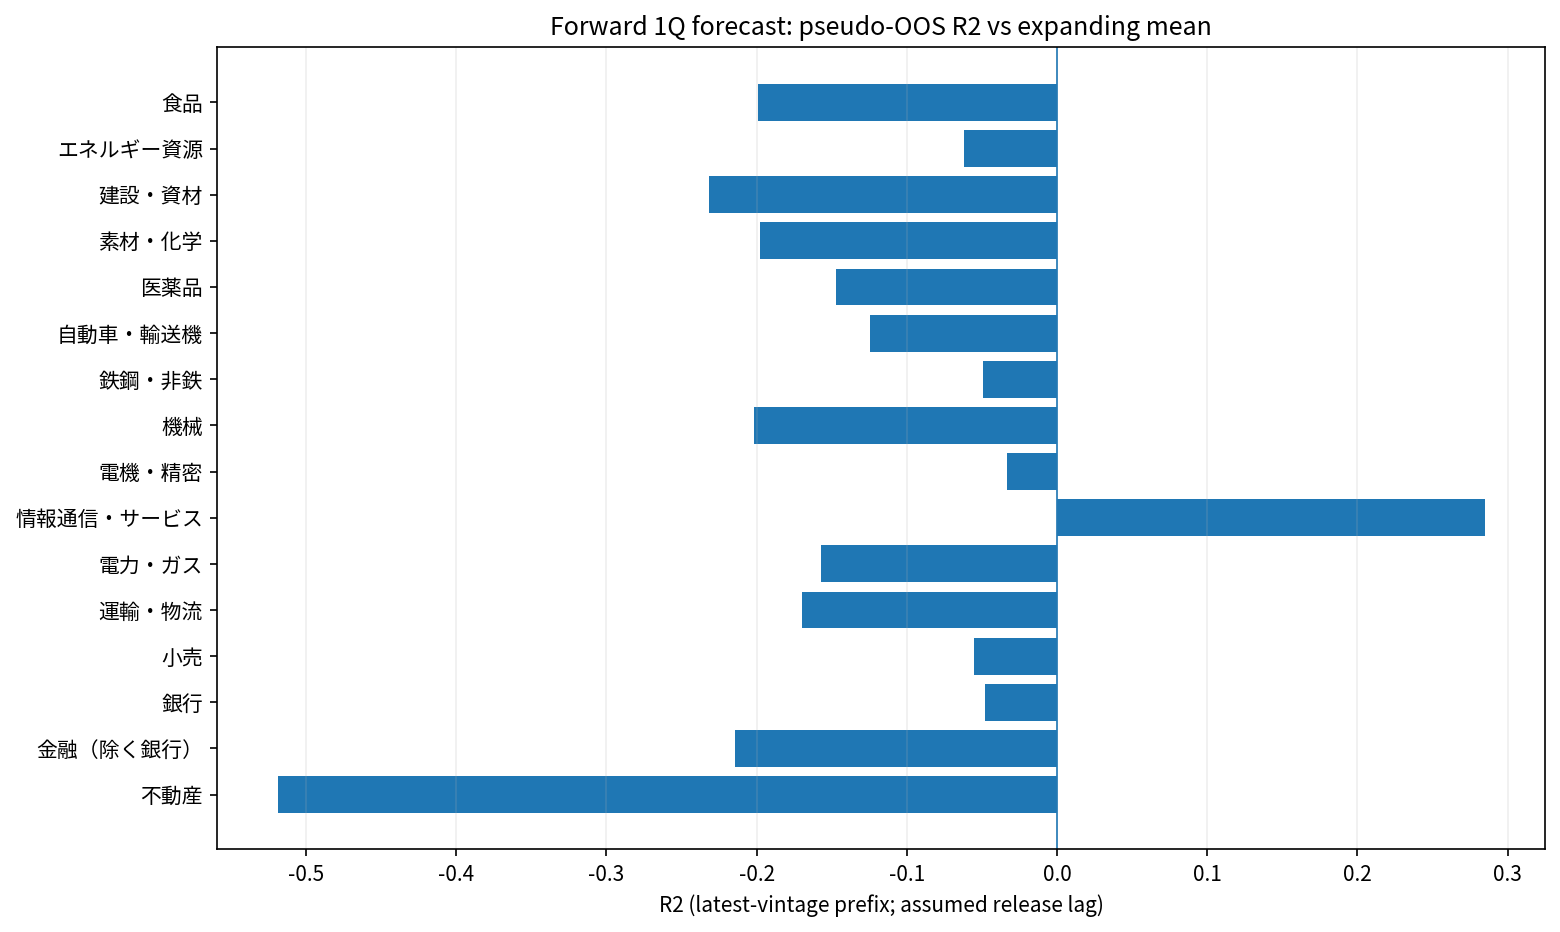

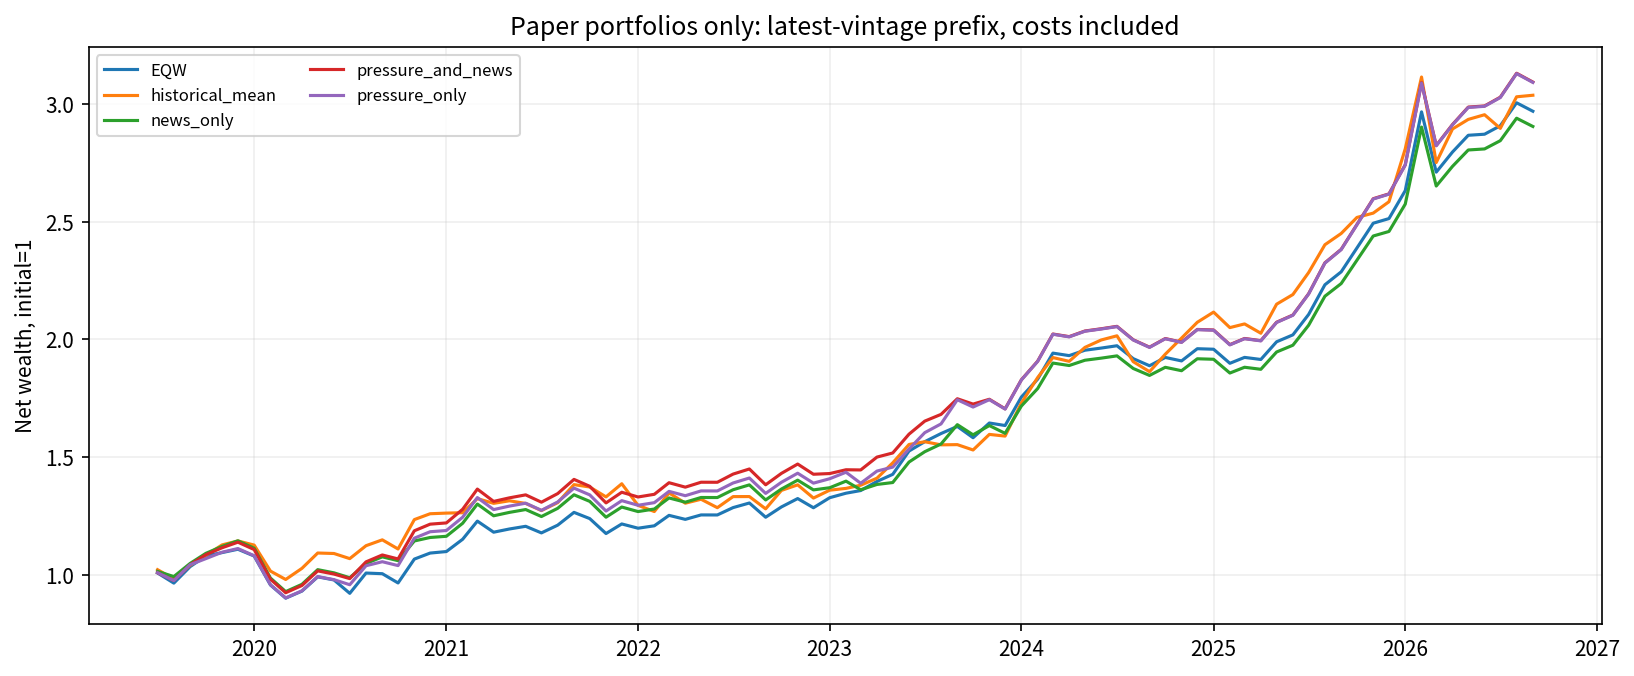

Pressure/selection report: /mnt/data/BB_PA_QualityGate_Ablation/outputs/runs/_inprogress_20261014T223551_112148/results/pressure_assets/report.html


In [40]:
def pa_plot(fig,name):
    fig.tight_layout();fig.savefig(PA_FIG/name,dpi=150,bbox_inches="tight");plt.close(fig)
    display(DisplayImage(filename=str(PA_FIG/name)))

for factor,title in [("cost_push","Cost push"),("labor","Labor/wage")]:
    d=pa_primary.query("return_kind=='active_EQW' and factor==@factor").set_index("asset").reindex(current_assets)
    old=pa_sens.query("return_kind=='active_EQW' and spec=='news' and factor==@factor").set_index("asset").reindex(current_assets)
    fig,ax=plt.subplots(figsize=(10.5,6.3));y=np.arange(len(d))
    ax.barh(y-.18,d.partial_corr_growth,.36,label="Pressure level")
    ax.barh(y+.18,old.partial_corr_growth,.36,label="NewsOnly change")
    ax.set_yticks(y,d.index);ax.invert_yaxis();ax.axvline(0,linewidth=.7)
    ax.set(title=f"{title}: matched-period, growth-controlled partial correlation",xlabel="Partial correlation vs EQW-active 12m return")
    ax.legend();ax.grid(axis="x",alpha=.2);pa_plot(fig,"01_pressure_news_"+factor+".png")

table=pa_primary.query("return_kind=='active_EQW'").pivot(index="asset",columns="factor",values="partial_corr_growth").reindex(index=current_assets,columns=PA_FACTORS)
fig,ax=plt.subplots(figsize=(9,7))
im=ax.imshow(table.to_numpy(),aspect="auto",vmin=-1,vmax=1)
ax.set_xticks(range(len(PA_FACTORS)),[PA_MAP[k][2] for k in PA_FACTORS],rotation=30,ha="right")
ax.set_yticks(range(len(table)),table.index);fig.colorbar(im,ax=ax,label="Partial correlation")
ax.set_title("Signed pressure levels vs contemporaneous EQW-active returns")
pa_plot(fig,"02_pressure_heatmap.png")

count=pd.DataFrame(state_cover).query("scheme=='regime_stable' and return_kind=='active_EQW'")
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(count.state,count.n)
for i,r in enumerate(count.itertuples()):ax.text(i,r.n+.4,f"{r.n}Q / {r.spells} spells",ha="center")
ax.set_ylim(0,max(1,count.n.max())*1.2)
ax.set(title="Regime support: consecutive quarters are not independent episodes",ylabel="Quarterly observations")
ax.grid(axis="y",alpha=.2);pa_plot(fig,"03_regime_sample_support.png")

if len(pa_eval):
    e=pa_eval.query("model=='pressure_and_news' and horizon_q==1").set_index("asset").reindex(current_assets)
    fig,ax=plt.subplots(figsize=(10.5,6.3))
    ax.barh(np.arange(len(e)),e.pseudo_oos_r2_vs_mean)
    ax.set_yticks(range(len(e)),e.index);ax.invert_yaxis();ax.axvline(0,linewidth=.8)
    ax.set(title="Forward 1Q forecast: pseudo-OOS R2 vs expanding mean",xlabel="R2 (latest-vintage prefix; assumed release lag)")
    ax.grid(axis="x",alpha=.2);pa_plot(fig,"04_forecast_r2.png")
if len(pa_ledger):
    fig,ax=plt.subplots(figsize=(11,4.6))
    for name,d in pa_ledger.groupby("strategy"):
        ax.plot(pd.PeriodIndex(d.month,freq="M").to_timestamp(),(1+d.net_return).cumprod(),label=name)
    ax.set(title="Paper portfolios only: latest-vintage prefix, costs included",ylabel="Net wealth, initial=1")
    ax.legend(ncol=2,fontsize=8);ax.grid(alpha=.2);pa_plot(fig,"05_paper_portfolios.png")

def pa_mdtable(df,index=False,digits=4):
    d=df.reset_index() if index else df.copy()
    def val(x):
        if isinstance(x,(float,np.floating)):return "" if pd.isna(x) else f"{x:.{digits}f}"
        return str(x).replace("|","/")
    return "\n".join(["| "+" | ".join(map(str,d.columns))+" |","| "+" | ".join(["---"]*len(d.columns))+" |"]+
                     ["| "+" | ".join(val(x) for x in r)+" |" for r in d.itertuples(index=False,name=None)])
key_assets=["エネルギー資源","素材・化学","情報通信・サービス","銀行","運輸・物流","小売"]
key_pressure=pa_primary.query("return_kind=='active_EQW' and asset in @key_assets and factor in ['cost_push','labor']")[
    ["asset","factor","partial_corr_growth","beta_per_1sd","p_hac8","q_bh_panel"]]
state_display=pd.DataFrame(state_cover).query("return_kind=='active_EQW'")[["scheme","state","n","spells","status"]]
fore_summary=(pa_eval.query("model=='pressure_and_news' and horizon_q==1")[["asset","n_oos","pseudo_oos_r2_vs_mean","forecast_realized_corr"]]
              if len(pa_eval) else pd.DataFrame())
fore_latest=(pa_selection.query("model=='pressure_and_news'")[["asset","prediction_active_pp","research_rank","pseudo_oos_r2_vs_mean","research_forward_support","production_eligible"]].sort_values("research_rank")
             if len(pa_selection) else pd.DataFrame())
perf_display=(pa_perf[["strategy","n_months","CAGR","geometric_relative_ann","IR","max_drawdown","non_EQW_target_months"]]
              if len(pa_perf) else pd.DataFrame())
quality_current=reg_main.loc[BB_END,"regime_final_label"]
tested_count=len(PA_TESTS)
report=f"""# レジーム圧力・インフレ要因と投資対象選定
実行ID {RUN_ID}。基準日{AS_OF_DATE.date()}。主マクロ終期{BB_END}。
現在の正式レジーム：{quality_current}。

## 要旨
既存の因子NewsOnlyに加え、符号付き4期平均の圧力水準に対して同時感応度を計算した。
レジーム別の事後的リターン統計、圧力・NewsOnlyを利用する将来リターン検証、研究候補表を追加。
BB・FT/PT・NewsOnly・レジーム分類の従来結果は変更していない。
感応度が正であることと、これから正の超過リターンが得られることを区別する。

## 1. 主な同時感応度（同じ{len(pa_ix)}四半期、EQW対比12か月）
{pa_mdtable(key_pressure)}
1SDβの単位は12か月リターンのpp、Pはインフレ寄与pp。主回帰は各P_k+GDP_news。
pressure_given_news.csv相当の仕様はpressure_sensitivity_all.csvのspec列に保存。
圧力と変化を同時に制御した結果、線形トレンド統制、終端2期除外を別に保存。

## 2. 状態ごとの標本の限界
{pa_mdtable(state_display)}
「労働需給型の21期」のように、長さがあっても一つの連続局面しかない場合、独立の再現例がない。
混合型が未観測なら平均・βを0とせず未推定にする。正式ラベルのHOLDは、弱い圧力と混ぜない。
state別平均は当該期間の事後的な平均で、購入後の期待リターンではない。

## 3. 前向きの検証
各qまでの原月次を使ってSTLとBBを再推定し、q時点の圧力・NewsOnlyだけを保存。
公表履歴がないため、利用可能日をq+{PA_CFG['assumed_publication_lag_q']}四半期末と仮定。
その後の1/2/4四半期リターンを対象にする。学習標本は保有期間が終了済みのものに限定。
標準化は学習区間のみ。Ridge強度={PA_CFG['ridge_lambda']}を事前固定。
原統計のビンテージ、合成期待、Google照会は最新データに依存するので**真のリアルタイムOOSではない**。
{pa_mdtable(fore_summary)}
R2はその時点の過去平均超過リターン予測と比較したもの。正の同時感応度があってもR2が負なら、平均予測より精度が低い。

## 4. 研究候補（最新の圧力・Newsを投入、将来1四半期）
{pa_mdtable(fore_latest)}
prediction_active_ppは仮定された四半期末での診断予測。実際の発注日時に基づく確定期待値ではない。
research_forward_supportは正予測・十分な評価数・平均予測超えがそろうという研究用ラベル。
production_eligibleは全てFalse。実公表履歴、リアルタイム独立検証、実際に売買する商品の定義が未確認であるため。
現在レジームがHOLDなら、レジームに基づくアクティブ配分判断も保留する。

## 5. 紙上配分の参考
{pa_mdtable(perf_display)}
CAGR・相対年率・DDは小数表示（0.01=1%）。個別の採用ゲートとは別の固定ルール評価。
Top{PA_CFG['top_n']}等ウェイト、四半期選定、月次目標比率へリバランス、片道{PA_CFG['one_way_cost_bps']}bp。
正予測が足りない、またはprefix品質lowならEQW。EQWにも同じコストを適用する。
実装可能なリターン、純粋OOS、収益保証と主張しない。成績の良いモデル・閾値を全期間から選ぶ処理はしない。
モデル選択数も考慮した独立のホールドアウトが必要。

## 6. 毎月の使い方
元CSV更新→同じmain.ipynbを全実行。outputs/latest/pressure_assets/report.htmlを確認。
既存NewsOnly・regimes出力は維持。本追加分析はpressure_assets内で別管理。
pressure_exposure_candidate_map.csvは同時感応度、latest_research_candidates.csvは前向き検証の候補。
observed_feature_archive.csvにはその実行で初めて記録したavailable_atを保存。過去公表日に偽ってバックフィルしない。
現版では蓄積ファイルを過去投資の検証へ自動採用していない。十分な履歴と原資料確認後に厳密な時点検証へ移行する。

## 7. 参照と独自設計
BBは符号付き寄与・発生源の動学経路を提供するが、投資alphaを直接推定した論文ではない。
- Bernanke & Blanchard (2024), PIIE WP24-11, pp.8–9,23,29: 需要供給識別の限界、直接間接寄与。
- Nakamura et al. (2024), BOJ WP24-E-1: FT/PT構造・相関する残差。
- Campbell & Thompson (2008), Predicting Excess Stock Returns Out of Sample, RFS21: 予測を過去平均ベンチマークと比較する観点。
  https://www.nber.org/papers/w11468
- Nelson & Kim, NBER w3297 / JF1993: 重複した長期リターン・小標本の推論上の問題。
  https://www.nber.org/papers/w3297
- St. Louis Fed, ALFRED: 特定時点に知られていたビンテージを区別する考え方。
  https://alfred.stlouisfed.org/help

本研究の回帰仕様・Ridge定数・閾値・運用ゲートは独自の初期設定。上記文献の数値再現や推奨値ではない。
追加検査は{tested_count}件通過。前処理・推定・NewsOnly等の数値ファイル不変性を検査。
"""
(PA_DIR/"RESULTS_ja.md").write_text(report,encoding="utf-8")
import html as _pa_html,base64 as _pa_base64
def pa_h(df,index=False):
    return df.to_html(index=index,border=0,float_format=lambda x:f"{x:.4f}")
def pa_img(name,caption):
    if not (PA_FIG/name).exists():return ""
    s=_pa_base64.b64encode((PA_FIG/name).read_bytes()).decode()
    return f'<figure><figcaption>{_pa_html.escape(caption)}</figcaption><img src="data:image/png;base64,{s}" alt="{_pa_html.escape(caption)}"></figure>'
body=f"""
<header><p>REGIME PRESSURE / ASSET SELECTION RESEARCH</p>
<h1>インフレ圧力と超過リターン候補</h1><p>現在の正式判定：{quality_current} ｜ {AS_OF_DATE.date()} ｜ 主標本{len(pa_ix)}四半期</p></header>
<section class="notice"><h2>感応度と投資alphaを区別</h2>
<p>「圧力が高いとき強かった」資産と、「今の圧力が将来の超過リターンを予測する」資産は同一ではありません。
本分析は両者を分離します。公表ビンテージ・実行可能な価格・独立検証が未確認で、現在のレジームも保留のため、
<strong>本番配分に採用済みの候補はありません</strong>。</p></section>
<section><h2>1. 同時感応度</h2>{pa_h(key_pressure)}
{pa_img("01_pressure_news_cost_push.png","圧力水準とNewsOnly変化の比較：Cost push")}
{pa_img("01_pressure_news_labor.png","圧力水準とNewsOnly変化の比較：労働需給")}
{pa_img("02_pressure_heatmap.png","全6系統×16セクター")}</section>
<section><h2>2. 各レジームの評価可能性</h2>{pa_h(state_display)}
{pa_img("03_regime_sample_support.png","観測数と独立したエピソード数")}
<p>未観測の混合型や短い状態を0リターン扱いしていません。偏相関・状態別平均・予測は別の量です。</p></section>
<section><h2>3. 将来リターンの参考検証</h2>
<p>原月次を各qまで切り、STL・BBを逐次再推定。ただし最新ビンテージの原統計・企業期待を使うため、
<b>本当のリアルタイムOOSではありません</b>。利用可能日はq+{PA_CFG['assumed_publication_lag_q']}末と仮定。
将来GDP、保有期間未終了のリターン、全標本標準化を学習に使いません。</p>
{pa_h(fore_summary)}{pa_img("04_forecast_r2.png","過去平均ベンチマークに対する疑似OOS R2")}</section>
<section><h2>4. 最新の研究候補</h2>{pa_h(fore_latest)}
<p>予測値は診断用で、確定的な期待リターンではありません。研究用条件を満たしてもproduction_eligibleはFalseです。
まず観測ビンテージ・取引価格・実商品のメタ情報を確認する必要があります。</p></section>
<section><h2>5. 固定ルールの紙上配分</h2>{pa_h(perf_display)}
{pa_img("05_paper_portfolios.png","コスト控除後・EQW比較（最新ビンテージの参考検証）")}
<p>Top4の等ウェイト。品質不良または正予測不足ならEQW。高頻度取引のバックテストではありません。
少数のアクティブ月に結果が依存するため、上の状態・学習標本を併せて確認します。</p></section>
<footer><h2>入力・出所・検証</h2>
<p>BB/FTPT/NewsOnly/regimeの従来入力・推定・分類を変えず、後段へ追加しました。
全モデルの生成誤差をHAC/資産bootstrapが網羅するわけではありません。検査{tested_count}件。</p>
<p>Bernanke &amp; Blanchard (2024); Nakamura et al. (2024);
Campbell &amp; Thompson (2008, RFS21); Nelson &amp; Kim (NBER w3297/JF1993); St. Louis Fed ALFRED。
原統計・価格はユーザー提供ファイル。外部データの追加取得はしていません。</p>
<p>再実行：元CSV更新→main.ipynbを全実行。今回結果はpressure_assets内、既存モデルは元のフォルダ構成を維持。</p></footer>
"""
css="""body{max-width:1150px;margin:auto;padding:34px 28px;font-family:-apple-system,BlinkMacSystemFont,"Segoe UI","Noto Sans JP",sans-serif;line-height:1.7;color:#203343}
header{border-bottom:4px solid #23445b;padding-bottom:22px}h1{font-size:32px}h2{font-size:23px}section{margin:34px 0}.notice{padding:18px;border-left:4px solid #23445b;background:#f1f4f7}
table{display:block;max-width:100%;overflow-x:auto;font-size:12px;border-collapse:collapse}td,th{padding:8px;border-bottom:1px solid #d9e0e5;text-align:right;white-space:nowrap}
th{background:#edf2f6}figure{margin:26px 0}img{max-width:100%;height:auto}figcaption{font-weight:600}footer{border-top:2px solid #23445b;font-size:13px;padding-top:16px}"""
(PA_DIR/"report.html").write_text('<!doctype html><html lang="ja"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Pressure asset selection</title><style>'+css+"</style><body>"+body+"</body></html>",encoding="utf-8")
pa_json({"as_of":str(AS_OF_DATE.date()),"bb_end":str(BB_END),"pressure_sample_n":len(pa_ix),
         "main_pressure_regressions":len(pa_primary),"recursive_periods_attempted":len(pa_recursive_periods),
         "recursive_periods_success":sum(r.get("status")=="success" for r in pa_recursive_log),
         "forward_regressions":len(pa_forward_sens),"walkforward_predictions":len(pa_wf),
         "current_formal_regime":reg_main.loc[BB_END,"regime_final"],"production_eligible":False,
         "base_source":"existing FTPT long-history regime pressures","method_config":PA_CFG,
         "checks":len(PA_TESTS),"existing_numeric_files_unchanged":len(PA_FILES_BEFORE),
         "scope":"contemporaneous sensitivity plus recursive latest-vintage research; not real-time proof"},"run_summary.json")
def pa_publish_link():
    path=RESULT_DIR/"report.html"
    if path.exists():
        content=path.read_text(encoding="utf-8")
        card='<section><h2>追加：レジーム圧力と投資対象の研究</h2><p>圧力感応度・レジーム別実績・将来リターン検証を分離しました。<a href="pressure_assets/report.html">研究レポート</a>。本番配分の採用は保留です。</p></section>'
        content=content.replace("<body>","<body>"+card,1)
        path.write_text(content,encoding="utf-8")
print("Pressure/selection report:",PA_DIR/"report.html")

# 20．C案：観測済み3か月窓による月次圧力・先1か月予測・月次選定
上の四半期BB・FT/PT・NewsOnly・レジーム・資産分析は変更しません。
ここから独立した**月次条件付き圧力**と運用診断を追加します。

- 四半期限定のGDP・期待を月次補完しない。四半期係数の推定にだけ使用。
- 月次実績の完全な3か月窓を使い、1四半期ラグ=3か月、catch-upの内部最大8期=24か月を維持。
- Commodity/laborの**差分寄与**を計算。初期条件・生産性・期待残差を含む「完全な月次歴史分解」とは呼ばない。
- 主予測は先1か月、先3か月は別学習の比較モデル。両者とも毎月選定し、次月の1ポートフォリオを保有。
- BB係数と資産予測係数・標準化を四半期のモデル版ごとに固定。月内の予測変化は月次情報を反映。
- 公表履歴未提供の期間は、月次2か月・四半期3か月の**仮定**を明示。最新ビンテージの疑似時点検証であり真のリアルタイムではない。
  `inputs/monthly_release_calendar.csv`に実際の利用可能日時を追加できる。原系列のヴィンテージ自体を復元する機能ではない。

PIIE WP24-11 p.8の四半期ラグ、p.29の直接・間接寄与、日本WP24-E-1式(1′)のFT/PT構造を維持する。
月末をずらした3か月ブロックに同じ係数を適用する仮定・3つの開始位相は本件の拡張で、文献の掲載モデルそのものではない。

In [41]:
import copy as _cm_copy
import types as _cm_types
CM_CFG=dict(MONTHLY_MACRO_CFG)
CM_DIR=RESULT_DIR/"monthly_selection";CM_FIG=CM_DIR/"figures"
CM_DIR.mkdir(exist_ok=True);CM_FIG.mkdir(exist_ok=True)
CM_CHECKS=[]
def cm_check(name,condition,detail=""):
    CM_CHECKS.append({"test":name,"passed":bool(condition),"detail":str(detail)})
    check("monthlyC_"+name,condition,detail)
def cm_save(df,name,index=False):
    save_csv(df,name,index=index,folder=CM_DIR)
def cm_json(obj,name):
    reg_json(obj,CM_DIR/name)
def cm_require_config(cfg):
    if (cfg["main_horizon_months"],cfg["comparison_horizon_months"])!=(1,3):
        raise ValueError("本版の主予測は1か月、比較は3か月です")
    if cfg["monthly_release_lag_months"]<1 or cfg["quarterly_release_lag_months"]<1:
        raise ValueError("未確認公表時点のゼロラグ指定はできません")
    if cfg["asset_refit"]!="quarterly_model_release":raise ValueError("資産モデルは四半期モデル版で固定")
    if cfg["min_train_months"]<24 or cfg["min_train_quarter_versions"]<8:
        raise ValueError("極端に短い学習標本を使用しません")
    if cfg["ridge_penalty_per_observation"]<=0:raise ValueError("Ridge罰則は正")
    if cfg["execute_lag_months"]<0:raise ValueError("実行ラグは非負")
    if not 1<=cfg["top_n"]<=len(current_assets):raise ValueError("選定数がユニバース外")
    if pd.Period(cfg["decision_start"],freq="M")<pd.Period("2011-06"):
        raise ValueError("既存Google較正が2010年末までなので開始は2011-06以降に制限")
cm_require_config(CM_CFG)
CM_FEATURES=["p_cost_push","p_labor","n_cost_push","n_labor","g_last_published_q"]
CM_INPUT_COLUMNS=[
 "cpi_2025_nsa_energy","cpi_2025_nsa_food","labour_all_scheduled_pay_index",
 "labour_ft_employees_start","labour_ft_employees_end","labour_pt_employees_start","labour_pt_employees_end",
 "jobs_sa_active_vacancies","jobs_sa_placements","lfs_sa_unemployed","lfs_sa_employees","google_shortage"]
CM_PATHS=["energy","food","shortage","labor_ft","labor_pt"]
CM_PROTECTED_NAMES=[k for k in [
 "M","Q","panel","constructed_monthly","constructed_quarterly","dual_panel","model","dual_model","history",
 "dual_history","pandemic_hd","dual_pandemic","news_all","dual_news_all","main","dual_main","reg_main","assets",
 "coverage","pa_x","pa_recursive","pa_wf","pa_primary","pa_perf","PA_CFG","CFG","REG_CFG"] if k in globals()]
CM_BEFORE={k:reg_fingerprint(globals()[k]) for k in CM_PROTECTED_NAMES}
CM_BEFORE_FILES={str(p.relative_to(RESULT_DIR)):sha256(p.read_bytes()) for p in RESULT_DIR.rglob("*")
                 if p.is_file() and p.suffix.lower() in [".csv",".json"] and not p.is_relative_to(CM_DIR)}
CM_CURRENT_PREFIX_END=min(M[c].last_valid_index() for c in CM_INPUT_COLUMNS)
cm_save(pd.DataFrame([{"series":c,"latest_observation":str(M[c].last_valid_index())} for c in CM_INPUT_COLUMNS]),
        "monthly_input_coverage.csv")
cm_json({"config":CM_CFG,"monthly_requires":CM_INPUT_COLUMNS,"quarterly_interpolation":False,
         "pressure_window_month_offsets":[0,3,6,9],"news_difference_months":12,
         "endogenous_month_lags":[3*i for i in range(1,9)],"exogenous_month_lags":[0,3,6,9,12],
         "current_observed_common_month":str(CM_CURRENT_PREFIX_END),
         "extra_assumption":"same quarterly coefficients on three staggered observed blocks",
         "scope":"Selected-path conditional contributions, NOT complete monthly decomposition"},
        "method_contract.json")

## 20A．月次だけの入力加工
この関数はQを引数に取らず、月次原料だけを明示的に選択して処理します。
GDP・期待・生産性の月次列、月次の実測catch-up、式残差は作りません。
既存と同じ相対価格の分母・STL仕様・V/Uの率比・Google処理を維持。
元のGoogle震災調整・2004年以前の固定処理は継承しますが、新しい月次や四半期データの欠落を埋める処理はしません。

In [42]:
def cm_monthly_blocks(raw_monthly,end_month,cfg,google_scale,google_fill):
    end=pd.Period(end_month,freq="M")
    missing=set(CM_INPUT_COLUMNS)-set(raw_monthly.columns)
    if missing:raise ValueError("月次原料不足: "+str(sorted(missing)))
    m=raw_monthly.loc[:end,CM_INPUT_COLUMNS].copy()
    if m.index.has_duplicates or m.index.freqstr!="M" or not m.index.is_monotonic_increasing:
        raise ValueError("月次PeriodIndexの重複・非昇順・頻度")
    m=m.reindex(pd.period_range(m.index.min(),end,freq="M",name="month"))
    # 当期までの途中欠損を、roll3やSTLで暗黙にスキップしない。
    for col in CM_INPUT_COLUMNS:
        start=max(m[col].first_valid_index(),pd.Period("1993-01")) if m[col].first_valid_index() is not None else end
        if col=="google_shortage":start=max(start,pd.Period("2004-01"))
        if m.loc[start:end,col].isna().any():raise ValueError(f"{col}: {end}までの観測が未完了・途中欠損")
    out=pd.DataFrame(index=m.index)
    components=pd.DataFrame(index=m.index)
    for key,name in [("grpe","energy"),("grpf","food")]:
        raw=m["cpi_2025_nsa_"+name]/m.labour_all_scheduled_pay_index
        sa=log_stl(raw,trend=cfg["other_trend"],seasonal=cfg["stl_seasonal"]).sa
        components[key+"_level_sa"]=sa
        av=sa.reindex(m.index).rolling(3,min_periods=3).mean()
        ratio=av/av.shift(3)
        if cfg["growth"]=="log":out[key]=400*np.log(ratio)
        elif cfg["growth"]=="simple":out[key]=400*(ratio-1)
        elif cfg["growth"]=="compound":out[key]=100*(ratio**4-1)
        else:raise ValueError(cfg["growth"])
    ft=(m.labour_ft_employees_start+m.labour_ft_employees_end)/2
    pt=(m.labour_pt_employees_start+m.labour_pt_employees_end)/2
    share=ft/(ft+pt)
    out["weight_ft_lagged"]=share.rolling(3,min_periods=3).mean().shift(3)
    A=m.jobs_sa_active_vacancies;J=m.jobs_sa_placements
    U=m.lfs_sa_unemployed*10000;E=m.lfs_sa_employees*10000
    vu=((A-J)/(E+A-J))/(U/(E+U))
    components["vu_rate_ratio"]=vu
    out["vu"]=vu.rolling(3,min_periods=3).mean()
    google=m.google_shortage.copy()
    google.loc[cfg["google_earthquake_start"]:cfg["google_earthquake_end"]]=google_fill
    before=(google.index>=pd.Period("1990-01"))&(google.index<pd.Period("2004-01"))
    google.loc[before]=google_fill
    components["google_adjusted_legacy_units"]=google*google_scale
    out["shortage"]=(google*google_scale).rolling(3,min_periods=3).mean()
    valid=out.weight_ft_lagged.dropna()
    if not valid.between(0,1,inclusive="neither").all():raise ValueError("FT人数ウェイト範囲外")
    return out,components

def cm_phase_baselines(blocks,history_start,mean_start):
    quarter_end=pd.Period(history_start,freq="Q").asfreq("M","end")
    mean_month=pd.Period(mean_start,freq="Q").asfreq("M","start")
    rows=[]
    for phase_start in [quarter_end-2,quarter_end-1,quarter_end]:
        anchor=phase_start-3
        idx=blocks.index[(blocks.index>=mean_month)&(blocks.index<=anchor)&
                         ((blocks.index.asi8-phase_start.ordinal)%3==0)]
        short=blocks.loc[idx,"shortage"].dropna()
        vu=blocks.loc[anchor,"vu"]
        if short.empty or not np.isfinite(vu):raise ValueError("位相別の基準観測が不足")
        rows.append({"phase":phase_start.ordinal%3,"start_month":str(phase_start),"anchor_month":str(anchor),
                     "vu_baseline":float(vu),"shortage_baseline":float(short.mean()),
                     "zero_contribution_before_start":True,"calendar_quarter_phase":phase_start==quarter_end})
    return pd.DataFrame(rows)

def cm_contribution_paths(blocks,compiled,baselines):
    """差分寄与のみ。月次GDP/期待実績を引数にしない。3位相は相互に混ぜない。"""
    if set(["magpty","cf1","cf10","gdp"]).intersection(blocks.columns):
        raise ValueError("月次GDP/期待の実績または補完列を投入しません")
    starts=[pd.Period(s,freq="M") for s in baselines.start_month]
    first=min(starts)
    idx=pd.period_range(first-24,blocks.index.max(),freq="M",name="month")
    b=blocks.reindex(idx)
    ny=len(FTPT_STATE);nk=len(CM_PATHS);p=compiled["p"];ql=compiled["q"]
    if p!=8 or ql!=4:raise ValueError("四半期のコンパイル済ラグ設定が想定と異なります")
    yy=np.zeros((len(idx),ny,nk));shocks=np.zeros((len(idx),nk))
    for row in baselines.itertuples():
        st=pd.Period(row.start_month,freq="M")
        mask=(idx>=st)&((idx.asi8-st.ordinal)%3==0)
        tmp=b.loc[mask,["grpe","grpf","shortage","vu","weight_ft_lagged"]]
        if not np.isfinite(tmp.to_numpy()).all():raise ValueError(f"{st}位相の観測・ウェイトに欠損")
        shocks[mask,0]=tmp.grpe;shocks[mask,1]=tmp.grpf
        shocks[mask,2]=tmp.shortage-row.shortage_baseline
        shocks[mask,3]=tmp.vu-row.vu_baseline;shocks[mask,4]=tmp.vu-row.vu_baseline
    # 残りの外生変数は差分方程式で相殺する。0の実測値を捏造したのではない。
    BL=np.zeros((ql+1,ny,nk))
    for k,var in enumerate(["grpe","grpf","shortage"]):BL[:,:,k]=compiled["BL"][:,:,EXOG.index(var)]
    full_labor=compiled["BL"][:,:,EXOG.index("vu")]
    ftrow=FTPT_STATE.index("gw_ft");ptrow=FTPT_STATE.index("gw_pt")
    other=np.delete(full_labor,[ftrow,ptrow],axis=1)
    if not np.allclose(other,0):raise ValueError("V/UはFT/PT賃金式の入口のみと想定")
    BL[:,ftrow,3]=full_labor[:,ftrow];BL[:,ptrow,4]=full_labor[:,ptrow]
    for t in range(24,len(idx)):
        wt=float(b.weight_ft_lagged.iloc[t])
        if not 0<wt<1:raise ValueError("寄与計算の月次ウェイトが未観測")
        rhs=np.einsum("lij,ljk->ik",compiled["AL"],yy[t-3*np.arange(1,p+1)])
        rhs+=np.einsum("lik,lk->ik",BL,shocks[t-3*np.arange(ql+1)])
        H=compiled["H"].copy();g=FTPT_STATE.index("gw")
        H[g,ftrow]=-wt;H[g,ptrow]=-(1-wt)
        yy[t]=np.linalg.solve(H,rhs)
        if not np.isfinite(yy[t]).all():raise FloatingPointError("月次差分寄与が発散")
    result={}
    for j,state in enumerate(FTPT_STATE):
        d=pd.DataFrame(yy[24:,j,:],index=idx[24:],columns=CM_PATHS)
        d["labor"]=d.labor_ft+d.labor_pt
        d["cost_push"]=d.energy+d.food+d.shortage
        d["selected_net"]=d.cost_push+d.labor
        result[state]=d
    implied=result["gw_ft"].mul(b.loc[idx[24:],"weight_ft_lagged"],axis=0)+result["gw_pt"].mul(
        1-b.loc[idx[24:],"weight_ft_lagged"],axis=0)
    if not np.allclose(result["gw"],implied,atol=1e-9):raise AssertionError("FT/PT恒等式が不成立")
    return result

def cm_pressure_from_paths(paths):
    c=paths["gcpi"];out=pd.DataFrame(index=c.index)
    for k in c:
        out["c_"+k]=c[k]
        out["p_"+k]=(c[k]+c[k].shift(3)+c[k].shift(6)+c[k].shift(9))/4
        out["n_"+k]=out["p_"+k]-out["p_"+k].shift(12)
    return out

## 20B．四半期モデル版・公表ラグ
四半期モデルはq末までの実績で推定し、その利用可能日から次のモデル版まで固定。
月次系列の仮定公表ラグは2か月、四半期モデルは3か月です。公表日を確認したという意味ではありません。
任意CSVの列は `kind,period,available_at`。kindは `monthly_bundle` または `quarterly_model`。
bundleの時刻は、その月の必要原料が**全て利用できた時刻**です。
空のCSVでは既定ラグを使い、仮定か実際の指定かを各判断行に残します。

In [43]:
def cm_parse_time(value):
    t=pd.Timestamp(value)
    if pd.isna(t):raise ValueError("利用可能日時が空")
    return t.tz_convert("Asia/Tokyo").tz_localize(None) if t.tzinfo is not None else t

CM_RELEASE_OVERRIDE={}
_cm_calendar_path=INPUT_DIR/CM_CFG["release_calendar"]
if _cm_calendar_path.exists():
    _cm_calendar=pd.read_csv(BytesIO(read_bytes(_cm_calendar_path,"monthly_release_calendar")),dtype=str)
    if not {"kind","period","available_at"}.issubset(_cm_calendar):raise ValueError("公表calendar列が不足")
    for _cm_row in _cm_calendar.itertuples(index=False):
        if _cm_row.kind not in ["monthly_bundle","quarterly_model"]:raise ValueError("calendar kindが不正")
        _cm_freq="M" if _cm_row.kind=="monthly_bundle" else "Q"
        _cm_per=pd.Period(_cm_row.period,freq=_cm_freq)
        _cm_key=(_cm_row.kind,str(_cm_per))
        if _cm_key in CM_RELEASE_OVERRIDE:raise ValueError("calendar対象期が重複")
        _cm_t=cm_parse_time(_cm_row.available_at)
        if _cm_t<_cm_per.end_time.normalize():raise ValueError("期間完了前の観測を実績扱いしません")
        CM_RELEASE_OVERRIDE[_cm_key]=_cm_t

def cm_release(kind,period,config=None,overrides=None):
    cfg=CM_CFG if config is None else config
    calendar=CM_RELEASE_OVERRIDE if overrides is None else overrides
    p=pd.Period(period,freq="M" if kind=="monthly_bundle" else "Q")
    key=(kind,str(p))
    if key in calendar:return cm_parse_time(calendar[key]),"provided_calendar"
    if cfg["strict_release_calendar"]:raise ValueError("公表calendar未登録: "+str(key))
    base=p if kind=="monthly_bundle" else p.asfreq("M","end")
    lag=cfg["monthly_release_lag_months"] if kind=="monthly_bundle" else cfg["quarterly_release_lag_months"]
    return (base+lag).end_time,"assumed_lag"

def cm_fit_quarter(q,monthly_raw,quarterly_raw):
    q=pd.Period(q,freq="Q");end=q.asfreq("M","end")
    local=dict(CFG);local["tax_anchor"]=str(min(pd.Period(CFG["tax_anchor"],freq="M"),end))
    env=dict(build_reconstruction.__globals__)
    env.update(M=monthly_raw.loc[:end].copy(),Q=quarterly_raw.loc[:q].copy(),CFG=local)
    fn=_cm_types.FunctionType(build_reconstruction.__code__,env,"cm_quarterly_reconstruction",
                              build_reconstruction.__defaults__,build_reconstruction.__closure__)
    fn.__kwdefaults__=dict(build_reconstruction.__kwdefaults__ or {})
    data,dm,dq,meta=fn(str(q),growth_method=CFG["growth"])
    data["cf1"]=quarterly_raw.loc[:q,"firm_expectation_1y"].reindex(data.index)
    data["cf10"]=quarterly_raw.loc[:q,f"firm_expectation_{long_year}y"].reindex(data.index)
    data["diffcpicf"]=data.gcpi.rolling(4,min_periods=4).mean()-data.cf1.shift(4)
    data=data[BASE_VARS+["dummyq2_2020","dummyq3_2020"]].join(dq[["gw_ft","gw_pt","weight_ft_lagged"]])
    if data.loc[BB_START:q].isna().any().any():raise ValueError(f"{q}:完全な四半期推定データが不足")
    fitted=fit_ftpt_system(data,start=BB_START,end=str(q),price_productivity=CFG["price_productivity"])
    hd,hm=ftpt_history(fitted,data,NEWS_HISTORY_START,str(q),NEWS_MEAN_START)
    compiled=compile_ftpt_system(fitted)
    # 四半期品質は最新の全標本状態を過去へコピーせず、そのモデル版で作る。
    rp=reg_pressure_frame(hd["gcpi"],FTPT_PARTS,REG_CFG,"CM_quarterly",f"quarter_{q}",q.end_time)
    rs=reg_classify_path(rp,REG_CFG)
    am=fit_system(data,price_productivity=CFG["price_productivity"],start=BB_START,end=str(q),common_sample=True)
    ah,_=historical_decomposition_reference(am,data,NEWS_HISTORY_START,str(q),NEWS_MEAN_START)
    ap=reg_pressure_frame(ah["gcpi"],PARTS,REG_CFG,"CM_aggregate","comparison",q.end_time)
    rs["aggregate_regime_stable"]=reg_classify_path(ap,REG_CFG).regime_stable.reindex(rs.index)
    if q>=pd.Period("2020Q1"):
        ph,_=ftpt_history(fitted,data,"2020Q1",str(q),BB_START)
        pp=reg_pressure_frame(ph["gcpi"],FTPT_PARTS,REG_CFG,"CM_2020","comparison",q.end_time)
        rs["baseline2020_regime_stable"]=reg_classify_path(pp,REG_CFG).regime_stable.reindex(rs.index)
    grid,_=reg_threshold_grid(rp,REG_CFG)
    rs["threshold_agreement"]=grid.eq(rs.regime_stable,axis=0).mean(axis=1)
    roots=ftpt_frozen_roots(compiled,float(data.loc[q,"weight_ft_lagged"]))
    context={"homogeneity_rejected":any(f["homogeneity_p"]<.05 for f in fitted.values()),
             "unstable_root":roots["roots_above_one"]>0,"stale_inputs":False}
    formal=reg_add_labels_and_quality(rs,REG_CFG,context)
    blocks,_=cm_monthly_blocks(monthly_raw,end,CFG,GOOGLE_SCALE,GOOGLE_FILL)
    baselines=cm_phase_baselines(blocks,NEWS_HISTORY_START,NEWS_MEAN_START)
    paths=cm_contribution_paths(blocks,compiled,baselines)
    p=cm_pressure_from_paths(paths)
    mi=hd["gcpi"].index.asfreq("M","end")
    errors=[]
    for state in FTPT_STATE:
        for key,col in [("energy","energy"),("food","food"),("shortage","shortage"),("labor","labor"),
                        ("labor_ft","labor_via_FT"),("labor_pt","labor_via_PT")]:
            err=float(np.max(np.abs(paths[state].reindex(mi)[key].to_numpy()-hd[state][col].to_numpy())))
            if err>1e-8:raise AssertionError(f"{q} calendar-quarter identity {state}/{key}: {err}")
            errors.append(err)
    growthq=100*(quarterly_raw.loc[:q,"gdp_real_sa_annualized"]/quarterly_raw.loc[:q,"gdp_real_sa_annualized"].shift(4)-1)
    g=float(growthq.diff(4).loc[q])
    coef=coefficients_frame(fitted)
    version=f"BB_{q}_"+reg_fingerprint(coef)[:12]
    return {"q":q,"version":version,"fits":fitted,"compiled":compiled,"quarter_data":data,
            "baseline":baselines,"formal":formal.iloc[-1].to_dict(),"q_features":p.loc[end].to_dict(),
            "g_last_published_q":g,"roots":roots,"quarter_identity_max_error":max(errors),
            "monthly_blocks_at_fit":blocks,"coef":coef}

CM_MODEL_CACHE={}
CM_BLOCK_CACHE={}
CM_OBSERVATION_CACHE={}
def cm_model(q):
    key=str(q)
    if key not in CM_MODEL_CACHE:CM_MODEL_CACHE[key]=cm_fit_quarter(q,M,Q)
    return CM_MODEL_CACHE[key]
def cm_month_observation(m,model):
    key=(str(m),model["version"])
    if key not in CM_OBSERVATION_CACHE:
        mk=str(m)
        if mk not in CM_BLOCK_CACHE:CM_BLOCK_CACHE[mk]=cm_monthly_blocks(M,m,CFG,GOOGLE_SCALE,GOOGLE_FILL)[0]
        block=CM_BLOCK_CACHE[mk]
        paths=cm_contribution_paths(block,model["compiled"],model["baseline"])
        p=cm_pressure_from_paths(paths)
        CM_OBSERVATION_CACHE[key]=p.iloc[-1].to_dict()
    return CM_OBSERVATION_CACHE[key]

## 20C．月次の判断履歴・係数更新と情報更新の分離
各判断日は、その時点以前に利用可能な四半期モデルと、必要月次原料の最新共通月を選びます。
GDP成長統制は「そのモデル版で既知の四半期値」という説明変数としてのみ保持し、当月GDPとは呼びません。
月次品質は少なくとも`PARTIAL`。完全な月次残差・Coverageは未計算のままNaNで保持。
正式四半期がHOLDなら月次もHOLDとし、新しい商品データだけで保留を解除しません。

In [44]:
def cm_build_observation_table(start_month,end_month):
    decisions=pd.period_range(start_month,end_month,freq="M",name="decision_month")
    possible_q=pd.period_range("2011Q1",BB_END,freq="Q")
    possible_m=pd.period_range(pd.Period(start_month,freq="M")-12,CM_CURRENT_PREFIX_END,freq="M")
    qr={q:cm_release("quarterly_model",q) for q in possible_q}
    mr={m:cm_release("monthly_bundle",m) for m in possible_m}
    rows=[];attribution=[];unavailable=[]
    previous=None;previous_model=None
    for decision in decisions:
        dtime=decision.end_time
        available_q=[q for q,(at,kind) in qr.items() if at<=dtime]
        available_m=[m for m,(at,kind) in mr.items() if at<=dtime]
        if not available_q or not available_m:
            unavailable.append({"decision_month":str(decision),"status":"no_released_model_or_month"})
            continue
        q=max(available_q);m=max(available_m)
        v=cm_model(q)
        obs=cm_month_observation(m,v)
        if not all(np.isfinite(obs["p_"+x]) and np.isfinite(obs["n_"+x]) for x in ["cost_push","labor"]):
            unavailable.append({"decision_month":str(decision),"status":"insufficient_pressure_history"})
            continue
        row=dict(obs)
        row.update(decision_month=decision,decision_at=dtime.isoformat(),macro_reference_month=str(m),
          bb_fit_end=str(q),bb_model_version=v["version"],bb_model_available_at=qr[q][0].isoformat(),
          feature_available_at=mr[m][0].isoformat(),quarter_release_basis=qr[q][1],monthly_release_basis=mr[m][1],
          feature_age_months=decision.ordinal-m.ordinal,
          additional_stale_months=max(0,(decision-CM_CFG["monthly_release_lag_months"]).ordinal-m.ordinal),
          quarterly_quality=v["formal"]["classification_quality"],quarterly_regime=v["formal"]["regime_final"],
          quarterly_candidate=v["formal"]["regime_stable"],quarterly_reason=v["formal"]["reason"],
          g_last_published_q=v["g_last_published_q"],gdp_known_source_quarter=str(q),
          monthly_residual_coverage=np.nan,monthly_unobserved_quarterly_factors=True,
          uses_assumed_release=(qr[q][1]=="assumed_lag" or mr[m][1]=="assumed_lag"),
          raw_vintage="current_vintage_not_historical_releases",
          production_eligible=False)
        for x in ["cost_push","labor"]:
            row["held_p_"+x]=v["q_features"]["p_"+x]
            row["held_n_"+x]=v["q_features"]["n_"+x]
        row["selected_inputs_complete"]=True
        if previous is not None:
            old_eval=cm_month_observation(m,previous_model)
            for name in ["p_cost_push","p_labor","n_cost_push","n_labor"]:
                info=old_eval[name]-previous[name]
                parameter=row[name]-old_eval[name]
                total=row[name]-previous[name]
                if not np.isclose(info+parameter,total,atol=1e-10):
                    raise AssertionError("月次情報とモデル更新の差が望遠和にならない")
                attribution.append({"decision_month":str(decision),"feature":name,
                    "previous_reference_month":previous["macro_reference_month"],"new_reference_month":str(m),
                    "old_model_version":previous_model["version"],"new_model_version":v["version"],
                    "information_including_endpoint_revision":info,"parameter_and_baseline_update":parameter,
                    "total_change":total,"model_changed":v["version"]!=previous_model["version"]})
        rows.append(row);previous=row;previous_model=v
    if not rows:raise ValueError("月次モデルと観測の利用可能日が重なる判断期間がありません")
    frame=pd.DataFrame(rows).set_index("decision_month")
    frame.index=pd.PeriodIndex(frame.index,freq="M",name="decision_month")
    # 圧力分類用の4列のみを渡す。その他・残差を0に偽装して既存品質器へ渡さない。
    candidate_input=pd.DataFrame(index=frame.index)
    candidate_input["pressure_ready"]=frame.selected_inputs_complete
    candidate_input["pressure_up_total"]=frame.p_cost_push.clip(lower=0)+frame.p_labor.clip(lower=0)
    candidate_input["share_cost"]=frame.p_cost_push.clip(lower=0)/candidate_input.pressure_up_total.where(candidate_input.pressure_up_total>0)
    classified=reg_classify_path(candidate_input,REG_CFG)
    frame["regime_raw"]=classified.regime_raw
    frame["regime_stable"]=classified.regime_stable
    frame["monthly_quality"]="PARTIAL"
    frame["monthly_final"]=frame.regime_stable
    frame["quality_reason"]="月次観測可能経路のみ。GDP・期待実績・全残差の月次補完なし。"
    blocked=(frame.quarterly_regime.isin(["HOLD","UNAVAILABLE"])|
             frame.quarterly_quality.isin(["low","not_available"])|
             (frame.additional_stale_months>CM_CFG["max_additional_stale_months"]))
    frame.loc[blocked,"monthly_quality"]="HOLD"
    frame.loc[blocked,"monthly_final"]="HOLD"
    frame.loc[blocked,"quality_reason"]+=" 正式四半期の品質保留、または追加のデータ遅延を継承。"
    frame["eligible_quality"]=~blocked
    frame["cost_direction"]=[reg_pressure_change_text(p,n,REG_CFG) for p,n in zip(frame.p_cost_push,frame.n_cost_push)]
    frame["labor_direction"]=[reg_pressure_change_text(p,n,REG_CFG) for p,n in zip(frame.p_labor,frame.n_labor)]
    frame["regime_label"]=frame.regime_stable.map(REG_LABEL)
    frame["final_label"]=frame.monthly_final.map(REG_LABEL)
    return frame,pd.DataFrame(attribution),pd.DataFrame(unavailable,columns=["decision_month","status"])

CM_END_DECISION=LAST_CALENDAR_MONTH
if MAX_END_QUARTER:
    CM_END_DECISION=min(CM_END_DECISION,BB_END.asfreq("M","end")+CM_CFG["quarterly_release_lag_months"])
cm_observations,cm_changes,cm_unavailable=cm_build_observation_table(CM_CFG["decision_start"],CM_END_DECISION)
cm_save(cm_observations,"monthly_features_as_issued.csv",index=True)
cm_save(cm_changes,"information_vs_model_update.csv")
cm_save(cm_unavailable,"decision_periods_not_available.csv")
_cm_models=[];_cm_coefs=[];_cm_initial=[]
for _cm_v in CM_MODEL_CACHE.values():
    _cm_release,_cm_basis=cm_release("quarterly_model",_cm_v["q"])
    _cm_models.append({"bb_model_version":_cm_v["version"],"fit_end":str(_cm_v["q"]),
      "available_at":_cm_release.isoformat(),"availability_basis":_cm_basis,
      "quarterly_quality":_cm_v["formal"]["classification_quality"],"quarterly_regime":_cm_v["formal"]["regime_final"],
      "spectral_radius_frozen":_cm_v["roots"]["spectral_radius"],"quarter_end_max_error":_cm_v["quarter_identity_max_error"]})
    _cm_coefs.append(_cm_v["coef"].assign(bb_model_version=_cm_v["version"],fit_end=str(_cm_v["q"])))
    _cm_initial.append(_cm_v["baseline"].assign(bb_model_version=_cm_v["version"]))
    cm_json({"version":_cm_v["version"],"fit_end":str(_cm_v["q"]),"available_at":_cm_release.isoformat(),
        "monthly_quarter_lags":[3,6,9,12],"H":_cm_v["compiled"]["H"].tolist(),
        "AL":_cm_v["compiled"]["AL"].tolist(),"BL":_cm_v["compiled"]["BL"].tolist(),
        "intercept_not_used_in_difference_contributions":_cm_v["compiled"]["c"].tolist(),
        "baseline":_cm_v["baseline"].to_dict("records")},f"bb_versions/{_cm_v['version']}.json")
cm_model_registry=pd.DataFrame(_cm_models)
cm_save(cm_model_registry,"bb_model_version_registry.csv")
cm_save(pd.concat(_cm_coefs,ignore_index=True),"quarterly_parameter_snapshots.csv")
cm_save(pd.concat(_cm_initial,ignore_index=True),"phase_initialization_and_baselines.csv")
cm_check("every_model_quarter_end_matches_existing",cm_model_registry.quarter_end_max_error.max()<1e-8,
         cm_model_registry.quarter_end_max_error.max())
# 最新データでの経路図。実際の現時点の観測で、過去の判断日に遡って配信した扱いにしない。
cm_latest_version=cm_model(BB_END)
cm_latest_blocks,cm_latest_components=cm_monthly_blocks(M,CM_CURRENT_PREFIX_END,CFG,GOOGLE_SCALE,GOOGLE_FILL)
cm_latest_paths=cm_contribution_paths(cm_latest_blocks,cm_latest_version["compiled"],cm_latest_version["baseline"])
cm_latest_pressure=cm_pressure_from_paths(cm_latest_paths)
cm_save(cm_latest_blocks,"latest_vintage_observed_3month_blocks.csv",index=True)
cm_save(cm_latest_pressure,"latest_vintage_monthly_pressure.csv",index=True)
for _cm_state,_cm_frame in cm_latest_paths.items():
    cm_save(_cm_frame,f"selected_path_contributions_{_cm_state}.csv",index=True)
cm_json({"available_at":datetime.now(timezone(timedelta(hours=9))).isoformat(),
         "analysis_as_of":str(AS_OF_DATE.date()),"macro_reference_month":str(CM_CURRENT_PREFIX_END),
         "bb_fit_end":str(BB_END),"bb_model_version":cm_latest_version["version"],
         "features":cm_latest_pressure.iloc[-1].to_dict(),
         "not_backfilled_to_prior_decision_dates":True},"latest_actual_observation.json")
display(cm_observations[["macro_reference_month","bb_fit_end","p_cost_push","p_labor","quarterly_regime","monthly_final"]].tail(8))

,macro_reference_month,bb_fit_end,p_cost_push,p_labor,quarterly_regime,monthly_final
decision_month,,,,,,
2026-02,2025-12,2025Q3,0.267937,-0.323096,HOLD,HOLD
2026-03,2026-01,2025Q4,-0.059486,-0.357186,HOLD,HOLD
2026-04,2026-02,2025Q4,-0.546555,-0.399733,HOLD,HOLD
2026-05,2026-03,2025Q4,-0.932089,-0.446559,HOLD,HOLD
2026-06,2026-04,2026Q1,-1.572812,-0.396248,HOLD,HOLD
2026-07,2026-05,2026Q1,-1.754479,-0.387477,HOLD,HOLD
2026-08,2026-06,2026Q1,-1.822908,-0.380707,HOLD,HOLD
2026-09,2026-07,2026Q2,-1.737472,-0.174884,HOLD,HOLD


## 20D．先1か月主予測・先3か月比較
主目的変数は判断後の1か月EQW対比リターン。3か月は別に複利計算して別モデルを学習します。
四半期モデルの利用開始月だけ資産予測係数・平均・SDを推定し、その後は月次入力だけを差し替えます。
学習は終了済みラベルのみ・最低96か月かつ32個のモデル四半期。月次行を独立した96マクロ局面とは数えません。
Ridgeは平均損失換算の罰則0.125（デフォルト）、実際のX'Xへはn×0.125を加えます。
主1か月、比較3か月、四半期情報据置1か月の3系統。成績の良い期間だけモデルを切り替えません。

In [45]:
def cm_forward_targets(monthly,origins,horizon,execution_lag=0):
    if horizon not in [1,3] or execution_lag<0:raise ValueError("目的変数期間/実行ラグ")
    eqw=monthly.mean(axis=1).where(monthly.notna().all(axis=1))
    result={};audit=[]
    for origin in origins:
        start=origin+execution_lag+1;end=origin+execution_lag+horizon
        months=pd.period_range(start,end,freq="M")
        r=monthly.reindex(months);b=eqw.reindex(months)
        gross=np.expm1(np.log1p(r).sum(axis=0,min_count=horizon))
        bench=np.expm1(np.log1p(b).sum(min_count=horizon))
        result[origin]=100*(gross-bench)
        audit.append({"decision_month":str(origin),"horizon_months":horizon,"return_start_month":str(start),
                      "return_end_month":str(end),"complete":bool(r.notna().all().all() and b.notna().all()),
                      "execution_convention":"month-end boundary, monthly-price approximation"})
    out=pd.DataFrame.from_dict(result,orient="index")
    out.index=pd.PeriodIndex(out.index,freq="M",name="decision_month")
    return out,pd.DataFrame(audit)

def cm_train_asset_model(X,Y,n_lambda):
    a=np.asarray(X,float);y=np.asarray(Y,float)
    if not np.isfinite(a).all() or not np.isfinite(y).all():raise ValueError("学習に欠損")
    mean=a.mean(axis=0);sd=a.std(axis=0,ddof=1);good=np.isfinite(sd)&(sd>1e-10)
    z=(a[:,good]-mean[good])/sd[good]
    ymean=y.mean(axis=0)
    penalty=len(a)*n_lambda
    coef=np.linalg.solve(z.T@z+penalty*np.eye(z.shape[1]),z.T@(y-ymean))
    return {"mean":mean,"sd":sd,"selected":good,"intercept":ymean,"coef":coef,
            "n":len(a),"lambda_sum_loss":penalty}
def cm_predict_asset(model,x):
    a=np.asarray(x,float)
    if not np.isfinite(a).all():raise ValueError("予測入力に欠損")
    keep=model["selected"]
    return model["intercept"]+((a[keep]-model["mean"][keep])/model["sd"][keep])@model["coef"]

CM_MONTHLY_RETURNS=assets["full_monthly"][current_assets].loc[:LAST_CALENDAR_MONTH].copy()
CM_MONTHLY_RETURNS=CM_MONTHLY_RETURNS.mask(assets["flags"].reindex(
    index=CM_MONTHLY_RETURNS.index,columns=current_assets).fillna(False))
CM_MONTHLY_RETURNS=CM_MONTHLY_RETURNS.reindex(pd.period_range(
    CM_MONTHLY_RETURNS.index.min(),CM_MONTHLY_RETURNS.index.max(),freq="M",name="month"))
cm_targets={};_cm_target_audits=[]
for _cm_h in [1,3]:
    _cm_y,_cm_a=cm_forward_targets(CM_MONTHLY_RETURNS,cm_observations.index,_cm_h,CM_CFG["execute_lag_months"])
    cm_targets[_cm_h]=_cm_y
    cm_save(_cm_y,f"forward_active_returns_{_cm_h}m.csv",index=True)
    _cm_target_audits.append(_cm_a)
cm_save(pd.concat(_cm_target_audits,ignore_index=True),"forward_return_window_audit.csv")

CM_SPEC={
 "monthly_1m":{"h":1,"fields":CM_FEATURES,"role":"PRIMARY"},
 "monthly_3m":{"h":3,"fields":CM_FEATURES,"role":"HORIZON_COMPARISON"},
 "quarterly_info_1m":{"h":1,"fields":["held_p_cost_push","held_p_labor","held_n_cost_push","held_n_labor","g_last_published_q"],
                      "role":"MONTHLY_INFORMATION_COMPARISON"},
}
def cm_walkforward_monthly(observations,targets,specs):
    predictions=[];training=[];coefs=[];models={}
    for name,spec in specs.items():
        h=spec["h"];fields=spec["fields"];Y=targets[h]
        current_version=None;asset_model=None;version_id=None;train_idx=None;refit=None
        for decision,row in observations.iterrows():
            bb_version=row.bb_model_version
            if bb_version!=current_version:
                current_version=bb_version;asset_model=None;refit=decision
                train_idx=observations.index[observations.index+CM_CFG["execute_lag_months"]+h<=decision]
                train_idx=train_idx.intersection(observations[fields].dropna().index).intersection(Y.dropna().index)
                nversions=int(observations.loc[train_idx,"bb_fit_end"].nunique())
                ready=len(train_idx)>=CM_CFG["min_train_months"] and nversions>=CM_CFG["min_train_quarter_versions"]
                training.append({"strategy":name,"bb_model_version":bb_version,"refit_month":str(decision),
                  "horizon_months":h,"train_n":len(train_idx),"distinct_bb_quarters":nversions,
                  "first_train_month":str(train_idx.min()),"last_train_month":str(train_idx.max()),
                  "last_training_label_end":str(train_idx.max()+CM_CFG["execute_lag_months"]+h) if len(train_idx) else "",
                  "status":"trained" if ready else "insufficient_history",
                  "scaler_source":"training_only","mean_loss_lambda":CM_CFG["ridge_penalty_per_observation"]})
                if ready:
                    asset_model=cm_train_asset_model(observations.loc[train_idx,fields],Y.loc[train_idx],
                                                     CM_CFG["ridge_penalty_per_observation"])
                    version_id=name+"_"+str(decision)+"_"+reg_fingerprint(asset_model)[:10]
                    models[version_id]=asset_model
                    cm_check("labels_matured_"+name+"_"+str(decision),
                        all(t+CM_CFG["execute_lag_months"]+h<=decision for t in train_idx))
                    for j,a in enumerate(current_assets):
                        coefs.append({"asset_model_version":version_id,"strategy":name,"asset":a,"term":"intercept",
                                      "coef":asset_model["intercept"][j],"mean":np.nan,"sd":np.nan})
                        used=np.flatnonzero(asset_model["selected"])
                        for k,fullpos in enumerate(used):
                            coefs.append({"asset_model_version":version_id,"strategy":name,"asset":a,"term":fields[fullpos],
                                  "coef":asset_model["coef"][k,j],"mean":asset_model["mean"][fullpos],"sd":asset_model["sd"][fullpos]})
            if asset_model is None:continue
            forecast=cm_predict_asset(asset_model,row[fields])
            for j,a in enumerate(current_assets):
                predictions.append({"decision_month":decision,"strategy":name,"role":spec["role"],"horizon_months":h,
                  "holding_month":str(decision+CM_CFG["execute_lag_months"]+1),
                  "asset":a,"prediction_active_pp":float(forecast[j]),
                  "historical_mean_pp":float(asset_model["intercept"][j]),
                  "actual_forward_active_pp":Y.loc[decision,a],
                  "asset_model_version":version_id,"asset_model_refit_month":str(refit),
                  "bb_model_version":bb_version,"bb_fit_end":row.bb_fit_end,"macro_reference_month":row.macro_reference_month,
                  "feature_available_at":row.feature_available_at,"quarterly_quality":row.quarterly_quality,
                  "monthly_quality":row.monthly_quality,"monthly_final":row.monthly_final,
                  "eligible_quality":bool(row.eligible_quality),"train_n":asset_model["n"],
                  "last_training_label_end":str(train_idx.max()+CM_CFG["execute_lag_months"]+h),
                  "scope":"current-vintage pseudo real time; actual release dates not generally verified",
                  "production_eligible":False})
    return pd.DataFrame(predictions),pd.DataFrame(training),pd.DataFrame(coefs),models

cm_predictions,cm_training,cm_asset_coefficients,CM_ASSET_MODEL_CACHE=cm_walkforward_monthly(
    cm_observations,cm_targets,CM_SPEC)
if cm_predictions.empty:raise ValueError("月次予測の学習条件を満たす標本がありません。主設定は変更せずデータ期間を確認してください")
cm_save(cm_predictions,"monthly_forecasts_1m_main_3m_comparison.csv")
cm_save(cm_training,"asset_model_training_audit.csv")
cm_save(cm_asset_coefficients,"quarterly_fixed_asset_parameters.csv")
_cm_forecast_metrics=[];_cm_rank_ic=[]
for (_cm_name,_cm_asset),_cm_g in cm_predictions.dropna(subset=["actual_forward_active_pp"]).groupby(["strategy","asset"]):
    _cm_error=_cm_g.actual_forward_active_pp-_cm_g.prediction_active_pp
    _cm_base=_cm_g.actual_forward_active_pp-_cm_g.historical_mean_pp
    _cm_r2=1-float((_cm_error**2).sum()/(_cm_base**2).sum()) if (_cm_base**2).sum()>0 else np.nan
    _cm_forecast_metrics.append({"strategy":_cm_name,"asset":_cm_asset,"horizon_months":int(_cm_g.horizon_months.iloc[0]),
       "n_forecasts":len(_cm_g),"pseudo_oos_R2_vs_frozen_expanding_mean":_cm_r2,
       "rmse_pp":float(np.sqrt(np.mean(_cm_error**2))),"baseline_rmse_pp":float(np.sqrt(np.mean(_cm_base**2))),
       "prediction_actual_corr":_cm_g.prediction_active_pp.corr(_cm_g.actual_forward_active_pp)})
for (_cm_name,_cm_month),_cm_g in cm_predictions.dropna(subset=["actual_forward_active_pp"]).groupby(["strategy","decision_month"]):
    if len(_cm_g)==len(current_assets):
        _cm_rank_ic.append({"strategy":_cm_name,"decision_month":str(_cm_month),
          "horizon_months":int(_cm_g.horizon_months.iloc[0]),
          "rank_ic":_cm_g.prediction_active_pp.corr(_cm_g.actual_forward_active_pp,method="spearman")})
cm_forecast_metrics=pd.DataFrame(_cm_forecast_metrics);cm_rank_ic=pd.DataFrame(_cm_rank_ic)
cm_save(cm_forecast_metrics,"forecast_quality_by_asset.csv")
cm_save(cm_rank_ic,"forecast_rank_ic_by_month.csv")
cm_latest_forecasts=cm_predictions.loc[cm_predictions.decision_month==cm_predictions.decision_month.max()].copy()
cm_latest_forecasts["research_rank"]=cm_latest_forecasts.groupby("strategy").prediction_active_pp.rank(ascending=False,method="min")
cm_save(cm_latest_forecasts,"latest_forecast_diagnostics.csv")

## 20E．月次選定の会計
全3モデルを同じ評価月に揃える。Top4を毎月選定、同じ月に2回以上売買しない。
先3か月モデルでも次回月次見直しまでの1か月だけを会計に計上し、3か月の予測リターンを損益として足さない。
正式四半期のHOLD・月次観測遅延・正予測4資産未満ならEQW。
初期保有はEQW、売買はドリフト後の比率との差の絶対値合計に片道費用を適用。EQWにも同じ費用を適用。
投資期間中の価格欠損は四半期や月を黙って飛ばさず、例外で停止する。

In [46]:
def cm_monthly_backtest(predictions,monthly_returns,cost_bps):
    names=list(CM_SPEC)+["EQW"]
    starts={name:predictions.loc[predictions.strategy==name,"decision_month"].min() for name in CM_SPEC}
    common_start=max(starts.values())
    end_decision=min(predictions.decision_month.max(),monthly_returns.index.max()-CM_CFG["execute_lag_months"]-1)
    decision_index=pd.period_range(common_start,end_decision,freq="M")
    weights=[];ledger=[]
    for name in names:
        prev=np.repeat(1/len(current_assets),len(current_assets))
        last_members=set(current_assets)
        for d in decision_index:
            reference="monthly_1m" if name=="EQW" else name
            pred=predictions.loc[(predictions.strategy==reference)&(predictions.decision_month==d)].set_index("asset").reindex(current_assets)
            if len(pred.dropna(subset=["prediction_active_pp"]))!=len(current_assets):
                raise ValueError(f"{name} {d}:予測が欠落しているため月次会計を省略できません")
            month=d+CM_CFG["execute_lag_months"]+1
            if month not in monthly_returns.index or monthly_returns.loc[month].isna().any():
                raise ValueError(f"{month}:価格欠損。架空0リターンや期間飛ばしをしません")
            eligible=bool(pred.eligible_quality.iloc[0])
            values=pred.prediction_active_pp
            reason="EQW_benchmark"
            target=np.repeat(1/len(current_assets),len(current_assets))
            if name!="EQW":
                if not eligible:reason="EQW_quality_hold"
                elif (values>0).sum()<CM_CFG["top_n"]:reason="EQW_insufficient_positive"
                else:
                    chosen=values.sort_values(ascending=False,kind="stable").head(CM_CFG["top_n"]).index
                    target=np.array([1/CM_CFG["top_n"] if a in chosen else 0. for a in current_assets])
                    reason="Top4_monthly_selection"
            members={a for a,w in zip(current_assets,target) if w>0}
            trade=np.sum(np.abs(target-prev));cost=trade*cost_bps/10000
            r=monthly_returns.loc[month].to_numpy(float)
            gross=float(target@r);net=(1-cost)*(1+gross)-1
            ledger.append({"strategy":name,"decision_month":str(d),"holding_month":str(month),
                "gross_return":gross,"net_return":net,"one_way_cost_bps":cost_bps,"trade_notional":float(trade),
                "turnover_half_L1":float(trade/2),"cost_fraction":float(cost),"selection_reason":reason,
                "added_assets":len(members-last_members),"removed_assets":len(last_members-members),
                "monthly_quality":pred.monthly_quality.iloc[0],"macro_reference_month":pred.macro_reference_month.iloc[0],
                "asset_model_version":pred.asset_model_version.iloc[0],"bb_model_version":pred.bb_model_version.iloc[0]})
            for a,w in zip(current_assets,target):
                weights.append({"strategy":name,"decision_month":str(d),"holding_month":str(month),
                                "asset":a,"target_weight":float(w),"selection_reason":reason})
            prev=target*(1+r)/(1+gross);last_members=members
    return pd.DataFrame(ledger),pd.DataFrame(weights)

def cm_portfolio_summary(ledger):
    benchmark=ledger.loc[ledger.strategy=="EQW"].set_index("holding_month").net_return
    rows=[]
    for name,d in ledger.groupby("strategy"):
        d=d.sort_values("holding_month")
        r=d.net_return;bm=benchmark.reindex(d.holding_month).to_numpy();ar=r.to_numpy()-bm
        wealth=np.cumprod(1+r);peak=np.maximum.accumulate(np.r_[1,wealth])[1:];dd=wealth/peak-1
        n=len(d);sigma=float(np.std(ar,ddof=1)*np.sqrt(12))
        rows.append({"strategy":name,"n_months":n,"first_holding_month":d.holding_month.iloc[0],"last_holding_month":d.holding_month.iloc[-1],
            "CAGR":float(wealth.iloc[-1]**(12/n)-1),"ann_vol":float(r.std(ddof=1)*np.sqrt(12)),
            "geometric_relative_ann":float((wealth.iloc[-1]/np.prod(1+bm))**(12/n)-1),
            "ann_active_mean":float(ar.mean()*12),"tracking_error":sigma,
            "information_ratio":float(ar.mean()*12/sigma) if sigma>1e-12 else np.nan,
            "max_drawdown":float(dd.min()),"skew_monthly":float(r.skew()),"kurtosis_excess_monthly":float(r.kurt()),
            "VaR95_monthly_loss":float(-r.quantile(.05)),"CVaR95_monthly_loss":float(-r[r<=r.quantile(.05)].mean()),
            "annual_turnover_halfL1":float(d.turnover_half_L1.mean()*12),
            "active_months":int((d.selection_reason=="Top4_monthly_selection").sum()),
            "quality_hold_months":int((d.selection_reason=="EQW_quality_hold").sum()),
            "cost_bps":float(d.one_way_cost_bps.iloc[0]),"production_eligible":False})
    return pd.DataFrame(rows)

cm_ledger,cm_weights=cm_monthly_backtest(cm_predictions,CM_MONTHLY_RETURNS,CM_CFG["one_way_cost_bps"])
cm_performance=cm_portfolio_summary(cm_ledger)
cm_save(cm_ledger,"monthly_backtest_ledger.csv")
cm_save(cm_weights,"monthly_selection_weights.csv")
cm_save(cm_performance,"monthly_strategy_performance.csv")
cm_cost_sensitivity=[]
if CM_CFG["run_cost_sensitivity"]:
    for _cm_cost in CM_CFG["cost_grid_bps"]:
        _cm_l,_=cm_monthly_backtest(cm_predictions,CM_MONTHLY_RETURNS,_cm_cost)
        cm_cost_sensitivity.append(cm_portfolio_summary(_cm_l))
    cm_save(pd.concat(cm_cost_sensitivity,ignore_index=True),"transaction_cost_sensitivity.csv")
# 選定頻度を四半期にした旧pa_paper_backtestも上段でそのまま実行済み。元の意味を変更しない。
if "pa_ledger" in globals() and len(pa_ledger):
    _cm_legacy=pa_ledger.copy();_cm_legacy["holding_month"]=_cm_legacy["month"].astype(str)
    _cm_common=sorted(set(cm_ledger.holding_month)&set(_cm_legacy.holding_month))
    _cm_legacy_summary=[]
    for _cm_n,_cm_g in _cm_legacy.loc[_cm_legacy.holding_month.isin(_cm_common)].groupby("strategy"):
        _cm_rr=_cm_g.net_return
        _cm_legacy_summary.append({"strategy":"legacy_quarterly_selection_"+_cm_n,"n_months":len(_cm_g),
            "CAGR":float((1+_cm_rr).prod()**(12/len(_cm_g))-1),"comparison_scope":"matched calendar only; different predictive inputs/horizons"})
    cm_save(pd.DataFrame(_cm_legacy_summary),"unchanged_quarterly_workflow_comparison.csv")
display(cm_performance)

,strategy,n_months,first_holding_month,last_holding_month,CAGR,ann_vol,geometric_relative_ann,ann_active_mean,tracking_error,information_ratio,max_drawdown,skew_monthly,kurtosis_excess_monthly,VaR95_monthly_loss,CVaR95_monthly_loss,annual_turnover_halfL1,active_months,quality_hold_months,cost_bps,production_eligible
0,EQW,84,2019-10,2026-09,0.162624,0.134934,0.000000,0.000000,0.000000,NaN,-0.187592,-0.239360,1.512274,0.050549,0.073664,0.172728,0,0,10.0,False
1,monthly_1m,84,2019-10,2026-09,0.160903,0.130524,-0.001480,-0.002087,0.033561,-0.062173,-0.188802,-0.181822,1.952742,0.045165,0.071304,1.113338,21,63,10.0,False
2,monthly_3m,84,2019-10,2026-09,0.158386,0.128906,-0.003645,-0.004476,0.033668,-0.132957,-0.188802,-0.247579,2.044771,0.045165,0.071304,1.119030,21,63,10.0,False
3,quarterly_info_1m,84,2019-10,2026-09,0.165762,0.131001,0.002700,0.002215,0.034413,0.064366,-0.188802,-0.248231,1.830019,0.045165,0.071304,0.973312,21,63,10.0,False


## 20F．検証・更新履歴
追加した月次C案だけを検査し、既存の四半期関数・入力・数値出力が変わらないことを確認。
合成例は単体テストにのみ使用し、実際の観測入力へ追加しません。
3位相の差分計算は各位相の開始以前を0寄与とする。これは未観測の水準データを0で埋めたものではありません。

In [47]:
# 1. 主仕様と単位の不変
cm_check("main_1m_comparison_3m",CM_SPEC["monthly_1m"]["h"]==1 and CM_SPEC["monthly_3m"]["h"]==3)
cm_check("no_quarter_only_variables_in_monthly_inputs",
         not any(x in cm_latest_blocks for x in ["gdp","cf1","cf10","magpty","diffcpicf"]))
cm_check("monthly_lags_not_reinterpreted_as_one_month",cm_latest_version["compiled"]["p"]==8)
cm_check("macro_common_end_observed",all(pd.notna(M.loc[CM_CURRENT_PREFIX_END,c]) for c in CM_INPUT_COLUMNS))
cm_check("P_cost_additive",np.allclose(cm_latest_pressure.p_cost_push,
     cm_latest_pressure.p_energy+cm_latest_pressure.p_food+cm_latest_pressure.p_shortage,equal_nan=True))
cm_check("P_labor_FTPT_additive",np.allclose(cm_latest_pressure.p_labor,
     cm_latest_pressure.p_labor_ft+cm_latest_pressure.p_labor_pt,equal_nan=True))
for _cm_f in ["cost_push","labor"]:
    _cm_c=cm_latest_paths["gcpi"][_cm_f]
    _cm_p=(_cm_c+_cm_c.shift(3)+_cm_c.shift(6)+_cm_c.shift(9))/4
    cm_check("four_quarter_span_"+_cm_f,np.allclose(_cm_p,cm_latest_pressure["p_"+_cm_f],equal_nan=True))
    cm_check("news_12month_span_"+_cm_f,np.allclose(_cm_p-_cm_p.shift(12),cm_latest_pressure["n_"+_cm_f],equal_nan=True))
    # 同じ6月終期・同じモデル・同じ前処理で、元の4期平均寄与と一致。
    _cm_blocks,_=cm_monthly_blocks(M,BB_END.asfreq("M","end"),CFG,GOOGLE_SCALE,GOOGLE_FILL)
    _cm_paths=cm_contribution_paths(_cm_blocks,cm_latest_version["compiled"],cm_latest_version["baseline"])
    _cm_pressure=cm_pressure_from_paths(_cm_paths)
    _cm_m=dual_history["gcpi"].index.asfreq("M","end")
    _cm_qref=dual_history["gcpi"][_cm_f if _cm_f=="labor" else "energy"].copy()
    if _cm_f=="cost_push":_cm_qref=dual_history["gcpi"][["energy","food","shortage"]].sum(axis=1)
    cm_check("quarter_pressure_same_"+_cm_f,np.allclose(_cm_pressure.reindex(_cm_m)["p_"+_cm_f],
        _cm_qref.rolling(4,min_periods=4).mean(),atol=1e-8,equal_nan=True))

# 2. 差分寄与のゼロ・位相・ラグを合成例で確認
_cm_zero=cm_latest_blocks.copy();_cm_zero[["grpe","grpf","shortage"]]=0.
_cm_zero["vu"]=1.;_cm_zero["weight_ft_lagged"]=.7
_cm_base=cm_latest_version["baseline"].copy();_cm_base["vu_baseline"]=1.;_cm_base["shortage_baseline"]=0.
_cm_zpaths=cm_contribution_paths(_cm_zero,cm_latest_version["compiled"],_cm_base)
cm_check("zero_driver_deviation_zero_contribution",all(np.allclose(v,0) for v in _cm_zpaths.values()))
_cm_impulse=_cm_zero.copy();_cm_imp_m=pd.Period("2020-07")
_cm_impulse.loc[_cm_imp_m,"grpe"]=1.
_cm_ipaths=cm_contribution_paths(_cm_impulse,cm_latest_version["compiled"],_cm_base)
_cm_i=_cm_ipaths["gcpi"].index;_cm_otherphase=(_cm_i.asi8-_cm_imp_m.ordinal)%3!=0
cm_check("no_cross_phase_one_month_propagation",np.allclose(_cm_ipaths["gcpi"].loc[_cm_otherphase],0,atol=1e-12))
cm_check("no_anticipation_before_energy_observation",np.allclose(_cm_ipaths["gcpi"].loc[:_cm_imp_m-1],0,atol=1e-12))
_cm_labor=_cm_zero.copy();_cm_labor.loc[_cm_imp_m,"vu"]=2.
_cm_lpaths=cm_contribution_paths(_cm_labor,cm_latest_version["compiled"],_cm_base)
cm_check("VU_not_inserted_contemporaneously",np.allclose(_cm_lpaths["gcpi"].loc[:_cm_imp_m+2],0,atol=1e-12))
_cm_missing=cm_latest_blocks.copy();_cm_missing.loc[CM_CURRENT_PREFIX_END,"grpe"]=np.nan
_cm_caught=False
try:cm_contribution_paths(_cm_missing,cm_latest_version["compiled"],cm_latest_version["baseline"])
except ValueError:_cm_caught=True
cm_check("missing_observation_rejected",_cm_caught)

# 3. 月次計算に将来月が混ざらない・四半期係数を再推定していない
_cm_cut=pd.Period("2019-07");_cm_before,_=cm_monthly_blocks(M,_cm_cut,CFG,GOOGLE_SCALE,GOOGLE_FILL)
_cm_future=M.copy();_cm_future.loc[_cm_future.index>_cm_cut,CM_INPUT_COLUMNS]*=1.20
_cm_after,_=cm_monthly_blocks(_cm_future,_cm_cut,CFG,GOOGLE_SCALE,GOOGLE_FILL)
cm_check("future_raw_months_do_not_change_past_blocks",
         np.allclose(_cm_before,_cm_after,atol=0,rtol=0,equal_nan=True))
_cm_model_before=reg_fingerprint(cm_latest_version["fits"])
_cm_newdata=M.copy();_cm_newdata.loc[CM_CURRENT_PREFIX_END,"cpi_2025_nsa_energy"]*=1.05
_cm_changed_blocks,_=cm_monthly_blocks(_cm_newdata,CM_CURRENT_PREFIX_END,CFG,GOOGLE_SCALE,GOOGLE_FILL)
_cm_changed_path=cm_contribution_paths(_cm_changed_blocks,cm_latest_version["compiled"],cm_latest_version["baseline"])
_cm_changed_P=cm_pressure_from_paths(_cm_changed_path)
cm_check("new_monthly_energy_can_change_pressure",
         abs(_cm_changed_P.p_cost_push.iloc[-1]-cm_latest_pressure.p_cost_push.iloc[-1])>1e-6)
cm_check("monthly_news_does_not_refit_BB",
         reg_fingerprint(cm_latest_version["fits"])==_cm_model_before)

# 4. 意思決定日時・四半期更新・目的変数の成熟
for _cm_i,_cm_row in cm_observations.iterrows():
    cm_check("release_before_decision_"+str(_cm_i),
        cm_parse_time(_cm_row.feature_available_at)<=_cm_i.end_time and
        cm_parse_time(_cm_row.bb_model_available_at)<=_cm_i.end_time)
cm_check("fixed_asset_version_within_BB_version",
    cm_predictions.groupby(["strategy","bb_model_version"]).asset_model_version.nunique().le(1).all())
cm_check("fixed_scaler_train_count_within_BB_version",
    cm_predictions.groupby(["strategy","bb_model_version"]).train_n.nunique().le(1).all())
cm_check("quarterly_held_info_constant_within_version",
    cm_observations.groupby("bb_model_version")[["held_p_cost_push","held_p_labor","held_n_cost_push","held_n_labor"]].nunique().max().max()==1)
_cm_train_ok=cm_training.query("status=='trained'")
cm_check("training_labels_finished",all(pd.Period(x.last_training_label_end,freq="M")<=pd.Period(x.refit_month,freq="M")
     for x in _cm_train_ok.itertuples()))
_cm_dates=pd.period_range("2018-01","2020-12",freq="M")
_cm_testR=pd.DataFrame({"A":.01,"B":.02},index=_cm_dates)
_cm_test_origins=pd.period_range("2019-01","2020-12",freq="M")
_cm_t1,_=cm_forward_targets(_cm_testR,_cm_test_origins,1,0)
_cm_t3,_=cm_forward_targets(_cm_testR,_cm_test_origins,3,0)
cm_check("main_target_next_one_month",abs(_cm_t1.loc["2019-01","A"]-100*(.01-.015))<1e-10)
cm_check("comparison_is_separate_3month_compound",
    abs(_cm_t3.loc["2019-01","A"]-100*(1.01**3-1.015**3))<1e-10)
cm_check("unobserved_forward_returns_remain_NaN",_cm_t1.loc["2020-12"].isna().all())
_cm_changed=_cm_testR.copy();_cm_changed.loc["2019-01"]=[.5,.6]
_cm_tchange,_=cm_forward_targets(_cm_changed,_cm_test_origins,1,0)
cm_check("decision_month_not_in_target",np.allclose(_cm_tchange.loc["2019-01"],_cm_t1.loc["2019-01"]))
# 実際の最初の資産学習時点より後の目的変数を変更しても、そのモデルは不変
_cm_first=_cm_train_ok.loc[_cm_train_ok.strategy=="monthly_1m"].iloc[0]
_cm_refit=pd.Period(_cm_first.refit_month,freq="M")
_cm_idx=cm_observations.index[cm_observations.index+CM_CFG["execute_lag_months"]+1<=_cm_refit]
_cm_idx=_cm_idx.intersection(cm_targets[1].dropna().index)
_cm_y_changed=cm_targets[1].copy();_cm_y_changed.loc[_cm_y_changed.index>_cm_idx.max()]=1e4
_cm_a=cm_train_asset_model(cm_observations.loc[_cm_idx,CM_FEATURES],cm_targets[1].loc[_cm_idx],CM_CFG["ridge_penalty_per_observation"])
_cm_b=cm_train_asset_model(cm_observations.loc[_cm_idx,CM_FEATURES],_cm_y_changed.loc[_cm_idx],CM_CFG["ridge_penalty_per_observation"])
cm_check("future_targets_do_not_change_trained_coefficients",np.allclose(_cm_a["coef"],_cm_b["coef"],atol=1e-10))

# 5. 配分・費用・品質・実行履歴
cm_check("weights_sum1",np.allclose(cm_weights.groupby(["strategy","holding_month"]).target_weight.sum(),1))
cm_check("long_only_and_max_weight",cm_weights.target_weight.between(0,1/CM_CFG["top_n"]+1e-12).all())
cm_check("one_accounting_row_per_month",not cm_ledger.duplicated(["strategy","holding_month"]).any())
cm_check("same_evaluation_months",cm_ledger.groupby("strategy").holding_month.apply(tuple).nunique()==1)
cm_check("cost_identity",np.allclose(cm_ledger.net_return,(1-cm_ledger.cost_fraction)*(1+cm_ledger.gross_return)-1))
cm_check("HOLD_never_promoted_to_active",
     not ((cm_ledger.monthly_quality=="HOLD")&(cm_ledger.selection_reason=="Top4_monthly_selection")).any())
_cm_badR=CM_MONTHLY_RETURNS.copy();_cm_badmonth=pd.Period(cm_ledger.holding_month.iloc[0],freq="M")
_cm_badR.loc[_cm_badmonth,current_assets[0]]=np.nan
_cm_caught=False
try:cm_monthly_backtest(cm_predictions,_cm_badR,10)
except ValueError:_cm_caught=True
cm_check("missing_return_stops_instead_of_dropping_month",_cm_caught)
cm_check("monthly_full_residual_diagnostics_not_fabricated",cm_observations.monthly_residual_coverage.isna().all())

CM_PREVIOUS_STATUS="first_monthly_C_run"
if PREVIOUS_DIR is not None and (PREVIOUS_DIR/"results/monthly_selection/monthly_features_as_issued.csv").exists():
    _cm_old=pd.read_csv(PREVIOUS_DIR/"results/monthly_selection/monthly_features_as_issued.csv",index_col=0)
    _cm_old.index=pd.PeriodIndex(_cm_old.index,freq="M")
    _cm_cmp=[]
    for _cm_m in _cm_old.index.intersection(cm_observations.index):
        for _cm_f in ["p_cost_push","p_labor","n_cost_push","n_labor","monthly_final","monthly_quality"]:
            _cm_a,_cm_b=_cm_old.loc[_cm_m,_cm_f],cm_observations.loc[_cm_m,_cm_f]
            _cm_numeric=isinstance(_cm_a,(int,float,np.number)) and isinstance(_cm_b,(int,float,np.number))
            _cm_equal=np.isclose(_cm_a,_cm_b,atol=1e-8,rtol=1e-9,equal_nan=True) if _cm_numeric else str(_cm_a)==str(_cm_b)
            if not _cm_equal:_cm_cmp.append({"decision_month":str(_cm_m),"field":_cm_f,"previous":_cm_a,"current":_cm_b})
    cm_save(pd.DataFrame(_cm_cmp,columns=["decision_month","field","previous","current"]),"monthly_revisions_vs_previous.csv")
    CM_PREVIOUS_STATUS="compared"
cm_json({"status":CM_PREVIOUS_STATUS},"previous_comparison.json")
_cm_archive_row={"available_at":datetime.now(timezone(timedelta(hours=9))).isoformat(),"run_id":RUN_ID,
    "macro_reference_month":str(CM_CURRENT_PREFIX_END),"bb_model_version":cm_latest_version["version"],
    "analysis_as_of":str(AS_OF_DATE.date()),**{k:cm_latest_pressure.iloc[-1][k] for k in
       ["p_cost_push","p_labor","n_cost_push","n_labor"]}}
cm_observed_archive=pd.DataFrame([_cm_archive_row])
if PREVIOUS_DIR is not None and (PREVIOUS_DIR/"results/monthly_selection/observed_monthly_feature_archive.csv").exists():
    _cm_old_archive=pd.read_csv(PREVIOUS_DIR/"results/monthly_selection/observed_monthly_feature_archive.csv")
    cm_observed_archive=pd.concat([_cm_old_archive,cm_observed_archive],ignore_index=True)
cm_save(cm_observed_archive.drop_duplicates(["run_id","macro_reference_month"]), "observed_monthly_feature_archive.csv")
# 元の計算オブジェクト・既存科学ファイルを変更していないこと
for _cm_name,_cm_hash in CM_BEFORE.items():
    cm_check("unchanged_upstream_"+_cm_name,reg_fingerprint(globals()[_cm_name])==_cm_hash)
cm_file_integrity=[]
for _cm_file,_cm_hash in CM_BEFORE_FILES.items():
    _cm_after=sha256((RESULT_DIR/_cm_file).read_bytes())
    cm_check("unchanged_file_"+_cm_file,_cm_hash==_cm_after)
    cm_file_integrity.append({"path":_cm_file,"sha256_before":_cm_hash,"sha256_after":_cm_after,"identical":_cm_hash==_cm_after})
cm_save(pd.DataFrame(cm_file_integrity),"upstream_numeric_integrity.csv")
cm_save(pd.DataFrame(CM_CHECKS),"monthly_validation_checks.csv")
print("Monthly C tests passed:",len(CM_CHECKS))

Monthly C tests passed: 510


## 20G．実行結果のレポート
主1か月、比較3か月を別列・別戦略として保存します。
紙上会計は月末境界の月次価格近似。翌営業日や2営業日後の約定を保証するものではありません。
正式HOLDが続くとEQW月が多くなり、予測に識別力があっても採用できない場合があることを隠しません。

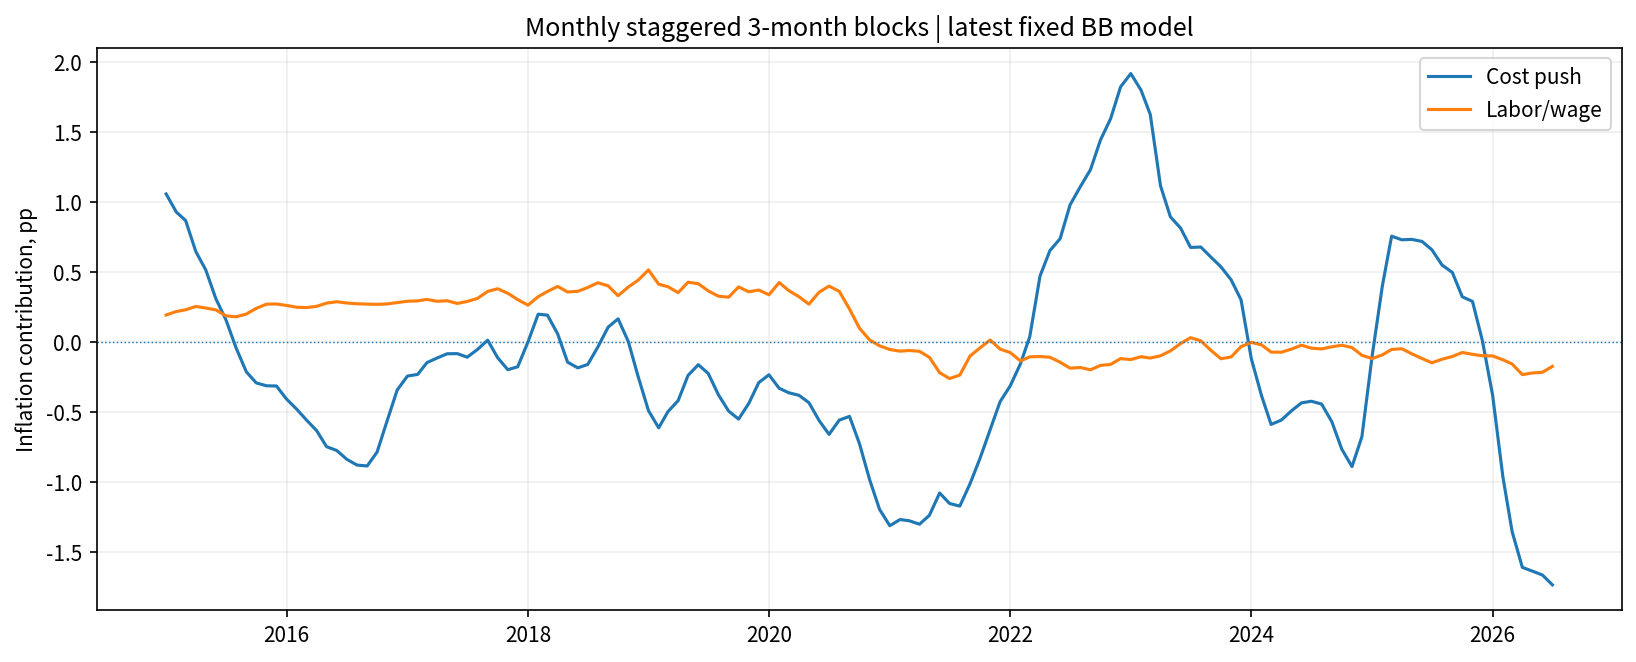

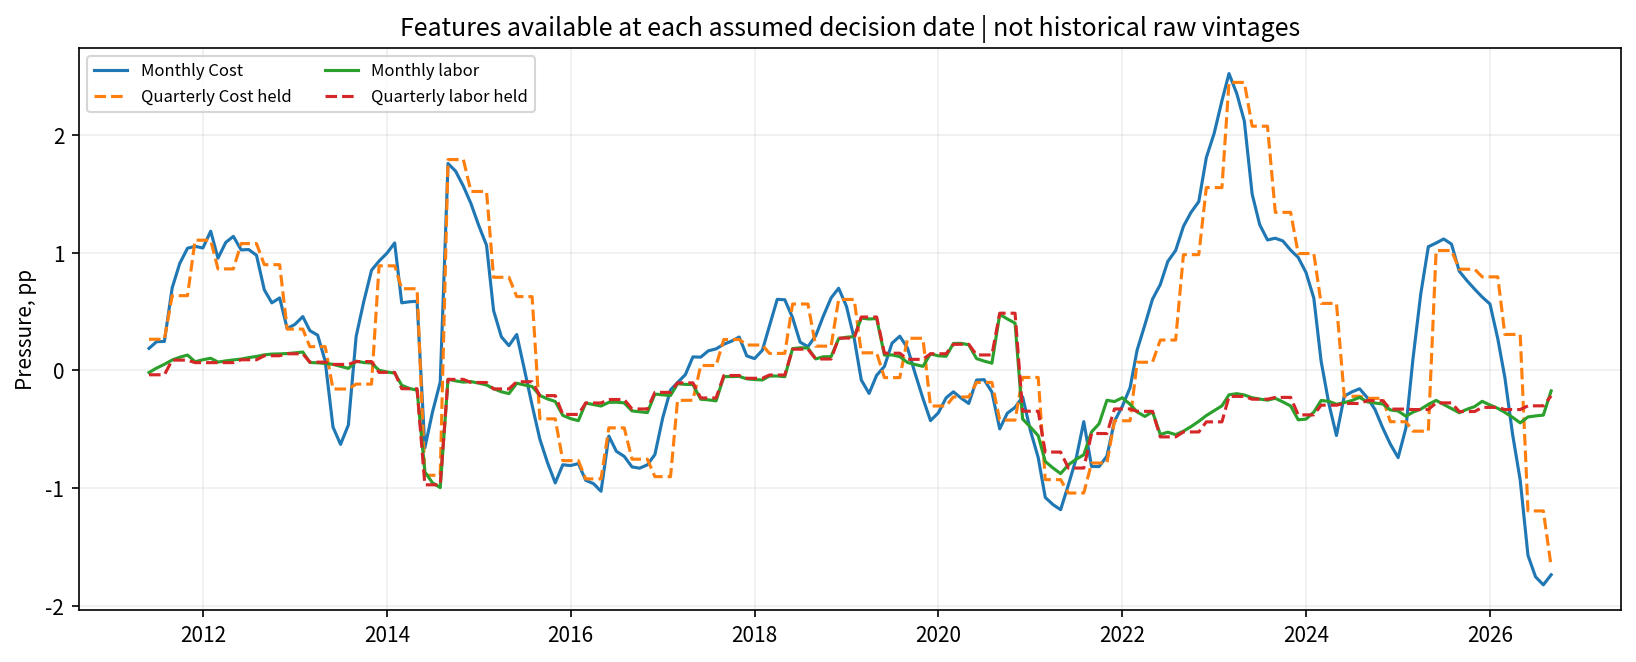

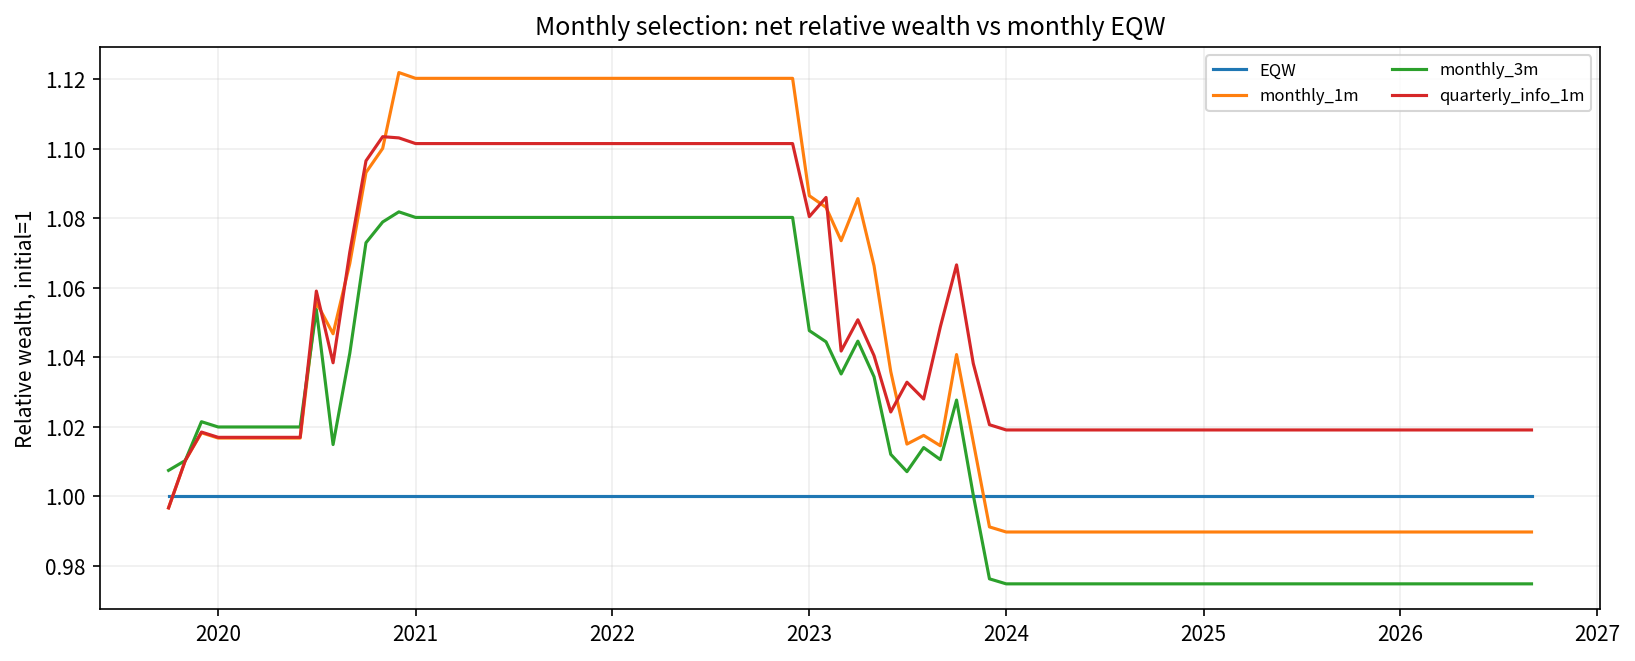

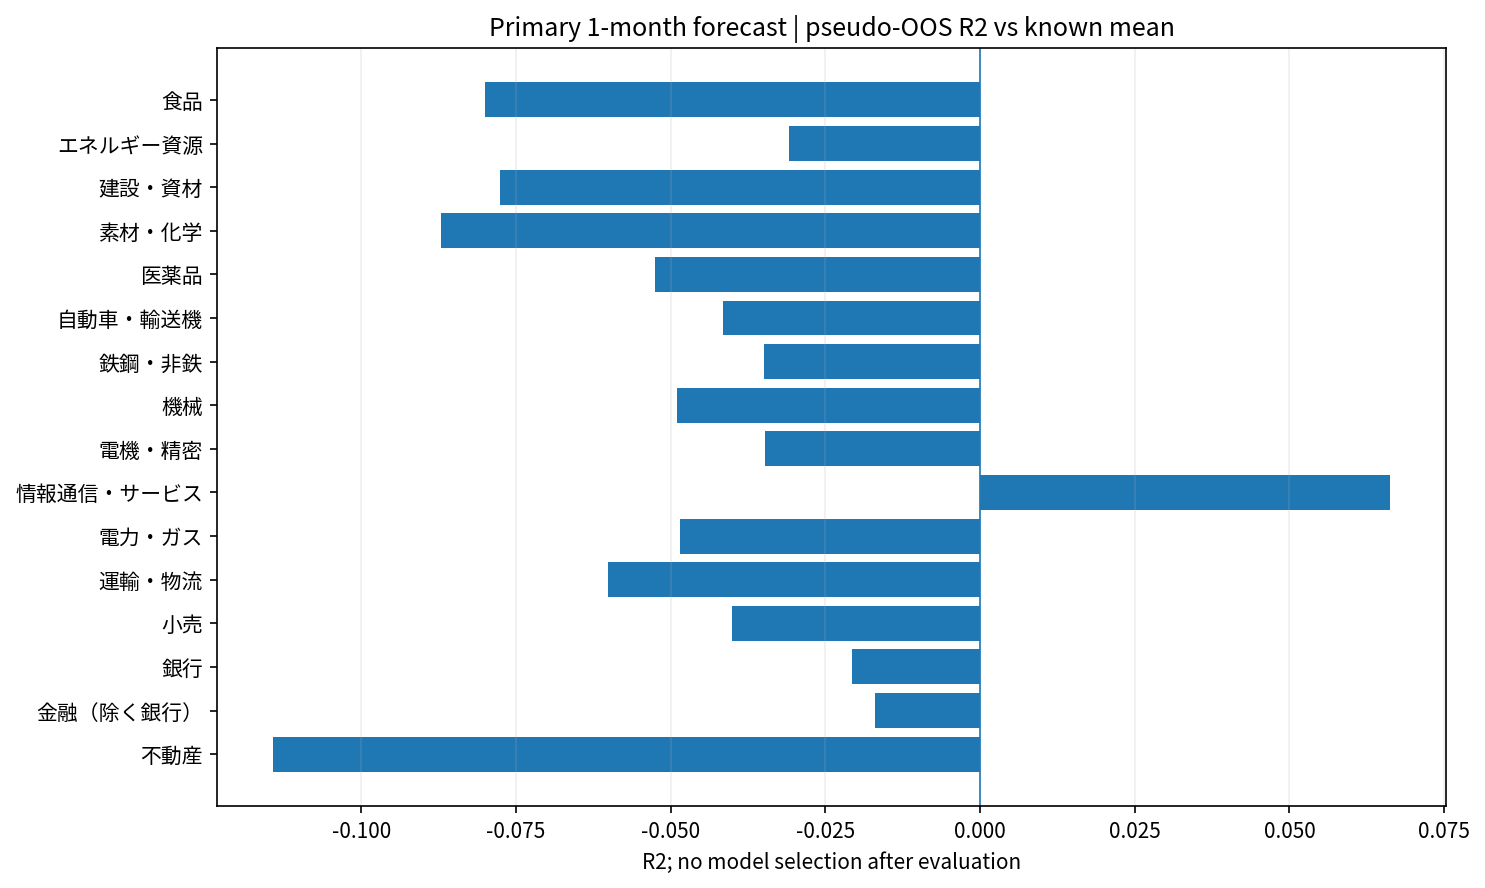

Monthly C report: /mnt/data/BB_PA_QualityGate_Ablation/outputs/runs/_inprogress_20261014T223551_112148/results/monthly_selection/report.html


In [48]:
def cm_plot(fig,name):
    fig.tight_layout();fig.savefig(CM_FIG/name,dpi=150,bbox_inches="tight");plt.close(fig)
    display(DisplayImage(filename=str(CM_FIG/name)))
_cm_recent=cm_latest_pressure.loc["2015-01":]
_cm_fig,_cm_ax=plt.subplots(figsize=(11,4.5))
for _cm_col,_cm_label in [("p_cost_push","Cost push"),("p_labor","Labor/wage")]:
    _cm_ax.plot(_cm_recent.index.to_timestamp(),_cm_recent[_cm_col],label=_cm_label)
_cm_ax.axhline(0,linewidth=.7,linestyle=":")
_cm_ax.set(title="Monthly staggered 3-month blocks | latest fixed BB model",ylabel="Inflation contribution, pp")
_cm_ax.legend();_cm_ax.grid(alpha=.2);cm_plot(_cm_fig,"01_monthly_selected_pressure.png")

_cm_fig,_cm_ax=plt.subplots(figsize=(11,4.5))
for _cm_col,_cm_label in [("p_cost_push","Monthly Cost"),("held_p_cost_push","Quarterly Cost held"),
                        ("p_labor","Monthly labor"),("held_p_labor","Quarterly labor held")]:
    _cm_ax.plot(cm_observations.index.to_timestamp(),cm_observations[_cm_col],label=_cm_label,
                linestyle="--" if _cm_col.startswith("held") else "-")
_cm_ax.set(title="Features available at each assumed decision date | not historical raw vintages",ylabel="Pressure, pp")
_cm_ax.legend(ncol=2,fontsize=8);_cm_ax.grid(alpha=.2);cm_plot(_cm_fig,"02_monthly_vs_held_information.png")

_cm_eq=cm_ledger.query("strategy=='EQW'").set_index("holding_month").net_return
_cm_fig,_cm_ax=plt.subplots(figsize=(11,4.5))
for _cm_name,_cm_g in cm_ledger.groupby("strategy"):
    _cm_r=_cm_g.set_index("holding_month").net_return
    _cm_rel=(1+_cm_r).cumprod()/(1+_cm_eq.reindex(_cm_r.index)).cumprod()
    _cm_ax.plot(pd.PeriodIndex(_cm_r.index,freq="M").to_timestamp(),_cm_rel,label=_cm_name)
_cm_ax.set(title="Monthly selection: net relative wealth vs monthly EQW",ylabel="Relative wealth, initial=1")
_cm_ax.legend(ncol=2,fontsize=8);_cm_ax.grid(alpha=.2);cm_plot(_cm_fig,"03_relative_wealth.png")

_cm_fig,_cm_ax=plt.subplots(figsize=(10,6))
_cm_eval=cm_forecast_metrics.query("strategy=='monthly_1m'").set_index("asset").reindex(current_assets)
_cm_ax.barh(np.arange(len(_cm_eval)),_cm_eval.pseudo_oos_R2_vs_frozen_expanding_mean)
_cm_ax.set_yticks(np.arange(len(_cm_eval)),_cm_eval.index);_cm_ax.invert_yaxis()
_cm_ax.axvline(0,linewidth=.8);_cm_ax.grid(axis="x",alpha=.2)
_cm_ax.set(title="Primary 1-month forecast | pseudo-OOS R2 vs known mean",xlabel="R2; no model selection after evaluation")
cm_plot(_cm_fig,"04_primary_1m_R2.png")

def cm_mdtable(df,index=False):
    d=df.reset_index() if index else df.copy()
    def val(x):
        if isinstance(x,(float,np.floating)):return "" if not np.isfinite(x) else f"{x:.4f}"
        return str(x).replace("|","/")
    return "\n".join(["| "+" | ".join(map(str,d.columns))+" |","| "+" | ".join(["---"]*len(d.columns))+" |"]+
        ["| "+" | ".join(val(x) for x in row)+" |" for row in d.itertuples(index=False,name=None)])
cm_preview=cm_latest_forecasts.query("strategy=='monthly_1m'").sort_values("research_rank")[
    ["asset","prediction_active_pp","research_rank","monthly_final","production_eligible"]]
cm_perf_display=cm_performance[["strategy","n_months","CAGR","geometric_relative_ann","information_ratio",
                              "max_drawdown","active_months","quality_hold_months"]]
cm_model_summary={"first_decision_month":str(cm_observations.index.min()),"last_decision_month":str(cm_observations.index.max()),
    "decision_months":len(cm_observations),"quarterly_models":len(cm_model_registry),
    "common_observed_month":str(CM_CURRENT_PREFIX_END),"main_horizon":1,"comparison_horizon":3,
    "quarter_end_max_abs_error":float(cm_model_registry.quarter_end_max_error.max()),"checks":len(CM_CHECKS),
    "existing_numeric_files_unchanged":len(CM_BEFORE_FILES),"full_monthly_decomposition":False,
    "quarterly_GDP_expectations_imputed":False,"release_timing":"optional calendar, otherwise explicit assumed lag",
    "historical_raw_vintages_verified":False,"execution":"month-end price boundary approximation",
    "production_eligible":False,"last_official_regime":cm_latest_version["formal"]["regime_final"]}
cm_json(cm_model_summary,"SUMMARY.json")
cm_save(cm_observations.groupby(["quarterly_regime","monthly_final"]).size().rename("months").reset_index(),
        "monthly_quality_gate_counts.csv")
cm_save(cm_rank_ic.groupby(["strategy","horizon_months"]).rank_ic.agg(["size","mean","std"]).reset_index(),
        "rank_ic_summary.csv")
cm_report=f"""# 月次マクロ更新と先1か月予測・月次投資選定
実行ID {RUN_ID}。分析基準日 {AS_OF_DATE.date()}。
主モデル=先1か月、比較=先3か月。いずれも毎月選定・次月の1ポートフォリオを会計処理。

## 実装
四半期データで推定したBB/FTPT係数を固定し、観測済みの3か月窓を毎月ずらす。
quarter lag1=3か月、最大8期=24か月。圧力P=平均(C_m,C_m-3,C_m-6,C_m-9)、News=P_m-P_m-12。
月次GDP・期待・生産性の観測は作成しない。商品・労働需給の差分寄与だけを更新。
モデル内の期待への寄与は計算するが、観測されていない期待率の月次実績とは呼ばない。

## データと現状
必要な原月次が揃う最新対象月：{CM_CURRENT_PREFIX_END}。
BBの最新完全四半期：{BB_END}。使用期待は企業{long_year}年、元コードの指定を維持。
正式四半期の最新判定：{cm_latest_version['formal']['regime_final_label']}。
主判断履歴：{cm_observations.index.min()}〜{cm_observations.index.max()}、{len(cm_observations)}か月。
係数モデル版は{len(cm_model_registry)}本。株式予測の係数・平均・SDも同じ版の利用開始時にだけ更新。

## 月次の直近状態
{cm_mdtable(cm_observations[["macro_reference_month","bb_fit_end","p_cost_push","p_labor",
                           "n_cost_push","n_labor","quarterly_regime","monthly_final"]].tail(6),True)}
公表履歴がない期間は月次{CM_CFG['monthly_release_lag_months']}か月、四半期{CM_CFG['quarterly_release_lag_months']}か月の仮定。
これは利用可能日を確認した結果ではない。カレンダー入力はkind,period,available_at。
月次Coverage・全残差品質は未観測としてNaN。旧四半期のHOLDを新しい商品データだけで解除しない。

## 紙上配分の結果
{cm_mdtable(cm_perf_display)}
率は小数（0.01=1%）。月次選定Top{CM_CFG['top_n']}等ウェイト。品質HOLD・正予測不足ならEQW。
片道{CM_CFG['one_way_cost_bps']}bp。売買額合計をドリフト比率から計算し、EQWにも月次コストを適用。
monthly_1mが主、monthly_3mは見通し期間のみ変える比較、quarterly_info_1mは月次情報を増やさない比較。
旧四半期戦略は元のpa_paper_backtestで上段に残し、重複期間の参考成績を別CSVへ保存。

## 最新の先1か月診断スコア
{cm_mdtable(cm_preview)}
予測値はEQW対比のpp。品質や未検証データを無視した売買推奨ではない。
production_eligibleは全てFalse。公表ビンテージ、実際の指数・配当・通貨・投資商品、執行価格は未確認。

## 時点整合・規則
学習は各モデル更新日時点に保有期間が終了済みの目的変数のみ、最低96か月かつ32モデル四半期。
標準化も学習期間のみ。先1か月と3か月は別のyで別に学習し、3か月予測を3で割らない。
平均損失のRidge罰則は{CM_CFG['ridge_penalty_per_observation']}。実際のX'X罰則はn倍。
判断日後の月を学習に使わず、過去の特徴量・係数版は上書きしない。
ただし原統計の過去改定・企業期待生成・Google照会は残るため真のリアルタイムOOSではない。

## 検証
暦上の四半期末では、同じモデル・同じ前処理・同じデータの既存寄与と一致。
最大絶対差 {cm_model_registry.quarter_end_max_error.max():.3e}。
入力欠損を補わない、相互位相に1か月ラグで伝播させない、FT/PTと商品内訳の加法性、
将来観測の無関係性、四半期係数固定、目的変数成熟、配分と費用、品質継承を検査。
追加{len(CM_CHECKS)}検査通過。元の{len(CM_BEFORE_FILES)}科学計算CSV/JSONは追加前後でハッシュ一致。
3位相の開始値・基準はphase_initialization_and_baselines.csv。
初期差分寄与を0とする仮定であって、未観測マクロ実績を0埋めしたのではない。

## 月次更新
元CSV更新→main.ipynbを全実行。新たなGDP月次データの取得・作成は不要。
既存結果は元フォルダ、追加結果はmonthly_selection/。
原値の末尾が揃わなければ最新共通月を使い、設定を超える追加の古さはHOLD。
実際に観測した最新値はobserved_monthly_feature_archive.csvへ実行時刻付きで保存する。
閾値やコストを過去最高成績から事後的に選ぶ処理はない。

## 解釈・出所
PIIE WP24-11（2024）p.8の四半期ラグ、p.29の発生源別直接間接寄与。
日本WP24-E-1式(1′)のFT/PTの差異を維持。
3か月窓の毎月評価・位相ごとの初期化・月次選定は本件の実装拡張で、掲載論文の厳密な再現ではない。
生産性・期待の新しい残差寄与は不明。純粋な需要・供給・財政原因を識別した月次モデルと解釈しない。
"""
(CM_DIR/"RESULTS_ja.md").write_text(cm_report,encoding="utf-8")
import html as _cm_html,base64 as _cm_b64
def cm_htmltable(df,index=False):
    return df.to_html(index=index,border=0,escape=True,float_format=lambda x:f"{x:.4f}")
def cm_image(name,caption):
    b=_cm_b64.b64encode((CM_FIG/name).read_bytes()).decode()
    return f'<figure><figcaption>{_cm_html.escape(caption)}</figcaption><img src="data:image/png;base64,{b}" alt="{_cm_html.escape(caption)}"></figure>'
_cm_body=f"""<header><p>MONTHLY MACRO / QUARTERLY PARAMETERS / 1M MAIN FORECAST</p>
<h1>月次インフレ圧力と投資選定</h1><p>主予測：先1か月 ｜ 比較：先3か月 ｜ 最新共通観測月：{CM_CURRENT_PREFIX_END}</p></header>
<section class="notice"><h2>四半期限定データを月次補完していません</h2>
<p>係数と3か月刻みの動学は四半期のまま、商品市場・労働需給の寄与を月次観測から更新します。
全残差・生産性・期待の月次実績を含む完全分解ではありません。</p>
<p>最新の正式四半期判定：<strong>{cm_latest_version['formal']['regime_final_label']}</strong>。
品質保留は月次版でも継承し、現在のスコアから機械的な本番配分を承認していません。</p></section>
<section><h2>1. 圧力の月次更新</h2>{cm_image("01_monthly_selected_pressure.png","月末をずらした3か月窓の寄与。最新係数版での説明図")}
{cm_htmltable(cm_observations[["macro_reference_month","bb_fit_end","p_cost_push","p_labor","quarterly_regime","monthly_final"]].tail(8),True)}
{cm_image("02_monthly_vs_held_information.png","各判断日で使用した月次情報と四半期情報据置の比較")}</section>
<section><h2>2. 毎月選ぶ紙上配分</h2>{cm_htmltable(cm_perf_display)}
{cm_image("03_relative_wealth.png","コスト控除後のEQW対比。先1か月主モデルと2つの比較")}
<p>月末境界の価格近似。翌営業日や2営業日後の約定を再現した日次検証ではありません。
全戦略は同じ評価月、Top4またはEQW。欠損価格月は黙って飛ばさず停止します。</p></section>
<section><h2>3. 主1か月の予測</h2>{cm_image("04_primary_1m_R2.png","学習時点の過去平均超過リターンを基準にした疑似OOS R²")}
{cm_htmltable(cm_preview)}
<p>3か月比較モデルは別目的変数で別学習。上の配分は実際の1か月リターンで会計し、予測3か月分を足していません。</p></section>
<section><h2>4. 時点・品質・公表ラグ</h2>
<p>BBと資産予測係数は四半期モデルの利用開始時だけ更新。月次2か月・四半期3か月の公表ラグは未確認時の設定仮定。
CSVに実利用可能日時を入力可能ですが、原統計の過去ビンテージ自体の復元ではありません。</p>
<p>月次Coverage・全残差は未計算のNaN。残差を0にして高品質と見せる処理はありません。
月次の条件付き候補と正式四半期の判断を分けています。</p></section>
<footer><h2>検証と参考</h2>
<p>四半期末の既存寄与との最大差 {cm_model_registry.quarter_end_max_error.max():.3e}、追加検査{len(CM_CHECKS)}件。
入力・既存数値ファイルは不変。全分析コードはmain.ipynbに完結。</p>
<p>PIIE WP24-11 p.8/p.29、日本WP24-E-1式(1′)を基礎とする追加実装。
本件の月次化仮定・公表ラグ・配分ルールは原論文で推定されたものではありません。</p></footer>"""
_cm_css='body{max-width:1130px;margin:auto;padding:34px;font-family:-apple-system,BlinkMacSystemFont,"Segoe UI","Noto Sans JP",sans-serif;line-height:1.75;color:#203343}header{border-bottom:3px solid #203e57}h1{font-size:32px}h2{font-size:23px}.notice{background:#f1f4f7;padding:18px;border-left:4px solid #203e57}table{display:block;max-width:100%;overflow:auto;border-collapse:collapse;font-size:12px}td,th{padding:8px 10px;border-bottom:1px solid #d9e0e5;text-align:right;white-space:nowrap}th{background:#edf2f6}img{max-width:100%;height:auto}section{margin:32px 0}figure{margin:24px 0}figcaption{font-weight:600}footer{border-top:2px solid #203e57;font-size:13px}'
(CM_DIR/"report.html").write_text('<!doctype html><html lang="ja"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Monthly macro selection</title><style>'+_cm_css+"</style><body>"+_cm_body+"</body></html>",encoding="utf-8")
def cm_publish_link():
    p=RESULT_DIR/"report.html"
    text=p.read_text(encoding="utf-8")
    card='<section><h2>追加：月次マクロ圧力・先1か月予測・月次選定</h2><p><a href="monthly_selection/report.html">C案の実行結果</a>。四半期の元分析は維持。月次の完全分解ではなく観測可能経路の条件付き寄与です。</p></section>'
    p.write_text(text.replace("<body>","<body>"+card,1),encoding="utf-8")
print("Monthly C report:",CM_DIR/"report.html")

# 21．BB要因別 Economic Trend：月次ローテーション
追加層の目的は、同時期の資産感応度と、その後のリターンへの予測力を分けて検証することです。
四半期BB・FT/PT・3か月窓の月次圧力計算には変更を加えません。GDP・期待実績の月次補完もしません。
AQRの感応度地図とEconomic Trend、Macrosynergyの情報時点・将来リターン検証を参考にしますが、
本件のBB指標は市場予想サプライズでも目標乖離でもありません。財政の独立寄与を追加していません。
数値設定は本研究の初期設定です。過去成績で最適化した値、論文に掲載された推奨値ではありません。

In [49]:
# === 後段追加：インフレ要因別 Economic Trend。元BB・月次C案を変更しない ===
from scipy.optimize import lsq_linear as _et_lsq_linear
import copy as _et_copy
import pickle as _et_pickle
ET_CFG=dict(ECONOMIC_TREND_CFG)
ET_DIR=RESULT_DIR/'economic_trend';ET_FIG=ET_DIR/'figures'
ET_DIR.mkdir(exist_ok=True);ET_FIG.mkdir(exist_ok=True)
ET_FACTORS=['energy','food','shortage','labor']
ET_LABELS={'energy':'エネルギー','food':'食品','shortage':'供給不足','labor':'労働需給・賃金'}
ET_GROUP_WEIGHTS=np.array([ET_CFG['factor_weights'][k] for k in ET_FACTORS],float)
ET_CHECKS=[]
def et_check(name,condition,detail=''):
    ET_CHECKS.append({'test':name,'passed':bool(condition),'detail':str(detail)})
    check('economic_trend_'+name,condition,detail)
def et_save(frame,name,index=False):
    save_csv(frame,name,index=index,folder=ET_DIR)
def et_json(obj,name):
    reg_json(obj,ET_DIR/name)
def et_fingerprint(obj):
    # pandasの読込時キャッシュを科学的内容の変更と誤認しない。
    h=hashlib.sha256()
    def visit(x):
        if isinstance(x,pd.DataFrame):
            h.update(b'DF');h.update(pd.util.hash_pandas_object(x,index=True).to_numpy().tobytes())
            h.update(repr((list(x.columns),list(map(str,x.dtypes)),x.index.names,x.columns.names)).encode())
        elif isinstance(x,pd.Series):
            h.update(b'SERIES');h.update(pd.util.hash_pandas_object(x,index=True).to_numpy().tobytes())
            h.update(repr((x.name,str(x.dtype),x.index.names)).encode())
        elif isinstance(x,pd.Index):
            h.update(b'INDEX');h.update(pd.util.hash_pandas_object(x,index=True).to_numpy().tobytes())
            h.update(repr((x.names,str(x.dtype),getattr(x,'freqstr',None))).encode())
        elif isinstance(x,np.ndarray):
            h.update(repr((x.dtype.str,x.shape)).encode())
            if x.dtype.hasobject:
                for v in x.flat:visit(v)
            else:h.update(np.ascontiguousarray(x).tobytes())
        elif isinstance(x,dict):
            h.update(b'DICT')
            for k in sorted(x,key=repr):visit(k);visit(x[k])
        elif isinstance(x,(list,tuple)):
            h.update(type(x).__name__.encode())
            for v in x:visit(v)
        elif hasattr(x,'__dataclass_fields__'):
            h.update(type(x).__name__.encode())
            for k in sorted(x.__dataclass_fields__):visit(k);visit(getattr(x,k))
        else:h.update(repr(x).encode())
    visit(obj)
    return h.hexdigest()
def et_validate_config(cfg):
    if set(cfg['factor_weights'])!=set(ET_FACTORS):raise ValueError('独立な4経路だけをスコアへ使用します')
    if not np.isclose(sum(cfg['factor_weights'].values()),1) or min(cfg['factor_weights'].values())<0:
        raise ValueError('要因配分は非負・合計1')
    if cfg['main_horizon']!=1 or cfg['comparison_horizon']!=3:raise ValueError('1か月主・3か月比較を維持')
    if cfg['map_min_quarters']<16 or cfg['calibration_min_months']<24:raise ValueError('極端に短い推定標本は禁止')
    if not 0<cfg['satellite_max']<=1:raise ValueError('アクティブ配分上限は0より大きく1以下')
    if not 1<=cfg['top_n']<=len(current_assets):raise ValueError('資産選定数が不正')
    if cfg['calibration_penalty']<=0 or cfg['trend_clip']<=0:raise ValueError('罰則・クリップ幅は正')
    if not 0<=cfg['covariance_diagonal_weight']<=1:raise ValueError('共分散縮小率が不正')
    if not cfg['inherit_hold']:raise ValueError('本版では正式HOLDを解除しません')
    if cfg['trade_cost_bps']<0:raise ValueError('取引費用は非負')
et_validate_config(ET_CFG)
ET_PROTECTED_NAMES=[k for k in ['M','Q','CFG','REG_CFG','CM_CFG','assets','current_assets','model','dual_model',
 'panel','dual_panel','dual_news_all','dual_main','reg_main','CM_MODEL_CACHE','CM_BLOCK_CACHE','CM_OBSERVATION_CACHE',
 'cm_observations','cm_predictions','cm_targets','CM_MONTHLY_RETURNS','cm_ledger','cm_weights','cm_performance'] if k in globals()]
ET_BEFORE={k:et_fingerprint(globals()[k]) for k in ET_PROTECTED_NAMES}
ET_BEFORE_FILES={str(p.relative_to(RESULT_DIR)):sha256(p.read_bytes()) for p in RESULT_DIR.rglob('*')
    if p.is_file() and p.suffix.lower() in ['.csv','.json'] and not p.is_relative_to(ET_DIR)}
ET_SCHEMA_HASH=sha256(json.dumps(ET_CFG,sort_keys=True).encode())
et_json({'config':ET_CFG,'schema_hash':ET_SCHEMA_HASH,
 'meaning':'AQR-inspired exposure map x economic trend; not a reproduction of proprietary strategies',
 'scope':'monthly sector rotation relative to EQW, 1m main / 3m comparison',
 'quarterly_macro_imputation':False,'full_monthly_decomposition':False,
 'news_is_survey_surprise':False,'raw_vintage':'latest-vintage pseudo point-in-time',
 'fiscal_extension_introduced':False,
 'sources':[
 {'title':'Bernanke & Blanchard (2024), PIIE WP24-11','location':'pp.8–9,23,29','use':'signed dynamic sources, scope of identification'},
 {'title':'Nakamura et al. (2024), BOJ WP24-E-1','location':'Eq.(1-prime), pp.5,15–16','use':'FT/PT and correlated residuals'},
 {'title':'AQR Alternative Thinking 2026 Issue 3, Inflation Redux?','location':'pp.6–7,15–16,21','use':'contemporaneous partial correlations and economic trend; no Japan 1m alpha claim'},
 {'title':'Sueppel & Sueppel, Inflation as a trading signal (2026)','url':'https://macrosynergy.com/research/inflation-as-a-trading-signal/',
 'use':'point-in-time information and forward-return testing; target-relative pressure is NOT our BB contribution'},
 {'title':'Macro trends and equity allocation (2024)','url':'https://macrosynergy.com/research/macro-trends-and-equity-allocation-a-brief-introduction/',
 'use':'relative sector forecasts and panel dependence; not copied parameters'}]},'method_contract.json')


## 21A．四半期ごとの感応度地図
対象はエネルギー・食品・供給不足・労働需給の4経路。Cost総合やFT/PT内訳は二重加算しません。
各四半期版で、同時12か月EQW対比リターンとNewsOnlyの成長統制後偏相関を推定します。
最低24四半期、n/(n+24)の縮小、直近24四半期・終端4期除外との符号一致度を初期規則とします。
これらは推定精度の確率ではなく、過大なスコアを避ける保守的な規則です。p値・BHは診断として保存。
資産間で共通の感応度を除き、相対エクスポージャを作ります。12か月βを12で割って翌月βにはしません。

In [50]:
def et_safe_partial(y,x,g):
    a=np.asarray(x,float);b=np.asarray(y,float);gg=np.asarray(g,float)
    z=np.column_stack([np.ones(len(a)),gg])
    if len(a)<6 or not np.isfinite(np.column_stack([a,b,gg])).all() or np.linalg.matrix_rank(z)<2:return np.nan
    return partial_corr(b,a,z)

def et_fit_map(version,monthly_returns,quarter_raw,cfg):
    """同時12か月リターンとBB News。版の推定終期より後の観測は一切読まない。"""
    q=version['q'];end=q.asfreq('M','end')
    paths=cm_contribution_paths(version['monthly_blocks_at_fit'],version['compiled'],version['baseline'])
    p=cm_pressure_from_paths(paths)
    for k in ET_FACTORS:p['d3_'+k]=p['p_'+k]-p['p_'+k].shift(3)
    ret=monthly_returns.loc[:end].copy()
    eq=ret.mean(axis=1).where(ret.notna().all(axis=1))
    r12=100*np.expm1(np.log1p(ret).rolling(12,min_periods=12).sum())
    b12=100*np.expm1(np.log1p(eq).rolling(12,min_periods=12).sum())
    active=r12.sub(b12,axis=0)
    qidx=active.index[active.index.month%3==0]
    yy=active.loc[qidx].copy();yy.index=qidx.asfreq('Q')
    x=p.loc[p.index.month%3==0].copy();x.index=x.index.asfreq('Q')
    gdp=quarter_raw.loc[:q,'gdp_real_sa_annualized']
    gg=(100*(gdp/gdp.shift(4)-1)).diff(4)
    common=yy.dropna().index.intersection(x[[f'n_{k}' for k in ET_FACTORS]].dropna().index).intersection(gg.dropna().index)
    if len(common)<cfg['map_min_quarters']:
        return None,{'bb_version':version['version'],'q':str(q),'n_quarters':len(common),'status':'map_warmup'}
    y=yy.loc[common];g=gg.loc[common]
    rec=[];emap=np.zeros((len(current_assets),len(ET_FACTORS)))
    n=len(common);recent=common[-min(cfg['map_recent_quarters'],n):];oldend=common[:-4]
    shrink=n/(n+cfg['map_shrink_quarters'])
    for j,k in enumerate(ET_FACTORS):
        nx=x.loc[common,'n_'+k]
        for i,a in enumerate(current_assets):
            rho=et_safe_partial(y[a],nx,g)
            rr=et_safe_partial(y.loc[recent,a],nx.loc[recent],g.loc[recent])
            ro=et_safe_partial(y.loc[oldend,a],nx.loc[oldend],g.loc[oldend]) if len(oldend)>=12 else np.nan
            stable=np.mean([float(np.isfinite(r) and np.isfinite(rho) and np.sign(r)==np.sign(rho)) for r in [rr,ro]])
            value=(rho if np.isfinite(rho) else 0.)*shrink*stable
            emap[i,j]=value
            X=np.column_stack([np.ones(n),nx,g]);fit=None
            if np.linalg.matrix_rank(X)==3:fit=ols_hac(y[a],X,cfg['map_hac_quarters'])
            rec.append({'bb_model_version':version['version'],'fit_end':str(q),'asset':a,'factor':k,
             'n_quarters':n,'start_quarter':str(common.min()),'last_return_month':str(end),
             'partial_corr_news':rho,'partial_corr_recent':rr,'partial_corr_exlast4':ro,
             'sample_shrink':shrink,'sign_stability':stable,'raw_exposure':value,
             'beta_12m_per_1pp':float(fit['beta'][1]) if fit is not None else np.nan,
             'p_hac8_diagnostic':float(fit['p'][1]) if fit is not None else np.nan,
             'role':'exposure direction, not forecast coefficient; no dividing 12m beta by 12'})
    # 資産間で共通の感応度は相対配分に寄与しないため中心化。
    e=emap-emap.mean(axis=0,keepdims=True)
    scale_records=[];scales={}
    scale_ix=p.index[(p.index<=end)&(p.index>=end-cfg['trend_scale_months']+1)]
    for k in ET_FACTORS:
        for signal,col in [('news','n_'+k),('d3','d3_'+k)]:
            v=p.loc[scale_ix,col].dropna();sd=float(v.std(ddof=1))
            scales[(signal,k)]=sd if np.isfinite(sd) and sd>cfg['min_signal_scale_pp'] else np.nan
            scale_records.append({'factor':k,'signal':signal,'scale_sd':scales[(signal,k)],
             'n_scale_months':len(v),'scale_first_month':str(v.index.min()),'scale_last_month':str(v.index.max()),
             'zero_anchor':True,'demean_signal':False})
    # 成長ローディングはリスク診断用。将来の月次GDPを生成しない。
    gx=np.column_stack([np.ones(n),g]);gb=[]
    for a in current_assets:gb.append(float(np.linalg.lstsq(gx,y[a],rcond=None)[0][1]*g.std(ddof=1)))
    records=pd.DataFrame(rec)
    records['centered_exposure']=[e[current_assets.index(r.asset),ET_FACTORS.index(r.factor)] for r in records.itertuples()]
    records['q_bh_diagnostic']=bh_adjust(records.p_hac8_diagnostic)
    model={'q':q,'bb_version':version['version'],'exposures':e,'records':records,'scales':scales,
           'scale_records':scale_records,'growth_beta_12m_1sd_pp':np.array(gb),'n_quarters':n,
           'scale_end':end,'calendar_pressure':x}
    model['map_id']='map_'+str(q)+'_'+et_fingerprint({'E':e,'scales':scales})[:10]
    model['records']['map_id']=model['map_id']
    return model,{'bb_version':version['version'],'q':str(q),'map_id':model['map_id'],'n_quarters':n,'status':'fitted'}

ET_MAPS={};et_map_rows=[];et_map_audit=[];et_scale_rows=[]
for _et_v in sorted(CM_MODEL_CACHE.values(),key=lambda v:v['q']):
    _et_map,_et_log=et_fit_map(_et_v,CM_MONTHLY_RETURNS,Q,ET_CFG)
    et_map_audit.append(_et_log)
    if _et_map is not None:
        ET_MAPS[_et_v['version']]=_et_map
        et_map_rows.append(_et_map['records'])
        et_scale_rows.extend([dict(r,map_id=_et_map['map_id'],bb_model_version=_et_v['version']) for r in _et_map['scale_records']])
if not ET_MAPS:raise ValueError('Economic Trendの感応度推定に必要な四半期履歴が不足しています')
et_exposures=pd.concat(et_map_rows,ignore_index=True)
et_save(et_exposures,'exposure_maps_by_version.csv')
et_save(pd.DataFrame(et_map_audit),'exposure_estimation_audit.csv')
et_save(pd.DataFrame(et_scale_rows),'quarterly_fixed_trend_scales.csv')


## 21B．毎月の要因トレンド
主シグナルは既存N=P_m−P_(m−12)。比較はNとD3=P_m−P_(m−3)を同じ比率で合成します。
D3は同じ位相・同じ四半期係数・当期までの加工履歴で計算し、古い公表値との差とは区別します。
四半期に固定した最大120か月のSDで割り、経済的ゼロを保って±2SDで打切ります。
標本平均を引いて、負の圧力変化を正に変えることはしません。正部分を取る分類用指標を回帰へ転用しません。
商品市場に50%、労働市場に50%の信号配分。商品内は3等分。小さな要因を多数に分けて重複配分しません。

In [51]:
def et_standardized_trend(value,scale,clip):
    if not np.isfinite(value):raise ValueError('観測欠損をゼロのマクロ信号へ置換しません')
    if not np.isfinite(scale) or scale<=0:return 0.,False
    return float(np.clip(value/scale,-clip,clip)/clip),True

def et_build_signals(observations,maps,config):
    by_date={};factor_rows=[];score_rows=[]
    for d,row in observations.iterrows():
        if row.bb_model_version not in maps:continue
        mp=maps[row.bb_model_version];v=CM_MODEL_CACHE[str(mp['q'])]
        month=pd.Period(row.macro_reference_month,freq='M')
        if pd.Timestamp(row.bb_model_available_at)>d.end_time or pd.Timestamp(row.feature_available_at)>d.end_time:
            raise ValueError('判断日より後の情報')
        # 同じモデル版・当期までの加工履歴からD3を計算。過去as-issued値との単純差ではない。
        blocks=CM_BLOCK_CACHE.get(str(month))
        if blocks is None:blocks=cm_monthly_blocks(M,month,CFG,GOOGLE_SCALE,GOOGLE_FILL)[0]
        path=cm_contribution_paths(blocks,v['compiled'],v['baseline'])
        pp=cm_pressure_from_paths(path)
        tn=[];td=[];availability=[]
        for k in ET_FACTORS:
            nv=float(row['n_'+k]);pv=float(row['p_'+k]);dv=float(pp.loc[month,'p_'+k]-pp.loc[month-3,'p_'+k])
            if not np.isclose(nv,pp.loc[month,'n_'+k],atol=1e-8):raise AssertionError('既存NewsOnlyと不一致')
            nvz,nok=et_standardized_trend(nv,mp['scales'][('news',k)],config['trend_clip'])
            dvz,dok=et_standardized_trend(dv,mp['scales'][('d3',k)],config['trend_clip'])
            tn.append(nvz);td.append(dvz);availability.append(nok and dok)
            factor_rows.append({'decision_month':str(d),'macro_reference_month':str(month),
             'bb_model_version':row.bb_model_version,'map_id':mp['map_id'],'factor':k,
             'pressure_pp':pv,'news_12m_pp':nv,'pressure_change_3m_pp':dv,
             'trend_news':nvz,'trend_d3':dvz,'trend_news_d3':.5*(nvz+dvz) if nok and dok else 0.,
             'news_scale_usable':nok,'d3_scale_usable':dok,'formal_quality':row.monthly_quality,
             'economic_state':('上押し' if pv>0 else '下押し' if pv<0 else 'ゼロ'),
             'direction_12m':('拡大方向' if nv>0 else '縮小方向' if nv<0 else '横ばい'),
             'interpretation':'D3=同位相3か月差、N=12か月差。調査予想サプライズではない',
             'g_last_published_q':row.g_last_published_q,'feature_available_at':row.feature_available_at})
        tn=np.asarray(tn);td=np.asarray(td);tb=np.where(availability,.5*(tn+td),0.)
        zn=mp['exposures']*tn[None,:]*ET_GROUP_WEIGHTS[None,:]
        zb=mp['exposures']*tb[None,:]*ET_GROUP_WEIGHTS[None,:]
        reliability=mp['records'].assign(_confidence=mp['records'].sample_shrink*mp['records'].sign_stability).groupby('factor')._confidence.mean().reindex(ET_FACTORS).to_numpy()
        by_date[d]={'news':zn,'news_d3':zb,'trend_news':tn,'trend_news_d3':tb,'map':mp,
          'confidence_news':float(ET_GROUP_WEIGHTS@(abs(tn)*reliability)),
          'confidence_news_d3':float(ET_GROUP_WEIGHTS@(abs(tb)*reliability)),
          'quality_allowed':bool(row.eligible_quality),'row':row.copy()}
        for j,k in enumerate(ET_FACTORS):
            for i,a in enumerate(current_assets):
                score_rows.append({'decision_month':str(d),'asset':a,'factor':k,'map_id':mp['map_id'],
                 'bb_model_version':row.bb_model_version,'exposure':mp['exposures'][i,j],
                 'group_weight':ET_GROUP_WEIGHTS[j],'trend_news':tn[j],'trend_news_d3':tb[j],
                 'fixed_score_news':zn[i,j],'fixed_score_news_d3':zb[i,j],
                 'eligible_quality':bool(row.eligible_quality),'is_return_forecast':False})
    return by_date,pd.DataFrame(factor_rows),pd.DataFrame(score_rows)
ET_SIGNAL_DATA,et_trends,et_fixed_components=et_build_signals(cm_observations,ET_MAPS,ET_CFG)
if not ET_SIGNAL_DATA:raise ValueError('月次の感応度と観測情報を結合できません')
et_save(et_trends,'factor_trends_by_decision.csv')
et_save(et_fixed_components,'fixed_exposure_times_trend_scores.csv')
et_signal_dates=pd.PeriodIndex(sorted(ET_SIGNAL_DATA),freq='M',name='decision_month')
et_check('4_nonduplicated_factor_paths',ET_FACTORS==['energy','food','shortage','labor'])
et_check('same_quarterly_maps_until_refit',et_fixed_components.groupby(['bb_model_version','asset','factor']).exposure.nunique().le(1).all())
et_check('zero_anchored_bounded_trends',et_trends[['trend_news','trend_d3','trend_news_d3']].abs().max().max()<=1+1e-12)


## 21C．要因エクスポージャを翌月リターンへ接続
主は4つの共通係数による翌1か月予測。先3か月は独立に学習する比較で、主戦略を事後変更しません。
各学習行は当時の感応度マップ×当時のトレンドです。最新マップで過去の説明変数を塗り替えません。
最低36か月・12モデル版の終了済みラベルで、非負・Ridge縮小付き4係数を学習。係数と尺度は四半期版で固定。
感応度マップ24四半期の後に36か月が必要なので、従来の96か月単一モデルとwarmupは異なります。
16資産はクロスセクションの情報に使いますが、16Nを独立マクロ標本数とした有意性は出しません。
品質HOLD期間の観測も研究モデル学習に含めますが、保有には使いません。各学習期間の品質許可月数も監査します。

In [52]:
ET_SPEC={
 'et_news_1m':{'signal':'news','h':1,'role':'PRIMARY'},
 'et_news_d3_1m':{'signal':'news_d3','h':1,'role':'SHORTER_TREND_COMPARISON'},
 'et_news_3m':{'signal':'news','h':3,'role':'HORIZON_COMPARISON'},
}

def et_train_shared(features,targets,penalty):
    """月×資産×4因子。月内中心化、非負Ridge。16資産を独立なマクロ標本と数えない。"""
    x=np.asarray(features,float);y=np.asarray(targets,float)
    if x.ndim!=3 or y.shape!=x.shape[:2] or x.shape[2]!=4:raise ValueError('共通係数の入力形状')
    if not np.isfinite(x).all() or not np.isfinite(y).all():raise ValueError('共通係数の学習に欠損')
    if penalty<=0:raise ValueError('平均損失のRidge罰則は正')
    if np.max(abs(x.mean(axis=1)))>1e-10:raise ValueError('相対資産エクスポージャは月内中心化が必要')
    centered_y=y-y.mean(axis=1,keepdims=True)
    rms=np.sqrt(np.mean(x*x,axis=(0,1)));use=np.isfinite(rms)&(rms>1e-10)
    beta=np.zeros(4);rawcoef=np.zeros(4)
    if use.any():
        z=(x[:,:,use]/rms[use]).reshape(-1,use.sum());yy=centered_y.reshape(-1)
        # 平均損失規準。同じ資産の複製で縮小強度を変えない。
        nrows=len(z);aa=np.vstack([z/np.sqrt(nrows),np.sqrt(penalty)*np.eye(use.sum())])
        bb=np.r_[yy/np.sqrt(nrows),np.zeros(use.sum())]
        result=_et_lsq_linear(aa,bb,bounds=(0.,np.inf),tol=1e-11,max_iter=500)
        if not result.success:raise ValueError('共通係数の制約付き回帰が未収束')
        beta[use]=result.x;rawcoef[use]=result.x/rms[use]
    return {'lambda':rawcoef,'beta_scaled':beta,'rms':rms,'used':use,
     'common_intercept_pp':float(y.mean()),'asset_historical_mean':y.mean(axis=0),
     'n_months':len(x),'n_assets':x.shape[1],'penalty':penalty,
     'no_independent_panel_t_statistics':True}

def et_month_train_indices(dates,refit,h,execution_lag,targets):
    idx=dates[dates+execution_lag+h<=refit]
    return idx.intersection(targets.dropna().index)

def et_walkforward(signals,targets,config):
    dates=pd.PeriodIndex(sorted(signals),freq='M');preds=[];trainlog=[];coefrows=[];parts=[];fitted={}
    for name,spec in ET_SPEC.items():
        h=spec['h'];sig=spec['signal'];old_version=None;mdl=None;train=None;refit=None;aid=None
        for d in dates:
            v=signals[d]['row'].bb_model_version
            if v!=old_version:
                old_version=v;refit=d;mdl=None
                train=et_month_train_indices(dates,d,h,CM_CFG['execute_lag_months'],targets[h])
                nvers=len({signals[z]['row'].bb_model_version for z in train})
                ready=len(train)>=config['calibration_min_months'] and nvers>=config['calibration_min_versions']
                trainlog.append({'strategy':name,'refit_month':str(d),'bb_model_version':v,'horizon_months':h,
                  'n_train_months':len(train),'n_distinct_versions':nvers,
                  'n_gate_allowed_train_months':sum(signals[z]['quality_allowed'] for z in train),
                  'last_label_end':str(train.max()+CM_CFG['execute_lag_months']+h) if len(train) else '',
                  'first_train_month':str(train.min()) if len(train) else '',
                  'status':'trained' if ready else 'second_stage_warmup',
                  'map_history':'as-issued map at each historical decision, not current map backfilled',
                  'cross_section_used_for_loss_only':True})
                if ready:
                    xx=np.stack([signals[z][sig] for z in train]);yy=targets[h].loc[train,current_assets].to_numpy()
                    mdl=et_train_shared(xx,yy,config['calibration_penalty'])
                    aid=name+'_'+str(d)+'_'+et_fingerprint(mdl)[:10];fitted[aid]=mdl
                    for j,k in enumerate(ET_FACTORS):
                        coefrows.append({'asset_model_version':aid,'strategy':name,'refit_month':str(d),
                         'factor':k,'lambda_nonnegative':mdl['lambda'][j],'scaled_beta_pp':mdl['beta_scaled'][j],
                         'training_rms':mdl['rms'][j],'used':mdl['used'][j],
                         'common_intercept_pp':mdl['common_intercept_pp'],'train_months':len(train),
                         'last_label_end':str(train.max()+CM_CFG['execute_lag_months']+h),
                         'interpretation':'4 common horizon-specific coefficients; no per-asset forward slope'})
            if mdl is None:continue
            terms=signals[d][sig]*mdl['lambda'][None,:]
            score=terms.sum(axis=1);prediction=mdl['common_intercept_pp']+score
            for i,a in enumerate(current_assets):
                base=signals[d]['row']
                preds.append({'strategy':name,'decision_month':d,'holding_month':str(d+CM_CFG['execute_lag_months']+1),
                  'horizon_months':h,'role':spec['role'],'asset':a,'signal':sig,
                  'prediction_active_pp':float(prediction[i]),'selection_score':float(score[i]),
                  'common_intercept_pp':mdl['common_intercept_pp'],
                  'historical_mean_pp':float(mdl['asset_historical_mean'][i]),
                  'actual_forward_active_pp':targets[h].loc[d,a],
                  'asset_model_version':aid,'asset_model_refit_month':str(refit),
                  'bb_model_version':v,'map_id':signals[d]['map']['map_id'],'macro_reference_month':base.macro_reference_month,
                  'feature_available_at':base.feature_available_at,'eligible_quality':bool(base.eligible_quality),
                  'monthly_quality':base.monthly_quality,'monthly_final':base.monthly_final,
                  'regime_candidate':base.regime_stable,'production_eligible':False})
                for j,k in enumerate(ET_FACTORS):
                    parts.append({'strategy':name,'decision_month':str(d),'asset':a,'factor':k,
                      'map_id':signals[d]['map']['map_id'],'asset_model_version':aid,
                      'exposure_times_trend':signals[d][sig][i,j],'lambda':mdl['lambda'][j],
                      'forecast_contribution_pp':terms[i,j]})
    return pd.DataFrame(preds),pd.DataFrame(trainlog),pd.DataFrame(coefrows),pd.DataFrame(parts),fitted

et_predictions,et_training,et_shared_coefficients,et_forecast_parts,ET_SHARED_MODELS=et_walkforward(ET_SIGNAL_DATA,cm_targets,ET_CFG)
if et_predictions.empty:raise ValueError('二段階学習の評価期間が不足。学習条件を自動緩和せず、履歴追加を確認してください')
et_save(et_predictions,'forecasts_1m_main_3m_comparison.csv')
et_save(et_training,'shared_model_training_audit.csv')
et_save(et_shared_coefficients,'quarterly_fixed_shared_coefficients.csv')
et_save(et_forecast_parts,'forecast_factor_attribution.csv')
_et_firsts=et_predictions.groupby('strategy').decision_month.min()
ET_COMMON_START=max(max(_et_firsts),max(cm_predictions.groupby('strategy').decision_month.min()))
ET_COMMON_END=min(et_predictions.decision_month.max(),CM_MONTHLY_RETURNS.index.max()-CM_CFG['execute_lag_months']-1)
ET_EVALUATION_DATES=pd.period_range(ET_COMMON_START,ET_COMMON_END,freq='M')
et_json({'evaluation_start_decision':str(ET_COMMON_START),'evaluation_end_decision':str(ET_COMMON_END),
 'stages':{'exposure_min_quarters':ET_CFG['map_min_quarters'],'second_stage_min_months':ET_CFG['calibration_min_months']},
 'purpose':'predeclared two-stage warmup; not copied to replace original C-model warmup',
 'dates_different_from_old_model':True,'first_forecasts_by_strategy':{k:str(v) for k,v in _et_firsts.items()}},'evaluation_window.json')


## 21D．EQW＋衛星配分・取引費用・リスク制御
主配分はlong-onlyで、上位4セクターの等ウェイト衛星を最大20%までEQWへ混合します。
実際の衛星比率は信号の強さ・マップの安定性・相殺で小さくし、さらにTE・成長ローディングの上限を適用。
正式HOLDは即時にEQWへ戻します。HOLD解除や未観測マクロの捏造で売買機会を増やしません。
メンバー変更は予測改善と追加売買費用を比較し、費用を超えなければ旧メンバーを維持。リスク上限は常に再適用。
固定スコア比較だけは期待リターンへ偽装せず、スコア単位の緩衝帯を使用します。
毎月1つのポートフォリオの翌月損益を計上し、先3か月予測でも3か月リターンを毎月足しません。
legacy_*は従来のTop4、matched_Ridgeは同じ衛星上限・リスク規則をRidgeに適用する比較です。

In [53]:
def et_risk_state(returns,decision,config):
    d=returns.loc[:decision].tail(config['risk_lookback_months']).dropna()
    if len(d)<config['risk_min_months']:return None
    cov=d.cov().to_numpy();a=config['covariance_diagonal_weight']
    cov=(1-a)*cov+a*np.diag(np.diag(cov))
    return {'covariance':cov,'n':len(d),'last_return_month':str(d.index.max())}

def et_capped_eta(unit_active,eta,cov,growth_beta,config):
    te=np.sqrt(max(0.,12*float(unit_active@cov@unit_active)))
    grow=abs(float(unit_active@growth_beta))
    if te>0:eta=min(eta,config['max_active_te_annual']/te)
    if grow>0:eta=min(eta,config['max_growth_loading_12m_1sd_pp']/grow)
    if eta<config['min_eta']:eta=0.
    return float(eta)

def et_rotation_backtest(predictions,signals,legacy_predictions,returns,config,cost_bps):
    n=len(current_assets);bm=np.repeat(1/n,n)
    variants=list(ET_SPEC)+['et_fixed_news','ridge_1m_matched','legacy_monthly_1m','legacy_monthly_3m','legacy_quarterly_info_1m','EQW']
    decisions=pd.period_range(ET_COMMON_START,min(predictions.decision_month.max(),returns.index.max()),freq='M')
    pred_lookup={(s,d):g.set_index('asset').reindex(current_assets) for (s,d),g in predictions.groupby(['strategy','decision_month'])}
    old_lookup={(s,d):g.set_index('asset').reindex(current_assets) for (s,d),g in legacy_predictions.groupby(['strategy','decision_month'])}
    ledgers=[];weight_rows=[];factor_risk=[]
    for name in variants:
        pre=bm.copy();prior_target=bm.copy();prior_members=[]
        for d in decisions:
            if d not in signals:raise ValueError(f'{d}: macro signal unavailable')
            ss=signals[d];mp=ss['map'];quality=ss['quality_allowed'];sig='news';h=1;score=np.zeros(n);pred=None
            model_id='fixed_map';parts=None
            if name in ET_SPEC:
                frame=pred_lookup.get((name,d))
                if frame is None or frame.prediction_active_pp.isna().any():raise ValueError(f'{name}/{d}:予測欠落')
                h=ET_SPEC[name]['h'];sig=ET_SPEC[name]['signal'];score=frame.selection_score.to_numpy()
                pred=frame.prediction_active_pp.to_numpy();model_id=frame.asset_model_version.iloc[0]
                mdl=ET_SHARED_MODELS[model_id];parts=ss[sig]*mdl['lambda'][None,:]
            elif name=='et_fixed_news':score=ss['news'].sum(axis=1);parts=ss['news']
            elif name.startswith('legacy_') or name=='ridge_1m_matched':
                oldname=name.removeprefix('legacy_') if name.startswith('legacy_') else 'monthly_1m'
                frame=old_lookup.get((oldname,d))
                if frame is None or frame.prediction_active_pp.isna().any():raise ValueError(f'比較予測欠落 {oldname}/{d}')
                score=frame.prediction_active_pp.to_numpy();pred=score.copy();h=int(frame.horizon_months.iloc[0])
                model_id=frame.asset_model_version.iloc[0]
            target=bm.copy();eta=0.;reason='EQW_benchmark';selected=[];switch_hurdle=False;cost_adv=np.nan
            rrisk=et_risk_state(returns,d,config)
            cancellation=1.
            if parts is not None:
                denom=float(np.sqrt(np.mean(parts**2,axis=0)).sum())
                cancellation=float(np.clip(np.sqrt(np.mean(parts.sum(axis=1)**2))/denom,0,1)) if denom>1e-12 else 0.
            if name!='EQW':
                if not quality:reason='EQW_quality_HOLD'
                elif not np.isfinite(score).all():raise ValueError('投資スコアが非有限')
                elif (score>1e-10).sum()<config['top_n']:reason='EQW_insufficient_positive_or_zero_signal'
                elif rrisk is None:reason='EQW_insufficient_risk_history'
                else:
                    order=np.argsort(-score,kind='stable');selected=list(order[:config['top_n']])
                    u=np.zeros(n);u[selected]=1/config['top_n']
                    if name.startswith('legacy_'):
                        target=u;eta=1.;reason='legacy_Top4_unchanged_rule'
                    else:
                        base_eta=config['satellite_max']*ss['confidence_'+sig]*cancellation
                        eta=et_capped_eta(u-bm,base_eta,rrisk['covariance'],mp['growth_beta_12m_1sd_pp'],config)
                        target=bm+eta*(u-bm);reason='economic_trend_tilt' if name!='ridge_1m_matched' else 'matched_Ridge_tilt'
                        # 予測ppを使える場合だけ費用ppと比較。固定スコアをリターンと偽らない。
                        can_retain=len(prior_members)==config['top_n'] and np.all(score[prior_members]>1e-10)
                        if can_retain and set(prior_members)!=set(selected) and eta>0:
                            old_u=np.zeros(n);old_u[prior_members]=1/config['top_n']
                            old_eta=et_capped_eta(old_u-bm,base_eta,rrisk['covariance'],mp['growth_beta_12m_1sd_pp'],config)
                            keep=bm+old_eta*(old_u-bm)
                            if pred is not None and config['use_cost_hurdle']:
                                advantage=float(pred@(target-keep))
                                extra_cost=max(0.,(np.abs(target-pre).sum()-np.abs(keep-pre).sum())*cost_bps/100)
                                cost_adv=advantage-extra_cost
                                switch_hurdle=advantage<=extra_cost+1e-12
                            elif pred is None:
                                advantage=float(score@(u-old_u))
                                switch_hurdle=advantage<config['fixed_score_switch_gap']
                            if switch_hurdle:
                                target=keep;eta=old_eta;selected=prior_members.copy();reason='retain_members_switch_hurdle'
                        if eta==0:target=bm.copy();selected=[];reason='EQW_weak_signal_or_risk_budget'
            holding=d+CM_CFG['execute_lag_months']+1
            active=target-bm
            exte=float(np.sqrt(max(0.,12*active@rrisk['covariance']@active))) if rrisk is not None else 0.
            growth_load=float(active@mp['growth_beta_12m_1sd_pp'])
            trade=float(np.abs(target-pre).sum());cost=trade*cost_bps/10000
            if cost>=1:raise ValueError('過大な費用で資産が負になります')
            for i,a in enumerate(current_assets):
                weight_rows.append({'strategy':name,'decision_month':str(d),'holding_month':str(holding),'asset':a,
                 'target_weight':target[i],'active_weight':active[i],'satellite_weight':eta,
                 'score':score[i],'forecast_horizon_months':h,'selection_reason':reason,
                 'forecast_active_pp':float(pred[i]) if pred is not None else np.nan,
                 'bb_model_version':ss['row'].bb_model_version,'map_id':mp['map_id'],'asset_model_version':model_id,
                 'macro_reference_month':ss['row'].macro_reference_month,'monthly_final':ss['row'].monthly_final,
                 'production_eligible':False,'unrealized_latest_target':holding>returns.index.max()})
            for j,k in enumerate(ET_FACTORS):
                factor_risk.append({'strategy':name,'decision_month':str(d),'factor':k,
                  'active_exposure_score':float(active@mp['exposures'][:,j]),
                  'forecast_component_pp':float(active@parts[:,j]) if parts is not None and pred is not None else np.nan,
                  'meaning':'score/forecast attribution, not causal attribution of realized returns'})
            if holding>returns.index.max():continue
            if holding not in returns.index or returns.loc[holding].isna().any():raise ValueError(f'{holding}:価格欠損を期間飛ばししません')
            r=returns.loc[holding].to_numpy(float);gross=float(target@r);net=(1-cost)*(1+gross)-1
            ledgers.append({'strategy':name,'decision_month':str(d),'holding_month':str(holding),'gross_return':gross,
             'net_return':net,'trade_notional':trade,'turnover_half_L1':trade/2,'cost_fraction':cost,
             'one_way_cost_bps':cost_bps,'satellite_weight':eta,'exante_tracking_error':exte,
             'growth_loading_12m_1sd_pp':growth_load,'selection_reason':reason,'quality_allowed':quality,
             'macro_reference_month':ss['row'].macro_reference_month,'bb_model_version':ss['row'].bb_model_version,
             'map_id':mp['map_id'],'asset_model_version':model_id,'factor_cancellation_ratio':cancellation,
             'switch_hurdle_applied':switch_hurdle,'forecast_advantage_net_extra_cost_pp':cost_adv,
             'regime_candidate':ss['row'].regime_stable,'monthly_final':ss['row'].monthly_final,
             'weight_change_L1':float(np.abs(target-prior_target).sum()),
             'selected_members':';'.join(current_assets[i] for i in selected),
             'role':'original CM comparator' if name.startswith('legacy_') else 'research only'})
            if 1+gross<=0:raise ValueError('ポートフォリオ総価値が非正')
            pre=target*(1+r)/(1+gross);prior_target=target.copy()
            prior_members=selected.copy() if eta>0 else []
    return pd.DataFrame(ledgers),pd.DataFrame(weight_rows),pd.DataFrame(factor_risk)

def et_performance(ledger):
    b=ledger.query("strategy=='EQW'").set_index('holding_month').net_return;result=[]
    for name,d in ledger.groupby('strategy'):
        d=d.sort_values('holding_month');r=d.net_return.to_numpy();bm=b.reindex(d.holding_month).to_numpy()
        if not np.isfinite(bm).all():raise ValueError('EQWとの評価月が一致しません')
        t=len(r);ar=r-bm;nav=np.cumprod(1+r);peak=np.maximum.accumulate(np.r_[1.,nav])[1:]
        vol=float(np.std(r,ddof=1)*np.sqrt(12));te=float(np.std(ar,ddof=1)*np.sqrt(12));sr=pd.Series(r)
        result.append({'strategy':name,'n_months':t,'first_holding_month':d.holding_month.iloc[0],
         'last_holding_month':d.holding_month.iloc[-1],'CAGR':float(nav[-1]**(12/t)-1),'ann_vol':vol,
         'geometric_relative_ann':float((nav[-1]/np.prod(1+bm))**(12/t)-1),
         'ann_active_mean':float(ar.mean()*12),'tracking_error':te,'information_ratio':float(ar.mean()*12/te) if te>1e-12 else np.nan,
         'max_drawdown':float((nav/peak-1).min()),'skew_monthly':sr.skew(),'kurtosis_excess_monthly':sr.kurt(),
         'VaR95_monthly_loss':float(-sr.quantile(.05)),'CVaR95_monthly_loss':float(-sr[sr<=sr.quantile(.05)].mean()),
         'annual_turnover_halfL1':float(d.turnover_half_L1.mean()*12),
         'active_months':int((d.satellite_weight>0).sum()),'quality_hold_months':int(d.selection_reason.eq('EQW_quality_HOLD').sum()),
         'mean_satellite_weight':d.satellite_weight.mean(),'max_satellite_weight':d.satellite_weight.max(),
         'cost_bps':d.one_way_cost_bps.iloc[0],'production_eligible':False})
    return pd.DataFrame(result)

et_ledger,et_weights,et_factor_risk=et_rotation_backtest(et_predictions,ET_SIGNAL_DATA,cm_predictions,CM_MONTHLY_RETURNS,ET_CFG,ET_CFG['trade_cost_bps'])
et_perf=et_performance(et_ledger)
et_save(et_ledger,'monthly_strategy_ledger.csv')
et_save(et_weights,'monthly_selection_weights.csv')
et_save(et_factor_risk,'portfolio_factor_exposure_and_forecast_attribution.csv')
et_save(et_perf,'strategy_performance_common_period.csv')
et_save(et_weights.loc[et_weights.decision_month==et_weights.decision_month.max()],'latest_target_weights.csv')
et_cost_perf=[]
for _et_cost in ET_CFG['cost_scenarios_bps']:
    if _et_cost==ET_CFG['trade_cost_bps']:et_cost_perf.append(et_perf.copy())
    else:
        _et_cost_ledger,_,_=et_rotation_backtest(et_predictions,ET_SIGNAL_DATA,cm_predictions,CM_MONTHLY_RETURNS,ET_CFG,_et_cost)
        et_cost_perf.append(et_performance(_et_cost_ledger))
et_save(pd.concat(et_cost_perf,ignore_index=True),'transaction_cost_sensitivity.csv')
display(et_perf)


,strategy,n_months,first_holding_month,last_holding_month,CAGR,ann_vol,geometric_relative_ann,ann_active_mean,tracking_error,information_ratio,max_drawdown,skew_monthly,kurtosis_excess_monthly,VaR95_monthly_loss,CVaR95_monthly_loss,annual_turnover_halfL1,active_months,quality_hold_months,mean_satellite_weight,max_satellite_weight,cost_bps,production_eligible
0,EQW,75,2020-07,2026-09,0.194534,0.126001,0.000000,0.000000,0.000000,NaN,-0.086363,0.161085,1.167751,0.041366,0.060536,0.173854,0,0,0.000000,0.000000,10.0,False
1,et_fixed_news,75,2020-07,2026-09,0.194259,0.125745,-0.000230,-0.000264,0.001644,-0.160835,-0.086363,0.159276,1.168412,0.041513,0.060318,0.196552,18,57,0.009980,0.059405,10.0,False
2,et_news_1m,75,2020-07,2026-09,0.194659,0.125731,0.000105,0.000074,0.001749,0.042578,-0.086363,0.155096,1.166229,0.041511,0.060301,0.197282,18,57,0.012651,0.067663,10.0,False
3,et_news_3m,75,2020-07,2026-09,0.195734,0.125881,0.001004,0.001003,0.001903,0.527186,-0.086363,0.161613,1.160166,0.041356,0.060172,0.196459,18,57,0.011014,0.059738,10.0,False
4,et_news_d3_1m,75,2020-07,2026-09,0.194948,0.125745,0.000347,0.000321,0.001749,0.183638,-0.086363,0.156048,1.165058,0.041590,0.060283,0.200233,18,57,0.010253,0.063296,10.0,False
5,legacy_monthly_1m,75,2020-07,2026-09,0.189387,0.120658,-0.004309,-0.005045,0.034889,-0.144591,-0.086363,0.339778,1.636617,0.032900,0.055602,0.953004,18,57,0.240000,1.000000,10.0,False
6,legacy_monthly_3m,75,2020-07,2026-09,0.185907,0.118324,-0.007223,-0.008274,0.035149,-0.235406,-0.086363,0.269946,1.786162,0.032900,0.055602,0.996960,18,57,0.240000,1.000000,10.0,False
7,legacy_quarterly_info_1m,75,2020-07,2026-09,0.194925,0.121157,0.000327,-0.000261,0.035831,-0.007272,-0.086363,0.243093,1.468791,0.034381,0.055602,0.834782,18,57,0.240000,1.000000,10.0,False
8,ridge_1m_matched,75,2020-07,2026-09,0.193764,0.125322,-0.000645,-0.000740,0.002307,-0.320633,-0.086363,0.177173,1.206227,0.040892,0.059906,0.211254,18,57,0.015760,0.085283,10.0,False


## 21E．予測・要因バスケット・リターンの診断
翌月予測の過去平均対比R²・順位IC、要因別感応度バスケットの将来リターン関係、条件付き戦略区間を分けて評価。
診断用のhigh−lowバスケットはlong/shortであり、実際のlong-only目標ウェイトとは別です。
要因検定は月単位HAC12、12か月連続ブロックbootstrap。4要因×2信号×2期間の全検定を同じBH集合に含めます。
価格モメンタムは診断だけに保存し、今回の戦略へ無断で追加しません。
過去の系列は最新ビンテージの疑似時点分析であり、初回公表時のデータではありません。
既に研究で参照した期間のため未使用のOOSとも呼びません。実観測アーカイブだけを実行時刻で追記します。

In [54]:
def et_block_draws(index,reps,block,seed):
    idx=pd.PeriodIndex(index,freq='M');n=len(idx)
    starts=[s for s in range(n-block+1) if np.all(np.diff(idx[s:s+block].asi8)==1)]
    if not starts:return None
    rng=np.random.default_rng(seed);ss=rng.choice(starts,size=(reps,int(np.ceil(n/block))))
    return (ss[:,:,None]+np.arange(block)[None,None,:]).reshape(reps,-1)[:,:n]

et_forecast_metrics_rows=[];et_ic_rows=[]
for (_et_name,_et_asset),_et_df in et_predictions.groupby(['strategy','asset']):
    _et_d=_et_df.loc[_et_df.decision_month.isin(ET_EVALUATION_DATES)].dropna(subset=['actual_forward_active_pp'])
    if not len(_et_d):continue
    _et_y=_et_d.actual_forward_active_pp.to_numpy();_et_p=_et_d.prediction_active_pp.to_numpy();_et_b=_et_d.historical_mean_pp.to_numpy()
    _et_mse=float(np.mean((_et_y-_et_p)**2));_et_bse=float(np.mean((_et_y-_et_b)**2))
    et_forecast_metrics_rows.append({'strategy':_et_name,'asset':_et_asset,'horizon_months':int(_et_d.horizon_months.iloc[0]),
      'n_forecasts':len(_et_d),'pseudo_OOS_R2_vs_frozen_expanding_mean':1-_et_mse/_et_bse if _et_bse>0 else np.nan,
      'rmse_pp':np.sqrt(_et_mse),'baseline_rmse_pp':np.sqrt(_et_bse),
      'prediction_realized_corr':_et_d.prediction_active_pp.corr(_et_d.actual_forward_active_pp),
      'n_quality_allowed':int(_et_d.eligible_quality.sum()),'untouched_holdout':False})
for (_et_name,_et_month),_et_d in et_predictions.dropna(subset=['actual_forward_active_pp']).groupby(['strategy','decision_month']):
    if _et_month not in ET_EVALUATION_DATES:continue
    et_ic_rows.append({'strategy':_et_name,'decision_month':str(_et_month),'horizon_months':int(_et_d.horizon_months.iloc[0]),
      'rank_ic':_et_d.prediction_active_pp.corr(_et_d.actual_forward_active_pp,method='spearman'),
      'eligible_quality':bool(_et_d.eligible_quality.iloc[0])})
et_forecast_metrics=pd.DataFrame(et_forecast_metrics_rows);et_rank_ic=pd.DataFrame(et_ic_rows)
et_save(et_forecast_metrics,'forecast_quality_by_asset.csv')
et_save(et_rank_ic,'rank_IC_by_month.csv')
et_ic_summary=et_rank_ic.groupby(['strategy','horizon_months']).agg(n_months=('rank_ic','size'),
  mean_rank_ic=('rank_ic','mean'),sd_rank_ic=('rank_ic','std')).reset_index()
et_save(et_ic_summary,'rank_IC_summary.csv')

# 各要因の高感応度対低感応度バスケットは診断用。実際のlong-only保有とは別物。
et_factor_returns=[]
for _et_d,_et_s in ET_SIGNAL_DATA.items():
    for _et_h in [1,3]:
        _et_y=cm_targets[_et_h].loc[_et_d,current_assets].to_numpy()
        if not np.isfinite(_et_y).all():continue
        for _et_j,_et_k in enumerate(ET_FACTORS):
            _et_e=_et_s['map']['exposures'][:,_et_j];_et_norm=abs(_et_e).sum()/2
            if _et_norm<1e-12:continue
            _et_lr=float((_et_e/_et_norm)@_et_y)
            for _et_signal in ['news','news_d3']:
                _et_t=float(_et_s['trend_'+_et_signal][_et_j])
                et_factor_returns.append({'decision_month':str(_et_d),'factor':_et_k,'signal':_et_signal,'horizon_months':_et_h,
                 'high_minus_low_return_pp':_et_lr,'trend':_et_t,'managed_diagnostic_pp':_et_t*_et_lr,
                 'g_last_published_q':_et_s['row'].g_last_published_q,'eligible_quality':_et_s['quality_allowed'],
                 'not_a_tradable_portfolio':True,'gross_long_short_notional':2.})
et_factor_returns=pd.DataFrame(et_factor_returns)
et_save(et_factor_returns,'factor_exposure_basket_forward_returns_diagnostic.csv')
et_factor_test_rows=[]
for (_et_factor,_et_sig,_et_h),_et_g in et_factor_returns.groupby(['factor','signal','horizon_months']):
    _et_g=_et_g.sort_values('decision_month');_et_y=pd.Series(_et_g.high_minus_low_return_pp.to_numpy(),index=pd.PeriodIndex(_et_g.decision_month,freq='M'))
    _et_x=np.column_stack([np.ones(len(_et_g)),_et_g.trend,_et_g.g_last_published_q]);_et_fit=None
    if len(_et_y)>=24 and np.linalg.matrix_rank(_et_x)==3:_et_fit=ols_hac(_et_y,_et_x,12)
    _et_id=et_block_draws(_et_y.index,ET_CFG['diagnostic_bootstrap_reps'],ET_CFG['diagnostic_block_months'],ET_CFG['seed'])
    _et_ci=np.quantile(_et_g.managed_diagnostic_pp.to_numpy()[_et_id].mean(axis=1),[.025,.975]) if _et_id is not None else [np.nan,np.nan]
    et_factor_test_rows.append({'factor':_et_factor,'signal':_et_sig,'horizon_months':_et_h,'n_months':len(_et_y),
      'mean_managed_horizon_return_pp':_et_g.managed_diagnostic_pp.mean(),'bootstrap_mean_low_pp':_et_ci[0],'bootstrap_mean_high_pp':_et_ci[1],
      'trend_slope_pp':float(_et_fit['beta'][1]) if _et_fit is not None else np.nan,
      'p_monthly_HAC12':float(_et_fit['p'][1]) if _et_fit is not None else np.nan,
      'n_quality_allowed':int(_et_g.eligible_quality.sum()),
      'scope':'time-series inference on exposure baskets; no pooled 16N degrees of freedom; before costs; exploratory'})
et_factor_tests=pd.DataFrame(et_factor_test_rows)
et_factor_tests['q_BH_all_reported_factor_tests']=bh_adjust(et_factor_tests.p_monthly_HAC12)
et_save(et_factor_tests,'factor_forward_support_diagnostic.csv')

# 戦略比較の区間は月を同時に再標本化し、非独立な連続局面を保つ。
et_uncertainty=[]
_et_b=et_ledger.query("strategy=='EQW'").set_index('holding_month').net_return
for _et_name,_et_d in et_ledger.groupby('strategy'):
    _et_d=_et_d.sort_values('holding_month');_et_r=_et_d.net_return.to_numpy();_et_bm=_et_b.reindex(_et_d.holding_month).to_numpy()
    _et_ids=et_block_draws(pd.PeriodIndex(_et_d.holding_month,freq='M'),ET_CFG['diagnostic_bootstrap_reps'],ET_CFG['diagnostic_block_months'],ET_CFG['seed'])
    if _et_ids is None:_et_ci=[np.nan,np.nan]
    else:
        _et_logrel=np.log1p(_et_r)-np.log1p(_et_bm)
        _et_dist=np.expm1(_et_logrel[_et_ids].mean(axis=1)*12)
        _et_ci=np.quantile(_et_dist,[.025,.975])
    et_uncertainty.append({'strategy':_et_name,'n_months':len(_et_d),'relative_CAGR_bootstrap_low':_et_ci[0],
      'relative_CAGR_bootstrap_high':_et_ci[1],'block_months':ET_CFG['diagnostic_block_months'],
      'scope':'conditional resampling of realized strategy returns; no whole pipeline re-estimation; not untouched OOS'})
et_uncertainty=pd.DataFrame(et_uncertainty)
et_save(et_uncertainty,'strategy_block_bootstrap_intervals.csv')

et_state_stats=[]
for (_et_name,_et_state),_et_d in et_ledger.groupby(['strategy','monthly_final']):
    _et_ix=pd.PeriodIndex(_et_d.holding_month,freq='M').sort_values()
    _et_spells=1+int((np.diff(_et_ix.asi8)!=1).sum()) if len(_et_ix) else 0
    _et_active=_et_d.net_return.to_numpy()-_et_b.reindex(_et_d.holding_month).to_numpy()
    et_state_stats.append({'strategy':_et_name,'monthly_final':_et_state,'n_months':len(_et_d),'spells':_et_spells,
       'mean_active_monthly':float(_et_active.mean()),'mean_satellite':float(_et_d.satellite_weight.mean()),
       'interpretation':'descriptive; one regime episode is not many independent regimes'})
et_save(pd.DataFrame(et_state_stats),'regime_conditional_strategy_summary.csv')

# 価格は織込みの診断だけ。マクロ戦略のシグナルに追加しない。
_et_relative3=100*np.expm1(np.log1p(CM_MONTHLY_RETURNS).rolling(3,min_periods=3).sum())
_et_eq3=100*np.expm1(np.log1p(CM_MONTHLY_RETURNS.mean(axis=1)).rolling(3,min_periods=3).sum())
_et_relative3=_et_relative3.sub(_et_eq3,axis=0)
et_price_diagnostic=[]
for _et_d,_et_s in ET_SIGNAL_DATA.items():
    _et_score=_et_s['news'].sum(axis=1)
    _et_rel=_et_relative3.reindex([_et_d])[current_assets].iloc[0].to_numpy()
    if not np.isfinite(_et_rel).all():continue
    for _et_i,_et_a in enumerate(current_assets):
        et_price_diagnostic.append({'decision_month':str(_et_d),'asset':_et_a,'macro_score':_et_score[_et_i],
          'past3m_relative_return_pp':_et_rel[_et_i],'price_filter_used_in_strategy':False,
          'interpretation':'price alignment, not proof of unpriced macro information'})
et_save(pd.DataFrame(et_price_diagnostic),'price_alignment_diagnostic_only.csv')

# 実際の実行日時でのみ記録。元の月次実観測履歴は一切書換えない。
_et_timestamp=datetime.now(timezone(timedelta(hours=9))).isoformat()
et_observed=et_predictions.loc[et_predictions.decision_month==et_predictions.decision_month.max()].copy()
et_observed['recorded_at']=_et_timestamp;et_observed['analysis_as_of']=str(AS_OF_DATE.date());et_observed['run_id']=RUN_ID
et_observed['strategy_schema_hash']=ET_SCHEMA_HASH
if PREVIOUS_DIR is not None and (PREVIOUS_DIR/'results/economic_trend/observed_forecast_archive.csv').exists():
    _et_prior=pd.read_csv(PREVIOUS_DIR/'results/economic_trend/observed_forecast_archive.csv')
    et_observed=pd.concat([_et_prior,et_observed],ignore_index=True)
et_observed=et_observed.drop_duplicates(['run_id','decision_month','strategy','asset'],keep='last')
et_save(et_observed,'observed_forecast_archive.csv')
et_json({'production_eligible':False,'main_strategy':'et_news_1m','comparison_horizon':3,
 'current_monthly_quality':cm_observations.iloc[-1].monthly_quality,
 'actual_recorded_at':_et_timestamp,'historical_vintages_verified':False,'execution_prices_verified':False,
 'research_period_reused_in_prior_design':True,
 'reason':'Current HOLD is not waived; actual vintages, real execution and independent future validation still required'},'production_gate.json')


## 21F．検証・不変性・前回との差
将来行を変更しても過去のマップや予測が変わらないこと、未完了ラベルを学習しないこと、
非負係数・加法性・品質継承・費用・長期リターンの扱い・既存結果の不変性を検査します。
同じ入力の再実行では、日時・run_idを除いて新しい予測も同一になるべきです。
合成データは単体テスト内のみ使用し、実績標本や研究配分へ追加しません。

In [55]:
def et_expect_error(label,call):
    caught=False
    try:call()
    except (ValueError,AssertionError):caught=True
    et_check(label,caught)

# 同じ四半期末のNewsOnlyを感応度に用い、4経路を二重計上しない。
_et_latest_map=ET_MAPS[cm_latest_version['version']]
for _et_k in ET_FACTORS:
    _et_a=_et_latest_map['calendar_pressure']['n_'+_et_k]
    _et_b=dual_news_all['news_'+_et_k]
    _et_common=_et_a.index.intersection(_et_b.index)
    et_check('same_quarterly_NewsOnly_'+_et_k,np.allclose(_et_a.loc[_et_common],_et_b.loc[_et_common],atol=1e-8,equal_nan=True))
    _et_tr=et_trends.query('factor==@_et_k').copy()
    _et_idx=pd.PeriodIndex(_et_tr.decision_month,freq='M')
    et_check('existing_monthly_news_preserved_'+_et_k,np.allclose(_et_tr.news_12m_pp,cm_observations.loc[_et_idx,'n_'+_et_k],atol=1e-8))
for _et_id,_et_map in ET_MAPS.items():
    et_check('centered_exposure_'+str(_et_map['q']),np.allclose(_et_map['exposures'].sum(axis=0),0,atol=1e-10))
    et_check('map_uses_no_return_after_fit_'+str(_et_map['q']),
      all(pd.Period(s,freq='M')<=_et_map['q'].asfreq('M','end') for s in _et_map['records'].last_return_month))
    et_check('map_scales_no_future_'+str(_et_map['q']),
      all(pd.Period(s['scale_last_month'],freq='M')<=_et_map['q'].asfreq('M','end') for s in _et_map['scale_records']))
et_check('formal_HOLD_not_waived',ET_CFG['inherit_hold'] and
    all(not s['quality_allowed'] for s in ET_SIGNAL_DATA.values() if s['row'].monthly_final=='HOLD'))
et_check('economic_zero_stays_zero',et_standardized_trend(0.,.5,2)[0]==0.)
et_check('negative_change_not_relabelled_positive',et_standardized_trend(-.2,.5,2)[0]<0)
et_expect_error('missing_macro_not_imputed',lambda:et_standardized_trend(np.nan,1.,2))
et_expect_error('no_hold_relaxation',lambda:et_validate_config(dict(ET_CFG,inherit_hold=False)))
et_expect_error('no_total_cost_double_count',lambda:et_validate_config(dict(ET_CFG,factor_weights=dict(ET_CFG['factor_weights'],cost_push=.5))))

# 未来データの人為的変更は、その四半期で作ったマップに影響しない。
_et_q_test='2020Q1';_et_vt=CM_MODEL_CACHE[_et_q_test]
_et_future_returns=CM_MONTHLY_RETURNS.copy();_et_future_returns.loc[_et_future_returns.index>_et_vt['q'].asfreq('M','end')]=.50
_et_future_Q=Q.copy();_et_future_Q.loc[_et_future_Q.index>_et_vt['q']]*=1.5
_et_test_map,_=et_fit_map(_et_vt,_et_future_returns,_et_future_Q,ET_CFG)
et_check('future_returns_and_GDP_do_not_change_map',np.allclose(_et_test_map['exposures'],ET_MAPS[_et_vt['version']]['exposures'],atol=1e-12))
et_check('future_GDP_does_not_change_growth_loading',np.allclose(_et_test_map['growth_beta_12m_1sd_pp'],ET_MAPS[_et_vt['version']]['growth_beta_12m_1sd_pp'],atol=1e-12))

# 合成データは以下の単体検査のみ。実績入力や実績予測へ混ぜない。
_et_rng=np.random.default_rng(531)
_et_tx=_et_rng.normal(size=(48,8,4));_et_tx-=_et_tx.mean(axis=1,keepdims=True)
_et_ty=np.einsum('tif,f->ti',_et_tx,np.array([.2,.3,.0,.5]))
_et_fit=et_train_shared(_et_tx,_et_ty,.125)
_et_dup=et_train_shared(np.repeat(_et_tx,2,axis=1),np.repeat(_et_ty,2,axis=1),.125)
et_check('duplicating_assets_does_not_change_penalty',np.allclose(_et_fit['lambda'],_et_dup['lambda'],atol=1e-10))
_et_bad=et_train_shared(_et_tx,-_et_ty,.125)
et_check('negative_evidence_suppressed_not_flipped',(_et_bad['lambda']>=0).all() and np.max(_et_bad['lambda'])<1e-6)
_et_zero=et_train_shared(_et_tx*0,_et_ty,.125)
et_check('zero_features_give_zero_active_scores',np.allclose(_et_zero['lambda'],0))
et_expect_error('missing_training_returns_rejected',lambda:et_train_shared(_et_tx,_et_ty*np.nan,.125))

_et_earliest=pd.Period(et_training.query("status=='trained' and strategy=='et_news_1m'").refit_month.iloc[0],freq='M')
_et_train_ix=et_month_train_indices(et_signal_dates,_et_earliest,1,CM_CFG['execute_lag_months'],cm_targets[1])
_et_xx=np.stack([ET_SIGNAL_DATA[z]['news'] for z in _et_train_ix]);_et_yy=cm_targets[1].loc[_et_train_ix,current_assets]
_et_basetrain=et_train_shared(_et_xx,_et_yy,ET_CFG['calibration_penalty'])
_et_alt_targets=cm_targets[1].copy();_et_alt_targets.loc[_et_alt_targets.index+CM_CFG['execute_lag_months']+1>_et_earliest]=9999.
_et_alttrain=et_train_shared(_et_xx,_et_alt_targets.loc[_et_train_ix,current_assets],ET_CFG['calibration_penalty'])
et_check('unmatured_labels_do_not_affect_coefficients',np.allclose(_et_basetrain['lambda'],_et_alttrain['lambda'],atol=1e-12))
for _et_t in et_training.query("status=='trained'").itertuples():
    et_check('label_maturity_'+_et_t.strategy+'_'+_et_t.refit_month,
      pd.Period(_et_t.last_label_end,freq='M')<=pd.Period(_et_t.refit_month,freq='M'))
et_check('shared_coefficients_nonnegative',et_shared_coefficients.lambda_nonnegative.ge(0).all())
et_check('1m_is_primary_and_3m_separate',ET_SPEC['et_news_1m']['h']==1 and ET_SPEC['et_news_3m']['h']==3 and
    set(et_predictions.role.unique())=={'PRIMARY','SHORTER_TREND_COMPARISON','HORIZON_COMPARISON'})
et_check('coefficient_version_fixed_within_quarter',
    et_predictions.groupby(['strategy','bb_model_version']).asset_model_version.nunique().le(1).all())
_et_sum=et_forecast_parts.groupby(['strategy','decision_month','asset']).forecast_contribution_pp.sum()
_et_expected=et_predictions.assign(decision_month=et_predictions.decision_month.astype(str)).set_index(['strategy','decision_month','asset'])
et_check('forecast_attribution_is_additive',np.allclose(_et_sum.reindex(_et_expected.index),_et_expected.selection_score,atol=1e-10))

# 時点順に発行済みのマップだけを使う。後から追加した観測で過去予測を改定しない。
_et_stop=min(et_signal_dates.max(),ET_COMMON_START+6)
_et_prefix={k:v for k,v in ET_SIGNAL_DATA.items() if k<=_et_stop}
_et_pfx,_,_,_,_=et_walkforward(_et_prefix,cm_targets,ET_CFG)
_et_key=['strategy','decision_month','asset']
_et_join=_et_pfx.merge(et_predictions,on=_et_key,suffixes=('_prefix','_full'),validate='one_to_one')
et_check('prefix_forecasts_do_not_use_future_months',len(_et_join)>0 and
    np.allclose(_et_join.prediction_active_pp_prefix,_et_join.prediction_active_pp_full,atol=1e-10))

# 投資実装、比較、費用の検算。
et_check('weights_long_only',et_weights.target_weight.ge(-1e-12).all())
et_check('weights_sum_to_one',np.allclose(et_weights.groupby(['strategy','decision_month']).target_weight.sum(),1,atol=1e-12))
_et_modern=et_weights.loc[~et_weights.strategy.str.startswith('legacy_')]
_et_maxw=(1-ET_CFG['satellite_max'])/len(current_assets)+ET_CFG['satellite_max']/ET_CFG['top_n']
et_check('modern_weight_bound',_et_modern.target_weight.max()<=_et_maxw+1e-12)
et_check('satellite_not_full_concentration',_et_modern.satellite_weight.max()<=ET_CFG['satellite_max']+1e-12)
_et_hold=et_weights.query("monthly_final=='HOLD'")
et_check('HOLD_restores_EQW',np.allclose(_et_hold.target_weight,1/len(current_assets)))
et_check('same_month_count_all_strategies',et_perf.n_months.nunique()==1)
et_check('same_holding_months_all_strategies',et_ledger.groupby('strategy').holding_month.apply(tuple).nunique()==1)
et_check('cost_identity',np.allclose(et_ledger.net_return,(1-et_ledger.cost_fraction)*(1+et_ledger.gross_return)-1,atol=1e-12))
_et_newledger=et_ledger.loc[~et_ledger.strategy.str.startswith('legacy_')]
et_check('tracking_error_ceiling',_et_newledger.exante_tracking_error.max()<=ET_CFG['max_active_te_annual']+1e-10)
et_check('growth_loading_ceiling',_et_newledger.growth_loading_12m_1sd_pp.abs().max()<=ET_CFG['max_growth_loading_12m_1sd_pp']+1e-10)
for _et_new,_et_old in [('legacy_monthly_1m','monthly_1m'),('legacy_monthly_3m','monthly_3m'),('legacy_quarterly_info_1m','quarterly_info_1m')]:
    _et_aw=et_weights.query('strategy==@_et_new')
    _et_bw=cm_weights.query('strategy==@_et_old')
    _et_j=_et_aw.merge(_et_bw,on=['decision_month','holding_month','asset'],suffixes=('_new','_old'))
    et_check('legacy_selection_unchanged_'+_et_old,np.allclose(_et_j.target_weight_new,_et_j.target_weight_old,atol=1e-12))
_et_missing=CM_MONTHLY_RETURNS.copy();_et_missing.loc[ET_COMMON_START+CM_CFG['execute_lag_months']+1,current_assets[0]]=np.nan
et_expect_error('missing_holding_price_not_skipped',lambda:et_rotation_backtest(et_predictions,ET_SIGNAL_DATA,cm_predictions,_et_missing,ET_CFG,10.))
et_check('diagnostic_baskets_not_actual_shorts',et_factor_returns.not_a_tradable_portfolio.all() and et_weights.target_weight.min()>=0)
et_check('production_gate_closed',not et_weights.production_eligible.any())

# 月次再実行時の新モジュールの差分。既存アーカイブ・既存CSVは書き換えない。
et_previous_status='first_economic_trend_run'
et_previous_comparison=pd.DataFrame()
if PREVIOUS_DIR is not None and (PREVIOUS_DIR/'results/economic_trend/forecasts_1m_main_3m_comparison.csv').exists():
    _et_previous=pd.read_csv(PREVIOUS_DIR/'results/economic_trend/forecasts_1m_main_3m_comparison.csv')
    _et_current=et_predictions.copy();_et_current['decision_month']=_et_current.decision_month.astype(str)
    _et_keys=['strategy','decision_month','asset']
    _et_fields=['prediction_active_pp','selection_score','actual_forward_active_pp']
    et_previous_comparison=_et_previous[_et_keys+_et_fields].merge(_et_current[_et_keys+_et_fields],on=_et_keys,suffixes=('_previous','_current'))
    for _et_col in _et_fields:et_previous_comparison['change_'+_et_col]=et_previous_comparison[_et_col+'_current']-et_previous_comparison[_et_col+'_previous']
    et_previous_status='compared'
et_save(et_previous_comparison,'forecast_change_vs_previous.csv')
et_json({'status':et_previous_status,'rule_hash':ET_SCHEMA_HASH,'comparison_excludes':['recorded_at','run_id']},'previous_comparison.json')

et_file_checks=[]
for _et_key,_et_before in ET_BEFORE.items():
    et_check('unchanged_upstream_'+_et_key,et_fingerprint(globals()[_et_key])==_et_before)
for _et_file,_et_before in ET_BEFORE_FILES.items():
    _et_after=sha256((RESULT_DIR/_et_file).read_bytes())
    et_check('unchanged_file_'+_et_file,_et_after==_et_before)
    et_file_checks.append({'file':_et_file,'unchanged':_et_after==_et_before})
et_save(pd.DataFrame(et_file_checks),'unchanged_upstream_files.csv')
et_save(pd.DataFrame(ET_CHECKS),'validation_checks.csv')
print('Economic Trend checks:',len(ET_CHECKS),'all passed')


Economic Trend checks: 539 all passed


## 21G．実行結果と監査用レポート
数値は今回の実行出力から生成。主戦略の超過収益が小さい、区間がゼロを跨ぐ、取引月が少ないといった結果も残します。
結果が良い比較戦略へ事後的に主仕様を変更しません。production_eligibleはFalseを維持します。
コスト控除後のnet wealth（初期値1、各戦略とEQW）を追加し、既存のEQW対比の相対wealth図も残します。

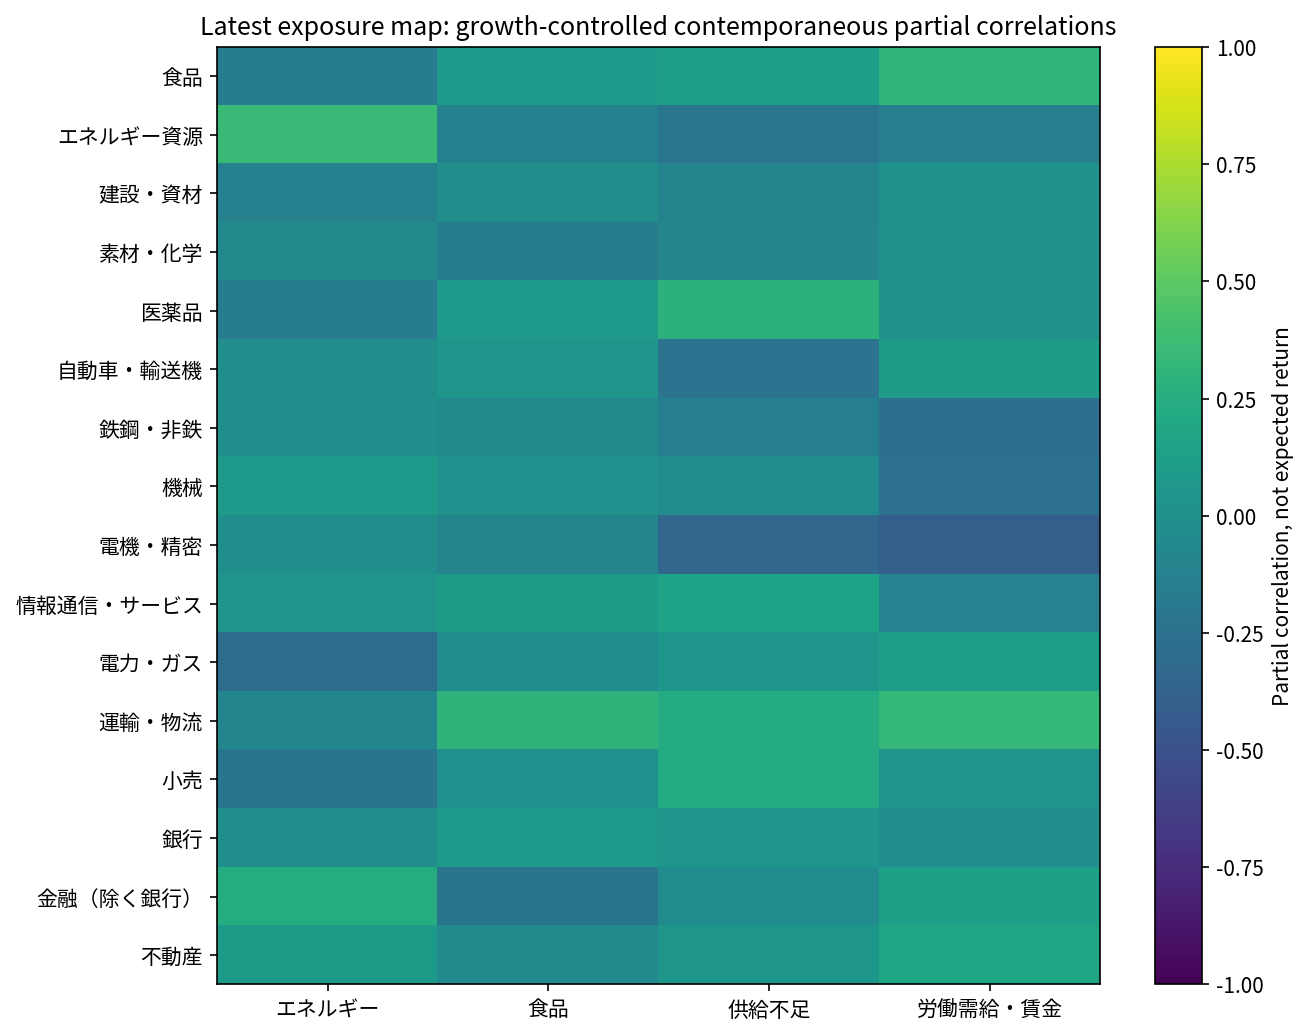

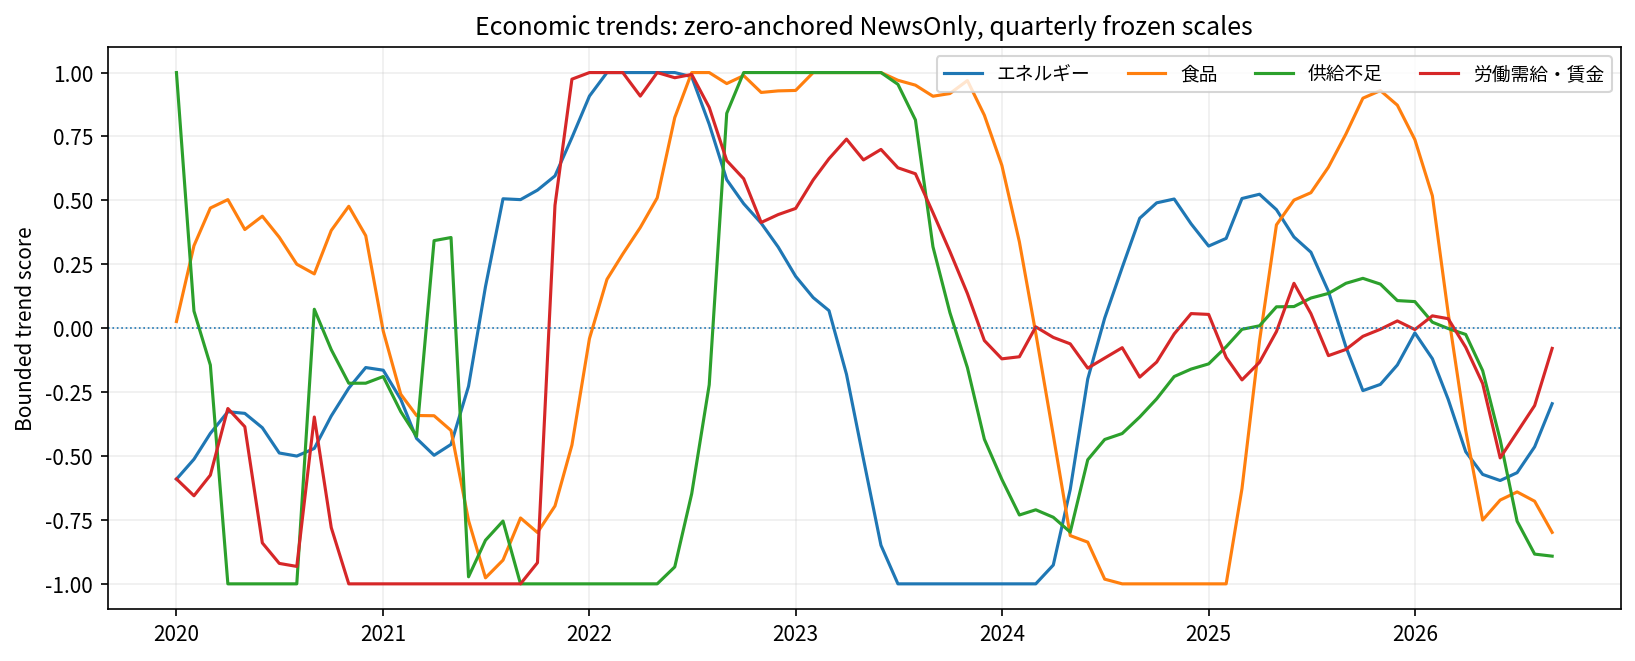

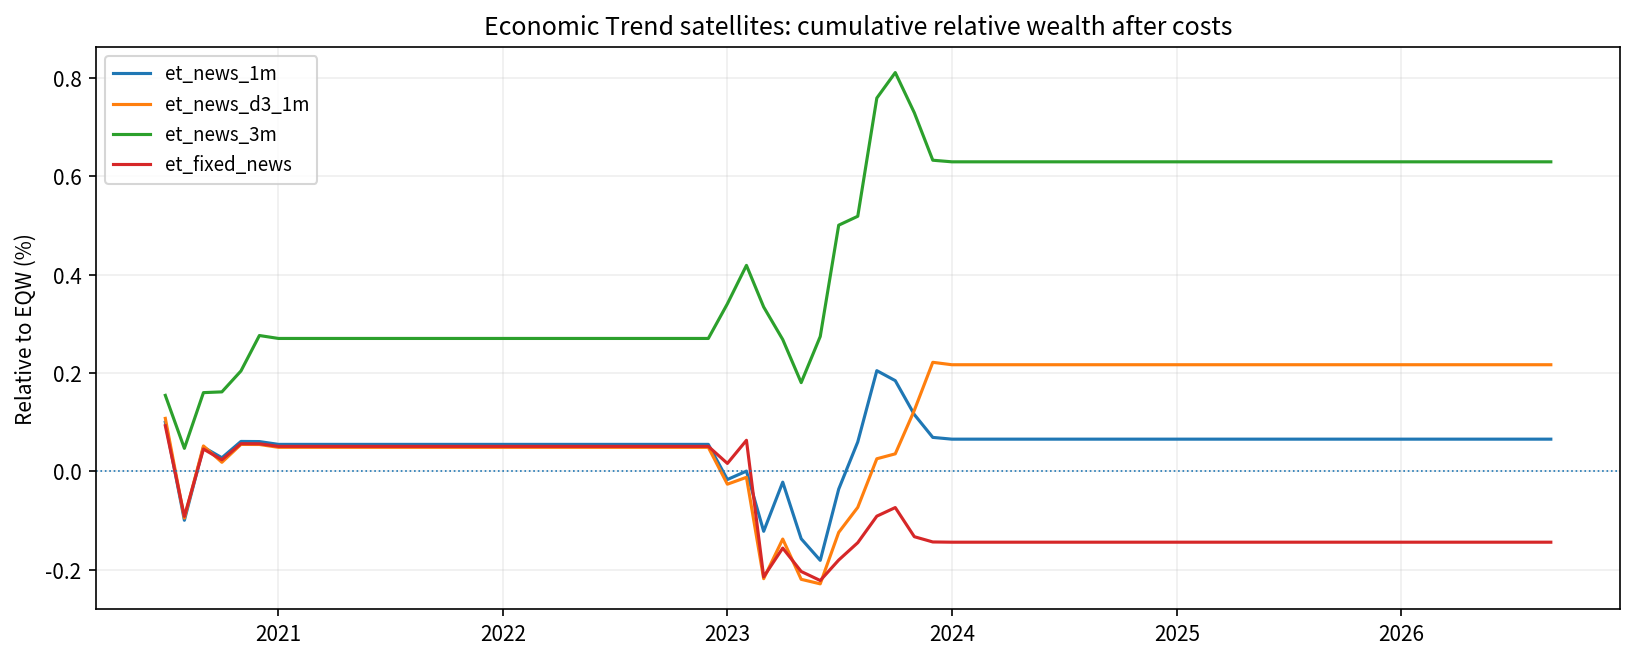

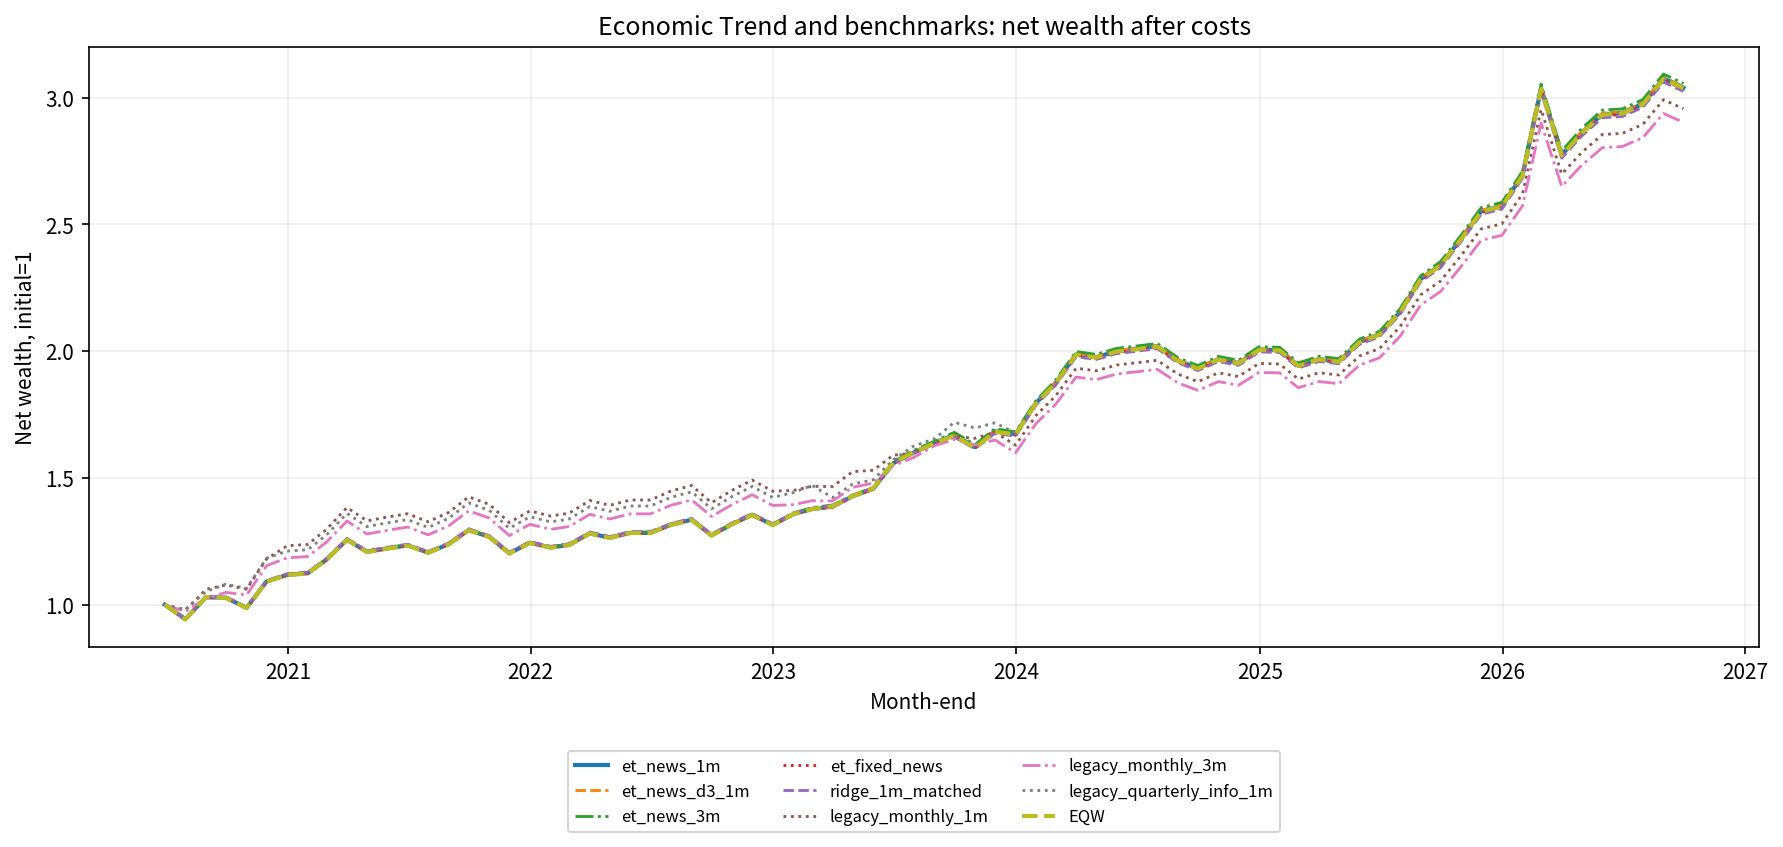

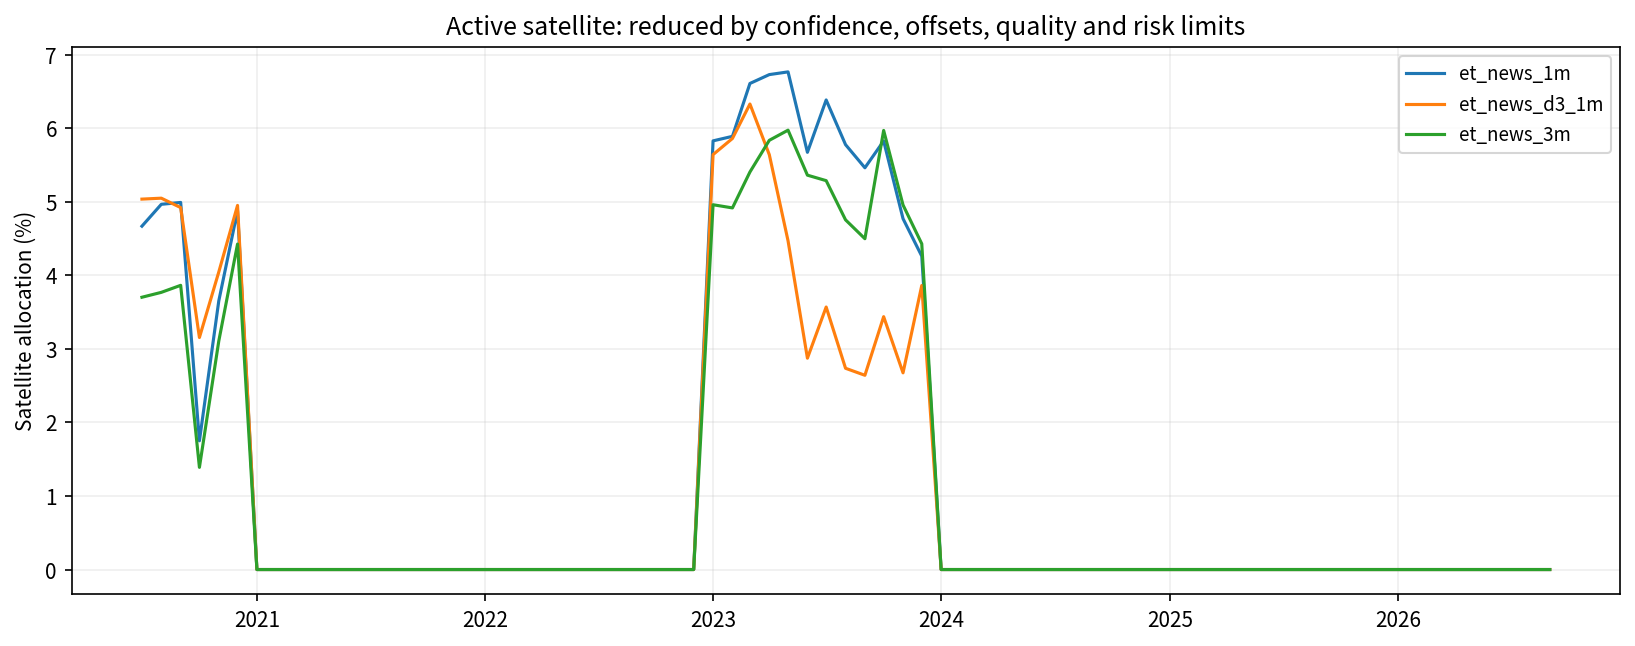

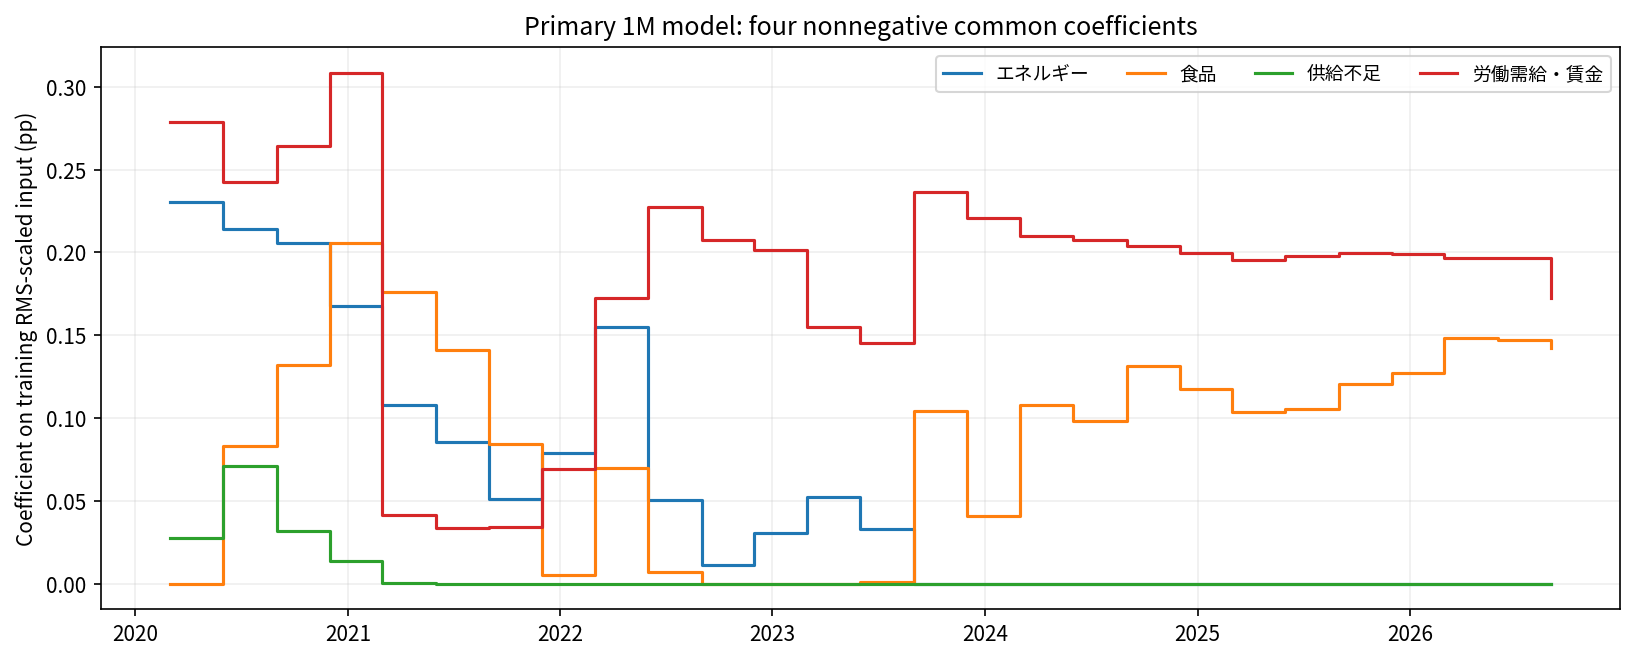

Economic Trend report: /mnt/data/BB_PA_QualityGate_Ablation/outputs/runs/_inprogress_20261014T223551_112148/results/economic_trend/report.html


,strategy,n_months,information_ratio,active_months,quality_hold_months,geometric_relative_ann_pct,tracking_error_pct,max_satellite_pct
0,EQW,75,NaN,0,0,0.000000,0.000000,0.000000
1,et_fixed_news,75,-0.160835,18,57,-0.023031,0.164442,5.940490
2,et_news_1m,75,0.042578,18,57,0.010486,0.174922,6.766268
3,et_news_3m,75,0.527186,18,57,0.100407,0.190288,5.973808
4,et_news_d3_1m,75,0.183638,18,57,0.034658,0.174894,6.329612
5,legacy_monthly_1m,75,-0.144591,18,57,-0.430880,3.488930,100.000000
6,legacy_monthly_3m,75,-0.235406,18,57,-0.722264,3.514871,100.000000
7,legacy_quarterly_info_1m,75,-0.007272,18,57,0.032728,3.583079,100.000000
8,ridge_1m_matched,75,-0.320633,18,57,-0.064508,0.230741,8.528302


In [56]:
def et_plot(fig,name):
    fig.tight_layout();fig.savefig(ET_FIG/name,dpi=150,bbox_inches='tight');plt.close(fig)
    display(DisplayImage(filename=str(ET_FIG/name)))

_et_map_latest=ET_MAPS[cm_latest_version['version']]
_et_heat=_et_map_latest['records'].pivot(index='asset',columns='factor',values='partial_corr_news').reindex(index=current_assets,columns=ET_FACTORS)
_et_fig,_et_ax=plt.subplots(figsize=(9,7))
_et_im=_et_ax.imshow(_et_heat.to_numpy(),aspect='auto',vmin=-1,vmax=1)
_et_ax.set_xticks(range(4),[ET_LABELS[k] for k in ET_FACTORS]);_et_ax.set_yticks(range(len(current_assets)),current_assets)
_et_ax.set_title('Latest exposure map: growth-controlled contemporaneous partial correlations')
_et_fig.colorbar(_et_im,ax=_et_ax,label='Partial correlation, not expected return')
et_plot(_et_fig,'01_latest_exposure_map.png')

_et_tr_recent=et_trends.loc[et_trends.decision_month>='2020-01']
_et_fig,_et_ax=plt.subplots(figsize=(11,4.5))
for _et_k in ET_FACTORS:
    _et_d=_et_tr_recent.loc[_et_tr_recent.factor==_et_k]
    _et_ax.plot(pd.PeriodIndex(_et_d.decision_month,freq='M').to_timestamp(),_et_d.trend_news,label=ET_LABELS[_et_k])
_et_ax.axhline(0,linewidth=.8,linestyle=':');_et_ax.set(title='Economic trends: zero-anchored NewsOnly, quarterly frozen scales',ylabel='Bounded trend score')
_et_ax.legend(ncol=4,fontsize=9);_et_ax.grid(alpha=.2)
et_plot(_et_fig,'02_monthly_factor_trends.png')

_et_bench=et_ledger.query("strategy=='EQW'").set_index('holding_month').net_return
_et_fig,_et_ax=plt.subplots(figsize=(11,4.5))
for _et_name in ['et_news_1m','et_news_d3_1m','et_news_3m','et_fixed_news']:
    _et_d=et_ledger.query('strategy==@_et_name').sort_values('holding_month')
    _et_rel=np.cumprod(1+_et_d.net_return.to_numpy())/np.cumprod(1+_et_bench.reindex(_et_d.holding_month).to_numpy())
    _et_ax.plot(pd.PeriodIndex(_et_d.holding_month,freq='M').to_timestamp(),100*(_et_rel-1),label=_et_name)
_et_ax.axhline(0,linewidth=.8,linestyle=':');_et_ax.set(title='Economic Trend satellites: cumulative relative wealth after costs',ylabel='Relative to EQW (%)')
_et_ax.legend(fontsize=9);_et_ax.grid(alpha=.2)
et_plot(_et_fig,'03_relative_performance.png')

# 追加表示：相対wealthではなく、各戦略・EQW自身のコスト控除後累積資産倍率。
# 売買費用は既存net_returnに含まれるため、ここでは再控除しない。
def et_net_wealth_frame(ledger):
    """共通月次のnet_returnから、運用開始直前を1とするwealth表を作る。"""
    required={'strategy','holding_month','net_return'}
    if not required.issubset(ledger.columns):
        raise ValueError('Net wealthに必要な列が不足しています: '+str(sorted(required-set(ledger.columns))))
    d=ledger[['strategy','holding_month','net_return']].copy()
    if d.empty or d[['strategy','holding_month']].isna().any().any():
        raise ValueError('Net wealthの対象系列が空、または月・戦略名が欠損しています')
    d['holding_month']=pd.PeriodIndex(d['holding_month'],freq='M')
    d['net_return']=pd.to_numeric(d['net_return'],errors='raise')
    if not np.isfinite(d['net_return'].to_numpy(dtype=float)).all() or (d['net_return'] < -1).any():
        raise ValueError('Net wealthの月次リターンが欠損・非有限、または-100%未満です')
    if d.duplicated(['strategy','holding_month']).any():
        raise ValueError('戦略・保有月が重複しています')
    r=d.pivot(index='holding_month',columns='strategy',values='net_return').sort_index()
    if 'EQW' not in r.columns or r.isna().any().any():
        raise ValueError('EQWがない、または戦略間で共通保有期間が揃っていません')
    expected=pd.period_range(r.index[0],r.index[-1],freq='M',name='holding_month')
    if not r.index.equals(expected):
        raise ValueError('月次リターンに途中欠損月があります。0補完・欠損月の除外は行いません')
    wealth=(1.0+r).cumprod()
    initial=pd.DataFrame(1.0,index=pd.PeriodIndex([r.index[0]-1],freq='M',name='holding_month'),columns=wealth.columns)
    return pd.concat([initial,wealth])

_et_net_wealth=et_net_wealth_frame(et_ledger)
et_save(_et_net_wealth,'net_wealth_common_period.csv',index=True)
_et_net_order=['et_news_1m','et_news_d3_1m','et_news_3m','et_fixed_news','ridge_1m_matched',
               'legacy_monthly_1m','legacy_monthly_3m','legacy_quarterly_info_1m','EQW']
_et_net_order=[s for s in _et_net_order if s in _et_net_wealth.columns]+[
    s for s in _et_net_wealth.columns if s not in _et_net_order]
_et_net_styles={'et_news_1m':'-','et_news_d3_1m':'--','et_news_3m':'-.','et_fixed_news':':',
                'ridge_1m_matched':'--','legacy_monthly_1m':':','legacy_monthly_3m':'-.',
                'legacy_quarterly_info_1m':':','EQW':'--'}
_et_net_dates=_et_net_wealth.index.to_timestamp(how='end').normalize()
_et_fig,_et_ax=plt.subplots(figsize=(12,5.8))
for _et_name in _et_net_order:
    _et_ax.plot(_et_net_dates,_et_net_wealth[_et_name],label=_et_name,
                linestyle=_et_net_styles.get(_et_name,'-'),
                linewidth=2.0 if _et_name in ['et_news_1m','EQW'] else 1.35)
_et_ax.set(title='Economic Trend and benchmarks: net wealth after costs',
           xlabel='Month-end',ylabel='Net wealth, initial=1')
_et_ax.legend(loc='upper center',bbox_to_anchor=(.5,-.16),ncol=3,fontsize=8)
_et_ax.grid(alpha=.2)
et_plot(_et_fig,'06_net_wealth.png')


_et_fig,_et_ax=plt.subplots(figsize=(11,4.4))
for _et_name in ['et_news_1m','et_news_d3_1m','et_news_3m']:
    _et_d=et_ledger.query('strategy==@_et_name')
    _et_ax.plot(pd.PeriodIndex(_et_d.holding_month,freq='M').to_timestamp(),100*_et_d.satellite_weight,label=_et_name)
_et_ax.set(title='Active satellite: reduced by confidence, offsets, quality and risk limits',ylabel='Satellite allocation (%)')
_et_ax.legend(fontsize=9);_et_ax.grid(alpha=.2)
et_plot(_et_fig,'04_satellite_allocation.png')

_et_fig,_et_ax=plt.subplots(figsize=(11,4.5))
for _et_k in ET_FACTORS:
    _et_d=et_shared_coefficients.query("strategy=='et_news_1m' and factor==@_et_k")
    _et_ax.step(pd.PeriodIndex(_et_d.refit_month,freq='M').to_timestamp(),_et_d.scaled_beta_pp,where='post',label=ET_LABELS[_et_k])
_et_ax.set(title='Primary 1M model: four nonnegative common coefficients',ylabel='Coefficient on training RMS-scaled input (pp)')
_et_ax.legend(ncol=4,fontsize=9);_et_ax.grid(alpha=.2)
et_plot(_et_fig,'05_shared_forecast_coefficients.png')

_et_main=et_perf.set_index('strategy').loc['et_news_1m']
_et_ci=et_uncertainty.set_index('strategy').loc['et_news_1m']
_et_latest=et_weights.query("strategy=='et_news_1m'").copy()
_et_latest=_et_latest.loc[_et_latest.decision_month==_et_latest.decision_month.max()]
_et_latest=_et_latest.sort_values('score',ascending=False)
et_save(_et_latest,'latest_primary_candidates.csv')
_et_current_HOLD=cm_observations.iloc[-1].monthly_final=='HOLD'
_et_ci_cross=_et_ci.relative_CAGR_bootstrap_low<=0<=_et_ci.relative_CAGR_bootstrap_high
_et_caution=('主戦略の条件付き再標本化区間はゼロを跨いでいます。超過収益が確認できたとは判断しません。'
             if _et_ci_cross else '条件付き再標本化区間と実時点・独立検証は別です。区間だけで本番採用を決めません。')

def et_md_table(df,index=False):
    x=df.reset_index() if index else df.copy()
    def f(v):
        if isinstance(v,(float,np.floating)):return '' if pd.isna(v) else f'{v:.5f}'
        return str(v).replace('|','/')
    return '\n'.join(['| '+' | '.join(map(str,x.columns))+' |','| '+' | '.join(['---']*len(x.columns))+' |']+
       ['| '+' | '.join(f(v) for v in row)+' |' for row in x.itertuples(index=False,name=None)])
_et_perf_view=et_perf[['strategy','n_months','geometric_relative_ann','information_ratio','tracking_error','active_months','quality_hold_months','max_satellite_weight']].copy()
_et_perf_view['geometric_relative_ann_pct']=100*_et_perf_view.pop('geometric_relative_ann')
_et_perf_view['tracking_error_pct']=100*_et_perf_view.pop('tracking_error')
_et_perf_view['max_satellite_pct']=100*_et_perf_view.pop('max_satellite_weight')
_et_latest_view=_et_latest[['asset','forecast_active_pp','target_weight','active_weight','selection_reason']].copy()
_et_latest_view['target_weight_pct']=100*_et_latest_view.pop('target_weight')
_et_latest_view['active_weight_pct']=100*_et_latest_view.pop('active_weight')

et_report=f'''# BB要因別 Economic Trend：月次ローテーション
実行 {RUN_ID}、基準日 {AS_OF_DATE.date()}。主戦略 et_news_1m、先3か月は比較。

## 結果の要点
- 共通評価期間：{_et_main.first_holding_month}〜{_et_main.last_holding_month}、{int(_et_main.n_months)}か月。
- 主戦略のEQW対比幾何相対年率：{100*_et_main.geometric_relative_ann:+.3f}%、IR：{_et_main.information_ratio:.3f}。
- 品質保留：{int(_et_main.quality_hold_months)}か月。アクティブ配分：{int(_et_main.active_months)}か月。
- 本番採用フラグはFalse。最新正式/月次状態は{cm_observations.iloc[-1].monthly_final}。
- {_et_caution}
- 元のBB、FT/PT、月次C案、Ridge・Top4結果は変更していない。

## 何を実装したか
四半期ごとに、各資産の同時12か月EQW対比リターンとBB因子NewsOnlyの成長統制後偏相関を推定。
サンプル数による縮小と期間による符号安定性でエクスポージャを縮小し、月内の共通部分を除いて相対スコアにする。
月次には、四半期固定スケールで0を中心にNを標準化。比較用に同位相D3=P_m−P_(m−3)を追加。
四半期係数を保つ3か月窓、4四半期幅のP、12か月差N、四半期限定GDP・期待を補完しない条件は元のまま。
NやD3は市場サプライズではない。物価目標との乖離をBB寄与と同一視しない。

主スコアは、要因重み×資産エクスポージャ×要因トレンドの4項。
さらに36か月以上・12モデル版以上の終了済みラベルから、非負の4共通係数をRidgeで推定。
翌1か月用と翌3か月用は別推定。係数・学習スケールは次の四半期モデル版まで固定。
過去の説明変数には、その月に発行した感応度マップを使用し、現行マップで過去を上書きしない。

## 主な初期設定（本件の設計。文献の推定値ではない）
- 感応度マップは最低{ET_CFG['map_min_quarters']}四半期。縮小率 n/(n+{ET_CFG['map_shrink_quarters']})。
- 直近{ET_CFG['map_recent_quarters']}四半期・終端4期除外との符号一致度は0/0.5/1。確率ではない。
- 商品市場50%、労働市場50%。商品内は3等分。Cost総合やFT/PT内訳を二重に加算しない。
- トレンド尺度はモデル終期までの最大{ET_CFG['trend_scale_months']}か月のSD。経済的ゼロを保ち、±{ET_CFG['trend_clip']}SDで打切り。
- 比較news_d3はNとD3の等加重で固定。複数窓のリターン最適化なし。
- 共通係数は平均損失罰則{ET_CFG['calibration_penalty']}。不利な関係を負係数で逆張りするのでなく0側へ抑制。
- 衛星配分の上限{100*ET_CFG['satellite_max']:.0f}%。信号の強さ・安定性・相殺・リスク制限によってさらに小さくする。
- 上位{ET_CFG['top_n']}の等ウェイト衛星とEQWを混合。正式HOLDならEQWへ戻す。
- 年率アクティブTE上限{100*ET_CFG['max_active_te_annual']:.1f}%。成長ローディングの上限は{ET_CFG['max_growth_loading_12m_1sd_pp']}pp。
- 費用は売買額合計×片道{ET_CFG['trade_cost_bps']}bp。メンバー変更は予測改善が追加費用を上回るとき。
- 固定スコア比較は期待リターンではないため、費用ppと比較せずスコア差の小さな緩衝帯を使う。

## 同じ期間での比較
{et_md_table(_et_perf_view)}
legacy_*は従来Top4の選定をそのまま使用し、共通期間の初期比率をEQWに揃えて計算。
ridge_1m_matchedは従来の予測に今回の衛星上限・リスク制限を適用する比較。配分額が全月で同一という意味ではない。
1か月・3か月とも毎月1ポートフォリオを選び、翌1か月だけを会計。3か月複利を毎月加算しない。

### Net wealthとEQW対比の相対wealth
追加図`figures/06_net_wealth.png`は、共通保有期間の各戦略・EQWについて、
W_t = product(1 + net_return_s)を表示する。最初の保有月の直前月末に初期値1の点を置く。
net_returnは既存の費用控除後月次リターンを使用し、費用を再控除したりEQWで割ったりしない。
CPIで調整した実質wealthでもない。数値は`net_wealth_common_period.csv`へ保存する。
既存の`03_relative_performance.png`（W_strategy / W_EQW - 1）は残し、小さい相対差はそちらで確認する。


## 予測精度
{et_md_table(et_ic_summary)}
先3か月の予測評価は未完了ラベルを除外するので、ポートフォリオの共通評価{int(_et_main.n_months)}か月と観測数が異なり得る。
1か月主のまま、比較戦略が良かったことを理由に事後的な切替はしない。

## 最新の研究用候補と配分
{et_md_table(_et_latest_view)}
正の予測があってもHOLDを解除しない。この表は研究用の目標配分で、発注済み・採用済みを意味しない。

## 根拠と限界
AQR Inflation Redux?のpp.6–7は同時偏相関、pp.15–16・21はEconomic Trendの思想と仮想戦略。
本件はその形式を日本BB寄与とlong-onlyセクターへ適用した新規設計。AQRの商品・国別戦略を再現したものではない。
Macrosynergyは時点整合と先行リターンを検証する考え方を参考にした。JPMaQSデータ・予想サプライズ・目標乖離を取り込んだわけではない。
BBは商品・労働の直接間接寄与を扱うが、純粋な需要供給や財政ショックを識別したものではない。
HOLD継承、原データの最新ビンテージ、仮定の利用可能ラグ、指数配当・通貨・実執行未確認という既存制限は残る。

初段と次段のwarmupがあるため、今回の共通評価は従来の84か月より短い。
同じデータをこれまでの設計で参照済みなので、 untouched holdoutとは呼ばない。
16セクターを月ごとに積み上げた行数を独立標本数としてp値計算しない。
要因バスケットの将来関係は月単位HAC12と12か月ブロックbootstrapで別途診断。全部の要因・信号・期間を同じBH集合に含める。
戦略bootstrapは実現リターンに条件付きであり、BB・感応度・モデル選択の全不確実性を網羅しない。

## 出力
exposure_maps_by_version.csv、factor_trends_by_decision.csv、forecasts_1m_main_3m_comparison.csv、
forecast_factor_attribution.csv、monthly_selection_weights.csv、strategy_performance_common_period.csv、
factor_forward_support_diagnostic.csv、strategy_block_bootstrap_intervals.csv、production_gate.json。
元結果は既存フォルダ、追加結果はeconomic_trend/へ独立保存。
'''
(ET_DIR/'RESULTS_ja.md').write_text(et_report,encoding='utf-8')
import base64 as _et_b64,html as _et_html
def et_html_table(df):return df.to_html(index=False,border=0,float_format=lambda v:f'{v:.4f}',escape=True)
def et_html_img(name,caption):
    data=_et_b64.b64encode((ET_FIG/name).read_bytes()).decode()
    return f'<figure><figcaption>{_et_html.escape(caption)}</figcaption><img src="data:image/png;base64,{data}" alt="{_et_html.escape(caption)}"></figure>'
_et_body=f'''<header><div class="eyebrow">BB SOURCES × ECONOMIC TREND / MONTHLY ROTATION</div>
<h1>インフレ要因別の月次ローテーション</h1><p>翌1か月が主予測。翌3か月は比較。四半期の感応度地図と、毎月の経済トレンドを分離。</p></header>
<div class="metrics"><div><small>主戦略・EQW対比年率</small><strong>{100*_et_main.geometric_relative_ann:+.3f}%</strong></div>
<div><small>主戦略の情報比率</small><strong>{_et_main.information_ratio:.3f}</strong></div>
<div><small>アクティブ配分 / 共通評価</small><strong>{int(_et_main.active_months)} / {int(_et_main.n_months)}月</strong></div></div>
<section class="notice"><h2>現在の正式状態：{cm_observations.iloc[-1].monthly_final}</h2>
<p>{_et_caution} 最新の研究用配分は品質条件を維持し、production_eligible=Falseです。
原統計の過去ビンテージ、公表時刻、実執行の独立検証は完了していません。</p></section>
<section><h2>1. 感応度の地図</h2><p>成長を統制した同時12か月リターンとの偏相関を四半期ごとに推定。標本と符号安定性で縮小。
偏相関は期待リターンではなく、12で割って1か月βにしていません。</p>{et_html_img('01_latest_exposure_map.png','最新モデル版のNewsOnly感応度')}</section>
<section><h2>2. 月次に更新する要因の方向</h2><p>Nは12か月差、D3は同位相3か月差。四半期GDP・期待は月次補完しません。
商品内3経路と労働1経路だけを使用し、CostやFT/PTを重複して足しません。</p>{et_html_img('02_monthly_factor_trends.png','四半期スケール固定・ゼロを中心にした経済トレンド')}
{et_html_img('05_shared_forecast_coefficients.png','少数の共通係数を非負制約で縮小推定')}</section>
<section><h2>3. 共通期間のコスト後成績</h2><p>{_et_main.first_holding_month}〜{_et_main.last_holding_month}。
legacyは従来の集中Top4、matchedは衛星上限を合わせたRidge比較です。異なる投資リスク量を同じ成果とみなしません。</p>
{et_html_table(_et_perf_view)}
{et_html_img('06_net_wealth.png','Net wealth：各戦略とEQWのコスト控除後累積資産倍率（初期値1）')}
<p>全戦略を同じ保有期間で比較し、最初の保有月の直前月末を1として表示しています。
各線はその戦略の月次net_returnを複利累積したもので、EQWで割った相対wealthではありません。
費用はnet_returnに含まれ、追加で控除していません。CPIで調整した実質wealthでもありません。
各戦略の資産倍率が近い場合は線が重なります。小さい運用差は下の相対wealth図で確認してください。</p>
{et_html_img('03_relative_performance.png','Economic Trend各仕様とEQWの相対資産倍率')}
{et_html_img('04_satellite_allocation.png','上限20%から信頼性・相殺・リスクで縮小した配分')}</section>
<section><h2>4. 先行予測と条件付き区間</h2>{et_html_table(et_ic_summary)}{et_html_table(et_uncertainty[['strategy','relative_CAGR_bootstrap_low','relative_CAGR_bootstrap_high']])}
<p>区間は小数表記。0.001=0.1%。実現した月次系列のブロック再標本化であり、全モデル再推定や未使用の独立検証ではありません。</p></section>
<section><h2>5. 最新の研究用目標配分</h2>{et_html_table(_et_latest_view)}
<p>マクロ圧力・期待収益・品質・目標比率を分けています。プラス予測だけで正式HOLDを解除しません。</p></section>
<footer><h2>出所・実装の線引き</h2><p>Bernanke &amp; Blanchard, PIIE WP24-11（符号付き動学寄与）；Nakamura et al., BOJ WP24-E-1（FT/PT）；
AQR Inflation Redux? 2026 Issue3 pp.6–7,15–16,21（感応度・Economic Trend）；Macrosynergy “Inflation as a trading signal” / “Macro trends and equity allocation”。</p>
<p>感応度縮小、4共通係数、等重み階層、衛星比率・リスク制限は本件の初期設定。原論文の推奨値・日本1か月alpha実証ではありません。
コード・入力・検証と全数値を同じrunへ保存。追加処理から既存の科学計算ファイルを変更していません。</p></footer>'''
_et_css='''body{max-width:1160px;margin:auto;padding:36px;font-family:-apple-system,BlinkMacSystemFont,"Segoe UI","Noto Sans JP",sans-serif;line-height:1.75;color:#213746}header{border-bottom:3px solid #24465a;padding-bottom:20px}h1{font-size:32px;line-height:1.35}h2{font-size:23px}small,.eyebrow{letter-spacing:.05em;color:#536877}.metrics{display:flex;gap:18px;margin:25px 0}.metrics>div{flex:1;background:#f1f5f7;padding:16px}.metrics strong{display:block;font-size:28px}.notice{padding:18px;border-left:4px solid #24465a;background:#f1f5f7}section{margin:32px 0}table{display:block;overflow-x:auto;max-width:100%;border-collapse:collapse;font-size:12px}td,th{padding:8px 9px;border-bottom:1px solid #d8e0e5;text-align:right;white-space:nowrap}th{background:#eef3f6}img{max-width:100%;height:auto}figure{margin:26px 0}figcaption{font-weight:600}footer{border-top:2px solid #24465a;font-size:13px}'''
(ET_DIR/'report.html').write_text('<!doctype html><html lang="ja"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>BB Economic Trend Rotation</title><style>'+_et_css+'</style><body>'+_et_body+'</body></html>',encoding='utf-8')
et_json({'run_id':RUN_ID,'as_of':str(AS_OF_DATE.date()),'bb_end':str(BB_END),
 'latest_monthly_observation':str(CM_CURRENT_PREFIX_END),'main_strategy':'et_news_1m','primary_horizon_months':1,'comparison_horizon_months':3,
 'exposure_model_versions':len(ET_MAPS),'exposure_rows':len(et_exposures),'shared_forecast_rows':len(et_predictions),
 'evaluation_months':int(_et_main.n_months),'first_holding_month':_et_main.first_holding_month,'last_holding_month':_et_main.last_holding_month,
 'quality_hold_months':int(_et_main.quality_hold_months),'primary_relative_CAGR':_et_main.geometric_relative_ann,'primary_IR':_et_main.information_ratio,
 'primary_interval_crosses_zero':bool(_et_ci_cross),'checks':len(ET_CHECKS),'existing_numeric_files_unchanged':len(ET_BEFORE_FILES),
 'protected_objects':len(ET_PROTECTED_NAMES),'production_eligible':False,'method_config':ET_CFG},'run_summary.json')

def et_publish_link():
    f=RESULT_DIR/'report.html'
    text=f.read_text(encoding='utf-8')
    intro='<section><h2>追加：要因感応度×Economic Trend</h2><p>1か月主・3か月比較の月次ローテーション。<a href="economic_trend/report.html">追加結果レポート</a>。旧BB・月次Ridgeは変更せず保持。</p></section>'
    f.write_text(text.replace('<body>','<body>'+intro,1),encoding='utf-8')
print('Economic Trend report:',ET_DIR/'report.html')
display(_et_perf_view)


## 22．PA日程：四半期終了後2か月で選定・その後3か月保有
既存の3か月ラグPA・月次C案・Economic Trendを変更せず、日程とラベルを明示して追加計算します。公表カレンダーが空の期を確認済みと扱わず、主方針はEQW、未確認仮定の研究結果は別名にします。

In [57]:
# 22: PAスケジュール拡張（既存PA・月次C案・Economic Trendから分離）
PA2_CFG=dict(PA_SCHEDULE_CFG)
PA2_DIR=RESULT_DIR/'pressure_assets_2m';PA2_FIG=PA2_DIR/'figures'
PA2_DIR.mkdir(exist_ok=True);PA2_FIG.mkdir(exist_ok=True)
PA2_CHECKS=[]
PA2_PROTECTED=['model','dual_model','pa_recursive','pa_x','pa_wf','pa_ledger','pa_weights','pa_perf',
               'reg_main','CM_CFG','ET_CFG','PA_CFG']
PA2_BEFORE={k:reg_fingerprint(globals()[k]) for k in PA2_PROTECTED}
PA2_FILES_BEFORE={str(p.relative_to(RESULT_DIR)):sha256(p.read_bytes()) for p in RESULT_DIR.rglob('*')
                 if p.is_file() and p.suffix.lower() in ['.csv','.json'] and not p.is_relative_to(PA2_DIR)}

def pa2_check(name,ok,detail=''):
    PA2_CHECKS.append({'test':name,'passed':bool(ok),'detail':str(detail)})
    check('pa2_'+name,ok,detail)
def pa2_save(frame,name,index=False):
    save_csv(frame,name,index=index,folder=PA2_DIR)
def pa2_json(value,name):
    reg_json(value,PA2_DIR/name)
def pa2_validate_config(cfg):
    if cfg['selection_lag_months']!=2 or cfg['holding_months']!=3:
        raise ValueError('主仕様は四半期末+2か月末選定・その後3か月保有です')
    if cfg['comparison_lag_months']!=3:raise ValueError('比較の選定ラグは3か月です')
    if cfg['main_release_policy']!='confirmed_only':raise ValueError('主判定は公表確認必須です。仮定版は別出力します')
    if not cfg['exclude_decision_month_label']:raise ValueError('月末組入れ前に当月末リターンは使いません')
    if not 0<=int(cfg['cutoff_hour_jst'])<=23:raise ValueError('cutoff時刻が不正')
    if cfg['min_train_quarters']<12 or cfg['ridge_lambda']<=0:raise ValueError('学習数・Ridge罰則が不正')
    if not 1<=cfg['top_n']<=len(current_assets):raise ValueError('top_nの範囲外')
    if cfg['one_way_cost_bps']<0:raise ValueError('取引費用が負')
    if cfg['missing_internal_return']!='raise':raise ValueError('観測済み期間内の欠損を黙って除外できません')
    return True

def pa2_time(value):
    t=pd.Timestamp(value)
    if pd.isna(t):raise ValueError('日時が空です')
    # 時刻なしの日付はその日の終わりまで利用できたと確認できないため、翌日00:00として扱う。
    if re.fullmatch(r'\d{4}-\d{2}-\d{2}',str(value).strip()):t+=pd.Timedelta(days=1)
    return t.tz_localize('Asia/Tokyo') if t.tzinfo is None else t.tz_convert('Asia/Tokyo')

def pa2_load_release_calendar(frame):
    required={'source_quarter','input_group','available_at','source'}
    if not required.issubset(frame.columns):raise ValueError('pa_release_calendar.csvの列が不足')
    valid=set(PA2_CFG['required_input_groups'])|{'all_required_inputs'}
    rows={}
    for row in frame.itertuples(index=False):
        q=pd.Period(row.source_quarter,freq='Q');group=str(row.input_group).strip()
        if group not in valid:raise ValueError('入力群名が不正: '+group)
        key=(q,group)
        if key in rows:raise ValueError('公表カレンダーの対象期・入力群が重複: '+str(key))
        if pd.isna(row.source) or not str(row.source).strip():raise ValueError('公表日時の出所が必要です')
        at=pa2_time(row.available_at)
        if at<pd.Timestamp(q.start_time).tz_localize('Asia/Tokyo'):raise ValueError('対象四半期前の公表日時は不正')
        rows[key]={'available_at':at,'source':str(row.source)}
    return rows

def pa2_load_trade_calendar(frame):
    if not {'decision_month','selection_cutoff_at','execution_at'}.issubset(frame):
        raise ValueError('pa_trade_calendar.csvの列が不足')
    result={}
    for row in frame.itertuples(index=False):
        m=pd.Period(row.decision_month,freq='M')
        if m in result:raise ValueError('判断月の重複')
        # 取引日時には時刻を必須にし、日付のみの暗黙的解釈を避ける。
        if not re.search(r'[T ]\d{2}:\d{2}',str(row.selection_cutoff_at)) or not re.search(r'[T ]\d{2}:\d{2}',str(row.execution_at)):
            raise ValueError('取引カレンダーは時刻を含むISO日時を指定してください')
        cut=pa2_time(row.selection_cutoff_at);exe=pa2_time(row.execution_at)
        if cut>=exe or cut.tz_localize(None).to_period('M')!=m or exe.tz_localize(None).to_period('M')!=m:
            raise ValueError('同じ判断月内でcutoff < executionである必要があります')
        result[m]=(cut,exe)
    return result

def pa2_schedule(origins,lag_months=2,trade_calendar=None,config=None):
    cfg=PA2_CFG if config is None else config;calendar={} if trade_calendar is None else trade_calendar
    if lag_months not in [2,3]:raise ValueError('この比較のラグは2か月または3か月です')
    qs=pd.PeriodIndex(origins,freq='Q')
    if qs.has_duplicates or not qs.is_monotonic_increasing:raise ValueError('源泉四半期は昇順・一意')
    rows=[]
    for q in qs:
        m=q.asfreq('M','end')+lag_months
        if m in calendar:
            cutoff,execution=calendar[m];basis='provided_trade_calendar'
        else:
            day=m.end_time.normalize()
            while day.dayofweek>=5:day-=pd.Timedelta(days=1)
            cutoff=(day+pd.Timedelta(hours=cfg['cutoff_hour_jst'])).tz_localize('Asia/Tokyo')
            execution=(day+pd.Timedelta(hours=23,minutes=59,seconds=59)).tz_localize('Asia/Tokyo')
            basis='last_weekday_proxy_no_exchange_holiday_verification'
        rows.append({'source_quarter':q,'macro_reference_end':q.asfreq('M','end'),
          'decision_month':m,'selection_lag_months':lag_months,'selection_cutoff_at':cutoff,
          'execution_boundary_at':execution,'trade_calendar_basis':basis,
          'price_execution_model':'monthly_end_price_proxy_not_intraday_fill',
          'holding_start_month':m+1,'holding_end_month':m+cfg['holding_months'],
          'holding_months':cfg['holding_months'],'training_label_end_month_max':m-1,
          'source_data_vintage':'current_vintage_prefix_not_point_in_time'})
    return pd.DataFrame(rows).set_index('source_quarter',drop=False)

def pa2_release_status(schedule,release_calendar,policy,features=None,config=None):
    cfg=PA2_CFG if config is None else config
    if policy not in ['confirmed_only','assume_missing']:raise ValueError('公表確認方針が不正')
    records=[]
    for q,s in schedule.iterrows():
        complete=(q,'all_required_inputs') in release_calendar
        missing=[g for g in cfg['required_input_groups'] if (q,g) not in release_calendar and not complete]
        known=[(g,v) for (qq,g),v in release_calendar.items() if qq==q]
        late=[g for g,v in known if v['available_at']>s.selection_cutoff_at]
        last=max([v['available_at'] for g,v in known],default=pd.NaT)
        if late:state='blocked_known_late_release'
        elif missing:state='blocked_unconfirmed' if policy=='confirmed_only' else 'assumed_missing_dates_NOT_verified'
        else:state='provided_release_complete_before_cutoff'
        allowed=not late and (not missing or policy=='assume_missing')
        numeric_ok=(features is None or (q in features.index and features.loc[q].notna().all()))
        records.append({'source_quarter':q,'release_policy':policy,'release_status':state,
            'release_complete_confirmed':not missing and not late,'known_release_latest_at':last,
            'unconfirmed_groups':';'.join(missing),'late_groups':';'.join(late),
            'macro_numeric_complete':bool(numeric_ok),'feature_usable_at_decision':bool(allowed and numeric_ok),
            'assumption_used':bool(missing and not late and policy=='assume_missing')})
    return pd.DataFrame(records).set_index('source_quarter',drop=False)

pa2_validate_config(PA2_CFG)
_pa2_rpath=INPUT_DIR/PA2_CFG['release_calendar']
_pa2_tpath=INPUT_DIR/PA2_CFG['trade_calendar']
pa2_release_frame=pd.read_csv(BytesIO(read_bytes(_pa2_rpath,'pa_schedule_release_calendar')),dtype=str)
pa2_trade_frame=pd.read_csv(BytesIO(read_bytes(_pa2_tpath,'pa_schedule_trade_calendar')),dtype=str)
PA2_RELEASE=pa2_load_release_calendar(pa2_release_frame)
PA2_TRADES=pa2_load_trade_calendar(pa2_trade_frame)
pa2_json({'config':PA2_CFG,'release_rows':len(pa2_release_frame),'trade_calendar_rows':len(pa2_trade_frame),
  'main_policy':'confirmed_only; unconfirmed or late input -> EQW, not silently omitted',
  'research_policy':'unknown dates assumed usable, but known late dates still block',
  'vintage_status':'current revised input data; release calendars do NOT recover past values',
  'monthly_end_price_proxy':True,'production_eligible':False,
  'hold_rule':'same selected set and target weights for three months; monthly target rebalancing'},'method_contract.json')


### 22A．新しい目的変数・月末前の学習締切
6月対象→8月末選定→9〜11月。8月末の学習に6〜8月リターンを入れません。8月より前に終わるラベルだけ使います。源泉特徴量は既存の四半期prefix推定から読み、月次の新マクロは混ぜません。

In [58]:
def pa2_forward_returns(monthly,eqw,schedule):
    if not isinstance(monthly.index,pd.PeriodIndex) or not monthly.index.freqstr.startswith('M'):
        raise ValueError('価格リターンのインデックスは月次PeriodIndex')
    if monthly.index.has_duplicates or eqw.index.has_duplicates:raise ValueError('月次リターンが重複')
    result={};audit=[]
    for q,s in schedule.iterrows():
        months=pd.period_range(s.holding_start_month,s.holding_end_month,freq='M')
        raw=monthly.reindex(months)
        if ((raw.dropna()<=-1).any().any()):raise ValueError('log複利が不可能なリターン')
        r=100*np.expm1(np.log1p(raw).sum(axis=0,min_count=len(months)))
        er=eqw.reindex(months)
        if (er.dropna()<=-1).any():raise ValueError('EQWが-100%以下')
        r['EQW_TR']=100*np.expm1(np.log1p(er).sum(min_count=len(months)))
        result[q]=r
        audit.append({'source_quarter':q,'decision_month':s.decision_month,
           'label_start_month':months[0],'label_end_month':months[-1],
           'months_required':len(months),'observed_months_complete_universe':int(raw.notna().all(axis=1).sum()),
           'label_complete':bool(raw.notna().all().all() and er.notna().all())})
    targets=pd.DataFrame(result).T;targets.index.name='source_quarter'
    return targets,pd.DataFrame(audit)

def pa2_fit_schedule(features,active_targets,schedule,availability,predictors=None,config=None):
    cfg=PA2_CFG if config is None else config
    predictors=PA_PREDICTORS if predictors is None else predictors
    predicted=[];audits=[];coefficients=[]
    for name,fields in predictors.items():
        x=features.reindex(schedule.index)[fields]
        for q,s in schedule.iterrows():
            ends=schedule.holding_end_month
            mature=(ends<=s.training_label_end_month_max)&(schedule.index<q)
            raw=schedule.index[mature]
            raw=raw.intersection(x.dropna().index).intersection(active_targets.dropna().index)
            eligible=raw[availability.loc[raw,'feature_usable_at_decision'].to_numpy(bool)]
            now_ok=bool(availability.loc[q,'feature_usable_at_decision']) and x.loc[q].notna().all()
            status='estimated' if now_ok and len(eligible)>=cfg['min_train_quarters'] else (
                'EQW_release_or_feature_unavailable' if not now_ok else 'EQW_insufficient_training')
            pred=np.full(len(active_targets.columns),np.nan);base=pred.copy()
            if status=='estimated':
                pred,base,_=pa_ridge_train_predict(x.loc[eligible],active_targets.loc[eligible],x.loc[q],cfg['ridge_lambda'])
                # 設定・係数・標準化も保存し、期間外の値を使っていないことを点検できるようにする。
                xa=x.loc[eligible].to_numpy(float);yv=active_targets.loc[eligible].to_numpy(float)
                mu=xa.mean(axis=0);sd=xa.std(axis=0,ddof=1);keep=np.isfinite(sd)&(sd>1e-10)
                z=(xa[:,keep]-mu[keep])/sd[keep];ym=yv.mean(axis=0)
                b=np.linalg.solve(z.T@z+cfg['ridge_lambda']*np.eye(keep.sum()),z.T@(yv-ym))
                for j,asset in enumerate(active_targets.columns):
                    coefficients.append({'model':name,'source_quarter':q,'asset':asset,'term':'intercept_mean',
                        'coefficient':ym[j],'train_mean':np.nan,'train_sd':np.nan,'train_n':len(eligible)})
                    pos=0
                    for k,f in enumerate(fields):
                        coefficients.append({'model':name,'source_quarter':q,'asset':asset,'term':f,
                         'coefficient':b[pos,j] if keep[k] else 0.,'train_mean':mu[k],'train_sd':sd[k],
                         'train_n':len(eligible),'variable_used':bool(keep[k])})
                        if keep[k]:pos+=1
            audit={'model':name,'source_quarter':q,'decision_month':s.decision_month,
             'selection_cutoff_at':s.selection_cutoff_at,'label_end_month_cutoff':s.training_label_end_month_max,
             'raw_mature_train_n':len(raw),'train_n':len(eligible),'status':status,
             'train_source_first':str(eligible.min()) if len(eligible) else '',
             'train_source_last':str(eligible.max()) if len(eligible) else '',
             'last_training_label_end':str(ends.loc[eligible].max()) if len(eligible) else '',
             'excluded_current_month_labels':';'.join(str(u) for u in schedule.index[(ends==s.decision_month)&(schedule.index<q)]),
             'release_policy':availability.loc[q,'release_policy'],
             'all_training_labels_finished_before_decision_month':bool((ends.loc[eligible]<s.decision_month).all()),
             'all_training_features_usable_at_own_decision':bool(availability.loc[eligible,'feature_usable_at_decision'].all())}
            audits.append(audit)
            for j,asset in enumerate(active_targets.columns):
                predicted.append({'model':name,'source_quarter':q,'decision_month':s.decision_month,
                 'holding_start_month':s.holding_start_month,'holding_end_month':s.holding_end_month,
                 'horizon_months':cfg['holding_months'],'asset':asset,'prediction_active_pp':pred[j],
                 'historical_mean_pp':base[j],'increment_vs_mean_pp':pred[j]-base[j],
                 'actual_active_pp':active_targets.loc[q,asset],'train_n':len(eligible),'raw_mature_train_n':len(raw),
                 'forecast_status':status,'prefix_quality':features.loc[q,'classification_quality'] if q in features.index else 'not_available',
                 'release_policy':availability.loc[q,'release_policy'],
                 'release_status':availability.loc[q,'release_status'],
                 'feature_usable_at_decision':bool(availability.loc[q,'feature_usable_at_decision']),
                 'release_confirmed':bool(availability.loc[q,'release_complete_confirmed']),
                 'production_eligible':False,'scope':'monthly_schedule_current_vintage_research_NOT_real_time'})
    return pd.DataFrame(predicted),pd.DataFrame(audits),pd.DataFrame(coefficients,columns=['model','source_quarter','asset','term','coefficient','train_mean','train_sd','train_n','variable_used'])

PA2_SCENARIOS={
 'two_month_confirmed':{'lag':2,'policy':'confirmed_only','role':'main_release_checked'},
 'two_month_research':{'lag':2,'policy':'assume_missing','role':'unverified_dates_research_only'},
 'three_month_preclose_research':{'lag':3,'policy':'assume_missing','role':'matched_training_rule_comparison'},
}
pa2_schedules={};pa2_availability={};pa2_target_levels={};pa2_predictions={};pa2_training={};pa2_coefficients={}
_pa2_need=list(dict.fromkeys(c for cols in PA_PREDICTORS.values() for c in cols))
if pa_recursive.empty:raise ValueError('PAの再帰特徴量がありません。run_recursive_predictors=Trueが必要です')
for _pa2_name,_pa2_spec in PA2_SCENARIOS.items():
    _pa2_schedule=pa2_schedule(pa_recursive.index,_pa2_spec['lag'],PA2_TRADES)
    _pa2_av=pa2_release_status(_pa2_schedule,PA2_RELEASE,_pa2_spec['policy'],pa_recursive[_pa2_need])
    _pa2_y,_pa2_y_audit=pa2_forward_returns(pa_monthly[current_assets],pa_eqw_m,_pa2_schedule)
    _pa2_active=_pa2_y[current_assets].sub(_pa2_y.EQW_TR,axis=0)
    _pa2_pred,_pa2_audit,_pa2_coef=pa2_fit_schedule(pa_recursive,_pa2_active,_pa2_schedule,_pa2_av)
    pa2_schedules[_pa2_name]=_pa2_schedule;pa2_availability[_pa2_name]=_pa2_av
    pa2_target_levels[_pa2_name]=_pa2_y;pa2_predictions[_pa2_name]=_pa2_pred
    pa2_training[_pa2_name]=_pa2_audit;pa2_coefficients[_pa2_name]=_pa2_coef
    pa2_save(_pa2_schedule,'schedule_'+_pa2_name+'.csv')
    pa2_save(_pa2_av,'release_audit_'+_pa2_name+'.csv')
    pa2_save(_pa2_y,'forward_returns_'+_pa2_name+'.csv',index=True)
    pa2_save(_pa2_y_audit,'forward_window_audit_'+_pa2_name+'.csv')
    pa2_save(_pa2_pred,'forecasts_'+_pa2_name+'.csv')
    pa2_save(_pa2_audit,'training_audit_'+_pa2_name+'.csv')
    pa2_save(_pa2_coef,'coefficients_'+_pa2_name+'.csv')
# 経済対象四半期に対して判断月を保存。旧assumed_decision_quarter列は一切流用しない。
pa2_save(pa_recursive,'source_features_UNCHANGED.csv',index=True)
display(pa2_schedules['two_month_confirmed'][['source_quarter','decision_month','holding_start_month','holding_end_month','training_label_end_month_max']].tail(5))


,source_quarter,decision_month,holding_start_month,holding_end_month,training_label_end_month_max
source_quarter,,,,,
2025Q2,2025Q2,2025-08,2025-09,2025-11,2025-07
2025Q3,2025Q3,2025-11,2025-12,2026-02,2025-10
2025Q4,2025Q4,2026-02,2026-03,2026-05,2026-01
2026Q1,2026Q1,2026-05,2026-06,2026-08,2026-04
2026Q2,2026Q2,2026-08,2026-09,2026-11,2026-07


### 22B．Top4／EQWと月次会計
投資対象は3か月維持し、月次で目標比率へ戻します。未完了の最新保有期間は観測済み月だけ計上し、3か月目的変数は未完成のまま残します。観測済み期間内の欠損は黙ってスキップしません。

In [59]:
def pa2_paper_backtest(predictions,schedule,monthly_returns,config):
    """月単位日程を受け取るPA会計。予測対象は3か月、実績は観測済みの各月に計上する。"""
    if predictions.duplicated(['model','source_quarter','asset']).any():raise ValueError('予測キーの重複')
    cols=list(monthly_returns.columns);n=len(cols);eq=np.full(n,1/n)
    full=monthly_returns.reindex(pd.period_range(monthly_returns.index.min(),monthly_returns.index.max(),freq='M'))
    last=full.index.max();records=[];weights=[]
    strategies=['pressure_only','news_only','pressure_and_news','historical_mean','EQW']
    for strategy in strategies:
        predname='pressure_and_news' if strategy in ['historical_mean','EQW'] else strategy
        data=predictions.loc[predictions.model==predname]
        pre=eq.copy();previous_month=None;started=False
        for q,s in schedule.iterrows():
            block=data.loc[data.source_quarter==q].set_index('asset').reindex(cols)
            if block.empty or block.raw_mature_train_n.isna().all():continue
            # 全方針で同じ経済標本のwarmupを使う。公表不足の本番版はその後EQWで存続し、期間を消さない。
            if not started and block.raw_mature_train_n.iloc[0]<config['min_train_quarters']:continue
            if s.selection_cutoff_at>pd.Timestamp(AS_OF_DATE).tz_localize('Asia/Tokyo')+pd.Timedelta(days=1):continue
            months=pd.period_range(s.holding_start_month,s.holding_end_month,freq='M')
            observed=months[months<=last]
            if len(observed)==0:continue
            started=True
            usable=bool(block.feature_usable_at_decision.fillna(False).all())
            trained=bool(block.forecast_status.eq('estimated').all())
            quality=block.prefix_quality.iloc[0]
            quality_ok=quality not in ['low','not_available','insufficient',None] and pd.notna(quality)
            scores=block.historical_mean_pp if strategy=='historical_mean' else block.prediction_active_pp
            target=eq.copy();action='EQW_default';selected=[]
            if strategy=='EQW':action='EQW_benchmark'
            elif not usable:action='EQW_release_or_feature_unavailable'
            elif not trained:action='EQW_insufficient_training'
            elif not quality_ok and strategy!='historical_mean':action='EQW_quality_gate'
            elif scores.notna().all() and (scores>0).sum()>=config['top_n']:
                selected=list(scores.sort_values(ascending=False,kind='mergesort').index[:config['top_n']])
                target=np.array([1/config['top_n'] if a in selected else 0. for a in cols]);action='research_top4'
            else:action='EQW_fewer_than_top_n_positive'
            for a,w in zip(cols,target):
                weights.append({'strategy':strategy,'source_quarter':q,'decision_month':s.decision_month,
                  'selection_cutoff_at':s.selection_cutoff_at,'holding_start_month':s.holding_start_month,
                  'holding_end_month':s.holding_end_month,'asset':a,'weight':w,'action':action,
                  'prefix_quality':quality,'release_status':block.release_status.iloc[0],
                  'period_complete':bool(months[-1]<=last),'production_eligible':False})
            for m in observed:
                # 将来3か月の欠損を選定条件にしない。内部欠損は評価不能として停止し、0で穴埋めしない。
                if previous_month is not None and m!=previous_month+1:raise ValueError('損益期間に空白または重複があります')
                r=full.loc[m,cols].to_numpy(float)
                if not np.isfinite(r).all():raise ValueError(f'{m}: 評価期間内のリターン欠損。期間を黙って除外しません')
                if np.any(r<=-1):raise ValueError('保有リターンが-100%以下')
                trade=float(abs(target-pre).sum());cost=trade*config['one_way_cost_bps']/10000
                gross=float(target@r);net=(1-cost)*(1+gross)-1
                records.append({'strategy':strategy,'source_quarter':q,'decision_month':s.decision_month,'month':m,
                    'gross_return':gross,'net_return':net,'trade_notional':trade,'turnover_half_l1':trade/2,
                    'transaction_cost_fraction':cost,'action':action,'holding_period_complete':bool(months[-1]<=last)})
                pre=target*(1+r)/(1+gross);previous_month=m
    return pd.DataFrame(records),pd.DataFrame(weights)

def pa2_performance(ledger,months=None):
    if ledger.empty:return pd.DataFrame()
    bm=ledger.loc[ledger.strategy=='EQW'].set_index('month').net_return
    out=[]
    for strategy,part in ledger.groupby('strategy',sort=False):
        r=part.set_index('month').net_return.sort_index()
        if months is not None:r=r.reindex(months)
        if r.empty or r.isna().any():raise ValueError('共通損益区間に欠損')
        if not np.all(np.diff(r.index.asi8)==1):raise ValueError('非連続月を連続年率化できません')
        b=bm.reindex(r.index);active=r-b;w=(1+r).cumprod();wb=(1+b).prod()
        peak=np.maximum.accumulate(np.r_[1.,w.to_numpy()])[1:]
        te=float(active.std(ddof=1)*np.sqrt(12));p=part.set_index('month').loc[r.index]
        out.append({'strategy':strategy,'first_month':str(r.index.min()),'last_month':str(r.index.max()),'n_months':len(r),
          'CAGR':float(w.iloc[-1]**(12/len(r))-1),'EQW_CAGR':float(wb**(12/len(r))-1),
          'geometric_relative_ann':float((w.iloc[-1]/wb)**(12/len(r))-1),
          'ann_vol':float(r.std(ddof=1)*np.sqrt(12)),'tracking_error':te,
          'IR':float(active.mean()*12/te) if te>1e-12 else np.nan,
          'max_drawdown':float(np.min(w.to_numpy()/peak-1)),
          'skew_monthly':float(r.skew()),'kurtosis_excess_monthly':float(r.kurt()),
          'VaR95_loss_monthly':float(-r.quantile(.05)),'CVaR95_loss_monthly':float(-r[r<=r.quantile(.05)].mean()),
          'annual_turnover_half_l1':float(p.turnover_half_l1.mean()*12),
          'active_months':int(p.action.eq('research_top4').sum()),
          'unconfirmed_fallback_months':int(p.action.eq('EQW_release_or_feature_unavailable').sum())})
    return pd.DataFrame(out)

def pa2_common_reaccount(ledger,targets,months,monthly_returns,config):
    # 共通開始月の直前保有を各戦略ともEQWとし、共通区間の費用も同じ境界から再計算。
    # full-period ledgerと選定自体は変更しない。既存legacyも別の比較表だけを再会計する。
    n=len(monthly_returns.columns);out=[]
    for strategy,d in ledger.groupby('strategy',sort=False):
        part=d.set_index('month').reindex(months);pre=np.repeat(1/n,n)
        if part.source_quarter.isna().any():raise ValueError('共通比較の月次会計が不足')
        for m,row in part.iterrows():
            q=row.source_quarter
            weights=targets.loc[(targets.strategy==strategy)&(targets.source_quarter.astype(str)==str(q))].set_index('asset').weight.reindex(monthly_returns.columns)
            if weights.isna().any() or not np.isclose(weights.sum(),1):raise ValueError('比較用の目標ウェイトが不足')
            target=weights.to_numpy(float);r=monthly_returns.loc[m].to_numpy(float)
            trade=float(abs(target-pre).sum());cost=trade*config['one_way_cost_bps']/10000
            gross=float(target@r);net=(1-cost)*(1+gross)-1
            entry=row.to_dict();entry.update(month=m,strategy=strategy,gross_return=gross,net_return=net,
                trade_notional=trade,turnover_half_l1=trade/2,transaction_cost_fraction=cost,
                common_start_initial_holding='EQW')
            out.append(entry);pre=target*(1+r)/(1+gross)
    return pd.DataFrame(out)

pa2_ledgers={};pa2_weights={}
for _pa2_name in PA2_SCENARIOS:
    # 同じ公開関数に新日程を明示して渡す。引数なしの旧呼出しは元動作を維持する。
    _pa2_led,_pa2_wgt=pa_paper_backtest(pa2_predictions[_pa2_name],schedule=pa2_schedules[_pa2_name],
                                     monthly_returns=pa_monthly[current_assets],config=PA2_CFG)
    pa2_ledgers[_pa2_name]=_pa2_led;pa2_weights[_pa2_name]=_pa2_wgt
    pa2_save(_pa2_led,'monthly_ledger_'+_pa2_name+'.csv')
    pa2_save(_pa2_wgt,'selection_weights_'+_pa2_name+'.csv')
    pa2_save(pa2_performance(_pa2_led),'performance_'+_pa2_name+'.csv')
# 既存PAをそのまま比較に残す。新しい前月末ラベルcutoffとは異なることを明示。
pa2_ledgers['original_3m_legacy']=pa_ledger.copy(deep=True)
pa2_common=None
for _pa2_led in pa2_ledgers.values():
    _pa2_m=pd.PeriodIndex(_pa2_led.month.unique(),freq='M').sort_values()
    pa2_common=_pa2_m if pa2_common is None else pa2_common.intersection(_pa2_m)
if pa2_common is None or len(pa2_common)==0:raise ValueError('比較可能な月次区間がありません')
pa2_common_ledgers={}
for _pa2_scen,_pa2_ledger in pa2_ledgers.items():
    _pa2_targets=pa_weights if _pa2_scen=='original_3m_legacy' else pa2_weights[_pa2_scen]
    pa2_common_ledgers[_pa2_scen]=pa2_common_reaccount(_pa2_ledger,_pa2_targets,pa2_common,pa_monthly[current_assets],PA2_CFG)
    pa2_save(pa2_common_ledgers[_pa2_scen],'common_period_ledger_'+_pa2_scen+'.csv')
pa2_perf_common=pd.concat([pa2_performance(v,pa2_common).assign(scenario=k) for k,v in pa2_common_ledgers.items()],ignore_index=True)
pa2_save(pa2_perf_common,'strategy_performance_common_period.csv')
pa2_main_schedule=pa2_schedules['two_month_confirmed']
pa2_main_predictions=pa2_predictions['two_month_confirmed']
pa2_main_ledger=pa2_ledgers['two_month_confirmed']
pa2_main_weights=pa2_weights['two_month_confirmed']
pa2_save(pa2_main_schedule,'schedule_main.csv')
pa2_save(pa2_main_predictions,'forecasts_main.csv')
pa2_save(pa2_main_weights,'selection_weights_main.csv')
pa2_save(pa2_main_ledger,'monthly_ledger_main.csv')
pa2_metrics=[]
for _pa2_name,_pa2_pred in pa2_predictions.items():
    for (_pa2_model,_pa2_asset),_pa2_d in _pa2_pred.dropna(subset=['prediction_active_pp','actual_active_pp']).groupby(['model','asset']):
        _pa2_err=(_pa2_d.actual_active_pp-_pa2_d.prediction_active_pp).to_numpy()
        _pa2_base=(_pa2_d.actual_active_pp-_pa2_d.historical_mean_pp).to_numpy()
        pa2_metrics.append({'scenario':_pa2_name,'model':_pa2_model,'asset':_pa2_asset,'n_oos':len(_pa2_d),
            'pseudo_oos_R2_vs_mean':1-np.mean(_pa2_err**2)/np.mean(_pa2_base**2) if np.mean(_pa2_base**2)>0 else np.nan,
            'RMSE_pp':float(np.sqrt(np.mean(_pa2_err**2))),'scope':'current_vintage_lag_assumptions_not_tradable_alpha'})
pa2_save(pd.DataFrame(pa2_metrics),'forecast_metrics.csv')
pa2_json({'main_scenario':'two_month_confirmed','source_quarter_end_month_to_decision_month':2,
   'hold_months':3,'training_label_end_must_precede_decision_month':True,
   'unconfirmed_groups_go_to_EQW':True,'current_vintage_values_not_verified':True,
   'release_records_supplied':len(PA2_RELEASE),'production_eligible':False,
   'current_source_quarter':str(pa2_main_schedule.index[-1]),
   'current_decision_month':str(pa2_main_schedule.iloc[-1].decision_month),
   'current_hold_start':str(pa2_main_schedule.iloc[-1].holding_start_month),
   'current_hold_end':str(pa2_main_schedule.iloc[-1].holding_end_month),
   'latest_plan_may_have_partial_realized_returns':True},'run_summary.json')
display(pa2_perf_common[['scenario','strategy','n_months','geometric_relative_ann','IR','active_months']])


,scenario,strategy,n_months,geometric_relative_ann,IR,active_months
0,two_month_confirmed,pressure_only,84,0.000000,NaN,0
1,two_month_confirmed,news_only,84,0.000000,NaN,0
2,two_month_confirmed,pressure_and_news,84,0.000000,NaN,0
3,two_month_confirmed,historical_mean,84,0.000000,NaN,0
4,two_month_confirmed,EQW,84,0.000000,NaN,0
5,two_month_research,pressure_only,84,0.006354,0.246200,20
6,two_month_research,news_only,84,0.008643,0.206272,20
7,two_month_research,pressure_and_news,84,0.009284,0.255042,20
8,two_month_research,historical_mean,84,0.003147,0.069166,84
9,two_month_research,EQW,84,0.000000,NaN,0


### 22C．日程・利用可能性・学習・既存結果の検査
単体検査には合成データを使いますが、実績の推定や成績へ混ぜません。元のPA/月次C案/ETファイルの不変性と、当月末ラベル・将来特徴量を使わないことを検証します。

In [60]:
def pa2_expect_error(name,fn):
    got=False
    try:fn()
    except (ValueError,AssertionError):got=True
    pa2_check(name,got)

_pa2_testq=pd.period_range('2022Q4','2023Q3',freq='Q')
_pa2_sched=pa2_schedule(_pa2_testq,2)
pa2_check('annual_selection_months',_pa2_sched.decision_month.astype(str).tolist()==['2023-02','2023-05','2023-08','2023-11'])
pa2_check('june_august_september_november',str(_pa2_sched.loc['2023Q2','decision_month'])=='2023-08' and
          str(_pa2_sched.loc['2023Q2','holding_start_month'])=='2023-09' and str(_pa2_sched.loc['2023Q2','holding_end_month'])=='2023-11')
pa2_check('year_rollover',str(_pa2_sched.loc['2023Q3','holding_end_month'])=='2024-02')
_pa2_testm=pd.period_range('2022-01','2025-12',freq='M')
_pa2_ret=pd.DataFrame({'A':.01,'B':.02},index=_pa2_testm);_pa2_bm=_pa2_ret.mean(axis=1)
_pa2_lab,_=pa2_forward_returns(_pa2_ret,_pa2_bm,_pa2_sched)
pa2_check('three_month_compound',abs(_pa2_lab.loc['2023Q2','A']-100*(1.01**3-1))<1e-10)
_pa2_changed=_pa2_ret.copy();_pa2_changed.loc['2023-08','A']=.49
_pa2_new,_=pa2_forward_returns(_pa2_changed,_pa2_bm,_pa2_sched)
pa2_check('decision_month_not_in_return',np.isclose(_pa2_new.loc['2023Q2','A'],_pa2_lab.loc['2023Q2','A']))
_pa2_trunc,_=pa2_forward_returns(_pa2_ret.loc[:'2023-09'],_pa2_bm.loc[:'2023-09'],_pa2_sched)
pa2_check('incomplete_future_label_remains_NA',pd.isna(_pa2_trunc.loc['2023Q2','A']))
# 旧3か月ラグの目的変数と新・月単位の3か月ラグは一致。2か月版は別に再生成。
_pa2_old,_=pa_forward_returns(pa_monthly[current_assets],pa_eqw_m,pa_recursive.index,1,1)
pa2_check('three_month_lag_labels_match_legacy',np.allclose(_pa2_old.to_numpy(),pa2_target_levels['three_month_preclose_research'].to_numpy(),equal_nan=True,atol=1e-9))
for _pa2_name,_pa2_aud in pa2_training.items():
    pa2_check('train_labels_preclose_'+_pa2_name,_pa2_aud.all_training_labels_finished_before_decision_month.all())
    pa2_check('train_feature_release_'+_pa2_name,_pa2_aud.all_training_features_usable_at_own_decision.all())
_pa2_example=pa2_training['two_month_research'].query("model=='pressure_and_news' and source_quarter==@pd.Period('2023Q2')")
if len(_pa2_example):
    pa2_check('august_training_latest_source_is_prior_Q4',_pa2_example.train_source_last.iloc[0]=='2022Q4')
    pa2_check('august_training_latest_label_ends_may',_pa2_example.last_training_label_end.iloc[0]=='2023-05')
# 未確認は主版で保留。研究用仮定と、公表確認済みを混同しない。
_pa2_strict=pa2_release_status(_pa2_sched,{},'confirmed_only')
_pa2_assume=pa2_release_status(_pa2_sched,{},'assume_missing')
pa2_check('unknown_release_strict_closed',not _pa2_strict.feature_usable_at_decision.any())
pa2_check('unknown_release_research_explicit_assumption',_pa2_assume.feature_usable_at_decision.all() and _pa2_assume.assumption_used.all() and not _pa2_assume.release_complete_confirmed.any())
_pa2_cut=_pa2_sched.loc['2023Q2','selection_cutoff_at']
_pa2_late={(pd.Period('2023Q2'),'all_required_inputs'):{'available_at':_pa2_cut+pd.Timedelta(days=1),'source':'synthetic_unit_test'}}
pa2_check('known_late_blocks_even_research',not pa2_release_status(_pa2_sched,_pa2_late,'assume_missing').loc['2023Q2','feature_usable_at_decision'])
_pa2_early={(pd.Period('2023Q2'),'all_required_inputs'):{'available_at':_pa2_cut-pd.Timedelta(days=1),'source':'synthetic_unit_test'}}
pa2_check('known_release_permits_strict',pa2_release_status(_pa2_sched,_pa2_early,'confirmed_only').loc['2023Q2','feature_usable_at_decision'])
pa2_check('date_only_conservative_end_of_day',pa2_time('2023-08-31')==pd.Timestamp('2023-09-01',tz='Asia/Tokyo'))
pa2_expect_error('bad_config_rejected',lambda:pa2_validate_config({**PA2_CFG,'holding_months':1}))
pa2_expect_error('duplicate_schedule_rejected',lambda:pa2_schedule(list(_pa2_testq)+[_pa2_testq[-1]],2))
pa2_expect_error('unknown_calendar_group_rejected',lambda:pa2_load_release_calendar(pd.DataFrame([{'source_quarter':'2023Q2','input_group':'GDP_typo','available_at':'2023-08-01','source':'test'}])))
pa2_expect_error('date_without_trade_time_rejected',lambda:pa2_load_trade_calendar(pd.DataFrame([{'decision_month':'2023-08','selection_cutoff_at':'2023-08-30','execution_at':'2023-08-31'}])))
# 選定月末以後のラベルを変更しても、当該日の予測には影響しない。
_pa2_probe_q=pd.Period('2023Q2');_pa2_full=pa2_schedules['two_month_research'];_pa2_cutmonth=_pa2_full.loc[_pa2_probe_q,'training_label_end_month_max']
_pa2_yy=pa2_target_levels['two_month_research'][current_assets].sub(pa2_target_levels['two_month_research'].EQW_TR,axis=0)
_pa2_mut=_pa2_yy.copy();_pa2_mut.loc[_pa2_full.holding_end_month>_pa2_cutmonth]=12345.
_pa2_f0,_pa2_a0,_=pa2_fit_schedule(pa_recursive,_pa2_yy,_pa2_full,pa2_availability['two_month_research'],{'pressure_and_news':PA_PREDICTORS['pressure_and_news']})
_pa2_f1,_pa2_a1,_=pa2_fit_schedule(pa_recursive,_pa2_mut,_pa2_full,pa2_availability['two_month_research'],{'pressure_and_news':PA_PREDICTORS['pressure_and_news']})
_pa2_p0=_pa2_f0.loc[_pa2_f0.source_quarter==_pa2_probe_q,'prediction_active_pp'].to_numpy()
_pa2_p1=_pa2_f1.loc[_pa2_f1.source_quarter==_pa2_probe_q,'prediction_active_pp'].to_numpy()
pa2_check('same_month_and_future_labels_do_not_affect_prediction',np.allclose(_pa2_p0,_pa2_p1,rtol=0,atol=1e-12,equal_nan=True))
# 将来特徴量変更にも不変。過去の標準化・学習係数へ全標本を混ぜない。
_pa2_x=pa_recursive.copy();_pa2_x.loc[_pa2_x.index>_pa2_probe_q,_pa2_need]=98765.
_pa2_f2,_,_=pa2_fit_schedule(_pa2_x,_pa2_yy,_pa2_full,pa2_availability['two_month_research'],{'pressure_and_news':PA_PREDICTORS['pressure_and_news']})
pa2_check('future_features_do_not_affect_prediction',np.allclose(_pa2_p0,_pa2_f2.loc[_pa2_f2.source_quarter==_pa2_probe_q,'prediction_active_pp'],rtol=0,atol=1e-12,equal_nan=True))
for _pa2_name,_pa2_w in pa2_weights.items():
    pa2_check('nonnegative_weights_'+_pa2_name,_pa2_w.weight.ge(0).all())
    pa2_check('weight_sum_one_'+_pa2_name,np.allclose(_pa2_w.groupby(['strategy','source_quarter']).weight.sum(),1))
    pa2_check('max_weight_'+_pa2_name,_pa2_w.weight.max()<=1/PA2_CFG['top_n']+1e-12)
    _pa2_l=pa2_ledgers[_pa2_name]
    pa2_check('cost_formula_'+_pa2_name,np.allclose(_pa2_l.net_return,(1-_pa2_l.transaction_cost_fraction)*(1+_pa2_l.gross_return)-1))
    pa2_check('no_duplicate_months_'+_pa2_name,not _pa2_l.duplicated(['strategy','month']).any())
    for _pa2_s,_pa2_v in _pa2_l.groupby('strategy'):
        pa2_check('continuous_'+_pa2_name+'_'+_pa2_s,np.all(np.diff(pd.PeriodIndex(_pa2_v.month,freq='M').asi8)==1))
    _pa2_blocked=_pa2_w.loc[_pa2_w.action.str.startswith('EQW')]
    pa2_check('fallback_is_EQW_'+_pa2_name,np.allclose(_pa2_blocked.weight,1/len(current_assets)))
# 実データ未登録を確認した場合のみ、主方針が安全にEQWを維持することを検査。
if len(PA2_RELEASE)==0:
    pa2_check('unregistered_main_no_active_allocation',not pa2_main_weights.action.eq('research_top4').any())
    pa2_check('unregistered_main_all_EQW',np.allclose(pa2_main_weights.weight,1/len(current_assets)))
# 未完了の最終3か月は、観測済み月だけ計上し、予測評価用の3か月ラベルはNaN。
_pa2_lastq=pa2_main_schedule.index[-1];_pa2_lastplan=pa2_main_schedule.loc[_pa2_lastq]
if _pa2_lastplan.holding_start_month<=pa_monthly.index.max()<_pa2_lastplan.holding_end_month:
    pa2_check('latest_partial_recorded_not_omitted',pa2_main_ledger.source_quarter.eq(_pa2_lastq).any())
    pa2_check('latest_partial_target_not_imputed',pa2_target_levels['two_month_confirmed'].loc[_pa2_lastq].isna().all())
# 不正な評価期間内欠損は停止。将来3か月全体を事後的にスキップしない。
_pa2_bad_returns=pa_monthly[current_assets].copy()
_pa2_mid=pa2_ledgers['two_month_research'].month.iloc[len(pa2_ledgers['two_month_research'])//2]
_pa2_bad_returns.loc[_pa2_mid,current_assets[0]]=np.nan
pa2_expect_error('internal_month_gap_stops',lambda:pa2_paper_backtest(pa2_predictions['two_month_research'],pa2_schedules['two_month_research'],_pa2_bad_returns,PA2_CFG))
# 既存の引数なし呼出しはwrapper追加後も完全に同じ月次会計を返す。
_pa2_old_ledger,_pa2_old_weights=pa_paper_backtest(pa_wf)
pa2_check('legacy_function_call_numerically_unchanged',reg_fingerprint(_pa2_old_ledger)==reg_fingerprint(pa_ledger) and reg_fingerprint(_pa2_old_weights)==reg_fingerprint(pa_weights))
# 全入力が事前公表済みという合成メタデータだけでstrictゲートを検証（実績カレンダーへは保存しない）。
_pa2_all_confirmed={(q,'all_required_inputs'):{'available_at':row.selection_cutoff_at-pd.Timedelta(days=1),'source':'SYNTHETIC_CALENDAR_UNIT_TEST_ONLY'} for q,row in _pa2_full.iterrows()}
_pa2_confirmed_av=pa2_release_status(_pa2_full,_pa2_all_confirmed,'confirmed_only',pa_recursive[_pa2_need])
_pa2_confirmed_pred,_,_=pa2_fit_schedule(pa_recursive,_pa2_yy,_pa2_full,_pa2_confirmed_av,{'pressure_and_news':PA_PREDICTORS['pressure_and_news']})
pa2_check('confirmed_schedule_can_produce_same_forecasts',np.allclose(_pa2_f0.prediction_active_pp,_pa2_confirmed_pred.prediction_active_pp,atol=1e-12,rtol=1e-12,equal_nan=True))
_pa2_common_benchmark=pa2_common_ledgers['two_month_research'].query("strategy=='EQW'").set_index('month').net_return
for _pa2_scen,_pa2_com in pa2_common_ledgers.items():
    _pa2_eq=_pa2_com.query("strategy=='EQW'").set_index('month').net_return
    pa2_check('identical_common_EQW_costs_'+_pa2_scen,np.allclose(_pa2_eq,_pa2_common_benchmark,atol=1e-14,rtol=0))

pa2_file_checks=[]
for _pa2_key,_pa2_before in PA2_BEFORE.items():
    pa2_check('old_object_unchanged_'+_pa2_key,reg_fingerprint(globals()[_pa2_key])==_pa2_before)
for _pa2_file,_pa2_sha in PA2_FILES_BEFORE.items():
    _pa2_same=sha256((RESULT_DIR/_pa2_file).read_bytes())==_pa2_sha
    pa2_check('old_file_unchanged_'+_pa2_file,_pa2_same)
    pa2_file_checks.append({'file':_pa2_file,'identical':_pa2_same})
pa2_save(pd.DataFrame(pa2_file_checks),'existing_output_equality.csv')
pa2_save(pd.DataFrame(PA2_CHECKS),'validation_checks.csv')
pa2_previous_status='first_two_month_run';pa2_previous_changes=pd.DataFrame()
if PREVIOUS_DIR is not None and (PREVIOUS_DIR/'results/pressure_assets_2m/forecasts_two_month_research.csv').exists():
    _pa2_prev=pd.read_csv(PREVIOUS_DIR/'results/pressure_assets_2m/forecasts_two_month_research.csv')
    _pa2_now=pa2_predictions['two_month_research'].copy()
    for _pa2_col in ['source_quarter','decision_month']:_pa2_now[_pa2_col]=_pa2_now[_pa2_col].astype(str)
    _pa2_keys=['model','source_quarter','decision_month','asset']
    pa2_previous_changes=_pa2_prev[_pa2_keys+['prediction_active_pp']].merge(
       _pa2_now[_pa2_keys+['prediction_active_pp']],on=_pa2_keys,suffixes=('_previous','_current'),validate='one_to_one')
    pa2_previous_changes['change']=pa2_previous_changes.prediction_active_pp_current-pa2_previous_changes.prediction_active_pp_previous
    pa2_previous_status='compared'
pa2_save(pa2_previous_changes,'forecast_change_vs_previous.csv')
pa2_json({'status':pa2_previous_status,'previous_run_id':None if PREVIOUS is None else PREVIOUS['run_id'],
          'settings':PA2_CFG},'previous_comparison.json')
print('PA two-month schedule tests:',len(PA2_CHECKS))


PA two-month schedule tests: 389


### 22D．日程比較・net wealth・レポート
確認済み日程の主版、未確認仮定の2か月版、同じ締切条件の3か月版、元の3か月版を区別。公表日時の登録だけでは改定前の値を復元できません。

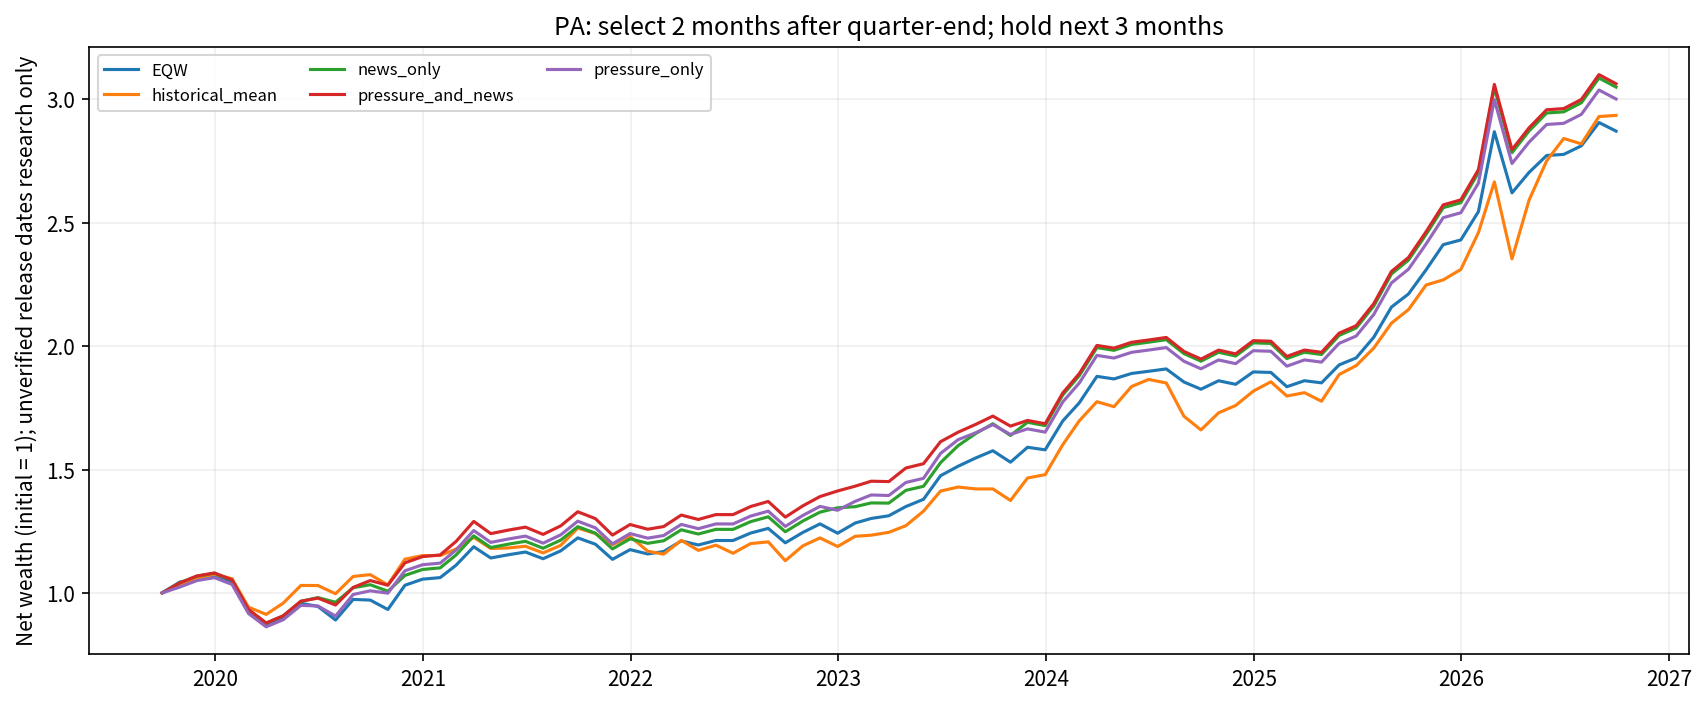

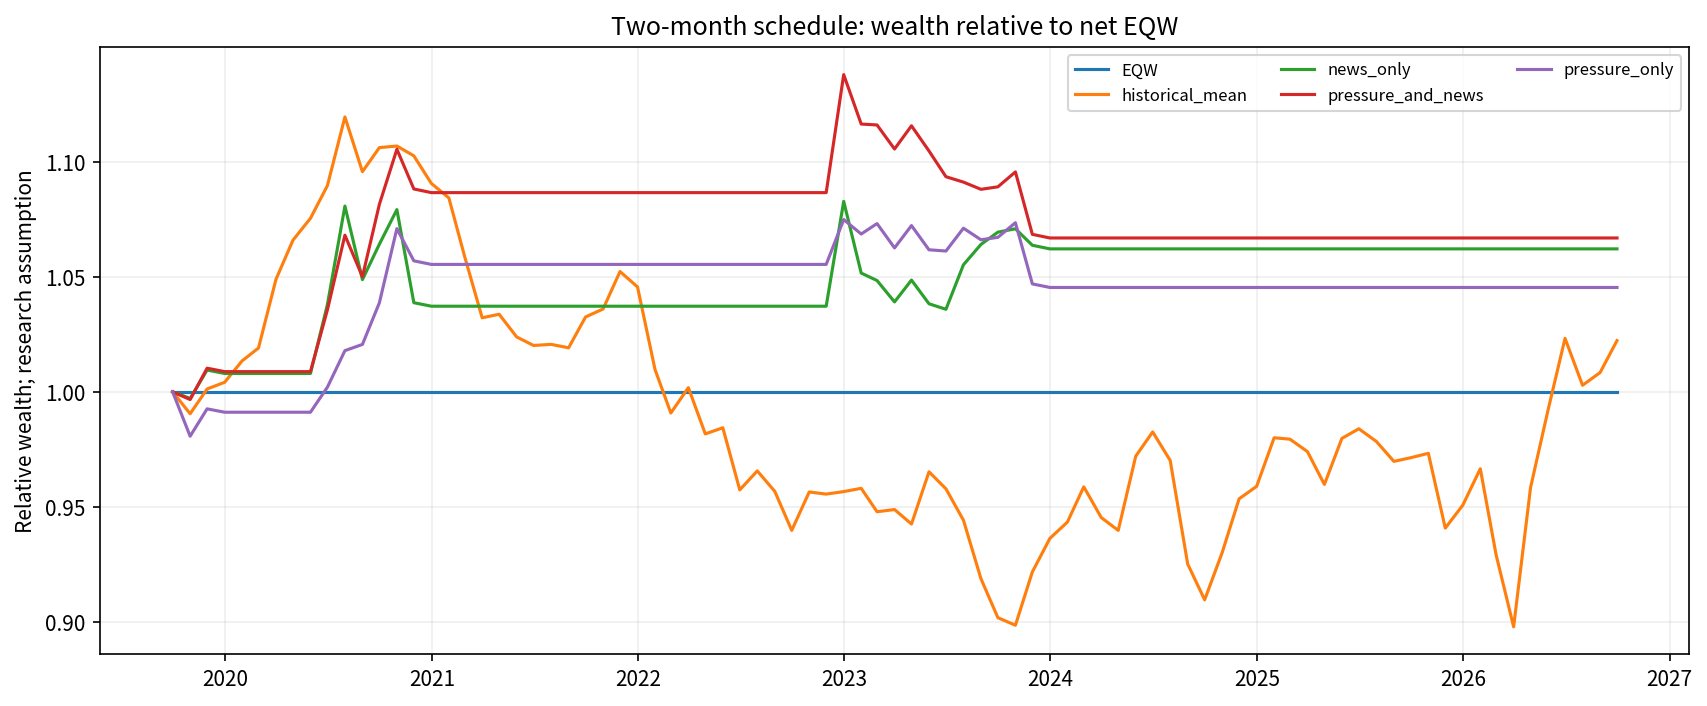

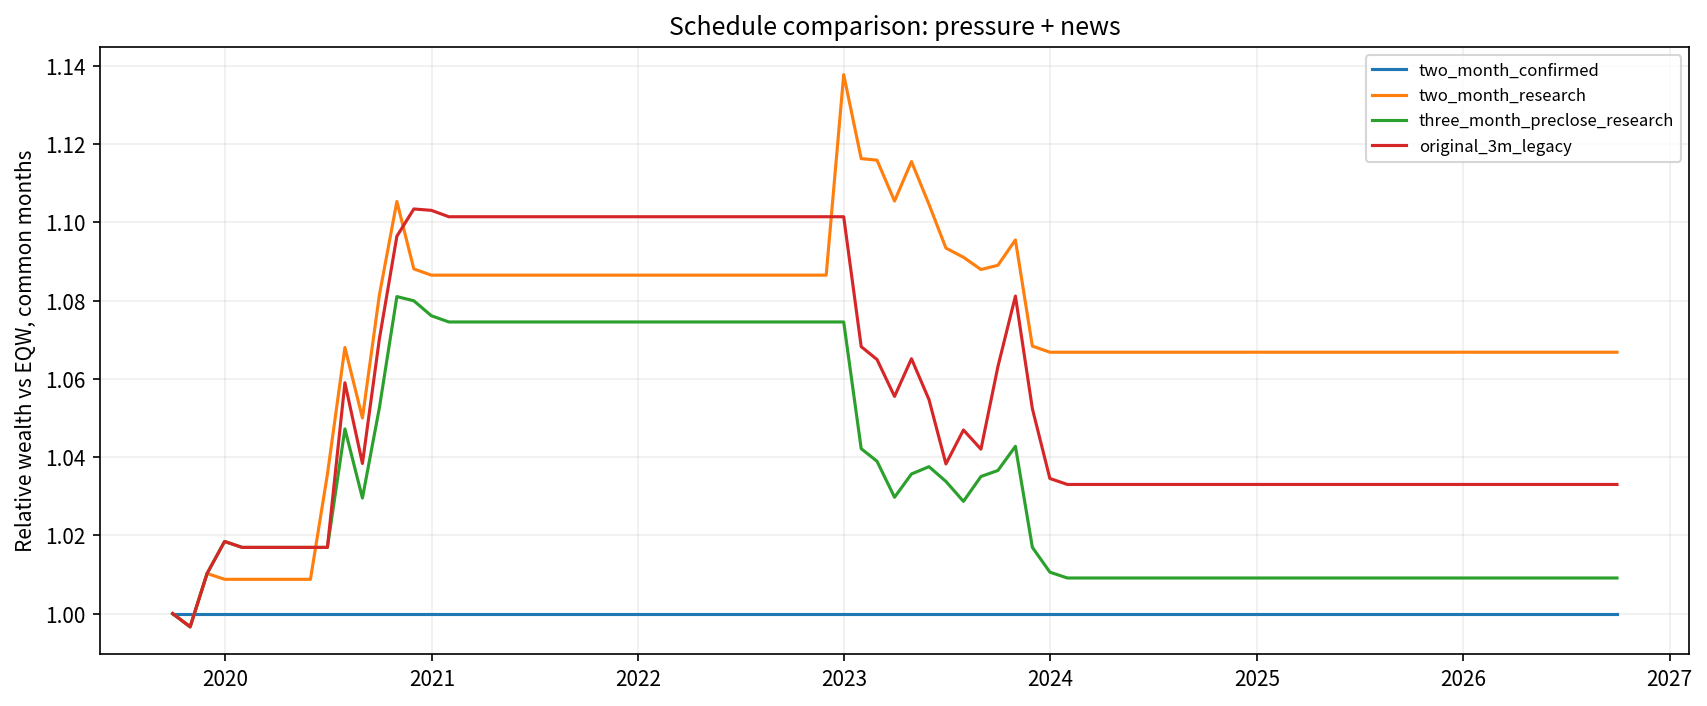

,scenario,n_months,geometric_relative_ann,IR,active_months,unconfirmed_fallback_months
2,two_month_confirmed,84,0.000000,NaN,0,84
7,two_month_research,84,0.009284,0.255042,20,0
12,three_month_preclose_research,84,0.001295,0.025109,21,0
17,original_3m_legacy,84,0.004651,0.126051,21,0


Two-month PA report: /mnt/data/BB_PA_QualityGate_Ablation/outputs/runs/_inprogress_20261014T223551_112148/results/pressure_assets_2m/report.html


In [61]:
def pa2_net_wealth_frame(ledger,months):
    curves={}
    for strategy,d in ledger.groupby('strategy'):
        r=d.set_index('month').net_return.reindex(months)
        if r.isna().any():raise ValueError('wealth計算期間に欠損')
        curves[strategy]=pd.concat([pd.Series([1.],index=pd.PeriodIndex([months[0]-1],freq='M')),(1+r).cumprod()])
    return pd.DataFrame(curves)

def pa2_plot(fig,name):
    fig.tight_layout();fig.savefig(PA2_FIG/name,dpi=150,bbox_inches='tight');plt.close(fig)
    display(DisplayImage(filename=str(PA2_FIG/name)))
pa2_wealth=pa2_net_wealth_frame(pa2_common_ledgers['two_month_research'],pa2_common)
pa2_save(pa2_wealth,'net_wealth_two_month_research.csv',index=True)
_pa2_fig,_pa2_ax=plt.subplots(figsize=(11.5,4.8))
for _pa2_col in pa2_wealth:
    _pa2_ax.plot(pa2_wealth.index.to_timestamp('M'),pa2_wealth[_pa2_col],label=_pa2_col)
_pa2_ax.set(title='PA: select 2 months after quarter-end; hold next 3 months',
            ylabel='Net wealth (initial = 1); unverified release dates research only')
_pa2_ax.grid(alpha=.2);_pa2_ax.legend(ncol=3,fontsize=8)
pa2_plot(_pa2_fig,'01_net_wealth_2m_research.png')
_pa2_fig,_pa2_ax=plt.subplots(figsize=(11.5,4.8))
for _pa2_col in pa2_wealth:
    _pa2_ax.plot(pa2_wealth.index.to_timestamp('M'),pa2_wealth[_pa2_col]/pa2_wealth.EQW,label=_pa2_col)
_pa2_ax.set(title='Two-month schedule: wealth relative to net EQW',ylabel='Relative wealth; research assumption')
_pa2_ax.grid(alpha=.2);_pa2_ax.legend(ncol=3,fontsize=8)
pa2_plot(_pa2_fig,'02_relative_wealth_2m_research.png')
pa2_compare_wealth={}
_pa2_fig,_pa2_ax=plt.subplots(figsize=(11.5,4.8))
for _pa2_scenario,_pa2_led in pa2_common_ledgers.items():
    _pa2_frame=pa2_net_wealth_frame(_pa2_led,pa2_common)
    pa2_compare_wealth[_pa2_scenario]=_pa2_frame.pressure_and_news/_pa2_frame.EQW
    _pa2_ax.plot(_pa2_frame.index.to_timestamp('M'),pa2_compare_wealth[_pa2_scenario],label=_pa2_scenario)
_pa2_ax.set(title='Schedule comparison: pressure + news',ylabel='Relative wealth vs EQW, common months')
_pa2_ax.grid(alpha=.2);_pa2_ax.legend(fontsize=8)
pa2_plot(_pa2_fig,'03_schedule_comparison.png')
pa2_save(pd.DataFrame(pa2_compare_wealth),'relative_wealth_schedule_comparison.csv',index=True)

def pa2_mdtable(frame,index=False):
    d=frame.reset_index() if index else frame.copy()
    def f(x):
        if isinstance(x,(float,np.floating)):return '' if pd.isna(x) else f'{x:.6f}'
        return str(x).replace('|','/')
    return '\n'.join(['| '+' | '.join(map(str,d.columns))+' |','| '+' | '.join(['---']*len(d.columns))+' |']+
                     ['| '+' | '.join(map(f,row))+' |' for row in d.itertuples(index=False,name=None)])
pa2_summary_table=pa2_perf_common.loc[pa2_perf_common.strategy=='pressure_and_news',
    ['scenario','n_months','geometric_relative_ann','IR','active_months','unconfirmed_fallback_months']]
pa2_last_schedule=pa2_main_schedule.iloc[-1]
pa2_last_release=pa2_availability['two_month_confirmed'].iloc[-1]
pa2_example_table=pa2_main_schedule.loc['2022Q4':'2023Q3',
    ['source_quarter','decision_month','holding_start_month','holding_end_month','training_label_end_month_max']]
pa2_method_md=f'''# PA：四半期末から2か月後の選定・その後3か月保有

## 主仕様
6月対象→8月末選定→9〜11月保有。2月・5月・8月・11月末に選定し、同じ対象を3か月維持。
保有中は元のPAと同じく月次で目標比率へ戻す。費用は売買額合計×片道{PA2_CFG['one_way_cost_bps']}bp。
BB・FT/PT・NewsOnly・月次C案・Economic Trendと従来PAは変更していない。
追加は`pa_paper_backtest(..., schedule=...)`と月単位の目的変数・学習制御。

## 時間対応
{pa2_mdtable(pa2_example_table)}
選定前に当月末価格を知っていることにはしない。学習ラベルは判断月より前の月で終了したものだけ。
例えば2023Q2→2023年8月末の学習末尾は、2022Q4源泉→2023年3〜5月リターン。
2023Q1源泉→2023年6〜8月リターンは8月末発注前に未確定なので除外する。
四半期源泉行は年4回のまま。最低学習数は{PA2_CFG['min_train_quarters']}四半期で、32か月へ短縮しない。
マクロ入力も対象四半期までに固定し、判断月までの新しい月次マクロは混ぜない。

## 公表確認とビンテージ
提供されたPA公表カレンダーの登録数は{len(PA2_RELEASE)}件。
**主方針はconfirmed_only。未登録・公表遅延・欠損はEQWへ戻し、その回を除外しない。**
全履歴の公表日が未入力なら、主方針がすべてEQWになるのは安全側の動作である。
並列のtwo_month_researchは、未登録日時について2か月後までに使えたと仮定した研究版。
既知の公表遅延があれば研究版でもブロックする。仮定日時を確認済み日時として記録しない。
公表日を登録しても、最新CSVに含まれる過去改定値を初回公表値へ戻す処理は行っていない。
現段階では全結果が最新ビンテージに条件付きで、production_eligible=False。

## 比較結果
共通期間：{pa2_common.min()}〜{pa2_common.max()}、{len(pa2_common)}か月。
{pa2_mdtable(pa2_summary_table)}
比率は小数（0.01=1%）。共通期間の開始直前は各戦略ともEQW保有に統一して費用を再計算。full-period ledgerは変更しない。strict主版と未確認日時の研究版は混同しない。
three_month_preclose_researchは同じ月末前学習条件の3か月待ち。
original_3m_legacyは元の3か月待ち・当月末までのラベルを使用する既存結果を変更せず掲載。
よって旧版との差には「1か月前倒し」と「学習締切の厳格化」の両方がある。
新2mと新3mで、日程の効果を同じ学習ルールの下で比較する。

## 直近計画
源泉期={pa2_last_schedule.source_quarter}、判断月={pa2_last_schedule.decision_month}、
計画保有={pa2_last_schedule.holding_start_month}〜{pa2_last_schedule.holding_end_month}。
公表状態={pa2_last_release.release_status}。
最後の3か月が未完了でも観測済みの月次損益は計上する。一方、予測評価に使う3か月リターンはNaNのまま。

## カレンダー
`inputs/pa_release_calendar.csv`: source_quarter,input_group,available_at,source,notes。
input_groupは{', '.join(PA2_CFG['required_input_groups'])}、または全入力をまとめたall_required_inputs。
全入力bundleは、モデルが使う改定済み履歴を含む必要入力を判断前に計算できた、という利用者の確認を表す。
日時だけの管理から真のビンテージを復元したとは認定しない。
日付のみのavailable_atは、その日のいつ公開されたか不明なので翌日00:00として保守的に解釈。
`inputs/pa_trade_calendar.csv`: decision_month,selection_cutoff_at,execution_at。
未登録時は月の最終平日00:00を情報締切、同日終了を月末価格の名目的組入れ境界とする。
土日は除くが日本市場の祝日・取引時間を確認済みではない。正確な日時はカレンダーで上書きする。
月次価格による月末組入れ近似であり、終値確定後の同じ価格での約定を保証しない。

## 保存・検証
全てpressure_assets_2m/。主ファイルschedule_main.csv / forecasts_main.csv / selection_weights_main.csv / monthly_ledger_main.csv。
研究版と比較版には名称にresearchを付ける。元のpressure_assets/は旧版のまま。
検査{len(PA2_CHECKS)}件、既存数値CSV/JSON{len(PA2_FILES_BEFORE)}件のハッシュ不変を確認。
失敗した場合は実行全体を未完了とし、元の成功latestを更新しない。
'''
(PA2_DIR/'RESULTS_ja.md').write_text(pa2_method_md,encoding='utf-8')
import html as _pa2_html,base64 as _pa2_b64

def pa2_htmltable(frame):
    return frame.to_html(index=False,border=0,float_format=lambda x:f'{x:.6f}')
def pa2_image(name,caption):
    encoded=_pa2_b64.b64encode((PA2_FIG/name).read_bytes()).decode()
    return f'<figure><figcaption>{_pa2_html.escape(caption)}</figcaption><img src="data:image/png;base64,{encoded}" alt="{_pa2_html.escape(caption)}"></figure>'
pa2_html_body=f'''<header><p>PA BACKTEST / 2-MONTH SELECTION LAG</p><h1>四半期末＋2か月で選定、翌月から3か月保有</h1>
<p>例：6月のマクロ→8月末選定→9・10・11月の損益。分析基準日：{AS_OF_DATE.date()}</p></header>
<section class="notice"><h2>公表未確認と、日程仮定の研究結果を分離</h2>
<p>PA公表日時の登録は{len(PA2_RELEASE)}件です。<b>主仕様は公表確認必須で、未確認・遅延時にはEQW</b>です。
未登録日時を2か月後までに利用可能と仮定する研究版を別に計算します。以下の研究曲線を実運用可能な成績と解釈しないでください。
公表日登録後も、原CSVの過去ビンテージと実際の約定は未検証です。</p></section>
<section><h2>選定・学習の時間対応</h2>{pa2_htmltable(pa2_example_table)}
<p>学習の3か月ラベルは判断月前の月で完了したものに限定。8月末選定で6〜8月の未確定ラベルは使いません。
前の固定四半期予測を1か月ずらしたのではなく、9〜11月等の目的変数を全履歴で再生成し、モデルを再学習しています。</p></section>
<section><h2>同じ評価期間の比較</h2><p>{pa2_common.min()}〜{pa2_common.max()}、{len(pa2_common)}か月。表はpressure_and_news戦略。共通開始時の保有をEQWに統一して初期売買費用も同じ基準から再計算しています。</p>
{pa2_htmltable(pa2_summary_table)}
<p>two_month_confirmed＝主公表確認方針。two_month_research＝未確認日時を仮定する研究版。
three_month_preclose_research＝同じ学習締切の3か月ラグ。original_3m_legacy＝従来版（変更なし）。</p>
{pa2_image('03_schedule_comparison.png','日程比較：EQW対比の相対wealth')}</section>
<section><h2>2か月ラグ研究版のnet wealth</h2>{pa2_image('01_net_wealth_2m_research.png','費用控除後net wealth、共通期間開始前＝1')}
{pa2_image('02_relative_wealth_2m_research.png','費用控除後EQW対比の相対wealth')}
<p>予測値・品質を源泉四半期ごとに評価しTop4またはEQW。保有中は毎月同じ比率へ戻します。
historical_meanは元PAどおり品質条件を使いませんが、公表確認・学習可否の条件は新全戦略に適用します。</p></section>
<section><h2>直近の計画</h2><p>{pa2_last_schedule.source_quarter}→{pa2_last_schedule.decision_month}選定→
{pa2_last_schedule.holding_start_month}〜{pa2_last_schedule.holding_end_month}保有。公表判定：{pa2_last_release.release_status}。</p>
<p>未完了の3か月リターンを補完せず、観測済み月だけ月次損益を記録。期間内の欠損は黙って除外せず停止します。</p></section>
<footer><h2>運用・監査</h2><p>公表日時はpa_release_calendar.csv、判断締切と組入れ境界はpa_trade_calendar.csv。
未登録取引日は最終平日の月末価格近似で、日本市場の祝日や約定可能性を保証しません。</p>
<p>既存PA・月次C案・Economic Trendは比較用に維持。追加検査{len(PA2_CHECKS)}件、元数値ファイル{len(PA2_FILES_BEFORE)}件の不変を確認。</p></footer>'''
pa2_css='body{max-width:1120px;margin:auto;padding:32px;font-family:-apple-system,BlinkMacSystemFont,"Segoe UI","Noto Sans JP",sans-serif;line-height:1.7;color:#203343}header{border-bottom:3px solid #23445b}h1{font-size:30px}h2{font-size:23px}section{margin:32px 0}.notice{background:#f1f4f7;padding:20px;border-left:4px solid #23445b}table{display:block;max-width:100%;overflow-x:auto;border-collapse:collapse;font-size:12px}th,td{padding:8px;border-bottom:1px solid #ddd;white-space:nowrap;text-align:right}img{width:100%;height:auto}figure{margin:26px 0}figcaption{font-weight:600}footer{border-top:2px solid #23445b;font-size:13px}'
(PA2_DIR/'report.html').write_text('<!doctype html><html lang="ja"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>PA two-month lag</title><style>'+pa2_css+'</style><body>'+pa2_html_body+'</body></html>',encoding='utf-8')
# 観測履歴の保存時刻を名目的な過去選定日へ付け替えない。
pa2_observed=pa2_predictions['two_month_research'].loc[pa2_predictions['two_month_research'].source_quarter==pa2_last_schedule.source_quarter].copy()
pa2_observed['recorded_at']=datetime.now(timezone(timedelta(hours=9))).isoformat();pa2_observed['run_id']=RUN_ID
pa2_observed['calculation_as_of']=str(AS_OF_DATE.date());pa2_observed['is_historical_release_vintage']=False
if PREVIOUS_DIR is not None and (PREVIOUS_DIR/'results/pressure_assets_2m/observed_forecast_archive.csv').exists():
    pa2_observed=pd.concat([pd.read_csv(PREVIOUS_DIR/'results/pressure_assets_2m/observed_forecast_archive.csv'),pa2_observed],ignore_index=True)
pa2_save(pa2_observed,'observed_forecast_archive.csv')

def pa2_publish_link():
    path=RESULT_DIR/'report.html'
    if path.exists():
        text=path.read_text(encoding='utf-8')
        note='<section><h2>追加：PAの2か月待ち・3か月保有</h2><p>6月対象→8月末選定→9〜11月保有。公表確認版と未確認日時の研究版を分離。<a href="pressure_assets_2m/report.html">日程変更レポート</a></p></section>'
        path.write_text(text.replace('<body>','<body>'+note,1),encoding='utf-8')
display(pa2_summary_table)
print('Two-month PA report:',PA2_DIR/'report.html')


# 23．BBレジーム品質ゲートの除去実験（予測は固定）
**主比較はPAの2か月ラグ・3か月保有のまま、BB品質によるTop4停止だけを外す実験です。**
BB推定、品質ラベル、Ridge係数・予測値、公表確認、学習期間、選定日、保有期間、費用は変更しません。
`two_month_research`は従来どおり未登録公表日時を仮定する研究版です。
`two_month_confirmed`は引き続き公表確認を要求し、未登録なら品質ゲートを外してもEQWです。

- `gate_on_top4`：従来と同じ。公表可／学習済み／品質可／正予測4つ以上でTop4。
- `gate_off_top4`：上記から**品質可だけを除去**。正予測4つ以上なら上位4資産を各25%。純粋なゲート除去比較。
- `gate_off_all_positive`：補助比較。正予測を持つ全資産を等ウェイト。銘柄数規則も変わるので、ゲート除去だけの効果ではない。

low/HOLDを良好へ書き換えません。品質は診断・事後の条件別分析に残します。
原版を上書きせず、新結果を`quality_gate_ablation/`へ保存します。

In [62]:
GA_CFG={
    "version":"PA_quality_gate_ablation_v1",
    "include_all_positive":True,
    "cost_bps_grid":[0.,10.,25.],
    "paired_block_months":12,"bootstrap_reps":1999,"seed":4217,
    "research_scenario":"two_month_research","primary_model":"pressure_and_news",
    "production_eligible":False,
}
GA_DIR=RESULT_DIR/"quality_gate_ablation";GA_FIG=GA_DIR/"figures"
GA_FIG.mkdir(parents=True,exist_ok=True)
GA_TESTS=[]
GA_PROTECTED=["model","dual_model","reg_main","pa_recursive","PA_CFG","PA2_CFG",
              "pa2_predictions","pa2_schedules","pa2_weights","pa2_ledgers","pa2_common_ledgers",
              "pa_wf","pa_monthly","CM_CFG","ET_CFG"]
def ga_fingerprint(obj):
    # pandas index engines/lookup caches can mutate on reads; compare values/schema, not cache pickle bytes.
    h=hashlib.sha256()
    def add(x):
        if isinstance(x,pd.DataFrame):
            h.update(b"frame");h.update(pd.util.hash_pandas_object(x,index=True).to_numpy().tobytes())
            h.update(repr((list(x.columns),list(map(str,x.dtypes)),x.index.names,str(x.index.dtype),getattr(x.index,"freqstr",None))).encode())
        elif isinstance(x,pd.Series):
            h.update(b"series");h.update(pd.util.hash_pandas_object(x,index=True).to_numpy().tobytes())
            h.update(repr((x.name,str(x.dtype),x.index.names,str(x.index.dtype),getattr(x.index,"freqstr",None))).encode())
        elif isinstance(x,pd.Index):
            h.update(b"index");h.update(pd.util.hash_pandas_object(x).to_numpy().tobytes())
            h.update(repr((x.names,str(x.dtype),getattr(x,"freqstr",None))).encode())
        elif isinstance(x,dict):
            for k in sorted(x,key=repr):h.update(repr(k).encode());add(x[k])
        elif isinstance(x,(list,tuple)):
            h.update(type(x).__name__.encode())
            for v in x:add(v)
        elif isinstance(x,np.ndarray):
            h.update(str(x.shape).encode());h.update(str(x.dtype).encode())
            if x.dtype.hasobject:
                for v in x.ravel():add(v)
            else:h.update(x.tobytes())
        else:h.update(repr(x).encode())
    add(obj);return h.hexdigest()
GA_BEFORE={k:ga_fingerprint(globals()[k]) for k in GA_PROTECTED}
GA_FILES_BEFORE={str(p.relative_to(RESULT_DIR)):sha256(p.read_bytes()) for p in RESULT_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in [".csv",".json"] and not p.is_relative_to(GA_DIR)}
def ga_check(name,ok,detail=""):
    GA_TESTS.append({"test":name,"passed":bool(ok),"detail":str(detail)})
    check("gate_ablation_"+name,ok,detail)
def ga_save(frame,name,index=False):
    save_csv(frame,name,index=index,folder=GA_DIR)
def ga_json(obj,name):
    reg_json(obj,GA_DIR/name)
def ga_paper_backtest(predictions,schedule,monthly_returns,config, *, apply_quality_gate=True, positive_selection="top_n"):
    """月単位日程を受け取るPA会計。予測対象は3か月、実績は観測済みの各月に計上する。"""
    if not isinstance(apply_quality_gate,(bool,np.bool_)):raise ValueError("apply_quality_gate must be bool")
    if positive_selection not in ["top_n","all_positive"]:raise ValueError("positive_selection must be top_n or all_positive")
    if predictions.duplicated(['model','source_quarter','asset']).any():raise ValueError('予測キーの重複')
    cols=list(monthly_returns.columns);n=len(cols);eq=np.full(n,1/n)
    full=monthly_returns.reindex(pd.period_range(monthly_returns.index.min(),monthly_returns.index.max(),freq='M'))
    last=full.index.max();records=[];weights=[]
    strategies=['pressure_only','news_only','pressure_and_news','historical_mean','EQW']
    for strategy in strategies:
        predname='pressure_and_news' if strategy in ['historical_mean','EQW'] else strategy
        data=predictions.loc[predictions.model==predname]
        pre=eq.copy();previous_month=None;started=False
        for q,s in schedule.iterrows():
            block=data.loc[data.source_quarter==q].set_index('asset').reindex(cols)
            if block.empty or block.raw_mature_train_n.isna().all():continue
            # 全方針で同じ経済標本のwarmupを使う。公表不足の本番版はその後EQWで存続し、期間を消さない。
            if not started and block.raw_mature_train_n.iloc[0]<config['min_train_quarters']:continue
            if s.selection_cutoff_at>pd.Timestamp(AS_OF_DATE).tz_localize('Asia/Tokyo')+pd.Timedelta(days=1):continue
            months=pd.period_range(s.holding_start_month,s.holding_end_month,freq='M')
            observed=months[months<=last]
            if len(observed)==0:continue
            started=True
            usable=bool(block.feature_usable_at_decision.fillna(False).all())
            trained=bool(block.forecast_status.eq('estimated').all())
            quality=block.prefix_quality.iloc[0]
            quality_ok=quality not in ['low','not_available','insufficient',None] and pd.notna(quality)
            scores=block.historical_mean_pp if strategy=='historical_mean' else block.prediction_active_pp
            target=eq.copy();action='EQW_default';selected=[]
            if strategy=='EQW':action='EQW_benchmark'
            elif not usable:action='EQW_release_or_feature_unavailable'
            elif not trained:action='EQW_insufficient_training'
            elif apply_quality_gate and not quality_ok and strategy!='historical_mean':action='EQW_quality_gate'
            elif np.isfinite(scores.to_numpy(float)).all() and (scores>0).sum()>=(config['top_n'] if positive_selection=='top_n' else 1):
                ranked=scores[scores>0].sort_values(ascending=False,kind='mergesort')
                selected=list(ranked.index[:config['top_n']] if positive_selection=='top_n' else ranked.index)
                target=np.array([1/len(selected) if a in selected else 0. for a in cols]);action='research_top4' if positive_selection=='top_n' else 'research_all_positive'
            else:action='EQW_fewer_than_top_n_positive' if positive_selection=='top_n' else 'EQW_no_positive_or_nonfinite_prediction'
            override=bool(not apply_quality_gate and not quality_ok and strategy not in ['EQW','historical_mean'] and len(selected)>0)
            for a,w in zip(cols,target):
                weights.append({'strategy':strategy,'source_quarter':q,'decision_month':s.decision_month,
                  'selection_cutoff_at':s.selection_cutoff_at,'holding_start_month':s.holding_start_month,
                  'holding_end_month':s.holding_end_month,'asset':a,'weight':w,'action':action,
                  'prefix_quality':quality,'release_status':block.release_status.iloc[0],
                  'period_complete':bool(months[-1]<=last),'production_eligible':False,
                  'quality_gate_enabled':bool(apply_quality_gate),'quality_gate_bypassed':override,
                  'n_positive':int((scores>0).sum()),'selected_n':len(selected),'positive_selection':positive_selection,
                  'prediction_active_pp':float(block.loc[a,'prediction_active_pp']) if pd.notna(block.loc[a,'prediction_active_pp']) else np.nan})
            for m in observed:
                # 将来3か月の欠損を選定条件にしない。内部欠損は評価不能として停止し、0で穴埋めしない。
                if previous_month is not None and m!=previous_month+1:raise ValueError('損益期間に空白または重複があります')
                r=full.loc[m,cols].to_numpy(float)
                if not np.isfinite(r).all():raise ValueError(f'{m}: 評価期間内のリターン欠損。期間を黙って除外しません')
                if np.any(r<=-1):raise ValueError('保有リターンが-100%以下')
                trade=float(abs(target-pre).sum());cost=trade*config['one_way_cost_bps']/10000
                gross=float(target@r);net=(1-cost)*(1+gross)-1
                records.append({'strategy':strategy,'source_quarter':q,'decision_month':s.decision_month,'month':m,
                    'gross_return':gross,'net_return':net,'trade_notional':trade,'turnover_half_l1':trade/2,
                    'transaction_cost_fraction':cost,'action':action,'holding_period_complete':bool(months[-1]<=last),
                    'quality_gate_enabled':bool(apply_quality_gate),'quality_gate_bypassed':override,
                    'prefix_quality':quality,'selected_n':len(selected),'n_positive':int((scores>0).sum()),'positive_selection':positive_selection})
                pre=target*(1+r)/(1+gross);previous_month=m
    return pd.DataFrame(records),pd.DataFrame(weights)

def ga_performance(ledger):
    """元PAの指標を維持し、全正予測版の積極月数などだけ拡張。CASHなしSharpeは捏造しない。"""
    result=pa2_performance(ledger)
    bm=ledger.loc[ledger.strategy=="EQW"].set_index("month").net_return
    for i,row in result.iterrows():
        part=ledger.loc[ledger.strategy==row.strategy].set_index("month").sort_index()
        r=part.net_return;b=bm.reindex(r.index)
        result.loc[i,"active_months"]=int(part.action.isin(["research_top4","research_all_positive"]).sum())
        result.loc[i,"quality_bypass_months"]=int(part.quality_gate_bypassed.sum())
        result.loc[i,"terminal_net_wealth"]=float((1+r).prod())
        result.loc[i,"terminal_relative_wealth"]=float((1+r).prod()/(1+b).prod())
        result.loc[i,"gross_CAGR"]=float((1+part.gross_return).prod()**(12/len(part))-1)
        result.loc[i,"gross_geometric_relative_ann"]=float(((1+part.gross_return).prod()/(1+ledger.loc[ledger.strategy=="EQW"].set_index("month").reindex(part.index).gross_return).prod())**(12/len(part))-1)
        result.loc[i,"annual_cost_notional_bp"]=float(part.transaction_cost_fraction.mean()*12*10000)
        result.loc[i,"monthly_active_hit_rate"]=float((r>b+1e-12).mean())
        result.loc[i,"selected_n_mean_when_active"]=float(part.loc[part.selected_n>0,"selected_n"].mean())
    return result

GA_MODES={"gate_on_top4":(True,"top_n"),"gate_off_top4":(False,"top_n")}
if GA_CFG["include_all_positive"]:GA_MODES["gate_off_all_positive"]=(False,"all_positive")
ga_ledgers={};ga_weights={};ga_common_ledgers={};ga_perf_rows=[]
for ga_scenario in ["two_month_research","two_month_confirmed","three_month_preclose_research"]:
    for ga_mode,(ga_enabled,ga_policy) in GA_MODES.items():
        ga_key=(ga_scenario,ga_mode)
        ga_l,ga_w=ga_paper_backtest(pa2_predictions[ga_scenario],pa2_schedules[ga_scenario],
            pa_monthly[current_assets],PA2_CFG,apply_quality_gate=ga_enabled,positive_selection=ga_policy)
        ga_ledgers[ga_key]=ga_l;ga_weights[ga_key]=ga_w
        ga_c=pa2_common_reaccount(ga_l,ga_w,pa2_common,pa_monthly[current_assets],PA2_CFG)
        ga_common_ledgers[ga_key]=ga_c
        ga_perf_rows.append(ga_performance(ga_c).assign(scenario=ga_scenario,mode=ga_mode))
        ga_save(ga_l,"monthly_ledger_"+ga_scenario+"__"+ga_mode+".csv")
        ga_save(ga_w,"selection_weights_"+ga_scenario+"__"+ga_mode+".csv")
        ga_save(ga_c,"common_ledger_"+ga_scenario+"__"+ga_mode+".csv")
ga_perf=pd.concat(ga_perf_rows,ignore_index=True)
ga_save(ga_perf,"performance_common_period.csv")
# 比較に使った予測・品質・日程をそのまま保存。上流再推定・品質書換えを行わない。
ga_save(pa2_predictions["two_month_research"],"forecasts_used_UNCHANGED.csv")
ga_save(pa2_schedules["two_month_research"],"schedule_used_UNCHANGED.csv",index=False)
ga_save(pa_recursive,"source_features_UNCHANGED.csv",index=True)
ga_json(GA_CFG,"settings.json")
display(ga_perf.loc[(ga_perf.scenario=="two_month_research")&(ga_perf.strategy=="pressure_and_news"),
    ["mode","CAGR","geometric_relative_ann","IR","tracking_error","max_drawdown","active_months"]])

,mode,CAGR,geometric_relative_ann,IR,tracking_error,max_drawdown,active_months
2,gate_on_top4,0.173418,0.009284,0.255042,0.032476,-0.187592,20
7,gate_off_top4,0.203826,0.035439,0.532694,0.068490,-0.179336,84
12,gate_off_all_positive,0.204199,0.035760,0.744547,0.048494,-0.170305,84


## 23A．変更した64か月・条件別寄与・取引費用・不確実性
同じ共通期間・同じ初期EQWから、両方の売買経路を再計算します。品質通過月の目標ウェイトが同じでも、
前月保有が違う場合の売買費用は違うため、単にlow月のリターンを差し替えません。
停止期間別の累積値はそれぞれ**実際に連続する区間**だけを集計し、離れた64か月を連続した暦として年率化しません。
ブロック再標本化は実現済みの同月リターンを3系列で同期し、BB・予測モデル・設計選択の全不確実性を再推定するものではありません。

In [63]:
ga_decisions=[];ga_effects=[];ga_episodes=[]
for ga_model in ["pressure_only","news_only","pressure_and_news"]:
    ga_on=ga_common_ledgers[("two_month_research","gate_on_top4")].query("strategy==@ga_model").set_index("month").sort_index()
    ga_off=ga_common_ledgers[("two_month_research","gate_off_top4")].query("strategy==@ga_model").set_index("month").reindex(ga_on.index)
    ga_bench=ga_common_ledgers[("two_month_research","gate_on_top4")].query("strategy=='EQW'").set_index("month").reindex(ga_on.index)
    ga_e=pd.DataFrame(index=ga_on.index)
    ga_e["source_quarter"]=ga_on.source_quarter;ga_e["decision_month"]=ga_on.decision_month
    ga_e["baseline_action"]=ga_on.action;ga_e["counterfactual_action"]=ga_off.action
    ga_e["baseline_quality"]=ga_off.prefix_quality;ga_e["quality_gate_bypassed"]=ga_off.quality_gate_bypassed
    ga_e["gate_on_net_return"]=ga_on.net_return;ga_e["gate_off_net_return"]=ga_off.net_return
    ga_e["EQW_net_return"]=ga_bench.net_return
    ga_e["net_return_difference_pp"]=100*(ga_off.net_return-ga_on.net_return)
    ga_e["gross_log_effect"]=np.log1p(ga_off.gross_return)-np.log1p(ga_on.gross_return)
    ga_e["cost_log_effect"]=np.log1p(-ga_off.transaction_cost_fraction)-np.log1p(-ga_on.transaction_cost_fraction)
    ga_e["net_log_effect"]=np.log1p(ga_off.net_return)-np.log1p(ga_on.net_return)
    ga_check("log_effect_identity_"+ga_model,np.allclose(ga_e.net_log_effect,ga_e.gross_log_effect+ga_e.cost_log_effect,atol=1e-14))
    ga_e["strategy"]=ga_model;ga_effects.append(ga_e.reset_index())
    ga_mask=ga_on.action.eq("EQW_quality_gate")
    ga_groups=ga_mask.ne(ga_mask.shift()).cumsum()
    for _,ga_period in ga_e.loc[ga_mask].groupby(ga_groups[ga_mask]):
        ga_d=ga_period;ga_episodes.append({"strategy":ga_model,"start_month":str(ga_d.index.min()),"end_month":str(ga_d.index.max()),
          "n_months":len(ga_d),"source_first":str(ga_d.source_quarter.iloc[0]),"source_last":str(ga_d.source_quarter.iloc[-1]),
          "gate_on_cumulative_net":float((1+ga_d.gate_on_net_return).prod()-1),
          "gate_off_cumulative_net":float((1+ga_d.gate_off_net_return).prod()-1),
          "EQW_cumulative_net":float((1+ga_d.EQW_net_return).prod()-1),
          "gate_off_relative_to_EQW":float((1+ga_d.gate_off_net_return).prod()/(1+ga_d.EQW_net_return).prod()-1),
          "gate_off_relative_to_gate_on":float(np.expm1(ga_d.net_log_effect.sum())),
          "gross_log_effect":float(ga_d.gross_log_effect.sum()),"cost_log_effect":float(ga_d.cost_log_effect.sum()),
          "net_log_effect":float(ga_d.net_log_effect.sum()),"annualized":False})
    ga_won=ga_weights[("two_month_research","gate_on_top4")].query("strategy==@ga_model")
    ga_woff=ga_weights[("two_month_research","gate_off_top4")].query("strategy==@ga_model")
    ga_visible=set(ga_on.source_quarter.astype(str))
    for ga_q,ga_block in ga_woff.groupby("source_quarter",sort=True):
        if str(ga_q) not in ga_visible:continue
        ga_old=ga_won.loc[ga_won.source_quarter==ga_q].set_index("asset")
        ga_row=ga_block.iloc[0];ga_meta=pa_recursive.loc[ga_q]
        ga_decisions.append({"strategy":ga_model,"source_quarter":str(ga_q),"decision_month":str(ga_row.decision_month),
          "holding_start":str(ga_row.holding_start_month),"holding_end":str(ga_row.holding_end_month),
          "observed_months_common":int((ga_on.source_quarter==ga_q).sum()),"prefix_quality":ga_row.prefix_quality,
          "regime_candidate":ga_meta.regime_stable,"regime_final":ga_meta.regime_final,"quality_reason_codes":ga_meta.reason_codes,
          "original_action":ga_old.action.iloc[0],"new_action":ga_row.action,"quality_gate_bypassed":bool(ga_row.quality_gate_bypassed),
          "n_positive":int(ga_row.n_positive),"selected_n":int(ga_row.selected_n),
          "selected_assets":" / ".join(ga_block.loc[ga_block.weight>0,"asset"]),
          "top4_forecast_min_pp":float(ga_block.loc[ga_block.weight>0,"prediction_active_pp"].min()),
          "top4_forecast_max_pp":float(ga_block.loc[ga_block.weight>0,"prediction_active_pp"].max())})
ga_decision_audit=pd.DataFrame(ga_decisions);ga_effect_monthly=pd.concat(ga_effects,ignore_index=True);ga_episode_table=pd.DataFrame(ga_episodes)
ga_save(ga_decision_audit,"decision_audit_gate_on_vs_off.csv")
ga_save(ga_effect_monthly,"monthly_gate_effects.csv")
ga_save(ga_episode_table,"previously_blocked_episode_results.csv")
ga_quality_stats=[]
for ga_mod,ga_data in ga_effect_monthly.groupby("strategy"):
    for ga_kind,ga_d in ga_data.groupby("quality_gate_bypassed"):
        ga_quality_stats.append({"strategy":ga_mod,"quality_gate_bypassed":bool(ga_kind),"n_months":len(ga_d),
          "mean_monthly_net_gain_pp":ga_d.net_return_difference_pp.mean(),
          "monthly_win_rate_off_vs_on":float((ga_d.net_return_difference_pp>1e-10).mean()),
          "sum_log_gain":ga_d.net_log_effect.sum(),"gross_log_effect":ga_d.gross_log_effect.sum(),"cost_log_effect":ga_d.cost_log_effect.sum(),
          "note":"noncontiguous conditional observations; NOT annualized contiguous portfolio"})
ga_save(pd.DataFrame(ga_quality_stats),"conditional_gate_effect_statistics.csv")
# 同じ目標保有・売買量で費用だけを変更する。費用はモデルの予測値へ逆流させない。
ga_cost_results=[]
for ga_cost in GA_CFG["cost_bps_grid"]:
    for ga_mode in GA_MODES:
        ga_c=ga_common_ledgers[("two_month_research",ga_mode)].copy(deep=True)
        ga_c["transaction_cost_fraction"]=ga_c.trade_notional*float(ga_cost)/10000
        ga_c["net_return"]=(1-ga_c.transaction_cost_fraction)*(1+ga_c.gross_return)-1
        ga_cost_results.append(ga_performance(ga_c).assign(mode=ga_mode,one_way_cost_bps=ga_cost))
ga_save(pd.concat(ga_cost_results,ignore_index=True),"transaction_cost_sensitivity.csv")
# 実現リターンのpaired moving-block bootstrap。ゲート条件・予測・BBを再最適化しない。
ga_boot=[]
for ga_model in ["pressure_only","news_only","pressure_and_news"]:
    ga_d=ga_effect_monthly.query("strategy==@ga_model").sort_values("month")
    ga_n=len(ga_d);ga_b=min(GA_CFG["paired_block_months"],ga_n)
    ga_rng=np.random.default_rng(GA_CFG["seed"])
    ga_log=np.log1p(ga_d[["gate_on_net_return","gate_off_net_return","EQW_net_return"]].to_numpy(float))
    ga_draw=[]
    for _ in range(GA_CFG["bootstrap_reps"]):
        ga_starts=ga_rng.integers(0,ga_n-ga_b+1,size=int(np.ceil(ga_n/ga_b)))
        ga_ids=np.concatenate([np.arange(s,s+ga_b) for s in ga_starts])[:ga_n]
        ga_sums=ga_log[ga_ids].sum(axis=0)
        ga_draw.append(np.expm1((12/ga_n)*np.array([ga_sums[0]-ga_sums[2],ga_sums[1]-ga_sums[2],ga_sums[1]-ga_sums[0]])))
    ga_draw=np.array(ga_draw)
    ga_orig=ga_log.sum(axis=0)
    ga_est=np.expm1((12/ga_n)*np.array([ga_orig[0]-ga_orig[2],ga_orig[1]-ga_orig[2],ga_orig[1]-ga_orig[0]]))
    for j,ga_measure in enumerate(["gate_on_vs_EQW","gate_off_vs_EQW","gate_off_vs_gate_on"]):
        ga_lo,ga_hi=np.quantile(ga_draw[:,j],[.025,.975])
        ga_boot.append({"strategy":ga_model,"comparison":ga_measure,"n_months":ga_n,
          "estimate_geometric_relative_ann":ga_est[j],"bootstrap_95_low":ga_lo,"bootstrap_95_high":ga_hi,
          "bootstrap_reps":GA_CFG["bootstrap_reps"],"block_months":ga_b,
          "scope":"conditional paired return blocks; not full BB/model uncertainty, not new holdout"})
ga_boot_table=pd.DataFrame(ga_boot);ga_save(ga_boot_table,"paired_block_uncertainty.csv")
# 年別は完全な暦年と部分年を区別。開始保有と費用は全期間会計の続き。
ga_annual=[]
for ga_mode in GA_MODES:
    for ga_strategy,ga_l in ga_common_ledgers[("two_month_research",ga_mode)].groupby("strategy"):
        ga_bm=ga_common_ledgers[("two_month_research",ga_mode)].query("strategy=='EQW'").set_index("month").net_return
        for ga_year,ga_d in ga_l.groupby(ga_l.month.map(lambda x:x.year)):
            ga_annual.append({"mode":ga_mode,"strategy":ga_strategy,"year":ga_year,"n_months":len(ga_d),
              "complete_calendar_year":len(ga_d)==12,"net_return":float((1+ga_d.net_return).prod()-1),
              "EQW_return":float((1+ga_bm.reindex(ga_d.month)).prod()-1),
              "relative_return":float((1+ga_d.net_return).prod()/(1+ga_bm.reindex(ga_d.month)).prod()-1)})
ga_save(pd.DataFrame(ga_annual),"annual_returns.csv")

## 23B．品質以外の条件と既存結果の不変検査
公表不可、学習不足、価格欠損、正予測不足を緩めないことを検査します。
品質ONで元の配分・リターンを再現し、OFFとの目標ウェイト差が元の品質停止判断だけに生じることを確認します。
正予測が不足する将来ケースは、Top4比較では引き続きEQW。全正予測版のみ、正予測1資産以上でその全てを保有します。

In [64]:
for ga_scenario in ["two_month_research","two_month_confirmed","three_month_preclose_research"]:
    ga_old=pa2_common_ledgers[ga_scenario].sort_values(["strategy","month"]).reset_index(drop=True)
    ga_replay=ga_common_ledgers[(ga_scenario,"gate_on_top4")].sort_values(["strategy","month"]).reset_index(drop=True)
    ga_check("baseline_shape_"+ga_scenario,len(ga_old)==len(ga_replay))
    for ga_col in ["gross_return","net_return","trade_notional","transaction_cost_fraction"]:
        ga_delta=float(np.max(abs(ga_old[ga_col]-ga_replay[ga_col])))
        ga_check("baseline_replay_"+ga_scenario+"_"+ga_col,ga_delta<1e-12,ga_delta)
    ga_check("baseline_actions_"+ga_scenario,ga_old.action.equals(ga_replay.action))
    ga_w0=ga_weights[(ga_scenario,"gate_on_top4")]
    ga_w1=ga_weights[(ga_scenario,"gate_off_top4")]
    ga_keycols=["strategy","source_quarter","asset"]
    ga_join=ga_w0.merge(ga_w1,on=ga_keycols,suffixes=("_on","_off"),validate="one_to_one")
    ga_changed=abs(ga_join.weight_on-ga_join.weight_off)>1e-12
    ga_check("only_quality_blocked_targets_change_"+ga_scenario,
        ga_join.loc[ga_changed,"action_on"].eq("EQW_quality_gate").all())
    ga_check("quality_labels_not_faked_"+ga_scenario,
        ga_join.prefix_quality_on.fillna("NA").equals(ga_join.prefix_quality_off.fillna("NA")))
    for ga_control in ["historical_mean","EQW"]:
        ga_a=ga_common_ledgers[(ga_scenario,"gate_on_top4")].query("strategy==@ga_control").net_return.to_numpy()
        ga_b=ga_common_ledgers[(ga_scenario,"gate_off_top4")].query("strategy==@ga_control").net_return.to_numpy()
        ga_check("control_unchanged_"+ga_scenario+"_"+ga_control,np.array_equal(ga_a,ga_b))
for ga_key,ga_w in ga_weights.items():
    ga_name="__".join(ga_key);ga_l=ga_common_ledgers[ga_key]
    ga_check("weights_sum_one_"+ga_name,np.allclose(ga_w.groupby(["strategy","source_quarter"]).weight.sum(),1))
    ga_check("weights_nonnegative_"+ga_name,ga_w.weight.ge(0).all())
    ga_sel=ga_w[(ga_w.weight>0)&ga_w.action.isin(["research_top4","research_all_positive"])&~ga_w.strategy.eq("historical_mean")]
    ga_check("all_selected_forecasts_positive_"+ga_name,ga_sel.prediction_active_pp.gt(0).all())
    if ga_key[1]!="gate_off_all_positive":ga_check("top4_max_weight_"+ga_name,ga_w.weight.max()<=1/PA2_CFG["top_n"]+1e-12)
    ga_check("net_cost_identity_"+ga_name,np.allclose(ga_l.net_return,(1-ga_l.transaction_cost_fraction)*(1+ga_l.gross_return)-1,atol=1e-14))
    ga_check("quality_bypass_only_low_"+ga_name,
        ga_l.loc[ga_l.quality_gate_bypassed,"prefix_quality"].isin(["low","not_available","insufficient"]).all())
# 小さな制御テスト：実際の使用可能・学習済み回にのみテスト入力を作る（実績出力には混ぜない）。
ga_test_source=pa2_predictions["two_month_research"]
ga_candidates=ga_test_source[(ga_test_source.model=="pressure_and_news")&ga_test_source.forecast_status.eq("estimated")]
ga_test_q=ga_candidates.source_quarter.min();ga_test_sched=pa2_schedules["two_month_research"].loc[[ga_test_q]].copy()
ga_test_pred=ga_test_source[ga_test_source.source_quarter==ga_test_q].copy(deep=True)
ga_test_pred["prefix_quality"]="low"
for ga_situation in ["release_blocked","training_blocked","three_positive","all_negative"]:
    ga_p=ga_test_pred.copy(deep=True)
    if ga_situation=="release_blocked":ga_p["feature_usable_at_decision"]=False
    elif ga_situation=="training_blocked":ga_p["forecast_status"]="not_estimated"
    else:
        ga_p["prediction_active_pp"]=-1.
        if ga_situation=="three_positive":ga_p.loc[ga_p.asset.isin(current_assets[:3]),"prediction_active_pp"]=1.
    ga_l,ga_w=ga_paper_backtest(ga_p,ga_test_sched,pa_monthly[current_assets],PA2_CFG,apply_quality_gate=False)
    ga_target=ga_w[ga_w.strategy=="pressure_and_news"]
    ga_expected={"release_blocked":"EQW_release_or_feature_unavailable","training_blocked":"EQW_insufficient_training",
                 "three_positive":"EQW_fewer_than_top_n_positive","all_negative":"EQW_fewer_than_top_n_positive"}[ga_situation]
    ga_check("no_bypass_"+ga_situation,ga_target.action.eq(ga_expected).all() and np.allclose(ga_target.weight,1/len(current_assets)))
# 全正予測版では3資産を等ウェイトできるが、元Top4版は上記の通りEQW。
ga_p=ga_test_pred.copy(deep=True);ga_p["prediction_active_pp"]=-1.
ga_p.loc[ga_p.asset.isin(current_assets[:3]),"prediction_active_pp"]=1.
ga_l,ga_w=ga_paper_backtest(ga_p,ga_test_sched,pa_monthly[current_assets],PA2_CFG,apply_quality_gate=False,positive_selection="all_positive")
ga_t=ga_w.query("strategy=='pressure_and_news'")
ga_check("all_positive_three_assets",ga_t.weight.gt(0).sum()==3 and np.allclose(ga_t.loc[ga_t.weight>0,"weight"],1/3))
# 新しい経済モデルも、目的変数も、標準化も、予測も変更されていない。
for ga_name,ga_before in GA_BEFORE.items():ga_check("upstream_object_"+ga_name,ga_fingerprint(globals()[ga_name])==ga_before)
ga_file_checks=[]
for ga_rel,ga_hash in GA_FILES_BEFORE.items():
    ga_after=sha256((RESULT_DIR/ga_rel).read_bytes());ga_ok=(ga_hash==ga_after)
    ga_check("upstream_file_"+ga_rel,ga_ok)
    ga_file_checks.append({"file":ga_rel,"sha256_before":ga_hash,"sha256_after":ga_after,"unchanged":ga_ok})
ga_save(pd.DataFrame(ga_file_checks),"upstream_file_integrity.csv")
ga_save(pd.DataFrame(GA_TESTS),"validation_checks.csv")
ga_json({"all_passed":all(x["passed"] for x in GA_TESTS),"n_checks":len(GA_TESTS),
    "unchanged_objects":len(GA_BEFORE),"unchanged_numeric_files":len(GA_FILES_BEFORE),
    "comparison_scope":"quality gate only in main Top4 ablation; all-positive is a separate count-rule experiment"},"validation_summary.json")
print("Quality-gate ablation validation:",len(GA_TESTS),"passed")

Quality-gate ablation validation: 461 passed


## 23C．net wealth・相対wealth・結果レポート
以下の図は既に費用控除したリターンの複利。費用を二重控除しません。
採否は観測期間全体の事後比較であり、新たな独立ホールドアウトではありません。
主比較はTop4を維持したゲートON/OFF。全正予測等ウェイトの良否は銘柄数規則の変更も含みます。

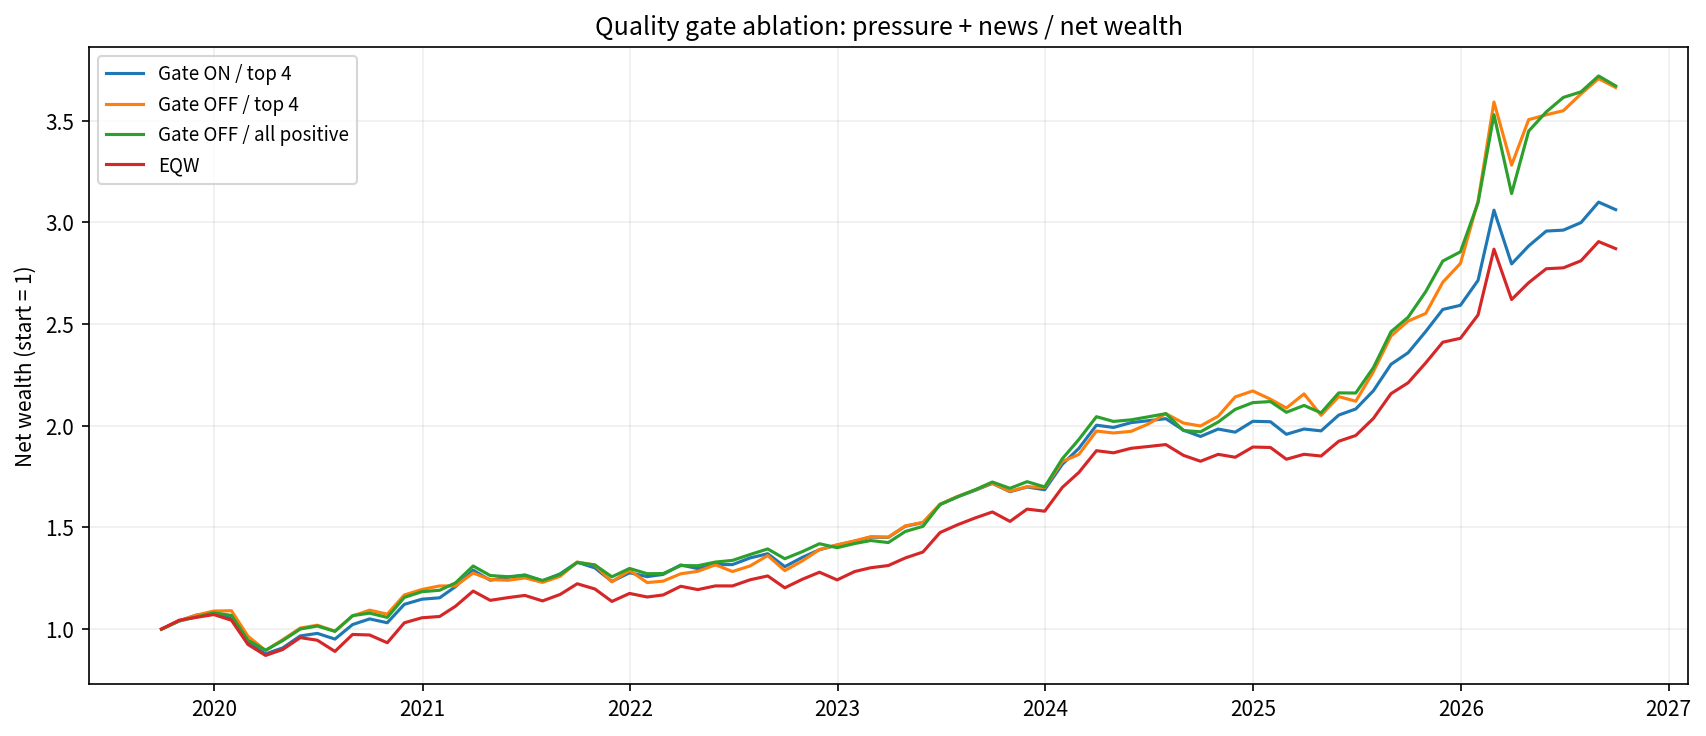

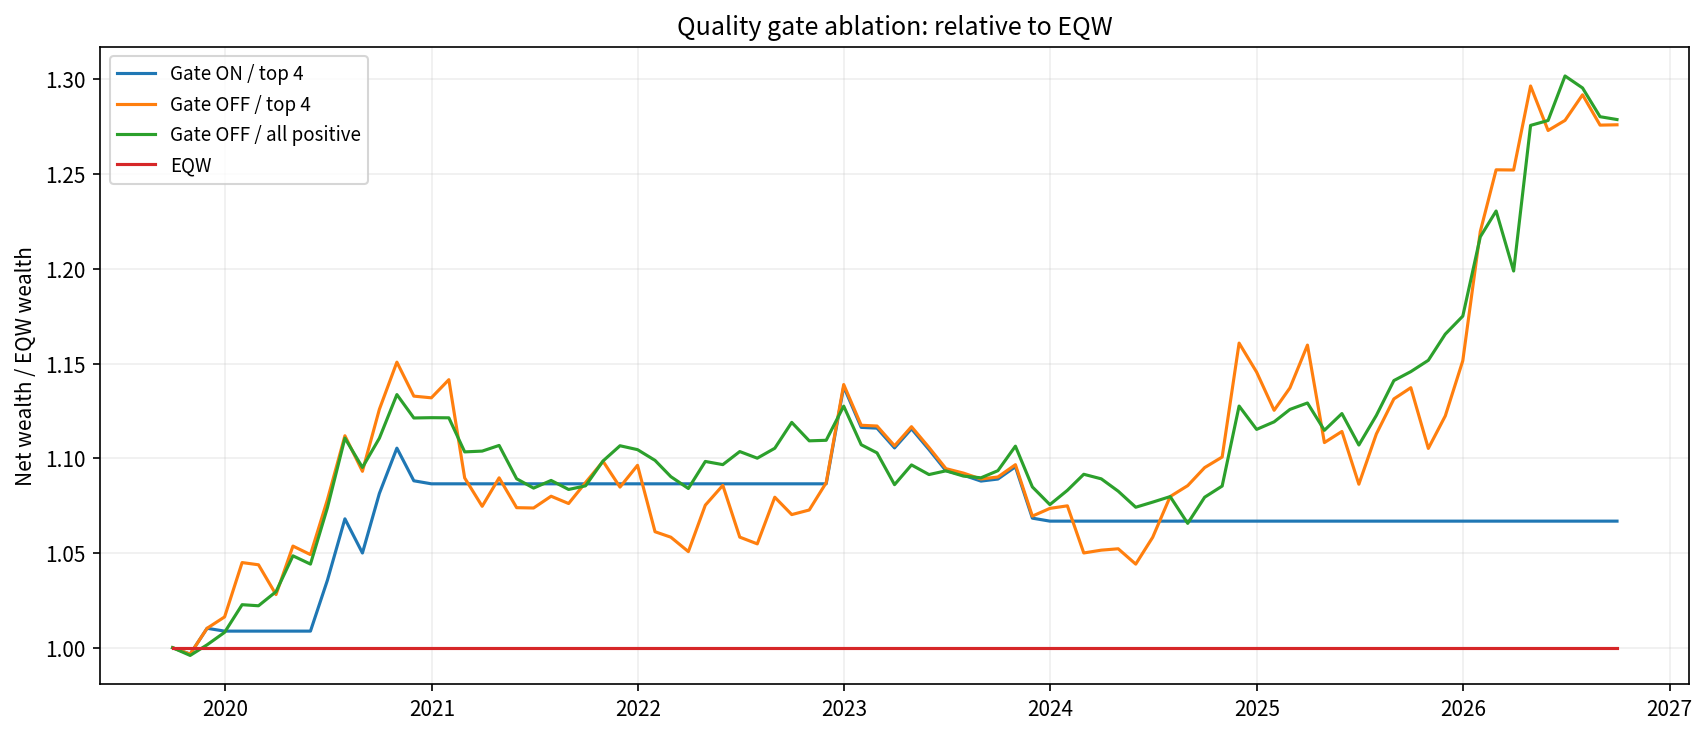

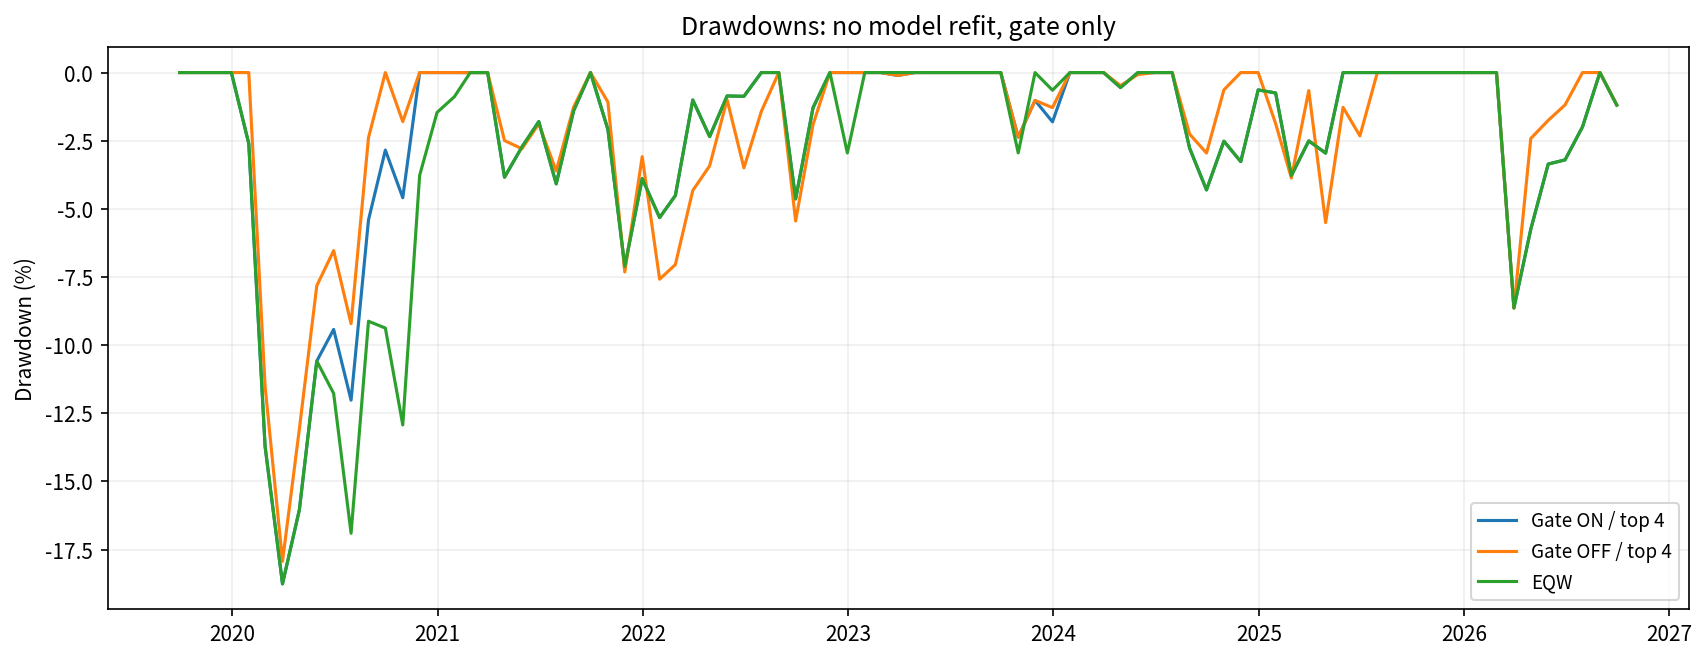

Quality-gate ablation report: /mnt/data/BB_PA_QualityGate_Ablation/outputs/runs/_inprogress_20261014T223551_112148/results/quality_gate_ablation/report.html


In [65]:
def ga_plot(fig,name):
    fig.tight_layout();fig.savefig(GA_FIG/name,dpi=150,bbox_inches="tight");plt.close(fig)
    display(DisplayImage(filename=str(GA_FIG/name)))
ga_curves={};ga_initial=pa2_common[0]-1
for ga_mode in GA_MODES:
    ga_r=ga_common_ledgers[("two_month_research",ga_mode)].query("strategy=='pressure_and_news'").set_index("month").net_return.reindex(pa2_common)
    ga_curves[ga_mode]=pd.concat([pd.Series([1.],index=pd.PeriodIndex([ga_initial],freq="M")),(1+ga_r).cumprod()])
ga_r=ga_common_ledgers[("two_month_research","gate_on_top4")].query("strategy=='EQW'").set_index("month").net_return.reindex(pa2_common)
ga_curves["EQW"]=pd.concat([pd.Series([1.],index=pd.PeriodIndex([ga_initial],freq="M")),(1+ga_r).cumprod()])
ga_wealth=pd.DataFrame(ga_curves);ga_relative=ga_wealth.div(ga_wealth.EQW,axis=0)
ga_save(ga_wealth,"net_wealth_primary.csv",index=True);ga_save(ga_relative,"relative_wealth_primary.csv",index=True)
ga_labels={"gate_on_top4":"Gate ON / top 4","gate_off_top4":"Gate OFF / top 4","gate_off_all_positive":"Gate OFF / all positive","EQW":"EQW"}
for ga_table,ga_image,ga_title,ga_ylabel in [
    (ga_wealth,"01_net_wealth.png","Quality gate ablation: pressure + news / net wealth","Net wealth (start = 1)"),
    (ga_relative,"02_relative_wealth.png","Quality gate ablation: relative to EQW","Net wealth / EQW wealth")]:
    ga_fig,ga_ax=plt.subplots(figsize=(11.5,5.0))
    for ga_col in ga_table:ga_ax.plot(ga_table.index.to_timestamp("M"),ga_table[ga_col],label=ga_labels[ga_col])
    ga_ax.set(title=ga_title,ylabel=ga_ylabel);ga_ax.grid(alpha=.2);ga_ax.legend(fontsize=9)
    ga_plot(ga_fig,ga_image)
ga_drawdowns=ga_wealth/ga_wealth.cummax()-1
ga_fig,ga_ax=plt.subplots(figsize=(11.5,4.5))
for ga_col in ["gate_on_top4","gate_off_top4","EQW"]:
    ga_ax.plot(ga_drawdowns.index.to_timestamp("M"),100*ga_drawdowns[ga_col],label=ga_labels[ga_col])
ga_ax.set(title="Drawdowns: no model refit, gate only",ylabel="Drawdown (%)");ga_ax.grid(alpha=.2);ga_ax.legend(fontsize=9)
ga_plot(ga_fig,"03_drawdowns.png")
ga_save(ga_drawdowns,"drawdowns_primary.csv",index=True)

def ga_display_performance(df):
    d=df[["scenario","mode","strategy","CAGR","geometric_relative_ann","ann_vol","tracking_error","IR","max_drawdown","annual_turnover_half_l1","active_months"]].copy()
    for c in ["CAGR","geometric_relative_ann","ann_vol","tracking_error","max_drawdown","annual_turnover_half_l1"]:d[c]*=100
    return d.rename(columns={"CAGR":"CAGR %","geometric_relative_ann":"対EQW 相対年率 %","ann_vol":"年率Vol %","tracking_error":"年率TE %","max_drawdown":"MaxDD %","annual_turnover_half_l1":"年間片道回転率 %"})
ga_primary_summary=ga_display_performance(ga_perf[(ga_perf.scenario=="two_month_research")&ga_perf.strategy.eq("pressure_and_news")])
ga_three_models=ga_display_performance(ga_perf[(ga_perf.scenario=="two_month_research")&ga_perf.strategy.isin(["pressure_only","news_only","pressure_and_news"])&ga_perf["mode"].isin(["gate_on_top4","gate_off_top4"])])
ga_episodes_view=ga_episode_table.query("strategy=='pressure_and_news'")[["start_month","end_month","n_months","gate_on_cumulative_net","gate_off_cumulative_net","gate_off_relative_to_EQW"]].copy()
for ga_c in ["gate_on_cumulative_net","gate_off_cumulative_net","gate_off_relative_to_EQW"]:ga_episodes_view[ga_c]*=100
ga_ci_view=ga_boot_table.query("strategy=='pressure_and_news'").copy()
for ga_c in ["estimate_geometric_relative_ann","bootstrap_95_low","bootstrap_95_high"]:ga_ci_view[ga_c]*=100
ga_latest=ga_decision_audit.query("strategy=='pressure_and_news'").tail(1)

def ga_mdtable(df):
    def f(x):
        if isinstance(x,(float,np.floating)):return "" if not np.isfinite(x) else f"{x:.4f}"
        return str(x).replace("|","/")
    return "\n".join(["| "+" | ".join(map(str,df.columns))+" |","| "+" | ".join(["---"]*len(df.columns))+" |"]+
        ["| "+" | ".join(f(x) for x in row)+" |" for row in df.itertuples(index=False,name=None)])
ga_report=f'''# BBレジーム品質ゲート：解除による投資結果の比較
実行日 {AS_OF_DATE.date()} / 共通期間 {pa2_common.min()}〜{pa2_common.max()} / {len(pa2_common)}か月。

## 結論を読む前の条件
変更したのは、主Top4比較ではBBのprefix_qualityによる選定停止条件だけ。
BB・マクロ圧力・学習標本・Ridge係数・予測値・日程・保有期間・費用は不変。
四半期末+2か月末に選定し、翌月から3か月同じ対象を保有、月次に同じウェイトへ復元。
正の「3か月EQW対比予測」を持つ上位4資産を各25%保有する。絶対リターンの正予測とは異なる。

## 主結果：pressure_and_news
{ga_mdtable(ga_primary_summary)}
百分率表示。片道回転率は年間0.5*L1売買額。相対年率はCAGR差ではなく資産倍率の対EQW比の年率。
quality gateを外しても、品質ラベル自体はlow/HOLDのまま保存している。
全正予測版は正予測の全資産を等ウェイトとする追加実験であり、純粋なゲート除去とは区別する。

## 3つのマクロ予測モデル
{ga_mdtable(ga_three_models)}
これらの予測・目的変数・学習条件は元版の値を再利用。成績を見て係数・閾値・TopNを最適化していない。

## 元の品質停止区間だけを見た累積実績（%）
{ga_mdtable(ga_episodes_view)}
各行は実際に連続する区間。費用は全期間の保有経路を引き継ぐ。離れた64か月をまとめて連続CAGRへ換算しない。
品質通過月でも前月保有が違えば切替費用だけは違うため、単に停止月のリターンを差し替えた比較ではない。

## 参考不確実性（相対年率%、paired 12か月ブロック）
{ga_mdtable(ga_ci_view[["comparison","estimate_geometric_relative_ann","bootstrap_95_low","bootstrap_95_high","bootstrap_reps"]])}
実現済み戦略リターンの条件付き再標本化。BB生成誤差・予測モデルの全再推定・選択バイアスを網羅しない。
同じ期間を既に複数の研究・仕様検討で使っており、新規独立ホールドアウトではない。

## 最新の研究上の計画
{ga_mdtable(ga_latest)}
未観測の将来保有月のリターンを補わない。これは取引承認・実運用推奨ではない。

## 公表確認を必須とする主方針は維持
公表カレンダー登録={len(PA2_RELEASE)}件。two_month_confirmedは未登録・遅延時にEQW。
quality_gate=Falseでも、公表確認・数値可用性・最低32学習期・有限な予測・価格欠損の条件は迂回しない。
研究版は従来から未登録日時を仮定しているので結果が出る。今回新たに公表制約を緩めたものではない。
速報ビンテージ、実際の発注・約定、指数の配当調整は未検証。全系統production_eligible=False。

## 出力と再実行
`performance_common_period.csv`、`decision_audit_gate_on_vs_off.csv`、`monthly_gate_effects.csv`、
`previously_blocked_episode_results.csv`、`transaction_cost_sensitivity.csv`、`net_wealth_primary.csv`、`relative_wealth_primary.csv`。
全処理は同じmain.ipynb。新層は23節、既存層はそのまま。追加検査{len(GA_TESTS)}件。
'''
(GA_DIR/"RESULTS_ja.md").write_text(ga_report,encoding="utf-8")
import base64 as _ga_b64,html as _ga_html

def ga_html_image(name,caption):
    s=_ga_b64.b64encode((GA_FIG/name).read_bytes()).decode()
    return f'<figure><figcaption>{_ga_html.escape(caption)}</figcaption><img src="data:image/png;base64,{s}" alt="{_ga_html.escape(caption)}"></figure>'
def ga_ht(d):return d.to_html(index=False,border=0,float_format=lambda x:f"{x:.4f}")
ga_css='body{max-width:1150px;margin:auto;padding:32px;font-family:-apple-system,BlinkMacSystemFont,"Segoe UI","Noto Sans JP",sans-serif;line-height:1.75;color:#203343}h1{font-size:31px}h2{font-size:23px;margin-top:30px}header{border-bottom:3px solid #203e57;padding-bottom:12px}.note{background:#f1f4f7;border-left:4px solid #203e57;padding:18px}table{display:block;max-width:100%;overflow:auto;border-collapse:collapse;font-size:12px}th,td{padding:8px 10px;border-bottom:1px solid #d8e0e5;white-space:nowrap;text-align:right}th{background:#edf2f6}img{width:100%;height:auto}figure{margin:24px 0}footer{border-top:2px solid #203e57;font-size:13px;margin-top:30px}'
ga_body=f'''<header><p>PA / QUALITY-GATE ABLATION / RESEARCH ONLY</p><h1>BBレジーム品質ゲート：ONとOFFの比較</h1><p>{pa2_common.min()}〜{pa2_common.max()} / {len(pa2_common)}か月 / 2か月待ち・3か月保有</p></header>
<section class="note"><p><strong>主比較は品質停止だけを除去。</strong>モデル・予測・Top4規則・日程・費用は固定。
low/HOLDを良好へ書き換えず、配分でだけ無視します。公表不可・学習不足を迂回しません。
全正予測版は保有数ルールも変える補助実験です。既存結果は別に残しています。</p></section>
<h2>主結果：pressure_and_news</h2>{ga_ht(ga_primary_summary)}
<p>百分率列は%表示。対EQW相対年率はCAGR差ではありません。回転率は年間0.5 L1売買額。</p>
{ga_html_image('01_net_wealth.png','費用控除後net wealth：各戦略自身の資産倍率')}
{ga_html_image('02_relative_wealth.png','費用控除後・EQW対比の相対wealth')}
<h2>各マクロ予測モデル</h2>{ga_ht(ga_three_models)}
<h2>従来はEQWだった区間</h2>{ga_ht(ga_episodes_view)}<p>累積リターンは%表示。区間の保有経路に基づく費用を維持。区間を架空に連続して年率化していません。</p>
{ga_html_image('03_drawdowns.png','初期資産1を含むピークからのドローダウン')}
<h2>参考区間推定</h2>{ga_ht(ga_ci_view[['comparison','estimate_geometric_relative_ann','bootstrap_95_low','bootstrap_95_high']])}
<p>12か月paired block、1999回。実現リターンに条件付きであり、新規ホールドアウトや全モデルの不確実性ではありません。</p>
<h2>最新の研究上の対象</h2>{ga_ht(ga_latest)}
<footer><p>公表カレンダー登録{len(PA2_RELEASE)}件。confirmed_onlyは未登録ならゲートを外してもEQW。研究版は元から未登録日時を仮定。
使用価格はユーザー提供指数、最新ビンテージと月末価格近似。公表当時の値・実約定・配当定義は未検証。production_eligible=False。</p>
<p>追加検査{len(GA_TESTS)}件。参照したBBやレジームの科学計算は変更せず、配分の停止規則だけを比較しました。</p></footer>'''
(GA_DIR/"report.html").write_text('<!doctype html><html lang="ja"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>BB品質ゲート除去比較</title><style>'+ga_css+'</style><body>'+ga_body+'</body></html>',encoding="utf-8")
ga_json({"primary_comparison":"two_month_research: gate_on_top4 vs gate_off_top4",
    "changed":"allocation quality check only; model quality metadata remains unchanged",
    "forecast_reestimated_by_ablation":False,"confirmed_release_gate_preserved":True,
    "source_start":str(pa2_common.min()),"source_end":str(pa2_common.max()),"n_months":len(pa2_common),
    "settings":GA_CFG,"n_checks":len(GA_TESTS),"production_eligible":False},"run_summary.json")
print("Quality-gate ablation report:",GA_DIR/"report.html")

<a id="inflation-robust-allocation"></a>
# 追加分析A．インフレ要因別の堅牢なマルチアセット配分

## A0．目的・既存分析との接続

**基準配分＋小さな常設防御＋要因別の追加防御**を作る。第15節のFT/PT NewsOnlyを継承し、
第20節で作成した四半期ごとのBBモデル版を読み取り専用で再利用する。既存第1–23節の結果は変更しない。
この追加節は第24節の出力確定直前にあり、通常の「すべて実行」で追加結果も同じrunへ保存される。

### 実行方法

1. このNotebookを元のプロジェクトフォルダに置き、元と同じ `inputs/` と環境を使う。
2. 下の `IR_CFG` と必要な入力欄を設定する。既定では、添付で使われていた日本16セクターと等金額基準で動く。
3. 新しいkernelでは通常どおり先頭から実行する。**既に元Notebookを実行した同じkernelなら、この追加節だけでも実行できる。**
4. 第15節までしか実行していない場合は最新の感応度・配分診断のみ。第20節の再帰版がなければ、過去バックテストを作らない。
5. 既に第24節まで完了したkernelで追加節だけ実行する場合、**第24節を再実行しない**。追加節が自身の結果を保存し、同じrunが最新版なら追加フォルダだけ反映する。

### 入力と計算の役割

| 入力 | 使用方法 |
|---|---|
| `dual_news_all` / `dual_history['gcpi']` | 第15節までの最新診断。Newsは各寄与の4期平均の4期差のまま |
| `CM_MODEL_CACHE` / `ET_MAPS[*]['calendar_pressure']` | 各四半期版のNews履歴を再利用。ETの相対β・予測リターンは流用しない |
| 月次の資産リターン | 総リターンの12か月β・成長β、共分散、翌月保有損益を新規計算 |
| BEI等の市場指標 | 公表時点を確認した3か月変化で、追加枠を0／5／10％に調整 |
| 実際の週次資産リターン | 任意。市場proxyへの週次WLS診断。月次データを週次へ補間しない |
| 個別株FF型因子 | 任意。元Newsに対する感応度を診断。L/S元本が未確認のまま資金配分へ混ぜない |

**今回の添付には、個別株FF型因子・BEI等の系列・新規マルチアセットの元CSVは含まれていない。**
これらは下の入力欄から追加できる。未接続なら状態を明示し、市場proxyによる追加量は0とする。
既存16セクターでの結果をマルチアセットでの実証結果とは呼ばない。

### 運用ルール

\[
w_t=(1-h_0-a_t)b+h_0 H_0+a_t H_{k_t},\qquad h_0=5\%,\quad a_t\in\{0,5,10\%\}.
\]

- `b` は基準配分。未設定なら入力資産の等金額（研究用の初期値）。
- 対象要因・防御候補は、利用可能なBB版の更新時に決める。energy / food / shortage / laborの4経路を使い、cost合計やFT/PT内訳を重複加算しない。
- 基準配分に負のβがあり、Newsが正の要因を最大2個選ぶ。News/過去SD×負のβは防御優先度であり、予測収益ではない。
- 防御候補は基準より感応度が有利な最大3資産の逆ボラ配分。最低2資産を確保し、短期資産の逆ボラには下限を置く。
- 総合インフレproxyと対象要因proxyがそれぞれ上向きかを確認し、追加量を0／5／10％へ。増額は月に一段階まで。対象要因が2つの場合は両方のproxyの確認を必要とする。
- 成長・信用proxyが悪化した月は、成長βの増加を許さない。TE・総ボラ・成長参加・両側ストレスの制約により追加量を縮小する。
- 常設枠も、候補またはリスク条件が成立しなければ実行できない。その理由は記録する。**既存の品質HOLDは、この層の自動停止条件にしない。**

数値は検証開始用の設定であり、論文の最適値ではない。名目のβを抑える分析で、実質購買力の完全な保全を保証するものではない。


## A1．設定と入力欄

新しい資産群を使う場合は、この追加節だけの入力を設定する。元の `ASSET_COLUMNS` を変えずに接続できる。

```python
# 例。列名は実際のCSVと一致させる。架空の価格・リターンは入れない。
IR_CFG['monthly_returns_csv'] = str(INPUT_DIR / 'multiasset_monthly.csv')
IR_CFG['monthly_input_kind'] = 'returns'
IR_CFG['evaluation_currency'] = 'JPY'
IR_CFG['return_basis'] = 'total_return'
IR_BASE_WEIGHTS_INPUT = {'Equity_TR_JPY': 0.60, 'Bond_TR_JPY': 0.40}
```

この例では、CSV中の他資産の基準ウェイトは0とし、防御候補に使う。**実際の基準配分は明示入力する。**
株式ロング側バスケットや投資可能ファンドは、通常の資産列として追加できる。

| 入力 | フォーマット |
|---|---|
| 月次資産 | `date,資産A,資産B,...`。ISO日付、月ごと1行。returnsは1％＝0.01、levelsなら正の配当込み指数水準 |
| 基準配分 | 資産名→非負ウェイトの辞書。合計1。明記しなかったCSV列は0 |
| 市場proxy | `date,available_at,series,value`。JST基準の実際の観測・利用可能日時。単位は系列内で統一 |
| 週次資産 | `date,資産A,...`。同じ週終点にそろえたW-FRI週次小数リターン。各市場の引け・利用可能時刻の整合を入力元で確認 |
| FF型因子 | `date,因子A,...`。月次小数損益率。ロング・ショート元本と形成時点は入力元で検証 |

`IR_PROXY_SPEC` のseries名を市場CSVと合わせる。例えば `bei` は差分、`credit` は差分の符号を反転して「正＝信用・景気改善」とする。
BEIや信用差は純粋な構造要因・GDPの観測値ではない。日本の要因に米国の指標を使用する場合も、対応関係を別途検証する。
入力をDataFrameで渡すこともできる。**月次・週次とも、欠測をゼロ収益で補完しない。**


In [ ]:
# 追加分析専用。元の CFG / assets / dual_main / CM_* / ET_* は変更しない。
import numpy as ir_np
import pandas as ir_pd
from pathlib import Path as ir_Path
import json as ir_json
import hashlib as ir_hashlib

IR_CFG = {
    'version': 'inflation_robust_allocation_v1',
    'factors': ['energy', 'food', 'shortage', 'labor'],
    'monthly_returns_csv': None,  # date,資産名...。Noneなら既存の16セクター。
    'monthly_input_kind': 'returns',  # 追加入力。returns=小数、levels=配当込み指数水準。
    'market_csv': None,  # date,available_at,series,value のlong形式。
    'weekly_returns_csv': None,  # date,資産名...。金曜終点の週次小数リターン。
    'factor_returns_csv': None,  # date,FF_energy,...。L/S因子の月次小数損益率（診断用）。
    'decision_start': '2011-06',
    'macro_release_lag_months': 3,
    'map_min_quarters': 24,
    'map_max_quarters': 80,
    'map_half_life_quarters': 20,
    'map_hac_lags': 8,
    'risk_lookback_months': 60,
    'risk_min_months': 24,
    'covariance_diagonal_weight': 0.25,
    'defense_top_n': 3,
    'defense_min_assets': 2,
    'defense_vol_floor_annual': 0.01,  # 逆volで短期・cashが極端なウェイトにならない下限。
    'common_weight': 0.05,
    'extra_grid': [0.0, 0.05, 0.10],
    'quarterly_extra_weight': 0.05,
    'maximum_target_factors': 2,
    'max_active_te_annual': 0.03,
    'max_vol_ratio': 1.05,
    'max_growth_change_pp': 0.50,
    'max_growth_increase_pp': 0.50,
    'stress_tolerance_pp': 0.50,
    'minimum_improvement_pp': 1e-8,
    'trade_cost_bps': 10.0,
    'execution_lag_months': 0,  # m月末決定→m+1月収益。月末価格による執行代理。
    'market_lookback_months': 3,
    'market_max_age_days': 45,
    'weekly_quote_max_age_days': 10,
    'weekly_max_weeks': 1040,
    'weekly_halflife_weeks': 260,
    'weekly_min_weeks': 208,
    'evaluation_currency': 'UNVERIFIED',  # 例 JPY。為替ヘッジ有無は資産を分ける。
    'return_basis': 'existing_index_dividend_status_unverified',
    'run_backtest': True,
    'write_outputs': True,
}

# DataFrameを直接渡す場合はこのセルを編集。CSVと同時指定はDataFrameを優先。
IR_ASSET_RETURNS_INPUT = None  # 月次wide、小数。設定すると既存資産とは別の独立ユニバース。
IR_BASE_WEIGHTS_INPUT = None  # 例 {'Equity_TR_JPY': .60, 'Bond_TR_JPY': .40}。合計1。
# Noneの基準配分は入力資産の等金額。実際の運用ウェイトを推測しない。
IR_MARKET_INPUT = None
IR_WEEKLY_RETURNS_INPUT = None
IR_FACTOR_RETURNS_INPUT = None
# 個別株L/S因子は診断用。資金を持つロング側バスケット/投資可能ファンドは
# IR_ASSET_RETURNS_INPUTへ通常資産として明示的に追加できる。
IR_BB_VINTAGES_INPUT = None  # 通常None。既存 CM_MODEL_CACHE を再利用。

IR_PROXY_SPEC = {
    'bei': {'role': 'inflation', 'transform': 'difference', 'direction': 1},
    'credit': {'role': 'growth', 'transform': 'difference', 'direction': -1},
    'energy_jpy': {'role': 'energy', 'transform': 'log', 'direction': 1},
    'food_jpy': {'role': 'food', 'transform': 'log', 'direction': 1},
    'shortage': {'role': 'shortage', 'transform': 'difference', 'direction': 1},
    'labor': {'role': 'labor', 'transform': 'difference', 'direction': 1},
}
IR_LABELS = {'energy': 'エネルギー', 'food': '食品', 'shortage': '供給不足',
             'labor': '労働需給・賃金'}


## A2．資産入力の検証

**入力**：専用DataFrame/CSV、または既存 `assets`。**出力**：元入力を変更しない月次リターン・基準配分・任意の市場/週次/因子系列。全資産を同じ評価通貨とリターン定義でそろえる。


In [ ]:
def ir_time(value):
    """時刻はJSTのnaiveへ統一。Periodは期間末。"""
    if isinstance(value, ir_pd.Period):
        return value.end_time
    t = ir_pd.Timestamp(value)
    if ir_pd.isna(t):
        raise ValueError('利用可能日時が空です')
    return t.tz_convert('Asia/Tokyo').tz_localize(None) if t.tzinfo is not None else t


def ir_read_input(frame, path, frequency='M', kind='returns'):
    """入力をコピーし、欠落月をNaNとして残す。暗黙のゼロ・forward fillなし。"""
    if frame is None and path is None:
        return None
    x = frame.copy(deep=True) if frame is not None else ir_pd.read_csv(path, encoding='utf-8-sig')
    if 'date' in x:
        dates = x.pop('date')
    else:
        dates = x.index
    if frequency == 'M':
        if isinstance(dates, ir_pd.PeriodIndex):
            ix = dates.asfreq('M')
        else:
            ix = ir_pd.PeriodIndex([ir_time(v) for v in dates], freq='M')
    else:
        ix = ir_pd.DatetimeIndex([ir_time(v).normalize() for v in dates])
        if not (ix.dayofweek == 4).all():
            raise ValueError('週次リターンは金曜終点で入力してください。月次や日次の自動転用はしません')
    x.index = ix
    if not x.index.is_unique or not x.columns.is_unique or x.empty:
        raise ValueError('資産入力は空でなく、日付・資産名が一意である必要があります')
    x = x.sort_index().apply(ir_pd.to_numeric, errors='raise')
    if ir_np.isinf(x.to_numpy()).any():
        raise ValueError('資産入力に無限大があります')
    # 欠落期間を飛ばしたリターン/12か月窓を作らない。
    full = (ir_pd.period_range(ix.min(), ix.max(), freq='M') if frequency == 'M'
            else ir_pd.date_range(ix.min(), ix.max(), freq='W-FRI'))
    x = x.reindex(full)
    x.index.name = 'month' if frequency == 'M' else 'date'
    if kind == 'levels':
        if ((x <= 0) & x.notna()).any().any():
            raise ValueError('指数水準は正値が必要です')
        x = x.div(x.shift(1)).sub(1)
    elif kind != 'returns':
        raise ValueError('monthly_input_kindはreturnsまたはlevels')
    if ((x <= -1) & x.notna()).any().any():
        raise ValueError('資産リターンは小数で入力し、-100%以下を含めないでください')
    return x


def ir_validate_base(value, columns):
    cols = ir_pd.Index(columns)
    if value is None:
        return ir_pd.Series(1 / len(cols), index=cols, name='base'), 'equal_weight_research_default'
    w = ir_pd.Series(value, dtype=float)
    if not w.index.is_unique or not w.index.isin(cols).all():
        raise ValueError('基準ウェイトの資産名が入力列と一致しません')
    w = w.reindex(cols, fill_value=0.0)
    if not ir_np.isfinite(w).all() or (w < 0).any() or not ir_np.isclose(w.sum(), 1.0, atol=1e-10):
        raise ValueError('基準ウェイトは有限・非負・合計1で明示してください')
    return w.rename('base'), 'provided_base_weights'


def ir_collect_inputs(env, cfg):
    ret = ir_read_input(env.get('IR_ASSET_RETURNS_INPUT'), cfg.get('monthly_returns_csv'),
                        kind=cfg['monthly_input_kind'])
    source = 'provided_independent_asset_universe'
    if ret is None:
        a = env.get('assets')
        if not isinstance(a, dict) or 'full_monthly' not in a:
            raise ValueError('第15節まで実行するか、追加節専用の資産リターンを指定してください')
        cols = list(env.get('current_assets', a.get('assets', [])))
        ret = a['full_monthly'][cols].copy(deep=True)
        if 'flags' in a:
            ret = ret.mask(a['flags'].reindex(index=ret.index, columns=cols).fillna(False))
        ret = ir_read_input(ret, None)
        source = 'existing_sector_universe_not_multiasset'
    end = env.get('LAST_CALENDAR_MONTH', ret.index.max())
    ret = ret.loc[:ir_pd.Period(end, freq='M')]
    if ret.empty:
        raise ValueError('完了した月の資産収益がありません')
    # 末尾の完全空行を分析時点としない。内部欠損は残して明示的に検査。
    observed = ret.notna().any(axis=1)
    if not observed.any():
        raise ValueError('資産収益が全て欠損しています')
    ret = ret.loc[:observed[observed].index.max()]
    base, base_source = ir_validate_base(env.get('IR_BASE_WEIGHTS_INPUT'), ret.columns)
    market = env.get('IR_MARKET_INPUT')
    if market is None and cfg.get('market_csv'):
        market = ir_pd.read_csv(cfg['market_csv'], encoding='utf-8-sig')
    market = (ir_pd.DataFrame(columns=['date', 'available_at', 'series', 'value'])
              if market is None else market.copy(deep=True))
    if not {'date', 'available_at', 'series', 'value'}.issubset(market.columns):
        raise ValueError('市場入力にはdate,available_at,series,valueが必要です')
    weekly = ir_read_input(env.get('IR_WEEKLY_RETURNS_INPUT'), cfg.get('weekly_returns_csv'), frequency='W')
    if weekly is not None:
        if not set(ret.columns).issubset(weekly.columns):
            raise ValueError('週次診断には月次の分析資産をすべて含む週次リターンが必要です')
        weekly = weekly.reindex(columns=ret.columns)
    factors = ir_read_input(env.get('IR_FACTOR_RETURNS_INPUT'), cfg.get('factor_returns_csv'))
    return {'returns': ret, 'base': base, 'market': market, 'weekly': weekly,
            'factor_returns': factors, 'source': source, 'base_source': base_source}


## A3．BBモデル版と利用可能日の接続

第20節の版を再推定せず再利用する。感応度はその版の推定終期までの情報で計算し、利用可能日以降に使う。元の公表カレンダーがあれば優先し、なければ元設定の3か月ラグ等を仮定する。**原統計の過去改定前の値は復元されないため、最新ビンテージによる研究バックテストである。**

第15節だけの場合、最新Newsを過去版に見せかけてバックテストしない。


In [ ]:
def ir_clean_snapshot(s, cfg):
    out = dict(s)
    q = ir_pd.Period(s['q'], freq='Q')
    x = s['macro'].copy(deep=True)
    if not isinstance(x.index, ir_pd.PeriodIndex):
        x.index = ir_pd.PeriodIndex(x.index, freq='Q')
    else:
        x.index = x.index.asfreq('Q')
    if not x.index.is_unique or (x.index > q).any():
        raise ValueError('BB版の四半期履歴に重複または推定終期より未来の行があります')
    required = ['n_' + k for k in cfg['factors']] + ['g']
    if not set(required).issubset(x):
        raise ValueError('BB版の列不足: ' + str(sorted(set(required) - set(x))))
    for col in required + [c for c in x if c.startswith('p_')]:
        x[col] = ir_pd.to_numeric(x[col], errors='raise')
    available = ir_time(s['available_at'])
    if available < q.end_time.normalize():
        raise ValueError('四半期完了前のBB版は実績として使用しません')
    out.update(q=q, macro=x.sort_index(), available_at=available,
               version=str(s.get('version', q)), release_basis=s.get('release_basis', 'provided'),
               quality=s.get('quality', 'not_recorded'), raw_vintage=s.get('raw_vintage', 'current_vintage_not_historical_releases'))
    return out


def ir_collect_snapshots(env, cfg):
    """CMの再帰版を読み取り専用で接続。全標本Newsを過去版として捏造しない。"""
    supplied = env.get('IR_BB_VINTAGES_INPUT')
    if supplied is not None:
        states = [ir_clean_snapshot(v, cfg) for v in supplied]
        mode = 'provided_macro_snapshots_verify_vintages'
    else:
        states = []
        cache = env.get('CM_MODEL_CACHE', {})
        maps = env.get('ET_MAPS', {})
        for v in sorted(cache.values(), key=lambda z: z['q']):
            q = ir_pd.Period(v['q'], freq='Q')
            existing = maps.get(v['version'], {})
            if 'calendar_pressure' in existing:
                x = existing['calendar_pressure'].copy(deep=True)
            else:
                fn, fp = env.get('cm_contribution_paths'), env.get('cm_pressure_from_paths')
                if not callable(fn) or not callable(fp):
                    continue
                paths = fn(v['monthly_blocks_at_fit'], v['compiled'], v['baseline'])
                p = fp(paths)
                x = p.loc[p.index.month % 3 == 0].copy()
                x.index = x.index.asfreq('Q')
            raw_q = env.get('Q')
            if raw_q is None or 'gdp_real_sa_annualized' not in raw_q:
                raise ValueError('CM版へ接続するためQの実質GDP系列が必要です')
            gdp = raw_q.loc[:q, 'gdp_real_sa_annualized']
            x['g'] = (100 * (gdp / gdp.shift(4) - 1)).diff(4).reindex(x.index)
            release = env.get('cm_release')
            if callable(release):
                at, basis = release('quarterly_model', q)
            else:
                at = (q.asfreq('M', 'end') + cfg['macro_release_lag_months']).end_time
                basis = 'assumed_lag'
            states.append(ir_clean_snapshot({'q': q, 'version': v['version'], 'macro': x.loc[:q],
                'available_at': at, 'release_basis': basis, 'quality': v.get('formal', {}).get('classification_quality', 'not_recorded'),
                'source': 'CM_prefix_reconstruction'}, cfg))
        mode = 'recursive_current_vintage_research' if states else 'latest_snapshot_only_no_historical_backtest'
        if not states:
            # 第15節までの実行でも現在の総リターン感応度を診断できる。
            nw = env.get('dual_news_all', env.get('dual_news_assets'))
            if nw is None:
                raise ValueError('第15節のdual_news_all/dual_news_assetsがありません')
            x = ir_pd.DataFrame(index=nw.index)
            for k in cfg['factors']:
                x['n_' + k] = nw['news_' + k]
            x['g'] = nw['news_growth']
            hd = env.get('dual_history', {}).get('gcpi')
            if hd is not None:
                for k in cfg['factors']:
                    x['p_' + k] = hd[k].rolling(4, min_periods=4).mean().reindex(x.index)
            q = x[cfg['factors'] if set(cfg['factors']).issubset(x) else ['n_' + k for k in cfg['factors']]].dropna().index.max()
            q = ir_pd.Period(q, freq='Q')
            at = (q.asfreq('M', 'end') + cfg['macro_release_lag_months']).end_time
            states = [ir_clean_snapshot({'q': q, 'version': 'FTPT_latest_' + str(q), 'macro': x.loc[:q],
                'available_at': at, 'release_basis': 'assumed_lag', 'source': 'section15_latest'}, cfg)]
    if not states:
        raise ValueError('利用できるBB版がありません')
    if len({s['version'] for s in states}) != len(states):
        raise ValueError('BB version名が重複しています')
    return sorted(states, key=lambda s: (s['q'].ordinal, s['available_at'])), mode


def ir_fingerprint(value):
    """pandas内部cacheではなく、科学的な内容を比較する。"""
    h = ir_hashlib.sha256()
    def visit(v):
        if isinstance(v, (ir_pd.DataFrame, ir_pd.Series)):
            h.update(ir_pd.util.hash_pandas_object(v, index=True).to_numpy().tobytes())
            h.update(repr((getattr(v, 'columns', None), v.dtypes)).encode())
        elif isinstance(v, ir_np.ndarray):
            h.update(repr((v.shape, v.dtype)).encode()); h.update(v.tobytes())
        elif isinstance(v, dict):
            for k in sorted(v, key=repr): visit(k); visit(v[k])
        elif isinstance(v, (list, tuple)):
            for z in v: visit(z)
        else:
            h.update(repr(v).encode())
    visit(value)
    return h.hexdigest()


## A4．総リターンのインフレ・成長感応度

各要因ごとに `12か月総リターン（pp） ~ 定数 + 要因News（pp） + 成長News（pp）` を推定する。
共通標本、最大80四半期、半減期20四半期のWLS、HAC8を使用する。第15節の`active_EQW`や偏相関を全体の損失βとして使わない。
成長係数も保存し、各Newsの標本SDを掛けた「1SD当たり12か月リターンpp」で比較する。

このWLSは本件向けの追加仕様で、第15節のOLS値と同一になることを目的としない。12か月βを12で割って翌月予測に変換しない。


In [ ]:
"""インフレ防御の計算部。外部通信や上流オブジェクトの変更は行わない。

cfg の主なキー（未指定時の値）:
factors=(energy, food, shortage, labor), map_min_quarters=24,
map_max_quarters=80, map_half_life_quarters=20, map_hac_lags=8,
risk_lookback_months=60, risk_min_months=24, covariance_diagonal_weight=.25,
defense_top_n=3, defense_min_assets=2, common_weight=.05,
extra_grid=(0,.05,.10), max_active_te_annual=.03, max_vol_ratio=1.05,
max_growth_change_pp=.5, max_growth_increase_pp=.5,
stress_tolerance_pp=.5, minimum_improvement_pp=1e-8.

月次入力は小数の総リターン、回帰の従属変数は12か月複利収益の％ポイント。
各インフレ要因と成長の二変量回帰を別々に行う。別回帰の係数を合算しない。
"""
import numpy as ir_np
import pandas as ir_pd


def ir_monthly_frame(frame):
    """月の欠落を明示的なNaNにし、欠損を埋めずに検査する。"""
    if not isinstance(frame, ir_pd.DataFrame) or frame.empty:
        raise ValueError("月次リターンは空でないDataFrameが必要です")
    out = frame.copy(deep=True)
    if isinstance(out.index, ir_pd.PeriodIndex):
        if out.index.freqstr != "M":
            raise ValueError("月次リターンのPeriodIndexはMを指定してください")
    else:
        out.index = ir_pd.PeriodIndex(ir_pd.to_datetime(out.index), freq="M")
    if not out.index.is_unique or not out.columns.is_unique:
        raise ValueError("月または資産名が重複しています")
    out = out.sort_index().apply(ir_pd.to_numeric, errors="raise")
    vals = out.to_numpy(dtype=float)
    if ir_np.isinf(vals).any() or ir_np.any(vals <= -1):
        raise ValueError("リターンは有限値またはNaN、かつ-100%より大きい値です")
    return out.reindex(ir_pd.period_range(out.index.min(), out.index.max(), freq="M", name="month"))


def ir_weights(value, columns):
    """非負・全額投資のウェイト。欠落列を勝手に補わない。"""
    out = ir_pd.Series(value, dtype=float).copy()
    if not out.index.is_unique or set(out.index) != set(columns):
        raise ValueError("ウェイトの資産名が投資対象と一致しません")
    out = out.reindex(columns)
    if not ir_np.isfinite(out).all() or out.min() < -1e-12:
        raise ValueError("ウェイトは有限・非負が必要です")
    if not ir_np.isclose(out.sum(), 1.0, atol=1e-8, rtol=0):
        raise ValueError("ウェイト合計は1です")
    return out.clip(lower=0) / out.clip(lower=0).sum()


def ir_fit_map(monthly_returns, macro, cutoff_q, cfg):
    """指定されたBBモデル版だけで総リターンβを再推定する。

    共通標本を全資産・全要因でそろえる。四半期が欠けた場合のHACは
    行番号でなく四半期ordinalの差で計算。標準化単位は共通標本の標本SD。
    説明変数の退化・標本不足時はNoneを返し、βを0で捏造しない。
    """
    factors = list(cfg.get("factors", ("energy", "food", "shortage", "labor")))
    if not factors or len(set(factors)) != len(factors):
        raise ValueError("factorsは重複のない非空リストです")
    q = ir_pd.Period(cutoff_q, freq="Q")
    ret = ir_monthly_frame(monthly_returns).loc[:q.asfreq("M", "end")]
    required = ["n_" + k for k in factors] + ["g"]
    x = macro.copy(deep=True)
    if not isinstance(x.index, ir_pd.PeriodIndex):
        x.index = ir_pd.PeriodIndex(x.index, freq="Q")
    if not x.index.is_unique or not x.index.freqstr.startswith("Q"):
        raise ValueError("macroは重複のない四半期PeriodIndexが必要です")
    if any(c not in x for c in required):
        raise ValueError("macroにn_各要因とgが必要です")
    x = x.sort_index().loc[:q]
    if x.empty or ret.empty:
        return None
    if ir_np.isinf(x[required].to_numpy(dtype=float)).any():
        raise ValueError("macroに無限大があります")
    max_q = int(cfg.get("map_max_quarters", 80))
    min_q = int(cfg.get("map_min_quarters", 24))
    half_life = float(cfg.get("map_half_life_quarters", 20))
    hac_lags = int(cfg.get("map_hac_lags", 8))
    if min_q < 8 or max_q < min_q or half_life <= 0 or hac_lags < 0:
        raise ValueError("回帰の標本数・半減期・HACラグを確認してください")
    r12 = 100 * ir_np.expm1(ir_np.log1p(ret).rolling(12, min_periods=12).sum())
    y = r12.loc[r12.index.month % 3 == 0].copy()
    y.index = y.index.asfreq("Q")
    ix = y.dropna().index.intersection(x[required].dropna().index)
    ix = ix[(ix >= q - max_q + 1) & (ix <= q)].sort_values()
    if len(ix) < min_q:
        return None
    yy = y.loc[ix].to_numpy(dtype=float)
    gg = x.loc[ix, "g"].to_numpy(dtype=float)
    gsd = float(ir_np.std(gg, ddof=1))
    if not ir_np.isfinite(gsd) or gsd <= 1e-10:
        return None
    ordinal = ir_np.asarray([p.ordinal for p in ix], dtype=int)
    weights = ir_np.exp2(-(ordinal.max() - ordinal) / half_life)
    sqrtw = ir_np.sqrt(weights)
    n = len(ix)
    rows, scales = [], {}
    B = ir_pd.DataFrame(index=ret.columns, columns=factors, dtype=float)
    G = B.copy()
    for factor in factors:
        xx = x.loc[ix, "n_" + factor].to_numpy(dtype=float)
        sd = float(ir_np.std(xx, ddof=1))
        design = ir_np.column_stack((ir_np.ones(n), xx, gg))
        if sd <= 1e-10 or ir_np.linalg.matrix_rank(design * sqrtw[:, None]) < 3:
            return None
        weighted_design = design * sqrtw[:, None]
        beta = ir_np.linalg.lstsq(weighted_design, yy * sqrtw[:, None], rcond=None)[0]
        residual = yy - design @ beta
        bread = ir_np.linalg.inv(design.T @ (weights[:, None] * design))
        scales[factor] = sd
        for j, asset in enumerate(ret.columns):
            score = design * (weights * residual[:, j])[:, None]
            meat = score.T @ score
            for lag in range(1, hac_lags + 1):
                # 欠落期を詰めず、同じ四半期間隔のペアだけを選ぶ。
                pairs = {v: i for i, v in enumerate(ordinal)}
                later = [i for i, v in enumerate(ordinal) if v - lag in pairs]
                earlier = [pairs[ordinal[i] - lag] for i in later]
                if later:
                    cross = score[later].T @ score[earlier]
                    meat += (1 - lag / (hac_lags + 1)) * (cross + cross.T)
            covariance = (n / (n - 3)) * bread @ meat @ bread
            se = ir_np.sqrt(ir_np.maximum(ir_np.diag(covariance), 0))
            B.loc[asset, factor] = beta[1, j] * sd
            G.loc[asset, factor] = beta[2, j] * gsd
            rows.append({
                "asset": asset, "factor": factor, "n": n,
                "sample_start": str(ix.min()), "sample_end": str(ix.max()), "fit_end": str(q),
                "effective_n": float(weights.sum() ** 2 / (weights @ weights)),
                "beta_news": float(beta[1, j]), "beta_growth": float(beta[2, j]),
                "beta_news_1sd_pp": float(B.loc[asset, factor]),
                "beta_growth_1sd_pp": float(G.loc[asset, factor]),
                "se_news_1sd_pp": float(se[1] * sd),
                "se_growth_1sd_pp": float(se[2] * gsd),
                "news_sd": sd, "growth_sd": gsd,
                "interpretation": "contemporaneous_total_return_beta_not_expected_return",
            })
    return {"q": q, "records": ir_pd.DataFrame(rows), "B": B, "G": G,
            "macro_latest": x.iloc[-1].copy(), "macro_latest_quarter": x.index[-1],
            "scales": ir_pd.Series(scales), "sample_end": ix.max(),
            "sample_start": ix.min(), "asset_order": list(ret.columns), "n": n}


## A5．防御候補とリスク制約

**入力**：基準ウェイト、版別β、判断月までの共分散。**出力**：常設/要因別防御、採用量、棄却理由。
既定の制約は年率TE3％、総ボラは基準の1.05倍以内、各回帰の成長β乖離0.5pp以内、
各要因についてインフレ+1SD/成長−1SDとインフレ−1SD/成長−1SDの悪化を0.5pp以内とする。
この数値は運用予算に応じて変更する。

**4つの別回帰のβを合算して一つの損失を作らない。** 負のβの平均は防御候補を採否する要約尺度であり、複合ショックの予測損益ではない。
制約が満たせなければ追加量を減らし、常設枠も不成立なら基準配分へ戻して理由を残す。


In [ ]:
def ir_covariance(monthly_returns, decision, cfg):
    """判断月までの月次収益だけから、年率共分散を推定する。"""
    decision = ir_pd.Period(decision, freq="M")
    window = int(cfg.get("risk_lookback_months", 60))
    minimum = int(cfg.get("risk_min_months", 24))
    shrink = float(cfg.get("covariance_diagonal_weight", .25))
    if minimum < 3 or window < minimum or not 0 <= shrink <= 1:
        raise ValueError("共分散の標本数・縮小率を確認してください")
    r = ir_monthly_frame(monthly_returns).loc[decision - window + 1:decision].dropna()
    if len(r) < minimum:
        return None
    sample = r.cov().to_numpy() * 12
    value = (1 - shrink) * sample + shrink * ir_np.diag(ir_np.diag(sample))
    value = (value + value.T) / 2
    out = ir_pd.DataFrame(value, index=r.columns, columns=r.columns)
    out.attrs.update(n_months=len(r), sample_end=str(r.index.max()), decision=str(decision))
    return out


def ir_defense(base, map_, cov, factor_weights, cfg):
    """感応度の有利な資産を少数選び、逆ボラで防御候補を作る。"""
    columns = map_["asset_order"]
    b = ir_weights(base, columns)
    f = ir_pd.Series(factor_weights, dtype=float)
    if not f.index.is_unique or not set(f.index).issubset(map_["B"].columns):
        raise ValueError("防御対象の要因名が不正です")
    if not ir_np.isfinite(f).all() or (f < 0).any():
        raise ValueError("要因ウェイトは非負・有限です")
    if f.sum() <= 0:
        return b.copy()
    f = f / f.sum()
    beta = map_["B"].loc[columns, f.index] @ f
    reference = float(b @ beta)
    vol = ir_pd.Series(ir_np.sqrt(ir_np.maximum(ir_np.diag(cov.loc[columns, columns]), 0)), index=columns)
    minimum = float(cfg.get("minimum_improvement_pp", 1e-8))
    floor = float(cfg.get('defense_vol_floor_annual', .01))
    if not ir_np.isfinite(floor) or floor <= 0:
        raise ValueError('逆ボラ用の年率ボラ下限は正値です')
    scaled_vol = vol.clip(lower=floor)
    valid = (beta > reference + minimum) & ir_np.isfinite(vol)
    score = beta / (100 * scaled_vol)
    selected = score.loc[valid].sort_values(ascending=False, kind="mergesort")
    selected = selected.index[:int(cfg.get("defense_top_n", 3))]
    if len(selected) < int(cfg.get("defense_min_assets", 2)):
        return b.copy()
    out = ir_pd.Series(0.0, index=columns)
    out.loc[selected] = 1 / scaled_vol.loc[selected]
    out = out / out.sum()
    out.attrs["selected_assets"] = list(selected)
    return out


def ir_risk_metrics(w, base, map_, cov):
    """共分散リスクと要因別の独立した2変量シナリオを返す。"""
    columns = map_["asset_order"]
    w, b = ir_weights(w, columns), ir_weights(base, columns)
    v = cov.loc[columns, columns].to_numpy(dtype=float)
    if not ir_np.isfinite(v).all():
        raise ValueError("共分散に欠損があります")
    vol = lambda a: float(ir_np.sqrt(max(float(a @ v @ a), 0)))
    bi, bg = w @ map_["B"], w @ map_["G"]
    bbi, bbg = b @ map_["B"], b @ map_["G"]
    out = {"te_annual": vol((w - b).to_numpy()),
           "vol_annual": vol(w.to_numpy()), "base_vol_annual": vol(b.to_numpy()),
           "max_growth_change_pp": float((bg - bbg).abs().max()),
           "max_growth_increase_pp": float((bg - bbg).max()),
           "worst_stagflation_change_pp": float(((bi - bg) - (bbi - bbg)).min()),
           "worst_disinflation_change_pp": float(((-bi - bg) - (-bbi - bbg)).min()),
           "negative_vulnerability_pp": float((-bi).clip(lower=0).mean()),
           "base_negative_vulnerability_pp": float((-bbi).clip(lower=0).mean())}
    out["vulnerability_improvement_pp"] = out["base_negative_vulnerability_pp"] - out["negative_vulnerability_pp"]
    for f in map_["B"].columns:
        for prefix, series in [("beta_news", bi), ("base_beta_news", bbi),
                               ("beta_growth", bg), ("base_beta_growth", bbg),
                               ("stagflation", bi - bg), ("base_stagflation", bbi - bbg),
                               ("disinflation", -bi - bg), ("base_disinflation", -bbi - bbg)]:
            out[prefix + "_" + f + "_pp"] = float(series[f])
    return out


def ir_constrain(base, common, defense, map_, cov, extra_target, target_factors, cfg):
    """追加量を離散的に縮小し、満たせないリスク条件を明示する。

    常設枠でもリスク条件が不成立なら基準配分へ戻す。これは品質HOLDの
    自動継承ではなく、投資対象の不足やリスク制約による実行不能である。
    """
    columns = map_["asset_order"]
    b, hc, hd = [ir_weights(v, columns) for v in (base, common, defense)]
    requested_common = float(cfg.get("common_weight", .05))
    grid = sorted(set(float(x) for x in cfg.get("extra_grid", (0, .05, .10))) | {0.0}, reverse=True)
    extra_target = float(extra_target)
    targets = list(target_factors)
    if not set(targets).issubset(map_["B"].columns):
        raise ValueError("防御対象要因が感応度表にありません")
    if not ir_np.isfinite(extra_target) or extra_target < 0 or requested_common < 0 or min(grid) < 0:
        raise ValueError("防御量は非負・有限値です")
    if requested_common + max(grid + [extra_target]) > 1 + 1e-12:
        raise ValueError("防御枠の合計が100%を超えます")
    common_weight = 0.0 if ir_np.allclose(hc, b, atol=1e-12) else requested_common
    effective_target = 0.0 if ir_np.allclose(hd, b, atol=1e-12) or not targets else extra_target
    candidates = [x for x in grid if x <= effective_target + 1e-12]
    rejected = []
    minimum = float(cfg.get("minimum_improvement_pp", 1e-8))
    for extra in candidates:
        w = (1 - common_weight - extra) * b + common_weight * hc + extra * hd
        risk = ir_risk_metrics(w, b, map_, cov)
        reasons = []
        if risk["te_annual"] > float(cfg.get("max_active_te_annual", .03)) + 1e-12:
            reasons.append("tracking_error")
        if risk["vol_annual"] > risk["base_vol_annual"] * float(cfg.get("max_vol_ratio", 1.05)) + 1e-12:
            reasons.append("total_volatility")
        if risk["max_growth_change_pp"] > float(cfg.get("max_growth_change_pp", .5)) + 1e-10:
            reasons.append("growth_participation")
        if risk["max_growth_increase_pp"] > float(cfg.get("max_growth_increase_pp", .5)) + 1e-10:
            reasons.append("growth_increase")
        stress_limit = float(cfg.get("stress_tolerance_pp", .5))
        if risk["worst_stagflation_change_pp"] < -stress_limit - 1e-10:
            reasons.append("stagflation_stress")
        if risk["worst_disinflation_change_pp"] < -stress_limit - 1e-10:
            reasons.append("disinflation_stress")
        if common_weight + extra > 1e-12 and risk["vulnerability_improvement_pp"] < minimum:
            reasons.append("no_inflation_vulnerability_improvement")
        if extra > 1e-12:
            improvements = [risk["beta_news_" + f + "_pp"] - risk["base_beta_news_" + f + "_pp"] for f in targets]
            if min(improvements) < -1e-10 or ir_np.mean(improvements) < minimum:
                reasons.append("target_factor_not_improved")
        if reasons:
            rejected.append("extra=" + str(extra) + ":" + ",".join(reasons))
            continue
        if common_weight + extra <= 1e-12:
            reason = "base_only_no_defense_candidate"
        elif extra <= 1e-12:
            reason = "common_only" if not rejected else "common_only_after_risk_reduction"
        else:
            reason = "accepted" if extra >= extra_target - 1e-12 else "reduced_extra_for_risk"
        risk.update(common_weight_applied=common_weight, extra_weight_applied=extra,
                    extra_requested=extra_target, reason=reason, rejected_candidates="; ".join(rejected))
        return w, risk
    risk = ir_risk_metrics(b, b, map_, cov)
    risk.update(common_weight_applied=0.0, extra_weight_applied=0.0,
                extra_requested=extra_target, reason="base_only_no_feasible_defense",
                rejected_candidates="; ".join(rejected))
    return b.copy(), risk


## A6．保有・売買費用の会計

判断月mの目標を翌月m+1から適用する。月次価格しかないため、月末価格で約定できたとする**執行代理**であり、営業日1–2日の遅れを再現した結果ではない。
`execution_lag_months=1`なら追加で1か月待つ。初回は基準配分を保有済みとし、各戦略とも同じ出発点にそろえる。

前月リターンでドリフトした保有比率から売買量を計算し、費用率は `sum(abs(target - pretrade)) × 10bps`。
費用控除後リターンは `(1-cost)×(1+gross)-1`。基準配分にも月次リバランス費用を適用する。
保有資産の内部欠測は停止・明示し、未保有資産の欠測を損益へ加えない。


In [ ]:
def ir_ledger(monthly_returns, target_weights, base, cost_bps=10, execution_lag_months=0):
    """月末決定→翌月保有の会計。営業日ラグを再現するモデルではない。

    cost_bpsは売買それぞれの金額に対する片道費用。費用率=L1売買額×bps/1e4。
    費用を先に差し引き、残額をtarget比率で保有する通常のNAV控除近似。
    初回は基準配分を保有済みと仮定し、そこからの変更費用だけを課す。
    対応する保有月が収益入力の末尾より先の決定は、損益に含めない。
    入力は完了した月次収益に限る。途中の保有資産欠損は例外にする。
    """
    r = ir_monthly_frame(monthly_returns)
    b = ir_weights(base, r.columns)
    if not ir_np.isfinite(cost_bps) or cost_bps < 0:
        raise ValueError("片道費用は非負・有限です")
    if int(execution_lag_months) != execution_lag_months or execution_lag_months < 0:
        raise ValueError("実行ラグは非負の整数月です")
    targets = target_weights.copy(deep=True)
    if not isinstance(targets.index, ir_pd.PeriodIndex):
        targets.index = ir_pd.PeriodIndex(targets.index, freq="M")
    if targets.index.freqstr != "M" or not targets.index.is_unique:
        raise ValueError("判断月は重複のない月次PeriodIndexです")
    if set(targets.columns) != set(r.columns):
        raise ValueError("target_weightsの列が資産と一致しません")
    targets = targets.sort_index().reindex(columns=r.columns)
    for decision in targets.index:
        targets.loc[decision] = ir_weights(targets.loc[decision], r.columns)
    empty = {"ledger": ir_pd.DataFrame(), "held_weights": ir_pd.DataFrame(columns=r.columns),
             "pretrade_weights": ir_pd.DataFrame(columns=r.columns), "end_weights": ir_pd.DataFrame(columns=r.columns)}
    if targets.empty:
        return empty
    lag = int(execution_lag_months)
    effective = {d + 1 + lag: d for d in targets.index}
    start = max(r.index.min(), min(effective))
    if start > r.index.max():
        return empty
    # 全列NaNの末尾は未完了として除外。内部の空白月はこの処理で消えない。
    nonempty = r.dropna(how="all")
    if nonempty.empty or start > nonempty.index.max():
        return empty
    months = ir_pd.period_range(start, nonempty.index.max(), freq="M", name="month")
    pre = b.copy()
    wealth = gross_wealth = 1.0
    rows, held, before, ends = [], [], [], []
    last_decision = None
    for month in months:
        before.append(pre.copy().rename(month))
        decision = effective.get(month)
        if decision is not None:
            target = targets.loc[decision].copy()
            last_decision = decision
        else:
            target = pre.copy()
        traded = float((target - pre).abs().sum())
        fee = float(cost_bps) / 10000 * traded
        if fee >= 1:
            raise ValueError("取引費用が純資産以上です")
        rr = r.loc[month]
        invested = target > 1e-12
        if not ir_np.isfinite(rr.loc[invested].to_numpy(dtype=float)).all():
            missing = list(rr.index[invested & rr.isna()])
            raise ValueError(f"保有資産リターン欠損: {month}: {missing}")
        gross = float(target.loc[invested] @ rr.loc[invested])
        net = (1 - fee) * (1 + gross) - 1
        old_wealth = wealth
        wealth *= 1 + net
        gross_wealth *= 1 + gross
        drift = target * (1 + rr.fillna(0)) / (1 + gross)
        pre = ir_weights(drift, r.columns)
        held.append(target.rename(month))
        ends.append(pre.copy().rename(month))
        rows.append({"month": month, "decision_month": last_decision,
                     "rebalanced": decision is not None, "gross_return": gross,
                     "net_return": net, "cost_fraction": fee,
                     "cost_amount_initial_nav": old_wealth * fee,
                     "traded_notional": traded, "turnover_one_way": traded / 2,
                     "net_wealth": wealth, "gross_wealth": gross_wealth})
    ledger = ir_pd.DataFrame(rows).set_index("month")
    ledger.attrs["initial_holding"] = "base_portfolio_already_held"
    ledger.attrs["execution_assumption"] = "month_boundary_price_proxy_not_business_day_execution"
    return {"ledger": ledger, "held_weights": ir_pd.DataFrame(held),
            "pretrade_weights": ir_pd.DataFrame(before), "end_weights": ir_pd.DataFrame(ends)}


## A7．公表済み市場proxyで追加量を確認

利用可能日以降の値だけを用い、3か月前との変化を計算する。改定系列は判断時点までに既知の版だけを使う。現在値と比較値の両方に鮮度制限を適用し、欠測を四半期Newsで代用しない。


In [ ]:
import numpy as np
import pandas as pd


def ir_market_time(value):
    """比較用日時。naive は日本時間、月Periodは月末の終了時刻として扱う。"""
    if isinstance(value, pd.Period):
        value = value.end_time
    t = pd.Timestamp(value)
    if pd.isna(t):
        raise ValueError("市場データの日時は空欄にできません")
    return t.tz_convert("Asia/Tokyo").tz_localize(None) if t.tzinfo is not None else t


def ir_market_validate_spec(spec):
    """同じ役割を複数の系列で暗黙に平均しない。単位は入力系列の単位を保持。"""
    if not isinstance(spec, dict):
        raise TypeError("market_spec は series -> 設定 の辞書です")
    parsed = {}
    roles = set()
    for series, entry in spec.items():
        if not isinstance(series, str) or not series.strip() or not isinstance(entry, dict):
            raise ValueError("市場系列名と設定辞書を確認してください")
        role = entry.get("role")
        transform = entry.get("transform", "difference")
        direction = entry.get("direction", 1)
        if not isinstance(role, str) or not role.strip() or role in roles:
            raise ValueError("市場proxyは一つのroleにつき一系列を指定してください")
        if transform not in ("difference", "log") or direction not in (-1, 1):
            raise ValueError("transform は difference/log、direction は +1/-1 です")
        parsed[series] = dict(role=role, transform=transform, direction=int(direction))
        roles.add(role)
    return parsed


def ir_market_prepare(market, spec):
    """改定履歴を落とさず検査。最新版の選択は各判断時点で行う。"""
    cols = ["date", "available_at", "series", "value"]
    if market is None or (isinstance(market, pd.DataFrame) and market.empty):
        return pd.DataFrame(columns=cols)
    if not isinstance(market, pd.DataFrame) or not set(cols).issubset(market.columns):
        raise ValueError("市場入力には date, available_at, series, value が必要です")
    d = market[cols].copy()
    if d["series"].isna().any() or not d["series"].map(lambda x: isinstance(x, str) and bool(x.strip())).all():
        raise ValueError("市場系列名に空欄があります")
    d["date"] = d["date"].map(ir_market_time)
    d["available_at"] = d["available_at"].map(ir_market_time)
    d["value"] = pd.to_numeric(d["value"], errors="raise").astype(float)
    if not np.isfinite(d["value"].to_numpy()).all():
        raise ValueError("市場valueは有限の数値で指定してください。欠測は行を省略します")
    if (d["available_at"] < d["date"]).any():
        raise ValueError("市場系列のavailable_atを観測日時より前には設定できません")
    if d.duplicated(["series", "date", "available_at"]).any():
        raise ValueError("同一系列・観測日時・公表日時の重複は改定順を識別できません")
    for series, entry in spec.items():
        if entry["transform"] == "log" and (d.loc[d["series"].eq(series), "value"] <= 0).any():
            raise ValueError("log変換する市場系列の値は正値にしてください: " + series)
    return d.sort_values(["series", "date", "available_at"], kind="stable").reset_index(drop=True)


def ir_market_pick(series_frame, known_at, observed_before=None):
    """既知の改定だけを使い、指定観測日時以前の最新観測を返す。"""
    obs = known_at if observed_before is None else min(known_at, observed_before)
    d = series_frame.loc[(series_frame["date"] <= obs) & (series_frame["available_at"] <= known_at)]
    if d.empty:
        return None
    # 同じdateは、判断時点までに公表された最後の版を選択する。
    d = d.sort_values(["date", "available_at"], kind="stable").drop_duplicates("date", keep="last")
    return d.iloc[-1]


def ir_market_change(current, anchor, entry):
    change = (float(current) - float(anchor)) if entry["transform"] == "difference" else np.log(float(current) / float(anchor))
    return float(entry["direction"] * change)


def ir_market_signals(market, decision, spec, cfg):
    """公表済み市場値の指定月数変化（既定3か月）。四半期BB Newsで欠測を埋めない。"""
    parsed = ir_market_validate_spec(spec)
    d = ir_market_prepare(market, parsed)
    t = ir_market_time(decision)
    lookback = cfg.get("market_lookback_months", 3)
    if isinstance(lookback, (bool, np.bool_)) or not isinstance(lookback, (int, np.integer)) or lookback < 1:
        raise ValueError("market_lookback_months は正の整数で指定してください")
    lookback = int(lookback)
    # 月末判断では参照月も月末とし、月の日数差で月末観測を落とさない。
    anchor_at = t - (pd.offsets.MonthEnd(lookback) if t.is_month_end else pd.DateOffset(months=lookback))
    age_limit = float(cfg.get("market_max_age_days", 45))
    if not np.isfinite(age_limit) or age_limit < 0:
        raise ValueError("market_max_age_days は非負です")
    result, audit = {}, []
    for series, entry in parsed.items():
        frame = d.loc[d["series"].eq(series)]
        now = ir_market_pick(frame, t)
        old = ir_market_pick(frame, t, anchor_at)
        rec = dict(role=entry["role"], series=series, decision_at=t, anchor_target_at=anchor_at,
                   value=np.nan, up=None, status="missing_current", source_date=pd.NaT,
                   available_at=pd.NaT, anchor_source_date=pd.NaT, anchor_available_at=pd.NaT,
                   current_age_days=np.nan, anchor_age_days=np.nan,
                   transform=entry["transform"], direction=entry["direction"])
        if now is not None:
            rec.update(source_date=now["date"], available_at=now["available_at"],
                       current_age_days=(t - now["date"]).total_seconds() / 86400)
        if old is not None:
            rec.update(anchor_source_date=old["date"], anchor_available_at=old["available_at"],
                       anchor_age_days=(anchor_at - old["date"]).total_seconds() / 86400)
        if now is None:
            pass
        elif rec["current_age_days"] > age_limit:
            rec["status"] = "stale_current"
        elif old is None:
            rec["status"] = "missing_anchor"
        elif rec["anchor_age_days"] > age_limit:
            rec["status"] = "stale_anchor"
        else:
            rec["value"] = ir_market_change(now["value"], old["value"], entry)
            rec["up"] = bool(rec["value"] > 0)
            rec["status"] = "ok"
        result[entry["role"]] = {k: rec[k] for k in ["value", "up", "status", "source_date", "available_at"]}
        audit.append(rec)
    table = pd.DataFrame(audit)
    table.attrs["status"] = "unconfigured" if not parsed else ("no_market_input" if d.empty else "evaluated")
    table.attrs["interpretation"] = "公表済みproxyの変化。成長roleの正は信用・景気環境の改善。因果効果・翌月予測ではない"
    return result, table


## A8．任意：市場proxyへの週次WLS

実際の週次リターンと市場系列がある場合だけ実行する。最大1040週、半減期260週、最低208週。市場リターンを控除しない2変量WLSで、インフレ・信用景気proxyに対するポートフォリオ全体の関連を診断する。

**この初期実装では週次βは独立した診断で、配分額の制約に直接投入しない。** 配分には四半期BB感応度と月次proxyの確認を使う。週次収益は同一の週終点にそろえ、入力ラベルの金曜日終了後に既知とする。月次入力しかなければ推定しない。


In [ ]:
def ir_weekly_market_map(weekly_returns, market, decision, spec, cfg):
    """実際の週次リターンだけを用いる2変量WLS。各週の公表時点を再現する。"""
    columns = ["asset", "proxy_role", "beta_per_unit", "beta_per_1sd_pp", "n", "start", "end", "frequency", "status"]
    out = pd.DataFrame(columns=columns)
    out.attrs.update(status="not_run", frequency="weekly", equity_market_control=False,
                     return_unit="percentage_point", input_return_unit="decimal",
                     horizon="one_week", standardization="unweighted sample SD within common estimation sample",
                     interpretation="同時週次の関連。因果効果・BB構造要因beta・将来リターン予測ではない",
                     return_availability="W-FRI日付ラベルの週次リターンを金曜日終了後に既知とする")
    parsed = ir_market_validate_spec(spec)
    d = ir_market_prepare(market, parsed)
    t = ir_market_time(decision)
    if weekly_returns is None or (isinstance(weekly_returns, pd.DataFrame) and weekly_returns.empty):
        out.attrs["status"] = "weekly_returns_not_provided"
        return out
    if not isinstance(weekly_returns, pd.DataFrame) or not isinstance(weekly_returns.index, pd.DatetimeIndex):
        raise ValueError("週次推定にはDatetimeIndexを持つ実際のW-FRIリターンを指定します。月次データは使用しません")
    ret = weekly_returns.copy()
    if ret.columns.has_duplicates or ret.index.has_duplicates:
        raise ValueError("週次リターンの資産名・日付は一意にしてください")
    ix = pd.DatetimeIndex([ir_market_time(x) for x in ret.index]).normalize()
    if ix.has_duplicates or (ix.dayofweek != 4).any():
        raise ValueError("週次リターンは金曜日のW-FRI日付ラベルが必要です。日次・月次を自動集計しません")
    ret.index = ix
    ret = ret.sort_index().apply(pd.to_numeric, errors="raise")
    if np.isinf(ret.to_numpy(float)).any():
        raise ValueError("週次リターンに無限大があります")
    if len(ret) > 1 and np.median(np.diff(ret.index.asi8)) > pd.Timedelta(days=7).value:
        raise ValueError("週次頻度を確認できません。月次・隔週のリターンを週次として扱いません")
    role_series = {v["role"]: s for s, v in parsed.items()}
    if not {"inflation", "growth"}.issubset(role_series):
        out.attrs["status"] = "inflation_or_growth_proxy_not_configured"
        return out
    if d.empty:
        out.attrs["status"] = "no_market_input"
        return out
    max_weeks = int(cfg.get("weekly_max_weeks", 1040))
    min_weeks = int(cfg.get("weekly_min_weeks", 208))
    half_life = float(cfg.get("weekly_halflife_weeks", 260))
    quote_max_age = float(cfg.get("weekly_quote_max_age_days", 10))
    if min_weeks < 4 or max_weeks < min_weeks or not np.isfinite(half_life) or half_life <= 0 or not np.isfinite(quote_max_age) or quote_max_age < 0:
        raise ValueError("週次WLSの最少数・最大期間・半減期・quote鮮度の設定が不正です")
    # 金曜日の途中の判断では、その週全体のリターンはまだ使えない。
    cuts = ret.index + pd.Timedelta(days=1) - pd.Timedelta(nanoseconds=1)
    ret = ret.loc[(cuts <= t) & (ret.index >= t.normalize() - pd.Timedelta(weeks=max_weeks))].tail(max_weeks)
    if ret.empty:
        out.attrs["status"] = "no_completed_week_before_decision"
        return out
    roles = ["inflation", "growth"]
    xs = pd.DataFrame(index=ret.index, columns=roles, dtype=float)
    quote_pairs_ok = 0
    for role in roles:
        series = role_series[role]
        frame = d.loc[d["series"].eq(series)]
        entry = parsed[series]
        for week in ret.index:
            end = week + pd.Timedelta(days=1) - pd.Timedelta(nanoseconds=1)
            previous_end = end - pd.Timedelta(days=7)
            now = ir_market_pick(frame, end)
            old = ir_market_pick(frame, previous_end)
            good = (now is not None and old is not None and
                    end - now["date"] <= pd.Timedelta(days=quote_max_age) and
                    previous_end - old["date"] <= pd.Timedelta(days=quote_max_age))
            if good:
                xs.loc[week, role] = ir_market_change(now["value"], old["value"], entry)
                quote_pairs_ok += 1
    # 全資産を同一標本・同一WLS重みで推定し、配分betaの加法性を保つ。
    common = xs.notna().all(axis=1) & ret.notna().all(axis=1)
    x, y = xs.loc[common], ret.loc[common] * 100.0
    out.attrs.update(n_common_weeks=len(x), min_weeks=min_weeks, max_weeks=max_weeks,
                     halflife_weeks=half_life, quote_max_age_days=quote_max_age,
                     quote_missing_count=int((~xs.notna().all(axis=1)).sum()),
                     quote_pairs_ok=quote_pairs_ok, common_sample_all_assets=True,
                     vintage_policy="each week uses its own publication cutoff; later revisions never rewrite past X")
    if len(x) < min_weeks:
        out.attrs["status"] = "insufficient_common_weekly_history"
        return out
    mean, sd = x.mean().to_numpy(), x.std(ddof=1).to_numpy()
    if not np.isfinite(sd).all() or (sd < 1e-12).any():
        out.attrs["status"] = "constant_or_near_constant_proxy"
        return out
    z = (x.to_numpy() - mean) / sd
    design = np.column_stack([np.ones(len(z)), z])
    if np.linalg.matrix_rank(design) < 3:
        out.attrs["status"] = "collinear_market_proxies"
        return out
    age_weeks = np.asarray((x.index[-1] - x.index) / pd.Timedelta(weeks=1), dtype=float)
    sqrt_weight = np.sqrt(np.exp(-np.log(2) * age_weeks / half_life))
    coef = np.linalg.lstsq(design * sqrt_weight[:, None], y.to_numpy() * sqrt_weight[:, None], rcond=None)[0]
    rows = []
    for j, asset in enumerate(y.columns):
        for k, role in enumerate(roles):
            rows.append(dict(asset=asset, proxy_role=role, beta_per_unit=float(coef[k + 1, j] / sd[k]),
                             beta_per_1sd_pp=float(coef[k + 1, j]), n=len(x), start=x.index[0], end=x.index[-1],
                             frequency="weekly", status="ok"))
    fitted = pd.DataFrame(rows, columns=columns)
    fitted.attrs.update(out.attrs)
    fitted.attrs["status"] = "ok"
    fitted.attrs["series_by_role"] = {r: role_series[r] for r in roles}
    fitted.attrs["fit_method"] = "exponentially_weighted_least_squares"
    return fitted


## A9．四半期の防御対象と月次の追加量

要因の正のNewsと基準の負のβから対象を選ぶ。総合proxy/対象proxyの上向き確認数で追加枠を設定し、成長・信用環境の悪化時には成長βの増加を制限する。品質HOLDだけでは停止しない。


In [ ]:
def ir_select_factors(map_, base, cfg):
    """上向きNewsかつ基準配分が弱い要因を選ぶ。翌月収益の予測ではない。"""
    beta = base @ map_['B']
    rows = []
    for k in cfg['factors']:
        n = float(map_['macro_latest'].get('n_' + k, ir_np.nan))
        p = float(map_['macro_latest'].get('p_' + k, ir_np.nan))
        scale = float(map_['scales'][k])
        signed_z = n / scale if ir_np.isfinite(n) and scale > 0 else ir_np.nan
        # Newsのゼロは圧力の加速/減速の境界なので平均を引かない。
        priority = max(signed_z, 0) * max(-float(beta[k]), 0) if ir_np.isfinite(signed_z) else 0.0
        rows.append({'factor': k, 'pressure_pp': p, 'news_pp': n, 'news_over_historical_sd': signed_z,
                     'base_beta_1sd_pp': float(beta[k]), 'protection_priority_not_alpha': priority})
    table = ir_pd.DataFrame(rows).set_index('factor')
    valid = table.query('protection_priority_not_alpha > 0').sort_values('protection_priority_not_alpha', ascending=False)
    chosen = list(valid.head(int(cfg['maximum_target_factors'])).index)
    weights = ir_pd.Series(1.0 / len(chosen), index=chosen, dtype=float) if chosen else ir_pd.Series(dtype=float)
    table['selected'] = table.index.isin(chosen)
    return weights, table.reset_index()


def ir_market_extra(signals, targets, previous, cfg):
    """総合proxyと対象要因proxyの2確認。欠測をBB Newsで代用しない。"""
    grid = sorted(set(float(x) for x in cfg['extra_grid']))
    if not targets:
        return 0.0, 'no_upward_vulnerable_factor', False
    overall = signals.get('inflation', {})
    overall_up = overall.get('status') == 'ok' and overall.get('up') is True
    target_signals = [signals.get(k, {}) for k in targets]
    target_known = bool(target_signals) and all(s.get('status') == 'ok' for s in target_signals)
    target_up = target_known and all(s.get('up') is True for s in target_signals)
    count = int(overall_up) + int(target_up)
    desired = grid[min(count, len(grid) - 1)]
    # 通常の増減は一度に一段階。根拠が全て消えた場合やリスク制約は即時減額可。
    previous = max(float(previous), 0.0)
    larger = [x for x in grid if x > previous + 1e-12]
    if desired > previous and larger:
        desired = min(desired, min(larger))
    known_count = int(overall.get('status') == 'ok') + int(target_known)
    status = ('market_proxies_missing_common_only' if known_count == 0 else
              f'market_confirmation_{count}_of_2_known_{known_count}')
    growth = signals.get('growth', {})
    weak_growth = growth.get('status') == 'ok' and float(growth.get('value', 0)) < 0
    return desired, status, weak_growth


## A10．4つの配分を同じ条件で比較

| 戦略名 | 目標の判断 | リバランス |
|---|---|---|
| baseline | 入力した基準配分 | 月次 |
| common_defense | 常設枠。防御候補はBB版更新時に見直し、当月リスク制約を確認 | 月次 |
| quarterly_defense | BB版更新時に要因を選び、追加5％を試す | 同じ目標へ月次に戻す |
| monthly_defense | 四半期に候補を決め、市場proxyとリスク条件で追加量を月次変更 | 月次 |

common_defenseは厳密な固定ウェイト戦略ではなく「常設防御」である。quarterly_defenseも売買が四半期だけという意味ではない。
週次proxyがなければmonthly_defenseの追加量は0となり、常設枠だけを検証する。


In [ ]:
def ir_performance(ledgers):
    if not ledgers or all(v['ledger'].empty for v in ledgers.values()):
        return ir_pd.DataFrame(), ir_pd.DataFrame()
    net = ir_pd.concat({k: v['ledger']['net_return'] for k, v in ledgers.items() if not v['ledger'].empty}, axis=1)
    if net.isna().any().any() or len(net.index) != net.index.max().ordinal - net.index.min().ordinal + 1:
        raise ValueError('比較戦略の期間が一致しないか、損益期間に欠落があります')
    wealth = (1 + net).cumprod()
    ref = net['baseline']
    rows = []
    for name in net:
        r = net[name]
        ledger = ledgers[name]['ledger']
        active = r - ref
        drawdown = wealth[name] / wealth[name].cummax().clip(lower=1) - 1
        trailing = (1 + r).rolling(12, min_periods=12).apply(ir_np.prod, raw=True) - 1
        trailing_b = (1 + ref).rolling(12, min_periods=12).apply(ir_np.prod, raw=True) - 1
        rows.append({'strategy': name, 'start': str(net.index.min()), 'end': str(net.index.max()),
            'n_months': len(r), 'annual_compound_return': wealth[name].iloc[-1] ** (12 / len(r)) - 1,
            'annual_volatility': r.std(ddof=1) * ir_np.sqrt(12),
            'max_drawdown': drawdown.min(), 'realized_te_annual': active.std(ddof=1) * ir_np.sqrt(12),
            'worst_12m_underperformance': (trailing - trailing_b).min(),
            'annual_traded_notional_L1': ledger.traded_notional.mean() * 12,
            'total_cost_fraction_sum': ledger.cost_fraction.sum(), 'terminal_net_wealth': wealth[name].iloc[-1]})
    return ir_pd.DataFrame(rows).set_index('strategy'), wealth


def ir_run_allocation(inputs, snapshots, cfg, spec, mode):
    returns, base = inputs['returns'], inputs['base']
    map_cache, map_audit = {}, []
    decision_end = returns.index.max()
    for s in snapshots:
        if s['available_at'] > decision_end.end_time:
            map_audit.append({'version': s['version'], 'q': str(s['q']), 'status': 'not_yet_available',
                              'available_at': s['available_at']})
            continue
        m = ir_fit_map(returns, s['macro'], s['q'], cfg)
        if m is not None:
            map_cache[s['version']] = m
        map_audit.append({'version': s['version'], 'q': str(s['q']),
            'status': 'fitted' if m is not None else 'insufficient_or_degenerate_history',
            'n_quarters': m['n'] if m is not None else 0, 'available_at': s['available_at'],
            'release_basis': s['release_basis'], 'quality_diagnostic_only': s['quality']})
    start = max(ir_pd.Period(cfg['decision_start'], freq='M'), returns.index.min())
    dates = ir_pd.period_range(start, decision_end, freq='M')
    strategies = ['baseline', 'common_defense', 'quarterly_defense', 'monthly_defense']
    weight_rows = {k: [] for k in strategies}
    audit, priorities, market_audit, exposure_rows = [], [], [], []
    previous_extra = 0.0
    last_version = None
    quarter_weight = None
    started = False
    latest = None
    for decision in dates:
        known = [s for s in snapshots if s['available_at'] <= decision.end_time]
        if not known:
            continue
        # 古い期の改定版が後から公表されても、最新の観測期を優先。
        state = max(known, key=lambda s: (s['q'].ordinal, s['available_at']))
        map_ = map_cache.get(state['version'])
        cov = ir_covariance(returns, decision, cfg)
        if map_ is None or cov is None:
            if started:
                for name in strategies: weight_rows[name].append(base.rename(decision))
                audit.append({'decision_month': decision, 'strategy': 'all', 'version': state['version'],
                              'reason': 'insufficient_current_map_or_covariance_base_only'})
            continue
        if (decision - ir_pd.Period(cov.attrs['sample_end'], freq='M')).n > 1:
            raise ValueError(f'{decision}: 資産リスク推定の直近データが古すぎます')
        if not started:
            started = True
        if state['version'] != last_version:
            factor_weights, priority = ir_select_factors(map_, base, cfg)
            targets = list(factor_weights.index)
            common = ir_defense(base, map_, cov, {k: 1 for k in cfg['factors']}, cfg)
            defense = ir_defense(base, map_, cov, factor_weights, cfg) if targets else base.copy()
        signals, ma = ir_market_signals(inputs['market'], decision, spec, cfg)
        if not ma.empty:
            market_audit.append(ma.assign(decision_month=decision))
        desired, market_reason, weak_growth = ir_market_extra(signals, targets, previous_extra, cfg)
        local_cfg = dict(cfg)
        if weak_growth:
            local_cfg['max_growth_increase_pp'] = 0.0
        common_w, common_risk = ir_constrain(base, common, base, map_, cov, 0, [], cfg)
        if state['version'] != last_version or quarter_weight is None:
            quarter_weight, quarter_risk = ir_constrain(base, common, defense, map_, cov,
                float(cfg['quarterly_extra_weight']) if targets else 0.0, targets, cfg)
        # 四半期比較は版更新時のみ目標を変更、共通・月次版は当月リスクを確認。
        quarter_now = ir_risk_metrics(quarter_weight, base, map_, cov)
        quarter_now.update({k: v for k, v in quarter_risk.items() if k in
            ['common_weight_applied', 'extra_weight_applied', 'extra_requested', 'reason', 'rejected_candidates']})
        month_w, month_risk = ir_constrain(base, common, defense, map_, cov, desired, targets, local_cfg)
        previous_extra = month_risk['extra_weight_applied']
        base_risk = ir_risk_metrics(base, base, map_, cov)
        base_risk.update(common_weight_applied=0.0, extra_weight_applied=0.0, reason='baseline')
        actual = {'baseline': (base, base_risk), 'common_defense': (common_w, common_risk),
                  'quarterly_defense': (quarter_weight, quarter_now), 'monthly_defense': (month_w, month_risk)}
        for name, (w, risk) in actual.items():
            weight_rows[name].append(w.rename(decision))
            audit.append(dict(decision_month=decision, strategy=name, version=state['version'],
                source_quarter=str(state['q']), available_at=state['available_at'],
                release_basis=state['release_basis'], raw_vintage=state['raw_vintage'],
                quality_diagnostic_only=state['quality'], targets=','.join(targets),
                market_rule=market_reason, growth_proxy_weak=weak_growth,
                **risk))
        priorities.append(priority.assign(decision_month=decision, version=state['version']))
        if last_version != state['version']:
            exposure_rows.append(map_['records'].assign(version=state['version'], available_at=state['available_at']))
        latest = {'decision': decision, 'state': state, 'map': map_, 'cov': cov, 'common': common,
                  'defense': defense, 'weights': {k: v[0].copy() for k, v in actual.items()},
                  'risk': {k: v[1] for k, v in actual.items()}, 'priority': priority,
                  'signals': signals, 'market_rule': market_reason}
        last_version = state['version']
    weights = {k: ir_pd.DataFrame(v).rename_axis('decision_month') for k, v in weight_rows.items()}
    for w in weights.values():
        if not w.empty: w.index = ir_pd.PeriodIndex(w.index, freq='M', name='decision_month')
    allow_bt = cfg['run_backtest'] and mode != 'latest_snapshot_only_no_historical_backtest'
    ledgers = {k: ir_ledger(returns, w, base, cfg['trade_cost_bps'], cfg['execution_lag_months'])
               for k, w in weights.items() if not w.empty} if allow_bt else {}
    performance, wealth = ir_performance(ledgers)
    all_weights = ir_pd.concat(weights, names=['strategy', 'decision_month']) if any(not w.empty for w in weights.values()) else ir_pd.DataFrame()
    audit_frame = ir_pd.DataFrame(audit)
    if not audit_frame.empty:
        audit_frame['planned_holding_month'] = audit_frame.decision_month.map(lambda d: str(d + 1 + int(cfg['execution_lag_months'])))
    latest_status = 'available' if latest is not None and latest['decision'] == decision_end else 'latest_decision_unavailable'
    if latest_status != 'available':
        latest = None  # 古い非ゼロ配分を「最新候補」として表示しない。
    return {'latest': latest, 'weights': weights, 'all_weights': all_weights,
            'audit': audit_frame, 'map_audit': ir_pd.DataFrame(map_audit),
            'priorities': ir_pd.concat(priorities, ignore_index=True) if priorities else ir_pd.DataFrame(),
            'market_audit': ir_pd.concat(market_audit, ignore_index=True) if market_audit else ir_pd.DataFrame(),
            'exposures': ir_pd.concat(exposure_rows, ignore_index=True) if exposure_rows else ir_pd.DataFrame(),
            'ledgers': ledgers, 'performance': performance, 'wealth': wealth, 'mode': mode,
            'latest_status': latest_status,
            'backtest_status': 'executed' if ledgers else 'not_run_without_recursive_snapshots_or_history'}


## A11．任意のFF型因子診断・シナリオ

外部因子の元Newsへの感応度を測る。入力済み因子の形成時点や元本定義はこのNotebookから検証できないため、形成後の有効性確認済みとは表示しない。ロング側バスケット/投資可能ファンドを実際の配分へ入れる場合は、独立資産入力へ明示的に追加する。


In [ ]:
def ir_factor_diagnostics(factor_returns, latest, cfg):
    """未資金化L/Sの収益は配分会計に混ぜず、元のNewsへの関係を確認する。"""
    if factor_returns is None or latest is None:
        return ir_pd.DataFrame()
    fitted = ir_fit_map(factor_returns, latest['state']['macro'], latest['state']['q'], cfg)
    if fitted is None:
        return ir_pd.DataFrame()
    out = fitted['records'].copy()
    out['role'] = 'external_factor_diagnostic_not_automatically_invested'
    out['formation_oos_verified'] = False
    out['notional_convention'] = 'user_defined_must_be_confirmed'
    return out


def ir_scenario_table(latest, cfg):
    if latest is None:
        return ir_pd.DataFrame()
    rows = []
    for strategy, risk in latest['risk'].items():
        for k in cfg['factors']:
            rows.append({'strategy': strategy, 'factor': k,
                'inflation_up_1sd_pp': risk['beta_news_' + k + '_pp'],
                'growth_up_1sd_pp': risk['beta_growth_' + k + '_pp'],
                'stagflation_1sd_pp': risk['stagflation_' + k + '_pp'],
                'disinflation_recession_1sd_pp': risk['disinflation_' + k + '_pp'],
                'scenario_scope': 'each_factor_plus_growth_separately_not_summed'})
    return ir_pd.DataFrame(rows)


## A12．実行・既存結果の不変性を確認

必要な設定をA1で行ってから実行する。元の主要DataFrame/BB版の内容が変わっていないこと、公表時点、ウェイト合計、保有開始時点を検査する。未接続データを架空系列で補完しない。


In [ ]:
# 実行：第15節の定義を継承し、第20節の再帰BB版を読み取り専用で再利用。
IR_PROTECTED_NAMES = [k for k in ['assets', 'dual_main', 'dual_news_all', 'dual_news_assets',
    'dual_history', 'CM_MODEL_CACHE', 'ET_MAPS', 'cm_observations', 'CFG'] if k in globals()]
IR_BEFORE = {k: ir_fingerprint(globals()[k]) for k in IR_PROTECTED_NAMES}
IR_INPUTS = ir_collect_inputs(globals(), IR_CFG)
IR_SNAPSHOTS, IR_MODE = ir_collect_snapshots(globals(), IR_CFG)
IR_RESULT = ir_run_allocation(IR_INPUTS, IR_SNAPSHOTS, IR_CFG, IR_PROXY_SPEC, IR_MODE)
IR_LATEST = IR_RESULT['latest']
IR_SCENARIOS = ir_scenario_table(IR_LATEST, IR_CFG)
IR_FACTOR_DIAGNOSTICS = ir_factor_diagnostics(IR_INPUTS['factor_returns'], IR_LATEST, IR_CFG)
IR_WEEKLY_MAP = ir_weekly_market_map(IR_INPUTS['weekly'], IR_INPUTS['market'],
    IR_INPUTS['returns'].index.max(), IR_PROXY_SPEC, IR_CFG)
IR_WEEKLY_PORTFOLIOS = ir_pd.DataFrame()
if not IR_WEEKLY_MAP.empty and IR_LATEST is not None:
    ir_weekly_rows = []
    for ir_strategy, ir_w in IR_LATEST['weights'].items():
        for ir_role, ir_group in IR_WEEKLY_MAP.groupby('proxy_role'):
            ir_group = ir_group.set_index('asset').reindex(ir_w.index)
            ir_weekly_rows.append({'strategy': ir_strategy, 'proxy_role': ir_role,
                'beta_per_unit': float(ir_w @ ir_group.beta_per_unit),
                'beta_per_1sd_pp': float(ir_w @ ir_group.beta_per_1sd_pp),
                'horizon': 'one_week', 'use': 'diagnostic_only'})
    IR_WEEKLY_PORTFOLIOS = ir_pd.DataFrame(ir_weekly_rows)
IR_LATEST_WEIGHTS = (ir_pd.DataFrame(IR_LATEST['weights']) if IR_LATEST is not None else ir_pd.DataFrame())
if not IR_LATEST_WEIGHTS.empty:
    IR_LATEST_WEIGHTS['active_monthly_vs_base'] = IR_LATEST_WEIGHTS.monthly_defense - IR_LATEST_WEIGHTS.baseline
IR_CHECKS = []
def ir_check(name, condition, detail=''):
    IR_CHECKS.append({'test': name, 'passed': bool(condition), 'detail': str(detail)})
    if not condition:
        raise AssertionError(name + ': ' + str(detail))

for ir_name in IR_PROTECTED_NAMES:
    ir_check('upstream_unchanged_' + ir_name, IR_BEFORE[ir_name] == ir_fingerprint(globals()[ir_name]))
for ir_name, ir_weights_frame in IR_RESULT['weights'].items():
    if ir_weights_frame.empty:
        continue
    ir_check('fully_invested_' + ir_name, ir_np.allclose(ir_weights_frame.sum(axis=1), 1))
    ir_check('long_only_' + ir_name, (ir_weights_frame >= -1e-12).all().all())
if not IR_RESULT['audit'].empty:
    ir_valid_audit = IR_RESULT['audit'].dropna(subset=['available_at'])
    ir_check('known_model_before_decision', all(ir_time(r.available_at) <= r.decision_month.end_time
        for r in ir_valid_audit.itertuples()))
for ir_name, ir_account in IR_RESULT['ledgers'].items():
    ir_l = ir_account['ledger']
    if not ir_l.empty:
        ir_check('decision_precedes_holding_' + ir_name,
            all(d < m for m, d in ir_l.decision_month.items()))
ir_check('no_aggregate_detail_double_count', not ({'cost_push', 'total'} & set(IR_CFG['factors'])))
IR_RUN_SUMMARY = {
    'version': IR_CFG['version'], 'output': 'inflation_robust/', 'mode': IR_MODE,
    'input_scope': IR_INPUTS['source'], 'benchmark': IR_INPUTS['base_source'],
    'decision_month': str(IR_LATEST['decision']) if IR_LATEST is not None else None,
    'latest_status': IR_RESULT['latest_status'],
    'backtest_status': IR_RESULT['backtest_status'],
    'market_connected': not IR_INPUTS['market'].empty,
    'weekly_wls_status': IR_WEEKLY_MAP.attrs.get('status', 'not_run'),
    'external_factor_connected': IR_INPUTS['factor_returns'] is not None,
    'checks_passed': all(r['passed'] for r in IR_CHECKS),
    'production_eligible': False,
    'vintage_caveat': 'BB原統計は最新改定値。再帰推定と公表ラグを考慮した研究検証。',
    'execution_caveat': '月末価格による執行代理。1–2営業日の実行ラグは月次入力から識別できない。',
    'return_caveat': '同時期βは翌月期待リターンではない。名目β中立は実質購買力維持を保証しない。',
}


## A13．配分・感応度・net wealthを表示して保存

最新配分、選択要因、見送り理由、要因別シナリオ、4戦略の費用控除後成績、net wealth、相対wealth、防御枠の履歴をNotebook上に表示する。CSV/PNG/HTMLと設定・入力状態の監査は `inflation_robust/` に保存する。

入力されていない市場・週次・因子分析は未実行と表示する。現在の配分の効果と歴史的な研究成績を区別する。


In [ ]:
import matplotlib.pyplot as ir_plt
from IPython.display import display as ir_display, Markdown as ir_Markdown
import html as ir_html
import io as ir_io
import base64 as ir_base64
import shutil as ir_shutil

IR_STRATEGY_LABELS = {
    'baseline': '基準配分', 'common_defense': '常設防御（量一定）',
    'quarterly_defense': '四半期の要因別防御', 'monthly_defense': '市場指標で追加量を調整',
}
IR_PLOT_LABELS = {'baseline': 'Baseline', 'common_defense': 'Common defense',
    'quarterly_defense': 'Quarterly defense', 'monthly_defense': 'Monthly defense'}
IR_FIGURES = {}
IR_DIR = ir_Path(globals().get('RESULT_DIR', ir_Path.cwd() / 'outputs')) / 'inflation_robust'

def ir_save_table(frame, name, index=False):
    if IR_CFG['write_outputs']:
        IR_DIR.mkdir(parents=True, exist_ok=True)
        frame.to_csv(IR_DIR / name, index=index, encoding='utf-8-sig', float_format='%.16g')


def ir_show_figure(fig, name):
    if IR_CFG.get('evaluation_currency') == 'SYNTHETIC':
        fig.suptitle('Synthetic data - verification only', fontsize=11)
    fig.tight_layout()
    buffer = ir_io.BytesIO()
    fig.savefig(buffer, format='png', dpi=140, bbox_inches='tight')
    IR_FIGURES[name] = ir_base64.b64encode(buffer.getvalue()).decode('ascii')
    if IR_CFG['write_outputs']:
        (IR_DIR / 'figures').mkdir(parents=True, exist_ok=True)
        fig.savefig(IR_DIR / 'figures' / (name + '.png'), dpi=140, bbox_inches='tight')
    ir_display(fig)
    ir_plt.close(fig)


ir_display(ir_Markdown('## インフレ要因別の堅牢配分：実行結果'))
IR_STATUS_TABLE = ir_pd.DataFrame([
    ['資産入力', IR_INPUTS['source']], ['基準ウェイト', IR_INPUTS['base_source']],
    ['評価通貨', IR_CFG['evaluation_currency']], ['配当等の定義', IR_CFG['return_basis']],
    ['BBモデル版', IR_MODE], ['バックテスト', IR_RESULT['backtest_status']],
    ['市場指標', '接続済み' if not IR_INPUTS['market'].empty else '未接続：市場による追加量は0'],
    ['週次WLS', IR_WEEKLY_MAP.attrs.get('status')],
    ['個別株FF型因子', '診断入力あり' if IR_INPUTS['factor_returns'] is not None else '未接続'],
], columns=['項目', '状態'])
ir_display(IR_STATUS_TABLE)
ir_display(ir_Markdown('**単位：** 月次収益は小数、マクロ感応度・シナリオは12か月リターンの％ポイント。'
    '常設枠も、投資候補またはリスク条件が成立しない場合には実行できません。見送り理由を下表に残します。'))

if IR_LATEST is None:
    ir_display(ir_Markdown('利用可能なモデル版・共通資産履歴が不足しています。下のモデル監査表で理由を確認してください。'))
    ir_display(IR_RESULT['map_audit'].tail(12))
else:
    ir_display(ir_Markdown(f"### {IR_LATEST['decision']}月末の配分候補（実注文は行いません）"))
    ir_display((IR_LATEST_WEIGHTS * 100).rename(columns=IR_STRATEGY_LABELS).round(3))
    ir_display(ir_Markdown('### 防御対象の選択'))
    ir_display(IR_LATEST['priority'].round(4))
    ir_decisions = IR_RESULT['audit'].loc[
        IR_RESULT['audit'].decision_month.eq(IR_LATEST['decision'])]
    ir_cols = ['strategy', 'source_quarter', 'available_at', 'targets', 'common_weight_applied',
               'extra_weight_applied', 'te_annual', 'vol_annual', 'reason', 'rejected_candidates']
    ir_display(ir_decisions[ir_cols].round(5))
    ir_display(ir_Markdown('### 変更前後のマクロ感応度とシナリオ'))
    ir_display(IR_SCENARIOS.drop(columns='scenario_scope').round(3))
    ir_display(ir_Markdown('各要因＋成長の**別々の回帰**による条件付き損益です。4要因のシナリオ損益を足し合わせません。'))
    with ir_plt.rc_context({'font.family': 'DejaVu Sans'}):
        fig, axes = ir_plt.subplots(2, 2, figsize=(10, 7))
        for ax, k in zip(axes.flat, IR_CFG['factors']):
            for strategy, risk in IR_LATEST['risk'].items():
                ax.scatter(risk['beta_news_' + k + '_pp'], risk['beta_growth_' + k + '_pp'],
                    label=IR_PLOT_LABELS[strategy], s=50 if strategy != 'baseline' else 70)
            ax.axvline(0, color='#a0a0a0', lw=.8); ax.axhline(0, color='#a0a0a0', lw=.8)
            ax.set_title(k.replace('_', ' ').title()); ax.grid(alpha=.18)
            ax.set_xlabel('Inflation news +1 SD: 12M return pp')
            ax.set_ylabel('Growth news +1 SD: 12M return pp')
        axes.flat[0].legend(fontsize=8)
        ir_show_figure(fig, 'macro_exposure_before_after')

if not IR_RESULT['performance'].empty:
    ir_display(ir_Markdown('### 再帰推定・公表ラグを考慮した研究バックテスト'))
    ir_display(IR_RESULT['performance'].rename(index=IR_STRATEGY_LABELS).round(5))
    ir_display(ir_Markdown('BB原統計は現在の改定値を使用しています。収益は売買両側の取引費用控除後。'
        '基準配分にも月次リバランス費用を適用しています。'))
    with ir_plt.rc_context({'font.family': 'DejaVu Sans'}):
        fig, axes = ir_plt.subplots(2, 1, figsize=(11, 7), sharex=True)
        wealth = IR_RESULT['wealth']
        for k in wealth:
            axes[0].plot(wealth.index.to_timestamp('M'), wealth[k], label=IR_PLOT_LABELS[k])
            axes[1].plot(wealth.index.to_timestamp('M'), wealth[k] / wealth.baseline - 1,
                         label=IR_PLOT_LABELS[k])
        axes[0].set_ylabel('Net wealth (initial = 1)'); axes[0].legend(fontsize=8)
        axes[1].set_ylabel('Relative wealth vs baseline'); axes[1].axhline(0, color='gray', lw=.8)
        for ax in axes: ax.grid(alpha=.2)
        ir_show_figure(fig, 'net_and_relative_wealth')
        monthly = IR_RESULT['audit'].loc[IR_RESULT['audit'].strategy.eq('monthly_defense')]
        fig, ax = ir_plt.subplots(figsize=(11, 3))
        x = ir_pd.PeriodIndex(monthly.decision_month, freq='M').to_timestamp('M')
        ax.stackplot(x, 100 * monthly.common_weight_applied, 100 * monthly.extra_weight_applied,
                     labels=['Common allocation', 'Additional allocation'], alpha=.8)
        ax.set_ylabel('Portfolio allocation (%)'); ax.legend(loc='upper left'); ax.grid(alpha=.2)
        ir_show_figure(fig, 'defense_allocation_history')

if not IR_WEEKLY_MAP.empty:
    ir_display(ir_Markdown('### 市場proxyへの週次WLS（当月のリスク診断）'))
    ir_display(IR_WEEKLY_MAP.round(5))
    if not IR_WEEKLY_PORTFOLIOS.empty:
        ir_display(IR_WEEKLY_PORTFOLIOS.round(5))
    ir_display(ir_Markdown('週次リターンの感応度です。四半期BBの構造要因βと合算しません。'
        'この初期実装では、配分額の決定は四半期BB感応度と月次proxy確認に基づき、週次WLSは独立した診断として表示します。'))
if not IR_FACTOR_DIAGNOSTICS.empty:
    ir_display(ir_Markdown('### 外部FF型因子の感応度診断'))
    ir_display(IR_FACTOR_DIAGNOSTICS[['asset', 'factor', 'n', 'beta_news_1sd_pp',
                                    'beta_growth_1sd_pp', 'se_news_1sd_pp']].round(4))
    ir_display(ir_Markdown('因子の形成時点・L/S元本定義は入力元で確認が必要です。'
        'この表だけで形成後の有効性が確認されたとは扱いません。'))

ir_save_table(IR_STATUS_TABLE, 'input_status.csv')
ir_save_table(IR_LATEST_WEIGHTS, 'latest_weights.csv', index=True)
ir_save_table(IR_SCENARIOS, 'latest_macro_scenarios.csv')
ir_save_table(IR_RESULT['audit'], 'allocation_decisions.csv')
ir_save_table(IR_RESULT['all_weights'], 'target_weights.csv', index=True)
ir_save_table(IR_RESULT['exposures'], 'exposures_by_bb_version.csv')
ir_save_table(IR_RESULT['map_audit'], 'model_availability_and_fit.csv')
ir_save_table(IR_RESULT['priorities'], 'factor_selection.csv')
ir_save_table(IR_RESULT['market_audit'], 'market_proxy_audit.csv')
ir_save_table(IR_RESULT['performance'], 'performance.csv', index=True)
ir_save_table(IR_RESULT['wealth'], 'net_wealth.csv', index=True)
ir_save_table(IR_WEEKLY_MAP, 'weekly_market_sensitivity.csv')
ir_save_table(IR_WEEKLY_PORTFOLIOS, 'weekly_portfolio_sensitivity.csv')
ir_save_table(IR_FACTOR_DIAGNOSTICS, 'external_factor_diagnostics.csv')
ir_save_table(ir_pd.DataFrame(IR_CHECKS), 'checks.csv')
for ir_name in IR_STRATEGY_LABELS:
    ir_account = IR_RESULT['ledgers'].get(ir_name, {})
    ir_save_table(ir_account.get('ledger', ir_pd.DataFrame()), ir_name + '_ledger.csv', index=True)
    ir_save_table(ir_account.get('held_weights', ir_pd.DataFrame()), ir_name + '_held_weights.csv', index=True)
if IR_CFG['write_outputs']:
    IR_CONTRACT = {'config': IR_CFG, 'summary': IR_RUN_SUMMARY, 'proxy_spec': IR_PROXY_SPEC,
        'base_weights': IR_INPUTS['base'].to_dict(),
        'inputs_fingerprint': {'monthly_returns': ir_fingerprint(IR_INPUTS['returns']),
                               'market': ir_fingerprint(IR_INPUTS['market'])},
        'sources': [
            {'title': 'AQR Alternative Thinking 2026 Issue 3: Inflation Redux?', 'pages': '5-13',
             'use': '同時期のインフレ・成長感応度、インフレ/ディスインフレ両側の保護'},
            {'title': 'Esakia and Goltz (2023), Targeting Macroeconomic Exposures in Equity Portfolios',
             'doi': '10.1080/0015198X.2022.2150500', 'use': '市場proxyの変化、週次WLS、形成後の感応度検証の考え方'}],
        'not_paper_replication': True, 'quality_hold_is_not_a_hard_gate': True,
        'weekly_wls': dict(IR_WEEKLY_MAP.attrs), 'all_figures_are_computed_from_connected_inputs': True}
    (IR_DIR / 'method_contract.json').write_text(ir_json.dumps(IR_CONTRACT, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
    ir_parts = ['<!doctype html><html lang="ja"><meta charset="utf-8"><title>インフレ要因別の堅牢配分</title>',
        '<style>body{font-family:system-ui,sans-serif;margin:32px;max-width:1200px;color:#172538}table{border-collapse:collapse;font-size:13px}th,td{padding:7px;border-bottom:1px solid #ddd;text-align:right}img{max-width:100%}h1,h2{color:#144c65}.note{background:#edf4f8;padding:16px}</style>',
        '<h1>インフレ要因別の堅牢配分</h1>', '<div class="note">' + ir_html.escape(IR_RUN_SUMMARY['vintage_caveat']) + '<br>' +
        ir_html.escape(IR_RUN_SUMMARY['execution_caveat']) + '<br>' + ir_html.escape(IR_RUN_SUMMARY['return_caveat']) + '</div>']
    for ir_title, ir_frame in [('入力状態', IR_STATUS_TABLE), ('最新配分（小数）', IR_LATEST_WEIGHTS),
        ('要因別シナリオ（12M return pp）', IR_SCENARIOS), ('期間成績', IR_RESULT['performance']),
        ('週次診断', IR_WEEKLY_MAP), ('検査', ir_pd.DataFrame(IR_CHECKS))]:
        ir_parts.extend(['<h2>' + ir_html.escape(ir_title) + '</h2>', ir_frame.to_html(escape=True, border=0)])
    for ir_name, ir_encoded in IR_FIGURES.items():
        ir_parts.append('<h2>' + ir_html.escape(ir_name) + '</h2><img alt="' + ir_html.escape(ir_name) +
                        '" src="data:image/png;base64,' + ir_encoded + '">')
    ir_parts.append('</html>')
    (IR_DIR / 'report.html').write_text('\n'.join(ir_parts), encoding='utf-8')
    # 既に第24節を完了した同じkernelで追加節だけ実行した場合も対応。
    # 最新pointerが同じrunを指すときだけ、この追加フォルダを反映する。
    ir_completed = 'RUN_DIR' in globals() and (ir_Path(RUN_DIR) / 'SUCCESS.json').is_file()
    if ir_completed and 'OUT_ROOT' in globals():
        ir_pointer = ir_Path(OUT_ROOT) / 'LATEST.json'
        if ir_pointer.is_file():
            ir_p = ir_json.loads(ir_pointer.read_text(encoding='utf-8'))
            ir_same_run = (ir_Path(OUT_ROOT) / ir_p['relative_run_path']).resolve() == ir_Path(RUN_DIR).resolve()
            if ir_same_run:
                ir_shutil.copytree(IR_DIR, ir_Path(OUT_ROOT) / 'latest' / 'inflation_robust', dirs_exist_ok=True)
        ir_display(ir_Markdown('追加結果を **inflation_robust/** に保存しました。完了済みrunなので第24節は再実行しないでください。'))
    else:
        ir_display(ir_Markdown('追加結果を既存runの **inflation_robust/** に保存しました。第24節の出力確定で既存結果と一緒に反映されます。'))
ir_display(ir_pd.DataFrame(IR_CHECKS))


## A14．今回の検証範囲と解釈

- 追加コードは、合成データで先読み、公表ラグ、感応度単位、成長制約、月次保有、ドリフト、売買両側費用、入力不変性を検証した。
- 元の入力CSVが添付されていないため、配布時点では追加セルの実データ性能を計算していない。元の出力は添付の実行結果を保存し、追加セルは未実行にしている。
- BBモデル版は推定終期を切った再帰計算だが、原統計は最新改定値を使用する。真のリアルタイムOOSではない。
- 高頻度市場系列は構造要因の完全な代替ではない。特にBEI/信用差の解釈と、日本の各要因との対応は別途検証する。
- 現在の制約は線形感応度・共分散によるもの。実際の危機期間の再現、非線形リスク、実質購買力、借株/担保を含むL/S実装は、この結果だけでは検証済みにならない。
- 4戦略は同じ資産・同じ期間・同じ売買費用で比較する。市場で追加量を変える有効性は、常設防御との比較で判断する。

### 参照

- AQR, *Inflation Redux?*, Alternative Thinking 2026 Issue 3, pp.5–13：インフレ・成長感応度と両側のテールへの備え。
- Esakia & Goltz (2023), *Targeting Macroeconomic Exposures in Equity Portfolios*, Financial Analysts Journal 79(1), 37–57, [DOI](https://doi.org/10.1080/0015198X.2022.2150500)：市場proxy、週次WLS、形成後の感応度検証。

本節はこれらの考え方を既存FT/PT分析へ接続した独自実装で、論文の配分・成績の再現ではない。


## 24．出力確定・スナップショット保存
品質ゲート除去の比較を含む全処理の成功後のみlatestを更新します。

In [66]:
import html, base64

# 最終確認：実行途中に入力ファイルが置換された場合はコミットしない。
for role,entry in READ_MANIFEST.items():
    path=Path(entry["path"])
    if not path.is_absolute():path=PROJECT_DIR/path
    check("input_unchanged_during_run_"+role,sha256(path.read_bytes())==entry["sha256"])
save_csv(pd.DataFrame(CHECKS),"validation_checks.csv",folder=AUDIT_DIR)
alerts_df=pd.DataFrame(ALERTS,columns=["code","severity","detail"])
save_csv(alerts_df,"alerts.csv")
save_csv(pd.DataFrame(READ_MANIFEST.values()),"input_manifest.csv",folder=AUDIT_DIR)
latest_news=news[FACTORS+["news_growth"]].tail(8)
save_csv(latest_news,"latest_news.csv",index=True)
latest_coeff=bb_sums[["equation","group","coef_sum","p_sum","p_joint"]]
last_decomp=pandemic_hd["gcpi"].iloc[-1].rename("value").to_frame()
save_csv(last_decomp,"latest_inflation_decomposition.csv",index=True)
save_csv(assets["returns12"].tail(8),"latest_asset_returns12.csv",index=True)

def plain_table(df,index=False,digits=4):
    d=df.reset_index() if index else df.copy()
    def val(x):
        if isinstance(x,(float,np.floating)):return "" if not np.isfinite(x) else f"{x:.{digits}f}"
        return str(x).replace("|","/")
    lines=["| "+" | ".join(map(str,d.columns))+" |","| "+" | ".join(["---"]*len(d.columns))+" |"]
    lines.extend("| "+" | ".join(val(v) for v in row)+" |" for row in d.itertuples(index=False,name=None))
    return "\n".join(lines)

previous_label="初回（次回から差分比較）" if PREVIOUS is None else PREVIOUS["run_id"]
new_BB_quarters=0 if PREVIOUS is None else BB_END.ordinal-pd.Period(PREVIOUS["bb_end"]).ordinal
sample_overview=main.groupby("return_kind").agg(n_min=("n","min"),n_max=("n","max"),
                                              start=("start","min"),end=("end","max"),regressions=("factor","size"))
revised_count=int((input_changes.status=="revised").sum()) if not input_changes.empty else 0
last_grouped=pandemic_hd["gcpi"].iloc[-1]
last_residual=float(last_grouped[[f"residual_{v}" for v in ENDOG]].sum())
core_metrics=bb_metrics[["equation","start","end","n","r2_corr","rmse","homogeneity_p"]]
notice=f"新規BB四半期数={new_BB_quarters}。"+("前回と同じ終期でも過去改定によって結果は変わり得ます。" if PREVIOUS else "")
report=f"""# 日本BBモデル・NewsOnly資産感応度：月次更新
- 実行ID：{RUN_ID}
- 分析基準日：{AS_OF_DATE.date()}
- 入力モード：{INPUT_MODE}
- BB：{BB_START}～{BB_END}。完全な四半期のみ。
- 資産：{primary_index.min()}～{primary_index.max()}、{len(primary_index)}四半期、{len(current_assets)}セクター。
- 前回run：{previous_label}
- {notice}
- 過去セルの改定検出数（原系列・モデル入力・ニュース・資産の合計）：{revised_count}
- 単体・実データ検査：{len(CHECKS)}件合格。固定参照照合：{golden_status}。
- Bootstrap：{"999回の設定で実行" if RUN_BOOTSTRAP and BOOTSTRAP_MAIN_REPS==999 else str(BOOTSTRAP_MAIN_REPS)+"回" if RUN_BOOTSTRAP else "省略"}。
- 同一期間の前回比較：{previous_comparison_status}

## 1. データの最終四半期とボトルネック
{plain_table(coverage[["series","latest_observation","latest_complete_quarter","limiting_series"]])}

## 2. BBの適合度
{plain_table(core_metrics)}
R²は元パッケージのcorr(y,fitted)^2。条件付き適合度であり、予測力ではない。
長期期待は企業{long_year}年。変数名cf10は互換性のための名称で、観測された10年期待とは限らない。

## 3. 最新NewsOnly
{plain_table(latest_news,index=True)}
NewsOnly=各BB寄与の4期平均の4期差。survey surpriseやニュース記事のスコアではない。
同時12カ月リターンとの感応度であり、売買シグナルや将来予測ではない。

## 4. 資産推定の標本
{plain_table(sample_overview,index=True)}
EQWは全対象の月次リバランス。異常値でベンチマークが欠けた窓はTOPIX比較だけを除く。
価格・配当・通貨の未確認情報は自動補完しない。

## 5. 全セクターのEQW対比偏相関
{plain_table(partial_table.rename(columns=factor_labels),index=True,digits=3)}

## 6. Cost pushのβ・検定
{plain_table(main_EQW.query("factor=='news_cost_push'")[["asset","partial_corr_growth","beta_per_1sd","p_hac8","q_bh_global_hac8"]])}
βは各推定標本のニュース1SD当たり、12カ月EQW対比リターンのパーセントポイント。
q_bh_global_hac8は同じ評価パネル内の全因子×全資産でのBH補正。

## 7. 監視事項
{plain_table(alerts_df)}
最終期の物価に対する残差合計の寄与は{last_residual:.4f}pp。
加法性が成立しても、独立な構造ショックの識別や経済的完全説明を意味しない。
原系列再構築は前工程の近似。STL等の過去改定、税調整の固定比率接続、Googleの照会・尺度差を含む。
HAC/bootstrapは固定したNewsと資産データに条件付けた結果で、BB推定と期待生成の不確実性は含まない。
価格同次性の棄却等の警告がある場合、確定的な運用判断へ直接用いない。

## 8. 毎月の更新
providerモード：inputs/provider内の元CSV/XLSXを全履歴ごと置換。
canonical_csvモード：inputs/csv内の同じ原系列列を更新。bb_model_inputやgwなど加工後の値は入力しない。
資産はinputs/assets_monthly.csv。Googleのcomplete_throughはsource_metadata.csvで更新。
run失敗時は前回のlatestは置換しない。成功runはoutputs/runs内に保持。
古いファイルがボトルネックなら当該原ファイルを更新する。部分四半期の補完・外挿はしない。

## 出所
Bernanke & Blanchard (2024), An Analysis of Pandemic-Era Inflation in 11 Economies, PIIE WP24-11。
Nakamura et al. (2024), BOJ WP24-E-1。
元統計はユーザー提供のCPI、毎月勤労、労働力、職業紹介、GDP、einf、Google、資産指数。
入力ファイルのハッシュとsource_metadataをaudit/input_manifest.csvおよびinput_snapshotに保存。
コード実装の参照：statsmodels STL
https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.STL.html
元プログラム：BB_reconstruction_extension/main.ipynb、BB_NewsOnly_AssetSensitivity_Extended/main.ipynb。
"""
(RESULT_DIR/"RESULTS_ja.md").write_text(report,encoding="utf-8")
def ht(df,index=False):
    return df.to_html(index=index,border=0,escape=True,float_format=lambda x:f"{x:.4f}")
def embedded_image(name,caption):
    b=base64.b64encode((FIG_DIR/name).read_bytes()).decode()
    return f'<figure><figcaption>{html.escape(caption)}</figcaption><img src="data:image/png;base64,{b}" alt="{html.escape(caption)}"></figure>'

body=f"""
<header><p>MONTHLY UPDATE / BB + CHANGE-ONLY</p><h1>日本のインフレ要因と資産感応度</h1>
<p>分析基準日 {AS_OF_DATE.date()} ｜ BB終期 {BB_END} ｜ 資産 {len(primary_index)}四半期・{len(current_assets)}セクター</p></header>
<section><h2>更新状況</h2><p>元データから再計算しました。入力モード：{INPUT_MODE}。
{html.escape(notice)} 前回比較：{previous_comparison_status}。</p>
<p>検査 {len(CHECKS)}件合格。固定参照照合：{golden_status}。入力ハッシュ・設定・環境・原ファイルをrunごとに保存。</p>
<p><strong>月次の更新作業でも分析は四半期です。</strong>未完了四半期のGDPや賃金を補間していません。
将来のリターン予測や売買判断ではなく、過去の同時期感応度です。</p>
{ht(sample_overview,True)}</section>
<section><h2>要確認事項</h2>{ht(alerts_df)}</section>
<section><h2>入力の最新期</h2>{ht(coverage[["series","latest_observation","latest_complete_quarter","limiting_series"]])}</section>
<section><h2>BB推定</h2>{ht(core_metrics)}
{embedded_image("01_BB_fit_gcpi.png","物価方程式の条件付き適合")}
{embedded_image("01_BB_fit_gw.png","賃金方程式の条件付き適合")}
{embedded_image("02_inflation_decomposition.png","各要因・残差を含む動学分解")}</section>
<section><h2>NewsOnly</h2>{ht(latest_news,True)}
{embedded_image("03_news.png","BB寄与の4期平均の4期差")}</section>
<section><h2>資産感応度</h2>{embedded_image("04_EQW_partial_correlations.png",f"{len(current_assets)}セクターEQW対比：GDP成長統制後の偏相関")}
{ht(partial_table.rename(columns=factor_labels),True)}
{embedded_image("05_cost_push_beta.png","Cost pushの1SD当たりβとHAC(8)区間")}
<p>BH補正とbootstrapは別々に確認します。BB係数・期待生成の不確実性はこの区間に含まれません。</p></section>
<section><h2>出所・制限</h2><p>Bernanke &amp; Blanchard (2024), PIIE WP24-11; Nakamura et al. (2024), BOJ WP24-E-1;
ユーザー提供原統計・企業期待・Google・指数。原系列再構築は前工程の近似仕様を維持しています。</p>
<p>各期の価格・賃金・期待・残差の相互作用は追跡しますが、財政・金融政策を上流まで独立に識別するモデルではありません。
長期期待は企業{long_year}年。過去値はデータ改定・STL終点変更で改定されます。</p>
<p>全数値はresultsのCSV、検査・入力系統はaudit、実行時の原ファイルはinput_snapshotを参照。</p></section>
"""
css="""
body{max-width:1150px;margin:auto;padding:34px 28px;font-family:-apple-system,BlinkMacSystemFont,"Segoe UI","Noto Sans JP",sans-serif;line-height:1.7;color:#203343}
header{border-bottom:4px solid #203e57;padding-bottom:24px;margin-bottom:32px}
h1{font-size:32px;line-height:1.35}h2{font-size:23px;margin-top:32px}
section{margin-bottom:36px}table{display:block;max-width:100%;overflow:auto;border-collapse:collapse;font-size:12px}
th,td{border-bottom:1px solid #dde2e6;padding:8px 10px;text-align:right}th{background:#eef2f6}
td:first-child,th:first-child{text-align:left}td{max-width:740px;overflow-wrap:anywhere}
figure{margin:24px 0}figcaption{font-weight:600}img{max-width:100%;height:auto}
"""
(RESULT_DIR/"report.html").write_text('<!doctype html><html lang="ja"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>BB月次更新</title><style>'+css+"</style><body>"+body+"</body></html>",encoding="utf-8")

write_ftpt_reports()  # FT/PTの主レポート。従来版はreport_aggregate.htmlへ保存。
reg_publish_links()  # 追加レジームへの案内。既存の数値ファイルは変更しない。
pa_publish_link()
cm_publish_link()
et_publish_link()
pa2_publish_link()

# コミットに必要なメタ情報。誤った「実行時点」を統計の公表日として記入しない。
SUCCESS={"status":"success","run_id":RUN_ID,"as_of":str(AS_OF_DATE.date()),"input_mode":INPUT_MODE,
         "bb_start":BB_START,"bb_end":str(BB_END),"asset_end":str(ASSET_END),
         "asset_actual_start":str(primary_index.min()),"asset_actual_end":str(primary_index.max()),
         "asset_observations":len(primary_index),"assets":current_assets,
         "asset_input_kind":ASSET_INPUT_KIND,"asset_sample_dates":sample_dates,
         "news_history_start":NEWS_HISTORY_START,"news_mean_start":NEWS_MEAN_START,
         "method_config":CFG,"environment":ENV,"input_manifest":READ_MANIFEST,
         "bootstrap_reps":BOOTSTRAP_MAIN_REPS if RUN_BOOTSTRAP else 0,
         "checks":len(CHECKS),"golden_status":golden_status,
         "previous_run_id":None if PREVIOUS is None else PREVIOUS["run_id"],
         "previous_comparison_status":previous_comparison_status,
         "elapsed_seconds":time.perf_counter()-START_TIME,
         "archive_inputs":ARCHIVE_INPUTS,"warnings":len(ALERTS),
         "max_abs_monthly_return":MAX_ABS_MONTHLY_RETURN}
SUCCESS["ftpt_method_config"]=FTPT_CFG
SUCCESS["primary_report"]="FTPT_with_aggregate_comparison"
SUCCESS["ftpt_previous_comparison_status"]=ftpt_previous_status
SUCCESS["ftpt_stochastic_equations"]=FTPT_EQ
SUCCESS["regime_config"]=REG_CFG
SUCCESS["regime_baseline_id"]=reg_id_ftpt
SUCCESS["regime_previous_comparison_status"]=reg_previous_status
SUCCESS["regime_last_candidate"]=reg_last.regime_stable
SUCCESS["regime_last_display"]=reg_last.regime_final
SUCCESS["regime_last_quality"]=reg_last.classification_quality
SUCCESS["regime_checks"]=len(REGIME_CHECKS)
SUCCESS["pressure_asset_config"]=PA_CFG
SUCCESS["pressure_asset_checks"]=len(PA_TESTS)
SUCCESS["pressure_assets_output"]="pressure_assets/"
SUCCESS["pressure_assets_production_eligible"]=False
SUCCESS["monthly_macro_config"]=CM_CFG
SUCCESS["monthly_macro_checks"]=len(CM_CHECKS)
SUCCESS["monthly_primary_horizon"]=1
SUCCESS["monthly_comparison_horizon"]=3
SUCCESS["monthly_observed_common_end"]=str(CM_CURRENT_PREFIX_END)
SUCCESS["monthly_production_eligible"]=False
SUCCESS["economic_trend_config"]=ET_CFG
SUCCESS["economic_trend_checks"]=len(ET_CHECKS)
SUCCESS["economic_trend_output"]="economic_trend/"
SUCCESS["economic_trend_main"]="et_news_1m"
SUCCESS["economic_trend_production_eligible"]=False
SUCCESS["pa_two_month_config"]=PA2_CFG
SUCCESS["pa_two_month_checks"]=len(PA2_CHECKS)
SUCCESS["pa_two_month_output"]="pressure_assets_2m/"
SUCCESS["pa_two_month_main_policy"]="confirmed_only"
SUCCESS["pa_two_month_calendar_records"]=len(PA2_RELEASE)
SUCCESS["quality_gate_ablation"]=GA_CFG
SUCCESS["quality_gate_ablation_checks"]=len(GA_TESTS)
SUCCESS["quality_gate_ablation_output"]="quality_gate_ablation/"
# 追加分析の登録（既存BB・戦略の数値は変更しない）
if "IR_RUN_SUMMARY" in globals():
    SUCCESS["inflation_robust_allocation"] = IR_RUN_SUMMARY
json_save(SUCCESS,RUN_DIR/"SUCCESS.json")
json_save({"status":"success","run_id":RUN_ID},RUN_DIR/"STATUS.json")
json_save({"method_config":CFG,"environment":ENV,"asset_input_kind":ASSET_INPUT_KIND,
           "BB_START":BB_START,"NEWS_HISTORY_START":NEWS_HISTORY_START,"NEWS_MEAN_START":NEWS_MEAN_START,
           "AS_OF":str(AS_OF_DATE.date()),"MAX_END_QUARTER":MAX_END_QUARTER,"FTPT_CFG":FTPT_CFG,"REGIME_CFG":REG_CFG,"ECONOMIC_TREND_CFG":ET_CFG,"PA_SCHEDULE_CFG":PA2_CFG},RUN_DIR/"run_settings.json")
# Notebook自体も任意の追跡記録として複写。実行にはこの複写をimportしない。
_ir_notebook_source = PROJECT_DIR/"main_inflation_robust_allocation.ipynb"
if "IR_RUN_SUMMARY" in globals() and _ir_notebook_source.is_file():
    shutil.copy2(_ir_notebook_source,RUN_DIR/"program_snapshot.ipynb")
elif (PROJECT_DIR/"main.ipynb").is_file():
    shutil.copy2(PROJECT_DIR/"main.ipynb",RUN_DIR/"program_snapshot.ipynb")
final_run=RUNS/RUN_ID
RUN_DIR.rename(final_run)
new_latest=OUT_ROOT/("_latest_pending_"+RUN_ID)
shutil.copytree(final_run/"results",new_latest)
shutil.copy2(final_run/"SUCCESS.json",new_latest/"SUCCESS.json")
old_latest=OUT_ROOT/"latest"
backup=OUT_ROOT/("_latest_backup_"+RUN_ID)
if old_latest.exists():old_latest.rename(backup)
try:
    new_latest.rename(old_latest)
    pointer_tmp=OUT_ROOT/"LATEST.json.tmp"
    pointer_tmp.write_text(json.dumps({"run_id":RUN_ID,"relative_run_path":"runs/"+RUN_ID,
                                      "status":"success"},ensure_ascii=False,indent=2),encoding="utf-8")
    os.replace(pointer_tmp,OUT_ROOT/"LATEST.json")
except Exception:
    if old_latest.exists():shutil.rmtree(old_latest)
    if backup.exists():backup.rename(old_latest)
    raise
if backup.exists():shutil.rmtree(backup)
RUN_DIR=final_run;RESULT_DIR=final_run/"results";FIG_DIR=RESULT_DIR/"figures";AUDIT_DIR=final_run/"audit"
print("SUCCESS:",RUN_ID,"\nBB:",BB_START,"–",BB_END,"\nAssets:",len(primary_index),"quarters")
print("Elapsed:",round(SUCCESS["elapsed_seconds"],2),"seconds")
print("Quality-gate ablation:",OUT_ROOT/"latest/quality_gate_ablation/report.html")
print("PA 2-month report:",OUT_ROOT/"latest/pressure_assets_2m/report.html")
print("Economic Trend report:",OUT_ROOT/"latest/economic_trend/report.html")
print("Monthly C report:",OUT_ROOT/"latest/monthly_selection/report.html")
print("Pressure/asset report:",OUT_ROOT/"latest/pressure_assets/report.html")
print("Regime report:",OUT_ROOT/"latest/regimes/report.html")
print("BB/FTPT report:",OUT_ROOT/"latest/report.html")
display(Markdown(f"**レジーム表示追加：{reg_last.regime_final_label}。BB {BB_END}、資産 {len(primary_index)}期。検査 {len(CHECKS)}件通過。**"))
if "IR_RUN_SUMMARY" in globals():
    print("Inflation robust allocation:",OUT_ROOT/"latest/inflation_robust/report.html")


SUCCESS: 20261014T223551_112148 
BB: 1996Q2 – 2026Q2 
Assets: 62 quarters
Elapsed: 165.03 seconds
Quality-gate ablation: /mnt/data/BB_PA_QualityGate_Ablation/outputs/latest/quality_gate_ablation/report.html
PA 2-month report: /mnt/data/BB_PA_QualityGate_Ablation/outputs/latest/pressure_assets_2m/report.html
Economic Trend report: /mnt/data/BB_PA_QualityGate_Ablation/outputs/latest/economic_trend/report.html
Monthly C report: /mnt/data/BB_PA_QualityGate_Ablation/outputs/latest/monthly_selection/report.html
Pressure/asset report: /mnt/data/BB_PA_QualityGate_Ablation/outputs/latest/pressure_assets/report.html
Regime report: /mnt/data/BB_PA_QualityGate_Ablation/outputs/latest/regimes/report.html
BB/FTPT report: /mnt/data/BB_PA_QualityGate_Ablation/outputs/latest/report.html


**レジーム表示追加：判定保留・その他要因優位。BB 2026Q2、資産 62期。検査 3651件通過。**

## 付記：再実行・月次管理
必要パッケージは `numpy pandas scipy statsmodels matplotlib ipykernel`。
uvプロジェクト内で `uv add numpy pandas scipy statsmodels matplotlib ipykernel` を実行し、その環境のカーネルを選びます。
Notebookからネットワーク取得・依存の自動インストールは行いません。Stata・Excel本体は不要です。

- `outputs/latest/report.html`：毎月見るレポート
- `outputs/latest/data_coverage.csv`：各系列の最終期とボトルネック
- `outputs/latest/bb_model_input.csv`：毎回原系列から作り直したBB入力（入力元として再利用しない）
- `outputs/latest/asset_sensitivity_main.csv`：感応度、HAC、BH、bootstrap
- `outputs/latest/alerts.csv`：価格異常、制約棄却、未確認定義など
- 2回目以降：`revisions_detail.csv`、`bb_coefficient_change_attribution.csv`、
  `sensitivity_matched_previous_prices_and_period.csv`、`asset_update_attribution.csv`
- `outputs/runs/<id>/input_snapshot/`：その実行で実際に使った原データ
- `outputs/runs/<id>/audit/validation_checks.csv`：検算

新しい統計基準・表レイアウトや、異なる範囲の月次CSVへ置換した場合は、系列定義を確認してからマッピングを変更します。
Googleで短い期間だけ取得したCSVを旧系列の末尾へ貼ることはせず、同じ照会条件で全履歴を取得します。
元の金融指数の段差は直していないため、修正版が得られたら `assets_monthly.csv` を置換して再実行してください。

FT/PT版の主レポートはoutputs/latest/report.html。推定5式・寄与・資産回帰はftpt/、従来集計版は上位の互換名に保存します。

### インフレ圧力レジーム
`REGIME_CFG`は表示層専用です。変更しても既存BB推定の係数・NewsOnly・資産感応度は変えません。
`regime_raw`（4分類）、`regime_stable`（ヒステリシス）、`regime_final`（品質反映）を区別します。
`pressure_cost`・`pressure_labor`は基準経路からの符号付き追加寄与。弱い追加圧力は低インフレの意味ではありません。
判定品質は確率ではなく、残差・その他・境界・モデル差等のルール診断です。`reason`で根拠を確認してください。
同一四半期を月次に再実行しても四半期状態の連続回数は増やさず、過去ラベルの改定は別に保存します。
レジームと結合した資産観測は同時12か月リターンの説明用。リアルタイム予測・売買検証にはなりません。
